
# EC-NCS: Complete IEEE ICC 2027 Experiment Suite

This Colab notebook reproduces and strengthens the original 5G QoS experiment for **EC-NCS: Explanation-Conditioned Conformal Prediction for Reliable Machine Learning in Communication Networks**.

It downloads the WUE/NTNU one-way-delay data from Zenodo record `13754300`, separately reproduces the submitted Random Forest protocol, prevents preprocessing and scenario leakage in the corrected analysis, compares Random Forest, GPU MLP and FT-Transformer predictors, computes model-specific additive explanations (TreeSHAP and GradientSHAP), evaluates conformal baselines, reports normal/congestion/transition regimes, measures end-to-end latency including explanations, runs explanation-degradation and hyperparameter ablations, and evaluates an operational QoS/SLA decision.

**Important interpretation:** Standard, normalized, and weighted split conformal intervals target finite-sample *marginal* coverage under exchangeability. Regime-wise results are diagnostics. Mondrian intervals provide within-regime calibration for a fixed regime function when each regime has enough calibration samples; they are not a universal conditional-coverage guarantee.



Device: cuda
GPU: Tesla T4
Config(record_id='13754300', sites=('wue', 'ntnu'), target_col='trel', max_rows_per_site=30000, csv_chunk_size=200000, nominal_coverage=0.9, train_fraction=0.6, calibration_fraction=0.2, test_fraction=0.2, random_seeds=(11, 22, 33), rf_trees=200, rf_min_leaf=2, mlp_epochs=50, mlp_batch_size=512, mlp_patience=7, explanation_batch_size=256, gradient_shap_samples=4, max_explanation_train_rows=5000, tree_shap_approximate=True, ec_beta=0.75, ec_weight_min=0.35, ec_weight_max=3.0, explanation_groups=4, minimum_group_calibration=50, regime_minimum_calibration=50, outdir='/content/ec_ncs_corrected_results', data_dir='/content/ec_ncs_data', force_download=False, smoke_test=False, run_cross_site_transfer=True, cross_site_models=('Random Forest', 'MLP'), cross_site_seed=2027, run_within_site_validation=True, within_site_models=('Random Forest', 'MLP', 'FT-Transformer'), within_site_seeds=(11, 22, 33), explicit_scenario_regime_map=None, require_explicit_regime_map=False,

,Site,File,RowsScanned,RowsSampled,SamplingSeed,ChunkSize,SamplingFraction
0,WUE,wue_owd_Packets_with_IATs.csv,11958804,30000,2027,200000,0.002509
1,NTNU,ntnu_owd_Packets_with_IATs.csv,12678732,30000,2028,200000,0.002366


,SampledRows
DatasetSite,
NTNU,30000
WUE,30000


,Unnamed: 0,src,Timestamp,SourceIPOuter,DestinationIPOuter,SourceIPInner,DestinationIPInner,PacketSize,SeqNum,iat,...,slots,ratio,pdist,piat,psize,pnpak,rep,scenario,direction,DatasetSite
0,2469640,2gnb,1.720850e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.6,93,4940,0.000000e+00,...,10,2,det,1700,small,10000,3,oai_b200_40mhz_10slots_ratio2_det_01700_small_...,downlink,WUE
1,9720279,1ue,1.720864e+09,NaN,NaN,10.46.5.89,10.46.0.1,34,631,1.701832e-03,...,20,1,det,1700,small,10000,1,srs_b200_40mhz_20slots_ratio1_det_01700_small_...,uplink,WUE
2,4579420,1ue,1.720847e+09,NaN,NaN,10.46.0.1,10.46.4.235,35,9925,2.384186e-07,...,5,2,exp,1700,small,10000,1,oai_b200_40mhz_5slots_ratio2_exp_01700_small_1...,downlink,WUE
3,7437609,2gnb,1.720885e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.182,93,9176,0.000000e+00,...,20,4,exp,1700,small,10000,5,srs_b200_20mhz_20slots_ratio4_exp_01700_small_...,downlink,WUE
4,3056164,1ue,1.720929e+09,NaN,NaN,10.46.0.1,10.46.6.228,35,8233,2.479553e-05,...,10,4,exp,1700,small,10000,14,oai_b200_40mhz_10slots_ratio4_exp_01700_small_...,downlink,WUE


Unnamed: 0              int64
src                    object
Timestamp             float64
SourceIPOuter          object
DestinationIPOuter     object
SourceIPInner          object
DestinationIPInner     object
PacketSize              int64
SeqNum                  int64
iat                   float64
trel                  float64
gnb                    object
sdr                    object
bw                      int64
slots                   int64
ratio                   int64
pdist                  object
piat                    int64
psize                  object
pnpak                   int64
rep                     int64
scenario               object
direction              object
DatasetSite            object
dtype: object


...

Within-site NTNU, seed 11: Random Forest
Within-site checkpoint saved: NTNU, seed=11, model=Random Forest
Within-site NTNU, seed 11: MLP
Within-site checkpoint saved: NTNU, seed=11, model=MLP
Within-site NTNU, seed 11: FT-Transformer
Within-site checkpoint saved: NTNU, seed=11, model=FT-Transformer
Within-site NTNU, seed 22: Random Forest
Within-site checkpoint saved: NTNU, seed=22, model=Random Forest
Within-site NTNU, seed 22: MLP
Within-site checkpoint saved: NTNU, seed=22, model=MLP
Within-site NTNU, seed 22: FT-Transformer
Within-site checkpoint saved: NTNU, seed=22, model=FT-Transformer
Within-site NTNU, seed 33: Random Forest
Within-site checkpoint saved: NTNU, seed=33, model=Random Forest
Within-site NTNU, seed 33: MLP
Within-site checkpoint saved: NTNU, seed=33, model=MLP
Within-site NTNU, seed 33: FT-Transformer
Within-site checkpoint saved: NTNU, seed=33, model=FT-Transformer
Within-site WUE, seed 11: Random Forest
Within-site checkpoint saved: WUE, seed=11, model=Random For

,Site,Seed,SplitStrategy,Model,Method,N,MAE,RMSE,R2,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,11,group-disjoint,Random Forest,Standard CP,6092,3.596853,4.430953,0.175619,0.900033,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000
1,NTNU,11,group-disjoint,Random Forest,Normalized CP,6092,3.596853,4.430953,0.175619,0.907255,0.000000,15.145617,0.066026,16.244495,15.246471,22.297906,17.556294,-0.538812
2,NTNU,11,group-disjoint,Random Forest,EC-NCS Weighted,6092,3.596853,4.430953,0.175619,0.899376,0.000624,15.861942,0.063044,15.960884,15.722215,21.158989,17.728145,1.000000
3,NTNU,11,group-disjoint,Random Forest,EC-NCS Stratified,6092,3.596853,4.430953,0.175619,0.898720,0.001280,14.497744,0.068976,14.683369,14.415522,15.391539,16.627560,0.510447
4,NTNU,11,group-disjoint,Random Forest,Regime Mondrian CP,6092,3.596853,4.430953,0.175619,0.902659,0.000000,14.523274,0.068855,14.909480,14.525237,14.953977,16.730869,0.041443
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,WUE,33,group-disjoint,FT-Transformer,Standard CP,6024,4.278298,4.944807,-0.000633,0.895086,0.004914,15.279921,0.065445,16.030727,15.279921,15.279922,16.204032,-0.001865
86,WUE,33,group-disjoint,FT-Transformer,Normalized CP,6024,4.278298,4.944807,-0.000633,0.903884,0.000000,15.127037,0.066107,15.714641,14.230848,20.521092,16.719075,-0.025119
87,WUE,33,group-disjoint,FT-Transformer,EC-NCS Weighted,6024,4.278298,4.944807,-0.000633,0.890604,0.009396,16.487261,0.060653,18.036363,16.571723,21.380083,18.967881,1.000000
88,WUE,33,group-disjoint,FT-Transformer,EC-NCS Stratified,6024,4.278298,4.944807,-0.000633,0.895086,0.004914,15.273403,0.065473,16.023889,15.302188,15.408125,16.199838,0.780078


Transfer NTNU -> WUE: Random Forest
Transfer checkpoint saved: NTNU->WUE, model=Random Forest
Transfer NTNU -> WUE: MLP
Transfer checkpoint saved: NTNU->WUE, model=MLP
Transfer WUE -> NTNU: Random Forest
Transfer checkpoint saved: WUE->NTNU, model=Random Forest
Transfer WUE -> NTNU: MLP
Transfer checkpoint saved: WUE->NTNU, model=MLP


,SourceSite,TargetSite,Model,Method,N,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,Normalized CP,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.909467,0.000000,15.278136,0.065453,16.724467,15.650179,22.263127,17.535244,-0.620831
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.895767,0.004233,15.701371,0.063689,16.366063,15.356907,21.089579,17.546186,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499109
4,NTNU,WUE,Random Forest,Regime Mondrian CP,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.146852
5,NTNU,WUE,MLP,Standard CP,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,Normalized CP,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.893067,0.006933,15.075263,0.066334,16.120482,14.184052,20.243390,16.962190,0.010942
7,NTNU,WUE,MLP,EC-NCS Weighted,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.891700,0.008300,16.683368,0.059940,18.068087,16.713421,21.734980,19.140303,1.000000
8,NTNU,WUE,MLP,EC-NCS Stratified,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
9,NTNU,WUE,MLP,Regime Mondrian CP,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796


,Model,Method,Metric,MeanPairedDifference,WilcoxonP,Seeds
0,Random Forest,Normalized CP,MeanWidth,0.482118,0.25,3
1,Random Forest,Normalized CP,Winkler,1.062984,0.25,3
2,Random Forest,EC-NCS Weighted,MeanWidth,1.476828,0.25,3
3,Random Forest,EC-NCS Weighted,Winkler,0.916697,0.25,3
4,Random Forest,EC-NCS Stratified,MeanWidth,0.200687,0.25,3
5,Random Forest,EC-NCS Stratified,Winkler,-0.087334,0.25,3
6,Random Forest,Regime Mondrian CP,MeanWidth,0.028891,0.25,3
7,Random Forest,Regime Mondrian CP,Winkler,-0.006779,0.50,3
8,MLP,Normalized CP,MeanWidth,-0.195379,0.25,3
9,MLP,Normalized CP,Winkler,0.636181,0.25,3


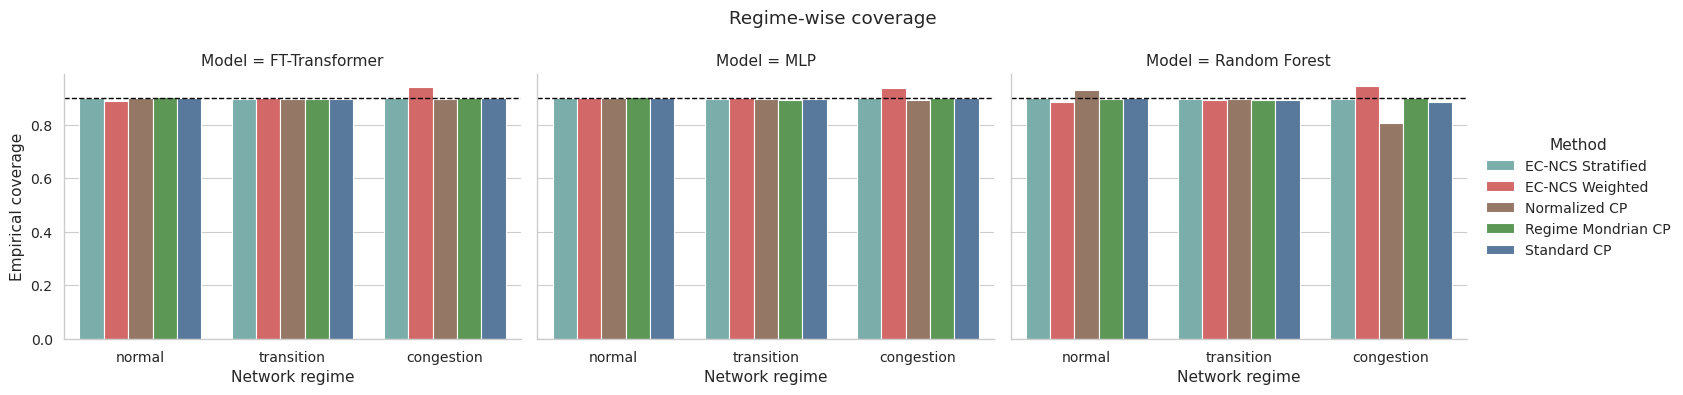

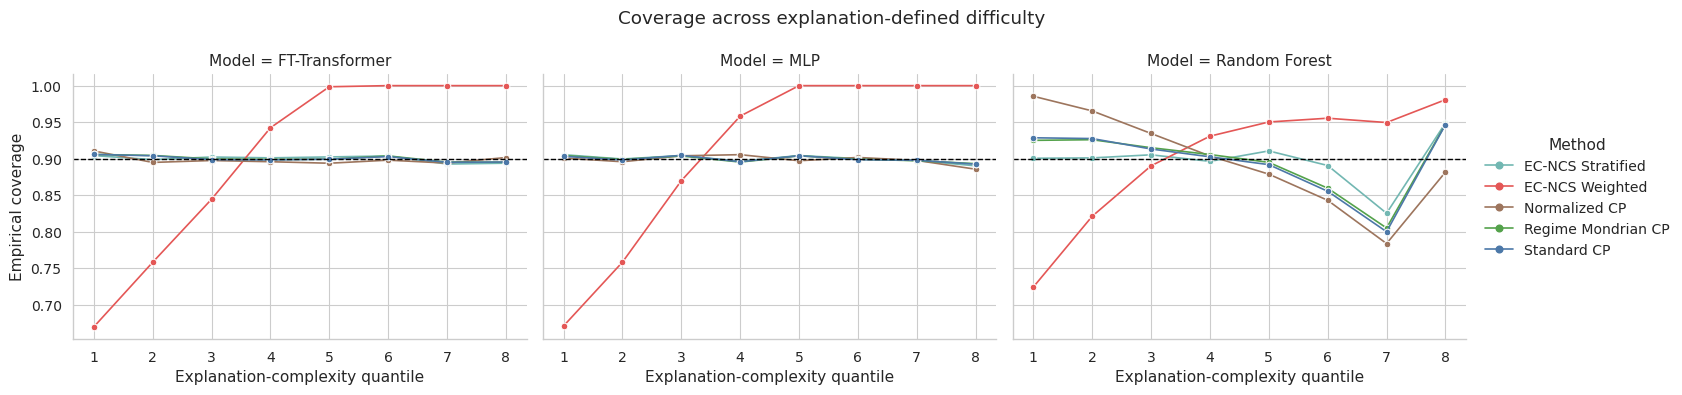

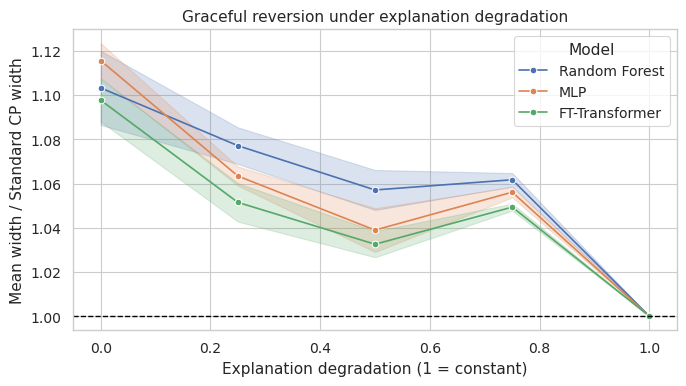

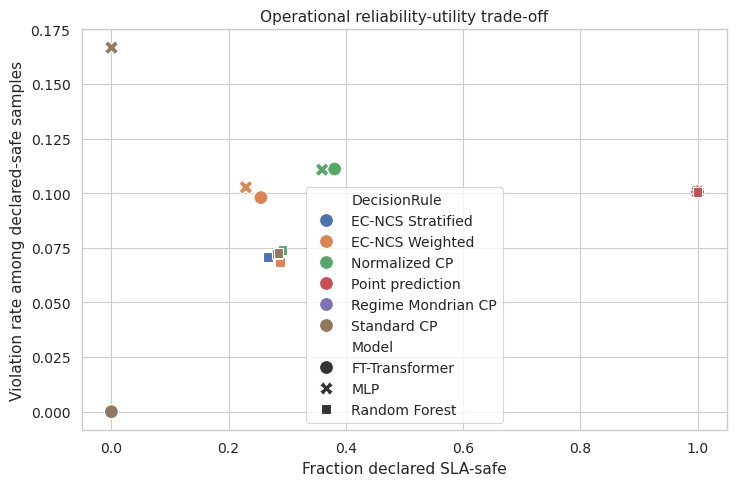

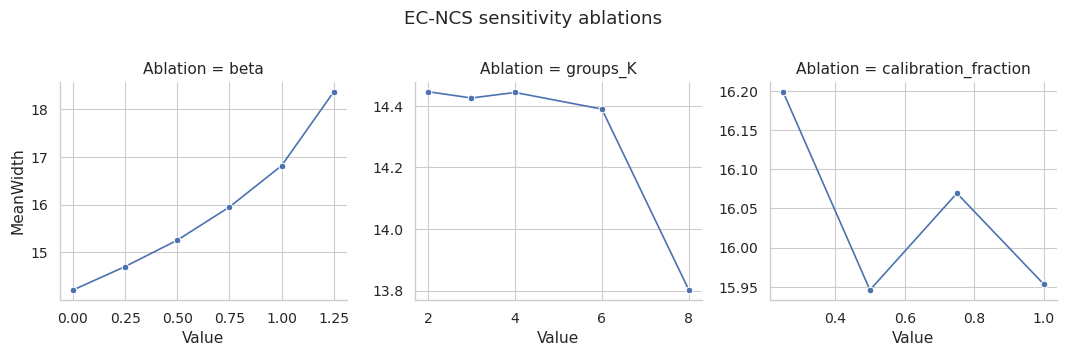

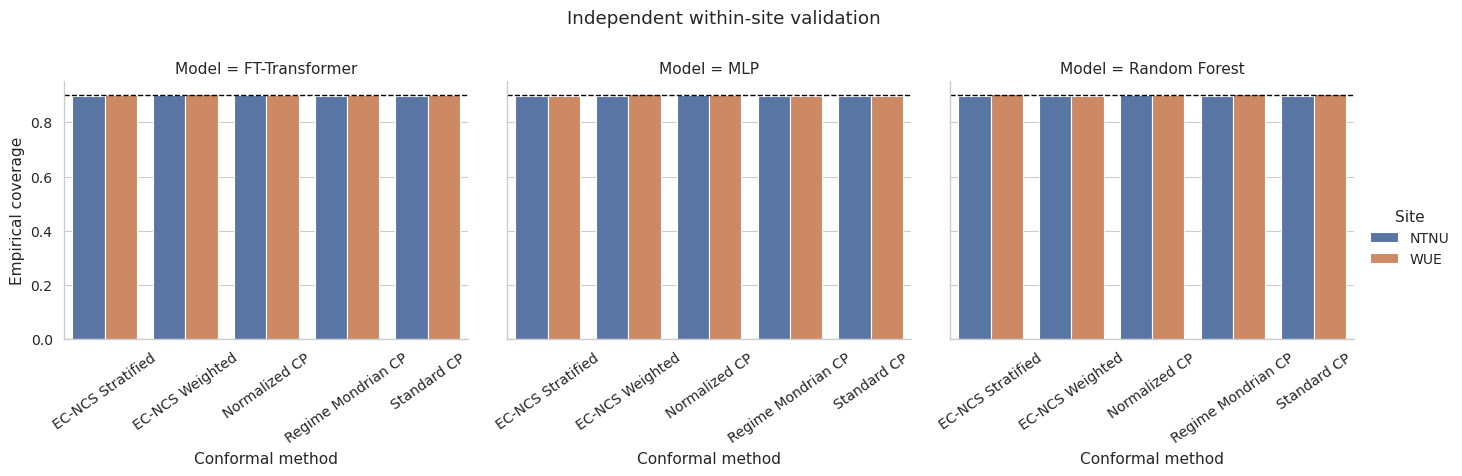

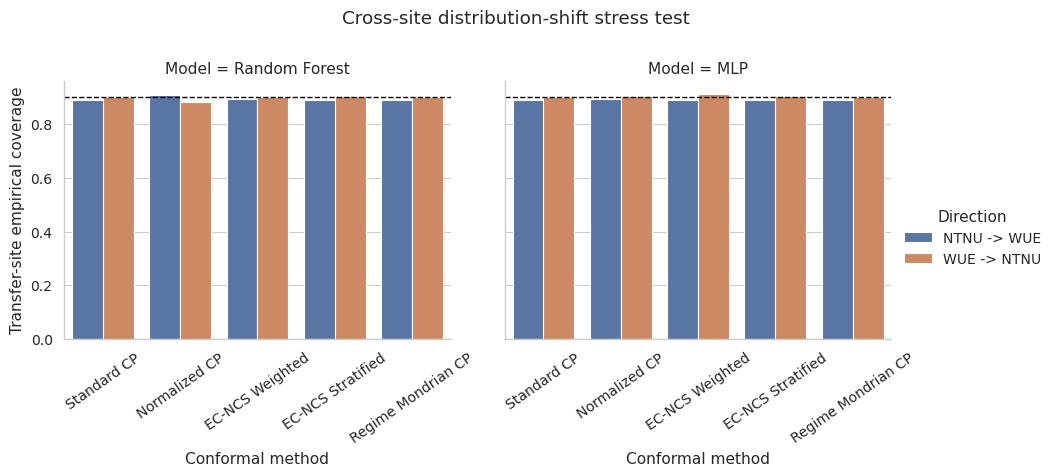

Results archive: /content/ec_ncs_corrected_results.zip


,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,Winkler,CorrPhiWidth
0,FT-Transformer,EC-NCS Stratified,0.899855,0.002324,15.345071,0.028314,16.196961,-0.183965
1,FT-Transformer,EC-NCS Weighted,0.901536,0.000592,16.841209,0.123105,18.950168,1.000000
2,FT-Transformer,Normalized CP,0.898240,0.003390,15.155100,0.059466,16.873715,0.005042
3,FT-Transformer,Regime Mondrian CP,0.900268,0.002206,15.347650,0.029110,16.193394,0.073279
4,FT-Transformer,Standard CP,0.899909,0.001927,15.342259,0.029814,16.193001,0.008685
5,MLP,EC-NCS Stratified,0.899708,0.000589,15.337692,0.015157,16.207830,-0.271558
6,MLP,EC-NCS Weighted,0.907098,0.006712,17.115932,0.142006,19.069323,1.000000
7,MLP,Normalized CP,0.898489,0.003682,15.146776,0.098875,16.843340,0.002247
8,MLP,Regime Mondrian CP,0.899467,0.002145,15.339194,0.028028,16.207467,0.000554
9,MLP,Standard CP,0.899323,0.000825,15.342155,0.023113,16.207159,-0.003736


,Model,Method,Regime,Coverage,MeanWidth,Undercoverage,N
0,FT-Transformer,EC-NCS Stratified,congestion,0.900197,15.342418,0.000453,2368.666667
1,FT-Transformer,EC-NCS Stratified,normal,0.901853,15.347902,0.001031,6019.666667
2,FT-Transformer,EC-NCS Stratified,transition,0.896267,15.341510,0.003733,3649.666667
3,FT-Transformer,EC-NCS Weighted,congestion,0.940419,18.305077,0.000000,2368.666667
4,FT-Transformer,EC-NCS Weighted,normal,0.887894,16.386774,0.012106,6019.666667
5,FT-Transformer,EC-NCS Weighted,transition,0.898919,16.647543,0.005059,3649.666667
6,FT-Transformer,Normalized CP,congestion,0.895133,15.033467,0.006924,2368.666667
7,FT-Transformer,Normalized CP,normal,0.900260,15.237157,0.002223,6019.666667
8,FT-Transformer,Normalized CP,transition,0.897189,15.109375,0.002811,3649.666667
9,FT-Transformer,Regime Mondrian CP,congestion,0.900621,15.361399,0.000189,2368.666667


,Model,Seed,TrainSeconds,PredictionSeconds,PredictionMsPerSample,ExplanationCalibrationSeconds,ExplanationTrainingReferenceSeconds,ExplanationTrainingReferenceN,ExplanationTestSeconds,ExplanationMsPerTestSample,ConformalizationSeconds,EndToEndTestMsPerSample,TrainMemoryDeltaMB,PredictionMemoryDeltaMB,ExplanationMemoryDeltaMB
0,FT-Transformer,22.0,8.032644,0.049677,0.004126,1.519749,0.597297,5000.0,1.625193,0.134922,5.361784,0.584828,6.356771,0.000000,0.826823
1,MLP,22.0,3.521412,0.014544,0.001207,1.148105,0.683258,5000.0,1.081444,0.089832,4.367352,0.454094,103.360677,0.000000,41.975260
2,Random Forest,22.0,16.670583,0.489898,0.040645,2.120708,1.059865,5000.0,1.905890,0.158292,5.179902,0.629602,159.046875,0.061198,137.834635


,Site,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,MAE,R2
0,NTNU,FT-Transformer,EC-NCS Stratified,0.897596,0.006127,15.275141,0.010492,4.225306,-0.000926
1,NTNU,FT-Transformer,EC-NCS Weighted,0.902135,0.006250,16.832422,0.106386,4.225306,-0.000926
2,NTNU,FT-Transformer,Normalized CP,0.900380,0.005115,15.082194,0.223174,4.225306,-0.000926
3,NTNU,FT-Transformer,Regime Mondrian CP,0.897977,0.005260,15.286455,0.014244,4.225306,-0.000926
4,NTNU,FT-Transformer,Standard CP,0.898034,0.006333,15.280813,0.013139,4.225306,-0.000926
5,NTNU,MLP,EC-NCS Stratified,0.899567,0.007716,15.286246,0.011149,4.226867,-0.002674
6,NTNU,MLP,EC-NCS Weighted,0.896871,0.003815,16.561162,0.307329,4.226867,-0.002674
7,NTNU,MLP,Normalized CP,0.902186,0.005219,15.055758,0.132287,4.226867,-0.002674
8,NTNU,MLP,Regime Mondrian CP,0.899459,0.009052,15.288422,0.007625,4.226867,-0.002674
9,NTNU,MLP,Standard CP,0.899186,0.009955,15.279238,0.015811,4.226867,-0.002674


,SourceSite,TargetSite,Model,Method,N,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,Normalized CP,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.909467,0.000000,15.278136,0.065453,16.724467,15.650179,22.263127,17.535244,-0.620831
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.895767,0.004233,15.701371,0.063689,16.366063,15.356907,21.089579,17.546186,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499109
4,NTNU,WUE,Random Forest,Regime Mondrian CP,30000,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.146852
5,NTNU,WUE,MLP,Standard CP,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,Normalized CP,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.893067,0.006933,15.075263,0.066334,16.120482,14.184052,20.243390,16.962190,0.010942
7,NTNU,WUE,MLP,EC-NCS Weighted,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.891700,0.008300,16.683368,0.059940,18.068087,16.713421,21.734980,19.140303,1.000000
8,NTNU,WUE,MLP,EC-NCS Stratified,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
9,NTNU,WUE,MLP,Regime Mondrian CP,30000,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796


In [ ]:

# Colab-ready dependency bootstrap. Safe to rerun.
import importlib.util
import subprocess
import sys

_required = {
    "shap": "shap>=0.46",
    "captum": "captum>=0.7",
    "openpyxl": "openpyxl>=3.1",
    "pyarrow": "pyarrow>=15",
    "psutil": "psutil>=5.9",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# %%
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import requests
import seaborn as sns
import shap
import torch
import torch.nn as nn
from captum.attr import GradientShap
from scipy.stats import spearmanr, wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


@dataclass
class Config:
    record_id: str = "13754300"
    sites: Tuple[str, ...] = ("wue", "ntnu")
    target_col: str = "trel"
    max_rows_per_site: int = 30_000
    csv_chunk_size: int = 200_000
    nominal_coverage: float = 0.90
    train_fraction: float = 0.60
    calibration_fraction: float = 0.20
    test_fraction: float = 0.20
    random_seeds: Tuple[int, ...] = (11, 22, 33)
    rf_trees: int = 200
    rf_min_leaf: int = 2
    mlp_epochs: int = 50
    mlp_batch_size: int = 512
    mlp_patience: int = 7
    explanation_batch_size: int = 256
    gradient_shap_samples: int = 4
    max_explanation_train_rows: int = 5_000
    tree_shap_approximate: bool = True
    ec_beta: float = 0.75
    ec_weight_min: float = 0.35
    ec_weight_max: float = 3.00
    explanation_groups: int = 4
    minimum_group_calibration: int = 50
    regime_minimum_calibration: int = 50
    outdir: str = "/content/ec_ncs_corrected_results"
    data_dir: str = "/content/ec_ncs_data"
    force_download: bool = False
    smoke_test: bool = False          # True uses synthetic data and runs quickly
    run_cross_site_transfer: bool = True
    cross_site_models: Tuple[str, ...] = ("Random Forest", "MLP")
    cross_site_seed: int = 2027
    run_within_site_validation: bool = True
    within_site_models: Tuple[str, ...] = ("Random Forest", "MLP", "FT-Transformer")
    within_site_seeds: Tuple[int, ...] = (11, 22, 33)
    explicit_scenario_regime_map: Optional[Dict[str, str]] = None
    require_explicit_regime_map: bool = False
    sla_threshold: Optional[float] = None  # replace with a domain-supported delay threshold

CFG = Config()
ALPHA = 1.0 - CFG.nominal_coverage
OUTDIR = Path(CFG.outdir)
DATA_DIR = Path(CFG.data_dir)
OUTDIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(CFG)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conformal_quantile(scores: Sequence[float], alpha: float) -> float:
    """Finite-sample split-conformal quantile using the higher order statistic."""
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    if scores.size == 0:
        raise ValueError("No finite calibration scores.")
    level = min(1.0, np.ceil((scores.size + 1) * (1.0 - alpha)) / scores.size)
    return float(np.quantile(scores, level, method="higher"))


class TrainECDF:
    """Pointwise rank transform fitted only on training explanations."""
    def fit(self, values: Sequence[float]):
        self.sorted_ = np.sort(np.asarray(values, dtype=float))
        return self

    def transform(self, values: Sequence[float]) -> np.ndarray:
        values = np.asarray(values, dtype=float)
        return np.searchsorted(self.sorted_, values, side="right") / max(len(self.sorted_), 1)


def bootstrap_ci(values: Sequence[float], fn=np.mean, seed: int = 0,
                 n_boot: int = 500, level: float = 0.95) -> Tuple[float, float]:
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    draws = [fn(values[rng.integers(0, len(values), len(values))]) for _ in range(n_boot)]
    tail = (1.0 - level) / 2.0
    return tuple(np.quantile(draws, [tail, 1.0 - tail]))


def interval_metrics(y: np.ndarray, lo: np.ndarray, hi: np.ndarray,
                     alpha: float, phi: Optional[np.ndarray] = None) -> Dict[str, float]:
    y, lo, hi = map(lambda z: np.asarray(z, dtype=float), (y, lo, hi))
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    below = np.maximum(lo - y, 0.0)
    above = np.maximum(y - hi, 0.0)
    winkler = width + (2.0 / alpha) * (below + above)
    corr = 0.0
    if phi is not None and np.std(width) > 1e-12:
        corr = float(spearmanr(phi, width).correlation)
        if not np.isfinite(corr):
            corr = 0.0
    mean_width = float(width.mean())
    coverage = float(covered.mean())
    return {
        "Coverage": coverage,
        "Undercoverage": float(max(0.0, (1.0 - alpha) - coverage)),
        "MeanWidth": mean_width,
        "IntervalEfficiency": float(1.0 / max(mean_width, 1e-12)),
        "CoverageWidthCriterion": float(mean_width * (1.0 + 10.0 * abs(coverage - (1.0-alpha)))),
        "MedianWidth": float(np.median(width)),
        "P90Width": float(np.quantile(width, 0.90)),
        "Winkler": float(winkler.mean()),
        "CorrPhiWidth": corr,
    }


def timed_call(fn, *args, synchronize_gpu: bool = True, **kwargs):
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    mem_after = process.memory_info().rss
    return out, elapsed, max(0, mem_after - mem_before) / 2**20


def zenodo_metadata(record_id: str) -> Mapping:
    response = requests.get(f"https://zenodo.org/api/records/{record_id}", timeout=90)
    response.raise_for_status()
    return response.json()


def choose_owd_file(metadata: Mapping, site: str) -> Mapping:
    site = site.lower()
    files = metadata.get("files", [])
    ranked = []
    for item in files:
        name = item.get("key", "").lower()
        score = 0
        score += 8 if site in name else 0
        score += 8 if "owd" in name else 0
        score += 4 if "with_iats" in name else 0
        score -= 5 if "tput" in name else 0
        score += 2 if name.endswith(".csv") else 0
        ranked.append((score, item))
    ranked.sort(key=lambda z: z[0], reverse=True)
    if not ranked or ranked[0][0] < 12:
        available = [f.get("key") for f in files]
        raise FileNotFoundError(f"No suitable {site} OWD CSV. Available: {available}")
    return ranked[0][1]


def stream_download(item: Mapping, destination: Path, force: bool = False) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and not force:
        return destination
    url = item["links"]["self"]
    with requests.get(url, stream=True, timeout=300) as response:
        response.raise_for_status()
        with destination.open("wb") as handle:
            for chunk in response.iter_content(chunk_size=2**20):
                if chunk:
                    handle.write(chunk)
    return destination


def synthetic_5g(n: int = 12_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    load = rng.uniform(0, 1, n)
    scenario = pd.cut(load, [-1, .35, .70, 2], labels=["normal", "transition", "congestion"])
    packet_size = rng.choice([128, 256, 512, 1024, 1500], n)
    iat = rng.lognormal(-2.0 + 1.2 * load, .35, n)
    ratio = rng.uniform(.1, 1.0, n)
    noise = rng.normal(0, .12 + .55 * load**2, n)
    trel = 0.15 + 1.1 * load + .00025 * packet_size + .15 * ratio + noise
    return pd.DataFrame({"PacketSize": packet_size, "iat": iat, "ratio": ratio,
                         "scenario": scenario.astype(str), "rep": rng.integers(0, 30, n),
                         "trel": trel})


def uniform_chunk_sample_csv(path: Path, sample_size: int, seed: int,
                             chunksize: int = 200_000) -> Tuple[pd.DataFrame, Dict[str, int]]:
    """Exact uniform random-key reservoir sample over every data row in a CSV.

    Independent continuous priorities give every row equal inclusion probability and avoid
    the ordered-prefix bias caused by pd.read_csv(..., nrows=sample_size).
    """
    rng = np.random.default_rng(seed)
    reservoir = None
    seen = 0
    for chunk_id, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False)):
        chunk.columns = chunk.columns.astype(str).str.strip()
        seen += len(chunk)
        chunk["__uniform_priority__"] = rng.random(len(chunk))
        candidates = chunk if reservoir is None else pd.concat([reservoir, chunk], ignore_index=True)
        reservoir = candidates.nsmallest(min(sample_size, len(candidates)), "__uniform_priority__")
        if (chunk_id + 1) % 10 == 0:
            print(f"  scanned {seen:,} rows from {path.name}")
    sampled = reservoir.drop(columns="__uniform_priority__").reset_index(drop=True)
    return sampled, {"RowsScanned": seen, "RowsSampled": len(sampled),
                     "SamplingSeed": seed, "ChunkSize": chunksize}


sampling_rows, selected_files = [], {}
site_frames = []
if CFG.smoke_test:
    for i, site in enumerate(CFG.sites):
        frame = synthetic_5g(seed=42+i)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": "synthetic smoke test",
                              "RowsScanned": len(frame), "RowsSampled": len(frame),
                              "SamplingSeed": 42+i, "ChunkSize": np.nan})
        selected_files[site] = "synthetic smoke test"
else:
    metadata = zenodo_metadata(CFG.record_id)
    for i, site in enumerate(CFG.sites):
        selected = choose_owd_file(metadata, site)
        selected_path = DATA_DIR / Path(selected["key"]).name
        selected_path = stream_download(selected, selected_path, CFG.force_download)
        print(f"Uniformly sampling the complete {site.upper()} file: {selected_path.name}")
        frame, audit = uniform_chunk_sample_csv(selected_path, CFG.max_rows_per_site,
                                                seed=2027+i, chunksize=CFG.csv_chunk_size)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": selected_path.name, **audit})
        selected_files[site] = str(selected_path)

raw_df = pd.concat(site_frames, ignore_index=True)
sampling_audit_df = pd.DataFrame(sampling_rows)
sampling_audit_df["SamplingFraction"] = sampling_audit_df.RowsSampled / sampling_audit_df.RowsScanned
sampling_audit_df.to_csv(OUTDIR / "sampling_audit.csv", index=False)
raw_df.columns = raw_df.columns.astype(str).str.strip()
print("Selected files:", selected_files)
print("Shape:", raw_df.shape)
display(sampling_audit_df)
display(raw_df.groupby("DatasetSite", observed=True).size().rename("SampledRows"))
display(raw_df.head())
print(raw_df.dtypes)


DROP_COLUMNS = {
    "Unnamed: 0", "src", "Timestamp", "SourceIPOuter", "DestinationIPOuter",
    "SourceIPInner", "DestinationIPInner", "SeqNum", "DatasetSite",
    # Retained in clean_df for splitting/auditing, but never supplied to a model.
    "scenario", "rep"
}


def audit_and_clean(df: pd.DataFrame, target_col: str):
    if target_col not in df.columns:
        raise ValueError(f"Target {target_col!r} missing. Available columns: {df.columns.tolist()}")
    work = df.copy()
    work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan).dropna(subset=[target_col]).drop_duplicates()
    candidate = [c for c in work.columns if c != target_col and c not in DROP_COLUMNS]
    audit_rows = []
    selected = []
    for col in work.columns:
        missing = float(work[col].isna().mean())
        nunique = int(work[col].nunique(dropna=True))
        reason = "included"
        include = col in candidate and missing <= .50 and nunique > 1
        if col == target_col: reason = "target"
        elif col in DROP_COLUMNS: reason = "identifier/sequence leakage risk"
        elif missing > .50: reason = ">50% missing"
        elif nunique <= 1: reason = "constant"
        elif include: selected.append(col)
        audit_rows.append({"Feature": col, "Dtype": str(work[col].dtype),
                           "MissingFraction": missing, "UniqueValues": nunique,
                           "Included": include, "Reason": reason})
    return work, selected, pd.DataFrame(audit_rows)


clean_df, feature_columns, feature_audit = audit_and_clean(raw_df, CFG.target_col)
feature_audit.to_csv(OUTDIR / "feature_audit.csv", index=False)
display(feature_audit)
print("Included features:", feature_columns)


def scenario_to_regime(values: pd.Series) -> Optional[pd.Series]:
    text = values.astype(str).str.lower()
    out = pd.Series(index=values.index, dtype="object")
    patterns = {
        "normal": r"normal|stable|baseline|idle|low",
        "transition": r"transition|medium|moderate|ramp|bursty",
        "congestion": r"congest|overload|heavy|high|stress"
    }
    for label, pattern in patterns.items():
        out[text.str.contains(pattern, regex=True, na=False)] = label
    return out if out.notna().mean() >= .70 else None


if "scenario" in clean_df.columns:
    scenario_inventory = (clean_df.groupby(["DatasetSite", "scenario"], observed=True)
                          .size().rename("N").reset_index())
    inferred = scenario_to_regime(scenario_inventory["scenario"])
    scenario_inventory["SuggestedRegime"] = (inferred if inferred is not None else "REVIEW_REQUIRED")
    scenario_inventory.to_csv(OUTDIR / "scenario_regime_inventory.csv", index=False)
    display(scenario_inventory)
    print("For the paper, populate CFG.explicit_scenario_regime_map and set "
          "CFG.require_explicit_regime_map=True after domain review.")


REGIME_FEATURE_HINTS = ["ratio", "pdist", "pnpak", "piat", "iat", "packetsize", "bw", "slots"]


class RegimeAssigner:
    def fit(self, X: pd.DataFrame):
        if "scenario" in X.columns:
            if CFG.explicit_scenario_regime_map is not None:
                allowed = {"normal", "transition", "congestion"}
                if not set(CFG.explicit_scenario_regime_map.values()).issubset(allowed):
                    raise ValueError(f"Regime-map values must be in {allowed}")
                observed = set(X["scenario"].astype(str).unique())
                missing = observed - set(CFG.explicit_scenario_regime_map)
                if missing:
                    raise ValueError(f"Explicit regime map misses scenario labels: {sorted(missing)}")
                self.mode_ = "explicit scenario mapping"
                self.scenario_map_ = dict(CFG.explicit_scenario_regime_map)
                return self
            if CFG.require_explicit_regime_map:
                raise ValueError("Populate CFG.explicit_scenario_regime_map after inspecting scenario labels.")
            direct = scenario_to_regime(X["scenario"])
            if direct is not None:
                self.mode_ = "scenario labels"
                self.scenario_map_ = dict(zip(X["scenario"].astype(str), direct))
                return self
        numeric = X.select_dtypes(include=np.number)
        cols = [c for c in numeric.columns if any(h in c.lower() for h in REGIME_FEATURE_HINTS)]
        if not cols:
            cols = numeric.columns.tolist()
        self.mode_ = "train-fitted traffic index"
        self.cols_ = cols
        self.center_ = numeric[cols].median()
        self.scale_ = (numeric[cols].quantile(.75) - numeric[cols].quantile(.25)).replace(0, 1.0)
        score = ((numeric[cols] - self.center_) / self.scale_).abs().mean(axis=1)
        self.thresholds_ = tuple(score.quantile([.50, .80]))
        return self

    def transform(self, X: pd.DataFrame) -> pd.Series:
        if self.mode_ == "scenario labels":
            mapped = X["scenario"].astype(str).map(self.scenario_map_)
            return mapped.fillna("transition")
        numeric = X[self.cols_].apply(pd.to_numeric, errors="coerce").fillna(self.center_)
        score = ((numeric - self.center_) / self.scale_).abs().mean(axis=1)
        return pd.cut(score, [-np.inf, self.thresholds_[0], self.thresholds_[1], np.inf],
                      labels=["normal", "transition", "congestion"]).astype(str)


def make_groups(df: pd.DataFrame) -> Optional[pd.Series]:
    group_cols = [c for c in ["DatasetSite", "scenario", "rep", "gnb", "sdr"] if c in df.columns]
    if not group_cols:
        return None
    groups = df[group_cols].astype(str).agg("|".join, axis=1)
    return groups if groups.nunique() >= 10 else None


def three_way_split(df: pd.DataFrame, seed: int):
    groups = make_groups(df)
    indices = np.arange(len(df))
    if groups is not None:
        first = GroupShuffleSplit(n_splits=1, train_size=CFG.train_fraction, random_state=seed)
        train_idx, rest_idx = next(first.split(indices, groups=groups))
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        second = GroupShuffleSplit(n_splits=1, test_size=relative_test, random_state=seed + 1)
        cal_rel, test_rel = next(second.split(rest_idx, groups=groups.iloc[rest_idx]))
        cal_idx, test_idx = rest_idx[cal_rel], rest_idx[test_rel]
        strategy = "group-disjoint"
    else:
        train_idx, rest_idx = train_test_split(indices, train_size=CFG.train_fraction, random_state=seed)
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        cal_idx, test_idx = train_test_split(rest_idx, test_size=relative_test, random_state=seed + 1)
        strategy = "random fallback"
    return train_idx, np.asarray(cal_idx), np.asarray(test_idx), strategy


def split_overlap_report(df, train_idx, cal_idx, test_idx):
    groups = make_groups(df)
    if groups is None:
        return {"TrainCalGroupOverlap": np.nan, "TrainTestGroupOverlap": np.nan,
                "CalTestGroupOverlap": np.nan}
    sets = [set(groups.iloc[idx]) for idx in [train_idx, cal_idx, test_idx]]
    return {"TrainCalGroupOverlap": len(sets[0] & sets[1]),
            "TrainTestGroupOverlap": len(sets[0] & sets[2]),
            "CalTestGroupOverlap": len(sets[1] & sets[2])}


def build_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    numeric = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                                   min_frequency=2))]), categorical),
    ], remainder="drop", verbose_feature_names_out=True)


class ResidualMLP(nn.Module):
    def __init__(self, n_features: int):
        super().__init__()
        width = min(256, max(64, 4 * n_features))
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.BatchNorm1d(width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width // 2), nn.GELU(),
            nn.Linear(width // 2, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


class FTTransformerRegressor(nn.Module):
    """FT-Transformer-style regressor with one learned token per transformed feature."""
    def __init__(self, n_features: int, d_token: int = 32, n_heads: int = 4,
                 n_layers: int = 3):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_token) * .02)
        self.bias = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads,
                                           dim_feedforward=4*d_token, dropout=.10,
                                           activation="gelu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(encoded[:, 0]).squeeze(-1)


class TorchRegressor:
    def __init__(self, seed: int, architecture: str = "mlp"):
        self.seed = seed
        self.architecture = architecture
    def fit(self, X, y):
        set_seed(self.seed)
        X = np.asarray(X, np.float32); y = np.asarray(y, np.float32)
        split = int(.85 * len(X))
        rng = np.random.default_rng(self.seed)
        order = rng.permutation(len(X)); fit_idx, val_idx = order[:split], order[split:]
        self.y_mean_, self.y_std_ = float(y[fit_idx].mean()), float(y[fit_idx].std() + 1e-8)
        yz = (y - self.y_mean_) / self.y_std_
        self.model = (ResidualMLP(X.shape[1]) if self.architecture == "mlp"
                      else FTTransformerRegressor(X.shape[1])).to(DEVICE)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=.5)
        loss_fn = nn.SmoothL1Loss()
        best, best_state, bad = np.inf, None, 0
        for epoch in range(CFG.mlp_epochs):
            self.model.train()
            for start in range(0, len(fit_idx), CFG.mlp_batch_size):
                batch = fit_idx[start:start + CFG.mlp_batch_size]
                xb = torch.tensor(X[batch], device=DEVICE)
                yb = torch.tensor(yz[batch], device=DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = loss_fn(self.model(xb), yb)
                loss.backward(); optimizer.step()
            self.model.eval()
            with torch.no_grad():
                xv = torch.tensor(X[val_idx], device=DEVICE)
                yv = torch.tensor(yz[val_idx], device=DEVICE)
                val = float(loss_fn(self.model(xv), yv).item())
            scheduler.step(val)
            if val < best - 1e-5:
                best, bad = val, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= CFG.mlp_patience: break
        self.model.load_state_dict(best_state)
        return self
    def predict(self, X):
        self.model.eval(); X = np.asarray(X, np.float32); pieces = []
        with torch.no_grad():
            for start in range(0, len(X), CFG.mlp_batch_size):
                xb = torch.tensor(X[start:start + CFG.mlp_batch_size], device=DEVICE)
                pieces.append(self.model(xb).cpu().numpy())
        return np.concatenate(pieces) * self.y_std_ + self.y_mean_


def build_model(name: str, seed: int):
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=CFG.rf_trees, min_samples_leaf=CFG.rf_min_leaf,
                                     random_state=seed, n_jobs=-1)
    if name == "MLP":
        return TorchRegressor(seed, "mlp")
    if name == "FT-Transformer":
        return TorchRegressor(seed, "transformer")
    raise KeyError(name)


def tree_shap_strength(model, X: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    values = np.asarray(explainer.shap_values(
        X,
        approximate=CFG.tree_shap_approximate,
        check_additivity=False,
    ))
    return np.abs(values).sum(axis=1), values


def gradient_shap_strength(model: TorchRegressor, X: np.ndarray,
                           background: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    model.model.eval()
    gs = GradientShap(model.model)
    baseline = torch.tensor(background.astype(np.float32), device=DEVICE)
    strengths, attrs = [], []
    for start in range(0, len(X), CFG.explanation_batch_size):
        xb = torch.tensor(X[start:start + CFG.explanation_batch_size].astype(np.float32),
                          device=DEVICE, requires_grad=True)
        attribution = gs.attribute(xb, baselines=baseline,
                                   n_samples=CFG.gradient_shap_samples, stdevs=0.01)
        arr = attribution.detach().cpu().numpy() * model.y_std_
        attrs.append(arr); strengths.append(np.abs(arr).sum(axis=1))
    return np.concatenate(strengths), np.vstack(attrs)


def explain(model_name, model, X, background):
    if model_name == "Random Forest":
        return tree_shap_strength(model, X)
    return gradient_shap_strength(model, X, background)


def explanation_reference(X_train: np.ndarray, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    """Uniform bounded training reference for the explanation ECDF.

    Calibration and test explanations are still computed for every observation.
    Bounding only the training reference removes the dominant unnecessary SHAP cost.
    """
    rng = np.random.default_rng(seed + 1000)
    n = min(CFG.max_explanation_train_rows, len(X_train))
    idx = rng.choice(len(X_train), size=n, replace=False)
    return X_train[idx], idx


def save_main_checkpoints():
    """Persist completed work after every model so an interrupted Colab loses less."""
    pd.DataFrame(metric_rows).to_csv(OUTDIR / "metrics_checkpoint.csv", index=False)
    pd.DataFrame(bin_rows).to_csv(OUTDIR / "explanation_bins_checkpoint.csv", index=False)
    pd.DataFrame(site_metric_rows).to_csv(OUTDIR / "site_metrics_checkpoint.csv", index=False)
    pd.DataFrame(prediction_rows).to_csv(OUTDIR / "prediction_metrics_checkpoint.csv", index=False)
    pd.DataFrame(operational_rows).to_csv(OUTDIR / "operational_checkpoint.csv", index=False)
    pd.DataFrame(degradation_rows).to_csv(OUTDIR / "degradation_checkpoint.csv", index=False)
    pd.DataFrame(latency_rows).to_csv(OUTDIR / "latency_checkpoint.csv", index=False)
    pd.DataFrame(importance_rows).to_csv(OUTDIR / "importance_checkpoint.csv", index=False)
    pd.DataFrame(split_rows).drop_duplicates().to_csv(OUTDIR / "splits_checkpoint.csv", index=False)


def reproduce_legacy_rf(df: pd.DataFrame, feature_columns: Sequence[str], target_col: str):
    legacy = df[list(feature_columns) + [target_col]].copy()
    X = legacy[list(feature_columns)].copy()
    y = legacy[target_col].to_numpy(float)
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    for col in numeric:
        X[col] = pd.to_numeric(X[col], errors="coerce").fillna(X[col].median())
    if categorical:
        X[categorical] = X[categorical].astype(str).fillna("missing")
        X[categorical] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X[categorical])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.40, random_state=42)
    X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=42)
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                  random_state=42, n_jobs=-1).fit(X_train, y_train)
    pred_cal, pred_test = model.predict(X_cal), model.predict(X_test)
    explainer = shap.TreeExplainer(model)
    phi_cal = np.abs(np.asarray(explainer.shap_values(X_cal))).sum(axis=1)
    phi_test = np.abs(np.asarray(explainer.shap_values(X_test))).sum(axis=1)
    rank = lambda v: pd.Series(v).rank(method="average").to_numpy() / len(v)
    z_cal, z_test = rank(phi_cal), rank(phi_test)
    residuals = np.abs(y_cal - pred_cal)
    q_std = conformal_quantile(residuals, ALPHA)
    beta = .50
    w_cal = np.clip(1 + beta * (z_cal - z_cal.mean()), .25, 4.0)
    w_test = np.clip(1 + beta * (z_test - z_cal.mean()), .25, 4.0)
    q_ec = conformal_quantile(residuals / w_cal, ALPHA)
    intervals = {"Standard CP": (pred_test-q_std, pred_test+q_std),
                 "Legacy EC-NCS Weighted": (pred_test-q_ec*w_test, pred_test+q_ec*w_test)}
    rows = []
    for method, (lo, hi) in intervals.items():
        rows.append({"Protocol": "Submitted legacy reproduction", "Model": "Random Forest",
                     "Method": method, "MAE": mean_absolute_error(y_test, pred_test),
                     "R2": r2_score(y_test, pred_test),
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


legacy_source = clean_df[clean_df["DatasetSite"].astype(str).str.upper() == "WUE"].copy()
legacy_reproduction_df = reproduce_legacy_rf(legacy_source, feature_columns, CFG.target_col)
legacy_reproduction_df.to_csv(OUTDIR / "legacy_rf_reproduction.csv", index=False)
display(legacy_reproduction_df)


def fit_scale_model(X_train, y_train, pred_train, seed):
    target = np.abs(y_train - pred_train) + 1e-6
    model = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=10,
                                random_state=seed, n_jobs=-1)
    model.fit(X_train, target)
    return model


def mondrian_radii(res_cal, cal_groups, test_groups, alpha, minimum):
    global_q = conformal_quantile(res_cal, alpha)
    radii = np.full(len(test_groups), global_q, dtype=float)
    for group in pd.unique(cal_groups):
        cal_mask = np.asarray(cal_groups) == group
        if cal_mask.sum() >= minimum:
            q = conformal_quantile(np.asarray(res_cal)[cal_mask], alpha)
            radii[np.asarray(test_groups) == group] = q
    return radii


def build_intervals(y_cal, pred_cal, pred_test, X_train, y_train, pred_train,
                    X_cal, X_test, phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed):
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    intervals = {"Standard CP": (pred_test - q_standard, pred_test + q_standard)}

    scale_model = fit_scale_model(X_train, y_train, pred_train, seed)
    scale_cal = np.maximum(scale_model.predict(X_cal), 1e-6)
    scale_test = np.maximum(scale_model.predict(X_test), 1e-6)
    q_norm = conformal_quantile(residuals / scale_cal, ALPHA)
    intervals["Normalized CP"] = (pred_test - q_norm * scale_test,
                                   pred_test + q_norm * scale_test)

    ecdf = TrainECDF().fit(phi_train)
    z_cal, z_test = ecdf.transform(phi_cal), ecdf.transform(phi_test)
    w_cal = np.clip(1.0 + CFG.ec_beta * (z_cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    w_test = np.clip(1.0 + CFG.ec_beta * (z_test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    q_weighted = conformal_quantile(residuals / w_cal, ALPHA)
    intervals["EC-NCS Weighted"] = (pred_test - q_weighted * w_test,
                                     pred_test + q_weighted * w_test)

    edges = np.quantile(ecdf.transform(phi_train), np.linspace(0, 1, CFG.explanation_groups + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    exp_cal = np.digitize(z_cal, edges[1:-1], right=True)
    exp_test = np.digitize(z_test, edges[1:-1], right=True)
    exp_radii = mondrian_radii(residuals, exp_cal, exp_test, ALPHA, CFG.minimum_group_calibration)
    intervals["EC-NCS Stratified"] = (pred_test - exp_radii, pred_test + exp_radii)

    regime_radii = mondrian_radii(residuals, np.asarray(regime_cal), np.asarray(regime_test),
                                  ALPHA, CFG.regime_minimum_calibration)
    intervals["Regime Mondrian CP"] = (pred_test - regime_radii, pred_test + regime_radii)
    return intervals, z_cal, z_test, q_standard


def evaluate_all(intervals, y_test, phi_test, regimes, model_name, seed):
    rows = []
    for method, (lo, hi) in intervals.items():
        overall = interval_metrics(y_test, lo, hi, ALPHA, phi_test)
        rows.append({"Seed": seed, "Model": model_name, "Method": method,
                     "Regime": "overall", "N": len(y_test), **overall})
        for regime in ["normal", "transition", "congestion"]:
            mask = np.asarray(regimes) == regime
            if mask.sum() == 0: continue
            metrics = interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Regime": regime, "N": int(mask.sum()), **metrics})
    return rows


def explanation_bin_coverage(intervals, y_test, phi_test, model_name, seed, bins=8):
    labels = pd.qcut(phi_test, q=bins, labels=False, duplicates="drop")
    rows = []
    for method, (lo, hi) in intervals.items():
        for b in sorted(pd.unique(labels)):
            mask = np.asarray(labels == b)
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "ExplanationBin": int(b) + 1, "N": int(mask.sum()),
                         "Coverage": float(((y_test[mask] >= lo[mask]) &
                                            (y_test[mask] <= hi[mask])).mean()),
                         "MeanWidth": float(np.mean(hi[mask] - lo[mask]))})
    return rows


def evaluate_by_site(intervals, y_test, phi_test, site_test, model_name, seed):
    rows = []
    for site in sorted(pd.unique(site_test)):
        mask = np.asarray(site_test) == site
        for method, (lo, hi) in intervals.items():
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Site": site, "N": int(mask.sum()),
                         **interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])})
    return rows


def operational_results(intervals, y_test, pred_test, sla_threshold, model_name, seed):
    rows = []
    candidates = {"Point prediction": pred_test}
    candidates.update({method: hi for method, (_, hi) in intervals.items()})
    for method, upper_decision in candidates.items():
        accepted = upper_decision <= sla_threshold
        violations = y_test > sla_threshold
        false_safe = float((accepted & violations).sum() / max(accepted.sum(), 1))
        rows.append({"Seed": seed, "Model": model_name, "DecisionRule": method,
                     "SLAThreshold": sla_threshold, "SafeAcceptanceRate": float(accepted.mean()),
                     "FalseSafeRateAmongAccepted": false_safe,
                     "ViolationsCaught": float(((~accepted) & violations).sum() / max(violations.sum(), 1)),
                     "AcceptedN": int(accepted.sum())})
    return rows


def degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test, y_test,
                           model_name, seed):
    rng = np.random.default_rng(seed + 9000)
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    standard_width = 2 * q_standard
    rows = []
    for level in [0.0, .25, .50, .75, 1.0]:
        if level < 1.0:
            cal_noise = rng.uniform(0, 1, len(z_cal)); test_noise = rng.uniform(0, 1, len(z_test))
            cal = (1-level) * z_cal + level * cal_noise
            test = (1-level) * z_test + level * test_noise
            w_cal = np.clip(1 + CFG.ec_beta * (cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
            w_test = np.clip(1 + CFG.ec_beta * (test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
            q = conformal_quantile(residuals / w_cal, ALPHA)
            lo, hi = pred_test - q*w_test, pred_test + q*w_test
        else:
            lo, hi = pred_test - q_standard, pred_test + q_standard
        metrics = interval_metrics(y_test, lo, hi, ALPHA, test if level < 1 else np.zeros_like(z_test))
        rows.append({"Seed": seed, "Model": model_name, "Degradation": level,
                     "WidthRatioToStandard": metrics["MeanWidth"] / standard_width, **metrics})
    return rows


metric_rows, bin_rows, site_metric_rows, prediction_rows = [], [], [], []
operational_rows, degradation_rows, latency_rows, importance_rows, split_rows = [], [], [], [], []
ablation_cache = None

X_raw = clean_df[feature_columns].copy()
y_all = clean_df[CFG.target_col].to_numpy(float)

for seed in CFG.random_seeds:
    print(f"\n===== Seed {seed} =====")
    set_seed(seed)
    train_idx, cal_idx, test_idx, strategy = three_way_split(clean_df, seed)
    split_info = {"Seed": seed, "Strategy": strategy,
                  "TrainN": len(train_idx), "CalibrationN": len(cal_idx), "TestN": len(test_idx),
                  **split_overlap_report(clean_df, train_idx, cal_idx, test_idx)}
    split_rows.append(split_info)

    X_train_raw, X_cal_raw, X_test_raw = (X_raw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
    y_train, y_cal, y_test = (y_all[i] for i in [train_idx, cal_idx, test_idx])
    regime_assigner = RegimeAssigner().fit(X_train_raw)
    regime_cal = regime_assigner.transform(X_cal_raw).to_numpy()
    regime_test = regime_assigner.transform(X_test_raw).to_numpy()
    site_test = clean_df.iloc[test_idx]["DatasetSite"].astype(str).to_numpy()
    print("Split:", strategy, "Regime method:", regime_assigner.mode_)
    print(pd.Series(regime_test).value_counts())

    preprocessor = build_preprocessor(X_train_raw)
    X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    X_cal = preprocessor.transform(X_cal_raw).astype(np.float32)
    X_test = preprocessor.transform(X_test_raw).astype(np.float32)
    feature_names = preprocessor.get_feature_names_out()

    for model_name in ["Random Forest", "MLP", "FT-Transformer"]:
        print("\n---", model_name, "---")
        model = build_model(model_name, seed)
        model, train_time, train_mem = timed_call(model.fit, X_train, y_train)
        pred_train = model.predict(X_train)
        pred_cal = model.predict(X_cal)
        pred_test, prediction_time, prediction_mem = timed_call(model.predict, X_test)

        prediction_rows.append({"Seed": seed, "Model": model_name,
                                "MAE": mean_absolute_error(y_test, pred_test),
                                "RMSE": mean_squared_error(y_test, pred_test) ** .5,
                                "R2": r2_score(y_test, pred_test)})

        rng = np.random.default_rng(seed)
        bg_idx = rng.choice(len(X_train), min(64, len(X_train)), replace=False)
        X_explain_train, explain_train_idx = explanation_reference(X_train, seed)
        print(f"Explaining {len(X_explain_train):,} training-reference, "
              f"{len(X_cal):,} calibration and {len(X_test):,} test rows...")
        (phi_train, attrs_train), explanation_train_time, exp_train_mem = timed_call(
            explain, model_name, model, X_explain_train, X_train[bg_idx])
        (phi_cal, attrs_cal), explanation_cal_time, exp_cal_mem = timed_call(
            explain, model_name, model, X_cal, X_train[bg_idx])
        (phi_test, attrs_test), explanation_test_time, exp_test_mem = timed_call(
            explain, model_name, model, X_test, X_train[bg_idx])

        start_cp = time.perf_counter()
        intervals, z_cal, z_test, q_standard = build_intervals(
            y_cal, pred_cal, pred_test, X_train, y_train, pred_train, X_cal, X_test,
            phi_train, phi_cal, phi_test, regime_cal, regime_test, seed)
        cp_time = time.perf_counter() - start_cp

        if ablation_cache is None and model_name == "Random Forest":
            ablation_cache = dict(y_cal=y_cal.copy(), pred_cal=pred_cal.copy(),
                                  y_test=y_test.copy(), pred_test=pred_test.copy(),
                                  z_cal=z_cal.copy(), z_test=z_test.copy(), seed=seed)

        metric_rows += evaluate_all(intervals, y_test, z_test, regime_test, model_name, seed)
        bin_rows += explanation_bin_coverage(intervals, y_test, z_test, model_name, seed)
        site_metric_rows += evaluate_by_site(intervals, y_test, z_test, site_test, model_name, seed)
        sla_threshold = (float(CFG.sla_threshold) if CFG.sla_threshold is not None
                         else float(np.quantile(y_train, .90)))
        operational_rows += operational_results(intervals, y_test, pred_test, sla_threshold,
                                                model_name, seed)
        degradation_rows += degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test,
                                                   y_test, model_name, seed)

        latency_rows.append({
            "Seed": seed, "Model": model_name, "TrainSeconds": train_time,
            "PredictionSeconds": prediction_time,
            "PredictionMsPerSample": 1000 * prediction_time / len(X_test),
            "ExplanationCalibrationSeconds": explanation_cal_time,
            "ExplanationTrainingReferenceSeconds": explanation_train_time,
            "ExplanationTrainingReferenceN": len(X_explain_train),
            "ExplanationTestSeconds": explanation_test_time,
            "ExplanationMsPerTestSample": 1000 * explanation_test_time / len(X_test),
            "ConformalizationSeconds": cp_time,
            "EndToEndTestMsPerSample": 1000 * (prediction_time + explanation_test_time + cp_time) / len(X_test),
            "TrainMemoryDeltaMB": train_mem,
            "PredictionMemoryDeltaMB": prediction_mem,
            "ExplanationMemoryDeltaMB": max(exp_train_mem, exp_cal_mem, exp_test_mem)
        })

        mean_abs = np.abs(attrs_test).mean(axis=0)
        for feature, value in sorted(zip(feature_names, mean_abs), key=lambda z: z[1], reverse=True)[:20]:
            importance_rows.append({"Seed": seed, "Model": model_name,
                                    "Feature": feature, "MeanAbsAttribution": float(value)})
        save_main_checkpoints()
        print(f"Checkpoint saved after seed={seed}, model={model_name}")
        del model, attrs_train, attrs_cal, attrs_test
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
bins_df = pd.DataFrame(bin_rows)
site_metrics_df = pd.DataFrame(site_metric_rows)
predictions_df = pd.DataFrame(prediction_rows)
operational_df = pd.DataFrame(operational_rows)
degradation_df = pd.DataFrame(degradation_rows)
latency_df = pd.DataFrame(latency_rows)
importance_df = pd.DataFrame(importance_rows)
splits_df = pd.DataFrame(split_rows)

for name, frame in {
    "interval_metrics.csv": metrics_df, "site_metrics.csv": site_metrics_df,
    "explanation_bins.csv": bins_df,
    "prediction_metrics.csv": predictions_df, "operational_sla.csv": operational_df,
    "explanation_degradation.csv": degradation_df, "latency.csv": latency_df,
    "feature_attributions.csv": importance_df, "split_audit.csv": splits_df
}.items():
    frame.to_csv(OUTDIR / name, index=False)

display(predictions_df.groupby("Model").agg(["mean", "std"]))
display(metrics_df.query("Regime == 'overall'").groupby(["Model", "Method"])
        [["Coverage", "MeanWidth", "Winkler", "CorrPhiWidth"]].agg(["mean", "std"]))
display(latency_df.groupby("Model").agg(["mean", "std"]))


def run_full_ablations(cache):
    y_cal, pred_cal = cache["y_cal"], cache["pred_cal"]
    y_test, pred_test = cache["y_test"], cache["pred_test"]
    z_cal, z_test = cache["z_cal"], cache["z_test"]
    residuals = np.abs(y_cal - pred_cal)
    rng = np.random.default_rng(cache["seed"] + 12345)
    rows = []
    for beta in [0.0, .25, .50, .75, 1.0, 1.25]:
        wc = np.clip(1 + beta*(z_cal-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "beta", "Value": beta,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    for k in [2, 3, 4, 6, 8]:
        edges = np.quantile(z_cal, np.linspace(0, 1, k+1)); edges[0], edges[-1] = -np.inf, np.inf
        gc = np.digitize(z_cal, edges[1:-1], right=True)
        gt = np.digitize(z_test, edges[1:-1], right=True)
        radius = mondrian_radii(residuals, gc, gt, ALPHA, CFG.minimum_group_calibration)
        rows.append({"Ablation": "groups_K", "Value": k,
                     **interval_metrics(y_test, pred_test-radius, pred_test+radius, ALPHA, z_test)})
    for fraction in [.25, .50, .75, 1.0]:
        n = max(100, int(fraction*len(y_cal)))
        idx = rng.choice(len(y_cal), n, replace=False)
        wc = np.clip(1 + CFG.ec_beta*(z_cal[idx]-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + CFG.ec_beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals[idx]/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "calibration_fraction", "Value": fraction,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


ablations_df = run_full_ablations(ablation_cache)
ablations_df.to_csv(OUTDIR / "hyperparameter_ablations.csv", index=False)
display(ablations_df)


def run_within_site_validation(clean_df, feature_columns):
    rows = []
    if not CFG.run_within_site_validation:
        return pd.DataFrame(rows)
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(Xtr_raw)
            regime_cal, regime_te = regime.transform(Xcal_raw).to_numpy(), regime.transform(Xte_raw).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            for model_name in CFG.within_site_models:
                print(f"Within-site {site}, seed {seed}: {model_name}")
                model = build_model(model_name, seed).fit(Xtr, ytr)
                ptr, pcal, pte = (model.predict(z) for z in [Xtr, Xcal, Xte])
                rng = np.random.default_rng(seed)
                bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
                Xref, _ = explanation_reference(Xtr, seed)
                phitr, _ = explain(model_name, model, Xref, bg)
                phical, _ = explain(model_name, model, Xcal, bg)
                phite, _ = explain(model_name, model, Xte, bg)
                intervals, _, zte, _ = build_intervals(
                    ycal, pcal, pte, Xtr, ytr, ptr, Xcal, Xte,
                    phitr, phical, phite, regime_cal, regime_te, seed)
                for method, (lo, hi) in intervals.items():
                    rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                                 "Model": model_name, "Method": method, "N": len(yte),
                                 "MAE": mean_absolute_error(yte, pte),
                                 "RMSE": mean_squared_error(yte, pte)**.5,
                                 "R2": r2_score(yte, pte),
                                 **interval_metrics(yte, lo, hi, ALPHA, zte)})
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "within_site_validation_checkpoint.csv", index=False)
                print(f"Within-site checkpoint saved: {site}, seed={seed}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)


within_site_df = run_within_site_validation(clean_df, feature_columns)
within_site_df.to_csv(OUTDIR / "within_site_validation.csv", index=False)
display(within_site_df)


def source_train_cal_split(source_df: pd.DataFrame, seed: int):
    groups = make_groups(source_df)
    idx = np.arange(len(source_df))
    if groups is not None and groups.nunique() >= 8:
        splitter = GroupShuffleSplit(n_splits=1, train_size=.75, random_state=seed)
        return next(splitter.split(idx, groups=groups))
    return train_test_split(idx, train_size=.75, random_state=seed)


def run_cross_site_transfer(clean_df, feature_columns):
    rows = []
    if not CFG.run_cross_site_transfer:
        return pd.DataFrame(rows)
    sites = sorted(clean_df.DatasetSite.astype(str).unique())
    for source in sites:
        for target in sites:
            if source == target: continue
            source_df = clean_df[clean_df.DatasetSite.astype(str) == source].reset_index(drop=True)
            target_df = clean_df[clean_df.DatasetSite.astype(str) == target].reset_index(drop=True)
            train_idx, cal_idx = source_train_cal_split(source_df, CFG.cross_site_seed)
            Xs = source_df[feature_columns]
            Xt = target_df[feature_columns]
            y_source = source_df[CFG.target_col].to_numpy(float)
            y_target = target_df[CFG.target_col].to_numpy(float)
            X_train_raw, X_cal_raw = Xs.iloc[train_idx].copy(), Xs.iloc[cal_idx].copy()
            y_train, y_cal = y_source[train_idx], y_source[cal_idx]
            regime_assigner = RegimeAssigner().fit(X_train_raw)
            regime_cal = regime_assigner.transform(X_cal_raw).to_numpy()
            regime_target = regime_assigner.transform(Xt).to_numpy()
            prep = build_preprocessor(X_train_raw)
            X_train = prep.fit_transform(X_train_raw).astype(np.float32)
            X_cal = prep.transform(X_cal_raw).astype(np.float32)
            X_target = prep.transform(Xt).astype(np.float32)
            for model_name in CFG.cross_site_models:
                print(f"Transfer {source} -> {target}: {model_name}")
                model = build_model(model_name, CFG.cross_site_seed).fit(X_train, y_train)
                pred_train, pred_cal, pred_target = (model.predict(z) for z in [X_train, X_cal, X_target])
                rng = np.random.default_rng(CFG.cross_site_seed)
                bg = X_train[rng.choice(len(X_train), min(64, len(X_train)), replace=False)]
                Xref, _ = explanation_reference(X_train, CFG.cross_site_seed)
                phi_train, _ = explain(model_name, model, Xref, bg)
                phi_cal, _ = explain(model_name, model, X_cal, bg)
                phi_target, _ = explain(model_name, model, X_target, bg)
                intervals, _, z_target, _ = build_intervals(
                    y_cal, pred_cal, pred_target, X_train, y_train, pred_train,
                    X_cal, X_target, phi_train, phi_cal, phi_target,
                    regime_cal, regime_target, CFG.cross_site_seed)
                for method, (lo, hi) in intervals.items():
                    rows.append({"SourceSite": source, "TargetSite": target,
                                 "Model": model_name, "Method": method, "N": len(y_target),
                                 "MAE": mean_absolute_error(y_target, pred_target),
                                 "RMSE": mean_squared_error(y_target, pred_target)**.5,
                                 "R2": r2_score(y_target, pred_target),
                                 "GuaranteeStatus": "distribution-shift diagnostic only",
                                 **interval_metrics(y_target, lo, hi, ALPHA, z_target)})
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "cross_site_transfer_checkpoint.csv", index=False)
                print(f"Transfer checkpoint saved: {source}->{target}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)


cross_site_df = run_cross_site_transfer(clean_df, feature_columns)
cross_site_df.to_csv(OUTDIR / "cross_site_transfer.csv", index=False)
display(cross_site_df)


def paired_tests(metrics: pd.DataFrame) -> pd.DataFrame:
    rows = []
    overall = metrics.query("Regime == 'overall'")
    for model in overall.Model.unique():
        base = overall[(overall.Model == model) & (overall.Method == "Standard CP")].set_index("Seed")
        for method in ["Normalized CP", "EC-NCS Weighted", "EC-NCS Stratified", "Regime Mondrian CP"]:
            comp = overall[(overall.Model == model) & (overall.Method == method)].set_index("Seed")
            common = base.index.intersection(comp.index)
            for metric in ["MeanWidth", "Winkler"]:
                delta = comp.loc[common, metric] - base.loc[common, metric]
                try: p = float(wilcoxon(delta).pvalue)
                except ValueError: p = 1.0
                rows.append({"Model": model, "Method": method, "Metric": metric,
                             "MeanPairedDifference": float(delta.mean()), "WilcoxonP": p,
                             "Seeds": len(common)})
    return pd.DataFrame(rows)


tests_df = paired_tests(metrics_df)
tests_df.to_csv(OUTDIR / "paired_tests.csv", index=False)
display(tests_df)


PALETTE = {"Standard CP": "#4C78A8", "Normalized CP": "#9D755D",
           "EC-NCS Weighted": "#E45756", "EC-NCS Stratified": "#72B7B2",
           "Regime Mondrian CP": "#54A24B"}

summary = (metrics_df.groupby(["Model", "Method", "Regime"], as_index=False)
           .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std")))

g = sns.catplot(data=summary[summary.Regime != "overall"], x="Regime", y="Coverage",
                hue="Method", col="Model", kind="bar", palette=PALETTE,
                order=["normal", "transition", "congestion"], height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Network regime", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Regime-wise coverage")
g.savefig(OUTDIR / "fig_regime_coverage.pdf", bbox_inches="tight")
g.savefig(OUTDIR / "fig_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

g = sns.relplot(data=bins_df.groupby(["Model", "Method", "ExplanationBin"], as_index=False).mean(numeric_only=True),
                x="ExplanationBin", y="Coverage", hue="Method", col="Model", marker="o",
                kind="line", palette=PALETTE, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Explanation-complexity quantile", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Coverage across explanation-defined difficulty")
g.savefig(OUTDIR / "fig_explanation_bin_coverage.pdf", bbox_inches="tight")
g.savefig(OUTDIR / "fig_explanation_bin_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.lineplot(data=degradation_df, x="Degradation", y="WidthRatioToStandard",
             hue="Model", marker="o", errorbar="sd")
plt.axhline(1.0, color="black", ls="--", lw=1)
plt.xlabel("Explanation degradation (1 = constant)")
plt.ylabel("Mean width / Standard CP width")
plt.title("Graceful reversion under explanation degradation")
plt.tight_layout(); plt.savefig(OUTDIR / "fig_degradation.pdf", bbox_inches="tight"); plt.savefig(OUTDIR / "fig_degradation.png", dpi=300, bbox_inches="tight"); plt.show()

op_plot = operational_df.groupby(["Model", "DecisionRule"], as_index=False).mean(numeric_only=True)
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=op_plot, x="SafeAcceptanceRate", y="FalseSafeRateAmongAccepted",
                hue="DecisionRule", style="Model", s=100)
plt.xlabel("Fraction declared SLA-safe")
plt.ylabel("Violation rate among declared-safe samples")
plt.title("Operational reliability-utility trade-off")
plt.tight_layout(); plt.savefig(OUTDIR / "fig_operational_sla.pdf", bbox_inches="tight"); plt.savefig(OUTDIR / "fig_operational_sla.png", dpi=300, bbox_inches="tight"); plt.show()

g = sns.relplot(data=ablations_df, x="Value", y="MeanWidth", col="Ablation",
                kind="line", marker="o", facet_kws={"sharex": False, "sharey": False},
                height=3.6, aspect=1.0)
g.fig.subplots_adjust(top=.78); g.fig.suptitle("EC-NCS sensitivity ablations")
g.savefig(OUTDIR / "fig_ablations.pdf", bbox_inches="tight")
g.savefig(OUTDIR / "fig_ablations.png", dpi=300, bbox_inches="tight")
plt.show()

within_plot = (within_site_df.groupby(["Site", "Model", "Method"], as_index=False)
               .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean")))
g = sns.catplot(data=within_plot, x="Method", y="Coverage", hue="Site", col="Model",
                kind="bar", height=4, aspect=1.15)
for ax in g.axes.flat:
    ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=35)
g.set_axis_labels("Conformal method", "Empirical coverage")
g.fig.subplots_adjust(top=.80); g.fig.suptitle("Independent within-site validation")
g.savefig(OUTDIR / "fig_within_site_coverage.pdf", bbox_inches="tight")
g.savefig(OUTDIR / "fig_within_site_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    transfer_plot = cross_site_df.copy()
    transfer_plot["Direction"] = transfer_plot.SourceSite + " -> " + transfer_plot.TargetSite
    g = sns.catplot(data=transfer_plot, x="Method", y="Coverage", hue="Direction", col="Model",
                    kind="bar", height=4, aspect=1.15)
    for ax in g.axes.flat:
        ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        ax.tick_params(axis="x", rotation=35)
    g.set_axis_labels("Conformal method", "Transfer-site empirical coverage")
    g.fig.subplots_adjust(top=.80); g.fig.suptitle("Cross-site distribution-shift stress test")
    g.savefig(OUTDIR / "fig_cross_site_transfer.pdf", bbox_inches="tight")
    g.savefig(OUTDIR / "fig_cross_site_transfer.png", dpi=300, bbox_inches="tight")
    plt.show()


overall_table = (metrics_df.query("Regime == 'overall'")
                 .groupby(["Model", "Method"])
                 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                      MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                      Winkler=("Winkler", "mean"), CorrPhiWidth=("CorrPhiWidth", "mean"))
                 .reset_index())
regime_table = (metrics_df.query("Regime != 'overall'")
                .groupby(["Model", "Method", "Regime"])
                .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean"),
                     Undercoverage=("Undercoverage", "mean"), N=("N", "mean"))
                .reset_index())
latency_table = latency_df.groupby("Model", as_index=False).mean(numeric_only=True)
site_table = (within_site_df.groupby(["Site", "Model", "Method"])
              .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                   MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                   MAE=("MAE", "mean"), R2=("R2", "mean"))
              .reset_index())
transfer_table = cross_site_df.copy()

overall_table.to_excel(OUTDIR / "table_overall.xlsx", index=False)
regime_table.to_excel(OUTDIR / "table_regimes.xlsx", index=False)
latency_table.to_excel(OUTDIR / "table_latency.xlsx", index=False)
site_table.to_excel(OUTDIR / "table_within_site.xlsx", index=False)
transfer_table.to_excel(OUTDIR / "table_cross_site_transfer.xlsx", index=False)

(OUTDIR / "table_overall.tex").write_text(overall_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_regimes.tex").write_text(regime_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_latency.tex").write_text(latency_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_within_site.tex").write_text(site_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_cross_site_transfer.tex").write_text(transfer_table.to_latex(index=False, float_format="%.3f"))

run_manifest = {
    "record_id": CFG.record_id, "selected_files": selected_files, "sites": list(CFG.sites),
    "target": CFG.target_col, "rows_after_cleaning": len(clean_df),
    "features": feature_columns, "nominal_coverage": CFG.nominal_coverage,
    "seeds": list(CFG.random_seeds), "device": str(DEVICE),
    "torch": torch.__version__, "shap": shap.__version__,
    "sampling": "uniform random-key reservoir over every CSV row",
    "sla_threshold_source": ("explicit domain threshold" if CFG.sla_threshold is not None
                             else "90th percentile of training target; illustrative operating point"),
    "coverage_claim": "Marginal split-conformal coverage under exchangeability; regime-wise diagnostics unless Mondrian assumptions apply."
}
(OUTDIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
archive = shutil.make_archive("/content/ec_ncs_corrected_results", "zip", OUTDIR)
print("Results archive:", archive)
display(overall_table)
display(regime_table)
display(latency_table)
display(site_table)
display(transfer_table)


In [ ]:
import time
import requests

def zenodo_metadata(record_id, retries=8):
    url = f"https://zenodo.org/api/records/{record_id}"

    for attempt in range(retries):
        try:
            response = requests.get(
                url,
                timeout=180,
                headers={"User-Agent": "EC-NCS-research/1.0"}
            )
            response.raise_for_status()
            return response.json()

        except requests.RequestException as error:
            if attempt == retries - 1:
                raise

            wait_seconds = min(60, 5 * (2 ** attempt))
            print(
                f"Zenodo request failed: {error}. "
                f"Retrying in {wait_seconds} seconds..."
            )
            time.sleep(wait_seconds)

In [ ]:
print("Cached metadata available:", "metadata" in globals())

Cached metadata available: True


In [ ]:
cached_zenodo_metadata = metadata

def zenodo_metadata(record_id, *args, **kwargs):
    print("Using metadata cached by the main experiment.")
    return cached_zenodo_metadata

In [ ]:
import os
import subprocess
from pathlib import Path
from urllib.parse import quote

def stream_download(item, destination, force=False):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists() and destination.stat().st_size > 0 and not force:
        print(f"Using existing file: {destination}")
        return destination

    file_name = item["key"]
    direct_url = (
        f"https://zenodo.org/records/{CFG.record_id}/files/"
        f"{quote(file_name)}?download=1"
    )

    temporary_path = Path(str(destination) + ".part")

    print(f"Downloading directly: {file_name}")

    command = [
        "wget",
        "--continue",
        "--retry-connrefused",
        "--waitretry=10",
        "--timeout=180",
        "--tries=20",
        "--progress=bar:force",
        "-O", str(temporary_path),
        direct_url,
    ]

    result = subprocess.run(command)

    if result.returncode != 0:
        raise RuntimeError(
            f"Direct download failed for {file_name}. "
            f"Partial file retained at {temporary_path}."
        )

    if not temporary_path.exists() or temporary_path.stat().st_size == 0:
        raise RuntimeError(f"Downloaded file is empty: {file_name}")

    os.replace(temporary_path, destination)

    print(
        f"Downloaded: {destination} "
        f"({destination.stat().st_size / 1024**2:.1f} MB)"
    )

    return destination

In [ ]:
%run -i /content/EC_NCS_TMLCN_Journal_Continuation.py

Journal continuation configuration
Seeds: (11, 22, 33)
Models: ('Random Forest', 'MLP', 'FT-Transformer')
Output: /content/ec_ncs_tmlcn_journal_results
Using metadata cached by the main experiment.
Downloaded: /content/ec_ncs_data/wue_tput_all_Throughput.csv (0.0 MB)
Downloaded: /content/ec_ncs_data/ntnu_tput_all_Throughput.csv (0.0 MB)


,Site,File,RowsScanned,RowsSampled,SamplingSeed,ChunkSize,SamplingFraction
0,WUE,wue_tput_all_Throughput.csv,160,160,7200,200000,1.0
1,NTNU,ntnu_tput_all_Throughput.csv,142,142,7201,200000,1.0


,Rows
DatasetSite,
NTNU,142
WUE,160



===== OWD | NTNU | seed 11 =====
  Model: Random Forest
    OOF Random Forest: fold 1/3
    OOF Random Forest: fold 2/3
    OOF Random Forest: fold 3/3
  Model: MLP
    OOF MLP: fold 1/3
    OOF MLP: fold 2/3
    OOF MLP: fold 3/3
  Model: FT-Transformer
    OOF FT-Transformer: fold 1/3
    OOF FT-Transformer: fold 2/3
    OOF FT-Transformer: fold 3/3

===== OWD | NTNU | seed 22 =====
  Model: Random Forest
    OOF Random Forest: fold 1/3
    OOF Random Forest: fold 2/3
    OOF Random Forest: fold 3/3
  Model: MLP
    OOF MLP: fold 1/3
    OOF MLP: fold 2/3
    OOF MLP: fold 3/3
  Model: FT-Transformer
    OOF FT-Transformer: fold 1/3
    OOF FT-Transformer: fold 2/3
    OOF FT-Transformer: fold 3/3

===== OWD | NTNU | seed 33 =====
  Model: Random Forest
    OOF Random Forest: fold 1/3
    OOF Random Forest: fold 2/3
    OOF Random Forest: fold 3/3
  Model: MLP
    OOF MLP: fold 1/3
    OOF MLP: fold 2/3
    OOF MLP: fold 3/3
  Model: FT-Transformer
    OOF FT-Transformer: fold 1/3
 

NotImplementedError: Writing to Excel with MultiIndex columns and no index ('index'=False) is not yet implemented.

Excel summary repaired.


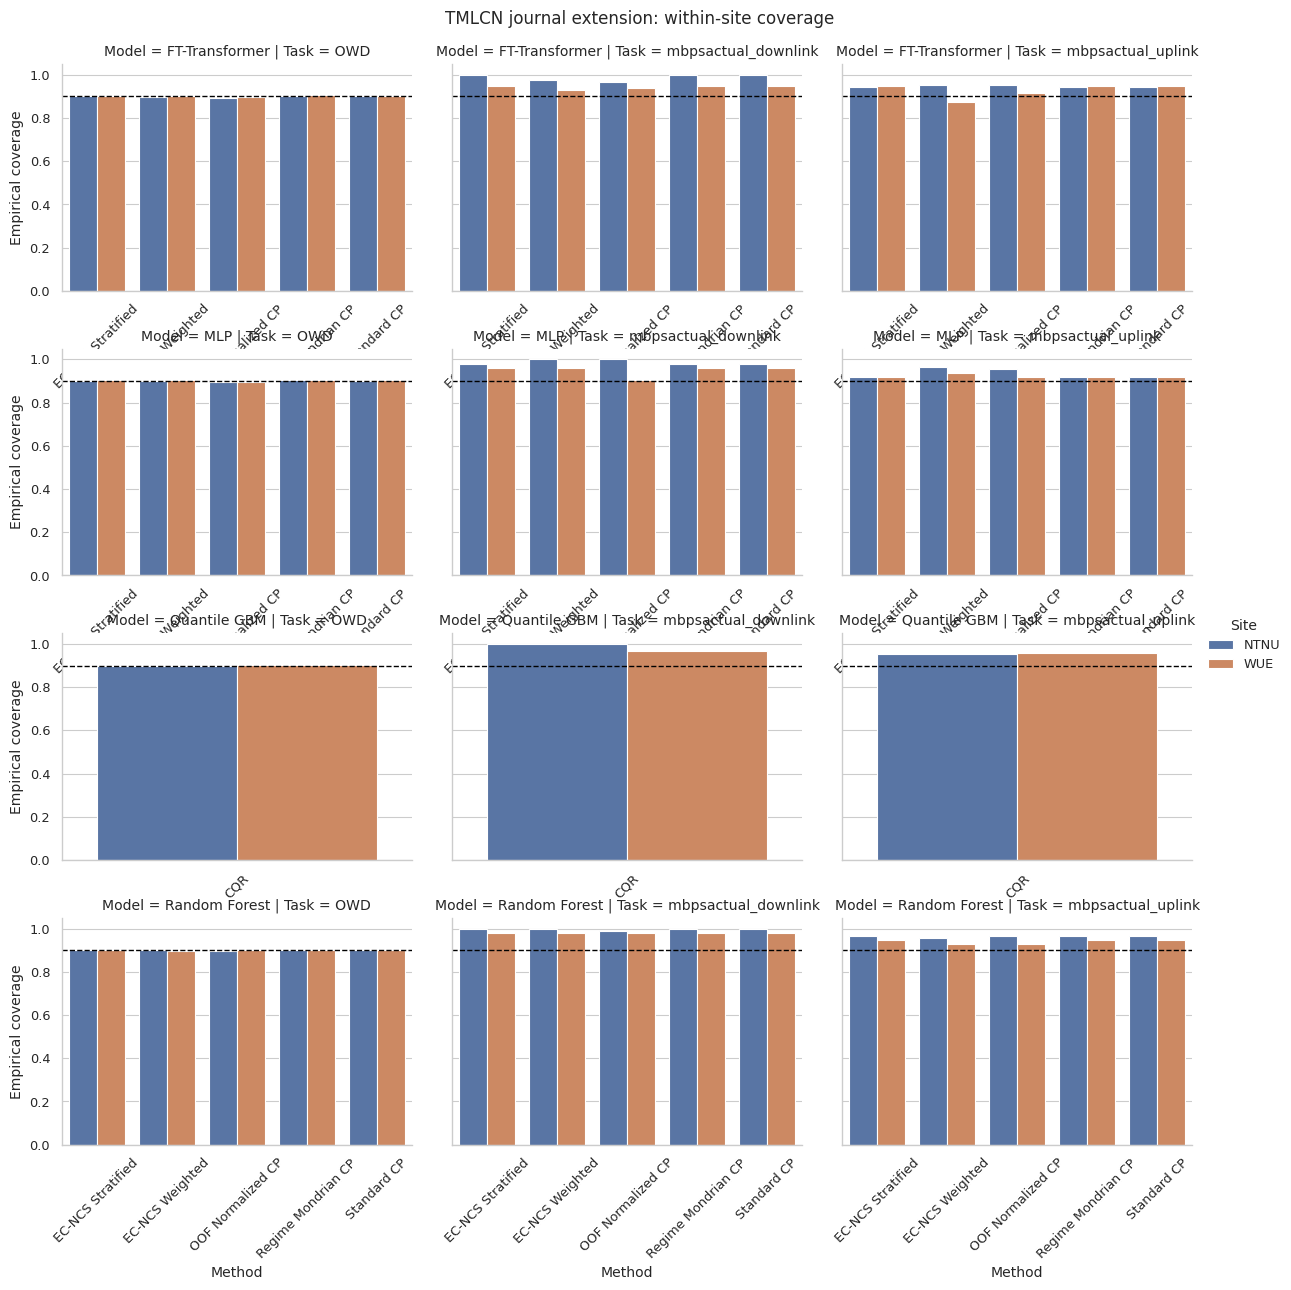

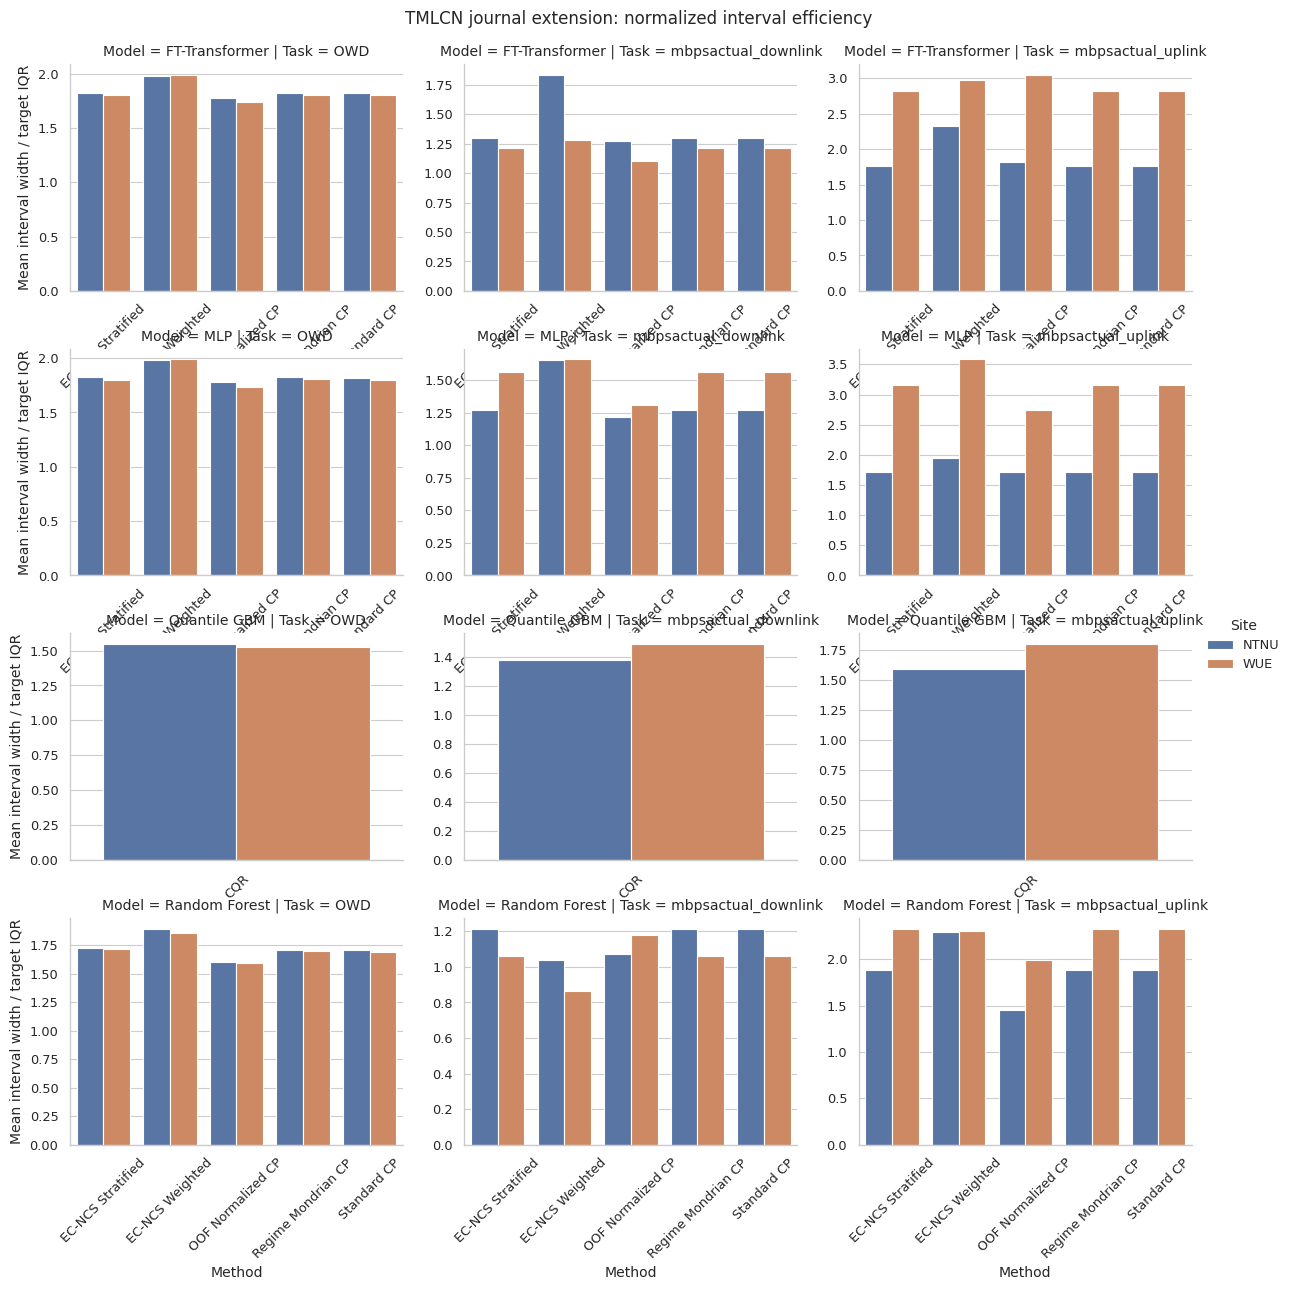

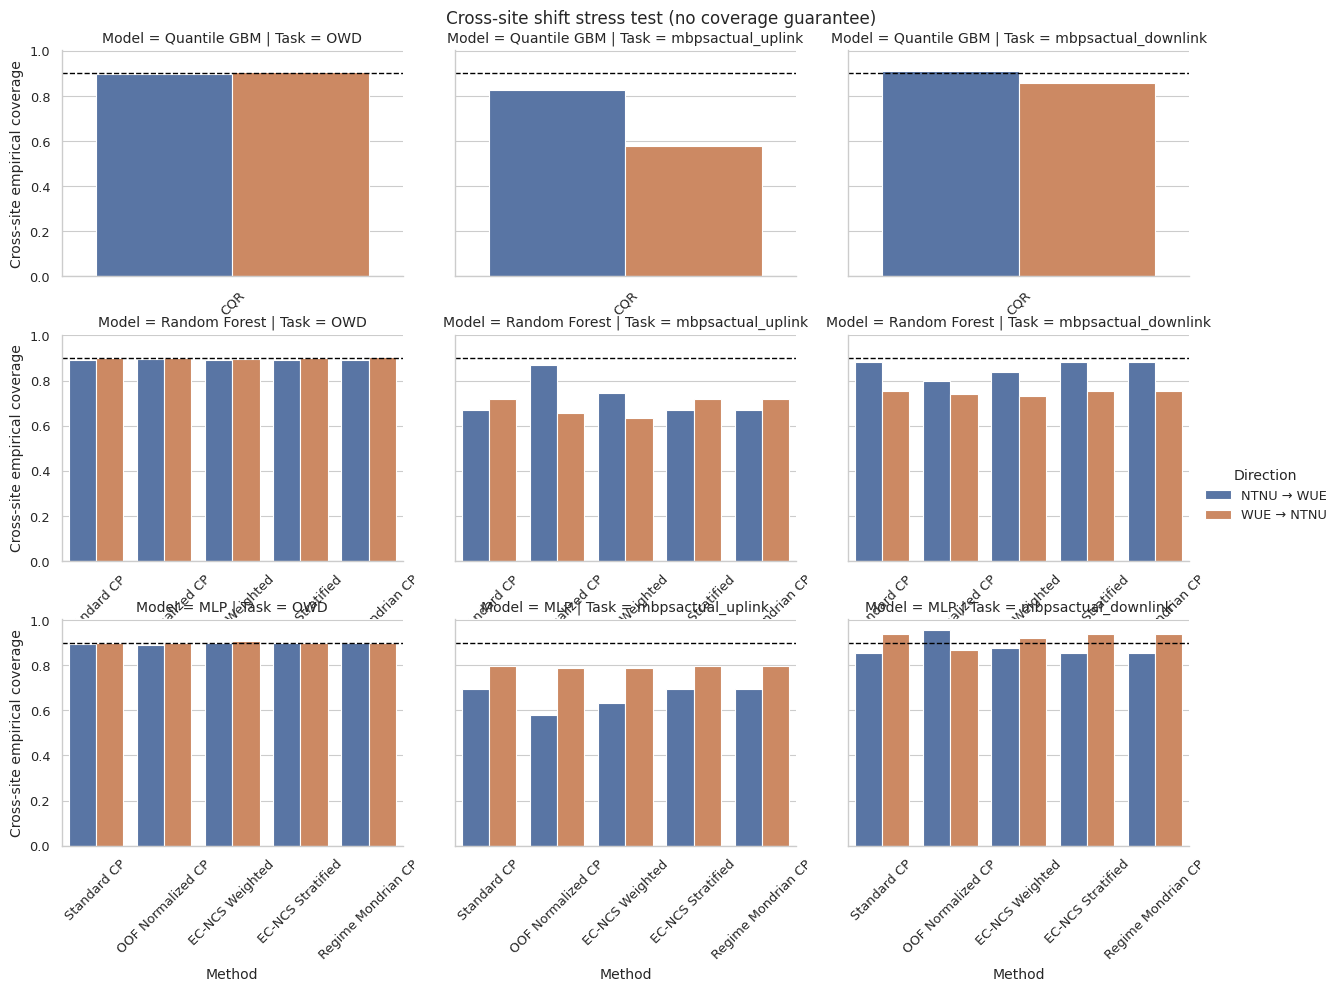


Journal continuation complete.
Results folder: /content/ec_ncs_tmlcn_journal_results
Download archive: /content/ec_ncs_tmlcn_journal_results.zip


,Task,Site,Model,Method,Coverage,CoverageSD,NormalizedWidth,Winkler,MAE,R2
0,OWD,NTNU,FT-Transformer,EC-NCS Stratified,0.902778,0.003630,1.823035,16.228800,4.242219,-0.000516
1,OWD,NTNU,FT-Transformer,EC-NCS Weighted,0.894944,0.005432,1.975483,18.980935,4.242219,-0.000516
2,OWD,NTNU,FT-Transformer,OOF Normalized CP,0.894556,0.001494,1.778317,16.812080,4.242219,-0.000516
3,OWD,NTNU,FT-Transformer,Regime Mondrian CP,0.902667,0.003403,1.822999,16.225844,4.242219,-0.000516
4,OWD,NTNU,FT-Transformer,Standard CP,0.901944,0.003945,1.821595,16.225676,4.242219,-0.000516
...,...,...,...,...,...,...,...,...,...,...
91,mbpsactual_uplink,WUE,Random Forest,EC-NCS Stratified,0.947917,0.090211,2.332861,21.578825,3.013113,0.662670
92,mbpsactual_uplink,WUE,Random Forest,EC-NCS Weighted,0.927083,0.047735,2.305150,22.553668,3.013113,0.662670
93,mbpsactual_uplink,WUE,Random Forest,OOF Normalized CP,0.927083,0.036084,1.994820,20.846855,3.013113,0.662670
94,mbpsactual_uplink,WUE,Random Forest,Regime Mondrian CP,0.947917,0.090211,2.332861,21.578825,3.013113,0.662670


,Task,Target,SourceSite,TargetSite,Model,Method,N,SplitStrategy,GuaranteeStatus,Coverage,...,MedianWidth,P90Width,Winkler,CorrPhiWidth,OOFStrategy,OOFResidualMean,OOFResidualMedian,MAE,RMSE,R2
0,OWD,trel,NTNU,WUE,Quantile GBM,CQR,30000,source random fallback,distribution-shift diagnostic only,0.897533,...,13.739513,13.824591,13.942469,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,OWD,trel,NTNU,WUE,Random Forest,Standard CP,30000,source random fallback,distribution-shift diagnostic only,0.891100,...,14.117221,14.117221,16.425523,0.000000,KFold fallback,3.620678,3.389257,3.597965,4.414861,0.199325
2,OWD,trel,NTNU,WUE,Random Forest,OOF Normalized CP,30000,source random fallback,distribution-shift diagnostic only,0.894833,...,14.442376,15.993880,15.288963,-0.262176,KFold fallback,3.620678,3.389257,3.597965,4.414861,0.199325
3,OWD,trel,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,source random fallback,distribution-shift diagnostic only,0.890167,...,15.217246,21.055050,17.535012,1.000000,KFold fallback,3.620678,3.389257,3.597965,4.414861,0.199325
4,OWD,trel,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,source random fallback,distribution-shift diagnostic only,0.892333,...,14.012604,15.339277,16.332335,0.535590,KFold fallback,3.620678,3.389257,3.597965,4.414861,0.199325
5,OWD,trel,NTNU,WUE,Random Forest,Regime Mondrian CP,30000,source random fallback,distribution-shift diagnostic only,0.891367,...,14.132937,14.556535,16.418862,0.178403,KFold fallback,3.620678,3.389257,3.597965,4.414861,0.199325
6,OWD,trel,NTNU,WUE,MLP,Standard CP,30000,source random fallback,distribution-shift diagnostic only,0.895767,...,15.300252,15.300252,16.234431,-0.042287,KFold fallback,4.239142,4.238975,4.271653,4.936666,-0.001128
7,OWD,trel,NTNU,WUE,MLP,OOF Normalized CP,30000,source random fallback,distribution-shift diagnostic only,0.891933,...,13.979344,19.266634,16.726238,0.044841,KFold fallback,4.239142,4.238975,4.271653,4.936666,-0.001128
8,OWD,trel,NTNU,WUE,MLP,EC-NCS Weighted,30000,source random fallback,distribution-shift diagnostic only,0.896600,...,16.709908,21.734003,18.971317,1.000000,KFold fallback,4.239142,4.238975,4.271653,4.936666,-0.001128
9,OWD,trel,NTNU,WUE,MLP,EC-NCS Stratified,30000,source random fallback,distribution-shift diagnostic only,0.896833,...,15.314569,15.417875,16.234618,-0.773662,KFold fallback,4.239142,4.238975,4.271653,4.936666,-0.001128


In [ ]:
from pathlib import Path

# Flatten the MultiIndex summary columns
journal_summary_df.columns = [
    "_".join(
        str(part) for part in column
        if str(part) not in ("", "None")
    ).rstrip("_")
    if isinstance(column, tuple)
    else str(column)
    for column in journal_summary_df.columns
]

journal_summary_df.to_excel(
    JOURNAL_OUTDIR / "journal_summary.xlsx",
    index=False
)

print("Excel summary repaired.")

# Continue the script from immediately after the failed export
script_path = Path("/content/EC_NCS_TMLCN_Journal_Continuation.py")
script_text = script_path.read_text()

continuation_marker = (
    "# Normalize width by the target IQR so widths are comparable "
    "across QoS targets."
)

if continuation_marker not in script_text:
    raise RuntimeError("Could not locate the continuation point.")

remaining_code = continuation_marker + script_text.split(
    continuation_marker, 1
)[1]

exec(
    compile(
        remaining_code,
        str(script_path) + "::export_continuation",
        "exec"
    ),
    globals()
)

In [ ]:
import os
import shutil
from google.colab import files

combined_dir = "/content/EC_NCS_All_Results"
final_zip = "/content/EC_NCS_All_Results.zip"

# Create clean combined folder
if os.path.exists(combined_dir):
    shutil.rmtree(combined_dir)

os.makedirs(combined_dir, exist_ok=True)

result_folders = {
    "Previous_ICC_Experiments": "/content/ec_ncs_icc_results",
    "TMLCN_Journal_Experiments": "/content/ec_ncs_tmlcn_journal_results",
}

for folder_name, source_path in result_folders.items():
    if os.path.exists(source_path):
        shutil.copytree(
            source_path,
            os.path.join(combined_dir, folder_name)
        )
        print(f"Included: {source_path}")
    else:
        print(f"WARNING: Not found: {source_path}")

# Remove an older ZIP if present
if os.path.exists(final_zip):
    os.remove(final_zip)

# Create final combined ZIP
shutil.make_archive(
    base_name="/content/EC_NCS_All_Results",
    format="zip",
    root_dir=combined_dir
)

print(f"\nCombined ZIP created: {final_zip}")
print(f"Size: {os.path.getsize(final_zip) / (1024**2):.2f} MB")

# Download
files.download(final_zip)

Included: /content/ec_ncs_icc_results
Included: /content/ec_ncs_tmlcn_journal_results

Combined ZIP created: /content/EC_NCS_All_Results.zip
Size: 1.36 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
"""TMLCN journal-only continuation cell for the EC-NCS Colab notebook.

Run this after EC_NCS_ICC_2027_Complete_Experiments.ipynb has completed.
It adds experiments that are intentionally not duplicated from that notebook:
  1) honest 3-fold out-of-fold normalized conformal prediction;
  2) conformalized quantile regression (CQR);
  3) WUE/NTNU uplink and downlink throughput tasks;
  4) within-site and cross-site evaluations for the new journal baselines/tasks.

Cross-site results are distribution-shift stress tests, not coverage guarantees.
"""

# If pasted as one Colab cell, this installs only the extra package needed here.
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openpyxl>=3.1"], check=True)

import gc
import json
import os
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, GroupShuffleSplit, train_test_split


# -----------------------------------------------------------------------------
# 0. Preconditions and journal configuration
# -----------------------------------------------------------------------------
REQUIRED_FROM_PREVIOUS_CELL = [
    "CFG", "ALPHA", "clean_df", "feature_columns", "zenodo_metadata",
    "stream_download", "uniform_chunk_sample_csv", "build_preprocessor",
    "build_model", "explain", "make_groups", "RegimeAssigner", "TrainECDF",
    "conformal_quantile", "mondrian_radii", "interval_metrics", "set_seed",
]
missing = [name for name in REQUIRED_FROM_PREVIOUS_CELL if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the complete EC-NCS ICC notebook first. Missing objects: " + ", ".join(missing)
    )

JOURNAL_OUTDIR = Path("/content/ec_ncs_tmlcn_journal_results")
JOURNAL_OUTDIR.mkdir(parents=True, exist_ok=True)

# Three seeds are a practical default for the expensive deep/OOF experiments.
# For the final paper, change to (11, 22, 33, 44, 55) if Colab time permits.
JOURNAL_SEEDS = (11, 22, 33)
JOURNAL_MODELS = ("Random Forest", "MLP", "FT-Transformer")
JOURNAL_CROSS_SITE_MODELS = ("Random Forest", "MLP")
JOURNAL_OOF_FOLDS = 3
JOURNAL_MAX_THROUGHPUT_ROWS_PER_SITE = 100_000
JOURNAL_CSV_CHUNK_SIZE = 200_000
JOURNAL_RUN_CROSS_SITE = True
JOURNAL_CQR_ESTIMATORS = 250

print("Journal continuation configuration")
print("Seeds:", JOURNAL_SEEDS)
print("Models:", JOURNAL_MODELS)
print("Output:", JOURNAL_OUTDIR)


# -----------------------------------------------------------------------------
# 1. Throughput file discovery and leakage-safe loading
# -----------------------------------------------------------------------------
THROUGHPUT_OUTCOMES = {
    "mbpsactual_uplink", "mbpsactual_downlink",
    "meanjitterms_uplink", "meanjitterms_downlink",
    "meanloss_uplink", "meanloss_downlink",
}
THROUGHPUT_TARGETS = ("mbpsactual_uplink", "mbpsactual_downlink")
THROUGHPUT_IDENTIFIER_COLUMNS = {"Unnamed: 0", "DatasetSite"}


def j_choose_throughput_file(metadata, site):
    site = site.lower()
    ranked = []
    for item in metadata.get("files", []):
        name = item.get("key", "").lower()
        score = (
            (10 if site in name else 0)
            + (12 if "throughput" in name or "tput" in name else 0)
            + (2 if name.endswith(".csv") else 0)
            - (8 if "owd" in name or "packet" in name else 0)
        )
        ranked.append((score, item))
    ranked.sort(key=lambda pair: pair[0], reverse=True)
    if not ranked or ranked[0][0] < 20:
        raise FileNotFoundError(
            f"No throughput CSV found for {site}. Files: "
            f"{[f.get('key') for f in metadata.get('files', [])]}"
        )
    return ranked[0][1]


def j_clean_throughput(frame, site):
    frame = frame.copy()
    frame.columns = frame.columns.astype(str).str.strip()
    frame["DatasetSite"] = site.upper()
    absent = [target for target in THROUGHPUT_TARGETS if target not in frame.columns]
    if absent:
        raise ValueError(f"Missing throughput targets {absent}; columns={frame.columns.tolist()}")
    for column in THROUGHPUT_OUTCOMES:
        if column in frame.columns:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
    frame = frame.replace([np.inf, -np.inf], np.nan).drop_duplicates()
    return frame


def j_load_throughput_data():
    metadata = zenodo_metadata(CFG.record_id)
    frames, audits = [], []
    for site_index, site in enumerate(CFG.sites):
        item = j_choose_throughput_file(metadata, site)
        destination = Path(CFG.data_dir) / Path(item["key"]).name
        destination = stream_download(item, destination, CFG.force_download)
        sampled, audit = uniform_chunk_sample_csv(
            destination,
            JOURNAL_MAX_THROUGHPUT_ROWS_PER_SITE,
            seed=7200 + site_index,
            chunksize=JOURNAL_CSV_CHUNK_SIZE,
        )
        sampled = j_clean_throughput(sampled, site)
        frames.append(sampled)
        audits.append({"Site": site.upper(), "File": destination.name, **audit})
    audit_df = pd.DataFrame(audits)
    audit_df["SamplingFraction"] = audit_df.RowsSampled / audit_df.RowsScanned
    audit_df.to_csv(JOURNAL_OUTDIR / "throughput_sampling_audit.csv", index=False)
    return pd.concat(frames, ignore_index=True), audit_df


throughput_df, throughput_sampling_audit = j_load_throughput_data()
display(throughput_sampling_audit)
display(throughput_df.groupby("DatasetSite", observed=True).size().rename("Rows"))


def j_throughput_features(frame, target):
    # Exclude every measured outcome, not only the chosen target. Otherwise actual
    # downlink throughput/jitter/loss could leak the uplink target and vice versa.
    excluded = THROUGHPUT_OUTCOMES | THROUGHPUT_IDENTIFIER_COLUMNS
    features = [
        column for column in frame.columns
        if column not in excluded
        and frame[column].isna().mean() <= 0.50
        and frame[column].nunique(dropna=True) > 1
    ]
    if not features:
        raise ValueError("No leakage-safe throughput predictors remain.")
    return features


# -----------------------------------------------------------------------------
# 2. Honest out-of-fold residual scale model
# -----------------------------------------------------------------------------
def j_group_or_kfold(raw_train, folds, seed):
    groups = make_groups(raw_train)
    if groups is not None and groups.nunique() >= folds:
        splitter = GroupKFold(n_splits=folds)
        return list(splitter.split(np.arange(len(raw_train)), groups=groups)), "GroupKFold"
    splitter = KFold(n_splits=folds, shuffle=True, random_state=seed)
    return list(splitter.split(np.arange(len(raw_train)))), "KFold fallback"


def j_oof_predictions(model_name, X_train, y_train, raw_train, seed):
    splits, strategy = j_group_or_kfold(raw_train, JOURNAL_OOF_FOLDS, seed)
    predictions = np.full(len(y_train), np.nan, dtype=float)
    for fold, (fit_idx, holdout_idx) in enumerate(splits):
        print(f"    OOF {model_name}: fold {fold+1}/{len(splits)}")
        fold_model = build_model(model_name, seed + 1000 + fold)
        fold_model.fit(X_train[fit_idx], y_train[fit_idx])
        predictions[holdout_idx] = fold_model.predict(X_train[holdout_idx])
        del fold_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    if np.isnan(predictions).any():
        raise RuntimeError("Incomplete OOF predictions.")
    return predictions, strategy


def j_fit_oof_scale_model(model_name, X_train, y_train, raw_train, seed):
    oof_prediction, strategy = j_oof_predictions(
        model_name, X_train, y_train, raw_train, seed
    )
    honest_residual = np.abs(y_train - oof_prediction) + 1e-6
    scale_model = ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=15, random_state=seed, n_jobs=-1
    )
    scale_model.fit(X_train, honest_residual)
    return scale_model, strategy, honest_residual


# -----------------------------------------------------------------------------
# 3. CQR baseline
# -----------------------------------------------------------------------------
def j_fit_cqr(X_train, y_train, X_cal, y_cal, X_test, alpha, seed):
    lower_model = GradientBoostingRegressor(
        loss="quantile", alpha=alpha / 2,
        n_estimators=JOURNAL_CQR_ESTIMATORS, max_depth=3,
        learning_rate=0.04, random_state=seed,
    )
    upper_model = GradientBoostingRegressor(
        loss="quantile", alpha=1 - alpha / 2,
        n_estimators=JOURNAL_CQR_ESTIMATORS, max_depth=3,
        learning_rate=0.04, random_state=seed + 1,
    )
    lower_model.fit(X_train, y_train)
    upper_model.fit(X_train, y_train)
    lower_cal, upper_cal = lower_model.predict(X_cal), upper_model.predict(X_cal)
    lower_test, upper_test = lower_model.predict(X_test), upper_model.predict(X_test)
    score = np.maximum(lower_cal - y_cal, y_cal - upper_cal)
    correction = conformal_quantile(score, alpha)
    return lower_test - correction, upper_test + correction


# -----------------------------------------------------------------------------
# 4. Correct journal interval construction
# -----------------------------------------------------------------------------
def j_build_intervals(
    model_name, model, X_train, y_train, raw_train,
    X_cal, y_cal, X_test, pred_cal, pred_test,
    phi_train, phi_cal, phi_test, regime_cal, regime_test, seed,
):
    residual = np.abs(y_cal - pred_cal)
    standard_q = conformal_quantile(residual, ALPHA)
    intervals = {
        "Standard CP": (pred_test - standard_q, pred_test + standard_q)
    }

    # Corrected normalized CP: the scale target comes from predictions on folds
    # not used to fit the corresponding base model.
    scale_model, oof_strategy, oof_residual = j_fit_oof_scale_model(
        model_name, X_train, y_train, raw_train, seed
    )
    scale_cal = np.maximum(scale_model.predict(X_cal), 1e-6)
    scale_test = np.maximum(scale_model.predict(X_test), 1e-6)
    normalized_q = conformal_quantile(residual / scale_cal, ALPHA)
    intervals["OOF Normalized CP"] = (
        pred_test - normalized_q * scale_test,
        pred_test + normalized_q * scale_test,
    )

    # EC-NCS: transformation and binning fitted on training explanations only.
    ecdf = TrainECDF().fit(phi_train)
    z_cal, z_test = ecdf.transform(phi_cal), ecdf.transform(phi_test)
    weight_cal = np.clip(
        1 + CFG.ec_beta * (z_cal - 0.5), CFG.ec_weight_min, CFG.ec_weight_max
    )
    weight_test = np.clip(
        1 + CFG.ec_beta * (z_test - 0.5), CFG.ec_weight_min, CFG.ec_weight_max
    )
    weighted_q = conformal_quantile(residual / weight_cal, ALPHA)
    intervals["EC-NCS Weighted"] = (
        pred_test - weighted_q * weight_test,
        pred_test + weighted_q * weight_test,
    )

    z_train = ecdf.transform(phi_train)
    edges = np.quantile(
        z_train, np.linspace(0, 1, CFG.explanation_groups + 1)
    )
    edges[0], edges[-1] = -np.inf, np.inf
    group_cal = np.digitize(z_cal, edges[1:-1], right=True)
    group_test = np.digitize(z_test, edges[1:-1], right=True)
    stratified_radius = mondrian_radii(
        residual, group_cal, group_test, ALPHA, CFG.minimum_group_calibration
    )
    intervals["EC-NCS Stratified"] = (
        pred_test - stratified_radius, pred_test + stratified_radius
    )

    regime_radius = mondrian_radii(
        residual, regime_cal, regime_test, ALPHA, CFG.regime_minimum_calibration
    )
    intervals["Regime Mondrian CP"] = (
        pred_test - regime_radius, pred_test + regime_radius
    )
    diagnostics = {
        "OOFStrategy": oof_strategy,
        "OOFResidualMean": float(np.mean(oof_residual)),
        "OOFResidualMedian": float(np.median(oof_residual)),
    }
    return intervals, z_test, diagnostics


# -----------------------------------------------------------------------------
# 5. Task preparation and split
# -----------------------------------------------------------------------------
def j_prepare_task(frame, target, features):
    work = frame[list(features) + [target, "DatasetSite"]].copy()
    work[target] = pd.to_numeric(work[target], errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan).dropna(subset=[target])
    return work.reset_index(drop=True)


def j_three_way_site_split(frame, seed):
    indices = np.arange(len(frame))
    groups = make_groups(frame)
    if groups is not None and groups.nunique() >= 10:
        first = GroupShuffleSplit(n_splits=1, train_size=0.60, random_state=seed)
        train_idx, remainder = next(first.split(indices, groups=groups))
        second = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=seed + 1)
        cal_rel, test_rel = next(
            second.split(remainder, groups=groups.iloc[remainder])
        )
        return train_idx, remainder[cal_rel], remainder[test_rel], "group-disjoint"
    train_idx, remainder = train_test_split(indices, train_size=0.60, random_state=seed)
    cal_idx, test_idx = train_test_split(remainder, test_size=0.50, random_state=seed + 1)
    return np.asarray(train_idx), np.asarray(cal_idx), np.asarray(test_idx), "random fallback"


def j_model_explanations(model_name, model, X_train, X_cal, X_test, seed):
    rng = np.random.default_rng(seed)
    background = X_train[
        rng.choice(len(X_train), min(128, len(X_train)), replace=False)
    ]
    phi_train, _ = explain(model_name, model, X_train, background)
    phi_cal, _ = explain(model_name, model, X_cal, background)
    phi_test, _ = explain(model_name, model, X_test, background)
    return phi_train, phi_cal, phi_test


# -----------------------------------------------------------------------------
# 6. Within-site runner: OWD plus uplink/downlink throughput
# -----------------------------------------------------------------------------
def j_run_within_site(task_name, frame, target, features):
    result_rows, regime_rows, cqr_rows = [], [], []
    for site in sorted(frame.DatasetSite.astype(str).unique()):
        site_frame = frame[frame.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in JOURNAL_SEEDS:
            print(f"\n===== {task_name} | {site} | seed {seed} =====")
            set_seed(seed)
            tr, ca, te, split_strategy = j_three_way_site_split(site_frame, seed)
            Xraw = site_frame[features]
            y = site_frame[target].to_numpy(float)
            Xtr_raw, Xca_raw, Xte_raw = Xraw.iloc[tr], Xraw.iloc[ca], Xraw.iloc[te]
            ytr, yca, yte = y[tr], y[ca], y[te]

            regime_model = RegimeAssigner().fit(Xtr_raw)
            regime_cal = regime_model.transform(Xca_raw).to_numpy()
            regime_test = regime_model.transform(Xte_raw).to_numpy()
            preprocessor = build_preprocessor(Xtr_raw)
            Xtr = preprocessor.fit_transform(Xtr_raw).astype(np.float32)
            Xca = preprocessor.transform(Xca_raw).astype(np.float32)
            Xte = preprocessor.transform(Xte_raw).astype(np.float32)

            # CQR is a separate predictive baseline and is therefore run once per split.
            cqr_lo, cqr_hi = j_fit_cqr(Xtr, ytr, Xca, yca, Xte, ALPHA, seed)
            cqr_metric = interval_metrics(yte, cqr_lo, cqr_hi, ALPHA)
            cqr_rows.append({
                "Task": task_name, "Site": site, "Seed": seed,
                "Model": "Quantile GBM", "Method": "CQR",
                "SplitStrategy": split_strategy, "N": len(yte), **cqr_metric,
            })

            for model_name in JOURNAL_MODELS:
                print("  Model:", model_name)
                start = time.perf_counter()
                model = build_model(model_name, seed).fit(Xtr, ytr)
                pred_train = model.predict(Xtr)
                pred_cal = model.predict(Xca)
                pred_test = model.predict(Xte)
                phi_train, phi_cal, phi_test = j_model_explanations(
                    model_name, model, Xtr, Xca, Xte, seed
                )
                intervals, z_test, diagnostics = j_build_intervals(
                    model_name, model, Xtr, ytr, Xtr_raw,
                    Xca, yca, Xte, pred_cal, pred_test,
                    phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed,
                )
                runtime = time.perf_counter() - start
                prediction_metrics = {
                    "MAE": mean_absolute_error(yte, pred_test),
                    "RMSE": mean_squared_error(yte, pred_test) ** 0.5,
                    "R2": r2_score(yte, pred_test),
                }
                for method, (lower, upper) in intervals.items():
                    result_rows.append({
                        "Task": task_name, "Target": target, "Site": site,
                        "Seed": seed, "Model": model_name, "Method": method,
                        "SplitStrategy": split_strategy, "N": len(yte),
                        "RuntimeSecondsIncludingOOF": runtime,
                        **diagnostics, **prediction_metrics,
                        **interval_metrics(yte, lower, upper, ALPHA, z_test),
                    })
                    for regime in ["normal", "transition", "congestion"]:
                        mask = regime_test == regime
                        if mask.sum() == 0:
                            continue
                        regime_rows.append({
                            "Task": task_name, "Site": site, "Seed": seed,
                            "Model": model_name, "Method": method,
                            "Regime": regime, "N": int(mask.sum()),
                            **interval_metrics(
                                yte[mask], lower[mask], upper[mask], ALPHA, z_test[mask]
                            ),
                        })
                del model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
    return pd.DataFrame(result_rows), pd.DataFrame(regime_rows), pd.DataFrame(cqr_rows)


# Existing OWD task from the completed notebook.
owd_task = j_prepare_task(clean_df, CFG.target_col, feature_columns)

tasks = [("OWD", owd_task, CFG.target_col, feature_columns)]
for throughput_target in THROUGHPUT_TARGETS:
    safe_features = j_throughput_features(throughput_df, throughput_target)
    task_frame = j_prepare_task(throughput_df, throughput_target, safe_features)
    tasks.append((throughput_target, task_frame, throughput_target, safe_features))

within_frames, regime_frames, cqr_frames = [], [], []
for task_name, task_frame, target, features in tasks:
    within, regimes, cqr = j_run_within_site(
        task_name, task_frame, target, features
    )
    within_frames.append(within)
    regime_frames.append(regimes)
    cqr_frames.append(cqr)

journal_within_df = pd.concat(within_frames + cqr_frames, ignore_index=True, sort=False)
journal_regime_df = pd.concat(regime_frames, ignore_index=True, sort=False)
journal_within_df.to_csv(JOURNAL_OUTDIR / "journal_within_site_results.csv", index=False)
journal_regime_df.to_csv(JOURNAL_OUTDIR / "journal_regime_results.csv", index=False)


# -----------------------------------------------------------------------------
# 7. Cross-site transfer for OWD and throughput
# -----------------------------------------------------------------------------
def j_run_cross_site(task_name, frame, target, features):
    rows = []
    if not JOURNAL_RUN_CROSS_SITE:
        return pd.DataFrame(rows)
    sites = sorted(frame.DatasetSite.astype(str).unique())
    seed = JOURNAL_SEEDS[0]
    for source in sites:
        for destination in sites:
            if source == destination:
                continue
            print(f"\n===== TRANSFER {task_name}: {source} -> {destination} =====")
            source_df = frame[frame.DatasetSite.astype(str) == source].reset_index(drop=True)
            test_df = frame[frame.DatasetSite.astype(str) == destination].reset_index(drop=True)
            groups = make_groups(source_df)
            indices = np.arange(len(source_df))
            if groups is not None and groups.nunique() >= 8:
                splitter = GroupShuffleSplit(n_splits=1, train_size=0.75, random_state=seed)
                train_idx, cal_idx = next(splitter.split(indices, groups=groups))
                split_strategy = "source group-disjoint"
            else:
                train_idx, cal_idx = train_test_split(indices, train_size=0.75, random_state=seed)
                split_strategy = "source random fallback"

            Xsource = source_df[features]
            Xtest_raw = test_df[features]
            ysource = source_df[target].to_numpy(float)
            ytest = test_df[target].to_numpy(float)
            Xtr_raw, Xca_raw = Xsource.iloc[train_idx], Xsource.iloc[cal_idx]
            ytr, yca = ysource[train_idx], ysource[cal_idx]
            regime_model = RegimeAssigner().fit(Xtr_raw)
            regime_cal = regime_model.transform(Xca_raw).to_numpy()
            regime_test = regime_model.transform(Xtest_raw).to_numpy()
            preprocessor = build_preprocessor(Xtr_raw)
            Xtr = preprocessor.fit_transform(Xtr_raw).astype(np.float32)
            Xca = preprocessor.transform(Xca_raw).astype(np.float32)
            Xtest = preprocessor.transform(Xtest_raw).astype(np.float32)

            cqr_lo, cqr_hi = j_fit_cqr(Xtr, ytr, Xca, yca, Xtest, ALPHA, seed)
            rows.append({
                "Task": task_name, "Target": target,
                "SourceSite": source, "TargetSite": destination,
                "Model": "Quantile GBM", "Method": "CQR", "N": len(ytest),
                "SplitStrategy": split_strategy,
                "GuaranteeStatus": "distribution-shift diagnostic only",
                **interval_metrics(ytest, cqr_lo, cqr_hi, ALPHA),
            })

            for model_name in JOURNAL_CROSS_SITE_MODELS:
                model = build_model(model_name, seed).fit(Xtr, ytr)
                pred_train, pred_cal, pred_test = (
                    model.predict(array) for array in [Xtr, Xca, Xtest]
                )
                phi_train, phi_cal, phi_test = j_model_explanations(
                    model_name, model, Xtr, Xca, Xtest, seed
                )
                intervals, z_test, diagnostics = j_build_intervals(
                    model_name, model, Xtr, ytr, Xtr_raw,
                    Xca, yca, Xtest, pred_cal, pred_test,
                    phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed,
                )
                prediction_metrics = {
                    "MAE": mean_absolute_error(ytest, pred_test),
                    "RMSE": mean_squared_error(ytest, pred_test) ** 0.5,
                    "R2": r2_score(ytest, pred_test),
                }
                for method, (lower, upper) in intervals.items():
                    rows.append({
                        "Task": task_name, "Target": target,
                        "SourceSite": source, "TargetSite": destination,
                        "Model": model_name, "Method": method, "N": len(ytest),
                        "SplitStrategy": split_strategy,
                        "GuaranteeStatus": "distribution-shift diagnostic only",
                        **diagnostics, **prediction_metrics,
                        **interval_metrics(ytest, lower, upper, ALPHA, z_test),
                    })
                del model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
    return pd.DataFrame(rows)


cross_frames = []
for task_name, task_frame, target, features in tasks:
    cross_frames.append(j_run_cross_site(task_name, task_frame, target, features))
journal_cross_site_df = pd.concat(cross_frames, ignore_index=True, sort=False)
journal_cross_site_df.to_csv(
    JOURNAL_OUTDIR / "journal_cross_site_results.csv", index=False
)


# -----------------------------------------------------------------------------
# 8. Publication-ready summaries and figures
# -----------------------------------------------------------------------------
summary_columns = [
    "Coverage", "Undercoverage", "MeanWidth", "Winkler",
    "MAE", "RMSE", "R2"
]
journal_summary_df = (
    journal_within_df
    .groupby(["Task", "Site", "Model", "Method"], dropna=False)[summary_columns]
    .agg(["mean", "std"])
    .reset_index()
)
journal_summary_df.to_excel(
    JOURNAL_OUTDIR / "journal_summary.xlsx", index=False
)

# Normalize width by the target IQR so widths are comparable across QoS targets.
target_iqrs = {}
for task_name, task_frame, target, _ in tasks:
    for site in task_frame.DatasetSite.astype(str).unique():
        values = task_frame.loc[task_frame.DatasetSite.astype(str) == site, target]
        target_iqrs[(task_name, site)] = float(values.quantile(0.75) - values.quantile(0.25))
journal_within_df["TargetIQR"] = [
    target_iqrs.get((task, site), np.nan)
    for task, site in zip(journal_within_df.Task, journal_within_df.Site)
]
journal_within_df["NormalizedMeanWidth"] = (
    journal_within_df.MeanWidth / journal_within_df.TargetIQR.replace(0, np.nan)
)
journal_within_df.to_csv(
    JOURNAL_OUTDIR / "journal_within_site_results_with_normalized_width.csv",
    index=False,
)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.05)
plot_data = (
    journal_within_df
    .groupby(["Task", "Site", "Model", "Method"], as_index=False)
    .agg(Coverage=("Coverage", "mean"),
         NormalizedMeanWidth=("NormalizedMeanWidth", "mean"))
)

g = sns.catplot(
    data=plot_data, x="Method", y="Coverage", hue="Site",
    col="Task", row="Model", kind="bar", height=3.0, aspect=1.35,
    sharex=False,
)
for axis in g.axes.flat:
    axis.axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1)
    axis.tick_params(axis="x", rotation=45)
g.set_axis_labels("Method", "Empirical coverage")
g.fig.subplots_adjust(top=0.95)
g.fig.suptitle("TMLCN journal extension: within-site coverage", y=0.995)
g.savefig(JOURNAL_OUTDIR / "journal_coverage.pdf", bbox_inches="tight")
g.savefig(JOURNAL_OUTDIR / "journal_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

g = sns.catplot(
    data=plot_data, x="Method", y="NormalizedMeanWidth", hue="Site",
    col="Task", row="Model", kind="bar", height=3.0, aspect=1.35,
    sharex=False, sharey=False,
)
for axis in g.axes.flat:
    axis.tick_params(axis="x", rotation=45)
g.set_axis_labels("Method", "Mean interval width / target IQR")
g.fig.subplots_adjust(top=0.95)
g.fig.suptitle("TMLCN journal extension: normalized interval efficiency", y=0.995)
g.savefig(JOURNAL_OUTDIR / "journal_normalized_width.pdf", bbox_inches="tight")
g.savefig(JOURNAL_OUTDIR / "journal_normalized_width.png", dpi=300, bbox_inches="tight")
plt.show()

if len(journal_cross_site_df):
    transfer_plot = journal_cross_site_df.copy()
    transfer_plot["Direction"] = (
        transfer_plot.SourceSite + " → " + transfer_plot.TargetSite
    )
    g = sns.catplot(
        data=transfer_plot, x="Method", y="Coverage", hue="Direction",
        col="Task", row="Model", kind="bar", height=3.0, aspect=1.35,
        sharex=False,
    )
    for axis in g.axes.flat:
        axis.axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1)
        axis.tick_params(axis="x", rotation=45)
    g.set_axis_labels("Method", "Cross-site empirical coverage")
    g.fig.subplots_adjust(top=0.95)
    g.fig.suptitle("Cross-site shift stress test (no coverage guarantee)", y=0.995)
    g.savefig(JOURNAL_OUTDIR / "journal_cross_site.pdf", bbox_inches="tight")
    g.savefig(JOURNAL_OUTDIR / "journal_cross_site.png", dpi=300, bbox_inches="tight")
    plt.show()


# -----------------------------------------------------------------------------
# 9. Audit notes, LaTeX exports, and download archive
# -----------------------------------------------------------------------------
audit_note = {
    "coverage_claim": (
        "Within-site split-conformal results target marginal coverage under "
        "exchangeability. Regime-wise results are diagnostics unless the fixed "
        "Mondrian assumptions hold. Cross-site results have no distribution-free "
        "coverage guarantee."
    ),
    "normalized_cp_fix": (
        "The local scale model is fitted to out-of-fold residuals, not residuals "
        "from observations used to train the corresponding base model."
    ),
    "throughput_leakage_control": sorted(THROUGHPUT_OUTCOMES),
    "throughput_targets": list(THROUGHPUT_TARGETS),
    "seeds": list(JOURNAL_SEEDS),
    "models": list(JOURNAL_MODELS),
    "oof_folds": JOURNAL_OOF_FOLDS,
}
(JOURNAL_OUTDIR / "journal_experiment_audit.json").write_text(
    json.dumps(audit_note, indent=2)
)

flat_summary = (
    journal_within_df
    .groupby(["Task", "Site", "Model", "Method"], as_index=False)
    .agg(Coverage=("Coverage", "mean"),
         CoverageSD=("Coverage", "std"),
         NormalizedWidth=("NormalizedMeanWidth", "mean"),
         Winkler=("Winkler", "mean"),
         MAE=("MAE", "mean"), R2=("R2", "mean"))
)
(JOURNAL_OUTDIR / "journal_summary.tex").write_text(
    flat_summary.to_latex(index=False, float_format="%.3f")
)
flat_summary.to_excel(JOURNAL_OUTDIR / "journal_summary_flat.xlsx", index=False)

archive_path = shutil.make_archive(
    "/content/ec_ncs_tmlcn_journal_results", "zip", JOURNAL_OUTDIR
)
print("\nJournal continuation complete.")
print("Results folder:", JOURNAL_OUTDIR)
print("Download archive:", archive_path)
display(flat_summary)
display(journal_cross_site_df.head(30))



In [ ]:

# Colab-ready dependency bootstrap. Safe to rerun.
import importlib.util
import subprocess
import sys

_required = {
    "shap": "shap>=0.46",
    "captum": "captum>=0.7",
    "openpyxl": "openpyxl>=3.1",
    "pyarrow": "pyarrow>=15",
    "psutil": "psutil>=5.9",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# %%
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
from urllib.parse import quote
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import requests
import seaborn as sns
import shap
import torch
import torch.nn as nn
from captum.attr import GradientShap
from scipy.stats import spearmanr, wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


@dataclass
class Config:
    record_id: str = "13754300"
    sites: Tuple[str, ...] = ("wue", "ntnu")
    target_col: str = "trel"
    max_rows_per_site: int = 30_000
    csv_chunk_size: int = 200_000
    nominal_coverage: float = 0.90
    train_fraction: float = 0.60
    calibration_fraction: float = 0.20
    test_fraction: float = 0.20
    pooled_diagnostic_seeds: Tuple[int, ...] = (11,)
    rf_trees: int = 200
    rf_min_leaf: int = 2
    mlp_epochs: int = 50
    mlp_batch_size: int = 512
    mlp_patience: int = 7
    explanation_batch_size: int = 256
    gradient_shap_samples: int = 4
    max_explanation_train_rows: int = 5_000
    tree_shap_approximate: bool = True
    beta_grid: Tuple[float, ...] = (0.0, 0.25, 0.50, 0.75, 1.00, 1.25)
    beta_inner_fit_fraction: float = 0.60
    beta_inner_calibration_fraction: float = 0.20
    beta_inner_max_rows_per_split: int = 2_000
    beta_coverage_tolerance: float = 0.01
    beta_worst_bin_tolerance: float = 0.03
    normalized_cp_oof_folds: int = 3
    oof_normalized_models: Tuple[str, ...] = ("Random Forest",)
    ec_weight_min: float = 0.35
    ec_weight_max: float = 3.00
    explanation_groups: int = 4
    minimum_group_calibration: int = 50
    regime_minimum_calibration: int = 50
    outdir: str = "/content/ec_ncs_tmlcn_final_results"
    data_dir: str = "/content/ec_ncs_data"
    force_download: bool = False
    smoke_test: bool = False          # True uses synthetic data and runs quickly
    run_cross_site_transfer: bool = True
    cross_site_models: Tuple[str, ...] = ("Random Forest", "MLP")
    cross_site_seed: int = 2027  # retained for the single fixed transfer diagnostic
    run_within_site_validation: bool = True
    within_site_models: Tuple[str, ...] = ("Random Forest", "MLP", "FT-Transformer")
    within_site_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55)
    explicit_scenario_regime_map: Optional[Dict[str, str]] = None
    require_explicit_regime_map: bool = False
    sla_threshold: Optional[float] = None  # replace with a domain-supported delay threshold

CFG = Config()
ALPHA = 1.0 - CFG.nominal_coverage
OUTDIR = Path(CFG.outdir)
DATA_DIR = Path(CFG.data_dir)
OUTDIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
MAIN_FIG_DIR = OUTDIR / "main_paper_figures"
SUPP_DIR = OUTDIR / "supplementary"
CHECKPOINT_DIR = OUTDIR / "checkpoints"
for _directory in (MAIN_FIG_DIR, SUPP_DIR, CHECKPOINT_DIR):
    _directory.mkdir(parents=True, exist_ok=True)
print(CFG)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conformal_quantile(scores: Sequence[float], alpha: float) -> float:
    """Finite-sample split-conformal quantile using the higher order statistic."""
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    if scores.size == 0:
        raise ValueError("No finite calibration scores.")
    level = min(1.0, np.ceil((scores.size + 1) * (1.0 - alpha)) / scores.size)
    return float(np.quantile(scores, level, method="higher"))


class TrainECDF:
    """Pointwise rank transform fitted only on training explanations."""
    def fit(self, values: Sequence[float]):
        self.sorted_ = np.sort(np.asarray(values, dtype=float))
        return self

    def transform(self, values: Sequence[float]) -> np.ndarray:
        values = np.asarray(values, dtype=float)
        return np.searchsorted(self.sorted_, values, side="right") / max(len(self.sorted_), 1)


def bootstrap_ci(values: Sequence[float], fn=np.mean, seed: int = 0,
                 n_boot: int = 500, level: float = 0.95) -> Tuple[float, float]:
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    draws = [fn(values[rng.integers(0, len(values), len(values))]) for _ in range(n_boot)]
    tail = (1.0 - level) / 2.0
    return tuple(np.quantile(draws, [tail, 1.0 - tail]))


def interval_metrics(y: np.ndarray, lo: np.ndarray, hi: np.ndarray,
                     alpha: float, phi: Optional[np.ndarray] = None) -> Dict[str, float]:
    y, lo, hi = map(lambda z: np.asarray(z, dtype=float), (y, lo, hi))
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    below = np.maximum(lo - y, 0.0)
    above = np.maximum(y - hi, 0.0)
    winkler = width + (2.0 / alpha) * (below + above)
    corr = 0.0
    if phi is not None and np.std(width) > 1e-12:
        corr = float(spearmanr(phi, width).correlation)
        if not np.isfinite(corr):
            corr = 0.0
    mean_width = float(width.mean())
    coverage = float(covered.mean())
    return {
        "Coverage": coverage,
        "Undercoverage": float(max(0.0, (1.0 - alpha) - coverage)),
        "MeanWidth": mean_width,
        "IntervalEfficiency": float(1.0 / max(mean_width, 1e-12)),
        "CoverageWidthCriterion": float(mean_width * (1.0 + 10.0 * abs(coverage - (1.0-alpha)))),
        "MedianWidth": float(np.median(width)),
        "P90Width": float(np.quantile(width, 0.90)),
        "Winkler": float(winkler.mean()),
        "CorrPhiWidth": corr,
    }


def timed_call(fn, *args, synchronize_gpu: bool = True, **kwargs):
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    mem_after = process.memory_info().rss
    return out, elapsed, max(0, mem_after - mem_before) / 2**20


def zenodo_metadata(record_id: str) -> Mapping:
    cache_path = DATA_DIR / f"zenodo_metadata_{record_id}.json"
    for attempt in range(6):
        try:
            response = requests.get(
                f"https://zenodo.org/api/records/{record_id}", timeout=180,
                headers={"User-Agent": "EC-NCS-research/1.0"},
            )
            response.raise_for_status()
            payload = response.json()
            cache_path.write_text(json.dumps(payload))
            return payload
        except requests.RequestException as error:
            if cache_path.exists():
                print(f"Zenodo API unavailable; using cached metadata: {error}")
                return json.loads(cache_path.read_text())
            if attempt < 5:
                wait = min(60, 5 * (2 ** attempt))
                print(f"Zenodo metadata attempt {attempt+1} failed; retrying in {wait}s")
                time.sleep(wait)
    print("Zenodo metadata unavailable; using documented OWD filenames.")
    return {"files": [
        {"key": "wue_owd_Packets_with_IATs.csv", "links": {}},
        {"key": "ntnu_owd_Packets_with_IATs.csv", "links": {}},
    ]}


def choose_owd_file(metadata: Mapping, site: str) -> Mapping:
    site = site.lower()
    files = metadata.get("files", [])
    ranked = []
    for item in files:
        name = item.get("key", "").lower()
        score = 0
        score += 8 if site in name else 0
        score += 8 if "owd" in name else 0
        score += 4 if "with_iats" in name else 0
        score -= 5 if "tput" in name else 0
        score += 2 if name.endswith(".csv") else 0
        ranked.append((score, item))
    ranked.sort(key=lambda z: z[0], reverse=True)
    if not ranked or ranked[0][0] < 12:
        available = [f.get("key") for f in files]
        raise FileNotFoundError(f"No suitable {site} OWD CSV. Available: {available}")
    return ranked[0][1]


def stream_download(item: Mapping, destination: Path, force: bool = False) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and not force:
        return destination
    file_name = item["key"]
    urls = []
    if item.get("links", {}).get("self"):
        urls.append(item["links"]["self"])
    urls.append(
        f"https://zenodo.org/records/{CFG.record_id}/files/{quote(file_name)}?download=1"
    )
    temporary = Path(str(destination) + ".part")
    last_error = None
    for url in urls:
        for attempt in range(5):
            try:
                headers = {}
                mode = "wb"
                if temporary.exists() and temporary.stat().st_size > 0:
                    headers["Range"] = f"bytes={temporary.stat().st_size}-"
                    mode = "ab"
                with requests.get(url, stream=True, timeout=300, headers=headers) as response:
                    if response.status_code == 200 and mode == "ab":
                        mode = "wb"  # server ignored Range; restart safely
                    response.raise_for_status()
                    with temporary.open(mode) as handle:
                        for chunk in response.iter_content(chunk_size=2**20):
                            if chunk:
                                handle.write(chunk)
                os.replace(temporary, destination)
                return destination
            except requests.RequestException as error:
                last_error = error
                wait = min(60, 5 * (2 ** attempt))
                print(f"Download attempt {attempt+1} failed for {file_name}; retrying in {wait}s")
                time.sleep(wait)
    raise RuntimeError(f"Could not download {file_name}: {last_error}")
    return destination


def synthetic_5g(n: int = 12_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    load = rng.uniform(0, 1, n)
    scenario = pd.cut(load, [-1, .35, .70, 2], labels=["normal", "transition", "congestion"])
    packet_size = rng.choice([128, 256, 512, 1024, 1500], n)
    iat = rng.lognormal(-2.0 + 1.2 * load, .35, n)
    ratio = rng.uniform(.1, 1.0, n)
    noise = rng.normal(0, .12 + .55 * load**2, n)
    trel = 0.15 + 1.1 * load + .00025 * packet_size + .15 * ratio + noise
    return pd.DataFrame({"PacketSize": packet_size, "iat": iat, "ratio": ratio,
                         "scenario": scenario.astype(str), "rep": rng.integers(0, 30, n),
                         "trel": trel})


def uniform_chunk_sample_csv(path: Path, sample_size: int, seed: int,
                             chunksize: int = 200_000) -> Tuple[pd.DataFrame, Dict[str, int]]:
    """Exact uniform random-key reservoir sample over every data row in a CSV.

    Independent continuous priorities give every row equal inclusion probability and avoid
    the ordered-prefix bias caused by pd.read_csv(..., nrows=sample_size).
    """
    rng = np.random.default_rng(seed)
    reservoir = None
    seen = 0
    for chunk_id, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False)):
        chunk.columns = chunk.columns.astype(str).str.strip()
        seen += len(chunk)
        chunk["__uniform_priority__"] = rng.random(len(chunk))
        candidates = chunk if reservoir is None else pd.concat([reservoir, chunk], ignore_index=True)
        reservoir = candidates.nsmallest(min(sample_size, len(candidates)), "__uniform_priority__")
        if (chunk_id + 1) % 10 == 0:
            print(f"  scanned {seen:,} rows from {path.name}")
    sampled = reservoir.drop(columns="__uniform_priority__").reset_index(drop=True)
    return sampled, {"RowsScanned": seen, "RowsSampled": len(sampled),
                     "SamplingSeed": seed, "ChunkSize": chunksize}


sampling_rows, selected_files = [], {}
site_frames = []
if CFG.smoke_test:
    for i, site in enumerate(CFG.sites):
        frame = synthetic_5g(seed=42+i)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": "synthetic smoke test",
                              "RowsScanned": len(frame), "RowsSampled": len(frame),
                              "SamplingSeed": 42+i, "ChunkSize": np.nan})
        selected_files[site] = "synthetic smoke test"
else:
    metadata = zenodo_metadata(CFG.record_id)
    for i, site in enumerate(CFG.sites):
        selected = choose_owd_file(metadata, site)
        selected_path = DATA_DIR / Path(selected["key"]).name
        selected_path = stream_download(selected, selected_path, CFG.force_download)
        print(f"Uniformly sampling the complete {site.upper()} file: {selected_path.name}")
        frame, audit = uniform_chunk_sample_csv(selected_path, CFG.max_rows_per_site,
                                                seed=2027+i, chunksize=CFG.csv_chunk_size)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": selected_path.name, **audit})
        selected_files[site] = str(selected_path)

raw_df = pd.concat(site_frames, ignore_index=True)
sampling_audit_df = pd.DataFrame(sampling_rows)
sampling_audit_df["SamplingFraction"] = sampling_audit_df.RowsSampled / sampling_audit_df.RowsScanned
sampling_audit_df.to_csv(OUTDIR / "sampling_audit.csv", index=False)
raw_df.columns = raw_df.columns.astype(str).str.strip()
print("Selected files:", selected_files)
print("Shape:", raw_df.shape)
display(sampling_audit_df)
display(raw_df.groupby("DatasetSite", observed=True).size().rename("SampledRows"))
display(raw_df.head())
print(raw_df.dtypes)


DROP_COLUMNS = {
    "Unnamed: 0", "src", "Timestamp", "SourceIPOuter", "DestinationIPOuter",
    "SourceIPInner", "DestinationIPInner", "SeqNum", "DatasetSite",
    # Retained in clean_df for splitting/auditing, but never supplied to a model.
    "scenario", "rep"
}


def audit_and_clean(df: pd.DataFrame, target_col: str):
    if target_col not in df.columns:
        raise ValueError(f"Target {target_col!r} missing. Available columns: {df.columns.tolist()}")
    work = df.copy()
    work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan).dropna(subset=[target_col]).drop_duplicates()
    candidate = [c for c in work.columns if c != target_col and c not in DROP_COLUMNS]
    audit_rows = []
    selected = []
    for col in work.columns:
        missing = float(work[col].isna().mean())
        nunique = int(work[col].nunique(dropna=True))
        reason = "included"
        include = col in candidate and missing <= .50 and nunique > 1
        if col == target_col: reason = "target"
        elif col in DROP_COLUMNS: reason = "identifier/sequence leakage risk"
        elif missing > .50: reason = ">50% missing"
        elif nunique <= 1: reason = "constant"
        elif include: selected.append(col)
        audit_rows.append({"Feature": col, "Dtype": str(work[col].dtype),
                           "MissingFraction": missing, "UniqueValues": nunique,
                           "Included": include, "Reason": reason})
    return work, selected, pd.DataFrame(audit_rows)


clean_df, feature_columns, feature_audit = audit_and_clean(raw_df, CFG.target_col)
feature_audit.to_csv(OUTDIR / "feature_audit.csv", index=False)
display(feature_audit)
print("Included features:", feature_columns)


def scenario_to_regime(values: pd.Series) -> Optional[pd.Series]:
    text = values.astype(str).str.lower()
    out = pd.Series(index=values.index, dtype="object")
    patterns = {
        "normal": r"normal|stable|baseline|idle|low",
        "transition": r"transition|medium|moderate|ramp|bursty",
        "congestion": r"congest|overload|heavy|high|stress"
    }
    for label, pattern in patterns.items():
        out[text.str.contains(pattern, regex=True, na=False)] = label
    return out if out.notna().mean() >= .70 else None


if "scenario" in clean_df.columns:
    scenario_inventory = (clean_df.groupby(["DatasetSite", "scenario"], observed=True)
                          .size().rename("N").reset_index())
    inferred = scenario_to_regime(scenario_inventory["scenario"])
    scenario_inventory["SuggestedRegime"] = (inferred if inferred is not None else "REVIEW_REQUIRED")
    scenario_inventory.to_csv(OUTDIR / "scenario_regime_inventory.csv", index=False)
    display(scenario_inventory)
    print("For the paper, populate CFG.explicit_scenario_regime_map and set "
          "CFG.require_explicit_regime_map=True after domain review.")


REGIME_FEATURE_HINTS = ["ratio", "pdist", "pnpak", "piat", "iat", "packetsize", "bw", "slots"]


class RegimeAssigner:
    def fit(self, X: pd.DataFrame):
        if "scenario" in X.columns:
            if CFG.explicit_scenario_regime_map is not None:
                allowed = {"normal", "transition", "congestion"}
                if not set(CFG.explicit_scenario_regime_map.values()).issubset(allowed):
                    raise ValueError(f"Regime-map values must be in {allowed}")
                observed = set(X["scenario"].astype(str).unique())
                missing = observed - set(CFG.explicit_scenario_regime_map)
                if missing:
                    raise ValueError(f"Explicit regime map misses scenario labels: {sorted(missing)}")
                self.mode_ = "explicit scenario mapping"
                self.scenario_map_ = dict(CFG.explicit_scenario_regime_map)
                return self
            if CFG.require_explicit_regime_map:
                raise ValueError("Populate CFG.explicit_scenario_regime_map after inspecting scenario labels.")
            direct = scenario_to_regime(X["scenario"])
            if direct is not None:
                self.mode_ = "scenario labels"
                self.scenario_map_ = dict(zip(X["scenario"].astype(str), direct))
                return self
        numeric = X.select_dtypes(include=np.number)
        cols = [c for c in numeric.columns if any(h in c.lower() for h in REGIME_FEATURE_HINTS)]
        if not cols:
            cols = numeric.columns.tolist()
        self.mode_ = "train-fitted traffic index"
        self.cols_ = cols
        self.center_ = numeric[cols].median()
        self.scale_ = (numeric[cols].quantile(.75) - numeric[cols].quantile(.25)).replace(0, 1.0)
        score = ((numeric[cols] - self.center_) / self.scale_).abs().mean(axis=1)
        self.thresholds_ = tuple(score.quantile([.50, .80]))
        return self

    def transform(self, X: pd.DataFrame) -> pd.Series:
        if self.mode_ in {"scenario labels", "explicit scenario mapping"}:
            mapped = X["scenario"].astype(str).map(self.scenario_map_)
            if mapped.isna().any() and self.mode_ == "explicit scenario mapping":
                missing = sorted(X.loc[mapped.isna(), "scenario"].astype(str).unique())
                raise ValueError(f"Unmapped scenarios during transform: {missing}")
            return mapped.fillna("transition")
        numeric = X[self.cols_].apply(pd.to_numeric, errors="coerce").fillna(self.center_)
        score = ((numeric - self.center_) / self.scale_).abs().mean(axis=1)
        return pd.cut(score, [-np.inf, self.thresholds_[0], self.thresholds_[1], np.inf],
                      labels=["normal", "transition", "congestion"]).astype(str)


def make_groups(df: pd.DataFrame) -> Optional[pd.Series]:
    group_cols = [c for c in ["DatasetSite", "scenario", "rep", "gnb", "sdr"] if c in df.columns]
    if not group_cols:
        return None
    groups = df[group_cols].astype(str).agg("|".join, axis=1)
    return groups if groups.nunique() >= 10 else None


def three_way_split(df: pd.DataFrame, seed: int):
    groups = make_groups(df)
    indices = np.arange(len(df))
    if groups is not None:
        first = GroupShuffleSplit(n_splits=1, train_size=CFG.train_fraction, random_state=seed)
        train_idx, rest_idx = next(first.split(indices, groups=groups))
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        second = GroupShuffleSplit(n_splits=1, test_size=relative_test, random_state=seed + 1)
        cal_rel, test_rel = next(second.split(rest_idx, groups=groups.iloc[rest_idx]))
        cal_idx, test_idx = rest_idx[cal_rel], rest_idx[test_rel]
        strategy = "group-disjoint"
    else:
        train_idx, rest_idx = train_test_split(indices, train_size=CFG.train_fraction, random_state=seed)
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        cal_idx, test_idx = train_test_split(rest_idx, test_size=relative_test, random_state=seed + 1)
        strategy = "random fallback"
    return train_idx, np.asarray(cal_idx), np.asarray(test_idx), strategy


def split_overlap_report(df, train_idx, cal_idx, test_idx):
    groups = make_groups(df)
    if groups is None:
        return {"TrainCalGroupOverlap": np.nan, "TrainTestGroupOverlap": np.nan,
                "CalTestGroupOverlap": np.nan}
    sets = [set(groups.iloc[idx]) for idx in [train_idx, cal_idx, test_idx]]
    return {"TrainCalGroupOverlap": len(sets[0] & sets[1]),
            "TrainTestGroupOverlap": len(sets[0] & sets[2]),
            "CalTestGroupOverlap": len(sets[1] & sets[2])}


def build_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    numeric = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                                   min_frequency=2))]), categorical),
    ], remainder="drop", verbose_feature_names_out=True)


class ResidualMLP(nn.Module):
    def __init__(self, n_features: int):
        super().__init__()
        width = min(256, max(64, 4 * n_features))
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.BatchNorm1d(width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width // 2), nn.GELU(),
            nn.Linear(width // 2, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


class FTTransformerRegressor(nn.Module):
    """FT-Transformer-style regressor with one learned token per transformed feature."""
    def __init__(self, n_features: int, d_token: int = 32, n_heads: int = 4,
                 n_layers: int = 3):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_token) * .02)
        self.bias = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads,
                                           dim_feedforward=4*d_token, dropout=.10,
                                           activation="gelu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(encoded[:, 0]).squeeze(-1)


class TorchRegressor:
    def __init__(self, seed: int, architecture: str = "mlp"):
        self.seed = seed
        self.architecture = architecture
    def fit(self, X, y):
        set_seed(self.seed)
        X = np.asarray(X, np.float32); y = np.asarray(y, np.float32)
        split = int(.85 * len(X))
        rng = np.random.default_rng(self.seed)
        order = rng.permutation(len(X)); fit_idx, val_idx = order[:split], order[split:]
        self.y_mean_, self.y_std_ = float(y[fit_idx].mean()), float(y[fit_idx].std() + 1e-8)
        yz = (y - self.y_mean_) / self.y_std_
        self.model = (ResidualMLP(X.shape[1]) if self.architecture == "mlp"
                      else FTTransformerRegressor(X.shape[1])).to(DEVICE)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=.5)
        loss_fn = nn.SmoothL1Loss()
        best, best_state, bad = np.inf, None, 0
        for epoch in range(CFG.mlp_epochs):
            self.model.train()
            for start in range(0, len(fit_idx), CFG.mlp_batch_size):
                batch = fit_idx[start:start + CFG.mlp_batch_size]
                # BatchNorm cannot estimate batch statistics from one sample.
                # Skipping only a singleton tail batch avoids seed-dependent crashes;
                # all preceding shuffled observations are still used normally.
                if len(batch) < 2:
                    continue
                xb = torch.tensor(X[batch], device=DEVICE)
                yb = torch.tensor(yz[batch], device=DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = loss_fn(self.model(xb), yb)
                loss.backward(); optimizer.step()
            self.model.eval()
            with torch.no_grad():
                xv = torch.tensor(X[val_idx], device=DEVICE)
                yv = torch.tensor(yz[val_idx], device=DEVICE)
                val = float(loss_fn(self.model(xv), yv).item())
            scheduler.step(val)
            if val < best - 1e-5:
                best, bad = val, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= CFG.mlp_patience: break
        self.model.load_state_dict(best_state)
        return self
    def predict(self, X):
        self.model.eval(); X = np.asarray(X, np.float32); pieces = []
        with torch.no_grad():
            for start in range(0, len(X), CFG.mlp_batch_size):
                xb = torch.tensor(X[start:start + CFG.mlp_batch_size], device=DEVICE)
                pieces.append(self.model(xb).cpu().numpy())
        return np.concatenate(pieces) * self.y_std_ + self.y_mean_


def build_model(name: str, seed: int):
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=CFG.rf_trees, min_samples_leaf=CFG.rf_min_leaf,
                                     random_state=seed, n_jobs=-1)
    if name == "MLP":
        return TorchRegressor(seed, "mlp")
    if name == "FT-Transformer":
        return TorchRegressor(seed, "transformer")
    raise KeyError(name)


def tree_shap_strength(model, X: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    values = np.asarray(explainer.shap_values(
        X,
        approximate=CFG.tree_shap_approximate,
        check_additivity=False,
    ))
    return np.abs(values).sum(axis=1), values


def gradient_shap_strength(model: TorchRegressor, X: np.ndarray,
                           background: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    model.model.eval()
    gs = GradientShap(model.model)
    baseline = torch.tensor(background.astype(np.float32), device=DEVICE)
    strengths, attrs = [], []
    for start in range(0, len(X), CFG.explanation_batch_size):
        xb = torch.tensor(X[start:start + CFG.explanation_batch_size].astype(np.float32),
                          device=DEVICE, requires_grad=True)
        attribution = gs.attribute(xb, baselines=baseline,
                                   n_samples=CFG.gradient_shap_samples, stdevs=0.01)
        arr = attribution.detach().cpu().numpy() * model.y_std_
        attrs.append(arr); strengths.append(np.abs(arr).sum(axis=1))
    return np.concatenate(strengths), np.vstack(attrs)


def explain(model_name, model, X, background):
    if model_name == "Random Forest":
        return tree_shap_strength(model, X)
    return gradient_shap_strength(model, X, background)


def explanation_reference(X_train: np.ndarray, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    """Uniform bounded training reference for the explanation ECDF.

    Calibration and test explanations are still computed for every observation.
    Bounding only the training reference removes the dominant unnecessary SHAP cost.
    """
    rng = np.random.default_rng(seed + 1000)
    n = min(CFG.max_explanation_train_rows, len(X_train))
    idx = rng.choice(len(X_train), size=n, replace=False)
    return X_train[idx], idx


def _bounded_indices(indices: np.ndarray, maximum: int, seed: int) -> np.ndarray:
    indices = np.asarray(indices)
    if len(indices) <= maximum:
        return indices
    return np.random.default_rng(seed).choice(indices, size=maximum, replace=False)


def tune_beta_on_inner_training(model_name: str, X_train: np.ndarray,
                                y_train: np.ndarray, seed: int):
    """Select beta without outer calibration or test labels.

    The outer training partition is split into inner-fit, inner-calibration and
    inner-validation subsets. A temporary predictor is trained on inner-fit.
    Candidate beta values are calibrated on inner-calibration and ranked on
    inner-validation. Feasible candidates must meet both overall and worst
    explanation-tertile coverage tolerances; among them, the narrowest interval
    is selected. If none is feasible, a prespecified penalized objective is used.
    """
    all_idx = np.arange(len(X_train))
    fit_idx, remainder = train_test_split(
        all_idx, train_size=CFG.beta_inner_fit_fraction, random_state=seed + 3100
    )
    inner_cal_fraction = CFG.beta_inner_calibration_fraction / (
        1.0 - CFG.beta_inner_fit_fraction
    )
    cal_idx, val_idx = train_test_split(
        remainder, train_size=inner_cal_fraction, random_state=seed + 3101
    )
    cal_idx = _bounded_indices(cal_idx, CFG.beta_inner_max_rows_per_split, seed + 3102)
    val_idx = _bounded_indices(val_idx, CFG.beta_inner_max_rows_per_split, seed + 3103)

    temporary_model = build_model(model_name, seed + 3000).fit(
        X_train[fit_idx], y_train[fit_idx]
    )
    pred_cal = temporary_model.predict(X_train[cal_idx])
    pred_val = temporary_model.predict(X_train[val_idx])

    rng = np.random.default_rng(seed + 3104)
    fit_reference_idx = _bounded_indices(
        fit_idx, min(CFG.max_explanation_train_rows, 2_000), seed + 3105
    )
    background_idx = rng.choice(fit_idx, size=min(64, len(fit_idx)), replace=False)
    phi_fit, _ = explain(
        model_name, temporary_model, X_train[fit_reference_idx], X_train[background_idx]
    )
    phi_cal, _ = explain(
        model_name, temporary_model, X_train[cal_idx], X_train[background_idx]
    )
    phi_val, _ = explain(
        model_name, temporary_model, X_train[val_idx], X_train[background_idx]
    )

    ecdf = TrainECDF().fit(phi_fit)
    z_cal, z_val = ecdf.transform(phi_cal), ecdf.transform(phi_val)
    residual_cal = np.abs(y_train[cal_idx] - pred_cal)
    target_scale = max(float(np.subtract(*np.quantile(y_train[fit_idx], [.75, .25]))), 1e-8)
    tertiles = pd.qcut(z_val, q=3, labels=False, duplicates="drop")
    tuning_rows = []

    for beta in CFG.beta_grid:
        w_cal = np.clip(1.0 + beta * (z_cal - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        w_val = np.clip(1.0 + beta * (z_val - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residual_cal / w_cal, ALPHA)
        lower, upper = pred_val - q * w_val, pred_val + q * w_val
        covered = (y_train[val_idx] >= lower) & (y_train[val_idx] <= upper)
        coverage = float(covered.mean())
        bin_coverages = [float(covered[np.asarray(tertiles == group)].mean())
                         for group in pd.unique(tertiles)]
        worst_bin = min(bin_coverages) if bin_coverages else coverage
        mean_width = float(np.mean(upper - lower))
        feasible = (
            coverage >= CFG.nominal_coverage - CFG.beta_coverage_tolerance
            and worst_bin >= CFG.nominal_coverage - CFG.beta_worst_bin_tolerance
        )
        objective = (
            mean_width / target_scale
            + 20.0 * max(0.0, CFG.nominal_coverage - coverage) ** 2
            + 10.0 * max(0.0, CFG.nominal_coverage - worst_bin) ** 2
        )
        tuning_rows.append({
            "Seed": seed, "Model": model_name, "Beta": beta,
            "InnerFitN": len(fit_idx), "InnerCalibrationN": len(cal_idx),
            "InnerValidationN": len(val_idx), "Coverage": coverage,
            "WorstExplanationTertileCoverage": worst_bin,
            "MeanWidth": mean_width, "NormalizedWidth": mean_width / target_scale,
            "Feasible": feasible, "Objective": objective,
        })

    tuning_frame = pd.DataFrame(tuning_rows)
    feasible_frame = tuning_frame[tuning_frame.Feasible]
    if len(feasible_frame):
        selected_row = feasible_frame.sort_values(
            ["NormalizedWidth", "Objective", "Beta"]
        ).iloc[0]
        selection_rule = "minimum normalized width among feasible candidates"
    else:
        selected_row = tuning_frame.sort_values(["Objective", "Beta"]).iloc[0]
        selection_rule = "minimum prespecified penalized objective; no feasible candidate"
    selected_beta = float(selected_row.Beta)
    tuning_frame["Selected"] = np.isclose(tuning_frame.Beta, selected_beta)
    tuning_frame["SelectionRule"] = selection_rule

    del temporary_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return selected_beta, tuning_frame


def save_main_checkpoints():
    """Persist completed work after every model so an interrupted Colab loses less."""
    pd.DataFrame(metric_rows).to_csv(OUTDIR / "metrics_checkpoint.csv", index=False)
    pd.DataFrame(bin_rows).to_csv(OUTDIR / "explanation_bins_checkpoint.csv", index=False)
    pd.DataFrame(site_metric_rows).to_csv(OUTDIR / "site_metrics_checkpoint.csv", index=False)
    pd.DataFrame(prediction_rows).to_csv(OUTDIR / "prediction_metrics_checkpoint.csv", index=False)
    pd.DataFrame(operational_rows).to_csv(OUTDIR / "operational_checkpoint.csv", index=False)
    pd.DataFrame(degradation_rows).to_csv(OUTDIR / "degradation_checkpoint.csv", index=False)
    pd.DataFrame(latency_rows).to_csv(OUTDIR / "latency_checkpoint.csv", index=False)
    pd.DataFrame(importance_rows).to_csv(OUTDIR / "importance_checkpoint.csv", index=False)
    pd.DataFrame(split_rows).drop_duplicates().to_csv(OUTDIR / "splits_checkpoint.csv", index=False)
    pd.DataFrame(beta_tuning_rows).to_csv(
        OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False
    )


def reproduce_legacy_rf(df: pd.DataFrame, feature_columns: Sequence[str], target_col: str):
    legacy = df[list(feature_columns) + [target_col]].copy()
    X = legacy[list(feature_columns)].copy()
    y = legacy[target_col].to_numpy(float)
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    for col in numeric:
        X[col] = pd.to_numeric(X[col], errors="coerce").fillna(X[col].median())
    if categorical:
        X[categorical] = X[categorical].astype(str).fillna("missing")
        X[categorical] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X[categorical])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.40, random_state=42)
    X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=42)
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                  random_state=42, n_jobs=-1).fit(X_train, y_train)
    pred_cal, pred_test = model.predict(X_cal), model.predict(X_test)
    explainer = shap.TreeExplainer(model)
    phi_cal = np.abs(np.asarray(explainer.shap_values(X_cal))).sum(axis=1)
    phi_test = np.abs(np.asarray(explainer.shap_values(X_test))).sum(axis=1)
    rank = lambda v: pd.Series(v).rank(method="average").to_numpy() / len(v)
    z_cal, z_test = rank(phi_cal), rank(phi_test)
    residuals = np.abs(y_cal - pred_cal)
    q_std = conformal_quantile(residuals, ALPHA)
    beta = .50
    w_cal = np.clip(1 + beta * (z_cal - z_cal.mean()), .25, 4.0)
    w_test = np.clip(1 + beta * (z_test - z_cal.mean()), .25, 4.0)
    q_ec = conformal_quantile(residuals / w_cal, ALPHA)
    intervals = {"Standard CP": (pred_test-q_std, pred_test+q_std),
                 "Legacy EC-NCS Weighted": (pred_test-q_ec*w_test, pred_test+q_ec*w_test)}
    rows = []
    for method, (lo, hi) in intervals.items():
        rows.append({"Protocol": "Submitted legacy reproduction", "Model": "Random Forest",
                     "Method": method, "MAE": mean_absolute_error(y_test, pred_test),
                     "R2": r2_score(y_test, pred_test),
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


legacy_source = clean_df[clean_df["DatasetSite"].astype(str).str.upper() == "WUE"].copy()
legacy_reproduction_df = reproduce_legacy_rf(legacy_source, feature_columns, CFG.target_col)
legacy_reproduction_df.to_csv(OUTDIR / "legacy_rf_reproduction.csv", index=False)
display(legacy_reproduction_df)


def fit_scale_model(model_name, X_train, y_train, raw_train, seed):
    """Fit local scale to honest out-of-fold residuals."""
    groups = make_groups(raw_train.reset_index(drop=True))
    if groups is not None and groups.nunique() >= CFG.normalized_cp_oof_folds:
        splitter = GroupKFold(n_splits=CFG.normalized_cp_oof_folds)
        splits = list(splitter.split(np.arange(len(y_train)), groups=groups))
        strategy = "GroupKFold"
    else:
        splitter = KFold(n_splits=CFG.normalized_cp_oof_folds,
                         shuffle=True, random_state=seed)
        splits = list(splitter.split(np.arange(len(y_train))))
        strategy = "KFold fallback"
    oof_prediction = np.full(len(y_train), np.nan, dtype=float)
    for fold, (fit_idx, holdout_idx) in enumerate(splits):
        print(f"    OOF normalized CP {model_name}: fold {fold+1}/{len(splits)}")
        fold_model = build_model(model_name, seed + 4000 + fold).fit(
            X_train[fit_idx], y_train[fit_idx]
        )
        oof_prediction[holdout_idx] = fold_model.predict(X_train[holdout_idx])
        del fold_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    if np.isnan(oof_prediction).any():
        raise RuntimeError("Incomplete OOF predictions for normalized CP.")
    target = np.abs(y_train - oof_prediction) + 1e-6
    model = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=10,
                                random_state=seed, n_jobs=-1)
    model.fit(X_train, target)
    return model, strategy, target


def mondrian_radii(res_cal, cal_groups, test_groups, alpha, minimum):
    global_q = conformal_quantile(res_cal, alpha)
    radii = np.full(len(test_groups), global_q, dtype=float)
    for group in pd.unique(cal_groups):
        cal_mask = np.asarray(cal_groups) == group
        if cal_mask.sum() >= minimum:
            q = conformal_quantile(np.asarray(res_cal)[cal_mask], alpha)
            radii[np.asarray(test_groups) == group] = q
    return radii


def build_intervals(model_name, y_cal, pred_cal, pred_test, X_train, y_train,
                    raw_train,
                    X_cal, X_test, phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed, beta):
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    intervals = {"Standard CP": (pred_test - q_standard, pred_test + q_standard)}

    oof_strategy, oof_residual = "not run for this model", np.array([np.nan])
    if model_name in CFG.oof_normalized_models:
        scale_model, oof_strategy, oof_residual = fit_scale_model(
            model_name, X_train, y_train, raw_train, seed
        )
        scale_cal = np.maximum(scale_model.predict(X_cal), 1e-6)
        scale_test = np.maximum(scale_model.predict(X_test), 1e-6)
        q_norm = conformal_quantile(residuals / scale_cal, ALPHA)
        intervals["OOF Normalized CP"] = (pred_test - q_norm * scale_test,
                                           pred_test + q_norm * scale_test)

    ecdf = TrainECDF().fit(phi_train)
    z_cal, z_test = ecdf.transform(phi_cal), ecdf.transform(phi_test)
    w_cal = np.clip(1.0 + beta * (z_cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    w_test = np.clip(1.0 + beta * (z_test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    q_weighted = conformal_quantile(residuals / w_cal, ALPHA)
    intervals["EC-NCS Weighted"] = (pred_test - q_weighted * w_test,
                                     pred_test + q_weighted * w_test)

    edges = np.quantile(ecdf.transform(phi_train), np.linspace(0, 1, CFG.explanation_groups + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    exp_cal = np.digitize(z_cal, edges[1:-1], right=True)
    exp_test = np.digitize(z_test, edges[1:-1], right=True)
    exp_radii = mondrian_radii(residuals, exp_cal, exp_test, ALPHA, CFG.minimum_group_calibration)
    intervals["EC-NCS Stratified"] = (pred_test - exp_radii, pred_test + exp_radii)

    regime_radii = mondrian_radii(residuals, np.asarray(regime_cal), np.asarray(regime_test),
                                  ALPHA, CFG.regime_minimum_calibration)
    intervals["Regime Mondrian CP"] = (pred_test - regime_radii, pred_test + regime_radii)
    return intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual


def evaluate_all(intervals, y_test, phi_test, regimes, model_name, seed):
    rows = []
    for method, (lo, hi) in intervals.items():
        overall = interval_metrics(y_test, lo, hi, ALPHA, phi_test)
        rows.append({"Seed": seed, "Model": model_name, "Method": method,
                     "Regime": "overall", "N": len(y_test), **overall})
        for regime in ["normal", "transition", "congestion"]:
            mask = np.asarray(regimes) == regime
            if mask.sum() == 0: continue
            metrics = interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Regime": regime, "N": int(mask.sum()), **metrics})
    return rows


def explanation_bin_coverage(intervals, y_test, phi_test, model_name, seed, bins=8):
    labels = pd.qcut(phi_test, q=bins, labels=False, duplicates="drop")
    rows = []
    for method, (lo, hi) in intervals.items():
        for b in sorted(pd.unique(labels)):
            mask = np.asarray(labels == b)
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "ExplanationBin": int(b) + 1, "N": int(mask.sum()),
                         "Coverage": float(((y_test[mask] >= lo[mask]) &
                                            (y_test[mask] <= hi[mask])).mean()),
                         "MeanWidth": float(np.mean(hi[mask] - lo[mask]))})
    return rows


def evaluate_by_site(intervals, y_test, phi_test, site_test, model_name, seed):
    rows = []
    for site in sorted(pd.unique(site_test)):
        mask = np.asarray(site_test) == site
        for method, (lo, hi) in intervals.items():
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Site": site, "N": int(mask.sum()),
                         **interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])})
    return rows


def operational_results(intervals, y_test, pred_test, sla_threshold, model_name, seed):
    rows = []
    candidates = {"Point prediction": pred_test}
    candidates.update({method: hi for method, (_, hi) in intervals.items()})
    for method, upper_decision in candidates.items():
        accepted = upper_decision <= sla_threshold
        violations = y_test > sla_threshold
        false_safe = float((accepted & violations).sum() / max(accepted.sum(), 1))
        rows.append({"Seed": seed, "Model": model_name, "DecisionRule": method,
                     "SLAThreshold": sla_threshold, "SafeAcceptanceRate": float(accepted.mean()),
                     "FalseSafeRateAmongAccepted": false_safe,
                     "ViolationsCaught": float(((~accepted) & violations).sum() / max(violations.sum(), 1)),
                     "AcceptedN": int(accepted.sum())})
    return rows


def degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test, y_test,
                           model_name, seed, beta):
    rng = np.random.default_rng(seed + 9000)
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    standard_width = 2 * q_standard
    rows = []
    for level in [0.0, .25, .50, .75, 1.0]:
        if level < 1.0:
            cal_noise = rng.uniform(0, 1, len(z_cal)); test_noise = rng.uniform(0, 1, len(z_test))
            cal = (1-level) * z_cal + level * cal_noise
            test = (1-level) * z_test + level * test_noise
            w_cal = np.clip(1 + beta * (cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
            w_test = np.clip(1 + beta * (test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
            q = conformal_quantile(residuals / w_cal, ALPHA)
            lo, hi = pred_test - q*w_test, pred_test + q*w_test
        else:
            lo, hi = pred_test - q_standard, pred_test + q_standard
        metrics = interval_metrics(y_test, lo, hi, ALPHA, test if level < 1 else np.zeros_like(z_test))
        rows.append({"Seed": seed, "Model": model_name, "Degradation": level,
                     "SelectedBeta": beta,
                     "WidthRatioToStandard": metrics["MeanWidth"] / standard_width, **metrics})
    return rows


def fit_cqr_intervals(X_train, y_train, X_cal, y_cal, X_test, seed):
    lower_model = GradientBoostingRegressor(
        loss="quantile", alpha=ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed
    )
    upper_model = GradientBoostingRegressor(
        loss="quantile", alpha=1 - ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed + 1
    )
    lower_model.fit(X_train, y_train)
    upper_model.fit(X_train, y_train)
    lower_cal, upper_cal = lower_model.predict(X_cal), upper_model.predict(X_cal)
    lower_test, upper_test = lower_model.predict(X_test), upper_model.predict(X_test)
    score = np.maximum(lower_cal - y_cal, y_cal - upper_cal)
    correction = conformal_quantile(score, ALPHA)
    return lower_test - correction, upper_test + correction


metric_rows, bin_rows, site_metric_rows, prediction_rows = [], [], [], []
operational_rows, degradation_rows, latency_rows, importance_rows, split_rows = [], [], [], [], []
beta_tuning_rows = []
ablation_caches = []

X_raw = clean_df[feature_columns].copy()
y_all = clean_df[CFG.target_col].to_numpy(float)

for seed in CFG.pooled_diagnostic_seeds:
    print(f"\n===== Seed {seed} =====")
    set_seed(seed)
    train_idx, cal_idx, test_idx, strategy = three_way_split(clean_df, seed)
    split_info = {"Seed": seed, "Strategy": strategy,
                  "TrainN": len(train_idx), "CalibrationN": len(cal_idx), "TestN": len(test_idx),
                  **split_overlap_report(clean_df, train_idx, cal_idx, test_idx)}
    split_rows.append(split_info)

    X_train_raw, X_cal_raw, X_test_raw = (X_raw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
    y_train, y_cal, y_test = (y_all[i] for i in [train_idx, cal_idx, test_idx])
    regime_assigner = RegimeAssigner().fit(clean_df.iloc[train_idx].copy())
    regime_cal = regime_assigner.transform(clean_df.iloc[cal_idx].copy()).to_numpy()
    regime_test = regime_assigner.transform(clean_df.iloc[test_idx].copy()).to_numpy()
    site_test = clean_df.iloc[test_idx]["DatasetSite"].astype(str).to_numpy()
    print("Split:", strategy, "Regime method:", regime_assigner.mode_)
    print(pd.Series(regime_test).value_counts())

    preprocessor = build_preprocessor(X_train_raw)
    X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    X_cal = preprocessor.transform(X_cal_raw).astype(np.float32)
    X_test = preprocessor.transform(X_test_raw).astype(np.float32)
    feature_names = preprocessor.get_feature_names_out()

    for model_name in ["Random Forest", "MLP", "FT-Transformer"]:
        print("\n---", model_name, "---")
        tune_start = time.perf_counter()
        selected_beta, beta_trace = tune_beta_on_inner_training(
            model_name, X_train, y_train, seed
        )
        beta_trace["Protocol"] = "pooled WUE+NTNU"
        beta_trace["Site"] = "pooled"
        beta_tuning_rows += beta_trace.to_dict("records")
        beta_tuning_seconds = time.perf_counter() - tune_start
        print(f"Selected beta={selected_beta:.2f} using training-only inner validation")
        model = build_model(model_name, seed)
        model, train_time, train_mem = timed_call(model.fit, X_train, y_train)
        pred_cal = model.predict(X_cal)
        pred_test, prediction_time, prediction_mem = timed_call(model.predict, X_test)

        prediction_rows.append({"Seed": seed, "Model": model_name,
                                "MAE": mean_absolute_error(y_test, pred_test),
                                "RMSE": mean_squared_error(y_test, pred_test) ** .5,
                                "R2": r2_score(y_test, pred_test)})

        rng = np.random.default_rng(seed)
        bg_idx = rng.choice(len(X_train), min(64, len(X_train)), replace=False)
        X_explain_train, explain_train_idx = explanation_reference(X_train, seed)
        print(f"Explaining {len(X_explain_train):,} training-reference, "
              f"{len(X_cal):,} calibration and {len(X_test):,} test rows...")
        (phi_train, attrs_train), explanation_train_time, exp_train_mem = timed_call(
            explain, model_name, model, X_explain_train, X_train[bg_idx])
        (phi_cal, attrs_cal), explanation_cal_time, exp_cal_mem = timed_call(
            explain, model_name, model, X_cal, X_train[bg_idx])
        (phi_test, attrs_test), explanation_test_time, exp_test_mem = timed_call(
            explain, model_name, model, X_test, X_train[bg_idx])

        start_cp = time.perf_counter()
        intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual = build_intervals(
            model_name, y_cal, pred_cal, pred_test, X_train, y_train, X_train_raw,
            X_cal, X_test,
            phi_train, phi_cal, phi_test, regime_cal, regime_test, seed, selected_beta)
        cp_time = time.perf_counter() - start_cp

        if model_name == "Random Forest":
            ablation_caches.append(dict(y_cal=y_cal.copy(), pred_cal=pred_cal.copy(),
                                        y_test=y_test.copy(), pred_test=pred_test.copy(),
                                        z_cal=z_cal.copy(), z_test=z_test.copy(), seed=seed,
                                        selected_beta=selected_beta))

        metric_rows += evaluate_all(intervals, y_test, z_test, regime_test, model_name, seed)
        bin_rows += explanation_bin_coverage(intervals, y_test, z_test, model_name, seed)
        site_metric_rows += evaluate_by_site(intervals, y_test, z_test, site_test, model_name, seed)
        sla_threshold = (float(CFG.sla_threshold) if CFG.sla_threshold is not None
                         else float(np.quantile(y_train, .90)))
        operational_rows += operational_results(intervals, y_test, pred_test, sla_threshold,
                                                model_name, seed)
        degradation_rows += degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test,
                                                   y_test, model_name, seed, selected_beta)

        latency_rows.append({
            "Seed": seed, "Model": model_name, "TrainSeconds": train_time,
            "BetaTuningSeconds": beta_tuning_seconds,
            "SelectedBeta": selected_beta,
            "NormalizedCPOOFStrategy": oof_strategy,
            "NormalizedCPOOFResidualMean": float(np.mean(oof_residual)),
            "PredictionSeconds": prediction_time,
            "PredictionMsPerSample": 1000 * prediction_time / len(X_test),
            "ExplanationCalibrationSeconds": explanation_cal_time,
            "ExplanationTrainingReferenceSeconds": explanation_train_time,
            "ExplanationTrainingReferenceN": len(X_explain_train),
            "ExplanationTestSeconds": explanation_test_time,
            "ExplanationMsPerTestSample": 1000 * explanation_test_time / len(X_test),
            "ConformalizationSeconds": cp_time,
            "EndToEndTestMsPerSample": 1000 * (prediction_time + explanation_test_time + cp_time) / len(X_test),
            "TrainMemoryDeltaMB": train_mem,
            "PredictionMemoryDeltaMB": prediction_mem,
            "ExplanationMemoryDeltaMB": max(exp_train_mem, exp_cal_mem, exp_test_mem)
        })

        mean_abs = np.abs(attrs_test).mean(axis=0)
        for feature, value in sorted(zip(feature_names, mean_abs), key=lambda z: z[1], reverse=True)[:20]:
            importance_rows.append({"Seed": seed, "Model": model_name,
                                    "Feature": feature, "MeanAbsAttribution": float(value)})
        save_main_checkpoints()
        print(f"Checkpoint saved after seed={seed}, model={model_name}")
        del model, attrs_train, attrs_cal, attrs_test
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
bins_df = pd.DataFrame(bin_rows)
site_metrics_df = pd.DataFrame(site_metric_rows)
predictions_df = pd.DataFrame(prediction_rows)
operational_df = pd.DataFrame(operational_rows)
degradation_df = pd.DataFrame(degradation_rows)
latency_df = pd.DataFrame(latency_rows)
importance_df = pd.DataFrame(importance_rows)
splits_df = pd.DataFrame(split_rows)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)

for name, frame in {
    "interval_metrics.csv": metrics_df, "site_metrics.csv": site_metrics_df,
    "explanation_bins.csv": bins_df,
    "prediction_metrics.csv": predictions_df, "operational_sla.csv": operational_df,
    "explanation_degradation.csv": degradation_df, "latency.csv": latency_df,
    "feature_attributions.csv": importance_df, "split_audit.csv": splits_df,
    "beta_inner_tuning.csv": beta_tuning_df
}.items():
    frame.to_csv(OUTDIR / name, index=False)

display(predictions_df.groupby("Model").agg(["mean", "std"]))
display(metrics_df.query("Regime == 'overall'").groupby(["Model", "Method"])
        [["Coverage", "MeanWidth", "Winkler", "CorrPhiWidth"]].agg(["mean", "std"]))
display(latency_df.groupby("Model").agg(
    {column: ["mean", "std"]
     for column in latency_df.select_dtypes(include=np.number).columns
     if column != "Seed"}
))


def run_full_ablations(cache):
    y_cal, pred_cal = cache["y_cal"], cache["pred_cal"]
    y_test, pred_test = cache["y_test"], cache["pred_test"]
    z_cal, z_test = cache["z_cal"], cache["z_test"]
    residuals = np.abs(y_cal - pred_cal)
    rng = np.random.default_rng(cache["seed"] + 12345)
    rows = []
    for beta in CFG.beta_grid:
        wc = np.clip(1 + beta*(z_cal-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "beta_test_sensitivity_not_selection", "Value": beta,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    for k in [2, 3, 4, 6, 8]:
        edges = np.quantile(z_cal, np.linspace(0, 1, k+1)); edges[0], edges[-1] = -np.inf, np.inf
        gc = np.digitize(z_cal, edges[1:-1], right=True)
        gt = np.digitize(z_test, edges[1:-1], right=True)
        radius = mondrian_radii(residuals, gc, gt, ALPHA, CFG.minimum_group_calibration)
        rows.append({"Ablation": "groups_K", "Value": k,
                     **interval_metrics(y_test, pred_test-radius, pred_test+radius, ALPHA, z_test)})
    for fraction in [.25, .50, .75, 1.0]:
        n = max(100, int(fraction*len(y_cal)))
        idx = rng.choice(len(y_cal), n, replace=False)
        beta = cache["selected_beta"]
        wc = np.clip(1 + beta*(z_cal[idx]-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals[idx]/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "calibration_fraction", "Value": fraction,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


ablation_frames = []
for _cache in ablation_caches:
    _frame = run_full_ablations(_cache)
    _frame["Seed"] = _cache["seed"]
    _frame["SelectedBeta"] = _cache["selected_beta"]
    ablation_frames.append(_frame)
ablations_df = pd.concat(ablation_frames, ignore_index=True)
ablations_df.to_csv(OUTDIR / "hyperparameter_ablations.csv", index=False)
display(ablations_df)


def run_within_site_validation(clean_df, feature_columns):
    result_checkpoint = OUTDIR / "within_site_validation_checkpoint.csv"
    regime_checkpoint = OUTDIR / "within_site_regime_checkpoint.csv"
    if result_checkpoint.exists():
        rows = pd.read_csv(result_checkpoint).to_dict("records")
        print(f"Loaded {len(rows)} completed within-site result rows from checkpoint.")
    else:
        rows = []
    if regime_checkpoint.exists():
        regime_rows = pd.read_csv(regime_checkpoint).to_dict("records")
    else:
        regime_rows = []
    completed = {
        (str(row["Site"]), int(row["Seed"]), str(row["Model"]))
        for row in rows
    }
    if not CFG.run_within_site_validation:
        return pd.DataFrame(rows), pd.DataFrame(regime_rows)
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_cal = regime.transform(site_df.iloc[cal_idx].copy()).to_numpy()
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            for model_name in CFG.within_site_models:
                if (site, seed, model_name) in completed:
                    print(f"Skipping completed within-site {site}, seed={seed}: {model_name}")
                    continue
                print(f"Within-site {site}, seed {seed}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, Xtr, ytr, seed
                )
                beta_trace["Protocol"] = "within-site"
                beta_trace["Site"] = site
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, seed).fit(Xtr, ytr)
                pcal, pte = (model.predict(z) for z in [Xcal, Xte])
                rng = np.random.default_rng(seed)
                bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
                Xref, _ = explanation_reference(Xtr, seed)
                phitr, _ = explain(model_name, model, Xref, bg)
                phical, _ = explain(model_name, model, Xcal, bg)
                phite, _ = explain(model_name, model, Xte, bg)
                intervals, _, zte, _, _, _ = build_intervals(
                    model_name, ycal, pcal, pte, Xtr, ytr, Xtr_raw, Xcal, Xte,
                    phitr, phical, phite, regime_cal, regime_te, seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                                 "Model": model_name, "Method": method,
                                 "SelectedBeta": selected_beta, "N": len(yte),
                                 "MAE": mean_absolute_error(yte, pte),
                                 "RMSE": mean_squared_error(yte, pte)**.5,
                                 "R2": r2_score(yte, pte),
                                 **interval_metrics(yte, lo, hi, ALPHA, zte)})
                    for regime_name in ["normal", "transition", "congestion"]:
                        mask = np.asarray(regime_te) == regime_name
                        if mask.sum() == 0:
                            continue
                        regime_rows.append({
                            "Site": site, "Seed": seed, "Model": model_name,
                            "Method": method, "Regime": regime_name,
                            "SelectedBeta": selected_beta, "N": int(mask.sum()),
                            **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask]),
                        })
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "within_site_validation_checkpoint.csv", index=False)
                pd.DataFrame(regime_rows).to_csv(
                    OUTDIR / "within_site_regime_checkpoint.csv", index=False)
                pd.DataFrame(beta_tuning_rows).to_csv(
                    OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False)
                print(f"Within-site checkpoint saved: {site}, seed={seed}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


def run_cqr_within_site(clean_df, feature_columns):
    rows, regime_rows = [], []
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            print(f"Within-site CQR {site}, seed {seed}")
            lower, upper = fit_cqr_intervals(Xtr, ytr, Xcal, ycal, Xte, seed)
            rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                         "Model": "Quantile GBM", "Method": "CQR",
                         "SelectedBeta": np.nan, "N": len(yte),
                         "MAE": np.nan, "RMSE": np.nan, "R2": np.nan,
                         **interval_metrics(yte, lower, upper, ALPHA)})
            for regime_name in ["normal", "transition", "congestion"]:
                mask = np.asarray(regime_te) == regime_name
                if mask.sum() == 0:
                    continue
                regime_rows.append({
                    "Site": site, "Seed": seed, "Model": "Quantile GBM",
                    "Method": "CQR", "Regime": regime_name,
                    "SelectedBeta": np.nan, "N": int(mask.sum()),
                    **interval_metrics(yte[mask], lower[mask], upper[mask], ALPHA),
                })
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


within_site_df, within_regime_df = run_within_site_validation(clean_df, feature_columns)
cqr_within_df, cqr_regime_df = run_cqr_within_site(clean_df, feature_columns)
within_site_df = pd.concat([within_site_df, cqr_within_df], ignore_index=True, sort=False)
within_regime_df = pd.concat([within_regime_df, cqr_regime_df], ignore_index=True, sort=False)
site_iqr = clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.75) - \
           clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.25)
within_site_df["TargetIQR"] = within_site_df.Site.map(site_iqr)
within_site_df["NormalizedMeanWidth"] = (
    within_site_df.MeanWidth / within_site_df.TargetIQR.replace(0, np.nan)
)
within_site_df.to_csv(OUTDIR / "within_site_validation.csv", index=False)
within_regime_df.to_csv(OUTDIR / "within_site_regime_validation.csv", index=False)
display(within_site_df)


def source_train_cal_split(source_df: pd.DataFrame, seed: int):
    groups = make_groups(source_df)
    idx = np.arange(len(source_df))
    if groups is not None and groups.nunique() >= 8:
        splitter = GroupShuffleSplit(n_splits=1, train_size=.75, random_state=seed)
        return next(splitter.split(idx, groups=groups))
    return train_test_split(idx, train_size=.75, random_state=seed)


def run_cross_site_transfer(clean_df, feature_columns):
    rows = []
    if not CFG.run_cross_site_transfer:
        return pd.DataFrame(rows)
    sites = sorted(clean_df.DatasetSite.astype(str).unique())
    for source in sites:
        for target in sites:
            if source == target: continue
            source_df = clean_df[clean_df.DatasetSite.astype(str) == source].reset_index(drop=True)
            target_df = clean_df[clean_df.DatasetSite.astype(str) == target].reset_index(drop=True)
            train_idx, cal_idx = source_train_cal_split(source_df, CFG.cross_site_seed)
            Xs = source_df[feature_columns]
            Xt = target_df[feature_columns]
            y_source = source_df[CFG.target_col].to_numpy(float)
            y_target = target_df[CFG.target_col].to_numpy(float)
            X_train_raw, X_cal_raw = Xs.iloc[train_idx].copy(), Xs.iloc[cal_idx].copy()
            y_train, y_cal = y_source[train_idx], y_source[cal_idx]
            regime_assigner = RegimeAssigner().fit(source_df.iloc[train_idx].copy())
            regime_cal = regime_assigner.transform(source_df.iloc[cal_idx].copy()).to_numpy()
            regime_target = regime_assigner.transform(target_df.copy()).to_numpy()
            prep = build_preprocessor(X_train_raw)
            X_train = prep.fit_transform(X_train_raw).astype(np.float32)
            X_cal = prep.transform(X_cal_raw).astype(np.float32)
            X_target = prep.transform(Xt).astype(np.float32)
            for model_name in CFG.cross_site_models:
                print(f"Transfer {source} -> {target}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, X_train, y_train, CFG.cross_site_seed
                )
                beta_trace["Protocol"] = "cross-site source-only"
                beta_trace["Site"] = source
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, CFG.cross_site_seed).fit(X_train, y_train)
                pred_cal, pred_target = (model.predict(z) for z in [X_cal, X_target])
                rng = np.random.default_rng(CFG.cross_site_seed)
                bg = X_train[rng.choice(len(X_train), min(64, len(X_train)), replace=False)]
                Xref, _ = explanation_reference(X_train, CFG.cross_site_seed)
                phi_train, _ = explain(model_name, model, Xref, bg)
                phi_cal, _ = explain(model_name, model, X_cal, bg)
                phi_target, _ = explain(model_name, model, X_target, bg)
                intervals, _, z_target, _, _, _ = build_intervals(
                    model_name, y_cal, pred_cal, pred_target, X_train, y_train, X_train_raw,
                    X_cal, X_target, phi_train, phi_cal, phi_target,
                    regime_cal, regime_target, CFG.cross_site_seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"SourceSite": source, "TargetSite": target,
                                 "Model": model_name, "Method": method, "N": len(y_target),
                                 "SelectedBeta": selected_beta,
                                 "MAE": mean_absolute_error(y_target, pred_target),
                                 "RMSE": mean_squared_error(y_target, pred_target)**.5,
                                 "R2": r2_score(y_target, pred_target),
                                 "GuaranteeStatus": "distribution-shift diagnostic only",
                                 **interval_metrics(y_target, lo, hi, ALPHA, z_target)})
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "cross_site_transfer_checkpoint.csv", index=False)
                print(f"Transfer checkpoint saved: {source}->{target}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)


cross_site_df = run_cross_site_transfer(clean_df, feature_columns)
cross_site_df.to_csv(OUTDIR / "cross_site_transfer.csv", index=False)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)
beta_tuning_df.to_csv(OUTDIR / "beta_inner_tuning_all_protocols.csv", index=False)
display(cross_site_df)


def paired_tests(metrics: pd.DataFrame, group_columns=("Model",),
                 reference="Standard CP") -> pd.DataFrame:
    metrics = metrics.copy()
    metrics["CoverageError"] = np.abs(metrics.Coverage - CFG.nominal_coverage)
    rows = []
    grouped = metrics.groupby(list(group_columns), dropna=False)
    for group_key, group in grouped:
        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        group_info = dict(zip(group_columns, group_key))
        base = group[group.Method == reference].set_index("Seed")
        for method in sorted(set(group.Method) - {reference}):
            comp = group[group.Method == method].set_index("Seed")
            common = base.index.intersection(comp.index)
            if len(common) < 2:
                continue
            for metric in ["CoverageError", "MeanWidth", "Winkler"]:
                delta = comp.loc[common, metric] - base.loc[common, metric]
                try:
                    p = float(wilcoxon(delta, alternative="two-sided").pvalue)
                except ValueError:
                    p = 1.0
                rows.append({**group_info, "Reference": reference,
                             "Method": method, "Metric": metric,
                             "MeanPairedDifference": float(delta.mean()), "WilcoxonP": p,
                             "Seeds": len(common)})
    result = pd.DataFrame(rows)
    if len(result):
        order = np.argsort(result.WilcoxonP.to_numpy())
        adjusted = np.empty(len(result), dtype=float)
        running = 0.0
        for rank, index in enumerate(order):
            value = min(1.0, (len(result) - rank) * result.WilcoxonP.iloc[index])
            running = max(running, value)
            adjusted[index] = running
        result["HolmAdjustedP"] = adjusted
    return result


def bootstrap_group_summary(frame, group_columns, metric_columns,
                            n_boot=2_000, seed=2027):
    rows = []
    for key, group in frame.groupby(group_columns, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)
        info = dict(zip(group_columns, key))
        for metric in metric_columns:
            values = group.groupby("Seed")[metric].mean().dropna().to_numpy(float)
            if not len(values):
                continue
            lower, upper = bootstrap_ci(values, seed=seed, n_boot=n_boot)
            rows.append({**info, "Metric": metric, "Mean": float(values.mean()),
                         "CI95Lower": lower, "CI95Upper": upper,
                         "Seeds": len(values)})
    return pd.DataFrame(rows)


tests_df = paired_tests(metrics_df.query("Regime == 'overall'"))
within_tests_df = paired_tests(within_site_df, group_columns=("Site", "Model"))
tests_df.to_csv(OUTDIR / "paired_tests_pooled.csv", index=False)
within_tests_df.to_csv(OUTDIR / "paired_tests_within_site.csv", index=False)

pooled_ci_df = bootstrap_group_summary(
    metrics_df.query("Regime == 'overall'"), ["Model", "Method"],
    ["Coverage", "MeanWidth", "Winkler"]
)
within_ci_df = bootstrap_group_summary(
    within_site_df, ["Site", "Model", "Method"],
    ["Coverage", "MeanWidth", "NormalizedMeanWidth", "Winkler", "MAE", "R2"]
)
regime_ci_df = bootstrap_group_summary(
    within_regime_df, ["Site", "Model", "Method", "Regime"],
    ["Coverage", "MeanWidth", "Winkler"]
)
pooled_ci_df.to_csv(OUTDIR / "bootstrap_ci_pooled.csv", index=False)
within_ci_df.to_csv(OUTDIR / "bootstrap_ci_within_site.csv", index=False)
regime_ci_df.to_csv(OUTDIR / "bootstrap_ci_regimes.csv", index=False)
display(within_tests_df)


PALETTE = {"Standard CP": "#4C78A8", "OOF Normalized CP": "#9D755D",
           "EC-NCS Weighted": "#E45756", "EC-NCS Stratified": "#72B7B2",
           "Regime Mondrian CP": "#54A24B"}

summary = (metrics_df.groupby(["Model", "Method", "Regime"], as_index=False)
           .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std")))

g = sns.catplot(data=summary[summary.Regime != "overall"], x="Regime", y="Coverage",
                hue="Method", col="Model", kind="bar", palette=PALETTE,
                order=["normal", "transition", "congestion"], height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Network regime", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Regime-wise coverage")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

g = sns.relplot(data=bins_df.groupby(["Model", "Method", "ExplanationBin"], as_index=False).mean(numeric_only=True),
                x="ExplanationBin", y="Coverage", hue="Method", col="Model", marker="o",
                kind="line", palette=PALETTE, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Explanation-complexity quantile", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Coverage across explanation-defined difficulty")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.lineplot(data=degradation_df, x="Degradation", y="WidthRatioToStandard",
             hue="Model", marker="o", errorbar="sd")
plt.axhline(1.0, color="black", ls="--", lw=1)
plt.xlabel("Explanation degradation (1 = constant)")
plt.ylabel("Mean width / Standard CP width")
plt.title("Graceful reversion under explanation degradation")
plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.png", dpi=300, bbox_inches="tight"); plt.show()

op_plot = operational_df.groupby(["Model", "DecisionRule"], as_index=False).mean(numeric_only=True)
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=op_plot, x="SafeAcceptanceRate", y="FalseSafeRateAmongAccepted",
                hue="DecisionRule", style="Model", s=100)
plt.xlabel("Fraction declared SLA-safe")
plt.ylabel("Violation rate among declared-safe samples")
plt.title("Operational reliability-utility trade-off")
plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_operational_sla.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_operational_sla.png", dpi=300, bbox_inches="tight"); plt.show()

g = sns.relplot(data=ablations_df, x="Value", y="MeanWidth", col="Ablation",
                kind="line", marker="o", facet_kws={"sharex": False, "sharey": False},
                height=3.6, aspect=1.0)
g.fig.subplots_adjust(top=.78); g.fig.suptitle("EC-NCS sensitivity ablations")
g.savefig(SUPP_DIR / "fig_ablations.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_ablations.png", dpi=300, bbox_inches="tight")
plt.show()

within_plot = (within_site_df.groupby(["Site", "Model", "Method"], as_index=False)
               .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean")))
g = sns.catplot(data=within_plot, x="Method", y="Coverage", hue="Site", col="Model",
                kind="bar", height=4, aspect=1.15)
for ax in g.axes.flat:
    ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=35)
g.set_axis_labels("Conformal method", "Empirical coverage")
g.fig.subplots_adjust(top=.80); g.fig.suptitle("Independent within-site validation")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    transfer_plot = cross_site_df.copy()
    transfer_plot["Direction"] = transfer_plot.SourceSite + " -> " + transfer_plot.TargetSite
    g = sns.catplot(data=transfer_plot, x="Method", y="Coverage", hue="Direction", col="Model",
                    kind="bar", height=4, aspect=1.15)
    for ax in g.axes.flat:
        ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        ax.tick_params(axis="x", rotation=35)
    g.set_axis_labels("Conformal method", "Transfer-site empirical coverage")
    g.fig.subplots_adjust(top=.80); g.fig.suptitle("Cross-site distribution-shift stress test")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.png", dpi=300, bbox_inches="tight")
    plt.show()


# Clean main-paper figures: RF is the primary predictor; detailed model panels
# remain in supplementary/. Short labels prevent the collisions seen previously.
MAIN_METHODS = ["Standard CP", "OOF Normalized CP", "EC-NCS Stratified", "EC-NCS Weighted"]
METHOD_LABELS = {
    "Standard CP": "Standard",
    "OOF Normalized CP": "Normalized",
    "EC-NCS Stratified": "EC-NCS-S",
    "EC-NCS Weighted": "EC-NCS-W",
    "Regime Mondrian CP": "Mondrian",
}
MAIN_PALETTE = {"NTNU": "#4C78A8", "WUE": "#E28E5B"}

rf_overall = within_site_df[
    (within_site_df.Model == "Random Forest") & within_site_df.Method.isin(MAIN_METHODS)
].copy()
rf_overall["MethodLabel"] = rf_overall.Method.map(METHOD_LABELS)
method_order = [METHOD_LABELS[m] for m in MAIN_METHODS]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
sns.barplot(data=rf_overall, x="MethodLabel", y="Coverage", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[0])
axes[0].axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2,
                label="Nominal 0.90")
axes[0].set(xlabel="Method", ylabel="Empirical coverage", title="Coverage")
axes[0].set_ylim(0, 1.02)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
sns.barplot(data=rf_overall, x="MethodLabel", y="NormalizedMeanWidth", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[1])
axes[1].set(xlabel="Method", ylabel="Mean width / target IQR", title="Interval width")
axes[1].legend(frameon=False, fontsize=8)
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
fig.suptitle("OWD within-site performance (Random Forest; five seeds)", y=1.02)
fig.tight_layout()
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.pdf", bbox_inches="tight")
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.png", dpi=300, bbox_inches="tight")
plt.show()

rf_regime = within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].copy()
rf_regime["MethodLabel"] = rf_regime.Method.map(METHOD_LABELS)
g = sns.catplot(data=rf_regime, x="Regime", y="Coverage", hue="MethodLabel",
                col="Site", kind="point", dodge=.28, join=False, errorbar=("ci", 95),
                order=["normal", "transition", "congestion"], hue_order=method_order,
                height=3.8, aspect=1.15, palette=["#4C78A8", "#9D755D", "#59A14F", "#E15759"])
for axis in g.axes.flat:
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.1)
    axis.set_ylim(0.82, 0.98)
g.set_axis_labels("Network regime", "Empirical coverage")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=.82)
g.fig.suptitle("OWD regime-wise coverage (Random Forest; five seeds)")
g.savefig(MAIN_FIG_DIR / "fig_owd_regime_coverage.pdf", bbox_inches="tight")
g.savefig(MAIN_FIG_DIR / "fig_owd_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    rf_cross = cross_site_df[
        (cross_site_df.Model == "Random Forest") & cross_site_df.Method.isin(MAIN_METHODS)
    ].copy()
    rf_cross["MethodLabel"] = rf_cross.Method.map(METHOD_LABELS)
    rf_cross["Direction"] = rf_cross.SourceSite + " -> " + rf_cross.TargetSite
    fig, axis = plt.subplots(figsize=(8.2, 4.2))
    sns.barplot(data=rf_cross, x="MethodLabel", y="Coverage", hue="Direction",
                order=method_order, palette=["#4C78A8", "#E28E5B"], ax=axis)
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2)
    axis.set(xlabel="Method", ylabel="Cross-site empirical coverage",
             title="OWD cross-site shift stress test (no coverage guarantee)")
    axis.set_ylim(0, 1.02)
    axis.tick_params(axis="x", rotation=20)
    axis.legend(frameon=False, title="Direction")
    fig.tight_layout()
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.pdf", bbox_inches="tight")
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.png", dpi=300, bbox_inches="tight")
    plt.show()


# Existing throughput continuation results are deliberately supplementary:
# their experiment-level sample is small and grouped methods may fall back to
# global CP. Copy them if present; do not make them a dependency of this run.
existing_throughput_results = Path("/content/ec_ncs_tmlcn_journal_results")
throughput_supp_dir = SUPP_DIR / "throughput_exploratory"
if existing_throughput_results.exists():
    if throughput_supp_dir.exists():
        shutil.rmtree(throughput_supp_dir)
    shutil.copytree(existing_throughput_results, throughput_supp_dir)
    print("Copied exploratory throughput outputs to supplementary/.")
else:
    throughput_supp_dir.mkdir(parents=True, exist_ok=True)
    (throughput_supp_dir / "README.txt").write_text(
        "Throughput continuation outputs were not present in this Colab runtime. "
        "They are optional exploratory supplementary material and are not required "
        "for the primary five-seed OWD experiment."
    )


overall_table = (metrics_df.query("Regime == 'overall'")
                 .groupby(["Model", "Method"])
                 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                      MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                      Winkler=("Winkler", "mean"), CorrPhiWidth=("CorrPhiWidth", "mean"))
                 .reset_index())
regime_table = (metrics_df.query("Regime != 'overall'")
                .groupby(["Model", "Method", "Regime"])
                .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean"),
                     Undercoverage=("Undercoverage", "mean"), N=("N", "mean"))
                .reset_index())
latency_table = latency_df.groupby("Model", as_index=False).mean(numeric_only=True)
site_table = (within_site_df.groupby(["Site", "Model", "Method"])
              .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                   MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                   NormalizedMeanWidth=("NormalizedMeanWidth", "mean"),
                   MAE=("MAE", "mean"), R2=("R2", "mean"))
              .reset_index())
transfer_table = cross_site_df.copy()

main_rf_table = site_table[
    (site_table.Model == "Random Forest") & site_table.Method.isin(MAIN_METHODS)
].copy()
main_rf_regime_table = (within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].groupby(["Site", "Method", "Regime"], as_index=False)
 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
      MeanWidth=("MeanWidth", "mean"), Winkler=("Winkler", "mean"), N=("N", "mean")))
selected_beta_table = beta_tuning_df[beta_tuning_df.Selected].copy()

overall_table.to_excel(OUTDIR / "table_overall.xlsx", index=False)
regime_table.to_excel(OUTDIR / "table_regimes.xlsx", index=False)
latency_table.to_excel(OUTDIR / "table_latency.xlsx", index=False)
site_table.to_excel(OUTDIR / "table_within_site.xlsx", index=False)
transfer_table.to_excel(OUTDIR / "table_cross_site_transfer.xlsx", index=False)
main_rf_table.to_excel(OUTDIR / "table_main_rf_overall.xlsx", index=False)
main_rf_regime_table.to_excel(OUTDIR / "table_main_rf_regimes.xlsx", index=False)
selected_beta_table.to_excel(OUTDIR / "table_selected_beta.xlsx", index=False)
operational_df.to_excel(OUTDIR / "table_operational_sla.xlsx", index=False)
degradation_df.to_excel(OUTDIR / "table_explanation_degradation.xlsx", index=False)
ablations_df.to_excel(SUPP_DIR / "table_ablations.xlsx", index=False)
within_tests_df.to_excel(OUTDIR / "table_paired_tests.xlsx", index=False)
within_ci_df.to_excel(OUTDIR / "table_bootstrap_confidence_intervals.xlsx", index=False)

(OUTDIR / "table_overall.tex").write_text(overall_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_regimes.tex").write_text(regime_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_latency.tex").write_text(latency_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_within_site.tex").write_text(site_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_cross_site_transfer.tex").write_text(transfer_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_main_rf_overall.tex").write_text(main_rf_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_main_rf_regimes.tex").write_text(main_rf_regime_table.to_latex(index=False, float_format="%.3f"))

# Detailed all-model tables are supplementary by design.
overall_table.to_csv(SUPP_DIR / "detailed_pooled_overall.csv", index=False)
regime_table.to_csv(SUPP_DIR / "detailed_pooled_regimes.csv", index=False)
site_table.to_csv(SUPP_DIR / "detailed_within_site_all_models.csv", index=False)
within_regime_df.to_csv(SUPP_DIR / "detailed_within_site_regimes_all_models.csv", index=False)

run_manifest = {
    "record_id": CFG.record_id, "selected_files": selected_files, "sites": list(CFG.sites),
    "target": CFG.target_col, "rows_after_cleaning": len(clean_df),
    "features": feature_columns, "nominal_coverage": CFG.nominal_coverage,
    "primary_within_site_seeds": list(CFG.within_site_seeds),
    "pooled_diagnostic_seeds": list(CFG.pooled_diagnostic_seeds), "device": str(DEVICE),
    "torch": torch.__version__, "shap": shap.__version__,
    "sampling": "uniform random-key reservoir over every CSV row",
    "beta_selection": "training-only inner fit/calibration/validation; outer calibration and test labels excluded",
    "beta_grid": list(CFG.beta_grid),
    "normalized_cp": f"honest {CFG.normalized_cp_oof_folds}-fold OOF residual scale model",
    "confidence_intervals": "seed-level nonparametric bootstrap, 2000 resamples",
    "paired_tests": "seed-matched two-sided Wilcoxon with Holm adjustment; low power at five seeds",
    "throughput_status": "optional exploratory supplementary material due small experiment-level sample",
    "sla_threshold_source": ("explicit domain threshold" if CFG.sla_threshold is not None
                             else "90th percentile of training target; illustrative operating point"),
    "coverage_claim": "Marginal split-conformal coverage under exchangeability; regime-wise diagnostics unless Mondrian assumptions apply."
}
(OUTDIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
archive = shutil.make_archive("/content/ec_ncs_tmlcn_final_results", "zip", OUTDIR)
print("Results archive:", archive)
display(overall_table)
display(regime_table)
display(latency_table)
display(site_table)
display(transfer_table)


Device: cuda
GPU: Tesla T4
Config(record_id='13754300', sites=('wue', 'ntnu'), target_col='trel', max_rows_per_site=30000, csv_chunk_size=200000, nominal_coverage=0.9, train_fraction=0.6, calibration_fraction=0.2, test_fraction=0.2, pooled_diagnostic_seeds=(11,), rf_trees=200, rf_min_leaf=2, mlp_epochs=50, mlp_batch_size=512, mlp_patience=7, explanation_batch_size=256, gradient_shap_samples=4, max_explanation_train_rows=5000, tree_shap_approximate=True, beta_grid=(0.0, 0.25, 0.5, 0.75, 1.0, 1.25), beta_inner_fit_fraction=0.6, beta_inner_calibration_fraction=0.2, beta_inner_max_rows_per_split=2000, beta_coverage_tolerance=0.01, beta_worst_bin_tolerance=0.03, normalized_cp_oof_folds=3, oof_normalized_models=('Random Forest',), ec_weight_min=0.35, ec_weight_max=3.0, explanation_groups=4, minimum_group_calibration=50, regime_minimum_calibration=50, outdir='/content/ec_ncs_tmlcn_final_results', data_dir='/content/ec_ncs_data', force_download=False, smoke_test=False, run_cross_site_transfer=

,Site,File,RowsScanned,RowsSampled,SamplingSeed,ChunkSize,SamplingFraction
0,WUE,wue_owd_Packets_with_IATs.csv,11958804,30000,2027,200000,0.002509
1,NTNU,ntnu_owd_Packets_with_IATs.csv,12678732,30000,2028,200000,0.002366


,SampledRows
DatasetSite,
NTNU,30000
WUE,30000


,Unnamed: 0,src,Timestamp,SourceIPOuter,DestinationIPOuter,SourceIPInner,DestinationIPInner,PacketSize,SeqNum,iat,...,slots,ratio,pdist,piat,psize,pnpak,rep,scenario,direction,DatasetSite
0,2469640,2gnb,1.720850e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.6,93,4940,0.000000e+00,...,10,2,det,1700,small,10000,3,oai_b200_40mhz_10slots_ratio2_det_01700_small_...,downlink,WUE
1,9720279,1ue,1.720864e+09,NaN,NaN,10.46.5.89,10.46.0.1,34,631,1.701832e-03,...,20,1,det,1700,small,10000,1,srs_b200_40mhz_20slots_ratio1_det_01700_small_...,uplink,WUE
2,4579420,1ue,1.720847e+09,NaN,NaN,10.46.0.1,10.46.4.235,35,9925,2.384186e-07,...,5,2,exp,1700,small,10000,1,oai_b200_40mhz_5slots_ratio2_exp_01700_small_1...,downlink,WUE
3,7437609,2gnb,1.720885e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.182,93,9176,0.000000e+00,...,20,4,exp,1700,small,10000,5,srs_b200_20mhz_20slots_ratio4_exp_01700_small_...,downlink,WUE
4,3056164,1ue,1.720929e+09,NaN,NaN,10.46.0.1,10.46.6.228,35,8233,2.479553e-05,...,10,4,exp,1700,small,10000,14,oai_b200_40mhz_10slots_ratio4_exp_01700_small_...,downlink,WUE


Unnamed: 0              int64
src                    object
Timestamp             float64
SourceIPOuter          object
DestinationIPOuter     object
SourceIPInner          object
DestinationIPInner     object
PacketSize              int64
SeqNum                  int64
iat                   float64
trel                  float64
gnb                    object
sdr                    object
bw                      int64
slots                   int64
ratio                   int64
pdist                  object
piat                    int64
psize                  object
pnpak                   int64
rep                     int64
scenario               object
direction              object
DatasetSite            object
dtype: object


...

Coverage      MeanWidth        Winkler      \
                                       mean std       mean std       mean std   
Model          Method                                                           
FT-Transformer EC-NCS Stratified   0.897404 NaN  15.315623 NaN  16.193597 NaN   
               EC-NCS Weighted     0.897816 NaN  15.312516 NaN  16.186737 NaN   
               Regime Mondrian CP  0.898228 NaN  15.319687 NaN  16.187080 NaN   
               Standard CP         0.897816 NaN  15.312516 NaN  16.186737 NaN   
MLP            EC-NCS Stratified   0.899300 NaN  15.320294 NaN  16.197535 NaN   
               EC-NCS Weighted     0.898393 NaN  15.315511 NaN  16.199169 NaN   
               Regime Mondrian CP  0.897075 NaN  15.307308 NaN  16.200946 NaN   
               Standard CP         0.898393 NaN  15.315512 NaN  16.199169 NaN   
Random Forest  EC-NCS Stratified   0.896086 NaN  14.403859 NaN  16.516600 NaN   
               EC-NCS Weighted     0.891389 NaN  14.213778 NaN  16.614238 NaN   
               OOF Normalized CP   0.898723 NaN  13.283711 NaN  15.679091 NaN   
               Regime Mondrian CP  0.893449 NaN  14.244983 NaN  16.601126 NaN   
               Standard CP         0.891389 NaN  14.213778 NaN  16.614238 NaN   

                                  CorrPhiWidth      
                                          mean std  
Model          Method                               
FT-Transformer EC-NCS Stratified      0.188887 NaN  
               EC-NCS Weighted        0.000000 NaN  
               Regime Mondrian CP     0.108717 NaN  
               Standard CP           -0.000258 NaN  
MLP            EC-NCS Stratified      0.383275 NaN  
               EC-NCS Weighted        0.000000 NaN  
               Regime Mondrian CP     0.048951 NaN  
               Standard CP           -0.005959 NaN  
Random Forest  EC-NCS Stratified      0.790926 NaN  
               EC-NCS Weighted        0.000000 NaN  
               OOF Normalized CP     -0.261830 NaN  
               Regime Mondrian CP     0.156684 NaN  
               Standard CP            0.000000 NaN

TrainSeconds     BetaTuningSeconds     SelectedBeta      \
                       mean std              mean std         mean std   
Model                                                                    
FT-Transformer     5.967653 NaN          5.894158 NaN          0.0 NaN   
MLP                1.061165 NaN          1.339254 NaN          0.0 NaN   
Random Forest     14.799472 NaN         11.014494 NaN          0.0 NaN   

               NormalizedCPOOFResidualMean     PredictionSeconds      ...  \
                                      mean std              mean std  ...   
Model                                                                 ...   
FT-Transformer                         NaN NaN          0.050874 NaN  ...   
MLP                                    NaN NaN          0.009577 NaN  ...   
Random Forest                      3.60093 NaN          0.731413 NaN  ...   

               ConformalizationSeconds     EndToEndTestMsPerSample      \
                                  mean std                    mean std   
Model                                                                    
FT-Transformer                0.011022 NaN                0.112668 NaN   
MLP                           0.021716 NaN                0.068936 NaN   
Random Forest                36.828073 NaN                3.243412 NaN   

               TrainMemoryDeltaMB     PredictionMemoryDeltaMB      \
                             mean std                    mean std   
Model                                                               
FT-Transformer           0.007812 NaN                0.000000 NaN   
MLP                      0.000000 NaN                0.000000 NaN   
Random Forest           77.886719 NaN                0.015625 NaN   

               ExplanationMemoryDeltaMB      
                                   mean std  
Model                                        
FT-Transformer                 0.000000 NaN  
MLP                            0.000000 NaN  
Random Forest                198.667969 NaN  

[3 rows x 32 columns]

,Ablation,Value,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth,Seed,SelectedBeta
0,beta_test_sensitivity_not_selection,0.00,0.891389,0.008611,14.213778,0.070354,15.437791,14.213778,14.213778,16.614238,0.000000,11,0.0
1,beta_test_sensitivity_not_selection,0.25,0.897239,0.002761,14.705539,0.068002,15.111502,14.650411,16.242094,16.562151,1.000000,11,0.0
2,beta_test_sensitivity_not_selection,0.50,0.901689,0.000000,15.258092,0.065539,15.515851,15.143335,18.456659,16.817369,1.000000,11,0.0
3,beta_test_sensitivity_not_selection,0.75,0.907952,0.000000,15.953207,0.062683,17.221838,15.772664,20.985398,17.493914,1.000000,11,0.0
4,beta_test_sensitivity_not_selection,1.00,0.909518,0.000000,16.820231,0.059452,18.421168,16.565625,23.916770,18.712328,1.000000,11,0.0
5,beta_test_sensitivity_not_selection,1.25,0.910012,0.000000,18.369493,0.054438,20.208712,18.020822,28.087852,20.686333,1.000000,11,0.0
6,groups_K,2.00,0.896498,0.003502,14.446077,0.069223,14.952017,14.906463,14.906463,16.523588,0.774543,11,0.0
7,groups_K,3.00,0.895921,0.004079,14.425540,0.069321,15.013973,14.378343,14.970981,16.519168,0.904528,11,0.0
8,groups_K,4.00,0.896415,0.003585,14.443594,0.069235,14.961349,14.827340,14.970981,16.518893,0.943919,11,0.0
9,groups_K,6.00,0.897816,0.002184,14.389483,0.069495,14.703716,14.157905,15.759690,16.474975,0.385037,11,0.0


Within-site NTNU, seed 11: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Within-site checkpoint saved: NTNU, seed=11, model=Random Forest
Within-site NTNU, seed 11: MLP
Within-site checkpoint saved: NTNU, seed=11, model=MLP
Within-site NTNU, seed 11: FT-Transformer
Within-site checkpoint saved: NTNU, seed=11, model=FT-Transformer
Within-site NTNU, seed 22: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Within-site checkpoint saved: NTNU, seed=22, model=Random Forest
Within-site NTNU, seed 22: MLP
Within-site checkpoint saved: NTNU, seed=22, model=MLP
Within-site NTNU, seed 22: FT-Transformer
Within-site checkpoint saved: NTNU, seed=22, model=FT-Transformer
Within-site NTNU, seed 33: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: 

ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 64])

Corrected training and resume functions loaded.
Loaded 57 completed within-site result rows from checkpoint.
Skipping completed within-site NTNU, seed=11: Random Forest
Skipping completed within-site NTNU, seed=11: MLP
Skipping completed within-site NTNU, seed=11: FT-Transformer
Skipping completed within-site NTNU, seed=22: Random Forest
Skipping completed within-site NTNU, seed=22: MLP
Skipping completed within-site NTNU, seed=22: FT-Transformer
Skipping completed within-site NTNU, seed=33: Random Forest
Skipping completed within-site NTNU, seed=33: MLP
Skipping completed within-site NTNU, seed=33: FT-Transformer
Skipping completed within-site NTNU, seed=44: Random Forest
Skipping completed within-site NTNU, seed=44: MLP
Skipping completed within-site NTNU, seed=44: FT-Transformer
Skipping completed within-site NTNU, seed=55: Random Forest
Within-site NTNU, seed 55: MLP
Within-site checkpoint saved: NTNU, seed=55, model=MLP
Within-site NTNU, seed 55: FT-Transformer
Within-site checkpo

,Site,Seed,SplitStrategy,Model,Method,SelectedBeta,N,MAE,RMSE,R2,...,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth,TargetIQR,NormalizedMeanWidth
0,NTNU,11,group-disjoint,Random Forest,Standard CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
1,NTNU,11,group-disjoint,Random Forest,OOF Normalized CP,0.0,6092,3.596853,4.430953,0.175619,...,0.009160,13.570187,0.073691,14.813156,14.739442,16.991325,15.978719,-0.297429,8.439391,1.607958
2,NTNU,11,group-disjoint,Random Forest,EC-NCS Weighted,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
3,NTNU,11,group-disjoint,Random Forest,EC-NCS Stratified,0.0,6092,3.596853,4.430953,0.175619,...,0.001280,14.497744,0.068976,14.683369,14.415522,15.391539,16.627560,0.510268,8.439391,1.717866
4,NTNU,11,group-disjoint,Random Forest,Regime Mondrian CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.523274,0.068855,14.909480,14.525237,14.953977,16.730869,0.041594,8.439391,1.720891
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,WUE,11,group-disjoint,Quantile GBM,CQR,NaN,5991,NaN,NaN,NaN,...,0.004991,12.519687,0.079874,13.144522,13.826364,13.907792,13.228384,0.000000,8.525076,1.468572
136,WUE,22,group-disjoint,Quantile GBM,CQR,NaN,6151,NaN,NaN,NaN,...,0.000000,13.313014,0.075114,15.133245,13.853153,13.951138,13.899395,0.000000,8.525076,1.561630
137,WUE,33,group-disjoint,Quantile GBM,CQR,NaN,6024,NaN,NaN,NaN,...,0.000000,13.257790,0.075427,13.288602,13.827315,13.849457,13.976359,0.000000,8.525076,1.555152
138,WUE,44,group-disjoint,Quantile GBM,CQR,NaN,5992,NaN,NaN,NaN,...,0.003805,13.219570,0.075645,13.722584,13.765768,13.805635,13.976431,0.000000,8.525076,1.550669


Transfer NTNU -> WUE: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: NTNU->WUE, model=Random Forest
Transfer NTNU -> WUE: MLP
Transfer checkpoint saved: NTNU->WUE, model=MLP
Transfer WUE -> NTNU: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: WUE->NTNU, model=Random Forest
Transfer WUE -> NTNU: MLP
Transfer checkpoint saved: WUE->NTNU, model=MLP


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.896633,0.003367,13.495921,0.074096,13.950284,14.485656,16.323148,15.695926,-0.312055
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499342
4,NTNU,WUE,Random Forest,Regime Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.142964
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Regime Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


,Site,Model,Reference,Method,Metric,MeanPairedDifference,WilcoxonP,Seeds,HolmAdjustedP
0,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,CoverageError,2.594577e-04,0.6250,5,1.0
1,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,MeanWidth,-3.941085e-03,0.3125,5,1.0
2,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,Winkler,4.340907e-03,0.0625,5,1.0
3,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,CoverageError,0.000000e+00,1.0000,5,1.0
4,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,MeanWidth,-9.707521e-08,0.6250,5,1.0
5,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,Winkler,-1.513093e-08,0.1875,5,1.0
6,NTNU,FT-Transformer,Standard CP,Regime Mondrian CP,CoverageError,-7.135009e-04,0.3125,5,1.0
7,NTNU,FT-Transformer,Standard CP,Regime Mondrian CP,MeanWidth,-2.355410e-04,1.0000,5,1.0
8,NTNU,FT-Transformer,Standard CP,Regime Mondrian CP,Winkler,2.938624e-03,0.3125,5,1.0
9,NTNU,MLP,Standard CP,EC-NCS Stratified,CoverageError,-9.556360e-04,0.1875,5,1.0


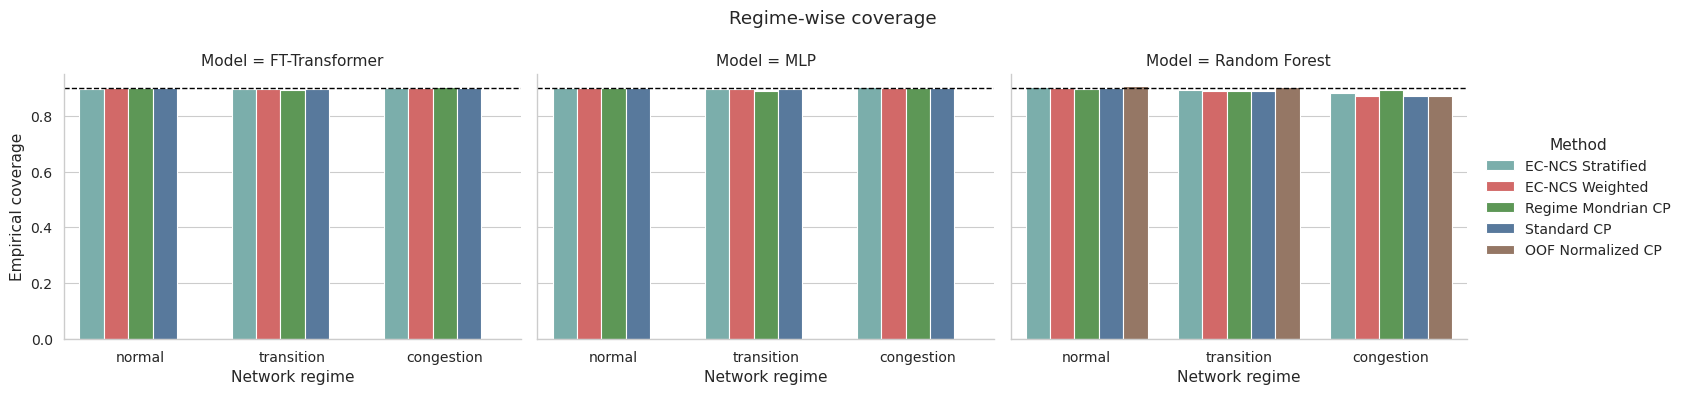

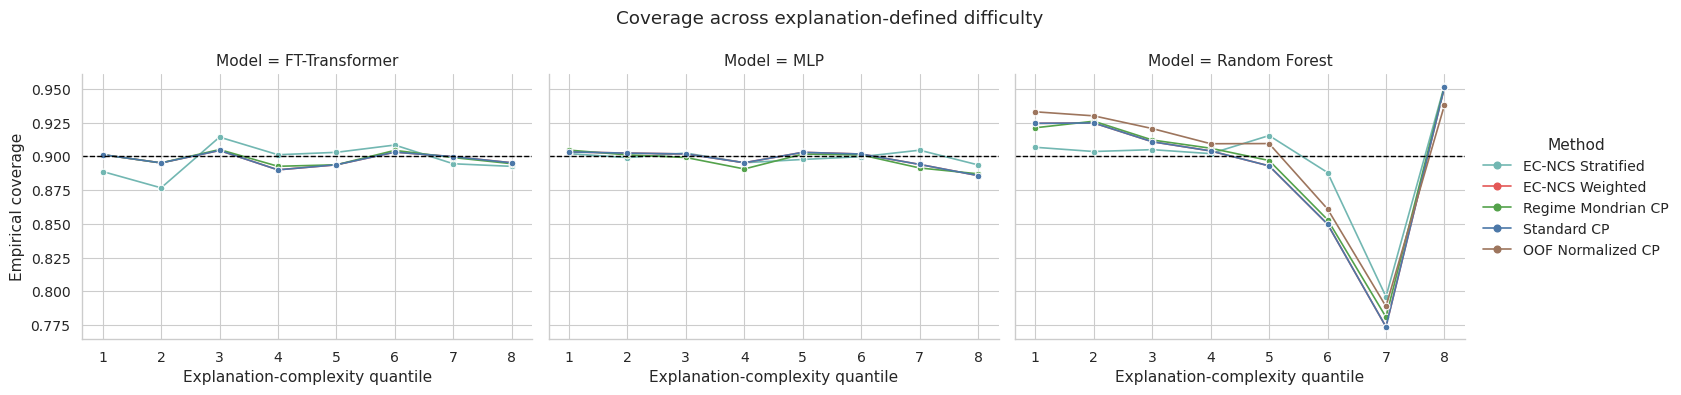

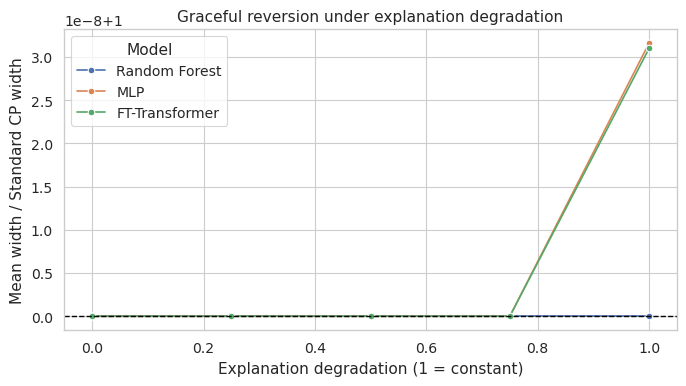

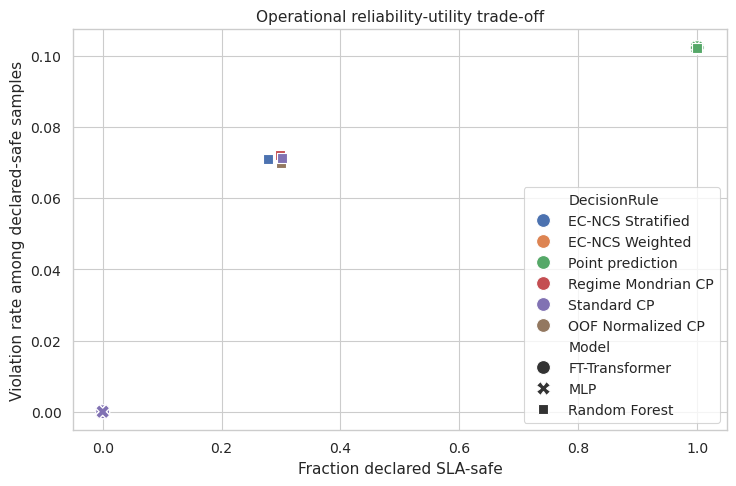

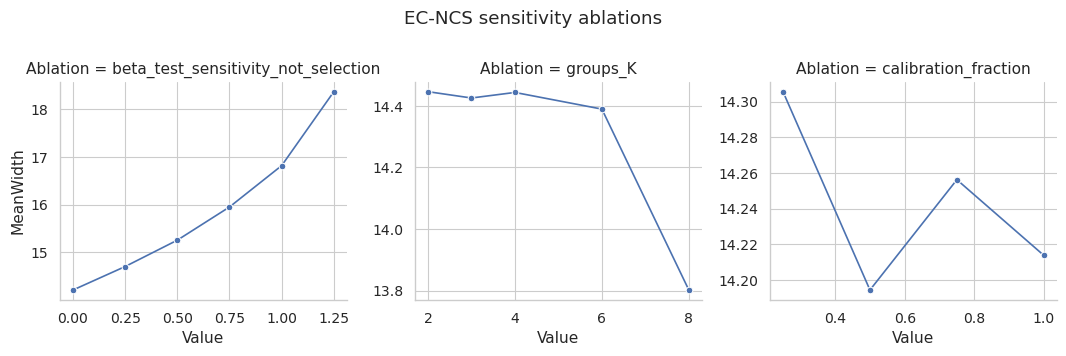

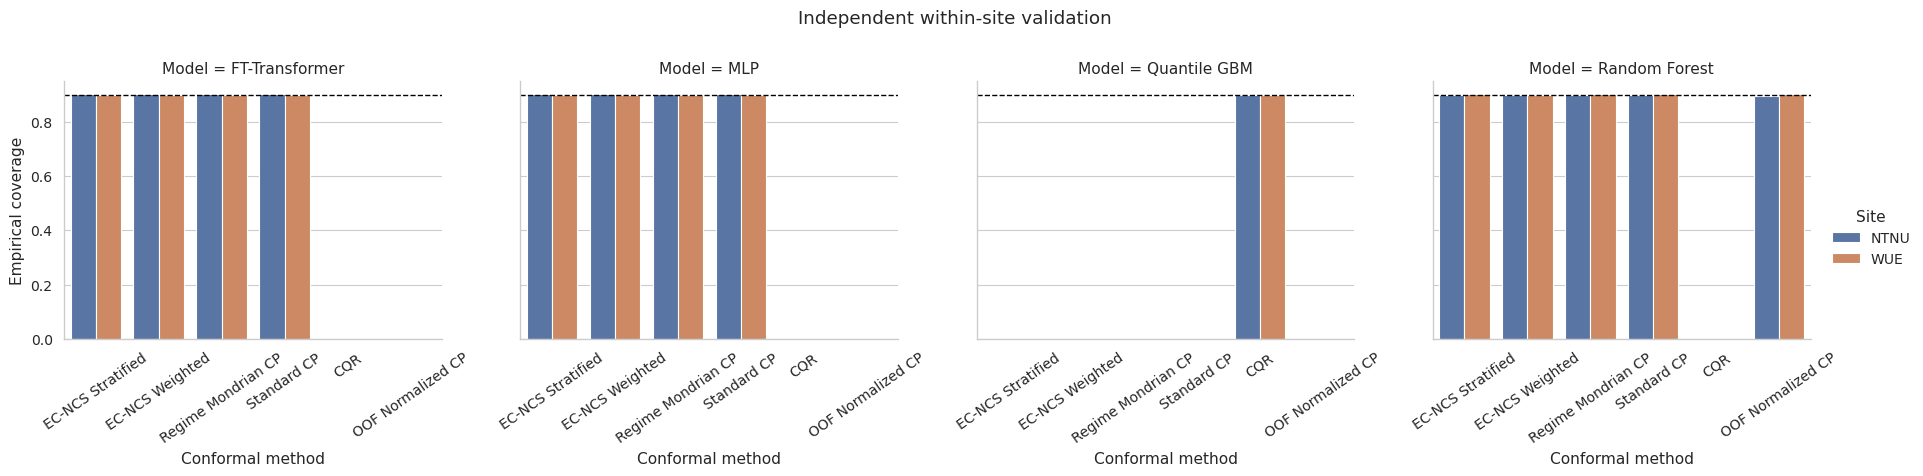

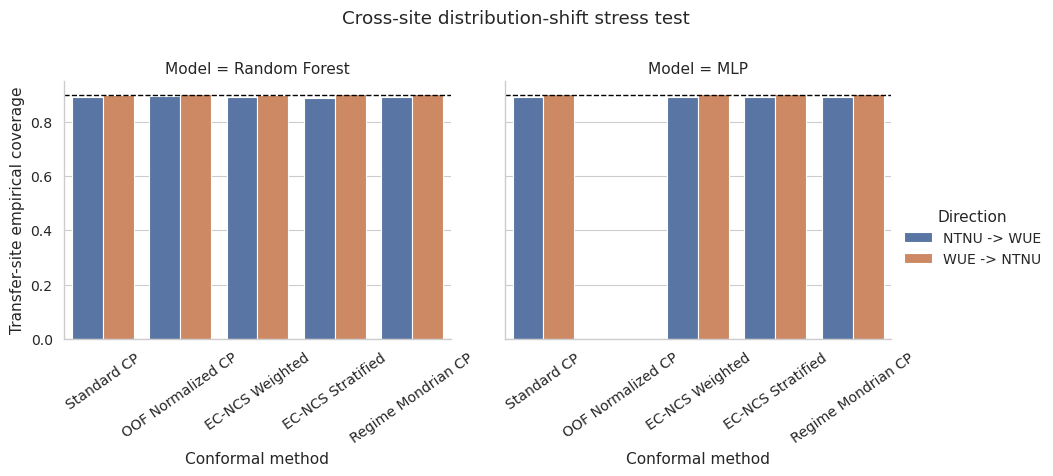

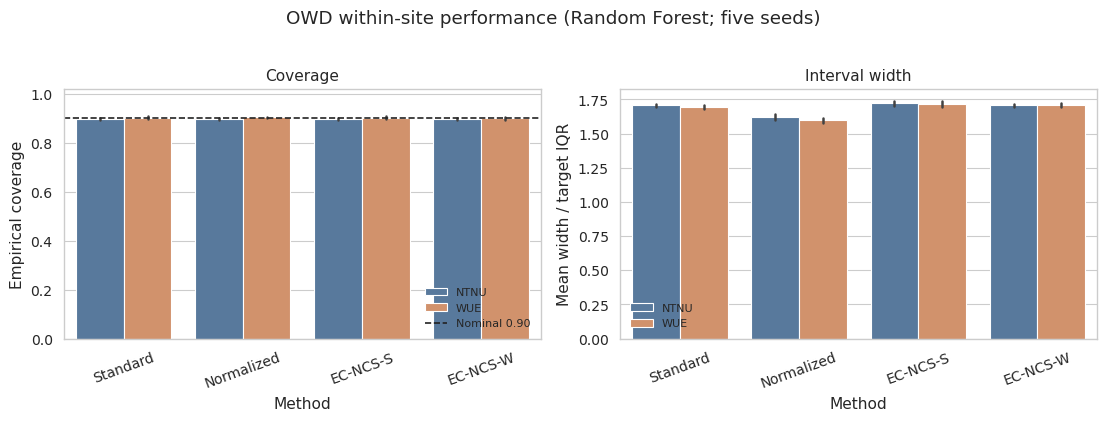

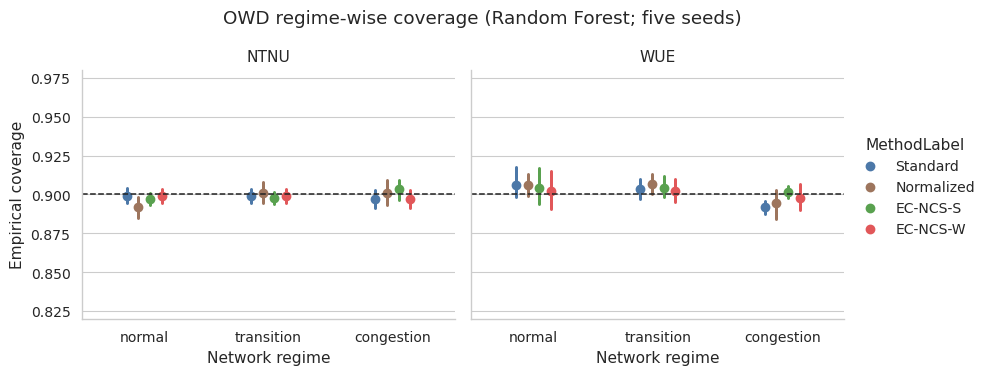

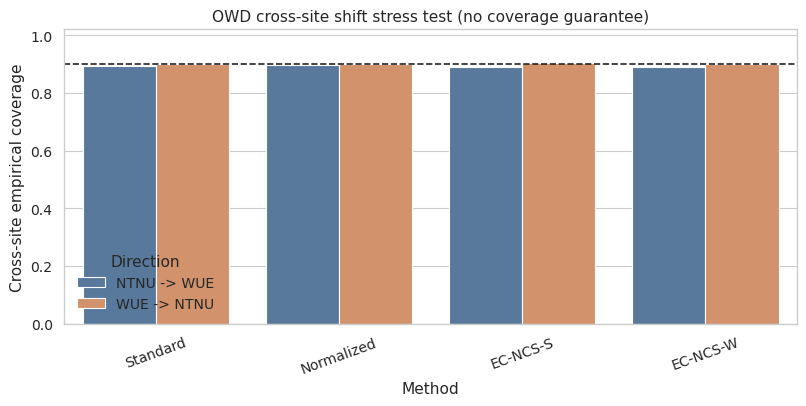

Results archive: /content/ec_ncs_tmlcn_final_results.zip


,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,Winkler,CorrPhiWidth
0,FT-Transformer,EC-NCS Stratified,0.897404,NaN,15.315623,NaN,16.193597,0.188887
1,FT-Transformer,EC-NCS Weighted,0.897816,NaN,15.312516,NaN,16.186737,0.000000
2,FT-Transformer,Regime Mondrian CP,0.898228,NaN,15.319687,NaN,16.187080,0.108717
3,FT-Transformer,Standard CP,0.897816,NaN,15.312516,NaN,16.186737,-0.000258
4,MLP,EC-NCS Stratified,0.899300,NaN,15.320294,NaN,16.197535,0.383275
5,MLP,EC-NCS Weighted,0.898393,NaN,15.315511,NaN,16.199169,0.000000
6,MLP,Regime Mondrian CP,0.897075,NaN,15.307308,NaN,16.200946,0.048951
7,MLP,Standard CP,0.898393,NaN,15.315512,NaN,16.199169,-0.005959
8,Random Forest,EC-NCS Stratified,0.896086,NaN,14.403859,NaN,16.516600,0.790926
9,Random Forest,EC-NCS Weighted,0.891389,NaN,14.213778,NaN,16.614238,0.000000


,Model,Method,Regime,Coverage,MeanWidth,Undercoverage,N
0,FT-Transformer,EC-NCS Stratified,congestion,0.900782,15.325023,0.000000,2429.0
1,FT-Transformer,EC-NCS Stratified,normal,0.896907,15.316241,0.003093,6305.0
2,FT-Transformer,EC-NCS Stratified,transition,0.895913,15.307765,0.004087,3401.0
3,FT-Transformer,EC-NCS Weighted,congestion,0.899135,15.312516,0.000865,2429.0
4,FT-Transformer,EC-NCS Weighted,normal,0.898176,15.312516,0.001824,6305.0
5,FT-Transformer,EC-NCS Weighted,transition,0.896207,15.312516,0.003793,3401.0
6,FT-Transformer,Regime Mondrian CP,congestion,0.902429,15.365952,0.000000,2429.0
7,FT-Transformer,Regime Mondrian CP,normal,0.898810,15.320420,0.001190,6305.0
8,FT-Transformer,Regime Mondrian CP,transition,0.894149,15.285285,0.005851,3401.0
9,FT-Transformer,Standard CP,congestion,0.899135,15.312516,0.000865,2429.0


,Model,Seed,TrainSeconds,BetaTuningSeconds,SelectedBeta,NormalizedCPOOFResidualMean,PredictionSeconds,PredictionMsPerSample,ExplanationCalibrationSeconds,ExplanationTrainingReferenceSeconds,ExplanationTrainingReferenceN,ExplanationTestSeconds,ExplanationMsPerTestSample,ConformalizationSeconds,EndToEndTestMsPerSample,TrainMemoryDeltaMB,PredictionMemoryDeltaMB,ExplanationMemoryDeltaMB
0,FT-Transformer,11.0,5.967653,5.894158,0.0,NaN,0.050874,0.004192,1.302709,0.554478,5000.0,1.305327,0.107567,0.011022,0.112668,0.007812,0.000000,0.000000
1,MLP,11.0,1.061165,1.339254,0.0,NaN,0.009577,0.000789,0.793681,0.348452,5000.0,0.805247,0.066357,0.021716,0.068936,0.000000,0.000000,0.000000
2,Random Forest,11.0,14.799472,11.014494,0.0,3.60093,0.731413,0.060273,2.039275,1.314315,5000.0,1.799324,0.148276,36.828073,3.243412,77.886719,0.015625,198.667969


,Site,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,NormalizedMeanWidth,MAE,R2
0,NTNU,FT-Transformer,EC-NCS Stratified,0.901949,0.007942,15.323639,0.071374,1.815728,4.227553,-0.000607
1,NTNU,FT-Transformer,EC-NCS Weighted,0.902018,0.007450,15.327580,0.067131,1.816195,4.227553,-0.000607
2,NTNU,FT-Transformer,Regime Mondrian CP,0.901751,0.007152,15.327344,0.061204,1.816167,4.227553,-0.000607
3,NTNU,FT-Transformer,Standard CP,0.902018,0.007450,15.327580,0.067131,1.816195,4.227553,-0.000607
4,NTNU,MLP,EC-NCS Stratified,0.902154,0.006754,15.324178,0.052551,1.815792,4.229157,-0.002185
5,NTNU,MLP,EC-NCS Weighted,0.901928,0.008073,15.309566,0.043339,1.814061,4.229157,-0.002185
6,NTNU,MLP,Regime Mondrian CP,0.902057,0.007505,15.323826,0.049019,1.815750,4.229157,-0.002185
7,NTNU,MLP,Standard CP,0.901928,0.008073,15.309566,0.043339,1.814061,4.229157,-0.002185
8,NTNU,Quantile GBM,CQR,0.900731,0.005342,13.072295,0.206485,1.548962,NaN,NaN
9,NTNU,Random Forest,EC-NCS Stratified,0.898616,0.004034,14.519336,0.182806,1.720425,3.610992,0.176209


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.896633,0.003367,13.495921,0.074096,13.950284,14.485656,16.323148,15.695926,-0.312055
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499342
4,NTNU,WUE,Random Forest,Regime Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.142964
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Regime Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


In [ ]:
import ast
from pathlib import Path

script_path = Path("/content/EC_NCS_TMLCN_Final_Standalone.py")
script_text = script_path.read_text()
syntax_tree = ast.parse(script_text)

# Load only the corrected trainer and checkpoint-aware within-site function
objects_to_reload = {
    "TorchRegressor",
    "run_within_site_validation",
}

for node in syntax_tree.body:
    if (
        isinstance(node, (ast.ClassDef, ast.FunctionDef))
        and node.name in objects_to_reload
    ):
        object_source = ast.get_source_segment(script_text, node)
        exec(compile(object_source, str(script_path), "exec"), globals())

print("Corrected training and resume functions loaded.")

# Continue from the within-site experiment
continuation_marker = (
    "within_site_df, within_regime_df = "
    "run_within_site_validation(clean_df, feature_columns)"
)

if continuation_marker not in script_text:
    raise RuntimeError("Could not locate the continuation point.")

remaining_code = continuation_marker + script_text.split(
    continuation_marker, 1
)[1]

exec(
    compile(
        remaining_code,
        str(script_path) + "::checkpoint_recovery",
        "exec",
    ),
    globals(),
)

Device: cuda
GPU: Tesla T4
Config(record_id='13754300', sites=('wue', 'ntnu'), target_col='trel', max_rows_per_site=30000, csv_chunk_size=200000, nominal_coverage=0.9, train_fraction=0.6, calibration_fraction=0.2, test_fraction=0.2, pooled_diagnostic_seeds=(11,), rf_trees=200, rf_min_leaf=2, mlp_epochs=50, mlp_batch_size=512, mlp_patience=7, explanation_batch_size=256, gradient_shap_samples=4, max_explanation_train_rows=5000, tree_shap_approximate=True, beta_grid=(0.0, 0.25, 0.5, 0.75, 1.0, 1.25), beta_inner_fit_fraction=0.6, beta_inner_calibration_fraction=0.2, beta_inner_max_rows_per_split=2000, beta_coverage_tolerance=0.01, beta_worst_bin_tolerance=0.03, normalized_cp_oof_folds=3, oof_normalized_models=('Random Forest',), ec_weight_min=0.35, ec_weight_max=3.0, explanation_groups=4, minimum_group_calibration=50, regime_minimum_calibration=50, outdir='/content/ec_ncs_tmlcn_corrected_results', data_dir='/content/ec_ncs_data', force_download=False, smoke_test=False, run_cross_site_trans

,Site,File,RowsScanned,RowsSampled,SamplingSeed,ChunkSize,SamplingFraction
0,WUE,wue_owd_Packets_with_IATs.csv,11958804,30000,2027,200000,0.002509
1,NTNU,ntnu_owd_Packets_with_IATs.csv,12678732,30000,2028,200000,0.002366


,SampledRows
DatasetSite,
NTNU,30000
WUE,30000


,Unnamed: 0,src,Timestamp,SourceIPOuter,DestinationIPOuter,SourceIPInner,DestinationIPInner,PacketSize,SeqNum,iat,...,slots,ratio,pdist,piat,psize,pnpak,rep,scenario,direction,DatasetSite
0,2469640,2gnb,1.720850e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.6,93,4940,0.000000e+00,...,10,2,det,1700,small,10000,3,oai_b200_40mhz_10slots_ratio2_det_01700_small_...,downlink,WUE
1,9720279,1ue,1.720864e+09,NaN,NaN,10.46.5.89,10.46.0.1,34,631,1.701832e-03,...,20,1,det,1700,small,10000,1,srs_b200_40mhz_20slots_ratio1_det_01700_small_...,uplink,WUE
2,4579420,1ue,1.720847e+09,NaN,NaN,10.46.0.1,10.46.4.235,35,9925,2.384186e-07,...,5,2,exp,1700,small,10000,1,oai_b200_40mhz_5slots_ratio2_exp_01700_small_1...,downlink,WUE
3,7437609,2gnb,1.720885e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.182,93,9176,0.000000e+00,...,20,4,exp,1700,small,10000,5,srs_b200_20mhz_20slots_ratio4_exp_01700_small_...,downlink,WUE
4,3056164,1ue,1.720929e+09,NaN,NaN,10.46.0.1,10.46.6.228,35,8233,2.479553e-05,...,10,4,exp,1700,small,10000,14,oai_b200_40mhz_10slots_ratio4_exp_01700_small_...,downlink,WUE


Unnamed: 0              int64
src                    object
Timestamp             float64
SourceIPOuter          object
DestinationIPOuter     object
SourceIPInner          object
DestinationIPInner     object
PacketSize              int64
SeqNum                  int64
iat                   float64
trel                  float64
gnb                    object
sdr                    object
bw                      int64
slots                   int64
ratio                   int64
pdist                  object
piat                    int64
psize                  object
pnpak                   int64
rep                     int64
scenario               object
direction              object
DatasetSite            object
dtype: object


...

Within-site NTNU, seed 11: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Within-site checkpoint saved: NTNU, seed=11, model=Random Forest
Within-site NTNU, seed 11: MLP
Within-site checkpoint saved: NTNU, seed=11, model=MLP
Within-site NTNU, seed 11: FT-Transformer
Within-site checkpoint saved: NTNU, seed=11, model=FT-Transformer
Within-site NTNU, seed 22: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Within-site checkpoint saved: NTNU, seed=22, model=Random Forest
Within-site NTNU, seed 22: MLP
Within-site checkpoint saved: NTNU, seed=22, model=MLP
Within-site NTNU, seed 22: FT-Transformer
Within-site checkpoint saved: NTNU, seed=22, model=FT-Transformer
Within-site NTNU, seed 33: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: 

,Site,Seed,SplitStrategy,Model,Method,SelectedBeta,N,MAE,RMSE,R2,...,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth,TargetIQR,NormalizedMeanWidth
0,NTNU,11,group-disjoint,Random Forest,Standard CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
1,NTNU,11,group-disjoint,Random Forest,OOF Normalized CP,0.0,6092,3.596853,4.430953,0.175619,...,0.008831,13.573745,0.073672,14.772477,14.725655,16.974374,15.978434,-0.296820,8.439391,1.608380
2,NTNU,11,group-disjoint,Random Forest,EC-NCS Weighted,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
3,NTNU,11,group-disjoint,Random Forest,EC-NCS Stratified,0.0,6092,3.596853,4.430953,0.175619,...,0.001280,14.497744,0.068976,14.683369,14.415522,15.391539,16.627560,0.510336,8.439391,1.717866
4,NTNU,11,group-disjoint,Random Forest,Traffic-index Mondrian CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.523274,0.068855,14.909480,14.525237,14.953977,16.730869,0.040832,8.439391,1.720891
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,WUE,11,group-disjoint,Quantile GBM,CQR,NaN,5991,NaN,NaN,NaN,...,0.004991,12.519687,0.079874,13.144522,13.826364,13.907792,13.228384,0.000000,8.525076,1.468572
136,WUE,22,group-disjoint,Quantile GBM,CQR,NaN,6151,NaN,NaN,NaN,...,0.000000,13.313014,0.075114,15.133245,13.853153,13.951138,13.899395,0.000000,8.525076,1.561630
137,WUE,33,group-disjoint,Quantile GBM,CQR,NaN,6024,NaN,NaN,NaN,...,0.000000,13.257790,0.075427,13.288602,13.827315,13.849457,13.976359,0.000000,8.525076,1.555152
138,WUE,44,group-disjoint,Quantile GBM,CQR,NaN,5992,NaN,NaN,NaN,...,0.003805,13.219570,0.075645,13.722584,13.765768,13.805635,13.976431,0.000000,8.525076,1.550669


Transfer NTNU -> WUE: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: NTNU->WUE, model=Random Forest
Transfer NTNU -> WUE: MLP
Transfer checkpoint saved: NTNU->WUE, model=MLP
Transfer WUE -> NTNU: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: WUE->NTNU, model=Random Forest
Transfer WUE -> NTNU: MLP
Transfer checkpoint saved: WUE->NTNU, model=MLP


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.897067,0.002933,13.485456,0.074154,13.881030,14.479856,16.308204,15.687312,-0.312775
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499659
4,NTNU,WUE,Random Forest,Traffic-index Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.136848
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Traffic-index Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


,Site,Model,Reference,Method,Metric,MeanPairedDifference,WilcoxonP,Seeds,HolmAdjustedP
0,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,CoverageError,2.594577e-04,0.6250,5,1.0
1,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,MeanWidth,-3.941085e-03,0.3125,5,1.0
2,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,Winkler,4.340907e-03,0.0625,5,1.0
3,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,CoverageError,0.000000e+00,1.0000,5,1.0
4,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,MeanWidth,-9.707521e-08,0.6250,5,1.0
5,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,Winkler,-1.513093e-08,0.1875,5,1.0
6,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,CoverageError,-7.135009e-04,0.3125,5,1.0
7,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,MeanWidth,-2.355410e-04,1.0000,5,1.0
8,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,Winkler,2.938624e-03,0.3125,5,1.0
9,NTNU,MLP,Standard CP,EC-NCS Stratified,CoverageError,-9.556360e-04,0.1875,5,1.0


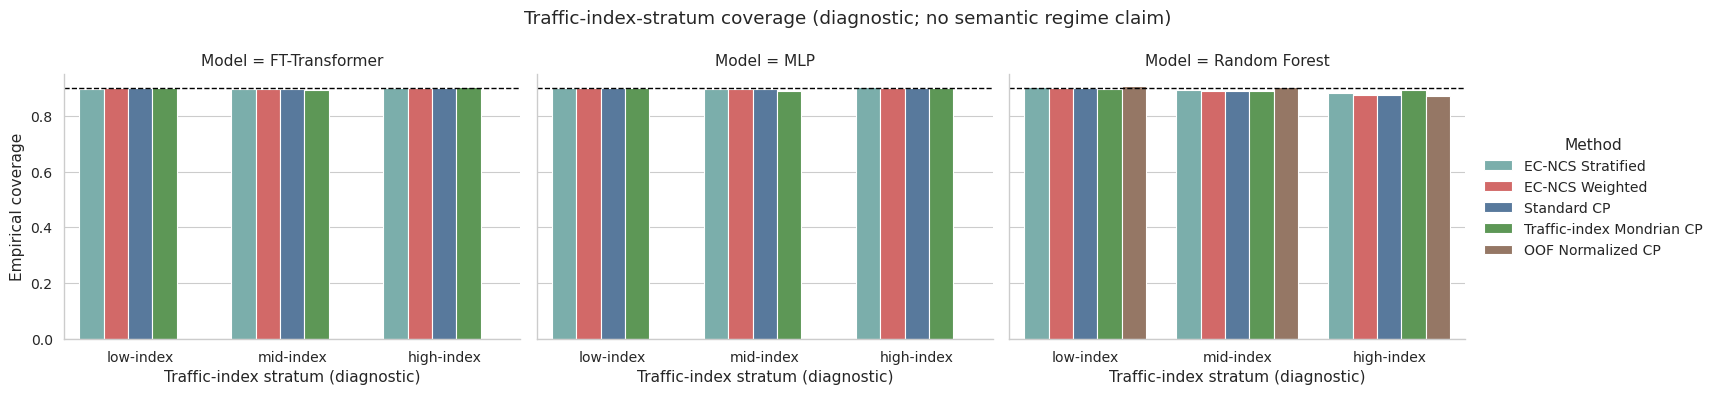

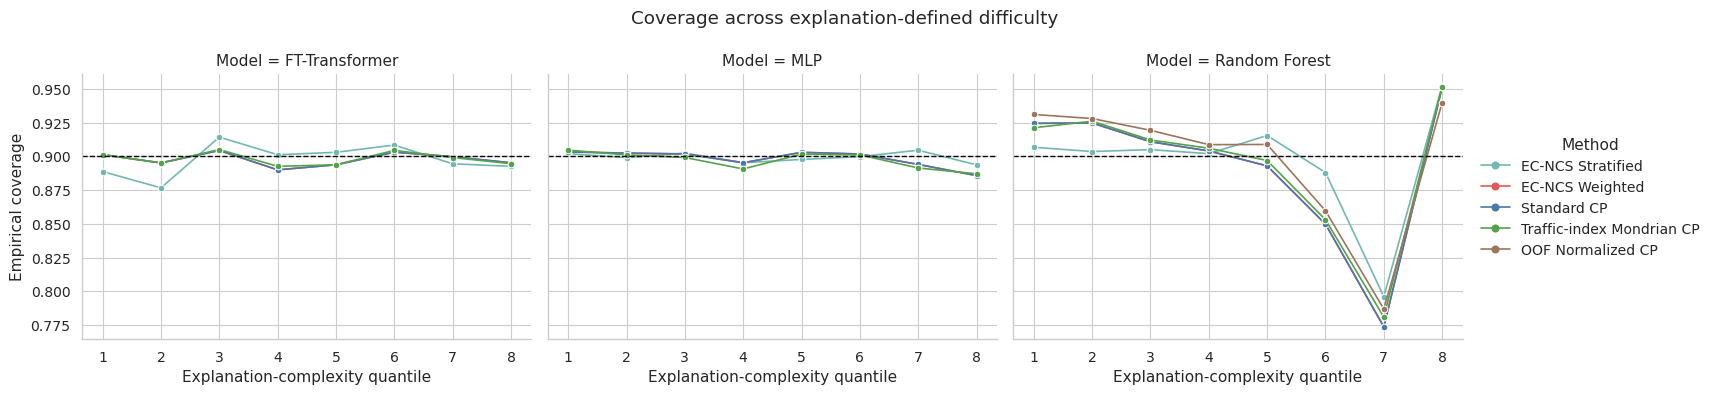

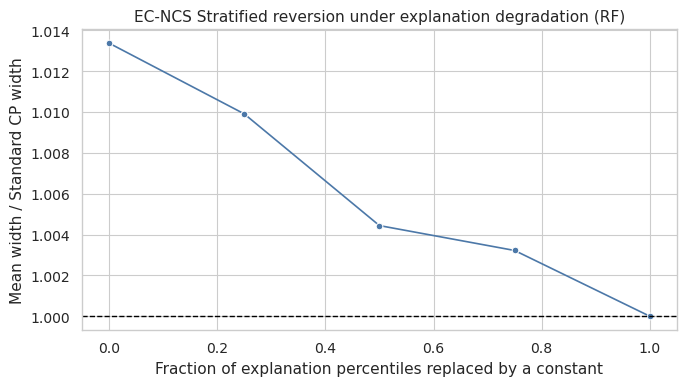

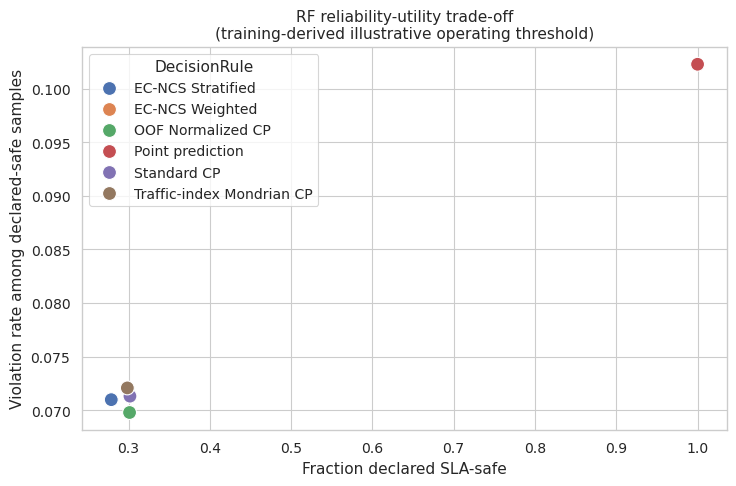

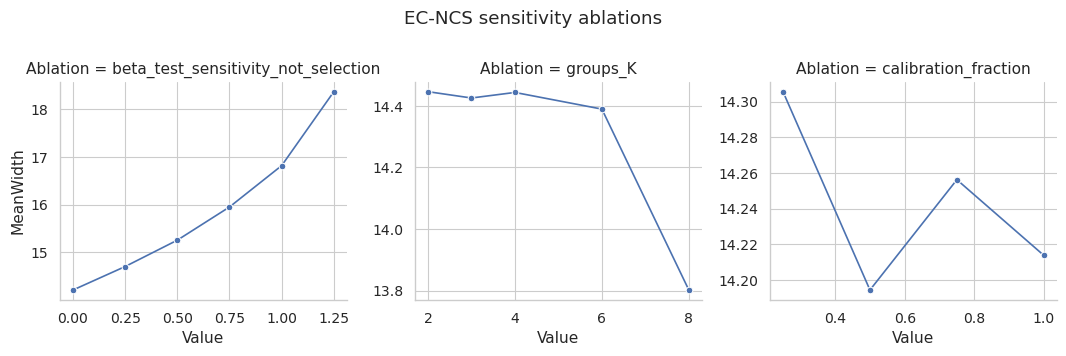

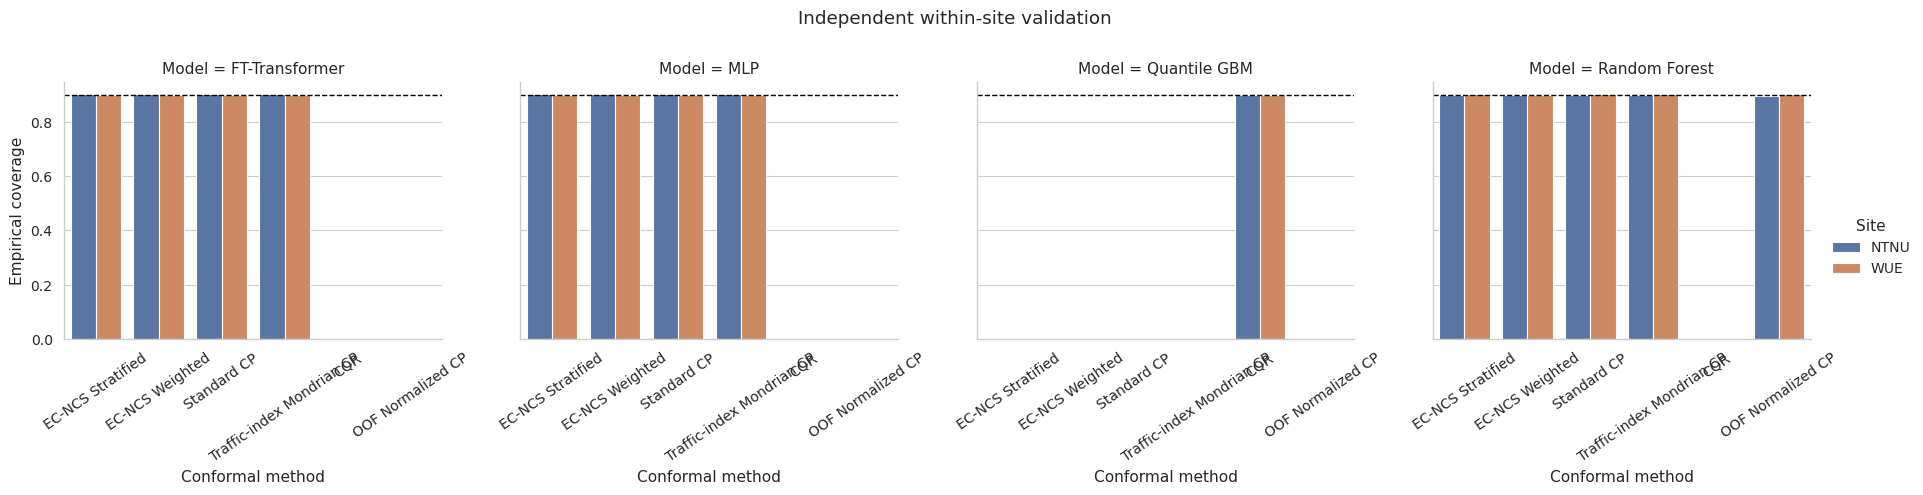

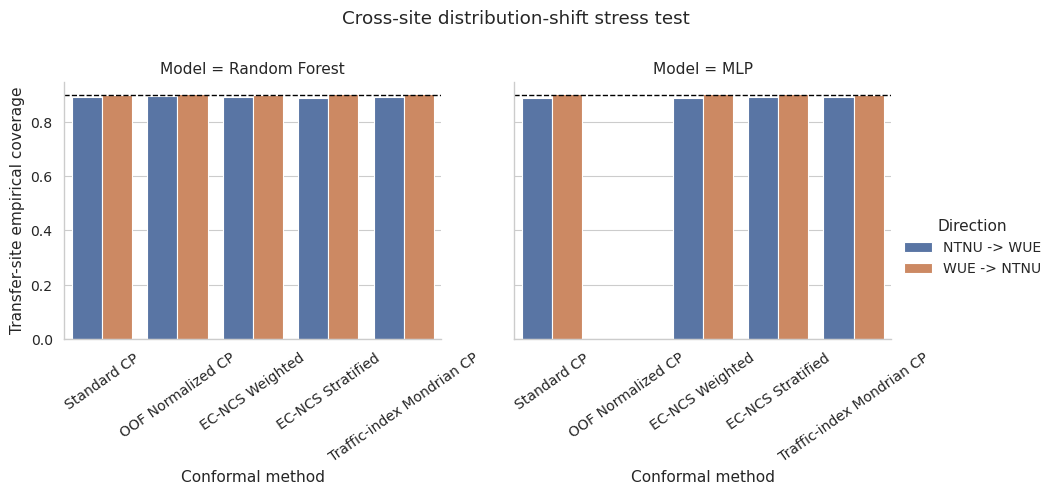

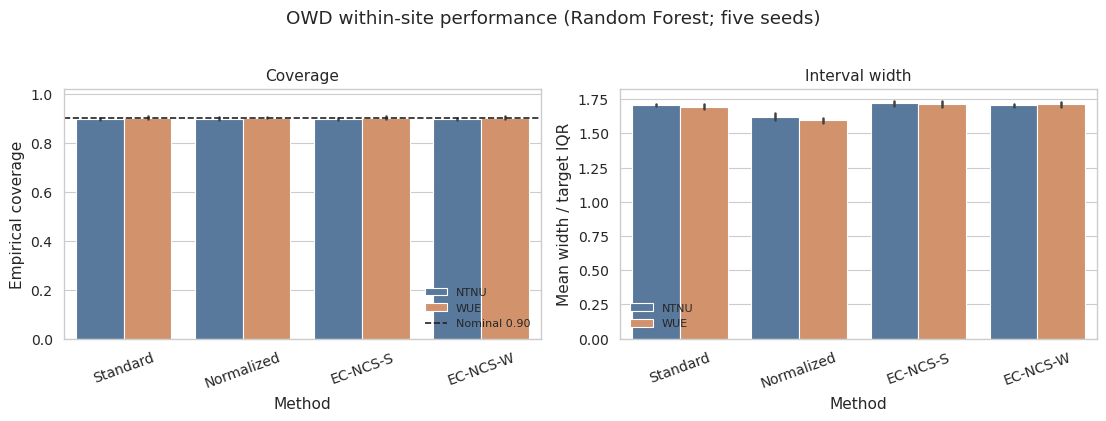

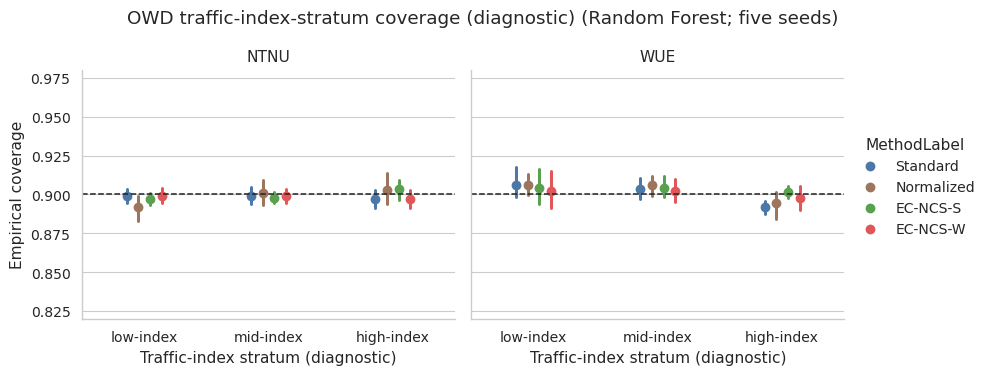

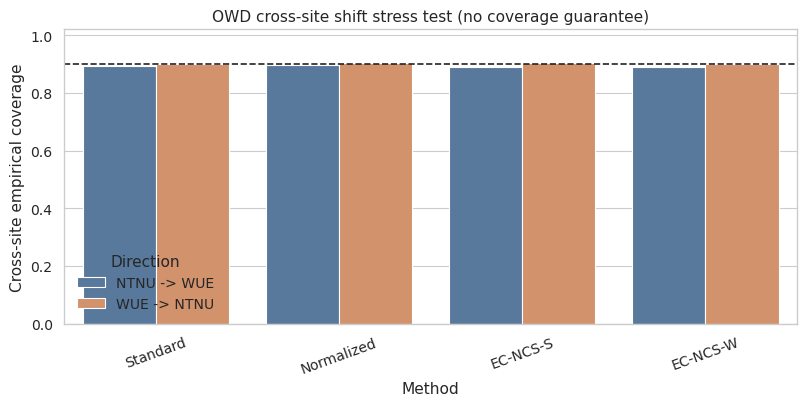

Results archive: /content/ec_ncs_tmlcn_corrected_results.zip


,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,Winkler,CorrPhiWidth
0,FT-Transformer,EC-NCS Stratified,0.897404,NaN,15.315623,NaN,16.193597,0.188887
1,FT-Transformer,EC-NCS Weighted,0.897816,NaN,15.312516,NaN,16.186737,0.000000
2,FT-Transformer,Standard CP,0.897816,NaN,15.312516,NaN,16.186737,-0.000258
3,FT-Transformer,Traffic-index Mondrian CP,0.898228,NaN,15.319687,NaN,16.187080,0.108717
4,MLP,EC-NCS Stratified,0.899300,NaN,15.320294,NaN,16.197535,0.383275
5,MLP,EC-NCS Weighted,0.898393,NaN,15.315511,NaN,16.199169,0.000000
6,MLP,Standard CP,0.898393,NaN,15.315512,NaN,16.199169,-0.005959
7,MLP,Traffic-index Mondrian CP,0.897075,NaN,15.307308,NaN,16.200946,0.048951
8,Random Forest,EC-NCS Stratified,0.896086,NaN,14.403859,NaN,16.516600,0.794803
9,Random Forest,EC-NCS Weighted,0.891389,NaN,14.213778,NaN,16.614238,0.000000


,Model,Method,Regime,Coverage,MeanWidth,Undercoverage,N
0,FT-Transformer,EC-NCS Stratified,high-index,0.900782,15.325023,0.000000,2429.0
1,FT-Transformer,EC-NCS Stratified,low-index,0.896907,15.316241,0.003093,6305.0
2,FT-Transformer,EC-NCS Stratified,mid-index,0.895913,15.307765,0.004087,3401.0
3,FT-Transformer,EC-NCS Weighted,high-index,0.899135,15.312516,0.000865,2429.0
4,FT-Transformer,EC-NCS Weighted,low-index,0.898176,15.312516,0.001824,6305.0
5,FT-Transformer,EC-NCS Weighted,mid-index,0.896207,15.312516,0.003793,3401.0
6,FT-Transformer,Standard CP,high-index,0.899135,15.312516,0.000865,2429.0
7,FT-Transformer,Standard CP,low-index,0.898176,15.312516,0.001824,6305.0
8,FT-Transformer,Standard CP,mid-index,0.896207,15.312516,0.003793,3401.0
9,FT-Transformer,Traffic-index Mondrian CP,high-index,0.902429,15.365952,0.000000,2429.0


,Model,Seed,TrainSeconds,BetaTuningSeconds,SelectedBeta,NormalizedCPOOFResidualMean,PredictionSeconds,PredictionMsPerSample,ExplanationCalibrationSeconds,ExplanationTrainingReferenceSeconds,ExplanationTrainingReferenceN,ExplanationTestSeconds,ExplanationMsPerTestSample,ConformalizationSeconds,EndToEndTestMsPerSample,TrainMemoryDeltaMB,PredictionMemoryDeltaMB,ExplanationMemoryDeltaMB
0,FT-Transformer,11.0,7.489560,4.190413,0.0,NaN,0.054442,0.004486,1.299843,0.535917,5000.0,1.289211,0.106239,0.010398,0.111582,0.0,0.0,0.000000
1,MLP,11.0,1.044595,1.357522,0.0,NaN,0.009444,0.000778,0.820490,0.337477,5000.0,0.851430,0.070163,0.012928,0.072007,0.0,0.0,0.000000
2,Random Forest,11.0,16.292010,9.184485,0.0,3.60093,0.469861,0.038719,1.688634,0.836382,5000.0,1.990557,0.164034,38.933681,3.411133,29.5,0.0,178.722656


,Site,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,NormalizedMeanWidth,MAE,R2
0,NTNU,FT-Transformer,EC-NCS Stratified,0.901949,0.007942,15.323639,0.071374,1.815728,4.227553,-0.000607
1,NTNU,FT-Transformer,EC-NCS Weighted,0.902018,0.007450,15.327580,0.067131,1.816195,4.227553,-0.000607
2,NTNU,FT-Transformer,Standard CP,0.902018,0.007450,15.327580,0.067131,1.816195,4.227553,-0.000607
3,NTNU,FT-Transformer,Traffic-index Mondrian CP,0.901751,0.007152,15.327344,0.061204,1.816167,4.227553,-0.000607
4,NTNU,MLP,EC-NCS Stratified,0.902154,0.006754,15.324178,0.052551,1.815792,4.229157,-0.002185
5,NTNU,MLP,EC-NCS Weighted,0.901928,0.008073,15.309566,0.043339,1.814061,4.229157,-0.002185
6,NTNU,MLP,Standard CP,0.901928,0.008073,15.309566,0.043339,1.814061,4.229157,-0.002185
7,NTNU,MLP,Traffic-index Mondrian CP,0.902057,0.007505,15.323826,0.049019,1.815750,4.229157,-0.002185
8,NTNU,Quantile GBM,CQR,0.900731,0.005342,13.072295,0.206485,1.548962,NaN,NaN
9,NTNU,Random Forest,EC-NCS Stratified,0.898616,0.004034,14.519336,0.182806,1.720425,3.610992,0.176209


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.897067,0.002933,13.485456,0.074154,13.881030,14.479856,16.308204,15.687312,-0.312775
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499659
4,NTNU,WUE,Random Forest,Traffic-index Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.136848
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Traffic-index Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


In [ ]:

# Colab-ready dependency bootstrap. Safe to rerun.
import importlib.util
import subprocess
import sys

_required = {
    "shap": "shap>=0.46",
    "captum": "captum>=0.7",
    "openpyxl": "openpyxl>=3.1",
    "pyarrow": "pyarrow>=15",
    "psutil": "psutil>=5.9",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# %%
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
from urllib.parse import quote
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import requests
import seaborn as sns
import shap
import torch
import torch.nn as nn
from captum.attr import GradientShap
from scipy.stats import spearmanr, wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


@dataclass
class Config:
    record_id: str = "13754300"
    sites: Tuple[str, ...] = ("wue", "ntnu")
    target_col: str = "trel"
    max_rows_per_site: int = 30_000
    csv_chunk_size: int = 200_000
    nominal_coverage: float = 0.90
    train_fraction: float = 0.60
    calibration_fraction: float = 0.20
    test_fraction: float = 0.20
    pooled_diagnostic_seeds: Tuple[int, ...] = (11,)
    rf_trees: int = 200
    rf_min_leaf: int = 2
    mlp_epochs: int = 50
    mlp_batch_size: int = 512
    mlp_patience: int = 7
    explanation_batch_size: int = 256
    gradient_shap_samples: int = 4
    max_explanation_train_rows: int = 5_000
    tree_shap_approximate: bool = True
    beta_grid: Tuple[float, ...] = (0.0, 0.25, 0.50, 0.75, 1.00, 1.25)
    beta_inner_fit_fraction: float = 0.60
    beta_inner_calibration_fraction: float = 0.20
    beta_inner_max_rows_per_split: int = 2_000
    beta_coverage_tolerance: float = 0.01
    beta_worst_bin_tolerance: float = 0.03
    normalized_cp_oof_folds: int = 3
    oof_normalized_models: Tuple[str, ...] = ("Random Forest",)
    ec_weight_min: float = 0.35
    ec_weight_max: float = 3.00
    explanation_groups: int = 4
    minimum_group_calibration: int = 50
    regime_minimum_calibration: int = 50
    # New directory prevents incompatible checkpoints from the earlier
    # semantic-regime/weighted-degradation run from being reused.
    outdir: str = "/content/ec_ncs_tmlcn_corrected_results"
    data_dir: str = "/content/ec_ncs_data"
    force_download: bool = False
    smoke_test: bool = False          # True uses synthetic data and runs quickly
    run_cross_site_transfer: bool = True
    cross_site_models: Tuple[str, ...] = ("Random Forest", "MLP")
    cross_site_seed: int = 2027  # retained for the single fixed transfer diagnostic
    run_within_site_validation: bool = True
    within_site_models: Tuple[str, ...] = ("Random Forest", "MLP", "FT-Transformer")
    within_site_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55)
    explicit_scenario_regime_map: Optional[Dict[str, str]] = None
    require_explicit_regime_map: bool = False
    sla_threshold: Optional[float] = None  # replace with a domain-supported delay threshold

CFG = Config()
ALPHA = 1.0 - CFG.nominal_coverage

# Semantic regime names are used only when every scenario has been mapped by
# networking-domain review.  Otherwise the code reports train-fitted,
# observable-feature traffic-index strata and never calls them congestion
# regimes.
HAS_EXPERT_REGIME_MAP = CFG.explicit_scenario_regime_map is not None
REGIME_ORDER = (["normal", "transition", "congestion"] if HAS_EXPERT_REGIME_MAP
                else ["low-index", "mid-index", "high-index"])
REGIME_AXIS_LABEL = ("Network regime" if HAS_EXPERT_REGIME_MAP
                     else "Traffic-index stratum (diagnostic)")
REGIME_FIGURE_TITLE = ("OWD regime-wise coverage" if HAS_EXPERT_REGIME_MAP
                       else "OWD traffic-index-stratum coverage (diagnostic)")
REGIME_CP_NAME = ("Regime Mondrian CP" if HAS_EXPERT_REGIME_MAP
                  else "Traffic-index Mondrian CP")
OUTDIR = Path(CFG.outdir)
DATA_DIR = Path(CFG.data_dir)
OUTDIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
MAIN_FIG_DIR = OUTDIR / "main_paper_figures"
SUPP_DIR = OUTDIR / "supplementary"
CHECKPOINT_DIR = OUTDIR / "checkpoints"
for _directory in (MAIN_FIG_DIR, SUPP_DIR, CHECKPOINT_DIR):
    _directory.mkdir(parents=True, exist_ok=True)
print(CFG)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conformal_quantile(scores: Sequence[float], alpha: float) -> float:
    """Finite-sample split-conformal quantile using the higher order statistic."""
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    if scores.size == 0:
        raise ValueError("No finite calibration scores.")
    level = min(1.0, np.ceil((scores.size + 1) * (1.0 - alpha)) / scores.size)
    return float(np.quantile(scores, level, method="higher"))


class TrainECDF:
    """Pointwise rank transform fitted only on training explanations."""
    def fit(self, values: Sequence[float]):
        self.sorted_ = np.sort(np.asarray(values, dtype=float))
        return self

    def transform(self, values: Sequence[float]) -> np.ndarray:
        values = np.asarray(values, dtype=float)
        return np.searchsorted(self.sorted_, values, side="right") / max(len(self.sorted_), 1)


def bootstrap_ci(values: Sequence[float], fn=np.mean, seed: int = 0,
                 n_boot: int = 500, level: float = 0.95) -> Tuple[float, float]:
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    draws = [fn(values[rng.integers(0, len(values), len(values))]) for _ in range(n_boot)]
    tail = (1.0 - level) / 2.0
    return tuple(np.quantile(draws, [tail, 1.0 - tail]))


def interval_metrics(y: np.ndarray, lo: np.ndarray, hi: np.ndarray,
                     alpha: float, phi: Optional[np.ndarray] = None) -> Dict[str, float]:
    y, lo, hi = map(lambda z: np.asarray(z, dtype=float), (y, lo, hi))
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    below = np.maximum(lo - y, 0.0)
    above = np.maximum(y - hi, 0.0)
    winkler = width + (2.0 / alpha) * (below + above)
    corr = 0.0
    if phi is not None and np.std(width) > 1e-12:
        corr = float(spearmanr(phi, width).correlation)
        if not np.isfinite(corr):
            corr = 0.0
    mean_width = float(width.mean())
    coverage = float(covered.mean())
    return {
        "Coverage": coverage,
        "Undercoverage": float(max(0.0, (1.0 - alpha) - coverage)),
        "MeanWidth": mean_width,
        "IntervalEfficiency": float(1.0 / max(mean_width, 1e-12)),
        "CoverageWidthCriterion": float(mean_width * (1.0 + 10.0 * abs(coverage - (1.0-alpha)))),
        "MedianWidth": float(np.median(width)),
        "P90Width": float(np.quantile(width, 0.90)),
        "Winkler": float(winkler.mean()),
        "CorrPhiWidth": corr,
    }


def timed_call(fn, *args, synchronize_gpu: bool = True, **kwargs):
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    mem_after = process.memory_info().rss
    return out, elapsed, max(0, mem_after - mem_before) / 2**20


def zenodo_metadata(record_id: str) -> Mapping:
    cache_path = DATA_DIR / f"zenodo_metadata_{record_id}.json"
    for attempt in range(6):
        try:
            response = requests.get(
                f"https://zenodo.org/api/records/{record_id}", timeout=180,
                headers={"User-Agent": "EC-NCS-research/1.0"},
            )
            response.raise_for_status()
            payload = response.json()
            cache_path.write_text(json.dumps(payload))
            return payload
        except requests.RequestException as error:
            if cache_path.exists():
                print(f"Zenodo API unavailable; using cached metadata: {error}")
                return json.loads(cache_path.read_text())
            if attempt < 5:
                wait = min(60, 5 * (2 ** attempt))
                print(f"Zenodo metadata attempt {attempt+1} failed; retrying in {wait}s")
                time.sleep(wait)
    print("Zenodo metadata unavailable; using documented OWD filenames.")
    return {"files": [
        {"key": "wue_owd_Packets_with_IATs.csv", "links": {}},
        {"key": "ntnu_owd_Packets_with_IATs.csv", "links": {}},
    ]}


def choose_owd_file(metadata: Mapping, site: str) -> Mapping:
    site = site.lower()
    files = metadata.get("files", [])
    ranked = []
    for item in files:
        name = item.get("key", "").lower()
        score = 0
        score += 8 if site in name else 0
        score += 8 if "owd" in name else 0
        score += 4 if "with_iats" in name else 0
        score -= 5 if "tput" in name else 0
        score += 2 if name.endswith(".csv") else 0
        ranked.append((score, item))
    ranked.sort(key=lambda z: z[0], reverse=True)
    if not ranked or ranked[0][0] < 12:
        available = [f.get("key") for f in files]
        raise FileNotFoundError(f"No suitable {site} OWD CSV. Available: {available}")
    return ranked[0][1]


def stream_download(item: Mapping, destination: Path, force: bool = False) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and not force:
        return destination
    file_name = item["key"]
    urls = []
    if item.get("links", {}).get("self"):
        urls.append(item["links"]["self"])
    urls.append(
        f"https://zenodo.org/records/{CFG.record_id}/files/{quote(file_name)}?download=1"
    )
    temporary = Path(str(destination) + ".part")
    last_error = None
    for url in urls:
        for attempt in range(5):
            try:
                headers = {}
                mode = "wb"
                if temporary.exists() and temporary.stat().st_size > 0:
                    headers["Range"] = f"bytes={temporary.stat().st_size}-"
                    mode = "ab"
                with requests.get(url, stream=True, timeout=300, headers=headers) as response:
                    if response.status_code == 200 and mode == "ab":
                        mode = "wb"  # server ignored Range; restart safely
                    response.raise_for_status()
                    with temporary.open(mode) as handle:
                        for chunk in response.iter_content(chunk_size=2**20):
                            if chunk:
                                handle.write(chunk)
                os.replace(temporary, destination)
                return destination
            except requests.RequestException as error:
                last_error = error
                wait = min(60, 5 * (2 ** attempt))
                print(f"Download attempt {attempt+1} failed for {file_name}; retrying in {wait}s")
                time.sleep(wait)
    raise RuntimeError(f"Could not download {file_name}: {last_error}")
    return destination


def synthetic_5g(n: int = 12_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    load = rng.uniform(0, 1, n)
    scenario = pd.cut(load, [-1, .35, .70, 2], labels=["normal", "transition", "congestion"])
    packet_size = rng.choice([128, 256, 512, 1024, 1500], n)
    iat = rng.lognormal(-2.0 + 1.2 * load, .35, n)
    ratio = rng.uniform(.1, 1.0, n)
    noise = rng.normal(0, .12 + .55 * load**2, n)
    trel = 0.15 + 1.1 * load + .00025 * packet_size + .15 * ratio + noise
    return pd.DataFrame({"PacketSize": packet_size, "iat": iat, "ratio": ratio,
                         "scenario": scenario.astype(str), "rep": rng.integers(0, 30, n),
                         "trel": trel})


def uniform_chunk_sample_csv(path: Path, sample_size: int, seed: int,
                             chunksize: int = 200_000) -> Tuple[pd.DataFrame, Dict[str, int]]:
    """Exact uniform random-key reservoir sample over every data row in a CSV.

    Independent continuous priorities give every row equal inclusion probability and avoid
    the ordered-prefix bias caused by pd.read_csv(..., nrows=sample_size).
    """
    rng = np.random.default_rng(seed)
    reservoir = None
    seen = 0
    for chunk_id, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False)):
        chunk.columns = chunk.columns.astype(str).str.strip()
        seen += len(chunk)
        chunk["__uniform_priority__"] = rng.random(len(chunk))
        candidates = chunk if reservoir is None else pd.concat([reservoir, chunk], ignore_index=True)
        reservoir = candidates.nsmallest(min(sample_size, len(candidates)), "__uniform_priority__")
        if (chunk_id + 1) % 10 == 0:
            print(f"  scanned {seen:,} rows from {path.name}")
    sampled = reservoir.drop(columns="__uniform_priority__").reset_index(drop=True)
    return sampled, {"RowsScanned": seen, "RowsSampled": len(sampled),
                     "SamplingSeed": seed, "ChunkSize": chunksize}


sampling_rows, selected_files = [], {}
site_frames = []
if CFG.smoke_test:
    for i, site in enumerate(CFG.sites):
        frame = synthetic_5g(seed=42+i)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": "synthetic smoke test",
                              "RowsScanned": len(frame), "RowsSampled": len(frame),
                              "SamplingSeed": 42+i, "ChunkSize": np.nan})
        selected_files[site] = "synthetic smoke test"
else:
    metadata = zenodo_metadata(CFG.record_id)
    for i, site in enumerate(CFG.sites):
        selected = choose_owd_file(metadata, site)
        selected_path = DATA_DIR / Path(selected["key"]).name
        selected_path = stream_download(selected, selected_path, CFG.force_download)
        print(f"Uniformly sampling the complete {site.upper()} file: {selected_path.name}")
        frame, audit = uniform_chunk_sample_csv(selected_path, CFG.max_rows_per_site,
                                                seed=2027+i, chunksize=CFG.csv_chunk_size)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": selected_path.name, **audit})
        selected_files[site] = str(selected_path)

raw_df = pd.concat(site_frames, ignore_index=True)
sampling_audit_df = pd.DataFrame(sampling_rows)
sampling_audit_df["SamplingFraction"] = sampling_audit_df.RowsSampled / sampling_audit_df.RowsScanned
sampling_audit_df.to_csv(OUTDIR / "sampling_audit.csv", index=False)
raw_df.columns = raw_df.columns.astype(str).str.strip()
print("Selected files:", selected_files)
print("Shape:", raw_df.shape)
display(sampling_audit_df)
display(raw_df.groupby("DatasetSite", observed=True).size().rename("SampledRows"))
display(raw_df.head())
print(raw_df.dtypes)


DROP_COLUMNS = {
    "Unnamed: 0", "src", "Timestamp", "SourceIPOuter", "DestinationIPOuter",
    "SourceIPInner", "DestinationIPInner", "SeqNum", "DatasetSite",
    # Retained in clean_df for splitting/auditing, but never supplied to a model.
    "scenario", "rep"
}


def audit_and_clean(df: pd.DataFrame, target_col: str):
    if target_col not in df.columns:
        raise ValueError(f"Target {target_col!r} missing. Available columns: {df.columns.tolist()}")
    work = df.copy()
    work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan).dropna(subset=[target_col]).drop_duplicates()
    candidate = [c for c in work.columns if c != target_col and c not in DROP_COLUMNS]
    audit_rows = []
    selected = []
    for col in work.columns:
        missing = float(work[col].isna().mean())
        nunique = int(work[col].nunique(dropna=True))
        reason = "included"
        include = col in candidate and missing <= .50 and nunique > 1
        if col == target_col: reason = "target"
        elif col in DROP_COLUMNS: reason = "identifier/sequence leakage risk"
        elif missing > .50: reason = ">50% missing"
        elif nunique <= 1: reason = "constant"
        elif include: selected.append(col)
        audit_rows.append({"Feature": col, "Dtype": str(work[col].dtype),
                           "MissingFraction": missing, "UniqueValues": nunique,
                           "Included": include, "Reason": reason})
    return work, selected, pd.DataFrame(audit_rows)


clean_df, feature_columns, feature_audit = audit_and_clean(raw_df, CFG.target_col)
feature_audit.to_csv(OUTDIR / "feature_audit.csv", index=False)
display(feature_audit)
print("Included features:", feature_columns)


def scenario_to_regime(values: pd.Series) -> Optional[pd.Series]:
    text = values.astype(str).str.lower()
    out = pd.Series(index=values.index, dtype="object")
    patterns = {
        "normal": r"normal|stable|baseline|idle|low",
        "transition": r"transition|medium|moderate|ramp|bursty",
        "congestion": r"congest|overload|heavy|high|stress"
    }
    for label, pattern in patterns.items():
        out[text.str.contains(pattern, regex=True, na=False)] = label
    return out if out.notna().mean() >= .70 else None


if "scenario" in clean_df.columns:
    scenario_inventory = (clean_df.groupby(["DatasetSite", "scenario"], observed=True)
                          .size().rename("N").reset_index())
    # Inventory only: the script must not manufacture semantic regimes from
    # filenames.  A networking expert can review this CSV and then populate
    # CFG.explicit_scenario_regime_map.
    scenario_inventory["SuggestedRegime"] = "REVIEW_REQUIRED"
    scenario_inventory.to_csv(OUTDIR / "scenario_regime_inventory.csv", index=False)
    display(scenario_inventory)
    print("For the paper, populate CFG.explicit_scenario_regime_map and set "
          "CFG.require_explicit_regime_map=True after domain review.")


REGIME_FEATURE_HINTS = ["ratio", "pdist", "pnpak", "piat", "iat", "packetsize", "bw", "slots"]


class RegimeAssigner:
    def fit(self, X: pd.DataFrame):
        if "scenario" in X.columns:
            if CFG.explicit_scenario_regime_map is not None:
                allowed = {"normal", "transition", "congestion"}
                if not set(CFG.explicit_scenario_regime_map.values()).issubset(allowed):
                    raise ValueError(f"Regime-map values must be in {allowed}")
                observed = set(X["scenario"].astype(str).unique())
                missing = observed - set(CFG.explicit_scenario_regime_map)
                if missing:
                    raise ValueError(f"Explicit regime map misses scenario labels: {sorted(missing)}")
                self.mode_ = "explicit scenario mapping"
                self.scenario_map_ = dict(CFG.explicit_scenario_regime_map)
                return self
            if CFG.require_explicit_regime_map:
                raise ValueError("Populate CFG.explicit_scenario_regime_map after inspecting scenario labels.")
            # Never infer semantic network regimes from scenario-name keywords.
            # Such labels require an explicit, reviewed mapping above.
        numeric = X.select_dtypes(include=np.number)
        cols = [c for c in numeric.columns if any(h in c.lower() for h in REGIME_FEATURE_HINTS)]
        if not cols:
            cols = numeric.columns.tolist()
        self.mode_ = "train-fitted traffic index"
        self.cols_ = cols
        self.center_ = numeric[cols].median()
        self.scale_ = (numeric[cols].quantile(.75) - numeric[cols].quantile(.25)).replace(0, 1.0)
        score = ((numeric[cols] - self.center_) / self.scale_).abs().mean(axis=1)
        self.thresholds_ = tuple(score.quantile([.50, .80]))
        return self

    def transform(self, X: pd.DataFrame) -> pd.Series:
        if self.mode_ in {"scenario labels", "explicit scenario mapping"}:
            mapped = X["scenario"].astype(str).map(self.scenario_map_)
            if mapped.isna().any() and self.mode_ == "explicit scenario mapping":
                missing = sorted(X.loc[mapped.isna(), "scenario"].astype(str).unique())
                raise ValueError(f"Unmapped scenarios during transform: {missing}")
            return mapped.fillna("transition")
        numeric = X[self.cols_].apply(pd.to_numeric, errors="coerce").fillna(self.center_)
        score = ((numeric - self.center_) / self.scale_).abs().mean(axis=1)
        return pd.cut(score, [-np.inf, self.thresholds_[0], self.thresholds_[1], np.inf],
                      labels=REGIME_ORDER).astype(str)


def make_groups(df: pd.DataFrame) -> Optional[pd.Series]:
    group_cols = [c for c in ["DatasetSite", "scenario", "rep", "gnb", "sdr"] if c in df.columns]
    if not group_cols:
        return None
    groups = df[group_cols].astype(str).agg("|".join, axis=1)
    return groups if groups.nunique() >= 10 else None


def three_way_split(df: pd.DataFrame, seed: int):
    groups = make_groups(df)
    indices = np.arange(len(df))
    if groups is not None:
        first = GroupShuffleSplit(n_splits=1, train_size=CFG.train_fraction, random_state=seed)
        train_idx, rest_idx = next(first.split(indices, groups=groups))
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        second = GroupShuffleSplit(n_splits=1, test_size=relative_test, random_state=seed + 1)
        cal_rel, test_rel = next(second.split(rest_idx, groups=groups.iloc[rest_idx]))
        cal_idx, test_idx = rest_idx[cal_rel], rest_idx[test_rel]
        strategy = "group-disjoint"
    else:
        train_idx, rest_idx = train_test_split(indices, train_size=CFG.train_fraction, random_state=seed)
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        cal_idx, test_idx = train_test_split(rest_idx, test_size=relative_test, random_state=seed + 1)
        strategy = "random fallback"
    return train_idx, np.asarray(cal_idx), np.asarray(test_idx), strategy


def split_overlap_report(df, train_idx, cal_idx, test_idx):
    groups = make_groups(df)
    if groups is None:
        return {"TrainCalGroupOverlap": np.nan, "TrainTestGroupOverlap": np.nan,
                "CalTestGroupOverlap": np.nan}
    sets = [set(groups.iloc[idx]) for idx in [train_idx, cal_idx, test_idx]]
    return {"TrainCalGroupOverlap": len(sets[0] & sets[1]),
            "TrainTestGroupOverlap": len(sets[0] & sets[2]),
            "CalTestGroupOverlap": len(sets[1] & sets[2])}


def build_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    numeric = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                                   min_frequency=2))]), categorical),
    ], remainder="drop", verbose_feature_names_out=True)


class ResidualMLP(nn.Module):
    def __init__(self, n_features: int):
        super().__init__()
        width = min(256, max(64, 4 * n_features))
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.BatchNorm1d(width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width // 2), nn.GELU(),
            nn.Linear(width // 2, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


class FTTransformerRegressor(nn.Module):
    """FT-Transformer-style regressor with one learned token per transformed feature."""
    def __init__(self, n_features: int, d_token: int = 32, n_heads: int = 4,
                 n_layers: int = 3):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_token) * .02)
        self.bias = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads,
                                           dim_feedforward=4*d_token, dropout=.10,
                                           activation="gelu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(encoded[:, 0]).squeeze(-1)


class TorchRegressor:
    def __init__(self, seed: int, architecture: str = "mlp"):
        self.seed = seed
        self.architecture = architecture
    def fit(self, X, y):
        set_seed(self.seed)
        X = np.asarray(X, np.float32); y = np.asarray(y, np.float32)
        split = int(.85 * len(X))
        rng = np.random.default_rng(self.seed)
        order = rng.permutation(len(X)); fit_idx, val_idx = order[:split], order[split:]
        self.y_mean_, self.y_std_ = float(y[fit_idx].mean()), float(y[fit_idx].std() + 1e-8)
        yz = (y - self.y_mean_) / self.y_std_
        self.model = (ResidualMLP(X.shape[1]) if self.architecture == "mlp"
                      else FTTransformerRegressor(X.shape[1])).to(DEVICE)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=.5)
        loss_fn = nn.SmoothL1Loss()
        best, best_state, bad = np.inf, None, 0
        for epoch in range(CFG.mlp_epochs):
            self.model.train()
            for start in range(0, len(fit_idx), CFG.mlp_batch_size):
                batch = fit_idx[start:start + CFG.mlp_batch_size]
                # BatchNorm cannot estimate batch statistics from one sample.
                # Skipping only a singleton tail batch avoids seed-dependent crashes;
                # all preceding shuffled observations are still used normally.
                if len(batch) < 2:
                    continue
                xb = torch.tensor(X[batch], device=DEVICE)
                yb = torch.tensor(yz[batch], device=DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = loss_fn(self.model(xb), yb)
                loss.backward(); optimizer.step()
            self.model.eval()
            with torch.no_grad():
                xv = torch.tensor(X[val_idx], device=DEVICE)
                yv = torch.tensor(yz[val_idx], device=DEVICE)
                val = float(loss_fn(self.model(xv), yv).item())
            scheduler.step(val)
            if val < best - 1e-5:
                best, bad = val, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= CFG.mlp_patience: break
        self.model.load_state_dict(best_state)
        return self
    def predict(self, X):
        self.model.eval(); X = np.asarray(X, np.float32); pieces = []
        with torch.no_grad():
            for start in range(0, len(X), CFG.mlp_batch_size):
                xb = torch.tensor(X[start:start + CFG.mlp_batch_size], device=DEVICE)
                pieces.append(self.model(xb).cpu().numpy())
        return np.concatenate(pieces) * self.y_std_ + self.y_mean_


def build_model(name: str, seed: int):
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=CFG.rf_trees, min_samples_leaf=CFG.rf_min_leaf,
                                     random_state=seed, n_jobs=-1)
    if name == "MLP":
        return TorchRegressor(seed, "mlp")
    if name == "FT-Transformer":
        return TorchRegressor(seed, "transformer")
    raise KeyError(name)


def tree_shap_strength(model, X: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    values = np.asarray(explainer.shap_values(
        X,
        approximate=CFG.tree_shap_approximate,
        check_additivity=False,
    ))
    return np.abs(values).sum(axis=1), values


def gradient_shap_strength(model: TorchRegressor, X: np.ndarray,
                           background: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    model.model.eval()
    gs = GradientShap(model.model)
    baseline = torch.tensor(background.astype(np.float32), device=DEVICE)
    strengths, attrs = [], []
    for start in range(0, len(X), CFG.explanation_batch_size):
        xb = torch.tensor(X[start:start + CFG.explanation_batch_size].astype(np.float32),
                          device=DEVICE, requires_grad=True)
        attribution = gs.attribute(xb, baselines=baseline,
                                   n_samples=CFG.gradient_shap_samples, stdevs=0.01)
        arr = attribution.detach().cpu().numpy() * model.y_std_
        attrs.append(arr); strengths.append(np.abs(arr).sum(axis=1))
    return np.concatenate(strengths), np.vstack(attrs)


def explain(model_name, model, X, background):
    if model_name == "Random Forest":
        return tree_shap_strength(model, X)
    return gradient_shap_strength(model, X, background)


def explanation_reference(X_train: np.ndarray, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    """Uniform bounded training reference for the explanation ECDF.

    Calibration and test explanations are still computed for every observation.
    Bounding only the training reference removes the dominant unnecessary SHAP cost.
    """
    rng = np.random.default_rng(seed + 1000)
    n = min(CFG.max_explanation_train_rows, len(X_train))
    idx = rng.choice(len(X_train), size=n, replace=False)
    return X_train[idx], idx


def _bounded_indices(indices: np.ndarray, maximum: int, seed: int) -> np.ndarray:
    indices = np.asarray(indices)
    if len(indices) <= maximum:
        return indices
    return np.random.default_rng(seed).choice(indices, size=maximum, replace=False)


def tune_beta_on_inner_training(model_name: str, X_train: np.ndarray,
                                y_train: np.ndarray, seed: int):
    """Select beta without outer calibration or test labels.

    The outer training partition is split into inner-fit, inner-calibration and
    inner-validation subsets. A temporary predictor is trained on inner-fit.
    Candidate beta values are calibrated on inner-calibration and ranked on
    inner-validation. Feasible candidates must meet both overall and worst
    explanation-tertile coverage tolerances; among them, the narrowest interval
    is selected. If none is feasible, a prespecified penalized objective is used.
    """
    all_idx = np.arange(len(X_train))
    fit_idx, remainder = train_test_split(
        all_idx, train_size=CFG.beta_inner_fit_fraction, random_state=seed + 3100
    )
    inner_cal_fraction = CFG.beta_inner_calibration_fraction / (
        1.0 - CFG.beta_inner_fit_fraction
    )
    cal_idx, val_idx = train_test_split(
        remainder, train_size=inner_cal_fraction, random_state=seed + 3101
    )
    cal_idx = _bounded_indices(cal_idx, CFG.beta_inner_max_rows_per_split, seed + 3102)
    val_idx = _bounded_indices(val_idx, CFG.beta_inner_max_rows_per_split, seed + 3103)

    temporary_model = build_model(model_name, seed + 3000).fit(
        X_train[fit_idx], y_train[fit_idx]
    )
    pred_cal = temporary_model.predict(X_train[cal_idx])
    pred_val = temporary_model.predict(X_train[val_idx])

    rng = np.random.default_rng(seed + 3104)
    fit_reference_idx = _bounded_indices(
        fit_idx, min(CFG.max_explanation_train_rows, 2_000), seed + 3105
    )
    background_idx = rng.choice(fit_idx, size=min(64, len(fit_idx)), replace=False)
    phi_fit, _ = explain(
        model_name, temporary_model, X_train[fit_reference_idx], X_train[background_idx]
    )
    phi_cal, _ = explain(
        model_name, temporary_model, X_train[cal_idx], X_train[background_idx]
    )
    phi_val, _ = explain(
        model_name, temporary_model, X_train[val_idx], X_train[background_idx]
    )

    ecdf = TrainECDF().fit(phi_fit)
    z_cal, z_val = ecdf.transform(phi_cal), ecdf.transform(phi_val)
    residual_cal = np.abs(y_train[cal_idx] - pred_cal)
    target_scale = max(float(np.subtract(*np.quantile(y_train[fit_idx], [.75, .25]))), 1e-8)
    tertiles = pd.qcut(z_val, q=3, labels=False, duplicates="drop")
    tuning_rows = []

    for beta in CFG.beta_grid:
        w_cal = np.clip(1.0 + beta * (z_cal - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        w_val = np.clip(1.0 + beta * (z_val - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residual_cal / w_cal, ALPHA)
        lower, upper = pred_val - q * w_val, pred_val + q * w_val
        covered = (y_train[val_idx] >= lower) & (y_train[val_idx] <= upper)
        coverage = float(covered.mean())
        bin_coverages = [float(covered[np.asarray(tertiles == group)].mean())
                         for group in pd.unique(tertiles)]
        worst_bin = min(bin_coverages) if bin_coverages else coverage
        mean_width = float(np.mean(upper - lower))
        feasible = (
            coverage >= CFG.nominal_coverage - CFG.beta_coverage_tolerance
            and worst_bin >= CFG.nominal_coverage - CFG.beta_worst_bin_tolerance
        )
        objective = (
            mean_width / target_scale
            + 20.0 * max(0.0, CFG.nominal_coverage - coverage) ** 2
            + 10.0 * max(0.0, CFG.nominal_coverage - worst_bin) ** 2
        )
        tuning_rows.append({
            "Seed": seed, "Model": model_name, "Beta": beta,
            "InnerFitN": len(fit_idx), "InnerCalibrationN": len(cal_idx),
            "InnerValidationN": len(val_idx), "Coverage": coverage,
            "WorstExplanationTertileCoverage": worst_bin,
            "MeanWidth": mean_width, "NormalizedWidth": mean_width / target_scale,
            "Feasible": feasible, "Objective": objective,
        })

    tuning_frame = pd.DataFrame(tuning_rows)
    feasible_frame = tuning_frame[tuning_frame.Feasible]
    if len(feasible_frame):
        selected_row = feasible_frame.sort_values(
            ["NormalizedWidth", "Objective", "Beta"]
        ).iloc[0]
        selection_rule = "minimum normalized width among feasible candidates"
    else:
        selected_row = tuning_frame.sort_values(["Objective", "Beta"]).iloc[0]
        selection_rule = "minimum prespecified penalized objective; no feasible candidate"
    selected_beta = float(selected_row.Beta)
    tuning_frame["Selected"] = np.isclose(tuning_frame.Beta, selected_beta)
    tuning_frame["SelectionRule"] = selection_rule

    del temporary_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return selected_beta, tuning_frame


def save_main_checkpoints():
    """Persist completed work after every model so an interrupted Colab loses less."""
    pd.DataFrame(metric_rows).to_csv(OUTDIR / "metrics_checkpoint.csv", index=False)
    pd.DataFrame(bin_rows).to_csv(OUTDIR / "explanation_bins_checkpoint.csv", index=False)
    pd.DataFrame(site_metric_rows).to_csv(OUTDIR / "site_metrics_checkpoint.csv", index=False)
    pd.DataFrame(prediction_rows).to_csv(OUTDIR / "prediction_metrics_checkpoint.csv", index=False)
    pd.DataFrame(operational_rows).to_csv(OUTDIR / "operational_checkpoint.csv", index=False)
    pd.DataFrame(degradation_rows).to_csv(OUTDIR / "degradation_checkpoint.csv", index=False)
    pd.DataFrame(latency_rows).to_csv(OUTDIR / "latency_checkpoint.csv", index=False)
    pd.DataFrame(importance_rows).to_csv(OUTDIR / "importance_checkpoint.csv", index=False)
    pd.DataFrame(split_rows).drop_duplicates().to_csv(OUTDIR / "splits_checkpoint.csv", index=False)
    pd.DataFrame(beta_tuning_rows).to_csv(
        OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False
    )


def reproduce_legacy_rf(df: pd.DataFrame, feature_columns: Sequence[str], target_col: str):
    legacy = df[list(feature_columns) + [target_col]].copy()
    X = legacy[list(feature_columns)].copy()
    y = legacy[target_col].to_numpy(float)
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    for col in numeric:
        X[col] = pd.to_numeric(X[col], errors="coerce").fillna(X[col].median())
    if categorical:
        X[categorical] = X[categorical].astype(str).fillna("missing")
        X[categorical] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X[categorical])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.40, random_state=42)
    X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=42)
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                  random_state=42, n_jobs=-1).fit(X_train, y_train)
    pred_cal, pred_test = model.predict(X_cal), model.predict(X_test)
    explainer = shap.TreeExplainer(model)
    phi_cal = np.abs(np.asarray(explainer.shap_values(X_cal))).sum(axis=1)
    phi_test = np.abs(np.asarray(explainer.shap_values(X_test))).sum(axis=1)
    rank = lambda v: pd.Series(v).rank(method="average").to_numpy() / len(v)
    z_cal, z_test = rank(phi_cal), rank(phi_test)
    residuals = np.abs(y_cal - pred_cal)
    q_std = conformal_quantile(residuals, ALPHA)
    beta = .50
    w_cal = np.clip(1 + beta * (z_cal - z_cal.mean()), .25, 4.0)
    w_test = np.clip(1 + beta * (z_test - z_cal.mean()), .25, 4.0)
    q_ec = conformal_quantile(residuals / w_cal, ALPHA)
    intervals = {"Standard CP": (pred_test-q_std, pred_test+q_std),
                 "Legacy EC-NCS Weighted": (pred_test-q_ec*w_test, pred_test+q_ec*w_test)}
    rows = []
    for method, (lo, hi) in intervals.items():
        rows.append({"Protocol": "Submitted legacy reproduction", "Model": "Random Forest",
                     "Method": method, "MAE": mean_absolute_error(y_test, pred_test),
                     "R2": r2_score(y_test, pred_test),
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


legacy_source = clean_df[clean_df["DatasetSite"].astype(str).str.upper() == "WUE"].copy()
legacy_reproduction_df = reproduce_legacy_rf(legacy_source, feature_columns, CFG.target_col)
legacy_reproduction_df.to_csv(OUTDIR / "legacy_rf_reproduction.csv", index=False)
display(legacy_reproduction_df)


def fit_scale_model(model_name, X_train, y_train, raw_train, seed):
    """Fit local scale to honest out-of-fold residuals."""
    groups = make_groups(raw_train.reset_index(drop=True))
    if groups is not None and groups.nunique() >= CFG.normalized_cp_oof_folds:
        splitter = GroupKFold(n_splits=CFG.normalized_cp_oof_folds)
        splits = list(splitter.split(np.arange(len(y_train)), groups=groups))
        strategy = "GroupKFold"
    else:
        splitter = KFold(n_splits=CFG.normalized_cp_oof_folds,
                         shuffle=True, random_state=seed)
        splits = list(splitter.split(np.arange(len(y_train))))
        strategy = "KFold fallback"
    oof_prediction = np.full(len(y_train), np.nan, dtype=float)
    for fold, (fit_idx, holdout_idx) in enumerate(splits):
        print(f"    OOF normalized CP {model_name}: fold {fold+1}/{len(splits)}")
        fold_model = build_model(model_name, seed + 4000 + fold).fit(
            X_train[fit_idx], y_train[fit_idx]
        )
        oof_prediction[holdout_idx] = fold_model.predict(X_train[holdout_idx])
        del fold_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    if np.isnan(oof_prediction).any():
        raise RuntimeError("Incomplete OOF predictions for normalized CP.")
    target = np.abs(y_train - oof_prediction) + 1e-6
    model = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=10,
                                random_state=seed, n_jobs=-1)
    model.fit(X_train, target)
    return model, strategy, target


def mondrian_radii(res_cal, cal_groups, test_groups, alpha, minimum):
    global_q = conformal_quantile(res_cal, alpha)
    radii = np.full(len(test_groups), global_q, dtype=float)
    for group in pd.unique(cal_groups):
        cal_mask = np.asarray(cal_groups) == group
        if cal_mask.sum() >= minimum:
            q = conformal_quantile(np.asarray(res_cal)[cal_mask], alpha)
            radii[np.asarray(test_groups) == group] = q
    return radii


def build_intervals(model_name, y_cal, pred_cal, pred_test, X_train, y_train,
                    raw_train,
                    X_cal, X_test, phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed, beta):
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    intervals = {"Standard CP": (pred_test - q_standard, pred_test + q_standard)}

    oof_strategy, oof_residual = "not run for this model", np.array([np.nan])
    if model_name in CFG.oof_normalized_models:
        scale_model, oof_strategy, oof_residual = fit_scale_model(
            model_name, X_train, y_train, raw_train, seed
        )
        scale_cal = np.maximum(scale_model.predict(X_cal), 1e-6)
        scale_test = np.maximum(scale_model.predict(X_test), 1e-6)
        q_norm = conformal_quantile(residuals / scale_cal, ALPHA)
        intervals["OOF Normalized CP"] = (pred_test - q_norm * scale_test,
                                           pred_test + q_norm * scale_test)

    ecdf = TrainECDF().fit(phi_train)
    z_cal, z_test = ecdf.transform(phi_cal), ecdf.transform(phi_test)
    w_cal = np.clip(1.0 + beta * (z_cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    w_test = np.clip(1.0 + beta * (z_test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    q_weighted = conformal_quantile(residuals / w_cal, ALPHA)
    intervals["EC-NCS Weighted"] = (pred_test - q_weighted * w_test,
                                     pred_test + q_weighted * w_test)

    edges = np.quantile(ecdf.transform(phi_train), np.linspace(0, 1, CFG.explanation_groups + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    exp_cal = np.digitize(z_cal, edges[1:-1], right=True)
    exp_test = np.digitize(z_test, edges[1:-1], right=True)
    exp_radii = mondrian_radii(residuals, exp_cal, exp_test, ALPHA, CFG.minimum_group_calibration)
    intervals["EC-NCS Stratified"] = (pred_test - exp_radii, pred_test + exp_radii)

    regime_radii = mondrian_radii(residuals, np.asarray(regime_cal), np.asarray(regime_test),
                                  ALPHA, CFG.regime_minimum_calibration)
    intervals[REGIME_CP_NAME] = (pred_test - regime_radii, pred_test + regime_radii)
    return intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual


def evaluate_all(intervals, y_test, phi_test, regimes, model_name, seed):
    rows = []
    for method, (lo, hi) in intervals.items():
        overall = interval_metrics(y_test, lo, hi, ALPHA, phi_test)
        rows.append({"Seed": seed, "Model": model_name, "Method": method,
                     "Regime": "overall", "N": len(y_test), **overall})
        for regime in REGIME_ORDER:
            mask = np.asarray(regimes) == regime
            if mask.sum() == 0: continue
            metrics = interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Regime": regime, "N": int(mask.sum()), **metrics})
    return rows


def explanation_bin_coverage(intervals, y_test, phi_test, model_name, seed, bins=8):
    labels = pd.qcut(phi_test, q=bins, labels=False, duplicates="drop")
    rows = []
    for method, (lo, hi) in intervals.items():
        for b in sorted(pd.unique(labels)):
            mask = np.asarray(labels == b)
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "ExplanationBin": int(b) + 1, "N": int(mask.sum()),
                         "Coverage": float(((y_test[mask] >= lo[mask]) &
                                            (y_test[mask] <= hi[mask])).mean()),
                         "MeanWidth": float(np.mean(hi[mask] - lo[mask]))})
    return rows


def evaluate_by_site(intervals, y_test, phi_test, site_test, model_name, seed):
    rows = []
    for site in sorted(pd.unique(site_test)):
        mask = np.asarray(site_test) == site
        for method, (lo, hi) in intervals.items():
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Site": site, "N": int(mask.sum()),
                         **interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])})
    return rows


def operational_results(intervals, y_test, pred_test, sla_threshold, model_name, seed,
                        threshold_source):
    rows = []
    candidates = {"Point prediction": pred_test}
    candidates.update({method: hi for method, (_, hi) in intervals.items()})
    for method, upper_decision in candidates.items():
        accepted = upper_decision <= sla_threshold
        violations = y_test > sla_threshold
        false_safe = float((accepted & violations).sum() / max(accepted.sum(), 1))
        rows.append({"Seed": seed, "Model": model_name, "DecisionRule": method,
                     "SLAThreshold": sla_threshold, "SafeAcceptanceRate": float(accepted.mean()),
                     "ThresholdSource": threshold_source,
                     "FalseSafeRateAmongAccepted": false_safe,
                     "ViolationsCaught": float(((~accepted) & violations).sum() / max(violations.sum(), 1)),
                     "AcceptedN": int(accepted.sum())})
    return rows


def stratified_degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test,
                                      y_test, model_name, seed):
    """Degrade the explanation signal used by EC-NCS Stratified.

    The ECDF percentile is attenuated toward the constant 0.5.  Explanation
    strata use fixed training-derived percentile boundaries.  At degradation
    1.0 every sample belongs to one stratum, whose conformal radius is exactly
    the global split-conformal radius; hence the method reverts to Standard CP.
    No test labels are used to form groups, boundaries, or radii.
    """
    rng = np.random.default_rng(seed + 9000)
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    standard_width = 2 * q_standard
    boundaries = np.linspace(0.0, 1.0, CFG.explanation_groups + 1)[1:-1]
    cal_replacement_rank = rng.random(len(z_cal))
    test_replacement_rank = rng.random(len(z_test))
    rows = []
    for level in [0.0, .25, .50, .75, 1.0]:
        # Random replacement avoids merely rescaling the signal while ensuring
        # that level=1 is a genuinely constant, non-informative explanation.
        cal = np.asarray(z_cal, float).copy()
        test = np.asarray(z_test, float).copy()
        if level > 0:
            # Nested replacement sets: every sample degraded at a lower level
            # remains degraded at every higher level.
            cal[cal_replacement_rank < level] = .5
            test[test_replacement_rank < level] = .5
        if level == 1.0:
            cal.fill(.5); test.fill(.5)
        cal_groups = np.digitize(cal, boundaries, right=True)
        test_groups = np.digitize(test, boundaries, right=True)
        radii = mondrian_radii(residuals, cal_groups, test_groups, ALPHA,
                               CFG.minimum_group_calibration)
        if level == 1.0 and not np.allclose(radii, q_standard, rtol=0, atol=1e-12):
            raise AssertionError("Full explanation degradation must equal Standard CP.")
        lo, hi = pred_test - radii, pred_test + radii
        metrics = interval_metrics(y_test, lo, hi, ALPHA, test)
        rows.append({"Seed": seed, "Model": model_name,
                     "Method": "EC-NCS Stratified",
                     "Degradation": level,
                     "DegradationMechanism": "random replacement by constant ECDF percentile 0.5",
                     "ExactStandardReversion": bool(level == 1.0),
                     "WidthRatioToStandard": metrics["MeanWidth"] / standard_width, **metrics})
    return rows


def fit_cqr_intervals(X_train, y_train, X_cal, y_cal, X_test, seed):
    lower_model = GradientBoostingRegressor(
        loss="quantile", alpha=ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed
    )
    upper_model = GradientBoostingRegressor(
        loss="quantile", alpha=1 - ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed + 1
    )
    lower_model.fit(X_train, y_train)
    upper_model.fit(X_train, y_train)
    lower_cal, upper_cal = lower_model.predict(X_cal), upper_model.predict(X_cal)
    lower_test, upper_test = lower_model.predict(X_test), upper_model.predict(X_test)
    score = np.maximum(lower_cal - y_cal, y_cal - upper_cal)
    correction = conformal_quantile(score, ALPHA)
    return lower_test - correction, upper_test + correction


metric_rows, bin_rows, site_metric_rows, prediction_rows = [], [], [], []
operational_rows, degradation_rows, latency_rows, importance_rows, split_rows = [], [], [], [], []
beta_tuning_rows = []
ablation_caches = []

X_raw = clean_df[feature_columns].copy()
y_all = clean_df[CFG.target_col].to_numpy(float)

for seed in CFG.pooled_diagnostic_seeds:
    print(f"\n===== Seed {seed} =====")
    set_seed(seed)
    train_idx, cal_idx, test_idx, strategy = three_way_split(clean_df, seed)
    split_info = {"Seed": seed, "Strategy": strategy,
                  "TrainN": len(train_idx), "CalibrationN": len(cal_idx), "TestN": len(test_idx),
                  **split_overlap_report(clean_df, train_idx, cal_idx, test_idx)}
    split_rows.append(split_info)

    X_train_raw, X_cal_raw, X_test_raw = (X_raw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
    y_train, y_cal, y_test = (y_all[i] for i in [train_idx, cal_idx, test_idx])
    regime_assigner = RegimeAssigner().fit(clean_df.iloc[train_idx].copy())
    regime_cal = regime_assigner.transform(clean_df.iloc[cal_idx].copy()).to_numpy()
    regime_test = regime_assigner.transform(clean_df.iloc[test_idx].copy()).to_numpy()
    site_test = clean_df.iloc[test_idx]["DatasetSite"].astype(str).to_numpy()
    print("Split:", strategy, "Regime method:", regime_assigner.mode_)
    print(pd.Series(regime_test).value_counts())

    preprocessor = build_preprocessor(X_train_raw)
    X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    X_cal = preprocessor.transform(X_cal_raw).astype(np.float32)
    X_test = preprocessor.transform(X_test_raw).astype(np.float32)
    feature_names = preprocessor.get_feature_names_out()

    for model_name in ["Random Forest", "MLP", "FT-Transformer"]:
        print("\n---", model_name, "---")
        tune_start = time.perf_counter()
        selected_beta, beta_trace = tune_beta_on_inner_training(
            model_name, X_train, y_train, seed
        )
        beta_trace["Protocol"] = "pooled WUE+NTNU"
        beta_trace["Site"] = "pooled"
        beta_tuning_rows += beta_trace.to_dict("records")
        beta_tuning_seconds = time.perf_counter() - tune_start
        print(f"Selected beta={selected_beta:.2f} using training-only inner validation")
        model = build_model(model_name, seed)
        model, train_time, train_mem = timed_call(model.fit, X_train, y_train)
        pred_cal = model.predict(X_cal)
        pred_test, prediction_time, prediction_mem = timed_call(model.predict, X_test)

        prediction_rows.append({"Seed": seed, "Model": model_name,
                                "MAE": mean_absolute_error(y_test, pred_test),
                                "RMSE": mean_squared_error(y_test, pred_test) ** .5,
                                "R2": r2_score(y_test, pred_test)})

        rng = np.random.default_rng(seed)
        bg_idx = rng.choice(len(X_train), min(64, len(X_train)), replace=False)
        X_explain_train, explain_train_idx = explanation_reference(X_train, seed)
        print(f"Explaining {len(X_explain_train):,} training-reference, "
              f"{len(X_cal):,} calibration and {len(X_test):,} test rows...")
        (phi_train, attrs_train), explanation_train_time, exp_train_mem = timed_call(
            explain, model_name, model, X_explain_train, X_train[bg_idx])
        (phi_cal, attrs_cal), explanation_cal_time, exp_cal_mem = timed_call(
            explain, model_name, model, X_cal, X_train[bg_idx])
        (phi_test, attrs_test), explanation_test_time, exp_test_mem = timed_call(
            explain, model_name, model, X_test, X_train[bg_idx])

        start_cp = time.perf_counter()
        intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual = build_intervals(
            model_name, y_cal, pred_cal, pred_test, X_train, y_train, X_train_raw,
            X_cal, X_test,
            phi_train, phi_cal, phi_test, regime_cal, regime_test, seed, selected_beta)
        cp_time = time.perf_counter() - start_cp

        if model_name == "Random Forest":
            ablation_caches.append(dict(y_cal=y_cal.copy(), pred_cal=pred_cal.copy(),
                                        y_test=y_test.copy(), pred_test=pred_test.copy(),
                                        z_cal=z_cal.copy(), z_test=z_test.copy(), seed=seed,
                                        selected_beta=selected_beta))

        metric_rows += evaluate_all(intervals, y_test, z_test, regime_test, model_name, seed)
        bin_rows += explanation_bin_coverage(intervals, y_test, z_test, model_name, seed)
        site_metric_rows += evaluate_by_site(intervals, y_test, z_test, site_test, model_name, seed)
        # The operational experiment is deliberately RF-only.  The deep models
        # can have zero accepted samples at this illustrative threshold, which
        # is not an informative reliability/utility comparison.
        if model_name == "Random Forest":
            if CFG.sla_threshold is not None:
                sla_threshold = float(CFG.sla_threshold)
                threshold_source = "domain-supported fixed threshold"
            else:
                sla_threshold = float(np.quantile(y_train, .90))
                threshold_source = "training-derived illustrative operating threshold (90th percentile)"
            operational_rows += operational_results(
                intervals, y_test, pred_test, sla_threshold, model_name, seed,
                threshold_source
            )
            degradation_rows += stratified_degradation_experiment(
                y_cal, pred_cal, pred_test, z_cal, z_test, y_test, model_name, seed
            )

        latency_rows.append({
            "Seed": seed, "Model": model_name, "TrainSeconds": train_time,
            "BetaTuningSeconds": beta_tuning_seconds,
            "SelectedBeta": selected_beta,
            "NormalizedCPOOFStrategy": oof_strategy,
            "NormalizedCPOOFResidualMean": float(np.mean(oof_residual)),
            "PredictionSeconds": prediction_time,
            "PredictionMsPerSample": 1000 * prediction_time / len(X_test),
            "ExplanationCalibrationSeconds": explanation_cal_time,
            "ExplanationTrainingReferenceSeconds": explanation_train_time,
            "ExplanationTrainingReferenceN": len(X_explain_train),
            "ExplanationTestSeconds": explanation_test_time,
            "ExplanationMsPerTestSample": 1000 * explanation_test_time / len(X_test),
            "ConformalizationSeconds": cp_time,
            "EndToEndTestMsPerSample": 1000 * (prediction_time + explanation_test_time + cp_time) / len(X_test),
            "TrainMemoryDeltaMB": train_mem,
            "PredictionMemoryDeltaMB": prediction_mem,
            "ExplanationMemoryDeltaMB": max(exp_train_mem, exp_cal_mem, exp_test_mem)
        })

        mean_abs = np.abs(attrs_test).mean(axis=0)
        for feature, value in sorted(zip(feature_names, mean_abs), key=lambda z: z[1], reverse=True)[:20]:
            importance_rows.append({"Seed": seed, "Model": model_name,
                                    "Feature": feature, "MeanAbsAttribution": float(value)})
        save_main_checkpoints()
        print(f"Checkpoint saved after seed={seed}, model={model_name}")
        del model, attrs_train, attrs_cal, attrs_test
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
bins_df = pd.DataFrame(bin_rows)
site_metrics_df = pd.DataFrame(site_metric_rows)
predictions_df = pd.DataFrame(prediction_rows)
operational_df = pd.DataFrame(operational_rows)
degradation_df = pd.DataFrame(degradation_rows)
latency_df = pd.DataFrame(latency_rows)
importance_df = pd.DataFrame(importance_rows)
splits_df = pd.DataFrame(split_rows)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)

for name, frame in {
    "interval_metrics.csv": metrics_df, "site_metrics.csv": site_metrics_df,
    "explanation_bins.csv": bins_df,
    "prediction_metrics.csv": predictions_df, "operational_sla.csv": operational_df,
    "explanation_degradation.csv": degradation_df, "latency.csv": latency_df,
    "feature_attributions.csv": importance_df, "split_audit.csv": splits_df,
    "beta_inner_tuning.csv": beta_tuning_df
}.items():
    frame.to_csv(OUTDIR / name, index=False)

display(predictions_df.groupby("Model").agg(["mean", "std"]))
display(metrics_df.query("Regime == 'overall'").groupby(["Model", "Method"])
        [["Coverage", "MeanWidth", "Winkler", "CorrPhiWidth"]].agg(["mean", "std"]))
display(latency_df.groupby("Model").agg(
    {column: ["mean", "std"]
     for column in latency_df.select_dtypes(include=np.number).columns
     if column != "Seed"}
))


def run_full_ablations(cache):
    y_cal, pred_cal = cache["y_cal"], cache["pred_cal"]
    y_test, pred_test = cache["y_test"], cache["pred_test"]
    z_cal, z_test = cache["z_cal"], cache["z_test"]
    residuals = np.abs(y_cal - pred_cal)
    rng = np.random.default_rng(cache["seed"] + 12345)
    rows = []
    for beta in CFG.beta_grid:
        wc = np.clip(1 + beta*(z_cal-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "beta_test_sensitivity_not_selection", "Value": beta,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    for k in [2, 3, 4, 6, 8]:
        edges = np.quantile(z_cal, np.linspace(0, 1, k+1)); edges[0], edges[-1] = -np.inf, np.inf
        gc = np.digitize(z_cal, edges[1:-1], right=True)
        gt = np.digitize(z_test, edges[1:-1], right=True)
        radius = mondrian_radii(residuals, gc, gt, ALPHA, CFG.minimum_group_calibration)
        rows.append({"Ablation": "groups_K", "Value": k,
                     **interval_metrics(y_test, pred_test-radius, pred_test+radius, ALPHA, z_test)})
    for fraction in [.25, .50, .75, 1.0]:
        n = max(100, int(fraction*len(y_cal)))
        idx = rng.choice(len(y_cal), n, replace=False)
        beta = cache["selected_beta"]
        wc = np.clip(1 + beta*(z_cal[idx]-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals[idx]/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "calibration_fraction", "Value": fraction,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


ablation_frames = []
for _cache in ablation_caches:
    _frame = run_full_ablations(_cache)
    _frame["Seed"] = _cache["seed"]
    _frame["SelectedBeta"] = _cache["selected_beta"]
    ablation_frames.append(_frame)
ablations_df = pd.concat(ablation_frames, ignore_index=True)
ablations_df.to_csv(OUTDIR / "hyperparameter_ablations.csv", index=False)
display(ablations_df)


def run_within_site_validation(clean_df, feature_columns):
    result_checkpoint = OUTDIR / "within_site_validation_checkpoint.csv"
    regime_checkpoint = OUTDIR / "within_site_regime_checkpoint.csv"
    if result_checkpoint.exists():
        rows = pd.read_csv(result_checkpoint).to_dict("records")
        print(f"Loaded {len(rows)} completed within-site result rows from checkpoint.")
    else:
        rows = []
    if regime_checkpoint.exists():
        regime_rows = pd.read_csv(regime_checkpoint).to_dict("records")
    else:
        regime_rows = []
    completed = {
        (str(row["Site"]), int(row["Seed"]), str(row["Model"]))
        for row in rows
    }
    if not CFG.run_within_site_validation:
        return pd.DataFrame(rows), pd.DataFrame(regime_rows)
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_cal = regime.transform(site_df.iloc[cal_idx].copy()).to_numpy()
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            for model_name in CFG.within_site_models:
                if (site, seed, model_name) in completed:
                    print(f"Skipping completed within-site {site}, seed={seed}: {model_name}")
                    continue
                print(f"Within-site {site}, seed {seed}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, Xtr, ytr, seed
                )
                beta_trace["Protocol"] = "within-site"
                beta_trace["Site"] = site
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, seed).fit(Xtr, ytr)
                pcal, pte = (model.predict(z) for z in [Xcal, Xte])
                rng = np.random.default_rng(seed)
                bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
                Xref, _ = explanation_reference(Xtr, seed)
                phitr, _ = explain(model_name, model, Xref, bg)
                phical, _ = explain(model_name, model, Xcal, bg)
                phite, _ = explain(model_name, model, Xte, bg)
                intervals, _, zte, _, _, _ = build_intervals(
                    model_name, ycal, pcal, pte, Xtr, ytr, Xtr_raw, Xcal, Xte,
                    phitr, phical, phite, regime_cal, regime_te, seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                                 "Model": model_name, "Method": method,
                                 "SelectedBeta": selected_beta, "N": len(yte),
                                 "MAE": mean_absolute_error(yte, pte),
                                 "RMSE": mean_squared_error(yte, pte)**.5,
                                 "R2": r2_score(yte, pte),
                                 **interval_metrics(yte, lo, hi, ALPHA, zte)})
                    for regime_name in REGIME_ORDER:
                        mask = np.asarray(regime_te) == regime_name
                        if mask.sum() == 0:
                            continue
                        regime_rows.append({
                            "Site": site, "Seed": seed, "Model": model_name,
                            "Method": method, "Regime": regime_name,
                            "SelectedBeta": selected_beta, "N": int(mask.sum()),
                            **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask]),
                        })
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "within_site_validation_checkpoint.csv", index=False)
                pd.DataFrame(regime_rows).to_csv(
                    OUTDIR / "within_site_regime_checkpoint.csv", index=False)
                pd.DataFrame(beta_tuning_rows).to_csv(
                    OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False)
                print(f"Within-site checkpoint saved: {site}, seed={seed}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


def run_cqr_within_site(clean_df, feature_columns):
    rows, regime_rows = [], []
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            print(f"Within-site CQR {site}, seed {seed}")
            lower, upper = fit_cqr_intervals(Xtr, ytr, Xcal, ycal, Xte, seed)
            rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                         "Model": "Quantile GBM", "Method": "CQR",
                         "SelectedBeta": np.nan, "N": len(yte),
                         "MAE": np.nan, "RMSE": np.nan, "R2": np.nan,
                         **interval_metrics(yte, lower, upper, ALPHA)})
            for regime_name in REGIME_ORDER:
                mask = np.asarray(regime_te) == regime_name
                if mask.sum() == 0:
                    continue
                regime_rows.append({
                    "Site": site, "Seed": seed, "Model": "Quantile GBM",
                    "Method": "CQR", "Regime": regime_name,
                    "SelectedBeta": np.nan, "N": int(mask.sum()),
                    **interval_metrics(yte[mask], lower[mask], upper[mask], ALPHA),
                })
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


within_site_df, within_regime_df = run_within_site_validation(clean_df, feature_columns)
cqr_within_df, cqr_regime_df = run_cqr_within_site(clean_df, feature_columns)
within_site_df = pd.concat([within_site_df, cqr_within_df], ignore_index=True, sort=False)
within_regime_df = pd.concat([within_regime_df, cqr_regime_df], ignore_index=True, sort=False)
site_iqr = clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.75) - \
           clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.25)
within_site_df["TargetIQR"] = within_site_df.Site.map(site_iqr)
within_site_df["NormalizedMeanWidth"] = (
    within_site_df.MeanWidth / within_site_df.TargetIQR.replace(0, np.nan)
)
within_site_df.to_csv(OUTDIR / "within_site_validation.csv", index=False)
within_regime_df.to_csv(OUTDIR / "within_site_regime_validation.csv", index=False)
display(within_site_df)


def source_train_cal_split(source_df: pd.DataFrame, seed: int):
    groups = make_groups(source_df)
    idx = np.arange(len(source_df))
    if groups is not None and groups.nunique() >= 8:
        splitter = GroupShuffleSplit(n_splits=1, train_size=.75, random_state=seed)
        return next(splitter.split(idx, groups=groups))
    return train_test_split(idx, train_size=.75, random_state=seed)


def run_cross_site_transfer(clean_df, feature_columns):
    rows = []
    if not CFG.run_cross_site_transfer:
        return pd.DataFrame(rows)
    sites = sorted(clean_df.DatasetSite.astype(str).unique())
    for source in sites:
        for target in sites:
            if source == target: continue
            source_df = clean_df[clean_df.DatasetSite.astype(str) == source].reset_index(drop=True)
            target_df = clean_df[clean_df.DatasetSite.astype(str) == target].reset_index(drop=True)
            train_idx, cal_idx = source_train_cal_split(source_df, CFG.cross_site_seed)
            Xs = source_df[feature_columns]
            Xt = target_df[feature_columns]
            y_source = source_df[CFG.target_col].to_numpy(float)
            y_target = target_df[CFG.target_col].to_numpy(float)
            X_train_raw, X_cal_raw = Xs.iloc[train_idx].copy(), Xs.iloc[cal_idx].copy()
            y_train, y_cal = y_source[train_idx], y_source[cal_idx]
            regime_assigner = RegimeAssigner().fit(source_df.iloc[train_idx].copy())
            regime_cal = regime_assigner.transform(source_df.iloc[cal_idx].copy()).to_numpy()
            regime_target = regime_assigner.transform(target_df.copy()).to_numpy()
            prep = build_preprocessor(X_train_raw)
            X_train = prep.fit_transform(X_train_raw).astype(np.float32)
            X_cal = prep.transform(X_cal_raw).astype(np.float32)
            X_target = prep.transform(Xt).astype(np.float32)
            for model_name in CFG.cross_site_models:
                print(f"Transfer {source} -> {target}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, X_train, y_train, CFG.cross_site_seed
                )
                beta_trace["Protocol"] = "cross-site source-only"
                beta_trace["Site"] = source
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, CFG.cross_site_seed).fit(X_train, y_train)
                pred_cal, pred_target = (model.predict(z) for z in [X_cal, X_target])
                rng = np.random.default_rng(CFG.cross_site_seed)
                bg = X_train[rng.choice(len(X_train), min(64, len(X_train)), replace=False)]
                Xref, _ = explanation_reference(X_train, CFG.cross_site_seed)
                phi_train, _ = explain(model_name, model, Xref, bg)
                phi_cal, _ = explain(model_name, model, X_cal, bg)
                phi_target, _ = explain(model_name, model, X_target, bg)
                intervals, _, z_target, _, _, _ = build_intervals(
                    model_name, y_cal, pred_cal, pred_target, X_train, y_train, X_train_raw,
                    X_cal, X_target, phi_train, phi_cal, phi_target,
                    regime_cal, regime_target, CFG.cross_site_seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"SourceSite": source, "TargetSite": target,
                                 "Model": model_name, "Method": method, "N": len(y_target),
                                 "SelectedBeta": selected_beta,
                                 "MAE": mean_absolute_error(y_target, pred_target),
                                 "RMSE": mean_squared_error(y_target, pred_target)**.5,
                                 "R2": r2_score(y_target, pred_target),
                                 "GuaranteeStatus": "distribution-shift diagnostic only",
                                 **interval_metrics(y_target, lo, hi, ALPHA, z_target)})
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "cross_site_transfer_checkpoint.csv", index=False)
                print(f"Transfer checkpoint saved: {source}->{target}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)


cross_site_df = run_cross_site_transfer(clean_df, feature_columns)
cross_site_df.to_csv(OUTDIR / "cross_site_transfer.csv", index=False)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)
beta_tuning_df.to_csv(OUTDIR / "beta_inner_tuning_all_protocols.csv", index=False)
display(cross_site_df)


def paired_tests(metrics: pd.DataFrame, group_columns=("Model",),
                 reference="Standard CP") -> pd.DataFrame:
    metrics = metrics.copy()
    metrics["CoverageError"] = np.abs(metrics.Coverage - CFG.nominal_coverage)
    rows = []
    grouped = metrics.groupby(list(group_columns), dropna=False)
    for group_key, group in grouped:
        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        group_info = dict(zip(group_columns, group_key))
        base = group[group.Method == reference].set_index("Seed")
        for method in sorted(set(group.Method) - {reference}):
            comp = group[group.Method == method].set_index("Seed")
            common = base.index.intersection(comp.index)
            if len(common) < 2:
                continue
            for metric in ["CoverageError", "MeanWidth", "Winkler"]:
                delta = comp.loc[common, metric] - base.loc[common, metric]
                try:
                    p = float(wilcoxon(delta, alternative="two-sided").pvalue)
                except ValueError:
                    p = 1.0
                rows.append({**group_info, "Reference": reference,
                             "Method": method, "Metric": metric,
                             "MeanPairedDifference": float(delta.mean()), "WilcoxonP": p,
                             "Seeds": len(common)})
    result = pd.DataFrame(rows)
    if len(result):
        order = np.argsort(result.WilcoxonP.to_numpy())
        adjusted = np.empty(len(result), dtype=float)
        running = 0.0
        for rank, index in enumerate(order):
            value = min(1.0, (len(result) - rank) * result.WilcoxonP.iloc[index])
            running = max(running, value)
            adjusted[index] = running
        result["HolmAdjustedP"] = adjusted
    return result


def bootstrap_group_summary(frame, group_columns, metric_columns,
                            n_boot=2_000, seed=2027):
    rows = []
    for key, group in frame.groupby(group_columns, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)
        info = dict(zip(group_columns, key))
        for metric in metric_columns:
            values = group.groupby("Seed")[metric].mean().dropna().to_numpy(float)
            if not len(values):
                continue
            lower, upper = bootstrap_ci(values, seed=seed, n_boot=n_boot)
            rows.append({**info, "Metric": metric, "Mean": float(values.mean()),
                         "CI95Lower": lower, "CI95Upper": upper,
                         "Seeds": len(values)})
    return pd.DataFrame(rows)


tests_df = paired_tests(metrics_df.query("Regime == 'overall'"))
within_tests_df = paired_tests(within_site_df, group_columns=("Site", "Model"))
tests_df.to_csv(OUTDIR / "paired_tests_pooled.csv", index=False)
within_tests_df.to_csv(OUTDIR / "paired_tests_within_site.csv", index=False)

pooled_ci_df = bootstrap_group_summary(
    metrics_df.query("Regime == 'overall'"), ["Model", "Method"],
    ["Coverage", "MeanWidth", "Winkler"]
)
within_ci_df = bootstrap_group_summary(
    within_site_df, ["Site", "Model", "Method"],
    ["Coverage", "MeanWidth", "NormalizedMeanWidth", "Winkler", "MAE", "R2"]
)
regime_ci_df = bootstrap_group_summary(
    within_regime_df, ["Site", "Model", "Method", "Regime"],
    ["Coverage", "MeanWidth", "Winkler"]
)
pooled_ci_df.to_csv(OUTDIR / "bootstrap_ci_pooled.csv", index=False)
within_ci_df.to_csv(OUTDIR / "bootstrap_ci_within_site.csv", index=False)
regime_ci_df.to_csv(OUTDIR / "bootstrap_ci_regimes.csv", index=False)
display(within_tests_df)


PALETTE = {"Standard CP": "#4C78A8", "OOF Normalized CP": "#9D755D",
           "EC-NCS Weighted": "#E45756", "EC-NCS Stratified": "#72B7B2",
           REGIME_CP_NAME: "#54A24B"}

summary = (metrics_df.groupby(["Model", "Method", "Regime"], as_index=False)
           .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std")))

g = sns.catplot(data=summary[summary.Regime != "overall"], x="Regime", y="Coverage",
                hue="Method", col="Model", kind="bar", palette=PALETTE,
                order=REGIME_ORDER, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle(
    "Regime-wise coverage" if HAS_EXPERT_REGIME_MAP
    else "Traffic-index-stratum coverage (diagnostic; no semantic regime claim)")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

g = sns.relplot(data=bins_df.groupby(["Model", "Method", "ExplanationBin"], as_index=False).mean(numeric_only=True),
                x="ExplanationBin", y="Coverage", hue="Method", col="Model", marker="o",
                kind="line", palette=PALETTE, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Explanation-complexity quantile", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Coverage across explanation-defined difficulty")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.lineplot(data=degradation_df, x="Degradation", y="WidthRatioToStandard",
             marker="o", color="#4C78A8", errorbar=None)
plt.axhline(1.0, color="black", ls="--", lw=1)
plt.xlabel("Fraction of explanation percentiles replaced by a constant")
plt.ylabel("Mean width / Standard CP width")
plt.title("EC-NCS Stratified reversion under explanation degradation (RF)")
plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.png", dpi=300, bbox_inches="tight"); plt.show()

op_plot = operational_df.groupby(["Model", "DecisionRule"], as_index=False).mean(numeric_only=True)
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=op_plot, x="SafeAcceptanceRate", y="FalseSafeRateAmongAccepted",
                hue="DecisionRule", s=100)
plt.xlabel("Fraction declared SLA-safe")
plt.ylabel("Violation rate among declared-safe samples")
plt.title("RF reliability-utility trade-off\n(training-derived illustrative operating threshold)")
plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_operational_sla.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_operational_sla.png", dpi=300, bbox_inches="tight"); plt.show()

g = sns.relplot(data=ablations_df, x="Value", y="MeanWidth", col="Ablation",
                kind="line", marker="o", facet_kws={"sharex": False, "sharey": False},
                height=3.6, aspect=1.0)
g.fig.subplots_adjust(top=.78); g.fig.suptitle("EC-NCS sensitivity ablations")
g.savefig(SUPP_DIR / "fig_ablations.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_ablations.png", dpi=300, bbox_inches="tight")
plt.show()

within_plot = (within_site_df.groupby(["Site", "Model", "Method"], as_index=False)
               .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean")))
g = sns.catplot(data=within_plot, x="Method", y="Coverage", hue="Site", col="Model",
                kind="bar", height=4, aspect=1.15)
for ax in g.axes.flat:
    ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=35)
g.set_axis_labels("Conformal method", "Empirical coverage")
g.fig.subplots_adjust(top=.80); g.fig.suptitle("Independent within-site validation")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    transfer_plot = cross_site_df.copy()
    transfer_plot["Direction"] = transfer_plot.SourceSite + " -> " + transfer_plot.TargetSite
    g = sns.catplot(data=transfer_plot, x="Method", y="Coverage", hue="Direction", col="Model",
                    kind="bar", height=4, aspect=1.15)
    for ax in g.axes.flat:
        ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        ax.tick_params(axis="x", rotation=35)
    g.set_axis_labels("Conformal method", "Transfer-site empirical coverage")
    g.fig.subplots_adjust(top=.80); g.fig.suptitle("Cross-site distribution-shift stress test")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.png", dpi=300, bbox_inches="tight")
    plt.show()


# Clean main-paper figures: RF is the primary predictor; detailed model panels
# remain in supplementary/. Short labels prevent the collisions seen previously.
MAIN_METHODS = ["Standard CP", "OOF Normalized CP", "EC-NCS Stratified", "EC-NCS Weighted"]
METHOD_LABELS = {
    "Standard CP": "Standard",
    "OOF Normalized CP": "Normalized",
    "EC-NCS Stratified": "EC-NCS-S",
    "EC-NCS Weighted": "EC-NCS-W",
    REGIME_CP_NAME: "Mondrian",
}
MAIN_PALETTE = {"NTNU": "#4C78A8", "WUE": "#E28E5B"}

rf_overall = within_site_df[
    (within_site_df.Model == "Random Forest") & within_site_df.Method.isin(MAIN_METHODS)
].copy()
rf_overall["MethodLabel"] = rf_overall.Method.map(METHOD_LABELS)
method_order = [METHOD_LABELS[m] for m in MAIN_METHODS]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
sns.barplot(data=rf_overall, x="MethodLabel", y="Coverage", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[0])
axes[0].axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2,
                label="Nominal 0.90")
axes[0].set(xlabel="Method", ylabel="Empirical coverage", title="Coverage")
axes[0].set_ylim(0, 1.02)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
sns.barplot(data=rf_overall, x="MethodLabel", y="NormalizedMeanWidth", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[1])
axes[1].set(xlabel="Method", ylabel="Mean width / target IQR", title="Interval width")
axes[1].legend(frameon=False, fontsize=8)
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
fig.suptitle("OWD within-site performance (Random Forest; five seeds)", y=1.02)
fig.tight_layout()
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.pdf", bbox_inches="tight")
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.png", dpi=300, bbox_inches="tight")
plt.show()

rf_regime = within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].copy()
rf_regime["MethodLabel"] = rf_regime.Method.map(METHOD_LABELS)
g = sns.catplot(data=rf_regime, x="Regime", y="Coverage", hue="MethodLabel",
                col="Site", kind="point", dodge=.28, join=False, errorbar=("ci", 95),
                order=REGIME_ORDER, hue_order=method_order,
                height=3.8, aspect=1.15, palette=["#4C78A8", "#9D755D", "#59A14F", "#E15759"])
for axis in g.axes.flat:
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.1)
    axis.set_ylim(0.82, 0.98)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=.82)
g.fig.suptitle(f"{REGIME_FIGURE_TITLE} (Random Forest; five seeds)")
g.savefig(MAIN_FIG_DIR / "fig_owd_regime_coverage.pdf", bbox_inches="tight")
g.savefig(MAIN_FIG_DIR / "fig_owd_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    rf_cross = cross_site_df[
        (cross_site_df.Model == "Random Forest") & cross_site_df.Method.isin(MAIN_METHODS)
    ].copy()
    rf_cross["MethodLabel"] = rf_cross.Method.map(METHOD_LABELS)
    rf_cross["Direction"] = rf_cross.SourceSite + " -> " + rf_cross.TargetSite
    fig, axis = plt.subplots(figsize=(8.2, 4.2))
    sns.barplot(data=rf_cross, x="MethodLabel", y="Coverage", hue="Direction",
                order=method_order, palette=["#4C78A8", "#E28E5B"], ax=axis)
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2)
    axis.set(xlabel="Method", ylabel="Cross-site empirical coverage",
             title="OWD cross-site shift stress test (no coverage guarantee)")
    axis.set_ylim(0, 1.02)
    axis.tick_params(axis="x", rotation=20)
    axis.legend(frameon=False, title="Direction")
    fig.tight_layout()
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.pdf", bbox_inches="tight")
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.png", dpi=300, bbox_inches="tight")
    plt.show()


# Existing throughput continuation results are deliberately supplementary:
# their experiment-level sample is small and grouped methods may fall back to
# global CP. Copy them if present; do not make them a dependency of this run.
existing_throughput_results = Path("/content/ec_ncs_tmlcn_journal_results")
throughput_supp_dir = SUPP_DIR / "throughput_exploratory"
if existing_throughput_results.exists():
    if throughput_supp_dir.exists():
        shutil.rmtree(throughput_supp_dir)
    shutil.copytree(existing_throughput_results, throughput_supp_dir)
    print("Copied exploratory throughput outputs to supplementary/.")
else:
    throughput_supp_dir.mkdir(parents=True, exist_ok=True)
    (throughput_supp_dir / "README.txt").write_text(
        "Throughput continuation outputs were not present in this Colab runtime. "
        "They are optional exploratory supplementary material and are not required "
        "for the primary five-seed OWD experiment."
    )


overall_table = (metrics_df.query("Regime == 'overall'")
                 .groupby(["Model", "Method"])
                 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                      MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                      Winkler=("Winkler", "mean"), CorrPhiWidth=("CorrPhiWidth", "mean"))
                 .reset_index())
regime_table = (metrics_df.query("Regime != 'overall'")
                .groupby(["Model", "Method", "Regime"])
                .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean"),
                     Undercoverage=("Undercoverage", "mean"), N=("N", "mean"))
                .reset_index())
latency_table = latency_df.groupby("Model", as_index=False).mean(numeric_only=True)
site_table = (within_site_df.groupby(["Site", "Model", "Method"])
              .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                   MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                   NormalizedMeanWidth=("NormalizedMeanWidth", "mean"),
                   MAE=("MAE", "mean"), R2=("R2", "mean"))
              .reset_index())
transfer_table = cross_site_df.copy()

main_rf_table = site_table[
    (site_table.Model == "Random Forest") & site_table.Method.isin(MAIN_METHODS)
].copy()
main_rf_regime_table = (within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].groupby(["Site", "Method", "Regime"], as_index=False)
 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
      MeanWidth=("MeanWidth", "mean"), Winkler=("Winkler", "mean"), N=("N", "mean")))
selected_beta_table = beta_tuning_df[beta_tuning_df.Selected].copy()

overall_table.to_excel(OUTDIR / "table_overall.xlsx", index=False)
regime_table.to_excel(OUTDIR / "table_regimes.xlsx", index=False)
latency_table.to_excel(OUTDIR / "table_latency.xlsx", index=False)
site_table.to_excel(OUTDIR / "table_within_site.xlsx", index=False)
transfer_table.to_excel(OUTDIR / "table_cross_site_transfer.xlsx", index=False)
main_rf_table.to_excel(OUTDIR / "table_main_rf_overall.xlsx", index=False)
main_rf_regime_table.to_excel(OUTDIR / "table_main_rf_regimes.xlsx", index=False)
selected_beta_table.to_excel(OUTDIR / "table_selected_beta.xlsx", index=False)
operational_df.to_excel(OUTDIR / "table_operational_sla.xlsx", index=False)
degradation_df.to_excel(OUTDIR / "table_explanation_degradation.xlsx", index=False)
ablations_df.to_excel(SUPP_DIR / "table_ablations.xlsx", index=False)
within_tests_df.to_excel(OUTDIR / "table_paired_tests.xlsx", index=False)
within_ci_df.to_excel(OUTDIR / "table_bootstrap_confidence_intervals.xlsx", index=False)

(OUTDIR / "table_overall.tex").write_text(overall_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_regimes.tex").write_text(regime_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_latency.tex").write_text(latency_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_within_site.tex").write_text(site_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_cross_site_transfer.tex").write_text(transfer_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_main_rf_overall.tex").write_text(main_rf_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_main_rf_regimes.tex").write_text(main_rf_regime_table.to_latex(index=False, float_format="%.3f"))

# Detailed all-model tables are supplementary by design.
overall_table.to_csv(SUPP_DIR / "detailed_pooled_overall.csv", index=False)
regime_table.to_csv(SUPP_DIR / "detailed_pooled_regimes.csv", index=False)
site_table.to_csv(SUPP_DIR / "detailed_within_site_all_models.csv", index=False)
within_regime_df.to_csv(SUPP_DIR / "detailed_within_site_regimes_all_models.csv", index=False)

run_manifest = {
    "record_id": CFG.record_id, "selected_files": selected_files, "sites": list(CFG.sites),
    "target": CFG.target_col, "rows_after_cleaning": len(clean_df),
    "features": feature_columns, "nominal_coverage": CFG.nominal_coverage,
    "primary_within_site_seeds": list(CFG.within_site_seeds),
    "pooled_diagnostic_seeds": list(CFG.pooled_diagnostic_seeds), "device": str(DEVICE),
    "torch": torch.__version__, "shap": shap.__version__,
    "sampling": "uniform random-key reservoir over every CSV row",
    "beta_selection": "training-only inner fit/calibration/validation; outer calibration and test labels excluded",
    "beta_grid": list(CFG.beta_grid),
    "normalized_cp": f"honest {CFG.normalized_cp_oof_folds}-fold OOF residual scale model",
    "confidence_intervals": "seed-level nonparametric bootstrap, 2000 resamples",
    "paired_tests": "seed-matched two-sided Wilcoxon with Holm adjustment; low power at five seeds",
    "throughput_status": "optional exploratory supplementary material due small experiment-level sample",
    "sla_threshold_source": ("explicit domain threshold" if CFG.sla_threshold is not None
                             else "90th percentile of training target; illustrative operating point"),
    "operational_scope": "Random Forest only",
    "degradation_method": "EC-NCS Stratified; nested random replacement by constant explanation percentile",
    "regime_status": ("expert-reviewed explicit scenario mapping"
                      if HAS_EXPERT_REGIME_MAP
                      else "train-fitted traffic-index strata; diagnostic only; no normal/transition/congestion claim"),
    "coverage_claim": ("Marginal split-conformal coverage under exchangeability; "
                       "traffic-index-stratum results are diagnostics unless an expert-reviewed "
                       "mapping and Mondrian assumptions apply.")
}
(OUTDIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
archive = shutil.make_archive("/content/ec_ncs_tmlcn_corrected_results", "zip", OUTDIR)
print("Results archive:", archive)
display(overall_table)
display(regime_table)
display(latency_table)
display(site_table)
display(transfer_table)


Device: cuda
GPU: Tesla T4
Config(record_id='13754300', sites=('wue', 'ntnu'), target_col='trel', max_rows_per_site=30000, csv_chunk_size=200000, nominal_coverage=0.9, train_fraction=0.6, calibration_fraction=0.2, test_fraction=0.2, pooled_diagnostic_seeds=(11, 22, 33, 44, 55, 66, 77, 88, 99, 111), rf_trees=200, rf_min_leaf=2, mlp_epochs=50, mlp_batch_size=512, mlp_patience=7, explanation_batch_size=256, gradient_shap_samples=4, max_explanation_train_rows=5000, tree_shap_approximate=True, beta_grid=(0.0, 0.25, 0.5, 0.75, 1.0, 1.25), beta_inner_fit_fraction=0.6, beta_inner_calibration_fraction=0.2, beta_inner_max_rows_per_split=2000, beta_coverage_tolerance=0.01, beta_worst_bin_tolerance=0.03, normalized_cp_oof_folds=3, oof_normalized_models=('Random Forest',), ec_weight_min=0.35, ec_weight_max=3.0, explanation_groups=4, minimum_group_calibration=50, regime_minimum_calibration=50, outdir='/content/ec_ncs_tmlcn_journal_final_results', data_dir='/content/ec_ncs_data', force_download=False

,Site,File,RowsScanned,RowsSampled,SamplingSeed,ChunkSize,SamplingFraction
0,WUE,wue_owd_Packets_with_IATs.csv,11958804,30000,2027,200000,0.002509
1,NTNU,ntnu_owd_Packets_with_IATs.csv,12678732,30000,2028,200000,0.002366


,SampledRows
DatasetSite,
NTNU,30000
WUE,30000


,Unnamed: 0,src,Timestamp,SourceIPOuter,DestinationIPOuter,SourceIPInner,DestinationIPInner,PacketSize,SeqNum,iat,...,slots,ratio,pdist,piat,psize,pnpak,rep,scenario,direction,DatasetSite
0,2469640,2gnb,1.720850e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.6,93,4940,0.000000e+00,...,10,2,det,1700,small,10000,3,oai_b200_40mhz_10slots_ratio2_det_01700_small_...,downlink,WUE
1,9720279,1ue,1.720864e+09,NaN,NaN,10.46.5.89,10.46.0.1,34,631,1.701832e-03,...,20,1,det,1700,small,10000,1,srs_b200_40mhz_20slots_ratio1_det_01700_small_...,uplink,WUE
2,4579420,1ue,1.720847e+09,NaN,NaN,10.46.0.1,10.46.4.235,35,9925,2.384186e-07,...,5,2,exp,1700,small,10000,1,oai_b200_40mhz_5slots_ratio2_exp_01700_small_1...,downlink,WUE
3,7437609,2gnb,1.720885e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.182,93,9176,0.000000e+00,...,20,4,exp,1700,small,10000,5,srs_b200_20mhz_20slots_ratio4_exp_01700_small_...,downlink,WUE
4,3056164,1ue,1.720929e+09,NaN,NaN,10.46.0.1,10.46.6.228,35,8233,2.479553e-05,...,10,4,exp,1700,small,10000,14,oai_b200_40mhz_10slots_ratio4_exp_01700_small_...,downlink,WUE


Unnamed: 0              int64
src                    object
Timestamp             float64
SourceIPOuter          object
DestinationIPOuter     object
SourceIPInner          object
DestinationIPInner     object
PacketSize              int64
SeqNum                  int64
iat                   float64
trel                  float64
gnb                    object
sdr                    object
bw                      int64
slots                   int64
ratio                   int64
pdist                  object
piat                    int64
psize                  object
pnpak                   int64
rep                     int64
scenario               object
direction              object
DatasetSite            object
dtype: object


...

Within-site NTNU, seed 11: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Within-site checkpoint saved: NTNU, seed=11, model=Random Forest
Within-site NTNU, seed 11: MLP
Within-site checkpoint saved: NTNU, seed=11, model=MLP
Within-site NTNU, seed 11: FT-Transformer
Within-site checkpoint saved: NTNU, seed=11, model=FT-Transformer
Within-site NTNU, seed 22: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Within-site checkpoint saved: NTNU, seed=22, model=Random Forest
Within-site NTNU, seed 22: MLP
Within-site checkpoint saved: NTNU, seed=22, model=MLP
Within-site NTNU, seed 22: FT-Transformer
Within-site checkpoint saved: NTNU, seed=22, model=FT-Transformer
Within-site NTNU, seed 33: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: 

,Site,Seed,SplitStrategy,Model,Method,SelectedBeta,N,MAE,RMSE,R2,...,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth,TargetIQR,NormalizedMeanWidth
0,NTNU,11,group-disjoint,Random Forest,Standard CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
1,NTNU,11,group-disjoint,Random Forest,OOF Normalized CP,0.0,6092,3.596853,4.430953,0.175619,...,0.007682,13.602684,0.073515,14.647670,14.778323,17.030893,15.982776,-0.296766,8.439391,1.611809
2,NTNU,11,group-disjoint,Random Forest,EC-NCS Weighted,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
3,NTNU,11,group-disjoint,Random Forest,EC-NCS Stratified,0.0,6092,3.596853,4.430953,0.175619,...,0.001280,14.497744,0.068976,14.683369,14.415522,15.391539,16.627560,0.510661,8.439391,1.717866
4,NTNU,11,group-disjoint,Random Forest,Traffic-index Mondrian CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.523274,0.068855,14.909480,14.525237,14.953977,16.730869,0.041288,8.439391,1.720891
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
275,WUE,66,group-disjoint,Quantile GBM,CQR,NaN,6040,NaN,NaN,NaN,...,0.007947,13.202780,0.075742,14.252007,13.760916,13.860916,13.983343,0.000000,8.525076,1.548699
276,WUE,77,group-disjoint,Quantile GBM,CQR,NaN,5973,NaN,NaN,NaN,...,0.005977,12.891949,0.077568,13.662488,13.764292,13.837706,13.638466,0.000000,8.525076,1.512239
277,WUE,88,group-disjoint,Quantile GBM,CQR,NaN,5880,NaN,NaN,NaN,...,0.006803,12.525841,0.079835,13.377940,13.765391,13.838915,13.229485,0.000000,8.525076,1.469294
278,WUE,99,group-disjoint,Quantile GBM,CQR,NaN,6033,NaN,NaN,NaN,...,0.004591,12.906197,0.077482,13.498774,13.760401,13.885944,13.663491,0.000000,8.525076,1.513910


Transfer NTNU -> WUE: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: NTNU->WUE, model=Random Forest
Transfer NTNU -> WUE: MLP
Transfer checkpoint saved: NTNU->WUE, model=MLP
Transfer WUE -> NTNU: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: WUE->NTNU, model=Random Forest
Transfer WUE -> NTNU: MLP
Transfer checkpoint saved: WUE->NTNU, model=MLP


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.896833,0.003167,13.498806,0.074081,13.926268,14.471929,16.329552,15.693748,-0.312058
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499562
4,NTNU,WUE,Random Forest,Traffic-index Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.140049
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Traffic-index Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


,Site,Model,Reference,Method,Metric,MeanPairedDifference,WilcoxonP,Seeds,HolmAdjustedP
0,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,CoverageError,-2.993908e-04,0.845703,10,1.000000
1,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,MeanWidth,-6.699547e-03,0.492188,10,1.000000
2,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,Winkler,4.253661e-03,0.037109,10,1.000000
3,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,CoverageError,0.000000e+00,1.000000,10,1.000000
4,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,MeanWidth,-4.634575e-08,0.769531,10,1.000000
5,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,Winkler,-1.531194e-08,0.275391,10,1.000000
6,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,CoverageError,-3.251314e-04,0.431641,10,1.000000
7,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,MeanWidth,3.312343e-03,0.625000,10,1.000000
8,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,Winkler,2.750491e-03,0.037109,10,1.000000
9,NTNU,MLP,Standard CP,EC-NCS Stratified,CoverageError,-3.377875e-04,0.431641,10,1.000000


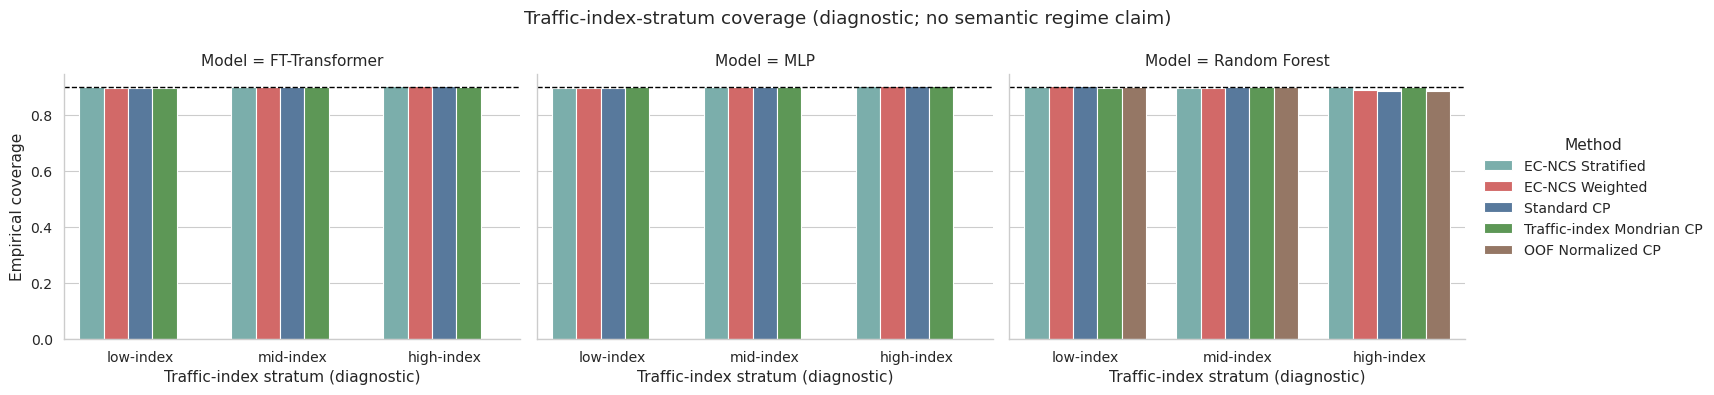

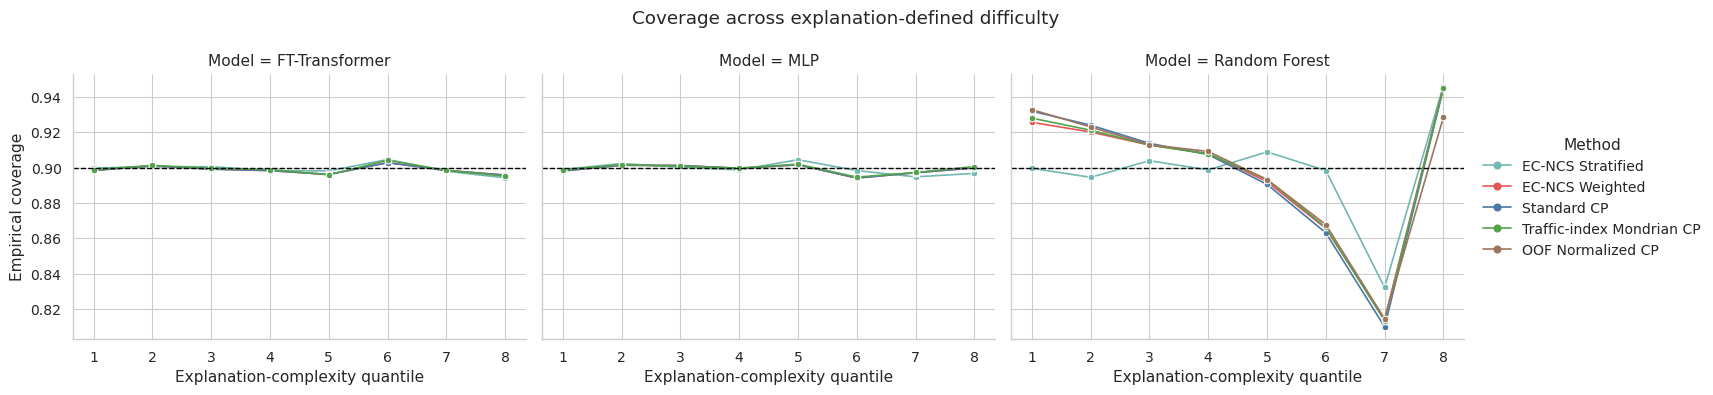

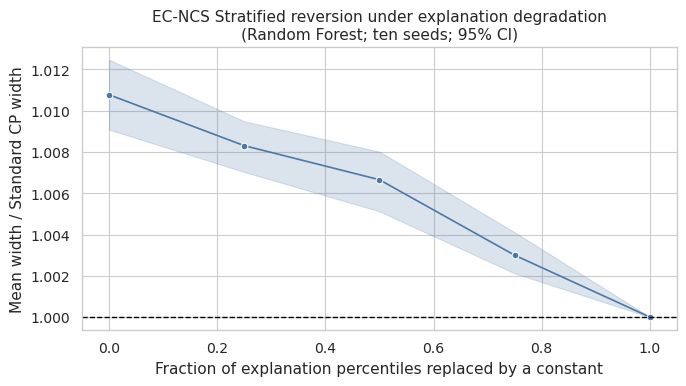

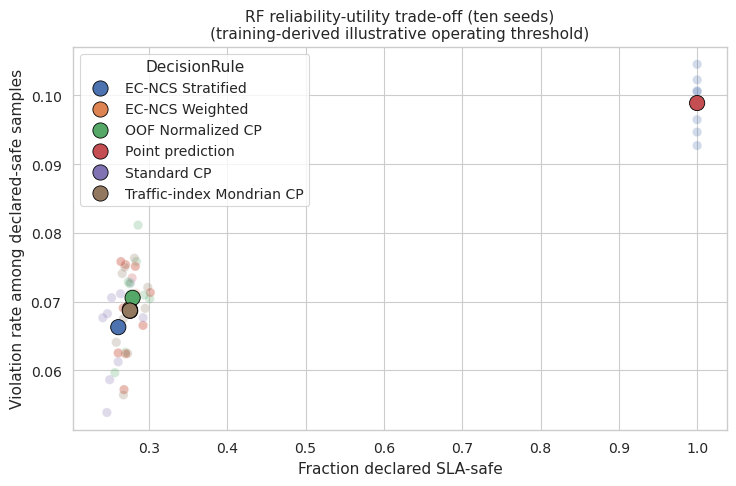

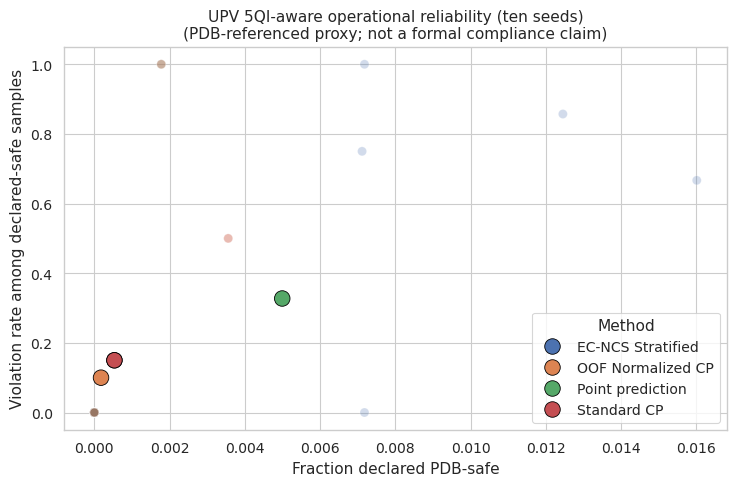

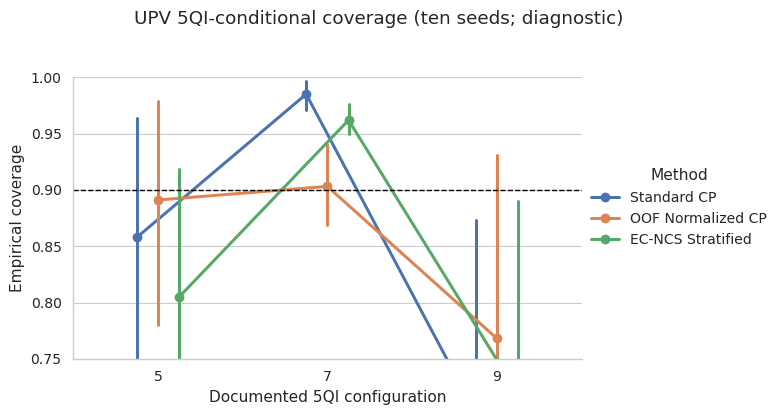

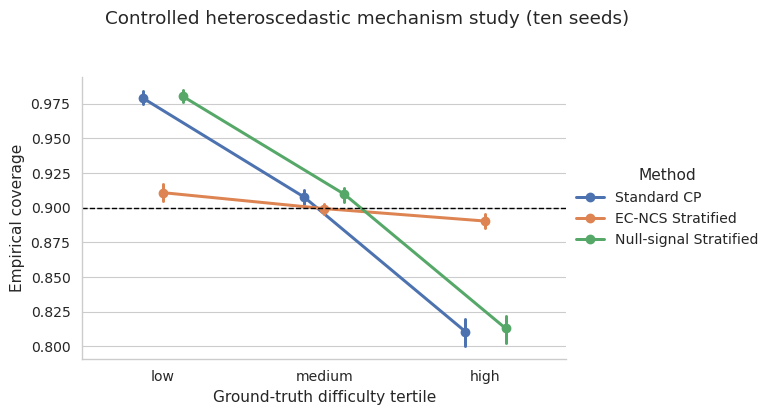

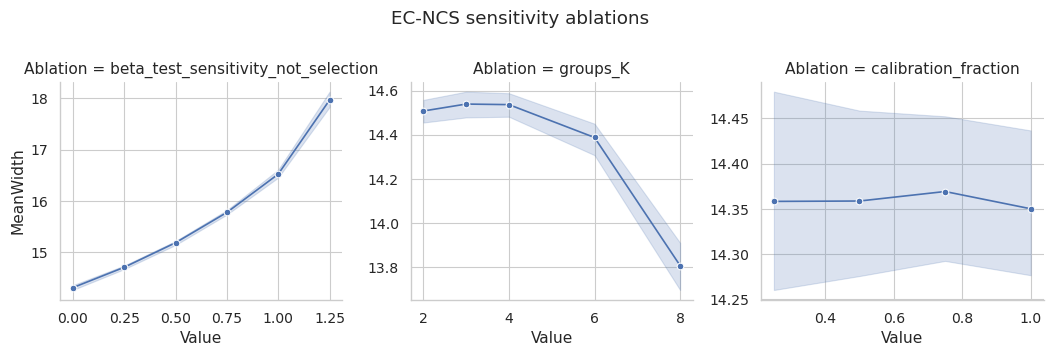

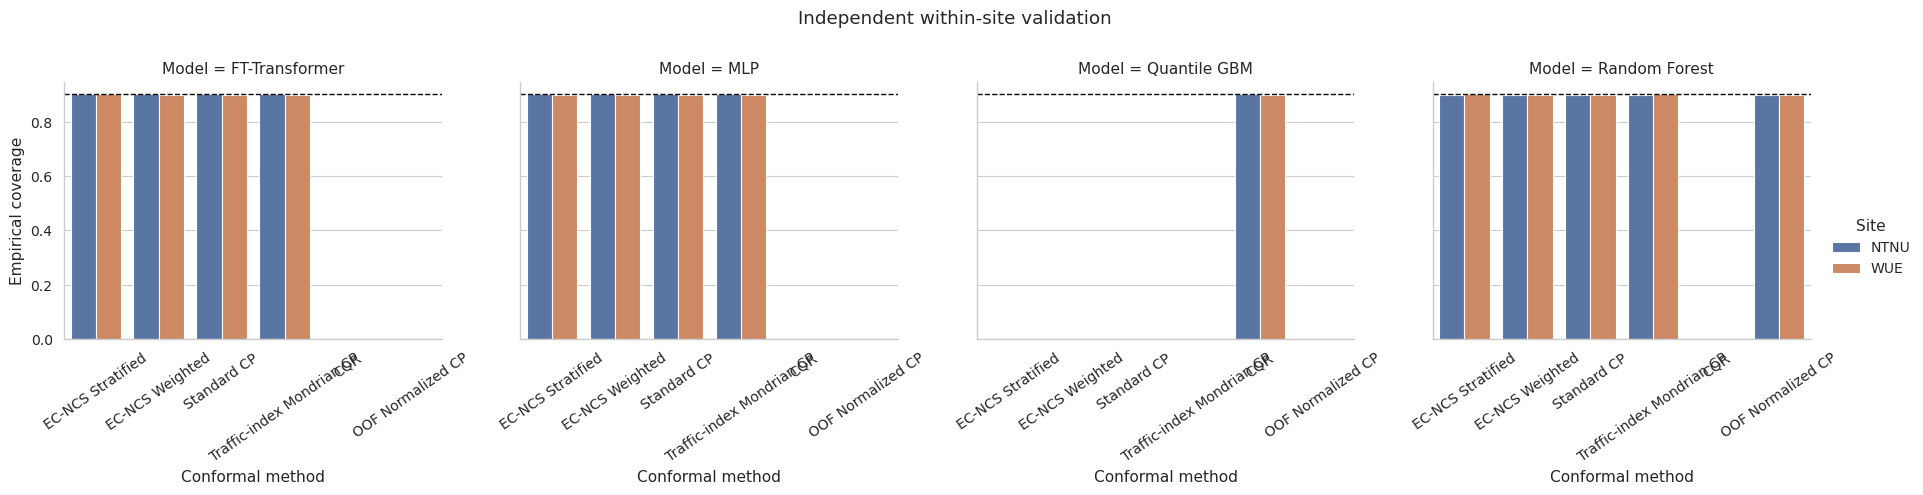

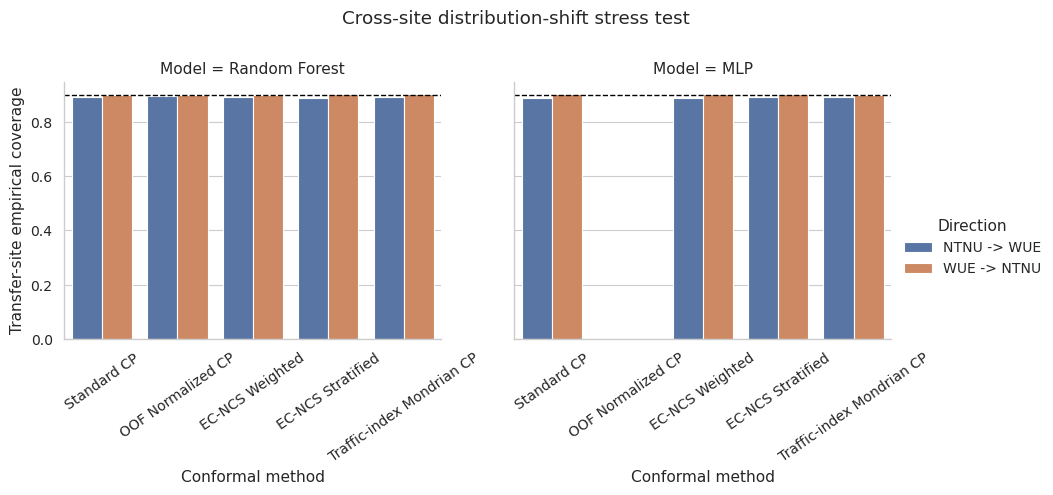

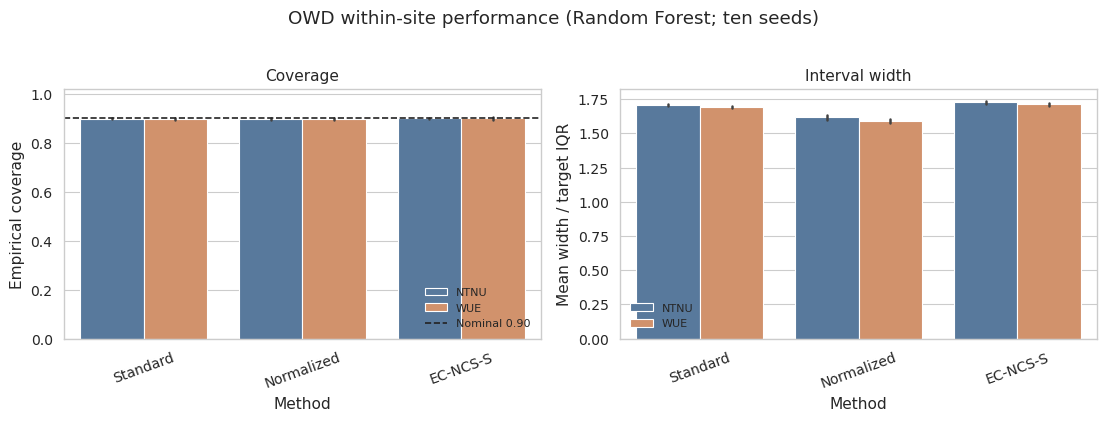

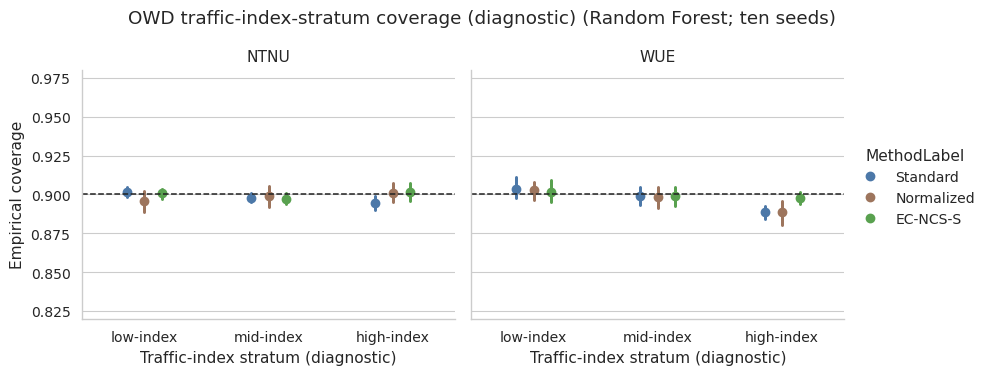

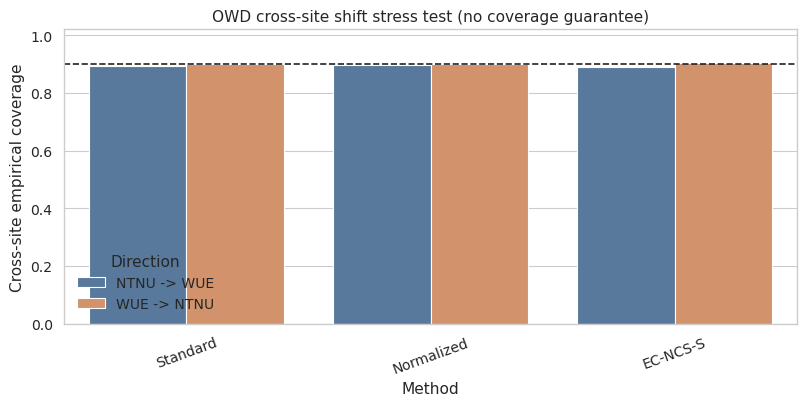

Results archive: /content/ec_ncs_tmlcn_journal_final_results.zip


,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,Winkler,CorrPhiWidth
0,FT-Transformer,EC-NCS Stratified,0.899268,0.003679,15.326274,0.034831,16.216425,-0.184794
1,FT-Transformer,EC-NCS Weighted,0.898778,0.003349,15.317871,0.035684,16.214227,0.000000
2,FT-Transformer,Standard CP,0.898778,0.003349,15.317871,0.035684,16.214227,0.005708
3,FT-Transformer,Traffic-index Mondrian CP,0.899060,0.003134,15.322031,0.034351,16.215038,0.002396
4,MLP,EC-NCS Stratified,0.899333,0.003457,15.325449,0.028013,16.217945,-0.309818
5,MLP,EC-NCS Weighted,0.899133,0.002602,15.324426,0.024689,16.216654,0.000000
6,MLP,Standard CP,0.899133,0.002602,15.324426,0.024689,16.216654,-0.004417
7,MLP,Traffic-index Mondrian CP,0.899441,0.002803,15.325880,0.025660,16.216968,0.005442
8,Random Forest,EC-NCS Stratified,0.897842,0.004135,14.467620,0.099090,16.427692,0.748211
9,Random Forest,EC-NCS Weighted,0.898059,0.005160,14.350072,0.137323,16.498118,0.100000


,Model,Method,Regime,Coverage,MeanWidth,Undercoverage,N
0,FT-Transformer,EC-NCS Stratified,high-index,0.902134,15.322883,0.000799,2402.2
1,FT-Transformer,EC-NCS Stratified,low-index,0.898408,15.327722,0.002790,5962.2
2,FT-Transformer,EC-NCS Stratified,mid-index,0.898687,15.326591,0.002992,3714.8
3,FT-Transformer,EC-NCS Weighted,high-index,0.901935,15.317871,0.000751,2402.2
4,FT-Transformer,EC-NCS Weighted,low-index,0.897654,15.317871,0.003371,5962.2
5,FT-Transformer,EC-NCS Weighted,mid-index,0.898431,15.317871,0.003023,3714.8
6,FT-Transformer,Standard CP,high-index,0.901935,15.317871,0.000751,2402.2
7,FT-Transformer,Standard CP,low-index,0.897654,15.317871,0.003371,5962.2
8,FT-Transformer,Standard CP,mid-index,0.898431,15.317871,0.003023,3714.8
9,FT-Transformer,Traffic-index Mondrian CP,high-index,0.901183,15.305571,0.002317,2402.2


,Model,Seed,TrainSeconds,BetaTuningSeconds,SelectedBeta,NormalizedCPOOFResidualMean,PredictionSeconds,PredictionMsPerSample,ExplanationCalibrationSeconds,ExplanationTrainingReferenceSeconds,ExplanationTrainingReferenceN,ExplanationTestSeconds,ExplanationMsPerTestSample,ConformalizationSeconds,EndToEndTestMsPerSample,TrainMemoryDeltaMB,PredictionMemoryDeltaMB,ExplanationMemoryDeltaMB
0,FT-Transformer,60.6,8.050826,5.748310,0.000,NaN,0.055641,0.004607,1.422911,0.608795,5000.0,1.399487,0.115900,0.011681,0.121475,0.001563,0.000000,0.000781
1,MLP,60.6,1.503168,1.469601,0.000,NaN,0.011175,0.000926,0.921365,0.395740,5000.0,0.959502,0.079519,0.012159,0.081453,0.000000,0.000000,0.000000
2,Random Forest,60.6,16.036988,10.315247,0.025,3.592452,0.475404,0.039359,1.976640,1.001346,5000.0,2.009047,0.166139,37.059890,3.273526,17.128125,0.003125,151.695703


,Site,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,NormalizedMeanWidth,MAE,R2
0,NTNU,FT-Transformer,EC-NCS Stratified,0.901686,0.006020,15.306592,0.072941,1.813708,4.229267,-0.000951
1,NTNU,FT-Transformer,EC-NCS Weighted,0.901997,0.006133,15.313291,0.071741,1.814502,4.229267,-0.000951
2,NTNU,FT-Transformer,Standard CP,0.901997,0.006133,15.313291,0.071741,1.814502,4.229267,-0.000951
3,NTNU,FT-Transformer,Traffic-index Mondrian CP,0.902146,0.005831,15.316604,0.069896,1.814895,4.229267,-0.000951
4,NTNU,MLP,EC-NCS Stratified,0.900847,0.005978,15.295972,0.073754,1.812450,4.231643,-0.002732
5,NTNU,MLP,EC-NCS Weighted,0.900038,0.006734,15.278527,0.070475,1.810383,4.231643,-0.002732
6,NTNU,MLP,Standard CP,0.900038,0.006734,15.278527,0.070475,1.810383,4.231643,-0.002732
7,NTNU,MLP,Traffic-index Mondrian CP,0.900301,0.006452,15.286331,0.075952,1.811307,4.231643,-0.002732
8,NTNU,Quantile GBM,CQR,0.901485,0.004326,13.095533,0.185901,1.551715,NaN,NaN
9,NTNU,Random Forest,EC-NCS Stratified,0.899608,0.003559,14.563961,0.157264,1.725712,3.607582,0.178535


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.896833,0.003167,13.498806,0.074081,13.926268,14.471929,16.329552,15.693748,-0.312058
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499562
4,NTNU,WUE,Random Forest,Traffic-index Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.140049
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Traffic-index Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


In [ ]:

# Colab-ready dependency bootstrap. Safe to rerun.
import importlib.util
import subprocess
import sys

_required = {
    "shap": "shap>=0.46",
    "captum": "captum>=0.7",
    "openpyxl": "openpyxl>=3.1",
    "pyarrow": "pyarrow>=15",
    "psutil": "psutil>=5.9",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# %%
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
import zipfile
from urllib.parse import quote
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import requests
import seaborn as sns
import shap
import torch
import torch.nn as nn
from captum.attr import GradientShap
from scipy.stats import spearmanr, wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


@dataclass
class Config:
    record_id: str = "13754300"
    sites: Tuple[str, ...] = ("wue", "ntnu")
    target_col: str = "trel"
    max_rows_per_site: int = 30_000
    csv_chunk_size: int = 200_000
    nominal_coverage: float = 0.90
    train_fraction: float = 0.60
    calibration_fraction: float = 0.20
    test_fraction: float = 0.20
    # Final pooled diagnostics (degradation, SLA, latency and pooled CP) use
    # the same five independent seeds as the primary within-site analysis.
    pooled_diagnostic_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    rf_trees: int = 200
    rf_min_leaf: int = 2
    mlp_epochs: int = 50
    mlp_batch_size: int = 512
    mlp_patience: int = 7
    explanation_batch_size: int = 256
    gradient_shap_samples: int = 4
    max_explanation_train_rows: int = 5_000
    tree_shap_approximate: bool = True
    beta_grid: Tuple[float, ...] = (0.0, 0.25, 0.50, 0.75, 1.00, 1.25)
    beta_inner_fit_fraction: float = 0.60
    beta_inner_calibration_fraction: float = 0.20
    beta_inner_max_rows_per_split: int = 2_000
    beta_coverage_tolerance: float = 0.01
    beta_worst_bin_tolerance: float = 0.03
    normalized_cp_oof_folds: int = 3
    oof_normalized_models: Tuple[str, ...] = ("Random Forest",)
    ec_weight_min: float = 0.35
    ec_weight_max: float = 3.00
    explanation_groups: int = 4
    minimum_group_calibration: int = 50
    regime_minimum_calibration: int = 50
    # New directory prevents incompatible checkpoints from the earlier
    # semantic-regime/weighted-degradation run from being reused.
    outdir: str = "/content/ec_ncs_tmlcn_journal_final_results"
    data_dir: str = "/content/ec_ncs_data"
    force_download: bool = False
    smoke_test: bool = False          # True uses synthetic data and runs quickly
    run_cross_site_transfer: bool = True
    cross_site_models: Tuple[str, ...] = ("Random Forest", "MLP")
    cross_site_seed: int = 2027  # retained for the single fixed transfer diagnostic
    run_within_site_validation: bool = True
    within_site_models: Tuple[str, ...] = ("Random Forest", "MLP", "FT-Transformer")
    within_site_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    explicit_scenario_regime_map: Optional[Dict[str, str]] = None
    # Optional reviewed CSV with exactly two columns: scenario, Regime.
    # Regime values must be normal, transition or congestion.  Supplying this
    # is the only way the code will make semantic network-regime claims.
    explicit_scenario_regime_map_csv: Optional[str] = None
    require_explicit_regime_map: bool = False
    sla_threshold: Optional[float] = None  # replace with a domain-supported delay threshold
    # Documented 5QI/resource-allocation validation dataset.
    run_upv_5qi_validation: bool = True
    upv_record_id: str = "18410980"
    upv_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    upv_minimum_group_calibration: int = 20
    # Controlled mechanism experiment; ground-truth difficulty is known.
    run_controlled_mechanism_study: bool = True
    synthetic_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)

CFG = Config()

if CFG.explicit_scenario_regime_map_csv is not None:
    regime_map_frame = pd.read_csv(CFG.explicit_scenario_regime_map_csv)
    required_map_columns = {"scenario", "Regime"}
    if not required_map_columns.issubset(regime_map_frame.columns):
        raise ValueError(
            "The expert regime-map CSV must contain columns: scenario, Regime")
    if regime_map_frame["scenario"].duplicated().any():
        raise ValueError("The expert regime-map CSV contains duplicate scenarios.")
    CFG.explicit_scenario_regime_map = dict(zip(
        regime_map_frame["scenario"].astype(str),
        regime_map_frame["Regime"].astype(str).str.lower()
    ))
ALPHA = 1.0 - CFG.nominal_coverage

# Semantic regime names are used only when every scenario has been mapped by
# networking-domain review.  Otherwise the code reports train-fitted,
# observable-feature traffic-index strata and never calls them congestion
# regimes.
HAS_EXPERT_REGIME_MAP = CFG.explicit_scenario_regime_map is not None
REGIME_ORDER = (["normal", "transition", "congestion"] if HAS_EXPERT_REGIME_MAP
                else ["low-index", "mid-index", "high-index"])
REGIME_AXIS_LABEL = ("Network regime" if HAS_EXPERT_REGIME_MAP
                     else "Traffic-index stratum (diagnostic)")
REGIME_FIGURE_TITLE = ("OWD regime-wise coverage" if HAS_EXPERT_REGIME_MAP
                       else "OWD traffic-index-stratum coverage (diagnostic)")
REGIME_CP_NAME = ("Regime Mondrian CP" if HAS_EXPERT_REGIME_MAP
                  else "Traffic-index Mondrian CP")
OUTDIR = Path(CFG.outdir)
DATA_DIR = Path(CFG.data_dir)
OUTDIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
MAIN_FIG_DIR = OUTDIR / "main_paper_figures"
SUPP_DIR = OUTDIR / "supplementary"
CHECKPOINT_DIR = OUTDIR / "checkpoints"
for _directory in (MAIN_FIG_DIR, SUPP_DIR, CHECKPOINT_DIR):
    _directory.mkdir(parents=True, exist_ok=True)
print(CFG)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conformal_quantile(scores: Sequence[float], alpha: float) -> float:
    """Finite-sample split-conformal quantile using the higher order statistic."""
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    if scores.size == 0:
        raise ValueError("No finite calibration scores.")
    level = min(1.0, np.ceil((scores.size + 1) * (1.0 - alpha)) / scores.size)
    return float(np.quantile(scores, level, method="higher"))


class TrainECDF:
    """Pointwise rank transform fitted only on training explanations."""
    def fit(self, values: Sequence[float]):
        self.sorted_ = np.sort(np.asarray(values, dtype=float))
        return self

    def transform(self, values: Sequence[float]) -> np.ndarray:
        values = np.asarray(values, dtype=float)
        return np.searchsorted(self.sorted_, values, side="right") / max(len(self.sorted_), 1)


def bootstrap_ci(values: Sequence[float], fn=np.mean, seed: int = 0,
                 n_boot: int = 500, level: float = 0.95) -> Tuple[float, float]:
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    draws = [fn(values[rng.integers(0, len(values), len(values))]) for _ in range(n_boot)]
    tail = (1.0 - level) / 2.0
    return tuple(np.quantile(draws, [tail, 1.0 - tail]))


def interval_metrics(y: np.ndarray, lo: np.ndarray, hi: np.ndarray,
                     alpha: float, phi: Optional[np.ndarray] = None) -> Dict[str, float]:
    y, lo, hi = map(lambda z: np.asarray(z, dtype=float), (y, lo, hi))
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    below = np.maximum(lo - y, 0.0)
    above = np.maximum(y - hi, 0.0)
    winkler = width + (2.0 / alpha) * (below + above)
    corr = 0.0
    if phi is not None and np.std(width) > 1e-12:
        corr = float(spearmanr(phi, width).correlation)
        if not np.isfinite(corr):
            corr = 0.0
    mean_width = float(width.mean())
    coverage = float(covered.mean())
    return {
        "Coverage": coverage,
        "Undercoverage": float(max(0.0, (1.0 - alpha) - coverage)),
        "MeanWidth": mean_width,
        "IntervalEfficiency": float(1.0 / max(mean_width, 1e-12)),
        "CoverageWidthCriterion": float(mean_width * (1.0 + 10.0 * abs(coverage - (1.0-alpha)))),
        "MedianWidth": float(np.median(width)),
        "P90Width": float(np.quantile(width, 0.90)),
        "Winkler": float(winkler.mean()),
        "CorrPhiWidth": corr,
    }


def timed_call(fn, *args, synchronize_gpu: bool = True, **kwargs):
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    mem_after = process.memory_info().rss
    return out, elapsed, max(0, mem_after - mem_before) / 2**20


def zenodo_metadata(record_id: str) -> Mapping:
    cache_path = DATA_DIR / f"zenodo_metadata_{record_id}.json"
    for attempt in range(6):
        try:
            response = requests.get(
                f"https://zenodo.org/api/records/{record_id}", timeout=180,
                headers={"User-Agent": "EC-NCS-research/1.0"},
            )
            response.raise_for_status()
            payload = response.json()
            cache_path.write_text(json.dumps(payload))
            return payload
        except requests.RequestException as error:
            if cache_path.exists():
                print(f"Zenodo API unavailable; using cached metadata: {error}")
                return json.loads(cache_path.read_text())
            if attempt < 5:
                wait = min(60, 5 * (2 ** attempt))
                print(f"Zenodo metadata attempt {attempt+1} failed; retrying in {wait}s")
                time.sleep(wait)
    print("Zenodo metadata unavailable; using documented OWD filenames.")
    return {"files": [
        {"key": "wue_owd_Packets_with_IATs.csv", "links": {}},
        {"key": "ntnu_owd_Packets_with_IATs.csv", "links": {}},
    ]}


def choose_owd_file(metadata: Mapping, site: str) -> Mapping:
    site = site.lower()
    files = metadata.get("files", [])
    ranked = []
    for item in files:
        name = item.get("key", "").lower()
        score = 0
        score += 8 if site in name else 0
        score += 8 if "owd" in name else 0
        score += 4 if "with_iats" in name else 0
        score -= 5 if "tput" in name else 0
        score += 2 if name.endswith(".csv") else 0
        ranked.append((score, item))
    ranked.sort(key=lambda z: z[0], reverse=True)
    if not ranked or ranked[0][0] < 12:
        available = [f.get("key") for f in files]
        raise FileNotFoundError(f"No suitable {site} OWD CSV. Available: {available}")
    return ranked[0][1]


def stream_download(item: Mapping, destination: Path, force: bool = False) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and not force:
        return destination
    file_name = item["key"]
    urls = []
    if item.get("links", {}).get("self"):
        urls.append(item["links"]["self"])
    urls.append(
        f"https://zenodo.org/records/{CFG.record_id}/files/{quote(file_name)}?download=1"
    )
    temporary = Path(str(destination) + ".part")
    last_error = None
    for url in urls:
        for attempt in range(5):
            try:
                headers = {}
                mode = "wb"
                if temporary.exists() and temporary.stat().st_size > 0:
                    headers["Range"] = f"bytes={temporary.stat().st_size}-"
                    mode = "ab"
                with requests.get(url, stream=True, timeout=300, headers=headers) as response:
                    if response.status_code == 200 and mode == "ab":
                        mode = "wb"  # server ignored Range; restart safely
                    response.raise_for_status()
                    with temporary.open(mode) as handle:
                        for chunk in response.iter_content(chunk_size=2**20):
                            if chunk:
                                handle.write(chunk)
                os.replace(temporary, destination)
                return destination
            except requests.RequestException as error:
                last_error = error
                wait = min(60, 5 * (2 ** attempt))
                print(f"Download attempt {attempt+1} failed for {file_name}; retrying in {wait}s")
                time.sleep(wait)
    raise RuntimeError(f"Could not download {file_name}: {last_error}")
    return destination


def synthetic_5g(n: int = 12_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    load = rng.uniform(0, 1, n)
    scenario = pd.cut(load, [-1, .35, .70, 2], labels=["normal", "transition", "congestion"])
    packet_size = rng.choice([128, 256, 512, 1024, 1500], n)
    iat = rng.lognormal(-2.0 + 1.2 * load, .35, n)
    ratio = rng.uniform(.1, 1.0, n)
    noise = rng.normal(0, .12 + .55 * load**2, n)
    trel = 0.15 + 1.1 * load + .00025 * packet_size + .15 * ratio + noise
    return pd.DataFrame({"PacketSize": packet_size, "iat": iat, "ratio": ratio,
                         "scenario": scenario.astype(str), "rep": rng.integers(0, 30, n),
                         "trel": trel})


def uniform_chunk_sample_csv(path: Path, sample_size: int, seed: int,
                             chunksize: int = 200_000) -> Tuple[pd.DataFrame, Dict[str, int]]:
    """Exact uniform random-key reservoir sample over every data row in a CSV.

    Independent continuous priorities give every row equal inclusion probability and avoid
    the ordered-prefix bias caused by pd.read_csv(..., nrows=sample_size).
    """
    rng = np.random.default_rng(seed)
    reservoir = None
    seen = 0
    for chunk_id, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False)):
        chunk.columns = chunk.columns.astype(str).str.strip()
        seen += len(chunk)
        chunk["__uniform_priority__"] = rng.random(len(chunk))
        candidates = chunk if reservoir is None else pd.concat([reservoir, chunk], ignore_index=True)
        reservoir = candidates.nsmallest(min(sample_size, len(candidates)), "__uniform_priority__")
        if (chunk_id + 1) % 10 == 0:
            print(f"  scanned {seen:,} rows from {path.name}")
    sampled = reservoir.drop(columns="__uniform_priority__").reset_index(drop=True)
    return sampled, {"RowsScanned": seen, "RowsSampled": len(sampled),
                     "SamplingSeed": seed, "ChunkSize": chunksize}


sampling_rows, selected_files = [], {}
site_frames = []
if CFG.smoke_test:
    for i, site in enumerate(CFG.sites):
        frame = synthetic_5g(seed=42+i)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": "synthetic smoke test",
                              "RowsScanned": len(frame), "RowsSampled": len(frame),
                              "SamplingSeed": 42+i, "ChunkSize": np.nan})
        selected_files[site] = "synthetic smoke test"
else:
    metadata = zenodo_metadata(CFG.record_id)
    for i, site in enumerate(CFG.sites):
        selected = choose_owd_file(metadata, site)
        selected_path = DATA_DIR / Path(selected["key"]).name
        selected_path = stream_download(selected, selected_path, CFG.force_download)
        print(f"Uniformly sampling the complete {site.upper()} file: {selected_path.name}")
        frame, audit = uniform_chunk_sample_csv(selected_path, CFG.max_rows_per_site,
                                                seed=2027+i, chunksize=CFG.csv_chunk_size)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": selected_path.name, **audit})
        selected_files[site] = str(selected_path)

raw_df = pd.concat(site_frames, ignore_index=True)
sampling_audit_df = pd.DataFrame(sampling_rows)
sampling_audit_df["SamplingFraction"] = sampling_audit_df.RowsSampled / sampling_audit_df.RowsScanned
sampling_audit_df.to_csv(OUTDIR / "sampling_audit.csv", index=False)
raw_df.columns = raw_df.columns.astype(str).str.strip()
print("Selected files:", selected_files)
print("Shape:", raw_df.shape)
display(sampling_audit_df)
display(raw_df.groupby("DatasetSite", observed=True).size().rename("SampledRows"))
display(raw_df.head())
print(raw_df.dtypes)


DROP_COLUMNS = {
    "Unnamed: 0", "src", "Timestamp", "SourceIPOuter", "DestinationIPOuter",
    "SourceIPInner", "DestinationIPInner", "SeqNum", "DatasetSite",
    # Retained in clean_df for splitting/auditing, but never supplied to a model.
    "scenario", "rep"
}


def audit_and_clean(df: pd.DataFrame, target_col: str):
    if target_col not in df.columns:
        raise ValueError(f"Target {target_col!r} missing. Available columns: {df.columns.tolist()}")
    work = df.copy()
    work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan).dropna(subset=[target_col]).drop_duplicates()
    candidate = [c for c in work.columns if c != target_col and c not in DROP_COLUMNS]
    audit_rows = []
    selected = []
    for col in work.columns:
        missing = float(work[col].isna().mean())
        nunique = int(work[col].nunique(dropna=True))
        reason = "included"
        include = col in candidate and missing <= .50 and nunique > 1
        if col == target_col: reason = "target"
        elif col in DROP_COLUMNS: reason = "identifier/sequence leakage risk"
        elif missing > .50: reason = ">50% missing"
        elif nunique <= 1: reason = "constant"
        elif include: selected.append(col)
        audit_rows.append({"Feature": col, "Dtype": str(work[col].dtype),
                           "MissingFraction": missing, "UniqueValues": nunique,
                           "Included": include, "Reason": reason})
    return work, selected, pd.DataFrame(audit_rows)


clean_df, feature_columns, feature_audit = audit_and_clean(raw_df, CFG.target_col)
feature_audit.to_csv(OUTDIR / "feature_audit.csv", index=False)
display(feature_audit)
print("Included features:", feature_columns)


def scenario_to_regime(values: pd.Series) -> Optional[pd.Series]:
    text = values.astype(str).str.lower()
    out = pd.Series(index=values.index, dtype="object")
    patterns = {
        "normal": r"normal|stable|baseline|idle|low",
        "transition": r"transition|medium|moderate|ramp|bursty",
        "congestion": r"congest|overload|heavy|high|stress"
    }
    for label, pattern in patterns.items():
        out[text.str.contains(pattern, regex=True, na=False)] = label
    return out if out.notna().mean() >= .70 else None


if "scenario" in clean_df.columns:
    scenario_inventory = (clean_df.groupby(["DatasetSite", "scenario"], observed=True)
                          .size().rename("N").reset_index())
    # Inventory only: the script must not manufacture semantic regimes from
    # filenames.  A networking expert can review this CSV and then populate
    # CFG.explicit_scenario_regime_map.
    scenario_inventory["SuggestedRegime"] = "REVIEW_REQUIRED"
    scenario_inventory.to_csv(OUTDIR / "scenario_regime_inventory.csv", index=False)
    expert_map_template = (scenario_inventory[["scenario"]].drop_duplicates()
                           .sort_values("scenario").reset_index(drop=True))
    expert_map_template["Regime"] = ""
    expert_map_template.to_csv(OUTDIR / "expert_regime_map_template.csv", index=False)
    display(scenario_inventory)
    print("For the paper, populate CFG.explicit_scenario_regime_map and set "
          "CFG.require_explicit_regime_map=True after domain review.")


REGIME_FEATURE_HINTS = ["ratio", "pdist", "pnpak", "piat", "iat", "packetsize", "bw", "slots"]


class RegimeAssigner:
    def fit(self, X: pd.DataFrame):
        if "scenario" in X.columns:
            if CFG.explicit_scenario_regime_map is not None:
                allowed = {"normal", "transition", "congestion"}
                if not set(CFG.explicit_scenario_regime_map.values()).issubset(allowed):
                    raise ValueError(f"Regime-map values must be in {allowed}")
                observed = set(X["scenario"].astype(str).unique())
                missing = observed - set(CFG.explicit_scenario_regime_map)
                if missing:
                    raise ValueError(f"Explicit regime map misses scenario labels: {sorted(missing)}")
                self.mode_ = "explicit scenario mapping"
                self.scenario_map_ = dict(CFG.explicit_scenario_regime_map)
                return self
            if CFG.require_explicit_regime_map:
                raise ValueError("Populate CFG.explicit_scenario_regime_map after inspecting scenario labels.")
            # Never infer semantic network regimes from scenario-name keywords.
            # Such labels require an explicit, reviewed mapping above.
        numeric = X.select_dtypes(include=np.number)
        cols = [c for c in numeric.columns if any(h in c.lower() for h in REGIME_FEATURE_HINTS)]
        if not cols:
            cols = numeric.columns.tolist()
        self.mode_ = "train-fitted traffic index"
        self.cols_ = cols
        self.center_ = numeric[cols].median()
        self.scale_ = (numeric[cols].quantile(.75) - numeric[cols].quantile(.25)).replace(0, 1.0)
        score = ((numeric[cols] - self.center_) / self.scale_).abs().mean(axis=1)
        self.thresholds_ = tuple(score.quantile([.50, .80]))
        return self

    def transform(self, X: pd.DataFrame) -> pd.Series:
        if self.mode_ in {"scenario labels", "explicit scenario mapping"}:
            mapped = X["scenario"].astype(str).map(self.scenario_map_)
            if mapped.isna().any() and self.mode_ == "explicit scenario mapping":
                missing = sorted(X.loc[mapped.isna(), "scenario"].astype(str).unique())
                raise ValueError(f"Unmapped scenarios during transform: {missing}")
            return mapped.fillna("transition")
        numeric = X[self.cols_].apply(pd.to_numeric, errors="coerce").fillna(self.center_)
        score = ((numeric - self.center_) / self.scale_).abs().mean(axis=1)
        return pd.cut(score, [-np.inf, self.thresholds_[0], self.thresholds_[1], np.inf],
                      labels=REGIME_ORDER).astype(str)


def make_groups(df: pd.DataFrame) -> Optional[pd.Series]:
    group_cols = [c for c in ["DatasetSite", "scenario", "rep", "gnb", "sdr"] if c in df.columns]
    if not group_cols:
        return None
    groups = df[group_cols].astype(str).agg("|".join, axis=1)
    return groups if groups.nunique() >= 10 else None


def three_way_split(df: pd.DataFrame, seed: int):
    groups = make_groups(df)
    indices = np.arange(len(df))
    if groups is not None:
        first = GroupShuffleSplit(n_splits=1, train_size=CFG.train_fraction, random_state=seed)
        train_idx, rest_idx = next(first.split(indices, groups=groups))
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        second = GroupShuffleSplit(n_splits=1, test_size=relative_test, random_state=seed + 1)
        cal_rel, test_rel = next(second.split(rest_idx, groups=groups.iloc[rest_idx]))
        cal_idx, test_idx = rest_idx[cal_rel], rest_idx[test_rel]
        strategy = "group-disjoint"
    else:
        train_idx, rest_idx = train_test_split(indices, train_size=CFG.train_fraction, random_state=seed)
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        cal_idx, test_idx = train_test_split(rest_idx, test_size=relative_test, random_state=seed + 1)
        strategy = "random fallback"
    return train_idx, np.asarray(cal_idx), np.asarray(test_idx), strategy


def split_overlap_report(df, train_idx, cal_idx, test_idx):
    groups = make_groups(df)
    if groups is None:
        return {"TrainCalGroupOverlap": np.nan, "TrainTestGroupOverlap": np.nan,
                "CalTestGroupOverlap": np.nan}
    sets = [set(groups.iloc[idx]) for idx in [train_idx, cal_idx, test_idx]]
    return {"TrainCalGroupOverlap": len(sets[0] & sets[1]),
            "TrainTestGroupOverlap": len(sets[0] & sets[2]),
            "CalTestGroupOverlap": len(sets[1] & sets[2])}


def build_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    numeric = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                                   min_frequency=2))]), categorical),
    ], remainder="drop", verbose_feature_names_out=True)


class ResidualMLP(nn.Module):
    def __init__(self, n_features: int):
        super().__init__()
        width = min(256, max(64, 4 * n_features))
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.BatchNorm1d(width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width // 2), nn.GELU(),
            nn.Linear(width // 2, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


class FTTransformerRegressor(nn.Module):
    """FT-Transformer-style regressor with one learned token per transformed feature."""
    def __init__(self, n_features: int, d_token: int = 32, n_heads: int = 4,
                 n_layers: int = 3):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_token) * .02)
        self.bias = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads,
                                           dim_feedforward=4*d_token, dropout=.10,
                                           activation="gelu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(encoded[:, 0]).squeeze(-1)


class TorchRegressor:
    def __init__(self, seed: int, architecture: str = "mlp"):
        self.seed = seed
        self.architecture = architecture
    def fit(self, X, y):
        set_seed(self.seed)
        X = np.asarray(X, np.float32); y = np.asarray(y, np.float32)
        split = int(.85 * len(X))
        rng = np.random.default_rng(self.seed)
        order = rng.permutation(len(X)); fit_idx, val_idx = order[:split], order[split:]
        self.y_mean_, self.y_std_ = float(y[fit_idx].mean()), float(y[fit_idx].std() + 1e-8)
        yz = (y - self.y_mean_) / self.y_std_
        self.model = (ResidualMLP(X.shape[1]) if self.architecture == "mlp"
                      else FTTransformerRegressor(X.shape[1])).to(DEVICE)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=.5)
        loss_fn = nn.SmoothL1Loss()
        best, best_state, bad = np.inf, None, 0
        for epoch in range(CFG.mlp_epochs):
            self.model.train()
            for start in range(0, len(fit_idx), CFG.mlp_batch_size):
                batch = fit_idx[start:start + CFG.mlp_batch_size]
                # BatchNorm cannot estimate batch statistics from one sample.
                # Skipping only a singleton tail batch avoids seed-dependent crashes;
                # all preceding shuffled observations are still used normally.
                if len(batch) < 2:
                    continue
                xb = torch.tensor(X[batch], device=DEVICE)
                yb = torch.tensor(yz[batch], device=DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = loss_fn(self.model(xb), yb)
                loss.backward(); optimizer.step()
            self.model.eval()
            with torch.no_grad():
                xv = torch.tensor(X[val_idx], device=DEVICE)
                yv = torch.tensor(yz[val_idx], device=DEVICE)
                val = float(loss_fn(self.model(xv), yv).item())
            scheduler.step(val)
            if val < best - 1e-5:
                best, bad = val, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= CFG.mlp_patience: break
        self.model.load_state_dict(best_state)
        return self
    def predict(self, X):
        self.model.eval(); X = np.asarray(X, np.float32); pieces = []
        with torch.no_grad():
            for start in range(0, len(X), CFG.mlp_batch_size):
                xb = torch.tensor(X[start:start + CFG.mlp_batch_size], device=DEVICE)
                pieces.append(self.model(xb).cpu().numpy())
        return np.concatenate(pieces) * self.y_std_ + self.y_mean_


def build_model(name: str, seed: int):
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=CFG.rf_trees, min_samples_leaf=CFG.rf_min_leaf,
                                     random_state=seed, n_jobs=-1)
    if name == "MLP":
        return TorchRegressor(seed, "mlp")
    if name == "FT-Transformer":
        return TorchRegressor(seed, "transformer")
    raise KeyError(name)


def tree_shap_strength(model, X: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    values = np.asarray(explainer.shap_values(
        X,
        approximate=CFG.tree_shap_approximate,
        check_additivity=False,
    ))
    return np.abs(values).sum(axis=1), values


def gradient_shap_strength(model: TorchRegressor, X: np.ndarray,
                           background: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    model.model.eval()
    gs = GradientShap(model.model)
    baseline = torch.tensor(background.astype(np.float32), device=DEVICE)
    strengths, attrs = [], []
    for start in range(0, len(X), CFG.explanation_batch_size):
        xb = torch.tensor(X[start:start + CFG.explanation_batch_size].astype(np.float32),
                          device=DEVICE, requires_grad=True)
        attribution = gs.attribute(xb, baselines=baseline,
                                   n_samples=CFG.gradient_shap_samples, stdevs=0.01)
        arr = attribution.detach().cpu().numpy() * model.y_std_
        attrs.append(arr); strengths.append(np.abs(arr).sum(axis=1))
    return np.concatenate(strengths), np.vstack(attrs)


def explain(model_name, model, X, background):
    if model_name == "Random Forest":
        return tree_shap_strength(model, X)
    return gradient_shap_strength(model, X, background)


def explanation_reference(X_train: np.ndarray, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    """Uniform bounded training reference for the explanation ECDF.

    Calibration and test explanations are still computed for every observation.
    Bounding only the training reference removes the dominant unnecessary SHAP cost.
    """
    rng = np.random.default_rng(seed + 1000)
    n = min(CFG.max_explanation_train_rows, len(X_train))
    idx = rng.choice(len(X_train), size=n, replace=False)
    return X_train[idx], idx


def _bounded_indices(indices: np.ndarray, maximum: int, seed: int) -> np.ndarray:
    indices = np.asarray(indices)
    if len(indices) <= maximum:
        return indices
    return np.random.default_rng(seed).choice(indices, size=maximum, replace=False)


def tune_beta_on_inner_training(model_name: str, X_train: np.ndarray,
                                y_train: np.ndarray, seed: int):
    """Select beta without outer calibration or test labels.

    The outer training partition is split into inner-fit, inner-calibration and
    inner-validation subsets. A temporary predictor is trained on inner-fit.
    Candidate beta values are calibrated on inner-calibration and ranked on
    inner-validation. Feasible candidates must meet both overall and worst
    explanation-tertile coverage tolerances; among them, the narrowest interval
    is selected. If none is feasible, a prespecified penalized objective is used.
    """
    all_idx = np.arange(len(X_train))
    fit_idx, remainder = train_test_split(
        all_idx, train_size=CFG.beta_inner_fit_fraction, random_state=seed + 3100
    )
    inner_cal_fraction = CFG.beta_inner_calibration_fraction / (
        1.0 - CFG.beta_inner_fit_fraction
    )
    cal_idx, val_idx = train_test_split(
        remainder, train_size=inner_cal_fraction, random_state=seed + 3101
    )
    cal_idx = _bounded_indices(cal_idx, CFG.beta_inner_max_rows_per_split, seed + 3102)
    val_idx = _bounded_indices(val_idx, CFG.beta_inner_max_rows_per_split, seed + 3103)

    temporary_model = build_model(model_name, seed + 3000).fit(
        X_train[fit_idx], y_train[fit_idx]
    )
    pred_cal = temporary_model.predict(X_train[cal_idx])
    pred_val = temporary_model.predict(X_train[val_idx])

    rng = np.random.default_rng(seed + 3104)
    fit_reference_idx = _bounded_indices(
        fit_idx, min(CFG.max_explanation_train_rows, 2_000), seed + 3105
    )
    background_idx = rng.choice(fit_idx, size=min(64, len(fit_idx)), replace=False)
    phi_fit, _ = explain(
        model_name, temporary_model, X_train[fit_reference_idx], X_train[background_idx]
    )
    phi_cal, _ = explain(
        model_name, temporary_model, X_train[cal_idx], X_train[background_idx]
    )
    phi_val, _ = explain(
        model_name, temporary_model, X_train[val_idx], X_train[background_idx]
    )

    ecdf = TrainECDF().fit(phi_fit)
    z_cal, z_val = ecdf.transform(phi_cal), ecdf.transform(phi_val)
    residual_cal = np.abs(y_train[cal_idx] - pred_cal)
    target_scale = max(float(np.subtract(*np.quantile(y_train[fit_idx], [.75, .25]))), 1e-8)
    tertiles = pd.qcut(z_val, q=3, labels=False, duplicates="drop")
    tuning_rows = []

    for beta in CFG.beta_grid:
        w_cal = np.clip(1.0 + beta * (z_cal - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        w_val = np.clip(1.0 + beta * (z_val - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residual_cal / w_cal, ALPHA)
        lower, upper = pred_val - q * w_val, pred_val + q * w_val
        covered = (y_train[val_idx] >= lower) & (y_train[val_idx] <= upper)
        coverage = float(covered.mean())
        bin_coverages = [float(covered[np.asarray(tertiles == group)].mean())
                         for group in pd.unique(tertiles)]
        worst_bin = min(bin_coverages) if bin_coverages else coverage
        mean_width = float(np.mean(upper - lower))
        feasible = (
            coverage >= CFG.nominal_coverage - CFG.beta_coverage_tolerance
            and worst_bin >= CFG.nominal_coverage - CFG.beta_worst_bin_tolerance
        )
        objective = (
            mean_width / target_scale
            + 20.0 * max(0.0, CFG.nominal_coverage - coverage) ** 2
            + 10.0 * max(0.0, CFG.nominal_coverage - worst_bin) ** 2
        )
        tuning_rows.append({
            "Seed": seed, "Model": model_name, "Beta": beta,
            "InnerFitN": len(fit_idx), "InnerCalibrationN": len(cal_idx),
            "InnerValidationN": len(val_idx), "Coverage": coverage,
            "WorstExplanationTertileCoverage": worst_bin,
            "MeanWidth": mean_width, "NormalizedWidth": mean_width / target_scale,
            "Feasible": feasible, "Objective": objective,
        })

    tuning_frame = pd.DataFrame(tuning_rows)
    feasible_frame = tuning_frame[tuning_frame.Feasible]
    if len(feasible_frame):
        selected_row = feasible_frame.sort_values(
            ["NormalizedWidth", "Objective", "Beta"]
        ).iloc[0]
        selection_rule = "minimum normalized width among feasible candidates"
    else:
        selected_row = tuning_frame.sort_values(["Objective", "Beta"]).iloc[0]
        selection_rule = "minimum prespecified penalized objective; no feasible candidate"
    selected_beta = float(selected_row.Beta)
    tuning_frame["Selected"] = np.isclose(tuning_frame.Beta, selected_beta)
    tuning_frame["SelectionRule"] = selection_rule

    del temporary_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return selected_beta, tuning_frame


def save_main_checkpoints():
    """Persist completed work after every model so an interrupted Colab loses less."""
    pd.DataFrame(metric_rows).to_csv(OUTDIR / "metrics_checkpoint.csv", index=False)
    pd.DataFrame(bin_rows).to_csv(OUTDIR / "explanation_bins_checkpoint.csv", index=False)
    pd.DataFrame(site_metric_rows).to_csv(OUTDIR / "site_metrics_checkpoint.csv", index=False)
    pd.DataFrame(prediction_rows).to_csv(OUTDIR / "prediction_metrics_checkpoint.csv", index=False)
    pd.DataFrame(operational_rows).to_csv(OUTDIR / "operational_checkpoint.csv", index=False)
    pd.DataFrame(degradation_rows).to_csv(OUTDIR / "degradation_checkpoint.csv", index=False)
    pd.DataFrame(latency_rows).to_csv(OUTDIR / "latency_checkpoint.csv", index=False)
    pd.DataFrame(importance_rows).to_csv(OUTDIR / "importance_checkpoint.csv", index=False)
    pd.DataFrame(split_rows).drop_duplicates().to_csv(OUTDIR / "splits_checkpoint.csv", index=False)
    pd.DataFrame(beta_tuning_rows).to_csv(
        OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False
    )


def reproduce_legacy_rf(df: pd.DataFrame, feature_columns: Sequence[str], target_col: str):
    legacy = df[list(feature_columns) + [target_col]].copy()
    X = legacy[list(feature_columns)].copy()
    y = legacy[target_col].to_numpy(float)
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    for col in numeric:
        X[col] = pd.to_numeric(X[col], errors="coerce").fillna(X[col].median())
    if categorical:
        X[categorical] = X[categorical].astype(str).fillna("missing")
        X[categorical] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X[categorical])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.40, random_state=42)
    X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=42)
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                  random_state=42, n_jobs=-1).fit(X_train, y_train)
    pred_cal, pred_test = model.predict(X_cal), model.predict(X_test)
    explainer = shap.TreeExplainer(model)
    phi_cal = np.abs(np.asarray(explainer.shap_values(X_cal))).sum(axis=1)
    phi_test = np.abs(np.asarray(explainer.shap_values(X_test))).sum(axis=1)
    rank = lambda v: pd.Series(v).rank(method="average").to_numpy() / len(v)
    z_cal, z_test = rank(phi_cal), rank(phi_test)
    residuals = np.abs(y_cal - pred_cal)
    q_std = conformal_quantile(residuals, ALPHA)
    beta = .50
    w_cal = np.clip(1 + beta * (z_cal - z_cal.mean()), .25, 4.0)
    w_test = np.clip(1 + beta * (z_test - z_cal.mean()), .25, 4.0)
    q_ec = conformal_quantile(residuals / w_cal, ALPHA)
    intervals = {"Standard CP": (pred_test-q_std, pred_test+q_std),
                 "Legacy EC-NCS Weighted": (pred_test-q_ec*w_test, pred_test+q_ec*w_test)}
    rows = []
    for method, (lo, hi) in intervals.items():
        rows.append({"Protocol": "Submitted legacy reproduction", "Model": "Random Forest",
                     "Method": method, "MAE": mean_absolute_error(y_test, pred_test),
                     "R2": r2_score(y_test, pred_test),
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


legacy_source = clean_df[clean_df["DatasetSite"].astype(str).str.upper() == "WUE"].copy()
legacy_reproduction_df = reproduce_legacy_rf(legacy_source, feature_columns, CFG.target_col)
legacy_reproduction_df.to_csv(OUTDIR / "legacy_rf_reproduction.csv", index=False)
display(legacy_reproduction_df)


def fit_scale_model(model_name, X_train, y_train, raw_train, seed):
    """Fit local scale to honest out-of-fold residuals."""
    groups = make_groups(raw_train.reset_index(drop=True))
    if groups is not None and groups.nunique() >= CFG.normalized_cp_oof_folds:
        splitter = GroupKFold(n_splits=CFG.normalized_cp_oof_folds)
        splits = list(splitter.split(np.arange(len(y_train)), groups=groups))
        strategy = "GroupKFold"
    else:
        splitter = KFold(n_splits=CFG.normalized_cp_oof_folds,
                         shuffle=True, random_state=seed)
        splits = list(splitter.split(np.arange(len(y_train))))
        strategy = "KFold fallback"
    oof_prediction = np.full(len(y_train), np.nan, dtype=float)
    for fold, (fit_idx, holdout_idx) in enumerate(splits):
        print(f"    OOF normalized CP {model_name}: fold {fold+1}/{len(splits)}")
        fold_model = build_model(model_name, seed + 4000 + fold).fit(
            X_train[fit_idx], y_train[fit_idx]
        )
        oof_prediction[holdout_idx] = fold_model.predict(X_train[holdout_idx])
        del fold_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    if np.isnan(oof_prediction).any():
        raise RuntimeError("Incomplete OOF predictions for normalized CP.")
    target = np.abs(y_train - oof_prediction) + 1e-6
    model = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=10,
                                random_state=seed, n_jobs=-1)
    model.fit(X_train, target)
    return model, strategy, target


def mondrian_radii(res_cal, cal_groups, test_groups, alpha, minimum):
    global_q = conformal_quantile(res_cal, alpha)
    radii = np.full(len(test_groups), global_q, dtype=float)
    for group in pd.unique(cal_groups):
        cal_mask = np.asarray(cal_groups) == group
        if cal_mask.sum() >= minimum:
            q = conformal_quantile(np.asarray(res_cal)[cal_mask], alpha)
            radii[np.asarray(test_groups) == group] = q
    return radii


def build_intervals(model_name, y_cal, pred_cal, pred_test, X_train, y_train,
                    raw_train,
                    X_cal, X_test, phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed, beta):
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    intervals = {"Standard CP": (pred_test - q_standard, pred_test + q_standard)}

    oof_strategy, oof_residual = "not run for this model", np.array([np.nan])
    if model_name in CFG.oof_normalized_models:
        scale_model, oof_strategy, oof_residual = fit_scale_model(
            model_name, X_train, y_train, raw_train, seed
        )
        scale_cal = np.maximum(scale_model.predict(X_cal), 1e-6)
        scale_test = np.maximum(scale_model.predict(X_test), 1e-6)
        q_norm = conformal_quantile(residuals / scale_cal, ALPHA)
        intervals["OOF Normalized CP"] = (pred_test - q_norm * scale_test,
                                           pred_test + q_norm * scale_test)

    ecdf = TrainECDF().fit(phi_train)
    z_cal, z_test = ecdf.transform(phi_cal), ecdf.transform(phi_test)
    w_cal = np.clip(1.0 + beta * (z_cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    w_test = np.clip(1.0 + beta * (z_test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    q_weighted = conformal_quantile(residuals / w_cal, ALPHA)
    intervals["EC-NCS Weighted"] = (pred_test - q_weighted * w_test,
                                     pred_test + q_weighted * w_test)

    edges = np.quantile(ecdf.transform(phi_train), np.linspace(0, 1, CFG.explanation_groups + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    exp_cal = np.digitize(z_cal, edges[1:-1], right=True)
    exp_test = np.digitize(z_test, edges[1:-1], right=True)
    exp_radii = mondrian_radii(residuals, exp_cal, exp_test, ALPHA, CFG.minimum_group_calibration)
    intervals["EC-NCS Stratified"] = (pred_test - exp_radii, pred_test + exp_radii)

    regime_radii = mondrian_radii(residuals, np.asarray(regime_cal), np.asarray(regime_test),
                                  ALPHA, CFG.regime_minimum_calibration)
    intervals[REGIME_CP_NAME] = (pred_test - regime_radii, pred_test + regime_radii)
    return intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual


def evaluate_all(intervals, y_test, phi_test, regimes, model_name, seed):
    rows = []
    for method, (lo, hi) in intervals.items():
        overall = interval_metrics(y_test, lo, hi, ALPHA, phi_test)
        rows.append({"Seed": seed, "Model": model_name, "Method": method,
                     "Regime": "overall", "N": len(y_test), **overall})
        for regime in REGIME_ORDER:
            mask = np.asarray(regimes) == regime
            if mask.sum() == 0: continue
            metrics = interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Regime": regime, "N": int(mask.sum()), **metrics})
    return rows


def explanation_bin_coverage(intervals, y_test, phi_test, model_name, seed, bins=8):
    labels = pd.qcut(phi_test, q=bins, labels=False, duplicates="drop")
    rows = []
    for method, (lo, hi) in intervals.items():
        for b in sorted(pd.unique(labels)):
            mask = np.asarray(labels == b)
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "ExplanationBin": int(b) + 1, "N": int(mask.sum()),
                         "Coverage": float(((y_test[mask] >= lo[mask]) &
                                            (y_test[mask] <= hi[mask])).mean()),
                         "MeanWidth": float(np.mean(hi[mask] - lo[mask]))})
    return rows


def evaluate_by_site(intervals, y_test, phi_test, site_test, model_name, seed):
    rows = []
    for site in sorted(pd.unique(site_test)):
        mask = np.asarray(site_test) == site
        for method, (lo, hi) in intervals.items():
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Site": site, "N": int(mask.sum()),
                         **interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])})
    return rows


def operational_results(intervals, y_test, pred_test, sla_threshold, model_name, seed,
                        threshold_source):
    rows = []
    candidates = {"Point prediction": pred_test}
    candidates.update({method: hi for method, (_, hi) in intervals.items()})
    for method, upper_decision in candidates.items():
        accepted = upper_decision <= sla_threshold
        violations = y_test > sla_threshold
        false_safe = float((accepted & violations).sum() / max(accepted.sum(), 1))
        rows.append({"Seed": seed, "Model": model_name, "DecisionRule": method,
                     "SLAThreshold": sla_threshold, "SafeAcceptanceRate": float(accepted.mean()),
                     "ThresholdSource": threshold_source,
                     "FalseSafeRateAmongAccepted": false_safe,
                     "ViolationsCaught": float(((~accepted) & violations).sum() / max(violations.sum(), 1)),
                     "AcceptedN": int(accepted.sum())})
    return rows


def stratified_degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test,
                                      y_test, model_name, seed):
    """Degrade the explanation signal used by EC-NCS Stratified.

    The ECDF percentile is attenuated toward the constant 0.5.  Explanation
    strata use fixed training-derived percentile boundaries.  At degradation
    1.0 every sample belongs to one stratum, whose conformal radius is exactly
    the global split-conformal radius; hence the method reverts to Standard CP.
    No test labels are used to form groups, boundaries, or radii.
    """
    rng = np.random.default_rng(seed + 9000)
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    standard_width = 2 * q_standard
    boundaries = np.linspace(0.0, 1.0, CFG.explanation_groups + 1)[1:-1]
    cal_replacement_rank = rng.random(len(z_cal))
    test_replacement_rank = rng.random(len(z_test))
    rows = []
    for level in [0.0, .25, .50, .75, 1.0]:
        # Random replacement avoids merely rescaling the signal while ensuring
        # that level=1 is a genuinely constant, non-informative explanation.
        cal = np.asarray(z_cal, float).copy()
        test = np.asarray(z_test, float).copy()
        if level > 0:
            # Nested replacement sets: every sample degraded at a lower level
            # remains degraded at every higher level.
            cal[cal_replacement_rank < level] = .5
            test[test_replacement_rank < level] = .5
        if level == 1.0:
            cal.fill(.5); test.fill(.5)
        cal_groups = np.digitize(cal, boundaries, right=True)
        test_groups = np.digitize(test, boundaries, right=True)
        radii = mondrian_radii(residuals, cal_groups, test_groups, ALPHA,
                               CFG.minimum_group_calibration)
        if level == 1.0 and not np.allclose(radii, q_standard, rtol=0, atol=1e-12):
            raise AssertionError("Full explanation degradation must equal Standard CP.")
        lo, hi = pred_test - radii, pred_test + radii
        metrics = interval_metrics(y_test, lo, hi, ALPHA, test)
        rows.append({"Seed": seed, "Model": model_name,
                     "Method": "EC-NCS Stratified",
                     "Degradation": level,
                     "DegradationMechanism": "random replacement by constant ECDF percentile 0.5",
                     "ExactStandardReversion": bool(level == 1.0),
                     "WidthRatioToStandard": metrics["MeanWidth"] / standard_width, **metrics})
    return rows


def fit_cqr_intervals(X_train, y_train, X_cal, y_cal, X_test, seed):
    lower_model = GradientBoostingRegressor(
        loss="quantile", alpha=ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed
    )
    upper_model = GradientBoostingRegressor(
        loss="quantile", alpha=1 - ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed + 1
    )
    lower_model.fit(X_train, y_train)
    upper_model.fit(X_train, y_train)
    lower_cal, upper_cal = lower_model.predict(X_cal), upper_model.predict(X_cal)
    lower_test, upper_test = lower_model.predict(X_test), upper_model.predict(X_test)
    score = np.maximum(lower_cal - y_cal, y_cal - upper_cal)
    correction = conformal_quantile(score, ALPHA)
    return lower_test - correction, upper_test + correction


metric_rows, bin_rows, site_metric_rows, prediction_rows = [], [], [], []
operational_rows, degradation_rows, latency_rows, importance_rows, split_rows = [], [], [], [], []
beta_tuning_rows = []
ablation_caches = []

X_raw = clean_df[feature_columns].copy()
y_all = clean_df[CFG.target_col].to_numpy(float)

for seed in CFG.pooled_diagnostic_seeds:
    print(f"\n===== Seed {seed} =====")
    set_seed(seed)
    train_idx, cal_idx, test_idx, strategy = three_way_split(clean_df, seed)
    split_info = {"Seed": seed, "Strategy": strategy,
                  "TrainN": len(train_idx), "CalibrationN": len(cal_idx), "TestN": len(test_idx),
                  **split_overlap_report(clean_df, train_idx, cal_idx, test_idx)}
    split_rows.append(split_info)

    X_train_raw, X_cal_raw, X_test_raw = (X_raw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
    y_train, y_cal, y_test = (y_all[i] for i in [train_idx, cal_idx, test_idx])
    regime_assigner = RegimeAssigner().fit(clean_df.iloc[train_idx].copy())
    regime_cal = regime_assigner.transform(clean_df.iloc[cal_idx].copy()).to_numpy()
    regime_test = regime_assigner.transform(clean_df.iloc[test_idx].copy()).to_numpy()
    site_test = clean_df.iloc[test_idx]["DatasetSite"].astype(str).to_numpy()
    print("Split:", strategy, "Regime method:", regime_assigner.mode_)
    print(pd.Series(regime_test).value_counts())

    preprocessor = build_preprocessor(X_train_raw)
    X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    X_cal = preprocessor.transform(X_cal_raw).astype(np.float32)
    X_test = preprocessor.transform(X_test_raw).astype(np.float32)
    feature_names = preprocessor.get_feature_names_out()

    for model_name in ["Random Forest", "MLP", "FT-Transformer"]:
        print("\n---", model_name, "---")
        tune_start = time.perf_counter()
        selected_beta, beta_trace = tune_beta_on_inner_training(
            model_name, X_train, y_train, seed
        )
        beta_trace["Protocol"] = "pooled WUE+NTNU"
        beta_trace["Site"] = "pooled"
        beta_tuning_rows += beta_trace.to_dict("records")
        beta_tuning_seconds = time.perf_counter() - tune_start
        print(f"Selected beta={selected_beta:.2f} using training-only inner validation")
        model = build_model(model_name, seed)
        model, train_time, train_mem = timed_call(model.fit, X_train, y_train)
        pred_cal = model.predict(X_cal)
        pred_test, prediction_time, prediction_mem = timed_call(model.predict, X_test)

        prediction_rows.append({"Seed": seed, "Model": model_name,
                                "MAE": mean_absolute_error(y_test, pred_test),
                                "RMSE": mean_squared_error(y_test, pred_test) ** .5,
                                "R2": r2_score(y_test, pred_test)})

        rng = np.random.default_rng(seed)
        bg_idx = rng.choice(len(X_train), min(64, len(X_train)), replace=False)
        X_explain_train, explain_train_idx = explanation_reference(X_train, seed)
        print(f"Explaining {len(X_explain_train):,} training-reference, "
              f"{len(X_cal):,} calibration and {len(X_test):,} test rows...")
        (phi_train, attrs_train), explanation_train_time, exp_train_mem = timed_call(
            explain, model_name, model, X_explain_train, X_train[bg_idx])
        (phi_cal, attrs_cal), explanation_cal_time, exp_cal_mem = timed_call(
            explain, model_name, model, X_cal, X_train[bg_idx])
        (phi_test, attrs_test), explanation_test_time, exp_test_mem = timed_call(
            explain, model_name, model, X_test, X_train[bg_idx])

        start_cp = time.perf_counter()
        intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual = build_intervals(
            model_name, y_cal, pred_cal, pred_test, X_train, y_train, X_train_raw,
            X_cal, X_test,
            phi_train, phi_cal, phi_test, regime_cal, regime_test, seed, selected_beta)
        cp_time = time.perf_counter() - start_cp

        if model_name == "Random Forest":
            ablation_caches.append(dict(y_cal=y_cal.copy(), pred_cal=pred_cal.copy(),
                                        y_test=y_test.copy(), pred_test=pred_test.copy(),
                                        z_cal=z_cal.copy(), z_test=z_test.copy(), seed=seed,
                                        selected_beta=selected_beta))

        metric_rows += evaluate_all(intervals, y_test, z_test, regime_test, model_name, seed)
        bin_rows += explanation_bin_coverage(intervals, y_test, z_test, model_name, seed)
        site_metric_rows += evaluate_by_site(intervals, y_test, z_test, site_test, model_name, seed)
        # The operational experiment is deliberately RF-only.  The deep models
        # can have zero accepted samples at this illustrative threshold, which
        # is not an informative reliability/utility comparison.
        if model_name == "Random Forest":
            if CFG.sla_threshold is not None:
                sla_threshold = float(CFG.sla_threshold)
                threshold_source = "domain-supported fixed threshold"
            else:
                sla_threshold = float(np.quantile(y_train, .90))
                threshold_source = "training-derived illustrative operating threshold (90th percentile)"
            operational_rows += operational_results(
                intervals, y_test, pred_test, sla_threshold, model_name, seed,
                threshold_source
            )
            degradation_rows += stratified_degradation_experiment(
                y_cal, pred_cal, pred_test, z_cal, z_test, y_test, model_name, seed
            )

        latency_rows.append({
            "Seed": seed, "Model": model_name, "TrainSeconds": train_time,
            "BetaTuningSeconds": beta_tuning_seconds,
            "SelectedBeta": selected_beta,
            "NormalizedCPOOFStrategy": oof_strategy,
            "NormalizedCPOOFResidualMean": float(np.mean(oof_residual)),
            "PredictionSeconds": prediction_time,
            "PredictionMsPerSample": 1000 * prediction_time / len(X_test),
            "ExplanationCalibrationSeconds": explanation_cal_time,
            "ExplanationTrainingReferenceSeconds": explanation_train_time,
            "ExplanationTrainingReferenceN": len(X_explain_train),
            "ExplanationTestSeconds": explanation_test_time,
            "ExplanationMsPerTestSample": 1000 * explanation_test_time / len(X_test),
            "ConformalizationSeconds": cp_time,
            "EndToEndTestMsPerSample": 1000 * (prediction_time + explanation_test_time + cp_time) / len(X_test),
            "TrainMemoryDeltaMB": train_mem,
            "PredictionMemoryDeltaMB": prediction_mem,
            "ExplanationMemoryDeltaMB": max(exp_train_mem, exp_cal_mem, exp_test_mem)
        })

        mean_abs = np.abs(attrs_test).mean(axis=0)
        for feature, value in sorted(zip(feature_names, mean_abs), key=lambda z: z[1], reverse=True)[:20]:
            importance_rows.append({"Seed": seed, "Model": model_name,
                                    "Feature": feature, "MeanAbsAttribution": float(value)})
        save_main_checkpoints()
        print(f"Checkpoint saved after seed={seed}, model={model_name}")
        del model, attrs_train, attrs_cal, attrs_test
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
bins_df = pd.DataFrame(bin_rows)
site_metrics_df = pd.DataFrame(site_metric_rows)
predictions_df = pd.DataFrame(prediction_rows)
operational_df = pd.DataFrame(operational_rows)
degradation_df = pd.DataFrame(degradation_rows)
latency_df = pd.DataFrame(latency_rows)
importance_df = pd.DataFrame(importance_rows)
splits_df = pd.DataFrame(split_rows)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)

for name, frame in {
    "interval_metrics.csv": metrics_df, "site_metrics.csv": site_metrics_df,
    "explanation_bins.csv": bins_df,
    "prediction_metrics.csv": predictions_df, "operational_sla.csv": operational_df,
    "explanation_degradation.csv": degradation_df, "latency.csv": latency_df,
    "feature_attributions.csv": importance_df, "split_audit.csv": splits_df,
    "beta_inner_tuning.csv": beta_tuning_df
}.items():
    frame.to_csv(OUTDIR / name, index=False)

display(predictions_df.groupby("Model").agg(["mean", "std"]))
display(metrics_df.query("Regime == 'overall'").groupby(["Model", "Method"])
        [["Coverage", "MeanWidth", "Winkler", "CorrPhiWidth"]].agg(["mean", "std"]))
display(latency_df.groupby("Model").agg(
    {column: ["mean", "std"]
     for column in latency_df.select_dtypes(include=np.number).columns
     if column != "Seed"}
))


def run_full_ablations(cache):
    y_cal, pred_cal = cache["y_cal"], cache["pred_cal"]
    y_test, pred_test = cache["y_test"], cache["pred_test"]
    z_cal, z_test = cache["z_cal"], cache["z_test"]
    residuals = np.abs(y_cal - pred_cal)
    rng = np.random.default_rng(cache["seed"] + 12345)
    rows = []
    for beta in CFG.beta_grid:
        wc = np.clip(1 + beta*(z_cal-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "beta_test_sensitivity_not_selection", "Value": beta,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    for k in [2, 3, 4, 6, 8]:
        edges = np.quantile(z_cal, np.linspace(0, 1, k+1)); edges[0], edges[-1] = -np.inf, np.inf
        gc = np.digitize(z_cal, edges[1:-1], right=True)
        gt = np.digitize(z_test, edges[1:-1], right=True)
        radius = mondrian_radii(residuals, gc, gt, ALPHA, CFG.minimum_group_calibration)
        rows.append({"Ablation": "groups_K", "Value": k,
                     **interval_metrics(y_test, pred_test-radius, pred_test+radius, ALPHA, z_test)})
    for fraction in [.25, .50, .75, 1.0]:
        n = max(100, int(fraction*len(y_cal)))
        idx = rng.choice(len(y_cal), n, replace=False)
        beta = cache["selected_beta"]
        wc = np.clip(1 + beta*(z_cal[idx]-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals[idx]/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "calibration_fraction", "Value": fraction,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


ablation_frames = []
for _cache in ablation_caches:
    _frame = run_full_ablations(_cache)
    _frame["Seed"] = _cache["seed"]
    _frame["SelectedBeta"] = _cache["selected_beta"]
    ablation_frames.append(_frame)
ablations_df = pd.concat(ablation_frames, ignore_index=True)
ablations_df.to_csv(OUTDIR / "hyperparameter_ablations.csv", index=False)
display(ablations_df)


def run_within_site_validation(clean_df, feature_columns):
    result_checkpoint = OUTDIR / "within_site_validation_checkpoint.csv"
    regime_checkpoint = OUTDIR / "within_site_regime_checkpoint.csv"
    if result_checkpoint.exists():
        rows = pd.read_csv(result_checkpoint).to_dict("records")
        print(f"Loaded {len(rows)} completed within-site result rows from checkpoint.")
    else:
        rows = []
    if regime_checkpoint.exists():
        regime_rows = pd.read_csv(regime_checkpoint).to_dict("records")
    else:
        regime_rows = []
    completed = {
        (str(row["Site"]), int(row["Seed"]), str(row["Model"]))
        for row in rows
    }
    if not CFG.run_within_site_validation:
        return pd.DataFrame(rows), pd.DataFrame(regime_rows)
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_cal = regime.transform(site_df.iloc[cal_idx].copy()).to_numpy()
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            for model_name in CFG.within_site_models:
                if (site, seed, model_name) in completed:
                    print(f"Skipping completed within-site {site}, seed={seed}: {model_name}")
                    continue
                print(f"Within-site {site}, seed {seed}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, Xtr, ytr, seed
                )
                beta_trace["Protocol"] = "within-site"
                beta_trace["Site"] = site
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, seed).fit(Xtr, ytr)
                pcal, pte = (model.predict(z) for z in [Xcal, Xte])
                rng = np.random.default_rng(seed)
                bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
                Xref, _ = explanation_reference(Xtr, seed)
                phitr, _ = explain(model_name, model, Xref, bg)
                phical, _ = explain(model_name, model, Xcal, bg)
                phite, _ = explain(model_name, model, Xte, bg)
                intervals, _, zte, _, _, _ = build_intervals(
                    model_name, ycal, pcal, pte, Xtr, ytr, Xtr_raw, Xcal, Xte,
                    phitr, phical, phite, regime_cal, regime_te, seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                                 "Model": model_name, "Method": method,
                                 "SelectedBeta": selected_beta, "N": len(yte),
                                 "MAE": mean_absolute_error(yte, pte),
                                 "RMSE": mean_squared_error(yte, pte)**.5,
                                 "R2": r2_score(yte, pte),
                                 **interval_metrics(yte, lo, hi, ALPHA, zte)})
                    for regime_name in REGIME_ORDER:
                        mask = np.asarray(regime_te) == regime_name
                        if mask.sum() == 0:
                            continue
                        regime_rows.append({
                            "Site": site, "Seed": seed, "Model": model_name,
                            "Method": method, "Regime": regime_name,
                            "SelectedBeta": selected_beta, "N": int(mask.sum()),
                            **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask]),
                        })
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "within_site_validation_checkpoint.csv", index=False)
                pd.DataFrame(regime_rows).to_csv(
                    OUTDIR / "within_site_regime_checkpoint.csv", index=False)
                pd.DataFrame(beta_tuning_rows).to_csv(
                    OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False)
                print(f"Within-site checkpoint saved: {site}, seed={seed}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


def run_cqr_within_site(clean_df, feature_columns):
    rows, regime_rows = [], []
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            print(f"Within-site CQR {site}, seed {seed}")
            lower, upper = fit_cqr_intervals(Xtr, ytr, Xcal, ycal, Xte, seed)
            rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                         "Model": "Quantile GBM", "Method": "CQR",
                         "SelectedBeta": np.nan, "N": len(yte),
                         "MAE": np.nan, "RMSE": np.nan, "R2": np.nan,
                         **interval_metrics(yte, lower, upper, ALPHA)})
            for regime_name in REGIME_ORDER:
                mask = np.asarray(regime_te) == regime_name
                if mask.sum() == 0:
                    continue
                regime_rows.append({
                    "Site": site, "Seed": seed, "Model": "Quantile GBM",
                    "Method": "CQR", "Regime": regime_name,
                    "SelectedBeta": np.nan, "N": int(mask.sum()),
                    **interval_metrics(yte[mask], lower[mask], upper[mask], ALPHA),
                })
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


within_site_df, within_regime_df = run_within_site_validation(clean_df, feature_columns)
cqr_within_df, cqr_regime_df = run_cqr_within_site(clean_df, feature_columns)
within_site_df = pd.concat([within_site_df, cqr_within_df], ignore_index=True, sort=False)
within_regime_df = pd.concat([within_regime_df, cqr_regime_df], ignore_index=True, sort=False)
site_iqr = clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.75) - \
           clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.25)
within_site_df["TargetIQR"] = within_site_df.Site.map(site_iqr)
within_site_df["NormalizedMeanWidth"] = (
    within_site_df.MeanWidth / within_site_df.TargetIQR.replace(0, np.nan)
)
within_site_df.to_csv(OUTDIR / "within_site_validation.csv", index=False)
within_regime_df.to_csv(OUTDIR / "within_site_regime_validation.csv", index=False)
display(within_site_df)


def source_train_cal_split(source_df: pd.DataFrame, seed: int):
    groups = make_groups(source_df)
    idx = np.arange(len(source_df))
    if groups is not None and groups.nunique() >= 8:
        splitter = GroupShuffleSplit(n_splits=1, train_size=.75, random_state=seed)
        return next(splitter.split(idx, groups=groups))
    return train_test_split(idx, train_size=.75, random_state=seed)


def run_cross_site_transfer(clean_df, feature_columns):
    rows = []
    if not CFG.run_cross_site_transfer:
        return pd.DataFrame(rows)
    sites = sorted(clean_df.DatasetSite.astype(str).unique())
    for source in sites:
        for target in sites:
            if source == target: continue
            source_df = clean_df[clean_df.DatasetSite.astype(str) == source].reset_index(drop=True)
            target_df = clean_df[clean_df.DatasetSite.astype(str) == target].reset_index(drop=True)
            train_idx, cal_idx = source_train_cal_split(source_df, CFG.cross_site_seed)
            Xs = source_df[feature_columns]
            Xt = target_df[feature_columns]
            y_source = source_df[CFG.target_col].to_numpy(float)
            y_target = target_df[CFG.target_col].to_numpy(float)
            X_train_raw, X_cal_raw = Xs.iloc[train_idx].copy(), Xs.iloc[cal_idx].copy()
            y_train, y_cal = y_source[train_idx], y_source[cal_idx]
            regime_assigner = RegimeAssigner().fit(source_df.iloc[train_idx].copy())
            regime_cal = regime_assigner.transform(source_df.iloc[cal_idx].copy()).to_numpy()
            regime_target = regime_assigner.transform(target_df.copy()).to_numpy()
            prep = build_preprocessor(X_train_raw)
            X_train = prep.fit_transform(X_train_raw).astype(np.float32)
            X_cal = prep.transform(X_cal_raw).astype(np.float32)
            X_target = prep.transform(Xt).astype(np.float32)
            for model_name in CFG.cross_site_models:
                print(f"Transfer {source} -> {target}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, X_train, y_train, CFG.cross_site_seed
                )
                beta_trace["Protocol"] = "cross-site source-only"
                beta_trace["Site"] = source
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, CFG.cross_site_seed).fit(X_train, y_train)
                pred_cal, pred_target = (model.predict(z) for z in [X_cal, X_target])
                rng = np.random.default_rng(CFG.cross_site_seed)
                bg = X_train[rng.choice(len(X_train), min(64, len(X_train)), replace=False)]
                Xref, _ = explanation_reference(X_train, CFG.cross_site_seed)
                phi_train, _ = explain(model_name, model, Xref, bg)
                phi_cal, _ = explain(model_name, model, X_cal, bg)
                phi_target, _ = explain(model_name, model, X_target, bg)
                intervals, _, z_target, _, _, _ = build_intervals(
                    model_name, y_cal, pred_cal, pred_target, X_train, y_train, X_train_raw,
                    X_cal, X_target, phi_train, phi_cal, phi_target,
                    regime_cal, regime_target, CFG.cross_site_seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"SourceSite": source, "TargetSite": target,
                                 "Model": model_name, "Method": method, "N": len(y_target),
                                 "SelectedBeta": selected_beta,
                                 "MAE": mean_absolute_error(y_target, pred_target),
                                 "RMSE": mean_squared_error(y_target, pred_target)**.5,
                                 "R2": r2_score(y_target, pred_target),
                                 "GuaranteeStatus": "distribution-shift diagnostic only",
                                 **interval_metrics(y_target, lo, hi, ALPHA, z_target)})
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "cross_site_transfer_checkpoint.csv", index=False)
                print(f"Transfer checkpoint saved: {source}->{target}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)


cross_site_df = run_cross_site_transfer(clean_df, feature_columns)
cross_site_df.to_csv(OUTDIR / "cross_site_transfer.csv", index=False)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)
beta_tuning_df.to_csv(OUTDIR / "beta_inner_tuning_all_protocols.csv", index=False)
display(cross_site_df)


# %%
# -----------------------------------------------------------------------------
# Documented 5QI/resource-allocation validation: UPV remote-driving testbed
# Zenodo 18410980, Tests 4--6.  These tests explicitly assign 5QI 5/7/9 and
# 20/30/50% or equal RAN resources.  The IXChariot endpoint path can extend
# beyond the UE--UPF path governed by 3GPP PDB, so the thresholds below are
# standards-referenced operational proxies, not formal compliance assertions.
# -----------------------------------------------------------------------------

UPV_PDB_MS = {5: 100.0, 7: 100.0, 9: 300.0}
UPV_DATASET_DOI = "https://doi.org/10.5281/zenodo.18410980"
PDB_STANDARD_URL = ("https://www.etsi.org/deliver/etsi_ts/123500_123599/123501/"
                    "18.10.00_60/ts_123501v181000p.pdf")
UPV_ASSIGNMENTS = {
    4: {"UE1": (5, 50.0), "UE2": (7, 30.0), "UE3": (9, 20.0)},
    5: {"UE1": (5, 100.0/3.0), "UE2": (7, 100.0/3.0), "UE3": (9, 100.0/3.0)},
    6: {"UE1": (9, 20.0), "UE2": (7, 30.0), "UE3": (5, 50.0)},
}


def safe_extract_zip(archive_path: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            resolved = (destination / member.filename).resolve()
            if root not in resolved.parents and resolved != root:
                raise RuntimeError(f"Unsafe path in ZIP archive: {member.filename}")
        archive.extractall(destination)


def load_upv_5qi_data() -> Tuple[pd.DataFrame, pd.DataFrame]:
    metadata = zenodo_metadata(CFG.upv_record_id)
    zip_files = [f for f in metadata.get("files", []) if str(f.get("key", "")).lower().endswith(".zip")]
    if not zip_files:
        raise RuntimeError("UPV Zenodo record does not contain a ZIP file.")
    archive_path = DATA_DIR / "upv_remote_driving_5qi.zip"
    stream_download(zip_files[0], archive_path, CFG.force_download)
    extract_dir = DATA_DIR / "upv_remote_driving_5qi"
    marker = extract_dir / ".complete"
    if not marker.exists():
        safe_extract_zip(archive_path, extract_dir)
        marker.write_text("Zenodo 18410980 extracted successfully")

    candidate_files = sorted(extract_dir.rglob("ixchariot_mix_application_user.csv"))
    if not candidate_files:
        raise RuntimeError("Could not locate UPV per-user IXChariot CSV files.")
    frames, audit = [], []
    for path in candidate_files:
        match = re.search(r"Test[_ ](\d+)", str(path), flags=re.I)
        if not match:
            continue
        test_id = int(match.group(1))
        if test_id not in UPV_ASSIGNMENTS:
            continue
        frame = pd.read_csv(path, low_memory=False)
        frame.columns = frame.columns.astype(str).str.strip()
        required = {"timestamp", "mix", "application", "One-Way Delay"}
        if not required.issubset(frame.columns):
            raise RuntimeError(f"Unexpected UPV schema in {path.name}: missing {required-set(frame.columns)}")
        frame = frame[frame["application"].astype(str).str.contains("AMR-WB", case=False, na=False)].copy()
        frame["Test"] = test_id
        mix_text = frame["mix"].astype(str)
        frame["Slice"] = np.select(
            [mix_text.str.contains("Gold", case=False),
             mix_text.str.contains("Silver|Sliver", case=False, regex=True),
             mix_text.str.contains("Bronze", case=False)],
            ["Gold", "Silver", "Bronze"], default="Unknown")
        frame["UE"] = frame["Slice"].map({"Gold": "UE1", "Silver": "UE2", "Bronze": "UE3"})
        frame["Direction"] = mix_text.str.extract(r"\b(UL|DL)\b", expand=False).fillna("Unknown")
        frame["FiveQI"] = frame["UE"].map(lambda ue: UPV_ASSIGNMENTS[test_id].get(ue, (np.nan, np.nan))[0])
        frame["RANPercent"] = frame["UE"].map(lambda ue: UPV_ASSIGNMENTS[test_id].get(ue, (np.nan, np.nan))[1])
        frame["PDBReferenceMs"] = frame["FiveQI"].map(UPV_PDB_MS)
        frame["Group"] = ("Test" + frame["Test"].astype(str) + "|" +
                          frame["UE"].astype(str) + "|" + frame["Direction"].astype(str))
        frame["OWDms"] = pd.to_numeric(frame["One-Way Delay"], errors="coerce")
        frame = frame[np.isfinite(frame["OWDms"]) & frame["FiveQI"].notna()].copy()
        frames.append(frame)
        audit.append({"Test": test_id, "File": str(path), "Rows": len(frame),
                      "Groups": frame["Group"].nunique()})
    result = pd.concat(frames, ignore_index=True)
    if result.empty:
        raise RuntimeError("No usable UPV 5QI latency rows were found.")
    return result, pd.DataFrame(audit)


UPV_FEATURE_CANDIDATES = [
    "timestamp", "Throughput", "Jitter", "Delay Variation",
    "Bytes Lost Percentage", "Datagrams Lost", "Maximum Consecutive DG Lost",
    "FiveQI", "RANPercent", "Test", "UE", "Direction", "Slice"
]


def upv_group_split(frame: pd.DataFrame, seed: int):
    idx = np.arange(len(frame)); groups = frame["Group"].astype(str)
    first = GroupShuffleSplit(n_splits=1, train_size=.60, random_state=seed)
    train, rest = next(first.split(idx, groups=groups))
    second = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=seed+1)
    cal_rel, test_rel = next(second.split(rest, groups=groups.iloc[rest]))
    cal, test = rest[cal_rel], rest[test_rel]
    return np.asarray(train), np.asarray(cal), np.asarray(test)


def upv_oof_scale(X_train, y_train, groups, seed):
    unique_groups = pd.Series(groups).nunique()
    folds = min(3, unique_groups)
    splitter = GroupKFold(n_splits=folds)
    oof = np.full(len(y_train), np.nan)
    for fold, (fit_idx, hold_idx) in enumerate(splitter.split(X_train, groups=groups)):
        model = RandomForestRegressor(n_estimators=max(100, CFG.rf_trees//2),
                                      min_samples_leaf=CFG.rf_min_leaf,
                                      random_state=seed+700+fold, n_jobs=-1)
        model.fit(X_train[fit_idx], y_train[fit_idx])
        oof[hold_idx] = model.predict(X_train[hold_idx])
    target = np.abs(y_train-oof) + 1e-6
    scale = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=8,
                                random_state=seed+799, n_jobs=-1)
    scale.fit(X_train, target)
    return scale


def variable_threshold_decision_rows(intervals, y, prediction, thresholds, seed):
    rows = []
    candidates = {"Point prediction": prediction}
    candidates.update({method: upper for method, (_, upper) in intervals.items()})
    violations = y > thresholds
    for method, upper in candidates.items():
        accepted = upper <= thresholds
        rows.append({
            "Seed": seed, "Method": method, "N": len(y),
            "AcceptanceRate": float(accepted.mean()),
            "FalseSafeRateAmongAccepted": float((accepted & violations).sum()/max(accepted.sum(), 1)),
            "ViolationsCaught": float(((~accepted) & violations).sum()/max(violations.sum(), 1)),
            "ThresholdSource": "3GPP TS 23.501 5QI PDB-referenced proxy",
            "FormalComplianceClaim": False
        })
    return rows


def run_upv_validation():
    if not CFG.run_upv_5qi_validation:
        return (pd.DataFrame(),)*5
    frame, audit = load_upv_5qi_data()
    audit.to_csv(OUTDIR / "upv_sampling_audit.csv", index=False)
    features = [c for c in UPV_FEATURE_CANDIDATES if c in frame.columns]
    results, by_5qi, decisions, split_audit, predictions = [], [], [], [], []
    for seed in CFG.upv_seeds:
        train_idx, cal_idx, test_idx = upv_group_split(frame, seed)
        train, cal, test = frame.iloc[train_idx], frame.iloc[cal_idx], frame.iloc[test_idx]
        split_audit.append({
            "Seed": seed, "TrainN": len(train), "CalibrationN": len(cal), "TestN": len(test),
            "TrainGroups": train.Group.nunique(), "CalibrationGroups": cal.Group.nunique(),
            "TestGroups": test.Group.nunique(),
            "GroupOverlap": len((set(train.Group)&set(cal.Group)) |
                                (set(train.Group)&set(test.Group)) |
                                (set(cal.Group)&set(test.Group)))
        })
        prep = build_preprocessor(train[features])
        Xtr = prep.fit_transform(train[features]).astype(np.float32)
        Xca = prep.transform(cal[features]).astype(np.float32)
        Xte = prep.transform(test[features]).astype(np.float32)
        ytr, yca, yte = train.OWDms.to_numpy(), cal.OWDms.to_numpy(), test.OWDms.to_numpy()
        model = RandomForestRegressor(n_estimators=CFG.rf_trees,
                                      min_samples_leaf=CFG.rf_min_leaf,
                                      random_state=seed, n_jobs=-1).fit(Xtr, ytr)
        pca, pte = model.predict(Xca), model.predict(Xte)
        rng = np.random.default_rng(seed)
        bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
        ref, _ = explanation_reference(Xtr, seed)
        phitr, _ = explain("Random Forest", model, ref, bg)
        phica, _ = explain("Random Forest", model, Xca, bg)
        phite, _ = explain("Random Forest", model, Xte, bg)
        ecdf = TrainECDF().fit(phitr)
        zca, zte = ecdf.transform(phica), ecdf.transform(phite)
        residual = np.abs(yca-pca)
        q = conformal_quantile(residual, ALPHA)
        intervals = {"Standard CP": (pte-q, pte+q)}
        scale = upv_oof_scale(Xtr, ytr, train.Group.to_numpy(), seed)
        sca = np.maximum(scale.predict(Xca), 1e-6)
        ste = np.maximum(scale.predict(Xte), 1e-6)
        qn = conformal_quantile(residual/sca, ALPHA)
        intervals["OOF Normalized CP"] = (pte-qn*ste, pte+qn*ste)
        edges = np.linspace(0, 1, CFG.explanation_groups+1)
        cg = np.digitize(zca, edges[1:-1], right=True)
        tg = np.digitize(zte, edges[1:-1], right=True)
        radii = mondrian_radii(residual, cg, tg, ALPHA, CFG.upv_minimum_group_calibration)
        intervals["EC-NCS Stratified"] = (pte-radii, pte+radii)
        predictions.append({"Seed": seed, "MAE": mean_absolute_error(yte,pte),
                            "RMSE": mean_squared_error(yte,pte)**.5,
                            "R2": r2_score(yte,pte), "N": len(yte)})
        for method, (lo, hi) in intervals.items():
            results.append({"Seed": seed, "Method": method, "N": len(yte),
                            **interval_metrics(yte, lo, hi, ALPHA, zte)})
            for fiveqi in sorted(test.FiveQI.unique()):
                mask = test.FiveQI.to_numpy() == fiveqi
                by_5qi.append({"Seed": seed, "Method": method, "FiveQI": int(fiveqi),
                               "PDBReferenceMs": UPV_PDB_MS[int(fiveqi)], "N": int(mask.sum()),
                               **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask])})
        decisions += variable_threshold_decision_rows(
            intervals, yte, pte, test.PDBReferenceMs.to_numpy(float), seed)
    return (pd.DataFrame(results), pd.DataFrame(by_5qi), pd.DataFrame(decisions),
            pd.DataFrame(split_audit), pd.DataFrame(predictions))


upv_results_df, upv_5qi_df, upv_sla_df, upv_split_df, upv_prediction_df = run_upv_validation()
for name, frame in {
    "upv_5qi_overall.csv": upv_results_df,
    "upv_5qi_conditional.csv": upv_5qi_df,
    "upv_5qi_operational.csv": upv_sla_df,
    "upv_split_audit.csv": upv_split_df,
    "upv_prediction_metrics.csv": upv_prediction_df,
}.items():
    frame.to_csv(OUTDIR / name, index=False)


# %%
# Controlled heteroscedastic mechanism study.  The conditioning signal is a
# known data-generating difficulty score; this isolates the conformal mechanism
# from model/explainer misspecification and includes an explicit null case.

def run_controlled_mechanism_study():
    if not CFG.run_controlled_mechanism_study:
        return pd.DataFrame()
    rows = []
    for seed in CFG.synthetic_seeds:
        rng = np.random.default_rng(seed)
        n = 12_000
        X = rng.normal(size=(n, 5))
        difficulty = 1/(1+np.exp(-(1.4*np.abs(X[:,0]) + .8*np.abs(X[:,1]) - 1.2)))
        signal = 1.5*np.sin(X[:,0]) + .7*X[:,1] - .4*X[:,2]**2
        sigma = .15 + 1.25*difficulty
        y = signal + rng.normal(scale=sigma)
        fit, rest = train_test_split(np.arange(n), train_size=.60, random_state=seed)
        cal, test = train_test_split(rest, test_size=.50, random_state=seed+1)
        model = RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                      random_state=seed, n_jobs=-1).fit(X[fit], y[fit])
        pcal, ptest = model.predict(X[cal]), model.predict(X[test])
        residual = np.abs(y[cal]-pcal)
        q = conformal_quantile(residual, ALPHA)
        methods = {"Standard CP": (ptest-q, ptest+q)}
        # Informative, label-free conditioning signal fixed by the DGP.
        edges = np.quantile(difficulty[fit], np.linspace(0,1,CFG.explanation_groups+1))
        edges[0], edges[-1] = -np.inf, np.inf
        cg = np.digitize(difficulty[cal], edges[1:-1], right=True)
        tg = np.digitize(difficulty[test], edges[1:-1], right=True)
        radius = mondrian_radii(residual, cg, tg, ALPHA, CFG.minimum_group_calibration)
        methods["EC-NCS Stratified"] = (ptest-radius, ptest+radius)
        # Null conditioning: independent noise should not be presented as useful.
        null_cal, null_test = rng.random(len(cal)), rng.random(len(test))
        ngc = np.digitize(null_cal, np.linspace(0,1,CFG.explanation_groups+1)[1:-1], right=True)
        ngt = np.digitize(null_test, np.linspace(0,1,CFG.explanation_groups+1)[1:-1], right=True)
        nr = mondrian_radii(residual, ngc, ngt, ALPHA, CFG.minimum_group_calibration)
        methods["Null-signal Stratified"] = (ptest-nr, ptest+nr)
        tertile = pd.qcut(difficulty[test], 3, labels=["low", "medium", "high"])
        for method, (lo, hi) in methods.items():
            rows.append({"Seed": seed, "Method": method, "Difficulty": "overall", "N": len(test),
                         **interval_metrics(y[test], lo, hi, ALPHA, difficulty[test])})
            for level in ["low", "medium", "high"]:
                mask = np.asarray(tertile == level)
                rows.append({"Seed": seed, "Method": method, "Difficulty": level,
                             "N": int(mask.sum()),
                             **interval_metrics(y[test][mask], lo[mask], hi[mask], ALPHA,
                                                difficulty[test][mask])})
    return pd.DataFrame(rows)


controlled_df = run_controlled_mechanism_study()
controlled_df.to_csv(OUTDIR / "controlled_heteroscedastic_mechanism.csv", index=False)


def paired_tests(metrics: pd.DataFrame, group_columns=("Model",),
                 reference="Standard CP") -> pd.DataFrame:
    metrics = metrics.copy()
    metrics["CoverageError"] = np.abs(metrics.Coverage - CFG.nominal_coverage)
    rows = []
    grouped = metrics.groupby(list(group_columns), dropna=False)
    for group_key, group in grouped:
        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        group_info = dict(zip(group_columns, group_key))
        base = group[group.Method == reference].set_index("Seed")
        for method in sorted(set(group.Method) - {reference}):
            comp = group[group.Method == method].set_index("Seed")
            common = base.index.intersection(comp.index)
            if len(common) < 2:
                continue
            for metric in ["CoverageError", "MeanWidth", "Winkler"]:
                delta = comp.loc[common, metric] - base.loc[common, metric]
                try:
                    p = float(wilcoxon(delta, alternative="two-sided").pvalue)
                except ValueError:
                    p = 1.0
                rows.append({**group_info, "Reference": reference,
                             "Method": method, "Metric": metric,
                             "MeanPairedDifference": float(delta.mean()), "WilcoxonP": p,
                             "Seeds": len(common)})
    result = pd.DataFrame(rows)
    if len(result):
        order = np.argsort(result.WilcoxonP.to_numpy())
        adjusted = np.empty(len(result), dtype=float)
        running = 0.0
        for rank, index in enumerate(order):
            value = min(1.0, (len(result) - rank) * result.WilcoxonP.iloc[index])
            running = max(running, value)
            adjusted[index] = running
        result["HolmAdjustedP"] = adjusted
    return result


def bootstrap_group_summary(frame, group_columns, metric_columns,
                            n_boot=2_000, seed=2027):
    rows = []
    for key, group in frame.groupby(group_columns, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)
        info = dict(zip(group_columns, key))
        for metric in metric_columns:
            values = group.groupby("Seed")[metric].mean().dropna().to_numpy(float)
            if not len(values):
                continue
            lower, upper = bootstrap_ci(values, seed=seed, n_boot=n_boot)
            rows.append({**info, "Metric": metric, "Mean": float(values.mean()),
                         "CI95Lower": lower, "CI95Upper": upper,
                         "Seeds": len(values)})
    return pd.DataFrame(rows)


tests_df = paired_tests(metrics_df.query("Regime == 'overall'"))
within_tests_df = paired_tests(within_site_df, group_columns=("Site", "Model"))
tests_df.to_csv(OUTDIR / "paired_tests_pooled.csv", index=False)
within_tests_df.to_csv(OUTDIR / "paired_tests_within_site.csv", index=False)

pooled_ci_df = bootstrap_group_summary(
    metrics_df.query("Regime == 'overall'"), ["Model", "Method"],
    ["Coverage", "MeanWidth", "Winkler"]
)
within_ci_df = bootstrap_group_summary(
    within_site_df, ["Site", "Model", "Method"],
    ["Coverage", "MeanWidth", "NormalizedMeanWidth", "Winkler", "MAE", "R2"]
)
regime_ci_df = bootstrap_group_summary(
    within_regime_df, ["Site", "Model", "Method", "Regime"],
    ["Coverage", "MeanWidth", "Winkler"]
)
degradation_ci_df = bootstrap_group_summary(
    degradation_df, ["Model", "Method", "Degradation"],
    ["Coverage", "MeanWidth", "WidthRatioToStandard", "Winkler"]
)
operational_ci_df = bootstrap_group_summary(
    operational_df, ["Model", "DecisionRule"],
    ["SafeAcceptanceRate", "FalseSafeRateAmongAccepted", "ViolationsCaught"]
)
if len(upv_results_df):
    upv_ci_df = bootstrap_group_summary(
        upv_results_df, ["Method"], ["Coverage", "MeanWidth", "Winkler"])
    upv_5qi_ci_df = bootstrap_group_summary(
        upv_5qi_df, ["Method", "FiveQI"], ["Coverage", "MeanWidth", "Winkler"])
    upv_sla_ci_df = bootstrap_group_summary(
        upv_sla_df, ["Method"],
        ["AcceptanceRate", "FalseSafeRateAmongAccepted", "ViolationsCaught"])
    upv_for_test = upv_results_df.copy(); upv_for_test["Model"] = "Random Forest"
    upv_tests_df = paired_tests(upv_for_test, group_columns=("Model",))
else:
    upv_ci_df = upv_5qi_ci_df = upv_sla_ci_df = upv_tests_df = pd.DataFrame()

if len(controlled_df):
    controlled_ci_df = bootstrap_group_summary(
        controlled_df, ["Method", "Difficulty"], ["Coverage", "MeanWidth", "Winkler"])
    controlled_overall = controlled_df[controlled_df.Difficulty == "overall"].copy()
    controlled_overall["Model"] = "Controlled DGP"
    controlled_tests_df = paired_tests(controlled_overall, group_columns=("Model",))
else:
    controlled_ci_df = controlled_tests_df = pd.DataFrame()

# Seed-paired diagnostic test against Standard-CP width (ratio = 1).  This is
# descriptive evidence of reversion, not a mechanism for selecting a method.
degradation_test_rows = []
for level, group in degradation_df.groupby("Degradation"):
    delta = group.groupby("Seed")["WidthRatioToStandard"].mean() - 1.0
    try:
        p_value = float(wilcoxon(delta, alternative="two-sided").pvalue)
    except ValueError:
        p_value = 1.0
    degradation_test_rows.append({
        "Degradation": float(level), "Seeds": int(len(delta)),
        "MeanWidthRatioMinusOne": float(delta.mean()), "WilcoxonP": p_value
    })
degradation_tests_df = pd.DataFrame(degradation_test_rows)
if len(degradation_tests_df):
    order = np.argsort(degradation_tests_df.WilcoxonP.to_numpy())
    adjusted = np.empty(len(degradation_tests_df), dtype=float)
    running = 0.0
    for rank, index in enumerate(order):
        value = min(1.0, (len(degradation_tests_df) - rank) *
                    degradation_tests_df.WilcoxonP.iloc[index])
        running = max(running, value)
        adjusted[index] = running
    degradation_tests_df["HolmAdjustedP"] = adjusted
pooled_ci_df.to_csv(OUTDIR / "bootstrap_ci_pooled.csv", index=False)
within_ci_df.to_csv(OUTDIR / "bootstrap_ci_within_site.csv", index=False)
regime_ci_df.to_csv(OUTDIR / "bootstrap_ci_regimes.csv", index=False)
degradation_ci_df.to_csv(OUTDIR / "bootstrap_ci_explanation_degradation.csv", index=False)
operational_ci_df.to_csv(OUTDIR / "bootstrap_ci_operational_sla.csv", index=False)
degradation_tests_df.to_csv(OUTDIR / "paired_tests_explanation_degradation.csv", index=False)
upv_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_overall.csv", index=False)
upv_5qi_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_by_5qi.csv", index=False)
upv_sla_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_operational.csv", index=False)
upv_tests_df.to_csv(OUTDIR / "paired_tests_upv.csv", index=False)
controlled_ci_df.to_csv(OUTDIR / "bootstrap_ci_controlled_mechanism.csv", index=False)
controlled_tests_df.to_csv(OUTDIR / "paired_tests_controlled_mechanism.csv", index=False)
display(within_tests_df)


PALETTE = {"Standard CP": "#4C78A8", "OOF Normalized CP": "#9D755D",
           "EC-NCS Weighted": "#E45756", "EC-NCS Stratified": "#72B7B2",
           REGIME_CP_NAME: "#54A24B"}

summary = (metrics_df.groupby(["Model", "Method", "Regime"], as_index=False)
           .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std")))

g = sns.catplot(data=summary[summary.Regime != "overall"], x="Regime", y="Coverage",
                hue="Method", col="Model", kind="bar", palette=PALETTE,
                order=REGIME_ORDER, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle(
    "Regime-wise coverage" if HAS_EXPERT_REGIME_MAP
    else "Traffic-index-stratum coverage (diagnostic; no semantic regime claim)")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

g = sns.relplot(data=bins_df.groupby(["Model", "Method", "ExplanationBin"], as_index=False).mean(numeric_only=True),
                x="ExplanationBin", y="Coverage", hue="Method", col="Model", marker="o",
                kind="line", palette=PALETTE, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Explanation-complexity quantile", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Coverage across explanation-defined difficulty")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.lineplot(data=degradation_df, x="Degradation", y="WidthRatioToStandard",
             marker="o", color="#4C78A8", errorbar=("ci", 95))
plt.axhline(1.0, color="black", ls="--", lw=1)
plt.xlabel("Fraction of explanation percentiles replaced by a constant")
plt.ylabel("Mean width / Standard CP width")
plt.title("EC-NCS Stratified reversion under explanation degradation\n"
          "(Random Forest; ten seeds; 95% CI)")
plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.png", dpi=300, bbox_inches="tight"); plt.show()

op_plot = operational_df.groupby(["Model", "DecisionRule"], as_index=False).mean(numeric_only=True)
plt.figure(figsize=(7.5, 5))
# Light points show every seed; the larger outlined points are seed means.
sns.scatterplot(data=operational_df, x="SafeAcceptanceRate",
                y="FalseSafeRateAmongAccepted", hue="DecisionRule",
                s=45, alpha=.25, legend=False)
sns.scatterplot(data=op_plot, x="SafeAcceptanceRate", y="FalseSafeRateAmongAccepted",
                hue="DecisionRule", s=120, edgecolor="black", linewidth=.6)
plt.xlabel("Fraction declared SLA-safe")
plt.ylabel("Violation rate among declared-safe samples")
sla_title = ("domain-supported fixed SLA threshold" if CFG.sla_threshold is not None
             else "training-derived illustrative operating threshold")
plt.title(f"RF reliability-utility trade-off (ten seeds)\n({sla_title})")
plt.tight_layout(); plt.savefig(SUPP_DIR / "fig_training_derived_operational_threshold.pdf", bbox_inches="tight"); plt.savefig(SUPP_DIR / "fig_training_derived_operational_threshold.png", dpi=300, bbox_inches="tight"); plt.show()

if len(upv_sla_df):
    upv_sla_plot = upv_sla_df.groupby("Method", as_index=False).mean(numeric_only=True)
    plt.figure(figsize=(7.5, 5))
    sns.scatterplot(data=upv_sla_df, x="AcceptanceRate", y="FalseSafeRateAmongAccepted",
                    hue="Method", s=42, alpha=.25, legend=False)
    sns.scatterplot(data=upv_sla_plot, x="AcceptanceRate", y="FalseSafeRateAmongAccepted",
                    hue="Method", s=125, edgecolor="black", linewidth=.6)
    plt.xlabel("Fraction declared PDB-safe")
    plt.ylabel("Violation rate among declared-safe samples")
    plt.title("UPV 5QI-aware operational reliability (ten seeds)\n"
              "(PDB-referenced proxy; not a formal compliance claim)")
    plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_operational_sla.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_operational_sla.png", dpi=300, bbox_inches="tight"); plt.show()

if len(upv_5qi_df):
    g = sns.catplot(data=upv_5qi_df, x="FiveQI", y="Coverage", hue="Method",
                    kind="point", dodge=.25, errorbar=("ci", 95), height=4.2, aspect=1.45)
    for axis in g.axes.flat:
        axis.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        axis.set_ylim(.75, 1.0)
    g.set_axis_labels("Documented 5QI configuration", "Empirical coverage")
    g.fig.subplots_adjust(top=.82)
    g.fig.suptitle("UPV 5QI-conditional coverage (ten seeds; diagnostic)")
    g.savefig(MAIN_FIG_DIR / "fig_upv_5qi_coverage.pdf", bbox_inches="tight")
    g.savefig(MAIN_FIG_DIR / "fig_upv_5qi_coverage.png", dpi=300, bbox_inches="tight")
    plt.show()

if len(controlled_df):
    controlled_plot = controlled_df[controlled_df.Difficulty != "overall"]
    g = sns.catplot(data=controlled_plot, x="Difficulty", y="Coverage", hue="Method",
                    order=["low", "medium", "high"], kind="point", dodge=.25,
                    errorbar=("ci", 95), height=4.2, aspect=1.45)
    for axis in g.axes.flat:
        axis.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    g.set_axis_labels("Ground-truth difficulty tertile", "Empirical coverage")
    g.fig.subplots_adjust(top=.82)
    g.fig.suptitle("Controlled heteroscedastic mechanism study (ten seeds)")
    g.savefig(SUPP_DIR / "fig_controlled_mechanism.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_controlled_mechanism.png", dpi=300, bbox_inches="tight")
    plt.show()

g = sns.relplot(data=ablations_df, x="Value", y="MeanWidth", col="Ablation",
                kind="line", marker="o", facet_kws={"sharex": False, "sharey": False},
                height=3.6, aspect=1.0)
g.fig.subplots_adjust(top=.78); g.fig.suptitle("EC-NCS sensitivity ablations")
g.savefig(SUPP_DIR / "fig_ablations.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_ablations.png", dpi=300, bbox_inches="tight")
plt.show()

within_plot = (within_site_df.groupby(["Site", "Model", "Method"], as_index=False)
               .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean")))
g = sns.catplot(data=within_plot, x="Method", y="Coverage", hue="Site", col="Model",
                kind="bar", height=4, aspect=1.15)
for ax in g.axes.flat:
    ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=35)
g.set_axis_labels("Conformal method", "Empirical coverage")
g.fig.subplots_adjust(top=.80); g.fig.suptitle("Independent within-site validation")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    transfer_plot = cross_site_df.copy()
    transfer_plot["Direction"] = transfer_plot.SourceSite + " -> " + transfer_plot.TargetSite
    g = sns.catplot(data=transfer_plot, x="Method", y="Coverage", hue="Direction", col="Model",
                    kind="bar", height=4, aspect=1.15)
    for ax in g.axes.flat:
        ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        ax.tick_params(axis="x", rotation=35)
    g.set_axis_labels("Conformal method", "Transfer-site empirical coverage")
    g.fig.subplots_adjust(top=.80); g.fig.suptitle("Cross-site distribution-shift stress test")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.png", dpi=300, bbox_inches="tight")
    plt.show()


# Clean main-paper figures: RF is the primary predictor; detailed model panels
# remain in supplementary/. Short labels prevent the collisions seen previously.
MAIN_METHODS = ["Standard CP", "OOF Normalized CP", "EC-NCS Stratified"]
METHOD_LABELS = {
    "Standard CP": "Standard",
    "OOF Normalized CP": "Normalized",
    "EC-NCS Stratified": "EC-NCS-S",
    "EC-NCS Weighted": "EC-NCS-W",
    REGIME_CP_NAME: "Mondrian",
}
MAIN_PALETTE = {"NTNU": "#4C78A8", "WUE": "#E28E5B"}

rf_overall = within_site_df[
    (within_site_df.Model == "Random Forest") & within_site_df.Method.isin(MAIN_METHODS)
].copy()
rf_overall["MethodLabel"] = rf_overall.Method.map(METHOD_LABELS)
method_order = [METHOD_LABELS[m] for m in MAIN_METHODS]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
sns.barplot(data=rf_overall, x="MethodLabel", y="Coverage", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[0])
axes[0].axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2,
                label="Nominal 0.90")
axes[0].set(xlabel="Method", ylabel="Empirical coverage", title="Coverage")
axes[0].set_ylim(0, 1.02)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
sns.barplot(data=rf_overall, x="MethodLabel", y="NormalizedMeanWidth", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[1])
axes[1].set(xlabel="Method", ylabel="Mean width / target IQR", title="Interval width")
axes[1].legend(frameon=False, fontsize=8)
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
fig.suptitle("OWD within-site performance (Random Forest; ten seeds)", y=1.02)
fig.tight_layout()
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.pdf", bbox_inches="tight")
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.png", dpi=300, bbox_inches="tight")
plt.show()

rf_regime = within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].copy()
rf_regime["MethodLabel"] = rf_regime.Method.map(METHOD_LABELS)
g = sns.catplot(data=rf_regime, x="Regime", y="Coverage", hue="MethodLabel",
                col="Site", kind="point", dodge=.28, join=False, errorbar=("ci", 95),
                order=REGIME_ORDER, hue_order=method_order,
                height=3.8, aspect=1.15, palette=["#4C78A8", "#9D755D", "#59A14F", "#E15759"])
for axis in g.axes.flat:
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.1)
    axis.set_ylim(0.82, 0.98)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=.82)
g.fig.suptitle(f"{REGIME_FIGURE_TITLE} (Random Forest; ten seeds)")
g.savefig(SUPP_DIR / "fig_owd_traffic_index_diagnostic.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_owd_traffic_index_diagnostic.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    rf_cross = cross_site_df[
        (cross_site_df.Model == "Random Forest") & cross_site_df.Method.isin(MAIN_METHODS)
    ].copy()
    rf_cross["MethodLabel"] = rf_cross.Method.map(METHOD_LABELS)
    rf_cross["Direction"] = rf_cross.SourceSite + " -> " + rf_cross.TargetSite
    fig, axis = plt.subplots(figsize=(8.2, 4.2))
    sns.barplot(data=rf_cross, x="MethodLabel", y="Coverage", hue="Direction",
                order=method_order, palette=["#4C78A8", "#E28E5B"], ax=axis)
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2)
    axis.set(xlabel="Method", ylabel="Cross-site empirical coverage",
             title="OWD cross-site shift stress test (no coverage guarantee)")
    axis.set_ylim(0, 1.02)
    axis.tick_params(axis="x", rotation=20)
    axis.legend(frameon=False, title="Direction")
    fig.tight_layout()
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.pdf", bbox_inches="tight")
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.png", dpi=300, bbox_inches="tight")
    plt.show()


# Existing throughput continuation results are deliberately supplementary:
# their experiment-level sample is small and grouped methods may fall back to
# global CP. Copy them if present; do not make them a dependency of this run.
existing_throughput_results = Path("/content/ec_ncs_tmlcn_journal_results")
throughput_supp_dir = SUPP_DIR / "throughput_exploratory"
if existing_throughput_results.exists():
    if throughput_supp_dir.exists():
        shutil.rmtree(throughput_supp_dir)
    shutil.copytree(existing_throughput_results, throughput_supp_dir)
    print("Copied exploratory throughput outputs to supplementary/.")
else:
    throughput_supp_dir.mkdir(parents=True, exist_ok=True)
    (throughput_supp_dir / "README.txt").write_text(
        "Throughput continuation outputs were not present in this Colab runtime. "
        "They are optional exploratory supplementary material and are not required "
        "for the primary five-seed OWD experiment."
    )


overall_table = (metrics_df.query("Regime == 'overall'")
                 .groupby(["Model", "Method"])
                 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                      MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                      Winkler=("Winkler", "mean"), CorrPhiWidth=("CorrPhiWidth", "mean"))
                 .reset_index())
regime_table = (metrics_df.query("Regime != 'overall'")
                .groupby(["Model", "Method", "Regime"])
                .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean"),
                     Undercoverage=("Undercoverage", "mean"), N=("N", "mean"))
                .reset_index())
latency_table = latency_df.groupby("Model", as_index=False).mean(numeric_only=True)
site_table = (within_site_df.groupby(["Site", "Model", "Method"])
              .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                   MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                   NormalizedMeanWidth=("NormalizedMeanWidth", "mean"),
                   MAE=("MAE", "mean"), R2=("R2", "mean"))
              .reset_index())
transfer_table = cross_site_df.copy()

main_rf_table = site_table[
    (site_table.Model == "Random Forest") & site_table.Method.isin(MAIN_METHODS)
].copy()
main_rf_regime_table = (within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].groupby(["Site", "Method", "Regime"], as_index=False)
 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
      MeanWidth=("MeanWidth", "mean"), Winkler=("Winkler", "mean"), N=("N", "mean")))
selected_beta_table = beta_tuning_df[beta_tuning_df.Selected].copy()
beta_activation_table = (selected_beta_table
    .groupby(["Protocol", "Site", "Model"], as_index=False)
    .agg(Runs=("Seed", "count"), MeanSelectedBeta=("Beta", "mean"),
         MedianSelectedBeta=("Beta", "median"),
         NonzeroBetaRuns=("Beta", lambda values: int((values > 0).sum())),
         NonzeroBetaRate=("Beta", lambda values: float((values > 0).mean()))))

overall_table.to_excel(OUTDIR / "table_overall.xlsx", index=False)
regime_table.to_excel(SUPP_DIR / "table_traffic_index_diagnostics.xlsx", index=False)
latency_table.to_excel(OUTDIR / "table_latency.xlsx", index=False)
site_table.to_excel(OUTDIR / "table_within_site.xlsx", index=False)
transfer_table.to_excel(OUTDIR / "table_cross_site_transfer.xlsx", index=False)
main_rf_table.to_excel(OUTDIR / "table_main_rf_overall.xlsx", index=False)
main_rf_regime_table.to_excel(SUPP_DIR / "table_rf_traffic_index_diagnostic.xlsx", index=False)
selected_beta_table.to_excel(OUTDIR / "table_selected_beta.xlsx", index=False)
beta_activation_table.to_excel(OUTDIR / "table_beta_activation.xlsx", index=False)
beta_activation_table.to_csv(OUTDIR / "beta_activation_summary.csv", index=False)
operational_df.to_excel(OUTDIR / "table_operational_sla.xlsx", index=False)
degradation_df.to_excel(OUTDIR / "table_explanation_degradation.xlsx", index=False)
degradation_ci_df.to_excel(OUTDIR / "table_explanation_degradation_ci.xlsx", index=False)
operational_ci_df.to_excel(OUTDIR / "table_operational_sla_ci.xlsx", index=False)
degradation_tests_df.to_excel(OUTDIR / "table_explanation_degradation_tests.xlsx", index=False)
upv_results_df.to_excel(OUTDIR / "table_upv_5qi_overall.xlsx", index=False)
upv_5qi_df.to_excel(OUTDIR / "table_upv_5qi_conditional.xlsx", index=False)
upv_sla_df.to_excel(OUTDIR / "table_upv_5qi_operational.xlsx", index=False)
upv_ci_df.to_excel(OUTDIR / "table_upv_confidence_intervals.xlsx", index=False)
upv_tests_df.to_excel(OUTDIR / "table_upv_paired_tests.xlsx", index=False)
controlled_df.to_excel(SUPP_DIR / "table_controlled_mechanism.xlsx", index=False)
controlled_ci_df.to_excel(SUPP_DIR / "table_controlled_mechanism_ci.xlsx", index=False)
controlled_tests_df.to_excel(SUPP_DIR / "table_controlled_mechanism_tests.xlsx", index=False)
ablations_df.to_excel(SUPP_DIR / "table_ablations.xlsx", index=False)
within_tests_df.to_excel(OUTDIR / "table_paired_tests.xlsx", index=False)
within_ci_df.to_excel(OUTDIR / "table_bootstrap_confidence_intervals.xlsx", index=False)

(OUTDIR / "table_overall.tex").write_text(overall_table.to_latex(index=False, float_format="%.3f"))
(SUPP_DIR / "table_traffic_index_diagnostics.tex").write_text(
    regime_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_latency.tex").write_text(latency_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_within_site.tex").write_text(site_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_cross_site_transfer.tex").write_text(transfer_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_main_rf_overall.tex").write_text(main_rf_table.to_latex(index=False, float_format="%.3f"))
(SUPP_DIR / "table_rf_traffic_index_diagnostic.tex").write_text(
    main_rf_regime_table.to_latex(index=False, float_format="%.3f"))

# Detailed all-model tables are supplementary by design.
overall_table.to_csv(SUPP_DIR / "detailed_pooled_overall.csv", index=False)
regime_table.to_csv(SUPP_DIR / "detailed_pooled_regimes.csv", index=False)
site_table.to_csv(SUPP_DIR / "detailed_within_site_all_models.csv", index=False)
within_regime_df.to_csv(SUPP_DIR / "detailed_within_site_regimes_all_models.csv", index=False)

run_manifest = {
    "record_id": CFG.record_id, "selected_files": selected_files, "sites": list(CFG.sites),
    "target": CFG.target_col, "rows_after_cleaning": len(clean_df),
    "features": feature_columns, "nominal_coverage": CFG.nominal_coverage,
    "primary_within_site_seeds": list(CFG.within_site_seeds),
    "pooled_diagnostic_seeds": list(CFG.pooled_diagnostic_seeds), "device": str(DEVICE),
    "torch": torch.__version__, "shap": shap.__version__,
    "sampling": "uniform random-key reservoir over every CSV row",
    "beta_selection": "training-only inner fit/calibration/validation; outer calibration and test labels excluded",
    "beta_grid": list(CFG.beta_grid),
    "normalized_cp": f"honest {CFG.normalized_cp_oof_folds}-fold OOF residual scale model",
    "confidence_intervals": "seed-level nonparametric bootstrap, 2000 resamples",
    "paired_tests": "seed-matched two-sided Wilcoxon with Holm adjustment across ten seeds",
    "throughput_status": "optional exploratory supplementary material due small experiment-level sample",
    "sla_threshold_source": ("explicit domain threshold" if CFG.sla_threshold is not None
                             else "90th percentile of training target; illustrative operating point"),
    "operational_scope": ("WUE/NTNU training-derived analysis is supplementary; main operational analysis uses "
                          "documented UPV 5QI configurations across ten seeds"),
    "degradation_method": ("EC-NCS Stratified; nested random replacement by constant explanation percentile; "
                           "ten seed replications with bootstrap confidence intervals"),
    "primary_method": "EC-NCS Stratified",
    "weighted_variant_status": "supplementary ablation; beta is never forced away from zero",
    "upv_dataset": {
        "record_id": CFG.upv_record_id,
        "doi": UPV_DATASET_DOI,
        "pdb_standard": PDB_STANDARD_URL,
        "tests_used": [4, 5, 6],
        "fiveqi_pdb_ms": UPV_PDB_MS,
        "threshold_interpretation": "3GPP TS 23.501 PDB-referenced proxy; no formal endpoint-path compliance claim"
    },
    "controlled_study": "known heteroscedastic DGP with informative and null conditioning signals",
    "regime_status": ("expert-reviewed explicit scenario mapping"
                      if HAS_EXPERT_REGIME_MAP
                      else "train-fitted traffic-index strata; diagnostic only; no normal/transition/congestion claim"),
    "coverage_claim": ("Marginal split-conformal coverage under exchangeability; "
                       "traffic-index-stratum results are diagnostics unless an expert-reviewed "
                       "mapping and Mondrian assumptions apply.")
}
(OUTDIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
archive = shutil.make_archive("/content/ec_ncs_tmlcn_journal_final_results", "zip", OUTDIR)
print("Results archive:", archive)
display(overall_table)
display(regime_table)
display(latency_table)
display(site_table)
display(transfer_table)


In [ ]:

# Colab-ready dependency bootstrap. Safe to rerun.
import importlib.util
import subprocess
import sys

_required = {
    "shap": "shap>=0.46",
    "captum": "captum>=0.7",
    "openpyxl": "openpyxl>=3.1",
    "pyarrow": "pyarrow>=15",
    "psutil": "psutil>=5.9",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# %%
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
import zipfile
from urllib.parse import quote
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import requests
import seaborn as sns
import shap
import torch
import torch.nn as nn
from captum.attr import GradientShap
from scipy.stats import spearmanr, wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


@dataclass
class Config:
    record_id: str = "13754300"
    sites: Tuple[str, ...] = ("wue", "ntnu")
    target_col: str = "trel"
    max_rows_per_site: int = 30_000
    csv_chunk_size: int = 200_000
    nominal_coverage: float = 0.90
    train_fraction: float = 0.60
    calibration_fraction: float = 0.20
    test_fraction: float = 0.20
    # Final pooled diagnostics (degradation, SLA, latency and pooled CP) use
    # the same five independent seeds as the primary within-site analysis.
    pooled_diagnostic_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    rf_trees: int = 200
    rf_min_leaf: int = 2
    mlp_epochs: int = 50
    mlp_batch_size: int = 512
    mlp_patience: int = 7
    explanation_batch_size: int = 256
    gradient_shap_samples: int = 4
    max_explanation_train_rows: int = 5_000
    tree_shap_approximate: bool = True
    beta_grid: Tuple[float, ...] = (0.0, 0.25, 0.50, 0.75, 1.00, 1.25)
    beta_inner_fit_fraction: float = 0.60
    beta_inner_calibration_fraction: float = 0.20
    beta_inner_max_rows_per_split: int = 2_000
    beta_coverage_tolerance: float = 0.01
    beta_worst_bin_tolerance: float = 0.03
    normalized_cp_oof_folds: int = 3
    oof_normalized_models: Tuple[str, ...] = ("Random Forest",)
    ec_weight_min: float = 0.35
    ec_weight_max: float = 3.00
    explanation_groups: int = 4
    minimum_group_calibration: int = 50
    regime_minimum_calibration: int = 50
    # New directory prevents incompatible checkpoints from the earlier
    # semantic-regime/weighted-degradation run from being reused.
    outdir: str = "/content/ec_ncs_tmlcn_journal_revision2_results"
    data_dir: str = "/content/ec_ncs_data"
    force_download: bool = False
    smoke_test: bool = False          # True uses synthetic data and runs quickly
    run_cross_site_transfer: bool = True
    cross_site_models: Tuple[str, ...] = ("Random Forest", "MLP")
    cross_site_seed: int = 2027  # retained for the single fixed transfer diagnostic
    run_within_site_validation: bool = True
    within_site_models: Tuple[str, ...] = ("Random Forest", "MLP", "FT-Transformer")
    within_site_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    explicit_scenario_regime_map: Optional[Dict[str, str]] = None
    # Optional reviewed CSV with exactly two columns: scenario, Regime.
    # Regime values must be normal, transition or congestion.  Supplying this
    # is the only way the code will make semantic network-regime claims.
    explicit_scenario_regime_map_csv: Optional[str] = None
    require_explicit_regime_map: bool = False
    sla_threshold: Optional[float] = None  # replace with a domain-supported delay threshold
    # Documented 5QI/resource-allocation validation dataset.
    run_upv_5qi_validation: bool = True
    upv_record_id: str = "18410980"
    upv_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    upv_minimum_group_calibration: int = 20
    # UPV has six independent Test|UE|Direction groups per 5QI.  Assigning
    # 4/1/1 groups per 5QI to train/calibration/test keeps all three documented
    # 5QI classes in every partition while preserving strict group separation.
    upv_groups_per_5qi_split: Tuple[int, int, int] = (4, 1, 1)
    # Controlled mechanism experiment; ground-truth difficulty is known.
    run_controlled_mechanism_study: bool = True
    synthetic_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)

CFG = Config()

if CFG.explicit_scenario_regime_map_csv is not None:
    regime_map_frame = pd.read_csv(CFG.explicit_scenario_regime_map_csv)
    required_map_columns = {"scenario", "Regime"}
    if not required_map_columns.issubset(regime_map_frame.columns):
        raise ValueError(
            "The expert regime-map CSV must contain columns: scenario, Regime")
    if regime_map_frame["scenario"].duplicated().any():
        raise ValueError("The expert regime-map CSV contains duplicate scenarios.")
    CFG.explicit_scenario_regime_map = dict(zip(
        regime_map_frame["scenario"].astype(str),
        regime_map_frame["Regime"].astype(str).str.lower()
    ))
ALPHA = 1.0 - CFG.nominal_coverage

# Semantic regime names are used only when every scenario has been mapped by
# networking-domain review.  Otherwise the code reports train-fitted,
# observable-feature traffic-index strata and never calls them congestion
# regimes.
HAS_EXPERT_REGIME_MAP = CFG.explicit_scenario_regime_map is not None
REGIME_ORDER = (["normal", "transition", "congestion"] if HAS_EXPERT_REGIME_MAP
                else ["low-index", "mid-index", "high-index"])
REGIME_AXIS_LABEL = ("Network regime" if HAS_EXPERT_REGIME_MAP
                     else "Traffic-index stratum (diagnostic)")
REGIME_FIGURE_TITLE = ("OWD regime-wise coverage" if HAS_EXPERT_REGIME_MAP
                       else "OWD traffic-index-stratum coverage (diagnostic)")
REGIME_CP_NAME = ("Regime Mondrian CP" if HAS_EXPERT_REGIME_MAP
                  else "Traffic-index Mondrian CP")
OUTDIR = Path(CFG.outdir)
DATA_DIR = Path(CFG.data_dir)
OUTDIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
MAIN_FIG_DIR = OUTDIR / "main_paper_figures"
SUPP_DIR = OUTDIR / "supplementary"
CHECKPOINT_DIR = OUTDIR / "checkpoints"
for _directory in (MAIN_FIG_DIR, SUPP_DIR, CHECKPOINT_DIR):
    _directory.mkdir(parents=True, exist_ok=True)
print(CFG)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conformal_quantile(scores: Sequence[float], alpha: float) -> float:
    """Finite-sample split-conformal quantile using the higher order statistic."""
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    if scores.size == 0:
        raise ValueError("No finite calibration scores.")
    level = min(1.0, np.ceil((scores.size + 1) * (1.0 - alpha)) / scores.size)
    return float(np.quantile(scores, level, method="higher"))


class TrainECDF:
    """Pointwise rank transform fitted only on training explanations."""
    def fit(self, values: Sequence[float]):
        self.sorted_ = np.sort(np.asarray(values, dtype=float))
        return self

    def transform(self, values: Sequence[float]) -> np.ndarray:
        values = np.asarray(values, dtype=float)
        return np.searchsorted(self.sorted_, values, side="right") / max(len(self.sorted_), 1)


def bootstrap_ci(values: Sequence[float], fn=np.mean, seed: int = 0,
                 n_boot: int = 500, level: float = 0.95) -> Tuple[float, float]:
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    draws = [fn(values[rng.integers(0, len(values), len(values))]) for _ in range(n_boot)]
    tail = (1.0 - level) / 2.0
    return tuple(np.quantile(draws, [tail, 1.0 - tail]))


def interval_metrics(y: np.ndarray, lo: np.ndarray, hi: np.ndarray,
                     alpha: float, phi: Optional[np.ndarray] = None) -> Dict[str, float]:
    y, lo, hi = map(lambda z: np.asarray(z, dtype=float), (y, lo, hi))
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    below = np.maximum(lo - y, 0.0)
    above = np.maximum(y - hi, 0.0)
    winkler = width + (2.0 / alpha) * (below + above)
    corr = 0.0
    if phi is not None and np.std(width) > 1e-12:
        corr = float(spearmanr(phi, width).correlation)
        if not np.isfinite(corr):
            corr = 0.0
    mean_width = float(width.mean())
    coverage = float(covered.mean())
    return {
        "Coverage": coverage,
        "Undercoverage": float(max(0.0, (1.0 - alpha) - coverage)),
        "MeanWidth": mean_width,
        "IntervalEfficiency": float(1.0 / max(mean_width, 1e-12)),
        "CoverageWidthCriterion": float(mean_width * (1.0 + 10.0 * abs(coverage - (1.0-alpha)))),
        "MedianWidth": float(np.median(width)),
        "P90Width": float(np.quantile(width, 0.90)),
        "Winkler": float(winkler.mean()),
        "CorrPhiWidth": corr,
    }


def timed_call(fn, *args, synchronize_gpu: bool = True, **kwargs):
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    mem_after = process.memory_info().rss
    return out, elapsed, max(0, mem_after - mem_before) / 2**20


def zenodo_metadata(record_id: str) -> Mapping:
    cache_path = DATA_DIR / f"zenodo_metadata_{record_id}.json"
    for attempt in range(6):
        try:
            response = requests.get(
                f"https://zenodo.org/api/records/{record_id}", timeout=180,
                headers={"User-Agent": "EC-NCS-research/1.0"},
            )
            response.raise_for_status()
            payload = response.json()
            cache_path.write_text(json.dumps(payload))
            return payload
        except requests.RequestException as error:
            if cache_path.exists():
                print(f"Zenodo API unavailable; using cached metadata: {error}")
                return json.loads(cache_path.read_text())
            if attempt < 5:
                wait = min(60, 5 * (2 ** attempt))
                print(f"Zenodo metadata attempt {attempt+1} failed; retrying in {wait}s")
                time.sleep(wait)
    print("Zenodo metadata unavailable; using documented OWD filenames.")
    return {"files": [
        {"key": "wue_owd_Packets_with_IATs.csv", "links": {}},
        {"key": "ntnu_owd_Packets_with_IATs.csv", "links": {}},
    ]}


def choose_owd_file(metadata: Mapping, site: str) -> Mapping:
    site = site.lower()
    files = metadata.get("files", [])
    ranked = []
    for item in files:
        name = item.get("key", "").lower()
        score = 0
        score += 8 if site in name else 0
        score += 8 if "owd" in name else 0
        score += 4 if "with_iats" in name else 0
        score -= 5 if "tput" in name else 0
        score += 2 if name.endswith(".csv") else 0
        ranked.append((score, item))
    ranked.sort(key=lambda z: z[0], reverse=True)
    if not ranked or ranked[0][0] < 12:
        available = [f.get("key") for f in files]
        raise FileNotFoundError(f"No suitable {site} OWD CSV. Available: {available}")
    return ranked[0][1]


def stream_download(item: Mapping, destination: Path, force: bool = False) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and not force:
        return destination
    file_name = item["key"]
    urls = []
    if item.get("links", {}).get("self"):
        urls.append(item["links"]["self"])
    urls.append(
        f"https://zenodo.org/records/{CFG.record_id}/files/{quote(file_name)}?download=1"
    )
    temporary = Path(str(destination) + ".part")
    last_error = None
    for url in urls:
        for attempt in range(5):
            try:
                headers = {}
                mode = "wb"
                if temporary.exists() and temporary.stat().st_size > 0:
                    headers["Range"] = f"bytes={temporary.stat().st_size}-"
                    mode = "ab"
                with requests.get(url, stream=True, timeout=300, headers=headers) as response:
                    if response.status_code == 200 and mode == "ab":
                        mode = "wb"  # server ignored Range; restart safely
                    response.raise_for_status()
                    with temporary.open(mode) as handle:
                        for chunk in response.iter_content(chunk_size=2**20):
                            if chunk:
                                handle.write(chunk)
                os.replace(temporary, destination)
                return destination
            except requests.RequestException as error:
                last_error = error
                wait = min(60, 5 * (2 ** attempt))
                print(f"Download attempt {attempt+1} failed for {file_name}; retrying in {wait}s")
                time.sleep(wait)
    raise RuntimeError(f"Could not download {file_name}: {last_error}")
    return destination


def synthetic_5g(n: int = 12_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    load = rng.uniform(0, 1, n)
    scenario = pd.cut(load, [-1, .35, .70, 2], labels=["normal", "transition", "congestion"])
    packet_size = rng.choice([128, 256, 512, 1024, 1500], n)
    iat = rng.lognormal(-2.0 + 1.2 * load, .35, n)
    ratio = rng.uniform(.1, 1.0, n)
    noise = rng.normal(0, .12 + .55 * load**2, n)
    trel = 0.15 + 1.1 * load + .00025 * packet_size + .15 * ratio + noise
    return pd.DataFrame({"PacketSize": packet_size, "iat": iat, "ratio": ratio,
                         "scenario": scenario.astype(str), "rep": rng.integers(0, 30, n),
                         "trel": trel})


def uniform_chunk_sample_csv(path: Path, sample_size: int, seed: int,
                             chunksize: int = 200_000) -> Tuple[pd.DataFrame, Dict[str, int]]:
    """Exact uniform random-key reservoir sample over every data row in a CSV.

    Independent continuous priorities give every row equal inclusion probability and avoid
    the ordered-prefix bias caused by pd.read_csv(..., nrows=sample_size).
    """
    rng = np.random.default_rng(seed)
    reservoir = None
    seen = 0
    for chunk_id, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False)):
        chunk.columns = chunk.columns.astype(str).str.strip()
        seen += len(chunk)
        chunk["__uniform_priority__"] = rng.random(len(chunk))
        candidates = chunk if reservoir is None else pd.concat([reservoir, chunk], ignore_index=True)
        reservoir = candidates.nsmallest(min(sample_size, len(candidates)), "__uniform_priority__")
        if (chunk_id + 1) % 10 == 0:
            print(f"  scanned {seen:,} rows from {path.name}")
    sampled = reservoir.drop(columns="__uniform_priority__").reset_index(drop=True)
    return sampled, {"RowsScanned": seen, "RowsSampled": len(sampled),
                     "SamplingSeed": seed, "ChunkSize": chunksize}


sampling_rows, selected_files = [], {}
site_frames = []
if CFG.smoke_test:
    for i, site in enumerate(CFG.sites):
        frame = synthetic_5g(seed=42+i)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": "synthetic smoke test",
                              "RowsScanned": len(frame), "RowsSampled": len(frame),
                              "SamplingSeed": 42+i, "ChunkSize": np.nan})
        selected_files[site] = "synthetic smoke test"
else:
    metadata = zenodo_metadata(CFG.record_id)
    for i, site in enumerate(CFG.sites):
        selected = choose_owd_file(metadata, site)
        selected_path = DATA_DIR / Path(selected["key"]).name
        selected_path = stream_download(selected, selected_path, CFG.force_download)
        print(f"Uniformly sampling the complete {site.upper()} file: {selected_path.name}")
        frame, audit = uniform_chunk_sample_csv(selected_path, CFG.max_rows_per_site,
                                                seed=2027+i, chunksize=CFG.csv_chunk_size)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": selected_path.name, **audit})
        selected_files[site] = str(selected_path)

raw_df = pd.concat(site_frames, ignore_index=True)
sampling_audit_df = pd.DataFrame(sampling_rows)
sampling_audit_df["SamplingFraction"] = sampling_audit_df.RowsSampled / sampling_audit_df.RowsScanned
sampling_audit_df.to_csv(OUTDIR / "sampling_audit.csv", index=False)
raw_df.columns = raw_df.columns.astype(str).str.strip()
print("Selected files:", selected_files)
print("Shape:", raw_df.shape)
display(sampling_audit_df)
display(raw_df.groupby("DatasetSite", observed=True).size().rename("SampledRows"))
display(raw_df.head())
print(raw_df.dtypes)


DROP_COLUMNS = {
    "Unnamed: 0", "src", "Timestamp", "SourceIPOuter", "DestinationIPOuter",
    "SourceIPInner", "DestinationIPInner", "SeqNum", "DatasetSite",
    # Retained in clean_df for splitting/auditing, but never supplied to a model.
    "scenario", "rep"
}


def audit_and_clean(df: pd.DataFrame, target_col: str):
    if target_col not in df.columns:
        raise ValueError(f"Target {target_col!r} missing. Available columns: {df.columns.tolist()}")
    work = df.copy()
    work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan).dropna(subset=[target_col]).drop_duplicates()
    candidate = [c for c in work.columns if c != target_col and c not in DROP_COLUMNS]
    audit_rows = []
    selected = []
    for col in work.columns:
        missing = float(work[col].isna().mean())
        nunique = int(work[col].nunique(dropna=True))
        reason = "included"
        include = col in candidate and missing <= .50 and nunique > 1
        if col == target_col: reason = "target"
        elif col in DROP_COLUMNS: reason = "identifier/sequence leakage risk"
        elif missing > .50: reason = ">50% missing"
        elif nunique <= 1: reason = "constant"
        elif include: selected.append(col)
        audit_rows.append({"Feature": col, "Dtype": str(work[col].dtype),
                           "MissingFraction": missing, "UniqueValues": nunique,
                           "Included": include, "Reason": reason})
    return work, selected, pd.DataFrame(audit_rows)


clean_df, feature_columns, feature_audit = audit_and_clean(raw_df, CFG.target_col)
feature_audit.to_csv(OUTDIR / "feature_audit.csv", index=False)
display(feature_audit)
print("Included features:", feature_columns)


def scenario_to_regime(values: pd.Series) -> Optional[pd.Series]:
    text = values.astype(str).str.lower()
    out = pd.Series(index=values.index, dtype="object")
    patterns = {
        "normal": r"normal|stable|baseline|idle|low",
        "transition": r"transition|medium|moderate|ramp|bursty",
        "congestion": r"congest|overload|heavy|high|stress"
    }
    for label, pattern in patterns.items():
        out[text.str.contains(pattern, regex=True, na=False)] = label
    return out if out.notna().mean() >= .70 else None


if "scenario" in clean_df.columns:
    scenario_inventory = (clean_df.groupby(["DatasetSite", "scenario"], observed=True)
                          .size().rename("N").reset_index())
    # Inventory only: the script must not manufacture semantic regimes from
    # filenames.  A networking expert can review this CSV and then populate
    # CFG.explicit_scenario_regime_map.
    scenario_inventory["SuggestedRegime"] = "REVIEW_REQUIRED"
    scenario_inventory.to_csv(OUTDIR / "scenario_regime_inventory.csv", index=False)
    expert_map_template = (scenario_inventory[["scenario"]].drop_duplicates()
                           .sort_values("scenario").reset_index(drop=True))
    expert_map_template["Regime"] = ""
    expert_map_template.to_csv(OUTDIR / "expert_regime_map_template.csv", index=False)
    display(scenario_inventory)
    print("For the paper, populate CFG.explicit_scenario_regime_map and set "
          "CFG.require_explicit_regime_map=True after domain review.")


REGIME_FEATURE_HINTS = ["ratio", "pdist", "pnpak", "piat", "iat", "packetsize", "bw", "slots"]


class RegimeAssigner:
    def fit(self, X: pd.DataFrame):
        if "scenario" in X.columns:
            if CFG.explicit_scenario_regime_map is not None:
                allowed = {"normal", "transition", "congestion"}
                if not set(CFG.explicit_scenario_regime_map.values()).issubset(allowed):
                    raise ValueError(f"Regime-map values must be in {allowed}")
                observed = set(X["scenario"].astype(str).unique())
                missing = observed - set(CFG.explicit_scenario_regime_map)
                if missing:
                    raise ValueError(f"Explicit regime map misses scenario labels: {sorted(missing)}")
                self.mode_ = "explicit scenario mapping"
                self.scenario_map_ = dict(CFG.explicit_scenario_regime_map)
                return self
            if CFG.require_explicit_regime_map:
                raise ValueError("Populate CFG.explicit_scenario_regime_map after inspecting scenario labels.")
            # Never infer semantic network regimes from scenario-name keywords.
            # Such labels require an explicit, reviewed mapping above.
        numeric = X.select_dtypes(include=np.number)
        cols = [c for c in numeric.columns if any(h in c.lower() for h in REGIME_FEATURE_HINTS)]
        if not cols:
            cols = numeric.columns.tolist()
        self.mode_ = "train-fitted traffic index"
        self.cols_ = cols
        self.center_ = numeric[cols].median()
        self.scale_ = (numeric[cols].quantile(.75) - numeric[cols].quantile(.25)).replace(0, 1.0)
        score = ((numeric[cols] - self.center_) / self.scale_).abs().mean(axis=1)
        self.thresholds_ = tuple(score.quantile([.50, .80]))
        return self

    def transform(self, X: pd.DataFrame) -> pd.Series:
        if self.mode_ in {"scenario labels", "explicit scenario mapping"}:
            mapped = X["scenario"].astype(str).map(self.scenario_map_)
            if mapped.isna().any() and self.mode_ == "explicit scenario mapping":
                missing = sorted(X.loc[mapped.isna(), "scenario"].astype(str).unique())
                raise ValueError(f"Unmapped scenarios during transform: {missing}")
            return mapped.fillna("transition")
        numeric = X[self.cols_].apply(pd.to_numeric, errors="coerce").fillna(self.center_)
        score = ((numeric - self.center_) / self.scale_).abs().mean(axis=1)
        return pd.cut(score, [-np.inf, self.thresholds_[0], self.thresholds_[1], np.inf],
                      labels=REGIME_ORDER).astype(str)


def make_groups(df: pd.DataFrame) -> Optional[pd.Series]:
    group_cols = [c for c in ["DatasetSite", "scenario", "rep", "gnb", "sdr"] if c in df.columns]
    if not group_cols:
        return None
    groups = df[group_cols].astype(str).agg("|".join, axis=1)
    return groups if groups.nunique() >= 10 else None


def three_way_split(df: pd.DataFrame, seed: int):
    groups = make_groups(df)
    indices = np.arange(len(df))
    if groups is not None:
        first = GroupShuffleSplit(n_splits=1, train_size=CFG.train_fraction, random_state=seed)
        train_idx, rest_idx = next(first.split(indices, groups=groups))
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        second = GroupShuffleSplit(n_splits=1, test_size=relative_test, random_state=seed + 1)
        cal_rel, test_rel = next(second.split(rest_idx, groups=groups.iloc[rest_idx]))
        cal_idx, test_idx = rest_idx[cal_rel], rest_idx[test_rel]
        strategy = "group-disjoint"
    else:
        train_idx, rest_idx = train_test_split(indices, train_size=CFG.train_fraction, random_state=seed)
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        cal_idx, test_idx = train_test_split(rest_idx, test_size=relative_test, random_state=seed + 1)
        strategy = "random fallback"
    return train_idx, np.asarray(cal_idx), np.asarray(test_idx), strategy


def split_overlap_report(df, train_idx, cal_idx, test_idx):
    groups = make_groups(df)
    if groups is None:
        return {"TrainCalGroupOverlap": np.nan, "TrainTestGroupOverlap": np.nan,
                "CalTestGroupOverlap": np.nan}
    sets = [set(groups.iloc[idx]) for idx in [train_idx, cal_idx, test_idx]]
    return {"TrainCalGroupOverlap": len(sets[0] & sets[1]),
            "TrainTestGroupOverlap": len(sets[0] & sets[2]),
            "CalTestGroupOverlap": len(sets[1] & sets[2])}


def build_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    numeric = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                                   min_frequency=2))]), categorical),
    ], remainder="drop", verbose_feature_names_out=True)


class ResidualMLP(nn.Module):
    def __init__(self, n_features: int):
        super().__init__()
        width = min(256, max(64, 4 * n_features))
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.BatchNorm1d(width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width // 2), nn.GELU(),
            nn.Linear(width // 2, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


class FTTransformerRegressor(nn.Module):
    """FT-Transformer-style regressor with one learned token per transformed feature."""
    def __init__(self, n_features: int, d_token: int = 32, n_heads: int = 4,
                 n_layers: int = 3):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_token) * .02)
        self.bias = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads,
                                           dim_feedforward=4*d_token, dropout=.10,
                                           activation="gelu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(encoded[:, 0]).squeeze(-1)


class TorchRegressor:
    def __init__(self, seed: int, architecture: str = "mlp"):
        self.seed = seed
        self.architecture = architecture
    def fit(self, X, y):
        set_seed(self.seed)
        X = np.asarray(X, np.float32); y = np.asarray(y, np.float32)
        split = int(.85 * len(X))
        rng = np.random.default_rng(self.seed)
        order = rng.permutation(len(X)); fit_idx, val_idx = order[:split], order[split:]
        self.y_mean_, self.y_std_ = float(y[fit_idx].mean()), float(y[fit_idx].std() + 1e-8)
        yz = (y - self.y_mean_) / self.y_std_
        self.model = (ResidualMLP(X.shape[1]) if self.architecture == "mlp"
                      else FTTransformerRegressor(X.shape[1])).to(DEVICE)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=.5)
        loss_fn = nn.SmoothL1Loss()
        best, best_state, bad = np.inf, None, 0
        for epoch in range(CFG.mlp_epochs):
            self.model.train()
            for start in range(0, len(fit_idx), CFG.mlp_batch_size):
                batch = fit_idx[start:start + CFG.mlp_batch_size]
                # BatchNorm cannot estimate batch statistics from one sample.
                # Skipping only a singleton tail batch avoids seed-dependent crashes;
                # all preceding shuffled observations are still used normally.
                if len(batch) < 2:
                    continue
                xb = torch.tensor(X[batch], device=DEVICE)
                yb = torch.tensor(yz[batch], device=DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = loss_fn(self.model(xb), yb)
                loss.backward(); optimizer.step()
            self.model.eval()
            with torch.no_grad():
                xv = torch.tensor(X[val_idx], device=DEVICE)
                yv = torch.tensor(yz[val_idx], device=DEVICE)
                val = float(loss_fn(self.model(xv), yv).item())
            scheduler.step(val)
            if val < best - 1e-5:
                best, bad = val, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= CFG.mlp_patience: break
        self.model.load_state_dict(best_state)
        return self
    def predict(self, X):
        self.model.eval(); X = np.asarray(X, np.float32); pieces = []
        with torch.no_grad():
            for start in range(0, len(X), CFG.mlp_batch_size):
                xb = torch.tensor(X[start:start + CFG.mlp_batch_size], device=DEVICE)
                pieces.append(self.model(xb).cpu().numpy())
        return np.concatenate(pieces) * self.y_std_ + self.y_mean_


def build_model(name: str, seed: int):
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=CFG.rf_trees, min_samples_leaf=CFG.rf_min_leaf,
                                     random_state=seed, n_jobs=-1)
    if name == "MLP":
        return TorchRegressor(seed, "mlp")
    if name == "FT-Transformer":
        return TorchRegressor(seed, "transformer")
    raise KeyError(name)


def tree_shap_strength(model, X: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    values = np.asarray(explainer.shap_values(
        X,
        approximate=CFG.tree_shap_approximate,
        check_additivity=False,
    ))
    return np.abs(values).sum(axis=1), values


def gradient_shap_strength(model: TorchRegressor, X: np.ndarray,
                           background: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    model.model.eval()
    gs = GradientShap(model.model)
    baseline = torch.tensor(background.astype(np.float32), device=DEVICE)
    strengths, attrs = [], []
    for start in range(0, len(X), CFG.explanation_batch_size):
        xb = torch.tensor(X[start:start + CFG.explanation_batch_size].astype(np.float32),
                          device=DEVICE, requires_grad=True)
        attribution = gs.attribute(xb, baselines=baseline,
                                   n_samples=CFG.gradient_shap_samples, stdevs=0.01)
        arr = attribution.detach().cpu().numpy() * model.y_std_
        attrs.append(arr); strengths.append(np.abs(arr).sum(axis=1))
    return np.concatenate(strengths), np.vstack(attrs)


def explain(model_name, model, X, background):
    if model_name == "Random Forest":
        return tree_shap_strength(model, X)
    return gradient_shap_strength(model, X, background)


def explanation_reference(X_train: np.ndarray, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    """Uniform bounded training reference for the explanation ECDF.

    Calibration and test explanations are still computed for every observation.
    Bounding only the training reference removes the dominant unnecessary SHAP cost.
    """
    rng = np.random.default_rng(seed + 1000)
    n = min(CFG.max_explanation_train_rows, len(X_train))
    idx = rng.choice(len(X_train), size=n, replace=False)
    return X_train[idx], idx


def _bounded_indices(indices: np.ndarray, maximum: int, seed: int) -> np.ndarray:
    indices = np.asarray(indices)
    if len(indices) <= maximum:
        return indices
    return np.random.default_rng(seed).choice(indices, size=maximum, replace=False)


def tune_beta_on_inner_training(model_name: str, X_train: np.ndarray,
                                y_train: np.ndarray, seed: int):
    """Select beta without outer calibration or test labels.

    The outer training partition is split into inner-fit, inner-calibration and
    inner-validation subsets. A temporary predictor is trained on inner-fit.
    Candidate beta values are calibrated on inner-calibration and ranked on
    inner-validation. Feasible candidates must meet both overall and worst
    explanation-tertile coverage tolerances; among them, the narrowest interval
    is selected. If none is feasible, a prespecified penalized objective is used.
    """
    all_idx = np.arange(len(X_train))
    fit_idx, remainder = train_test_split(
        all_idx, train_size=CFG.beta_inner_fit_fraction, random_state=seed + 3100
    )
    inner_cal_fraction = CFG.beta_inner_calibration_fraction / (
        1.0 - CFG.beta_inner_fit_fraction
    )
    cal_idx, val_idx = train_test_split(
        remainder, train_size=inner_cal_fraction, random_state=seed + 3101
    )
    cal_idx = _bounded_indices(cal_idx, CFG.beta_inner_max_rows_per_split, seed + 3102)
    val_idx = _bounded_indices(val_idx, CFG.beta_inner_max_rows_per_split, seed + 3103)

    temporary_model = build_model(model_name, seed + 3000).fit(
        X_train[fit_idx], y_train[fit_idx]
    )
    pred_cal = temporary_model.predict(X_train[cal_idx])
    pred_val = temporary_model.predict(X_train[val_idx])

    rng = np.random.default_rng(seed + 3104)
    fit_reference_idx = _bounded_indices(
        fit_idx, min(CFG.max_explanation_train_rows, 2_000), seed + 3105
    )
    background_idx = rng.choice(fit_idx, size=min(64, len(fit_idx)), replace=False)
    phi_fit, _ = explain(
        model_name, temporary_model, X_train[fit_reference_idx], X_train[background_idx]
    )
    phi_cal, _ = explain(
        model_name, temporary_model, X_train[cal_idx], X_train[background_idx]
    )
    phi_val, _ = explain(
        model_name, temporary_model, X_train[val_idx], X_train[background_idx]
    )

    ecdf = TrainECDF().fit(phi_fit)
    z_cal, z_val = ecdf.transform(phi_cal), ecdf.transform(phi_val)
    residual_cal = np.abs(y_train[cal_idx] - pred_cal)
    target_scale = max(float(np.subtract(*np.quantile(y_train[fit_idx], [.75, .25]))), 1e-8)
    tertiles = pd.qcut(z_val, q=3, labels=False, duplicates="drop")
    tuning_rows = []

    for beta in CFG.beta_grid:
        w_cal = np.clip(1.0 + beta * (z_cal - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        w_val = np.clip(1.0 + beta * (z_val - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residual_cal / w_cal, ALPHA)
        lower, upper = pred_val - q * w_val, pred_val + q * w_val
        covered = (y_train[val_idx] >= lower) & (y_train[val_idx] <= upper)
        coverage = float(covered.mean())
        bin_coverages = [float(covered[np.asarray(tertiles == group)].mean())
                         for group in pd.unique(tertiles)]
        worst_bin = min(bin_coverages) if bin_coverages else coverage
        mean_width = float(np.mean(upper - lower))
        feasible = (
            coverage >= CFG.nominal_coverage - CFG.beta_coverage_tolerance
            and worst_bin >= CFG.nominal_coverage - CFG.beta_worst_bin_tolerance
        )
        objective = (
            mean_width / target_scale
            + 20.0 * max(0.0, CFG.nominal_coverage - coverage) ** 2
            + 10.0 * max(0.0, CFG.nominal_coverage - worst_bin) ** 2
        )
        tuning_rows.append({
            "Seed": seed, "Model": model_name, "Beta": beta,
            "InnerFitN": len(fit_idx), "InnerCalibrationN": len(cal_idx),
            "InnerValidationN": len(val_idx), "Coverage": coverage,
            "WorstExplanationTertileCoverage": worst_bin,
            "MeanWidth": mean_width, "NormalizedWidth": mean_width / target_scale,
            "Feasible": feasible, "Objective": objective,
        })

    tuning_frame = pd.DataFrame(tuning_rows)
    feasible_frame = tuning_frame[tuning_frame.Feasible]
    if len(feasible_frame):
        selected_row = feasible_frame.sort_values(
            ["NormalizedWidth", "Objective", "Beta"]
        ).iloc[0]
        selection_rule = "minimum normalized width among feasible candidates"
    else:
        selected_row = tuning_frame.sort_values(["Objective", "Beta"]).iloc[0]
        selection_rule = "minimum prespecified penalized objective; no feasible candidate"
    selected_beta = float(selected_row.Beta)
    tuning_frame["Selected"] = np.isclose(tuning_frame.Beta, selected_beta)
    tuning_frame["SelectionRule"] = selection_rule

    del temporary_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return selected_beta, tuning_frame


def save_main_checkpoints():
    """Persist completed work after every model so an interrupted Colab loses less."""
    pd.DataFrame(metric_rows).to_csv(OUTDIR / "metrics_checkpoint.csv", index=False)
    pd.DataFrame(bin_rows).to_csv(OUTDIR / "explanation_bins_checkpoint.csv", index=False)
    pd.DataFrame(site_metric_rows).to_csv(OUTDIR / "site_metrics_checkpoint.csv", index=False)
    pd.DataFrame(prediction_rows).to_csv(OUTDIR / "prediction_metrics_checkpoint.csv", index=False)
    pd.DataFrame(operational_rows).to_csv(OUTDIR / "operational_checkpoint.csv", index=False)
    pd.DataFrame(degradation_rows).to_csv(OUTDIR / "degradation_checkpoint.csv", index=False)
    pd.DataFrame(latency_rows).to_csv(OUTDIR / "latency_checkpoint.csv", index=False)
    pd.DataFrame(importance_rows).to_csv(OUTDIR / "importance_checkpoint.csv", index=False)
    pd.DataFrame(split_rows).drop_duplicates().to_csv(OUTDIR / "splits_checkpoint.csv", index=False)
    pd.DataFrame(beta_tuning_rows).to_csv(
        OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False
    )


def reproduce_legacy_rf(df: pd.DataFrame, feature_columns: Sequence[str], target_col: str):
    legacy = df[list(feature_columns) + [target_col]].copy()
    X = legacy[list(feature_columns)].copy()
    y = legacy[target_col].to_numpy(float)
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    for col in numeric:
        X[col] = pd.to_numeric(X[col], errors="coerce").fillna(X[col].median())
    if categorical:
        X[categorical] = X[categorical].astype(str).fillna("missing")
        X[categorical] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X[categorical])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.40, random_state=42)
    X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=42)
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                  random_state=42, n_jobs=-1).fit(X_train, y_train)
    pred_cal, pred_test = model.predict(X_cal), model.predict(X_test)
    explainer = shap.TreeExplainer(model)
    phi_cal = np.abs(np.asarray(explainer.shap_values(X_cal))).sum(axis=1)
    phi_test = np.abs(np.asarray(explainer.shap_values(X_test))).sum(axis=1)
    rank = lambda v: pd.Series(v).rank(method="average").to_numpy() / len(v)
    z_cal, z_test = rank(phi_cal), rank(phi_test)
    residuals = np.abs(y_cal - pred_cal)
    q_std = conformal_quantile(residuals, ALPHA)
    beta = .50
    w_cal = np.clip(1 + beta * (z_cal - z_cal.mean()), .25, 4.0)
    w_test = np.clip(1 + beta * (z_test - z_cal.mean()), .25, 4.0)
    q_ec = conformal_quantile(residuals / w_cal, ALPHA)
    intervals = {"Standard CP": (pred_test-q_std, pred_test+q_std),
                 "Legacy EC-NCS Weighted": (pred_test-q_ec*w_test, pred_test+q_ec*w_test)}
    rows = []
    for method, (lo, hi) in intervals.items():
        rows.append({"Protocol": "Submitted legacy reproduction", "Model": "Random Forest",
                     "Method": method, "MAE": mean_absolute_error(y_test, pred_test),
                     "R2": r2_score(y_test, pred_test),
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


legacy_source = clean_df[clean_df["DatasetSite"].astype(str).str.upper() == "WUE"].copy()
legacy_reproduction_df = reproduce_legacy_rf(legacy_source, feature_columns, CFG.target_col)
legacy_reproduction_df.to_csv(OUTDIR / "legacy_rf_reproduction.csv", index=False)
display(legacy_reproduction_df)


def fit_scale_model(model_name, X_train, y_train, raw_train, seed):
    """Fit local scale to honest out-of-fold residuals."""
    groups = make_groups(raw_train.reset_index(drop=True))
    if groups is not None and groups.nunique() >= CFG.normalized_cp_oof_folds:
        splitter = GroupKFold(n_splits=CFG.normalized_cp_oof_folds)
        splits = list(splitter.split(np.arange(len(y_train)), groups=groups))
        strategy = "GroupKFold"
    else:
        splitter = KFold(n_splits=CFG.normalized_cp_oof_folds,
                         shuffle=True, random_state=seed)
        splits = list(splitter.split(np.arange(len(y_train))))
        strategy = "KFold fallback"
    oof_prediction = np.full(len(y_train), np.nan, dtype=float)
    for fold, (fit_idx, holdout_idx) in enumerate(splits):
        print(f"    OOF normalized CP {model_name}: fold {fold+1}/{len(splits)}")
        fold_model = build_model(model_name, seed + 4000 + fold).fit(
            X_train[fit_idx], y_train[fit_idx]
        )
        oof_prediction[holdout_idx] = fold_model.predict(X_train[holdout_idx])
        del fold_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    if np.isnan(oof_prediction).any():
        raise RuntimeError("Incomplete OOF predictions for normalized CP.")
    target = np.abs(y_train - oof_prediction) + 1e-6
    model = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=10,
                                random_state=seed, n_jobs=-1)
    model.fit(X_train, target)
    return model, strategy, target


def mondrian_radii(res_cal, cal_groups, test_groups, alpha, minimum):
    global_q = conformal_quantile(res_cal, alpha)
    radii = np.full(len(test_groups), global_q, dtype=float)
    for group in pd.unique(cal_groups):
        cal_mask = np.asarray(cal_groups) == group
        if cal_mask.sum() >= minimum:
            q = conformal_quantile(np.asarray(res_cal)[cal_mask], alpha)
            radii[np.asarray(test_groups) == group] = q
    return radii


def build_intervals(model_name, y_cal, pred_cal, pred_test, X_train, y_train,
                    raw_train,
                    X_cal, X_test, phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed, beta):
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    intervals = {"Standard CP": (pred_test - q_standard, pred_test + q_standard)}

    oof_strategy, oof_residual = "not run for this model", np.array([np.nan])
    if model_name in CFG.oof_normalized_models:
        scale_model, oof_strategy, oof_residual = fit_scale_model(
            model_name, X_train, y_train, raw_train, seed
        )
        scale_cal = np.maximum(scale_model.predict(X_cal), 1e-6)
        scale_test = np.maximum(scale_model.predict(X_test), 1e-6)
        q_norm = conformal_quantile(residuals / scale_cal, ALPHA)
        intervals["OOF Normalized CP"] = (pred_test - q_norm * scale_test,
                                           pred_test + q_norm * scale_test)

    ecdf = TrainECDF().fit(phi_train)
    z_cal, z_test = ecdf.transform(phi_cal), ecdf.transform(phi_test)
    w_cal = np.clip(1.0 + beta * (z_cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    w_test = np.clip(1.0 + beta * (z_test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    q_weighted = conformal_quantile(residuals / w_cal, ALPHA)
    intervals["EC-NCS Weighted"] = (pred_test - q_weighted * w_test,
                                     pred_test + q_weighted * w_test)

    edges = np.quantile(ecdf.transform(phi_train), np.linspace(0, 1, CFG.explanation_groups + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    exp_cal = np.digitize(z_cal, edges[1:-1], right=True)
    exp_test = np.digitize(z_test, edges[1:-1], right=True)
    exp_radii = mondrian_radii(residuals, exp_cal, exp_test, ALPHA, CFG.minimum_group_calibration)
    intervals["EC-NCS Stratified"] = (pred_test - exp_radii, pred_test + exp_radii)

    regime_radii = mondrian_radii(residuals, np.asarray(regime_cal), np.asarray(regime_test),
                                  ALPHA, CFG.regime_minimum_calibration)
    intervals[REGIME_CP_NAME] = (pred_test - regime_radii, pred_test + regime_radii)
    return intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual


def evaluate_all(intervals, y_test, phi_test, regimes, model_name, seed):
    rows = []
    for method, (lo, hi) in intervals.items():
        overall = interval_metrics(y_test, lo, hi, ALPHA, phi_test)
        rows.append({"Seed": seed, "Model": model_name, "Method": method,
                     "Regime": "overall", "N": len(y_test), **overall})
        for regime in REGIME_ORDER:
            mask = np.asarray(regimes) == regime
            if mask.sum() == 0: continue
            metrics = interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Regime": regime, "N": int(mask.sum()), **metrics})
    return rows


def explanation_bin_coverage(intervals, y_test, phi_test, model_name, seed, bins=8):
    labels = pd.qcut(phi_test, q=bins, labels=False, duplicates="drop")
    rows = []
    for method, (lo, hi) in intervals.items():
        for b in sorted(pd.unique(labels)):
            mask = np.asarray(labels == b)
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "ExplanationBin": int(b) + 1, "N": int(mask.sum()),
                         "Coverage": float(((y_test[mask] >= lo[mask]) &
                                            (y_test[mask] <= hi[mask])).mean()),
                         "MeanWidth": float(np.mean(hi[mask] - lo[mask]))})
    return rows


def evaluate_by_site(intervals, y_test, phi_test, site_test, model_name, seed):
    rows = []
    for site in sorted(pd.unique(site_test)):
        mask = np.asarray(site_test) == site
        for method, (lo, hi) in intervals.items():
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Site": site, "N": int(mask.sum()),
                         **interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])})
    return rows


def operational_results(intervals, y_test, pred_test, sla_threshold, model_name, seed,
                        threshold_source):
    rows = []
    candidates = {"Point prediction": pred_test}
    candidates.update({method: hi for method, (_, hi) in intervals.items()})
    for method, upper_decision in candidates.items():
        accepted = upper_decision <= sla_threshold
        violations = y_test > sla_threshold
        false_safe = float((accepted & violations).sum() / max(accepted.sum(), 1))
        rows.append({"Seed": seed, "Model": model_name, "DecisionRule": method,
                     "SLAThreshold": sla_threshold, "SafeAcceptanceRate": float(accepted.mean()),
                     "ThresholdSource": threshold_source,
                     "FalseSafeRateAmongAccepted": false_safe,
                     "ViolationsCaught": float(((~accepted) & violations).sum() / max(violations.sum(), 1)),
                     "AcceptedN": int(accepted.sum())})
    return rows


def stratified_degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test,
                                      y_test, model_name, seed):
    """Degrade the explanation signal used by EC-NCS Stratified.

    The ECDF percentile is attenuated toward the constant 0.5.  Explanation
    strata use fixed training-derived percentile boundaries.  At degradation
    1.0 every sample belongs to one stratum, whose conformal radius is exactly
    the global split-conformal radius; hence the method reverts to Standard CP.
    No test labels are used to form groups, boundaries, or radii.
    """
    rng = np.random.default_rng(seed + 9000)
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    standard_width = 2 * q_standard
    boundaries = np.linspace(0.0, 1.0, CFG.explanation_groups + 1)[1:-1]
    cal_replacement_rank = rng.random(len(z_cal))
    test_replacement_rank = rng.random(len(z_test))
    rows = []
    for level in [0.0, .25, .50, .75, 1.0]:
        # Random replacement avoids merely rescaling the signal while ensuring
        # that level=1 is a genuinely constant, non-informative explanation.
        cal = np.asarray(z_cal, float).copy()
        test = np.asarray(z_test, float).copy()
        if level > 0:
            # Nested replacement sets: every sample degraded at a lower level
            # remains degraded at every higher level.
            cal[cal_replacement_rank < level] = .5
            test[test_replacement_rank < level] = .5
        if level == 1.0:
            cal.fill(.5); test.fill(.5)
        cal_groups = np.digitize(cal, boundaries, right=True)
        test_groups = np.digitize(test, boundaries, right=True)
        radii = mondrian_radii(residuals, cal_groups, test_groups, ALPHA,
                               CFG.minimum_group_calibration)
        if level == 1.0 and not np.allclose(radii, q_standard, rtol=0, atol=1e-12):
            raise AssertionError("Full explanation degradation must equal Standard CP.")
        lo, hi = pred_test - radii, pred_test + radii
        metrics = interval_metrics(y_test, lo, hi, ALPHA, test)
        rows.append({"Seed": seed, "Model": model_name,
                     "Method": "EC-NCS Stratified",
                     "Degradation": level,
                     "DegradationMechanism": "random replacement by constant ECDF percentile 0.5",
                     "ExactStandardReversion": bool(level == 1.0),
                     "WidthRatioToStandard": metrics["MeanWidth"] / standard_width, **metrics})
    return rows


def fit_cqr_intervals(X_train, y_train, X_cal, y_cal, X_test, seed):
    lower_model = GradientBoostingRegressor(
        loss="quantile", alpha=ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed
    )
    upper_model = GradientBoostingRegressor(
        loss="quantile", alpha=1 - ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed + 1
    )
    lower_model.fit(X_train, y_train)
    upper_model.fit(X_train, y_train)
    lower_cal, upper_cal = lower_model.predict(X_cal), upper_model.predict(X_cal)
    lower_test, upper_test = lower_model.predict(X_test), upper_model.predict(X_test)
    score = np.maximum(lower_cal - y_cal, y_cal - upper_cal)
    correction = conformal_quantile(score, ALPHA)
    return lower_test - correction, upper_test + correction


metric_rows, bin_rows, site_metric_rows, prediction_rows = [], [], [], []
operational_rows, degradation_rows, latency_rows, importance_rows, split_rows = [], [], [], [], []
beta_tuning_rows = []
ablation_caches = []

X_raw = clean_df[feature_columns].copy()
y_all = clean_df[CFG.target_col].to_numpy(float)

for seed in CFG.pooled_diagnostic_seeds:
    print(f"\n===== Seed {seed} =====")
    set_seed(seed)
    train_idx, cal_idx, test_idx, strategy = three_way_split(clean_df, seed)
    split_info = {"Seed": seed, "Strategy": strategy,
                  "TrainN": len(train_idx), "CalibrationN": len(cal_idx), "TestN": len(test_idx),
                  **split_overlap_report(clean_df, train_idx, cal_idx, test_idx)}
    split_rows.append(split_info)

    X_train_raw, X_cal_raw, X_test_raw = (X_raw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
    y_train, y_cal, y_test = (y_all[i] for i in [train_idx, cal_idx, test_idx])
    regime_assigner = RegimeAssigner().fit(clean_df.iloc[train_idx].copy())
    regime_cal = regime_assigner.transform(clean_df.iloc[cal_idx].copy()).to_numpy()
    regime_test = regime_assigner.transform(clean_df.iloc[test_idx].copy()).to_numpy()
    site_test = clean_df.iloc[test_idx]["DatasetSite"].astype(str).to_numpy()
    print("Split:", strategy, "Regime method:", regime_assigner.mode_)
    print(pd.Series(regime_test).value_counts())

    preprocessor = build_preprocessor(X_train_raw)
    X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    X_cal = preprocessor.transform(X_cal_raw).astype(np.float32)
    X_test = preprocessor.transform(X_test_raw).astype(np.float32)
    feature_names = preprocessor.get_feature_names_out()

    for model_name in ["Random Forest", "MLP", "FT-Transformer"]:
        print("\n---", model_name, "---")
        tune_start = time.perf_counter()
        selected_beta, beta_trace = tune_beta_on_inner_training(
            model_name, X_train, y_train, seed
        )
        beta_trace["Protocol"] = "pooled WUE+NTNU"
        beta_trace["Site"] = "pooled"
        beta_tuning_rows += beta_trace.to_dict("records")
        beta_tuning_seconds = time.perf_counter() - tune_start
        print(f"Selected beta={selected_beta:.2f} using training-only inner validation")
        model = build_model(model_name, seed)
        model, train_time, train_mem = timed_call(model.fit, X_train, y_train)
        pred_cal = model.predict(X_cal)
        pred_test, prediction_time, prediction_mem = timed_call(model.predict, X_test)

        prediction_rows.append({"Seed": seed, "Model": model_name,
                                "MAE": mean_absolute_error(y_test, pred_test),
                                "RMSE": mean_squared_error(y_test, pred_test) ** .5,
                                "R2": r2_score(y_test, pred_test)})

        rng = np.random.default_rng(seed)
        bg_idx = rng.choice(len(X_train), min(64, len(X_train)), replace=False)
        X_explain_train, explain_train_idx = explanation_reference(X_train, seed)
        print(f"Explaining {len(X_explain_train):,} training-reference, "
              f"{len(X_cal):,} calibration and {len(X_test):,} test rows...")
        (phi_train, attrs_train), explanation_train_time, exp_train_mem = timed_call(
            explain, model_name, model, X_explain_train, X_train[bg_idx])
        (phi_cal, attrs_cal), explanation_cal_time, exp_cal_mem = timed_call(
            explain, model_name, model, X_cal, X_train[bg_idx])
        (phi_test, attrs_test), explanation_test_time, exp_test_mem = timed_call(
            explain, model_name, model, X_test, X_train[bg_idx])

        start_cp = time.perf_counter()
        intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual = build_intervals(
            model_name, y_cal, pred_cal, pred_test, X_train, y_train, X_train_raw,
            X_cal, X_test,
            phi_train, phi_cal, phi_test, regime_cal, regime_test, seed, selected_beta)
        cp_time = time.perf_counter() - start_cp

        if model_name == "Random Forest":
            ablation_caches.append(dict(y_cal=y_cal.copy(), pred_cal=pred_cal.copy(),
                                        y_test=y_test.copy(), pred_test=pred_test.copy(),
                                        z_cal=z_cal.copy(), z_test=z_test.copy(), seed=seed,
                                        selected_beta=selected_beta))

        metric_rows += evaluate_all(intervals, y_test, z_test, regime_test, model_name, seed)
        bin_rows += explanation_bin_coverage(intervals, y_test, z_test, model_name, seed)
        site_metric_rows += evaluate_by_site(intervals, y_test, z_test, site_test, model_name, seed)
        # The operational experiment is deliberately RF-only.  The deep models
        # can have zero accepted samples at this illustrative threshold, which
        # is not an informative reliability/utility comparison.
        if model_name == "Random Forest":
            if CFG.sla_threshold is not None:
                sla_threshold = float(CFG.sla_threshold)
                threshold_source = "domain-supported fixed threshold"
            else:
                sla_threshold = float(np.quantile(y_train, .90))
                threshold_source = "training-derived illustrative operating threshold (90th percentile)"
            operational_rows += operational_results(
                intervals, y_test, pred_test, sla_threshold, model_name, seed,
                threshold_source
            )
            degradation_rows += stratified_degradation_experiment(
                y_cal, pred_cal, pred_test, z_cal, z_test, y_test, model_name, seed
            )

        latency_rows.append({
            "Seed": seed, "Model": model_name, "TrainSeconds": train_time,
            "BetaTuningSeconds": beta_tuning_seconds,
            "SelectedBeta": selected_beta,
            "NormalizedCPOOFStrategy": oof_strategy,
            "NormalizedCPOOFResidualMean": float(np.mean(oof_residual)),
            "PredictionSeconds": prediction_time,
            "PredictionMsPerSample": 1000 * prediction_time / len(X_test),
            "ExplanationCalibrationSeconds": explanation_cal_time,
            "ExplanationTrainingReferenceSeconds": explanation_train_time,
            "ExplanationTrainingReferenceN": len(X_explain_train),
            "ExplanationTestSeconds": explanation_test_time,
            "ExplanationMsPerTestSample": 1000 * explanation_test_time / len(X_test),
            "ConformalizationSeconds": cp_time,
            "EndToEndTestMsPerSample": 1000 * (prediction_time + explanation_test_time + cp_time) / len(X_test),
            "TrainMemoryDeltaMB": train_mem,
            "PredictionMemoryDeltaMB": prediction_mem,
            "ExplanationMemoryDeltaMB": max(exp_train_mem, exp_cal_mem, exp_test_mem)
        })

        mean_abs = np.abs(attrs_test).mean(axis=0)
        for feature, value in sorted(zip(feature_names, mean_abs), key=lambda z: z[1], reverse=True)[:20]:
            importance_rows.append({"Seed": seed, "Model": model_name,
                                    "Feature": feature, "MeanAbsAttribution": float(value)})
        save_main_checkpoints()
        print(f"Checkpoint saved after seed={seed}, model={model_name}")
        del model, attrs_train, attrs_cal, attrs_test
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
bins_df = pd.DataFrame(bin_rows)
site_metrics_df = pd.DataFrame(site_metric_rows)
predictions_df = pd.DataFrame(prediction_rows)
operational_df = pd.DataFrame(operational_rows)
degradation_df = pd.DataFrame(degradation_rows)
latency_df = pd.DataFrame(latency_rows)
importance_df = pd.DataFrame(importance_rows)
splits_df = pd.DataFrame(split_rows)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)

for name, frame in {
    "interval_metrics.csv": metrics_df, "site_metrics.csv": site_metrics_df,
    "explanation_bins.csv": bins_df,
    "prediction_metrics.csv": predictions_df, "operational_sla.csv": operational_df,
    "explanation_degradation.csv": degradation_df, "latency.csv": latency_df,
    "feature_attributions.csv": importance_df, "split_audit.csv": splits_df,
    "beta_inner_tuning.csv": beta_tuning_df
}.items():
    frame.to_csv(OUTDIR / name, index=False)

# Fail loudly if the small-group UPV design ever produces incomplete 5QI
# evidence.  This prevents a figure from silently averaging different seed
# counts across 5QI classes.
if len(upv_5qi_df):
    expected_seed_count = len(CFG.upv_seeds)
    seed_counts = upv_5qi_df.groupby(["Method", "FiveQI"])["Seed"].nunique()
    if not (seed_counts == expected_seed_count).all():
        raise RuntimeError(
            "Incomplete UPV 5QI seed coverage:\n" + seed_counts.to_string()
        )
    if set(upv_5qi_df["FiveQI"].astype(int)) != set(UPV_PDB_MS):
        raise RuntimeError("UPV conditional results do not contain every documented 5QI.")

upv_mean_interval_acceptance = (
    float(upv_sla_df.loc[upv_sla_df.Method != "Point prediction", "AcceptanceRate"].mean())
    if len(upv_sla_df) else None
)
upv_operational_informative = bool(
    upv_mean_interval_acceptance is not None
    and np.isfinite(upv_mean_interval_acceptance)
    and upv_mean_interval_acceptance >= 0.01
)
upv_eligibility = {
    "all_5qi_present_in_every_seed": bool(len(upv_5qi_df)),
    "seed_count_per_method_and_5qi": (
        {"|".join(map(str, key)): int(value) for key, value in seed_counts.items()}
        if len(upv_5qi_df) else {}
    ),
    "mean_interval_acceptance_rate": upv_mean_interval_acceptance,
    "operational_plot_informative_at_one_percent_floor": upv_operational_informative,
    "placement": "supplementary only",
    "reason": ("endpoint-path/PDB mismatch and distribution shift; operational acceptance must also exceed 1% "
               "before any utility comparison is interpreted")
}
(OUTDIR / "upv_analysis_eligibility.json").write_text(
    json.dumps(upv_eligibility, indent=2, allow_nan=False)
)

display(predictions_df.groupby("Model").agg(["mean", "std"]))
display(metrics_df.query("Regime == 'overall'").groupby(["Model", "Method"])
        [["Coverage", "MeanWidth", "Winkler", "CorrPhiWidth"]].agg(["mean", "std"]))
display(latency_df.groupby("Model").agg(
    {column: ["mean", "std"]
     for column in latency_df.select_dtypes(include=np.number).columns
     if column != "Seed"}
))


def run_full_ablations(cache):
    y_cal, pred_cal = cache["y_cal"], cache["pred_cal"]
    y_test, pred_test = cache["y_test"], cache["pred_test"]
    z_cal, z_test = cache["z_cal"], cache["z_test"]
    residuals = np.abs(y_cal - pred_cal)
    rng = np.random.default_rng(cache["seed"] + 12345)
    rows = []
    for beta in CFG.beta_grid:
        wc = np.clip(1 + beta*(z_cal-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "beta_test_sensitivity_not_selection", "Value": beta,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    for k in [2, 3, 4, 6, 8]:
        edges = np.quantile(z_cal, np.linspace(0, 1, k+1)); edges[0], edges[-1] = -np.inf, np.inf
        gc = np.digitize(z_cal, edges[1:-1], right=True)
        gt = np.digitize(z_test, edges[1:-1], right=True)
        radius = mondrian_radii(residuals, gc, gt, ALPHA, CFG.minimum_group_calibration)
        rows.append({"Ablation": "groups_K", "Value": k,
                     **interval_metrics(y_test, pred_test-radius, pred_test+radius, ALPHA, z_test)})
    for fraction in [.25, .50, .75, 1.0]:
        n = max(100, int(fraction*len(y_cal)))
        idx = rng.choice(len(y_cal), n, replace=False)
        beta = cache["selected_beta"]
        wc = np.clip(1 + beta*(z_cal[idx]-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals[idx]/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "calibration_fraction", "Value": fraction,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


ablation_frames = []
for _cache in ablation_caches:
    _frame = run_full_ablations(_cache)
    _frame["Seed"] = _cache["seed"]
    _frame["SelectedBeta"] = _cache["selected_beta"]
    ablation_frames.append(_frame)
ablations_df = pd.concat(ablation_frames, ignore_index=True)
ablations_df.to_csv(OUTDIR / "hyperparameter_ablations.csv", index=False)
display(ablations_df)


def run_within_site_validation(clean_df, feature_columns):
    result_checkpoint = OUTDIR / "within_site_validation_checkpoint.csv"
    regime_checkpoint = OUTDIR / "within_site_regime_checkpoint.csv"
    if result_checkpoint.exists():
        rows = pd.read_csv(result_checkpoint).to_dict("records")
        print(f"Loaded {len(rows)} completed within-site result rows from checkpoint.")
    else:
        rows = []
    if regime_checkpoint.exists():
        regime_rows = pd.read_csv(regime_checkpoint).to_dict("records")
    else:
        regime_rows = []
    completed = {
        (str(row["Site"]), int(row["Seed"]), str(row["Model"]))
        for row in rows
    }
    if not CFG.run_within_site_validation:
        return pd.DataFrame(rows), pd.DataFrame(regime_rows)
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_cal = regime.transform(site_df.iloc[cal_idx].copy()).to_numpy()
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            for model_name in CFG.within_site_models:
                if (site, seed, model_name) in completed:
                    print(f"Skipping completed within-site {site}, seed={seed}: {model_name}")
                    continue
                print(f"Within-site {site}, seed {seed}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, Xtr, ytr, seed
                )
                beta_trace["Protocol"] = "within-site"
                beta_trace["Site"] = site
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, seed).fit(Xtr, ytr)
                pcal, pte = (model.predict(z) for z in [Xcal, Xte])
                rng = np.random.default_rng(seed)
                bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
                Xref, _ = explanation_reference(Xtr, seed)
                phitr, _ = explain(model_name, model, Xref, bg)
                phical, _ = explain(model_name, model, Xcal, bg)
                phite, _ = explain(model_name, model, Xte, bg)
                intervals, _, zte, _, _, _ = build_intervals(
                    model_name, ycal, pcal, pte, Xtr, ytr, Xtr_raw, Xcal, Xte,
                    phitr, phical, phite, regime_cal, regime_te, seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                                 "Model": model_name, "Method": method,
                                 "SelectedBeta": selected_beta, "N": len(yte),
                                 "MAE": mean_absolute_error(yte, pte),
                                 "RMSE": mean_squared_error(yte, pte)**.5,
                                 "R2": r2_score(yte, pte),
                                 **interval_metrics(yte, lo, hi, ALPHA, zte)})
                    for regime_name in REGIME_ORDER:
                        mask = np.asarray(regime_te) == regime_name
                        if mask.sum() == 0:
                            continue
                        regime_rows.append({
                            "Site": site, "Seed": seed, "Model": model_name,
                            "Method": method, "Regime": regime_name,
                            "SelectedBeta": selected_beta, "N": int(mask.sum()),
                            **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask]),
                        })
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "within_site_validation_checkpoint.csv", index=False)
                pd.DataFrame(regime_rows).to_csv(
                    OUTDIR / "within_site_regime_checkpoint.csv", index=False)
                pd.DataFrame(beta_tuning_rows).to_csv(
                    OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False)
                print(f"Within-site checkpoint saved: {site}, seed={seed}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


def run_cqr_within_site(clean_df, feature_columns):
    rows, regime_rows = [], []
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            print(f"Within-site CQR {site}, seed {seed}")
            lower, upper = fit_cqr_intervals(Xtr, ytr, Xcal, ycal, Xte, seed)
            rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                         "Model": "Quantile GBM", "Method": "CQR",
                         "SelectedBeta": np.nan, "N": len(yte),
                         "MAE": np.nan, "RMSE": np.nan, "R2": np.nan,
                         **interval_metrics(yte, lower, upper, ALPHA)})
            for regime_name in REGIME_ORDER:
                mask = np.asarray(regime_te) == regime_name
                if mask.sum() == 0:
                    continue
                regime_rows.append({
                    "Site": site, "Seed": seed, "Model": "Quantile GBM",
                    "Method": "CQR", "Regime": regime_name,
                    "SelectedBeta": np.nan, "N": int(mask.sum()),
                    **interval_metrics(yte[mask], lower[mask], upper[mask], ALPHA),
                })
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


within_site_df, within_regime_df = run_within_site_validation(clean_df, feature_columns)
cqr_within_df, cqr_regime_df = run_cqr_within_site(clean_df, feature_columns)
within_site_df = pd.concat([within_site_df, cqr_within_df], ignore_index=True, sort=False)
within_regime_df = pd.concat([within_regime_df, cqr_regime_df], ignore_index=True, sort=False)
site_iqr = clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.75) - \
           clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.25)
within_site_df["TargetIQR"] = within_site_df.Site.map(site_iqr)
within_site_df["NormalizedMeanWidth"] = (
    within_site_df.MeanWidth / within_site_df.TargetIQR.replace(0, np.nan)
)
within_site_df.to_csv(OUTDIR / "within_site_validation.csv", index=False)
within_regime_df.to_csv(OUTDIR / "within_site_regime_validation.csv", index=False)
display(within_site_df)


def source_train_cal_split(source_df: pd.DataFrame, seed: int):
    groups = make_groups(source_df)
    idx = np.arange(len(source_df))
    if groups is not None and groups.nunique() >= 8:
        splitter = GroupShuffleSplit(n_splits=1, train_size=.75, random_state=seed)
        return next(splitter.split(idx, groups=groups))
    return train_test_split(idx, train_size=.75, random_state=seed)


def run_cross_site_transfer(clean_df, feature_columns):
    rows = []
    if not CFG.run_cross_site_transfer:
        return pd.DataFrame(rows)
    sites = sorted(clean_df.DatasetSite.astype(str).unique())
    for source in sites:
        for target in sites:
            if source == target: continue
            source_df = clean_df[clean_df.DatasetSite.astype(str) == source].reset_index(drop=True)
            target_df = clean_df[clean_df.DatasetSite.astype(str) == target].reset_index(drop=True)
            train_idx, cal_idx = source_train_cal_split(source_df, CFG.cross_site_seed)
            Xs = source_df[feature_columns]
            Xt = target_df[feature_columns]
            y_source = source_df[CFG.target_col].to_numpy(float)
            y_target = target_df[CFG.target_col].to_numpy(float)
            X_train_raw, X_cal_raw = Xs.iloc[train_idx].copy(), Xs.iloc[cal_idx].copy()
            y_train, y_cal = y_source[train_idx], y_source[cal_idx]
            regime_assigner = RegimeAssigner().fit(source_df.iloc[train_idx].copy())
            regime_cal = regime_assigner.transform(source_df.iloc[cal_idx].copy()).to_numpy()
            regime_target = regime_assigner.transform(target_df.copy()).to_numpy()
            prep = build_preprocessor(X_train_raw)
            X_train = prep.fit_transform(X_train_raw).astype(np.float32)
            X_cal = prep.transform(X_cal_raw).astype(np.float32)
            X_target = prep.transform(Xt).astype(np.float32)
            for model_name in CFG.cross_site_models:
                print(f"Transfer {source} -> {target}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, X_train, y_train, CFG.cross_site_seed
                )
                beta_trace["Protocol"] = "cross-site source-only"
                beta_trace["Site"] = source
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, CFG.cross_site_seed).fit(X_train, y_train)
                pred_cal, pred_target = (model.predict(z) for z in [X_cal, X_target])
                rng = np.random.default_rng(CFG.cross_site_seed)
                bg = X_train[rng.choice(len(X_train), min(64, len(X_train)), replace=False)]
                Xref, _ = explanation_reference(X_train, CFG.cross_site_seed)
                phi_train, _ = explain(model_name, model, Xref, bg)
                phi_cal, _ = explain(model_name, model, X_cal, bg)
                phi_target, _ = explain(model_name, model, X_target, bg)
                intervals, _, z_target, _, _, _ = build_intervals(
                    model_name, y_cal, pred_cal, pred_target, X_train, y_train, X_train_raw,
                    X_cal, X_target, phi_train, phi_cal, phi_target,
                    regime_cal, regime_target, CFG.cross_site_seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"SourceSite": source, "TargetSite": target,
                                 "Model": model_name, "Method": method, "N": len(y_target),
                                 "SelectedBeta": selected_beta,
                                 "MAE": mean_absolute_error(y_target, pred_target),
                                 "RMSE": mean_squared_error(y_target, pred_target)**.5,
                                 "R2": r2_score(y_target, pred_target),
                                 "GuaranteeStatus": "distribution-shift diagnostic only",
                                 **interval_metrics(y_target, lo, hi, ALPHA, z_target)})
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "cross_site_transfer_checkpoint.csv", index=False)
                print(f"Transfer checkpoint saved: {source}->{target}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)


cross_site_df = run_cross_site_transfer(clean_df, feature_columns)
cross_site_df.to_csv(OUTDIR / "cross_site_transfer.csv", index=False)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)
beta_tuning_df.to_csv(OUTDIR / "beta_inner_tuning_all_protocols.csv", index=False)
display(cross_site_df)


# %%
# -----------------------------------------------------------------------------
# Documented 5QI/resource-allocation validation: UPV remote-driving testbed
# Zenodo 18410980, Tests 4--6.  These tests explicitly assign 5QI 5/7/9 and
# 20/30/50% or equal RAN resources.  The IXChariot endpoint path can extend
# beyond the UE--UPF path governed by 3GPP PDB, so the thresholds below are
# standards-referenced operational proxies, not formal compliance assertions.
# -----------------------------------------------------------------------------

UPV_PDB_MS = {5: 100.0, 7: 100.0, 9: 300.0}
UPV_DATASET_DOI = "https://doi.org/10.5281/zenodo.18410980"
PDB_STANDARD_URL = ("https://www.etsi.org/deliver/etsi_ts/123500_123599/123501/"
                    "18.10.00_60/ts_123501v181000p.pdf")
UPV_ASSIGNMENTS = {
    4: {"UE1": (5, 50.0), "UE2": (7, 30.0), "UE3": (9, 20.0)},
    5: {"UE1": (5, 100.0/3.0), "UE2": (7, 100.0/3.0), "UE3": (9, 100.0/3.0)},
    6: {"UE1": (9, 20.0), "UE2": (7, 30.0), "UE3": (5, 50.0)},
}


def safe_extract_zip(archive_path: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            resolved = (destination / member.filename).resolve()
            if root not in resolved.parents and resolved != root:
                raise RuntimeError(f"Unsafe path in ZIP archive: {member.filename}")
        archive.extractall(destination)


def load_upv_5qi_data() -> Tuple[pd.DataFrame, pd.DataFrame]:
    metadata = zenodo_metadata(CFG.upv_record_id)
    zip_files = [f for f in metadata.get("files", []) if str(f.get("key", "")).lower().endswith(".zip")]
    if not zip_files:
        raise RuntimeError("UPV Zenodo record does not contain a ZIP file.")
    archive_path = DATA_DIR / "upv_remote_driving_5qi.zip"
    stream_download(zip_files[0], archive_path, CFG.force_download)
    extract_dir = DATA_DIR / "upv_remote_driving_5qi"
    marker = extract_dir / ".complete"
    if not marker.exists():
        safe_extract_zip(archive_path, extract_dir)
        marker.write_text("Zenodo 18410980 extracted successfully")

    candidate_files = sorted(extract_dir.rglob("ixchariot_mix_application_user.csv"))
    if not candidate_files:
        raise RuntimeError("Could not locate UPV per-user IXChariot CSV files.")
    frames, audit = [], []
    for path in candidate_files:
        match = re.search(r"Test[_ ](\d+)", str(path), flags=re.I)
        if not match:
            continue
        test_id = int(match.group(1))
        if test_id not in UPV_ASSIGNMENTS:
            continue
        frame = pd.read_csv(path, low_memory=False)
        frame.columns = frame.columns.astype(str).str.strip()
        required = {"timestamp", "mix", "application", "One-Way Delay"}
        if not required.issubset(frame.columns):
            raise RuntimeError(f"Unexpected UPV schema in {path.name}: missing {required-set(frame.columns)}")
        frame = frame[frame["application"].astype(str).str.contains("AMR-WB", case=False, na=False)].copy()
        frame["Test"] = test_id
        mix_text = frame["mix"].astype(str)
        frame["Slice"] = np.select(
            [mix_text.str.contains("Gold", case=False),
             mix_text.str.contains("Silver|Sliver", case=False, regex=True),
             mix_text.str.contains("Bronze", case=False)],
            ["Gold", "Silver", "Bronze"], default="Unknown")
        frame["UE"] = frame["Slice"].map({"Gold": "UE1", "Silver": "UE2", "Bronze": "UE3"})
        frame["Direction"] = mix_text.str.extract(r"\b(UL|DL)\b", expand=False).fillna("Unknown")
        frame["FiveQI"] = frame["UE"].map(lambda ue: UPV_ASSIGNMENTS[test_id].get(ue, (np.nan, np.nan))[0])
        frame["RANPercent"] = frame["UE"].map(lambda ue: UPV_ASSIGNMENTS[test_id].get(ue, (np.nan, np.nan))[1])
        frame["PDBReferenceMs"] = frame["FiveQI"].map(UPV_PDB_MS)
        frame["Group"] = ("Test" + frame["Test"].astype(str) + "|" +
                          frame["UE"].astype(str) + "|" + frame["Direction"].astype(str))
        frame["OWDms"] = pd.to_numeric(frame["One-Way Delay"], errors="coerce")
        frame = frame[np.isfinite(frame["OWDms"]) & frame["FiveQI"].notna()].copy()
        frames.append(frame)
        audit.append({"Test": test_id, "File": str(path), "Rows": len(frame),
                      "Groups": frame["Group"].nunique()})
    result = pd.concat(frames, ignore_index=True)
    if result.empty:
        raise RuntimeError("No usable UPV 5QI latency rows were found.")
    return result, pd.DataFrame(audit)


UPV_FEATURE_CANDIDATES = [
    "timestamp", "Throughput", "Jitter", "Delay Variation",
    "Bytes Lost Percentage", "Datagrams Lost", "Maximum Consecutive DG Lost",
    "FiveQI", "RANPercent", "Test", "UE", "Direction", "Slice"
]


def upv_group_split(frame: pd.DataFrame, seed: int):
    """5QI-stratified, strictly group-disjoint split.

    Random GroupShuffleSplit can omit an entire 5QI from the test set because
    this dataset contains only 18 independent Test|UE|Direction groups.  This
    splitter randomizes *groups within each documented 5QI* and assigns 4/1/1
    groups to train/calibration/test.  Labels and prediction errors are never
    used for assignment.
    """
    allocation = tuple(CFG.upv_groups_per_5qi_split)
    if len(allocation) != 3 or min(allocation) < 1:
        raise ValueError("upv_groups_per_5qi_split must contain three positive integers")
    group_table = frame[["Group", "FiveQI"]].drop_duplicates().copy()
    if group_table["Group"].duplicated().any():
        raise RuntimeError("A UPV group maps to more than one 5QI.")
    rng = np.random.default_rng(seed)
    train_groups, cal_groups, test_groups = set(), set(), set()
    for fiveqi in sorted(UPV_PDB_MS):
        groups = group_table.loc[group_table.FiveQI == fiveqi, "Group"].astype(str).to_numpy()
        required = sum(allocation)
        if len(groups) != required:
            raise RuntimeError(
                f"5QI {fiveqi} has {len(groups)} groups; the declared allocation requires exactly {required}. "
                "Update upv_groups_per_5qi_split explicitly if the dataset version changes."
            )
        groups = rng.permutation(groups)
        n_train, n_cal, n_test = allocation
        train_groups.update(groups[:n_train])
        cal_groups.update(groups[n_train:n_train+n_cal])
        test_groups.update(groups[n_train+n_cal:n_train+n_cal+n_test])
    all_groups = frame["Group"].astype(str)
    train = np.flatnonzero(all_groups.isin(train_groups).to_numpy())
    cal = np.flatnonzero(all_groups.isin(cal_groups).to_numpy())
    test = np.flatnonzero(all_groups.isin(test_groups).to_numpy())
    partitions = [set(all_groups.iloc[x]) for x in (train, cal, test)]
    if (partitions[0] & partitions[1] or partitions[0] & partitions[2]
            or partitions[1] & partitions[2]):
        raise RuntimeError("UPV split is not group-disjoint.")
    expected = set(UPV_PDB_MS)
    for name, indices in zip(("train", "calibration", "test"), (train, cal, test)):
        observed = set(frame.iloc[indices].FiveQI.astype(int).unique())
        if observed != expected:
            raise RuntimeError(f"UPV {name} partition has 5QI {observed}, expected {expected}.")
    return train, cal, test


def upv_oof_scale(X_train, y_train, groups, seed):
    unique_groups = pd.Series(groups).nunique()
    folds = min(3, unique_groups)
    splitter = GroupKFold(n_splits=folds)
    oof = np.full(len(y_train), np.nan)
    for fold, (fit_idx, hold_idx) in enumerate(splitter.split(X_train, groups=groups)):
        model = RandomForestRegressor(n_estimators=max(100, CFG.rf_trees//2),
                                      min_samples_leaf=CFG.rf_min_leaf,
                                      random_state=seed+700+fold, n_jobs=-1)
        model.fit(X_train[fit_idx], y_train[fit_idx])
        oof[hold_idx] = model.predict(X_train[hold_idx])
    target = np.abs(y_train-oof) + 1e-6
    scale = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=8,
                                random_state=seed+799, n_jobs=-1)
    scale.fit(X_train, target)
    return scale


def variable_threshold_decision_rows(intervals, y, prediction, thresholds, seed):
    rows = []
    candidates = {"Point prediction": prediction}
    candidates.update({method: upper for method, (_, upper) in intervals.items()})
    violations = y > thresholds
    for method, upper in candidates.items():
        accepted = upper <= thresholds
        rows.append({
            "Seed": seed, "Method": method, "N": len(y),
            "AcceptanceRate": float(accepted.mean()),
            "FalseSafeRateAmongAccepted": float((accepted & violations).sum()/max(accepted.sum(), 1)),
            "ViolationsCaught": float(((~accepted) & violations).sum()/max(violations.sum(), 1)),
            "ThresholdSource": "3GPP TS 23.501 5QI PDB-referenced proxy",
            "FormalComplianceClaim": False
        })
    return rows


def run_upv_validation():
    if not CFG.run_upv_5qi_validation:
        return (pd.DataFrame(),)*5
    frame, audit = load_upv_5qi_data()
    audit.to_csv(OUTDIR / "upv_sampling_audit.csv", index=False)
    features = [c for c in UPV_FEATURE_CANDIDATES if c in frame.columns]
    results, by_5qi, decisions, split_audit, predictions = [], [], [], [], []
    for seed in CFG.upv_seeds:
        train_idx, cal_idx, test_idx = upv_group_split(frame, seed)
        train, cal, test = frame.iloc[train_idx], frame.iloc[cal_idx], frame.iloc[test_idx]
        split_audit.append({
            "Seed": seed, "TrainN": len(train), "CalibrationN": len(cal), "TestN": len(test),
            "TrainGroups": train.Group.nunique(), "CalibrationGroups": cal.Group.nunique(),
            "TestGroups": test.Group.nunique(),
            "Train5QI": ",".join(map(str, sorted(train.FiveQI.astype(int).unique()))),
            "Calibration5QI": ",".join(map(str, sorted(cal.FiveQI.astype(int).unique()))),
            "Test5QI": ",".join(map(str, sorted(test.FiveQI.astype(int).unique()))),
            "GroupOverlap": len((set(train.Group)&set(cal.Group)) |
                                (set(train.Group)&set(test.Group)) |
                                (set(cal.Group)&set(test.Group)))
        })
        prep = build_preprocessor(train[features])
        Xtr = prep.fit_transform(train[features]).astype(np.float32)
        Xca = prep.transform(cal[features]).astype(np.float32)
        Xte = prep.transform(test[features]).astype(np.float32)
        ytr, yca, yte = train.OWDms.to_numpy(), cal.OWDms.to_numpy(), test.OWDms.to_numpy()
        model = RandomForestRegressor(n_estimators=CFG.rf_trees,
                                      min_samples_leaf=CFG.rf_min_leaf,
                                      random_state=seed, n_jobs=-1).fit(Xtr, ytr)
        pca, pte = model.predict(Xca), model.predict(Xte)
        rng = np.random.default_rng(seed)
        bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
        ref, _ = explanation_reference(Xtr, seed)
        phitr, _ = explain("Random Forest", model, ref, bg)
        phica, _ = explain("Random Forest", model, Xca, bg)
        phite, _ = explain("Random Forest", model, Xte, bg)
        ecdf = TrainECDF().fit(phitr)
        zca, zte = ecdf.transform(phica), ecdf.transform(phite)
        residual = np.abs(yca-pca)
        q = conformal_quantile(residual, ALPHA)
        intervals = {"Standard CP": (pte-q, pte+q)}
        scale = upv_oof_scale(Xtr, ytr, train.Group.to_numpy(), seed)
        sca = np.maximum(scale.predict(Xca), 1e-6)
        ste = np.maximum(scale.predict(Xte), 1e-6)
        qn = conformal_quantile(residual/sca, ALPHA)
        intervals["OOF Normalized CP"] = (pte-qn*ste, pte+qn*ste)
        edges = np.linspace(0, 1, CFG.explanation_groups+1)
        cg = np.digitize(zca, edges[1:-1], right=True)
        tg = np.digitize(zte, edges[1:-1], right=True)
        radii = mondrian_radii(residual, cg, tg, ALPHA, CFG.upv_minimum_group_calibration)
        intervals["EC-NCS Stratified"] = (pte-radii, pte+radii)
        predictions.append({"Seed": seed, "MAE": mean_absolute_error(yte,pte),
                            "RMSE": mean_squared_error(yte,pte)**.5,
                            "R2": r2_score(yte,pte), "N": len(yte)})
        for method, (lo, hi) in intervals.items():
            results.append({"Seed": seed, "Method": method, "N": len(yte),
                            **interval_metrics(yte, lo, hi, ALPHA, zte)})
            for fiveqi in sorted(UPV_PDB_MS):
                mask = test.FiveQI.to_numpy() == fiveqi
                if not mask.any():
                    raise RuntimeError(f"Seed {seed} unexpectedly has no test rows for 5QI {fiveqi}.")
                by_5qi.append({"Seed": seed, "Method": method, "FiveQI": int(fiveqi),
                               "PDBReferenceMs": UPV_PDB_MS[int(fiveqi)], "N": int(mask.sum()),
                               **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask])})
        decisions += variable_threshold_decision_rows(
            intervals, yte, pte, test.PDBReferenceMs.to_numpy(float), seed)
    return (pd.DataFrame(results), pd.DataFrame(by_5qi), pd.DataFrame(decisions),
            pd.DataFrame(split_audit), pd.DataFrame(predictions))


upv_results_df, upv_5qi_df, upv_sla_df, upv_split_df, upv_prediction_df = run_upv_validation()
for name, frame in {
    "upv_5qi_overall.csv": upv_results_df,
    "upv_5qi_conditional.csv": upv_5qi_df,
    "upv_5qi_operational.csv": upv_sla_df,
    "upv_split_audit.csv": upv_split_df,
    "upv_prediction_metrics.csv": upv_prediction_df,
}.items():
    frame.to_csv(OUTDIR / name, index=False)


# %%
# Controlled heteroscedastic mechanism study.  The conditioning signal is a
# known data-generating difficulty score; this isolates the conformal mechanism
# from model/explainer misspecification and includes an explicit null case.

def run_controlled_mechanism_study():
    if not CFG.run_controlled_mechanism_study:
        return pd.DataFrame()
    rows = []
    for seed in CFG.synthetic_seeds:
        rng = np.random.default_rng(seed)
        n = 12_000
        X = rng.normal(size=(n, 5))
        difficulty = 1/(1+np.exp(-(1.4*np.abs(X[:,0]) + .8*np.abs(X[:,1]) - 1.2)))
        signal = 1.5*np.sin(X[:,0]) + .7*X[:,1] - .4*X[:,2]**2
        sigma = .15 + 1.25*difficulty
        y = signal + rng.normal(scale=sigma)
        fit, rest = train_test_split(np.arange(n), train_size=.60, random_state=seed)
        cal, test = train_test_split(rest, test_size=.50, random_state=seed+1)
        model = RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                      random_state=seed, n_jobs=-1).fit(X[fit], y[fit])
        pcal, ptest = model.predict(X[cal]), model.predict(X[test])
        residual = np.abs(y[cal]-pcal)
        q = conformal_quantile(residual, ALPHA)
        methods = {"Standard CP": (ptest-q, ptest+q)}
        # Informative, label-free conditioning signal fixed by the DGP.
        edges = np.quantile(difficulty[fit], np.linspace(0,1,CFG.explanation_groups+1))
        edges[0], edges[-1] = -np.inf, np.inf
        cg = np.digitize(difficulty[cal], edges[1:-1], right=True)
        tg = np.digitize(difficulty[test], edges[1:-1], right=True)
        radius = mondrian_radii(residual, cg, tg, ALPHA, CFG.minimum_group_calibration)
        methods["EC-NCS Stratified"] = (ptest-radius, ptest+radius)
        # Null conditioning: independent noise should not be presented as useful.
        null_cal, null_test = rng.random(len(cal)), rng.random(len(test))
        ngc = np.digitize(null_cal, np.linspace(0,1,CFG.explanation_groups+1)[1:-1], right=True)
        ngt = np.digitize(null_test, np.linspace(0,1,CFG.explanation_groups+1)[1:-1], right=True)
        nr = mondrian_radii(residual, ngc, ngt, ALPHA, CFG.minimum_group_calibration)
        methods["Null-signal Stratified"] = (ptest-nr, ptest+nr)
        tertile = pd.qcut(difficulty[test], 3, labels=["low", "medium", "high"])
        for method, (lo, hi) in methods.items():
            rows.append({"Seed": seed, "Method": method, "Difficulty": "overall", "N": len(test),
                         **interval_metrics(y[test], lo, hi, ALPHA, difficulty[test])})
            for level in ["low", "medium", "high"]:
                mask = np.asarray(tertile == level)
                rows.append({"Seed": seed, "Method": method, "Difficulty": level,
                             "N": int(mask.sum()),
                             **interval_metrics(y[test][mask], lo[mask], hi[mask], ALPHA,
                                                difficulty[test][mask])})
    return pd.DataFrame(rows)


controlled_df = run_controlled_mechanism_study()
controlled_df.to_csv(OUTDIR / "controlled_heteroscedastic_mechanism.csv", index=False)


def paired_tests(metrics: pd.DataFrame, group_columns=("Model",),
                 reference="Standard CP") -> pd.DataFrame:
    metrics = metrics.copy()
    metrics["CoverageError"] = np.abs(metrics.Coverage - CFG.nominal_coverage)
    rows = []
    grouped = metrics.groupby(list(group_columns), dropna=False)
    for group_key, group in grouped:
        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        group_info = dict(zip(group_columns, group_key))
        base = group[group.Method == reference].set_index("Seed")
        for method in sorted(set(group.Method) - {reference}):
            comp = group[group.Method == method].set_index("Seed")
            common = base.index.intersection(comp.index)
            if len(common) < 2:
                continue
            for metric in ["CoverageError", "MeanWidth", "Winkler"]:
                delta = comp.loc[common, metric] - base.loc[common, metric]
                try:
                    p = float(wilcoxon(delta, alternative="two-sided").pvalue)
                except ValueError:
                    p = 1.0
                rows.append({**group_info, "Reference": reference,
                             "Method": method, "Metric": metric,
                             "MeanPairedDifference": float(delta.mean()), "WilcoxonP": p,
                             "Seeds": len(common)})
    result = pd.DataFrame(rows)
    if len(result):
        order = np.argsort(result.WilcoxonP.to_numpy())
        adjusted = np.empty(len(result), dtype=float)
        running = 0.0
        for rank, index in enumerate(order):
            value = min(1.0, (len(result) - rank) * result.WilcoxonP.iloc[index])
            running = max(running, value)
            adjusted[index] = running
        result["HolmAdjustedP"] = adjusted
    return result


def bootstrap_group_summary(frame, group_columns, metric_columns,
                            n_boot=2_000, seed=2027):
    rows = []
    for key, group in frame.groupby(group_columns, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)
        info = dict(zip(group_columns, key))
        for metric in metric_columns:
            values = group.groupby("Seed")[metric].mean().dropna().to_numpy(float)
            if not len(values):
                continue
            lower, upper = bootstrap_ci(values, seed=seed, n_boot=n_boot)
            rows.append({**info, "Metric": metric, "Mean": float(values.mean()),
                         "CI95Lower": lower, "CI95Upper": upper,
                         "Seeds": len(values)})
    return pd.DataFrame(rows)


tests_df = paired_tests(metrics_df.query("Regime == 'overall'"))
within_tests_df = paired_tests(within_site_df, group_columns=("Site", "Model"))
tests_df.to_csv(OUTDIR / "paired_tests_pooled.csv", index=False)
within_tests_df.to_csv(OUTDIR / "paired_tests_within_site.csv", index=False)

pooled_ci_df = bootstrap_group_summary(
    metrics_df.query("Regime == 'overall'"), ["Model", "Method"],
    ["Coverage", "MeanWidth", "Winkler"]
)
within_ci_df = bootstrap_group_summary(
    within_site_df, ["Site", "Model", "Method"],
    ["Coverage", "MeanWidth", "NormalizedMeanWidth", "Winkler", "MAE", "R2"]
)
regime_ci_df = bootstrap_group_summary(
    within_regime_df, ["Site", "Model", "Method", "Regime"],
    ["Coverage", "MeanWidth", "Winkler"]
)
degradation_ci_df = bootstrap_group_summary(
    degradation_df, ["Model", "Method", "Degradation"],
    ["Coverage", "MeanWidth", "WidthRatioToStandard", "Winkler"]
)
operational_ci_df = bootstrap_group_summary(
    operational_df, ["Model", "DecisionRule"],
    ["SafeAcceptanceRate", "FalseSafeRateAmongAccepted", "ViolationsCaught"]
)
if len(upv_results_df):
    upv_ci_df = bootstrap_group_summary(
        upv_results_df, ["Method"], ["Coverage", "MeanWidth", "Winkler"])
    upv_5qi_ci_df = bootstrap_group_summary(
        upv_5qi_df, ["Method", "FiveQI"], ["Coverage", "MeanWidth", "Winkler"])
    upv_sla_ci_df = bootstrap_group_summary(
        upv_sla_df, ["Method"],
        ["AcceptanceRate", "FalseSafeRateAmongAccepted", "ViolationsCaught"])
    upv_for_test = upv_results_df.copy(); upv_for_test["Model"] = "Random Forest"
    upv_tests_df = paired_tests(upv_for_test, group_columns=("Model",))
else:
    upv_ci_df = upv_5qi_ci_df = upv_sla_ci_df = upv_tests_df = pd.DataFrame()

if len(controlled_df):
    controlled_ci_df = bootstrap_group_summary(
        controlled_df, ["Method", "Difficulty"], ["Coverage", "MeanWidth", "Winkler"])
    controlled_overall = controlled_df[controlled_df.Difficulty == "overall"].copy()
    controlled_overall["Model"] = "Controlled DGP"
    controlled_tests_df = paired_tests(controlled_overall, group_columns=("Model",))
else:
    controlled_ci_df = controlled_tests_df = pd.DataFrame()

# Seed-paired diagnostic test against Standard-CP width (ratio = 1).  This is
# descriptive evidence of reversion, not a mechanism for selecting a method.
degradation_test_rows = []
for level, group in degradation_df.groupby("Degradation"):
    delta = group.groupby("Seed")["WidthRatioToStandard"].mean() - 1.0
    try:
        p_value = float(wilcoxon(delta, alternative="two-sided").pvalue)
    except ValueError:
        p_value = 1.0
    degradation_test_rows.append({
        "Degradation": float(level), "Seeds": int(len(delta)),
        "MeanWidthRatioMinusOne": float(delta.mean()), "WilcoxonP": p_value
    })
degradation_tests_df = pd.DataFrame(degradation_test_rows)
if len(degradation_tests_df):
    order = np.argsort(degradation_tests_df.WilcoxonP.to_numpy())
    adjusted = np.empty(len(degradation_tests_df), dtype=float)
    running = 0.0
    for rank, index in enumerate(order):
        value = min(1.0, (len(degradation_tests_df) - rank) *
                    degradation_tests_df.WilcoxonP.iloc[index])
        running = max(running, value)
        adjusted[index] = running
    degradation_tests_df["HolmAdjustedP"] = adjusted
pooled_ci_df.to_csv(OUTDIR / "bootstrap_ci_pooled.csv", index=False)
within_ci_df.to_csv(OUTDIR / "bootstrap_ci_within_site.csv", index=False)
regime_ci_df.to_csv(OUTDIR / "bootstrap_ci_regimes.csv", index=False)
degradation_ci_df.to_csv(OUTDIR / "bootstrap_ci_explanation_degradation.csv", index=False)
operational_ci_df.to_csv(OUTDIR / "bootstrap_ci_operational_sla.csv", index=False)
degradation_tests_df.to_csv(OUTDIR / "paired_tests_explanation_degradation.csv", index=False)
upv_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_overall.csv", index=False)
upv_5qi_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_by_5qi.csv", index=False)
upv_sla_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_operational.csv", index=False)
upv_tests_df.to_csv(OUTDIR / "paired_tests_upv.csv", index=False)
controlled_ci_df.to_csv(OUTDIR / "bootstrap_ci_controlled_mechanism.csv", index=False)
controlled_tests_df.to_csv(OUTDIR / "paired_tests_controlled_mechanism.csv", index=False)
display(within_tests_df)


PALETTE = {"Standard CP": "#4C78A8", "OOF Normalized CP": "#9D755D",
           "EC-NCS Weighted": "#E45756", "EC-NCS Stratified": "#72B7B2",
           REGIME_CP_NAME: "#54A24B"}

summary = (metrics_df.groupby(["Model", "Method", "Regime"], as_index=False)
           .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std")))

g = sns.catplot(data=summary[summary.Regime != "overall"], x="Regime", y="Coverage",
                hue="Method", col="Model", kind="bar", palette=PALETTE,
                order=REGIME_ORDER, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle(
    "Regime-wise coverage" if HAS_EXPERT_REGIME_MAP
    else "Traffic-index-stratum coverage (diagnostic; no semantic regime claim)")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

g = sns.relplot(data=bins_df.groupby(["Model", "Method", "ExplanationBin"], as_index=False).mean(numeric_only=True),
                x="ExplanationBin", y="Coverage", hue="Method", col="Model", marker="o",
                kind="line", palette=PALETTE, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Explanation-complexity quantile", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Coverage across explanation-defined difficulty")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.lineplot(data=degradation_df, x="Degradation", y="WidthRatioToStandard",
             marker="o", color="#4C78A8", errorbar=("ci", 95))
plt.axhline(1.0, color="black", ls="--", lw=1)
plt.xlabel("Fraction of explanation percentiles replaced by a constant")
plt.ylabel("Mean width / Standard CP width")
plt.title("EC-NCS Stratified reversion under explanation degradation\n"
          "(Random Forest; ten seeds; 95% CI)")
plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.png", dpi=300, bbox_inches="tight"); plt.show()

op_plot = operational_df.groupby(["Model", "DecisionRule"], as_index=False).mean(numeric_only=True)
plt.figure(figsize=(7.5, 5))
# Light points show every seed; the larger outlined points are seed means.
sns.scatterplot(data=operational_df, x="SafeAcceptanceRate",
                y="FalseSafeRateAmongAccepted", hue="DecisionRule",
                s=45, alpha=.25, legend=False)
sns.scatterplot(data=op_plot, x="SafeAcceptanceRate", y="FalseSafeRateAmongAccepted",
                hue="DecisionRule", s=120, edgecolor="black", linewidth=.6)
plt.xlabel("Fraction declared SLA-safe")
plt.ylabel("Violation rate among declared-safe samples")
sla_title = ("domain-supported fixed SLA threshold" if CFG.sla_threshold is not None
             else "training-derived illustrative operating threshold")
plt.title(f"RF reliability-utility trade-off (ten seeds)\n({sla_title})")
plt.tight_layout(); plt.savefig(SUPP_DIR / "fig_training_derived_operational_threshold.pdf", bbox_inches="tight"); plt.savefig(SUPP_DIR / "fig_training_derived_operational_threshold.png", dpi=300, bbox_inches="tight"); plt.show()

if len(upv_sla_df):
    upv_sla_plot = upv_sla_df.groupby("Method", as_index=False).mean(numeric_only=True)
    plt.figure(figsize=(7.5, 5))
    sns.scatterplot(data=upv_sla_df, x="AcceptanceRate", y="FalseSafeRateAmongAccepted",
                    hue="Method", s=42, alpha=.25, legend=False)
    sns.scatterplot(data=upv_sla_plot, x="AcceptanceRate", y="FalseSafeRateAmongAccepted",
                    hue="Method", s=125, edgecolor="black", linewidth=.6)
    plt.xlabel("Fraction declared PDB-safe")
    plt.ylabel("Violation rate among declared-safe samples")
    utility_note = ("descriptive only: mean interval acceptance <1%"
                    if not upv_operational_informative else
                    "distribution-shift stress test; not a formal compliance claim")
    plt.title(f"UPV PDB-referenced decision diagnostic (ten seeds)\n({utility_note})")
    plt.tight_layout(); plt.savefig(SUPP_DIR / "fig_upv_operational_diagnostic.pdf", bbox_inches="tight"); plt.savefig(SUPP_DIR / "fig_upv_operational_diagnostic.png", dpi=300, bbox_inches="tight"); plt.show()

if len(upv_5qi_df):
    g = sns.catplot(data=upv_5qi_df, x="FiveQI", y="Coverage", hue="Method",
                    kind="point", dodge=.25, errorbar=("ci", 95), height=4.2, aspect=1.45)
    for axis in g.axes.flat:
        axis.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        axis.set_ylim(.75, 1.0)
    g.set_axis_labels("Documented 5QI configuration", "Empirical coverage")
    g.fig.subplots_adjust(top=.82)
    g.fig.suptitle("UPV 5QI-conditional coverage (distribution-shift diagnostic)")
    g.savefig(SUPP_DIR / "fig_upv_5qi_coverage.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_upv_5qi_coverage.png", dpi=300, bbox_inches="tight")
    plt.show()

if len(controlled_df):
    controlled_plot = controlled_df[controlled_df.Difficulty != "overall"]
    g = sns.catplot(data=controlled_plot, x="Difficulty", y="Coverage", hue="Method",
                    order=["low", "medium", "high"], kind="point", dodge=.25,
                    errorbar=("ci", 95), height=4.2, aspect=1.45)
    for axis in g.axes.flat:
        axis.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    g.set_axis_labels("Ground-truth difficulty tertile", "Empirical coverage")
    g.fig.subplots_adjust(top=.82)
    g.fig.suptitle("Controlled heteroscedastic mechanism study (ten seeds)")
    g.savefig(MAIN_FIG_DIR / "fig_controlled_mechanism.pdf", bbox_inches="tight")
    g.savefig(MAIN_FIG_DIR / "fig_controlled_mechanism.png", dpi=300, bbox_inches="tight")
    plt.show()

g = sns.relplot(data=ablations_df, x="Value", y="MeanWidth", col="Ablation",
                kind="line", marker="o", facet_kws={"sharex": False, "sharey": False},
                height=3.6, aspect=1.0)
g.fig.subplots_adjust(top=.78); g.fig.suptitle("EC-NCS sensitivity ablations")
g.savefig(SUPP_DIR / "fig_ablations.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_ablations.png", dpi=300, bbox_inches="tight")
plt.show()

within_plot = (within_site_df.groupby(["Site", "Model", "Method"], as_index=False)
               .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean")))
g = sns.catplot(data=within_plot, x="Method", y="Coverage", hue="Site", col="Model",
                kind="bar", height=4, aspect=1.15)
for ax in g.axes.flat:
    ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=35)
g.set_axis_labels("Conformal method", "Empirical coverage")
g.fig.subplots_adjust(top=.80); g.fig.suptitle("Independent within-site validation")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    transfer_plot = cross_site_df.copy()
    transfer_plot["Direction"] = transfer_plot.SourceSite + " -> " + transfer_plot.TargetSite
    g = sns.catplot(data=transfer_plot, x="Method", y="Coverage", hue="Direction", col="Model",
                    kind="bar", height=4, aspect=1.15)
    for ax in g.axes.flat:
        ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        ax.tick_params(axis="x", rotation=35)
    g.set_axis_labels("Conformal method", "Transfer-site empirical coverage")
    g.fig.subplots_adjust(top=.80); g.fig.suptitle("Cross-site distribution-shift stress test")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.png", dpi=300, bbox_inches="tight")
    plt.show()


# Clean main-paper figures: RF is the primary predictor; detailed model panels
# remain in supplementary/. Short labels prevent the collisions seen previously.
MAIN_METHODS = ["Standard CP", "OOF Normalized CP", "EC-NCS Stratified"]
METHOD_LABELS = {
    "Standard CP": "Standard",
    "OOF Normalized CP": "Normalized",
    "EC-NCS Stratified": "EC-NCS-S",
    "EC-NCS Weighted": "EC-NCS-W",
    REGIME_CP_NAME: "Mondrian",
}
MAIN_PALETTE = {"NTNU": "#4C78A8", "WUE": "#E28E5B"}

rf_overall = within_site_df[
    (within_site_df.Model == "Random Forest") & within_site_df.Method.isin(MAIN_METHODS)
].copy()
rf_overall["MethodLabel"] = rf_overall.Method.map(METHOD_LABELS)
method_order = [METHOD_LABELS[m] for m in MAIN_METHODS]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
sns.barplot(data=rf_overall, x="MethodLabel", y="Coverage", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[0])
axes[0].axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2,
                label="Nominal 0.90")
axes[0].set(xlabel="Method", ylabel="Empirical coverage", title="Coverage")
axes[0].set_ylim(0, 1.02)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
sns.barplot(data=rf_overall, x="MethodLabel", y="NormalizedMeanWidth", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[1])
axes[1].set(xlabel="Method", ylabel="Mean width / target IQR", title="Interval width")
axes[1].legend(frameon=False, fontsize=8)
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
fig.suptitle("OWD within-site performance (Random Forest; ten seeds)", y=1.02)
fig.tight_layout()
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.pdf", bbox_inches="tight")
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.png", dpi=300, bbox_inches="tight")
plt.show()

rf_regime = within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].copy()
rf_regime["MethodLabel"] = rf_regime.Method.map(METHOD_LABELS)
g = sns.catplot(data=rf_regime, x="Regime", y="Coverage", hue="MethodLabel",
                col="Site", kind="point", dodge=.28, join=False, errorbar=("ci", 95),
                order=REGIME_ORDER, hue_order=method_order,
                height=3.8, aspect=1.15, palette=["#4C78A8", "#9D755D", "#59A14F", "#E15759"])
for axis in g.axes.flat:
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.1)
    axis.set_ylim(0.82, 0.98)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=.82)
g.fig.suptitle(f"{REGIME_FIGURE_TITLE} (Random Forest; ten seeds)")
g.savefig(SUPP_DIR / "fig_owd_traffic_index_diagnostic.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_owd_traffic_index_diagnostic.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    rf_cross = cross_site_df[
        (cross_site_df.Model == "Random Forest") & cross_site_df.Method.isin(MAIN_METHODS)
    ].copy()
    rf_cross["MethodLabel"] = rf_cross.Method.map(METHOD_LABELS)
    rf_cross["Direction"] = rf_cross.SourceSite + " -> " + rf_cross.TargetSite
    fig, axis = plt.subplots(figsize=(8.2, 4.2))
    sns.barplot(data=rf_cross, x="MethodLabel", y="Coverage", hue="Direction",
                order=method_order, palette=["#4C78A8", "#E28E5B"], ax=axis)
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2)
    axis.set(xlabel="Method", ylabel="Cross-site empirical coverage",
             title="OWD cross-site shift stress test (no coverage guarantee)")
    axis.set_ylim(0, 1.02)
    axis.tick_params(axis="x", rotation=20)
    axis.legend(frameon=False, title="Direction")
    fig.tight_layout()
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.pdf", bbox_inches="tight")
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.png", dpi=300, bbox_inches="tight")
    plt.show()


# Existing throughput continuation results are deliberately supplementary:
# their experiment-level sample is small and grouped methods may fall back to
# global CP. Copy them if present; do not make them a dependency of this run.
existing_throughput_results = Path("/content/ec_ncs_tmlcn_journal_results")
throughput_supp_dir = SUPP_DIR / "throughput_exploratory"
if existing_throughput_results.exists():
    if throughput_supp_dir.exists():
        shutil.rmtree(throughput_supp_dir)
    shutil.copytree(existing_throughput_results, throughput_supp_dir)
    print("Copied exploratory throughput outputs to supplementary/.")
else:
    throughput_supp_dir.mkdir(parents=True, exist_ok=True)
    (throughput_supp_dir / "README.txt").write_text(
        "Throughput continuation outputs were not present in this Colab runtime. "
        "They are optional exploratory supplementary material and are not required "
        "for the primary five-seed OWD experiment."
    )


overall_table = (metrics_df.query("Regime == 'overall'")
                 .groupby(["Model", "Method"])
                 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                      MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                      Winkler=("Winkler", "mean"), CorrPhiWidth=("CorrPhiWidth", "mean"))
                 .reset_index())
regime_table = (metrics_df.query("Regime != 'overall'")
                .groupby(["Model", "Method", "Regime"])
                .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean"),
                     Undercoverage=("Undercoverage", "mean"), N=("N", "mean"))
                .reset_index())
latency_table = latency_df.groupby("Model", as_index=False).mean(numeric_only=True)
site_table = (within_site_df.groupby(["Site", "Model", "Method"])
              .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                   MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                   NormalizedMeanWidth=("NormalizedMeanWidth", "mean"),
                   MAE=("MAE", "mean"), R2=("R2", "mean"))
              .reset_index())
transfer_table = cross_site_df.copy()

main_rf_table = site_table[
    (site_table.Model == "Random Forest") & site_table.Method.isin(MAIN_METHODS)
].copy()
main_rf_regime_table = (within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].groupby(["Site", "Method", "Regime"], as_index=False)
 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
      MeanWidth=("MeanWidth", "mean"), Winkler=("Winkler", "mean"), N=("N", "mean")))
selected_beta_table = beta_tuning_df[beta_tuning_df.Selected].copy()
beta_activation_table = (selected_beta_table
    .groupby(["Protocol", "Site", "Model"], as_index=False)
    .agg(Runs=("Seed", "count"), MeanSelectedBeta=("Beta", "mean"),
         MedianSelectedBeta=("Beta", "median"),
         NonzeroBetaRuns=("Beta", lambda values: int((values > 0).sum())),
         NonzeroBetaRate=("Beta", lambda values: float((values > 0).mean()))))

overall_table.to_excel(OUTDIR / "table_overall.xlsx", index=False)
regime_table.to_excel(SUPP_DIR / "table_traffic_index_diagnostics.xlsx", index=False)
latency_table.to_excel(OUTDIR / "table_latency.xlsx", index=False)
site_table.to_excel(OUTDIR / "table_within_site.xlsx", index=False)
transfer_table.to_excel(OUTDIR / "table_cross_site_transfer.xlsx", index=False)
main_rf_table.to_excel(OUTDIR / "table_main_rf_overall.xlsx", index=False)
main_rf_regime_table.to_excel(SUPP_DIR / "table_rf_traffic_index_diagnostic.xlsx", index=False)
selected_beta_table.to_excel(OUTDIR / "table_selected_beta.xlsx", index=False)
beta_activation_table.to_excel(OUTDIR / "table_beta_activation.xlsx", index=False)
beta_activation_table.to_csv(OUTDIR / "beta_activation_summary.csv", index=False)
operational_df.to_excel(OUTDIR / "table_operational_sla.xlsx", index=False)
degradation_df.to_excel(OUTDIR / "table_explanation_degradation.xlsx", index=False)
degradation_ci_df.to_excel(OUTDIR / "table_explanation_degradation_ci.xlsx", index=False)
operational_ci_df.to_excel(OUTDIR / "table_operational_sla_ci.xlsx", index=False)
degradation_tests_df.to_excel(OUTDIR / "table_explanation_degradation_tests.xlsx", index=False)
upv_results_df.to_excel(SUPP_DIR / "table_upv_5qi_overall.xlsx", index=False)
upv_5qi_df.to_excel(SUPP_DIR / "table_upv_5qi_conditional.xlsx", index=False)
upv_sla_df.to_excel(SUPP_DIR / "table_upv_operational_diagnostic.xlsx", index=False)
upv_ci_df.to_excel(SUPP_DIR / "table_upv_confidence_intervals.xlsx", index=False)
upv_tests_df.to_excel(SUPP_DIR / "table_upv_paired_tests.xlsx", index=False)
controlled_df.to_excel(SUPP_DIR / "table_controlled_mechanism.xlsx", index=False)
controlled_ci_df.to_excel(SUPP_DIR / "table_controlled_mechanism_ci.xlsx", index=False)
controlled_tests_df.to_excel(SUPP_DIR / "table_controlled_mechanism_tests.xlsx", index=False)
ablations_df.to_excel(SUPP_DIR / "table_ablations.xlsx", index=False)
within_tests_df.to_excel(OUTDIR / "table_paired_tests.xlsx", index=False)
within_ci_df.to_excel(OUTDIR / "table_bootstrap_confidence_intervals.xlsx", index=False)

(OUTDIR / "table_overall.tex").write_text(overall_table.to_latex(index=False, float_format="%.3f"))
(SUPP_DIR / "table_traffic_index_diagnostics.tex").write_text(
    regime_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_latency.tex").write_text(latency_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_within_site.tex").write_text(site_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_cross_site_transfer.tex").write_text(transfer_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_main_rf_overall.tex").write_text(main_rf_table.to_latex(index=False, float_format="%.3f"))
(SUPP_DIR / "table_rf_traffic_index_diagnostic.tex").write_text(
    main_rf_regime_table.to_latex(index=False, float_format="%.3f"))

# Detailed all-model tables are supplementary by design.
overall_table.to_csv(SUPP_DIR / "detailed_pooled_overall.csv", index=False)
regime_table.to_csv(SUPP_DIR / "detailed_pooled_regimes.csv", index=False)
site_table.to_csv(SUPP_DIR / "detailed_within_site_all_models.csv", index=False)
within_regime_df.to_csv(SUPP_DIR / "detailed_within_site_regimes_all_models.csv", index=False)

# Machine-readable claim guardrails.  The code never equates a small numerical
# difference with evidence of superiority, and it never promotes a diagnostic
# to the main paper merely because the figure can be drawn.
def significant_rows_for_json(frame: pd.DataFrame) -> list:
    if frame.empty or "HolmAdjustedP" not in frame:
        return []
    selected = frame[frame.HolmAdjustedP < 0.05].copy()
    return json.loads(selected.to_json(orient="records"))

claim_guardrails = {
    "within_site_significant_after_holm": significant_rows_for_json(within_tests_df),
    "upv_significant_after_holm": significant_rows_for_json(upv_tests_df),
    "controlled_mechanism_significant_after_holm": significant_rows_for_json(controlled_tests_df),
    "allowed_primary_claim": ("EC-NCS reallocates interval width according to explanation-defined difficulty; "
                              "real-network improvements are reported as empirical estimates with uncertainty."),
    "forbidden_claims": [
        "arbitrary conditional-coverage guarantee",
        "formal 5G SLA or 5QI PDB compliance",
        "semantic congestion regimes without an expert-reviewed scenario map",
        "statistically significant superiority when Holm-adjusted p is at least 0.05",
        "nonzero explanation weighting when inner tuning selects beta=0"
    ],
    "main_figures": [
        "fig_owd_overall_coverage_width",
        "fig_owd_cross_site_stress",
        "fig_explanation_degradation",
        "fig_controlled_mechanism"
    ],
    "upv_placement": "supplementary distribution-shift diagnostic",
    "operational_placement": "supplementary diagnostic only"
}
(OUTDIR / "claim_guardrails.json").write_text(json.dumps(claim_guardrails, indent=2))

run_manifest = {
    "record_id": CFG.record_id, "selected_files": selected_files, "sites": list(CFG.sites),
    "target": CFG.target_col, "rows_after_cleaning": len(clean_df),
    "features": feature_columns, "nominal_coverage": CFG.nominal_coverage,
    "primary_within_site_seeds": list(CFG.within_site_seeds),
    "pooled_diagnostic_seeds": list(CFG.pooled_diagnostic_seeds), "device": str(DEVICE),
    "torch": torch.__version__, "shap": shap.__version__,
    "sampling": "uniform random-key reservoir over every CSV row",
    "beta_selection": "training-only inner fit/calibration/validation; outer calibration and test labels excluded",
    "beta_grid": list(CFG.beta_grid),
    "normalized_cp": f"honest {CFG.normalized_cp_oof_folds}-fold OOF residual scale model",
    "confidence_intervals": "seed-level nonparametric bootstrap, 2000 resamples",
    "paired_tests": "seed-matched two-sided Wilcoxon with Holm adjustment across ten seeds",
    "throughput_status": "optional exploratory supplementary material due small experiment-level sample",
    "sla_threshold_source": ("explicit domain threshold" if CFG.sla_threshold is not None
                             else "90th percentile of training target; illustrative operating point"),
    "operational_scope": ("All threshold-decision analyses are supplementary diagnostics. "
                          "UPV uses documented 5QI configurations, but endpoint delay is not a formal PDB-compliance measurement."),
    "degradation_method": ("EC-NCS Stratified; nested random replacement by constant explanation percentile; "
                           "ten seed replications with bootstrap confidence intervals"),
    "primary_method": "EC-NCS Stratified",
    "weighted_variant_status": "supplementary ablation; beta is never forced away from zero",
    "upv_dataset": {
        "record_id": CFG.upv_record_id,
        "doi": UPV_DATASET_DOI,
        "pdb_standard": PDB_STANDARD_URL,
        "tests_used": [4, 5, 6],
        "fiveqi_pdb_ms": UPV_PDB_MS,
        "split": "5QI-stratified group-disjoint 4/1/1 groups per 5QI in train/calibration/test",
        "analysis_status": "supplementary distribution-shift diagnostic",
        "threshold_interpretation": "3GPP TS 23.501 PDB-referenced proxy; no formal endpoint-path compliance claim"
    },
    "controlled_study": "known heteroscedastic DGP with informative and null conditioning signals",
    "regime_status": ("expert-reviewed explicit scenario mapping"
                      if HAS_EXPERT_REGIME_MAP
                      else "train-fitted traffic-index strata; diagnostic only; no normal/transition/congestion claim"),
    "coverage_claim": ("Marginal split-conformal coverage under exchangeability; "
                       "traffic-index-stratum results are diagnostics unless an expert-reviewed "
                       "mapping and Mondrian assumptions apply.")
}
(OUTDIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
archive = shutil.make_archive("/content/ec_ncs_tmlcn_journal_revision2_results", "zip", OUTDIR)
print("Results archive:", archive)
display(overall_table)
display(regime_table)
display(latency_table)
display(site_table)
display(transfer_table)


Device: cuda
GPU: Tesla T4
Config(record_id='13754300', sites=('wue', 'ntnu'), target_col='trel', max_rows_per_site=30000, csv_chunk_size=200000, nominal_coverage=0.9, train_fraction=0.6, calibration_fraction=0.2, test_fraction=0.2, pooled_diagnostic_seeds=(11, 22, 33, 44, 55, 66, 77, 88, 99, 111), rf_trees=200, rf_min_leaf=2, mlp_epochs=50, mlp_batch_size=512, mlp_patience=7, explanation_batch_size=256, gradient_shap_samples=4, max_explanation_train_rows=5000, tree_shap_approximate=True, beta_grid=(0.0, 0.25, 0.5, 0.75, 1.0, 1.25), beta_inner_fit_fraction=0.6, beta_inner_calibration_fraction=0.2, beta_inner_max_rows_per_split=2000, beta_coverage_tolerance=0.01, beta_worst_bin_tolerance=0.03, normalized_cp_oof_folds=3, oof_normalized_models=('Random Forest',), ec_weight_min=0.35, ec_weight_max=3.0, explanation_groups=4, minimum_group_calibration=50, regime_minimum_calibration=50, outdir='/content/ec_ncs_tmlcn_journal_revision2_results', data_dir='/content/ec_ncs_data', force_download=F

,Site,File,RowsScanned,RowsSampled,SamplingSeed,ChunkSize,SamplingFraction
0,WUE,wue_owd_Packets_with_IATs.csv,11958804,30000,2027,200000,0.002509
1,NTNU,ntnu_owd_Packets_with_IATs.csv,12678732,30000,2028,200000,0.002366


,SampledRows
DatasetSite,
NTNU,30000
WUE,30000


,Unnamed: 0,src,Timestamp,SourceIPOuter,DestinationIPOuter,SourceIPInner,DestinationIPInner,PacketSize,SeqNum,iat,...,slots,ratio,pdist,piat,psize,pnpak,rep,scenario,direction,DatasetSite
0,2469640,2gnb,1.720850e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.6,93,4940,0.000000e+00,...,10,2,det,1700,small,10000,3,oai_b200_40mhz_10slots_ratio2_det_01700_small_...,downlink,WUE
1,9720279,1ue,1.720864e+09,NaN,NaN,10.46.5.89,10.46.0.1,34,631,1.701832e-03,...,20,1,det,1700,small,10000,1,srs_b200_40mhz_20slots_ratio1_det_01700_small_...,uplink,WUE
2,4579420,1ue,1.720847e+09,NaN,NaN,10.46.0.1,10.46.4.235,35,9925,2.384186e-07,...,5,2,exp,1700,small,10000,1,oai_b200_40mhz_5slots_ratio2_exp_01700_small_1...,downlink,WUE
3,7437609,2gnb,1.720885e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.182,93,9176,0.000000e+00,...,20,4,exp,1700,small,10000,5,srs_b200_20mhz_20slots_ratio4_exp_01700_small_...,downlink,WUE
4,3056164,1ue,1.720929e+09,NaN,NaN,10.46.0.1,10.46.6.228,35,8233,2.479553e-05,...,10,4,exp,1700,small,10000,14,oai_b200_40mhz_10slots_ratio4_exp_01700_small_...,downlink,WUE


Unnamed: 0              int64
src                    object
Timestamp             float64
SourceIPOuter          object
DestinationIPOuter     object
SourceIPInner          object
DestinationIPInner     object
PacketSize              int64
SeqNum                  int64
iat                   float64
trel                  float64
gnb                    object
sdr                    object
bw                      int64
slots                   int64
ratio                   int64
pdist                  object
piat                    int64
psize                  object
pnpak                   int64
rep                     int64
scenario               object
direction              object
DatasetSite            object
dtype: object


...

,DatasetSite,scenario,N,SuggestedRegime
0,NTNU,oai_b200_20mhz_10slots_ratio2_det_01700_small_...,96,REVIEW_REQUIRED
1,NTNU,oai_b200_20mhz_10slots_ratio2_det_01700_small_...,109,REVIEW_REQUIRED
2,NTNU,oai_b200_20mhz_10slots_ratio2_det_01700_small_...,80,REVIEW_REQUIRED
3,NTNU,oai_b200_20mhz_10slots_ratio2_det_01700_small_...,96,REVIEW_REQUIRED
4,NTNU,oai_b200_20mhz_10slots_ratio2_det_01700_small_...,86,REVIEW_REQUIRED
...,...,...,...,...
611,WUE,srs_b200_40mhz_5slots_ratio4_exp_01700_small_1...,103,REVIEW_REQUIRED
612,WUE,srs_b200_40mhz_5slots_ratio4_exp_01700_small_1...,109,REVIEW_REQUIRED
613,WUE,srs_b200_40mhz_5slots_ratio4_exp_01700_small_1...,83,REVIEW_REQUIRED
614,WUE,srs_b200_40mhz_5slots_ratio4_exp_01700_small_1...,103,REVIEW_REQUIRED


For the paper, populate CFG.explicit_scenario_regime_map and set CFG.require_explicit_regime_map=True after domain review.


,Protocol,Model,Method,MAE,R2,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,Submitted legacy reproduction,Random Forest,Standard CP,3.579161,0.197775,0.9040,0.0000,14.526245,0.068841,15.107295,14.526245,14.526245,16.701168,0.0
1,Submitted legacy reproduction,Random Forest,Legacy EC-NCS Weighted,3.579161,0.197775,0.8965,0.0035,15.285714,0.065421,15.820714,15.284441,18.342348,17.099779,1.0



===== Seed 11 =====
Split: group-disjoint Regime method: train-fitted traffic index
low-index     6305
mid-index     3401
high-index    2429
Name: count, dtype: int64

--- Random Forest ---
Selected beta=0.00 using training-only inner validation
Explaining 5,000 training-reference, 11,997 calibration and 12,135 test rows...
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Checkpoint saved after seed=11, model=Random Forest

--- MLP ---
Selected beta=0.00 using training-only inner validation
Explaining 5,000 training-reference, 11,997 calibration and 12,135 test rows...
Checkpoint saved after seed=11, model=MLP

--- FT-Transformer ---
Selected beta=0.00 using training-only inner validation
Explaining 5,000 training-reference, 11,997 calibration and 12,135 test rows...
Checkpoint saved after seed=11, model=FT-Transformer

===== Seed 22 =====
Split: group-disjoint Regime method: train-fitted traffic 

RuntimeError: Incomplete UPV 5QI seed coverage:
Method             FiveQI
EC-NCS Stratified  5         9
                   7         8
                   9         7
OOF Normalized CP  5         9
                   7         8
                   9         7
Standard CP        5         9
                   7         8
                   9         7

In [ ]:
from google.colab import files
files.download("/content/ec_ncs_tmlcn_journal_revision2_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Device: cuda
GPU: Tesla T4
Config(record_id='13754300', sites=('wue', 'ntnu'), target_col='trel', max_rows_per_site=30000, csv_chunk_size=200000, nominal_coverage=0.9, train_fraction=0.6, calibration_fraction=0.2, test_fraction=0.2, pooled_diagnostic_seeds=(11, 22, 33, 44, 55, 66, 77, 88, 99, 111), rf_trees=200, rf_min_leaf=2, mlp_epochs=50, mlp_batch_size=512, mlp_patience=7, explanation_batch_size=256, gradient_shap_samples=4, max_explanation_train_rows=5000, tree_shap_approximate=True, beta_grid=(0.0, 0.25, 0.5, 0.75, 1.0, 1.25), beta_inner_fit_fraction=0.6, beta_inner_calibration_fraction=0.2, beta_inner_max_rows_per_split=2000, beta_coverage_tolerance=0.01, beta_worst_bin_tolerance=0.03, normalized_cp_oof_folds=3, oof_normalized_models=('Random Forest',), ec_weight_min=0.35, ec_weight_max=3.0, explanation_groups=4, minimum_group_calibration=50, regime_minimum_calibration=50, outdir='/content/ec_ncs_tmlcn_journal_clean_results', data_dir='/content/ec_ncs_data', force_download=False

,Site,File,RowsScanned,RowsSampled,SamplingSeed,ChunkSize,SamplingFraction
0,WUE,wue_owd_Packets_with_IATs.csv,11958804,30000,2027,200000,0.002509
1,NTNU,ntnu_owd_Packets_with_IATs.csv,12678732,30000,2028,200000,0.002366


,SampledRows
DatasetSite,
NTNU,30000
WUE,30000


,Unnamed: 0,src,Timestamp,SourceIPOuter,DestinationIPOuter,SourceIPInner,DestinationIPInner,PacketSize,SeqNum,iat,...,slots,ratio,pdist,piat,psize,pnpak,rep,scenario,direction,DatasetSite
0,2469640,2gnb,1.720850e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.6,93,4940,0.000000e+00,...,10,2,det,1700,small,10000,3,oai_b200_40mhz_10slots_ratio2_det_01700_small_...,downlink,WUE
1,9720279,1ue,1.720864e+09,NaN,NaN,10.46.5.89,10.46.0.1,34,631,1.701832e-03,...,20,1,det,1700,small,10000,1,srs_b200_40mhz_20slots_ratio1_det_01700_small_...,uplink,WUE
2,4579420,1ue,1.720847e+09,NaN,NaN,10.46.0.1,10.46.4.235,35,9925,2.384186e-07,...,5,2,exp,1700,small,10000,1,oai_b200_40mhz_5slots_ratio2_exp_01700_small_1...,downlink,WUE
3,7437609,2gnb,1.720885e+09,172.16.31.58,172.16.32.32,10.46.0.1,10.46.5.182,93,9176,0.000000e+00,...,20,4,exp,1700,small,10000,5,srs_b200_20mhz_20slots_ratio4_exp_01700_small_...,downlink,WUE
4,3056164,1ue,1.720929e+09,NaN,NaN,10.46.0.1,10.46.6.228,35,8233,2.479553e-05,...,10,4,exp,1700,small,10000,14,oai_b200_40mhz_10slots_ratio4_exp_01700_small_...,downlink,WUE


Unnamed: 0              int64
src                    object
Timestamp             float64
SourceIPOuter          object
DestinationIPOuter     object
SourceIPInner          object
DestinationIPInner     object
PacketSize              int64
SeqNum                  int64
iat                   float64
trel                  float64
gnb                    object
sdr                    object
bw                      int64
slots                   int64
ratio                   int64
pdist                  object
piat                    int64
psize                  object
pnpak                   int64
rep                     int64
scenario               object
direction              object
DatasetSite            object
dtype: object


...

,Site,Seed,SplitStrategy,Model,Method,SelectedBeta,N,MAE,RMSE,R2,...,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth,TargetIQR,NormalizedMeanWidth
0,NTNU,11,group-disjoint,Random Forest,Standard CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
1,NTNU,11,group-disjoint,Random Forest,OOF Normalized CP,0.0,6092,3.596853,4.430953,0.175619,...,0.010144,13.573024,0.073676,14.949933,14.731500,16.973251,15.985899,-0.298165,8.439391,1.608294
2,NTNU,11,group-disjoint,Random Forest,EC-NCS Weighted,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.468541,0.069115,14.473292,14.468541,14.468541,16.713799,0.000000,8.439391,1.714406
3,NTNU,11,group-disjoint,Random Forest,EC-NCS Stratified,0.0,6092,3.596853,4.430953,0.175619,...,0.001280,14.497744,0.068976,14.683369,14.415522,15.391539,16.627560,0.510765,8.439391,1.717866
4,NTNU,11,group-disjoint,Random Forest,Traffic-index Mondrian CP,0.0,6092,3.596853,4.430953,0.175619,...,0.000000,14.523274,0.068855,14.909480,14.525237,14.953977,16.730869,0.041038,8.439391,1.720891
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
275,WUE,66,group-disjoint,Quantile GBM,CQR,NaN,6040,NaN,NaN,NaN,...,0.007947,13.202780,0.075742,14.252007,13.760916,13.860916,13.983343,0.000000,8.525076,1.548699
276,WUE,77,group-disjoint,Quantile GBM,CQR,NaN,5973,NaN,NaN,NaN,...,0.005977,12.891949,0.077568,13.662488,13.764292,13.837706,13.638466,0.000000,8.525076,1.512239
277,WUE,88,group-disjoint,Quantile GBM,CQR,NaN,5880,NaN,NaN,NaN,...,0.006803,12.525841,0.079835,13.377940,13.765391,13.838915,13.229485,0.000000,8.525076,1.469294
278,WUE,99,group-disjoint,Quantile GBM,CQR,NaN,6033,NaN,NaN,NaN,...,0.004591,12.906197,0.077482,13.498774,13.760401,13.885944,13.663491,0.000000,8.525076,1.513910


Transfer NTNU -> WUE: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: NTNU->WUE, model=Random Forest
Transfer NTNU -> WUE: MLP
Transfer checkpoint saved: NTNU->WUE, model=MLP
Transfer WUE -> NTNU: Random Forest
    OOF normalized CP Random Forest: fold 1/3
    OOF normalized CP Random Forest: fold 2/3
    OOF normalized CP Random Forest: fold 3/3
Transfer checkpoint saved: WUE->NTNU, model=Random Forest
Transfer WUE -> NTNU: MLP
Transfer checkpoint saved: WUE->NTNU, model=MLP


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.896967,0.003033,13.482249,0.074172,13.891211,14.457892,16.323426,15.699307,-0.314077
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499675
4,NTNU,WUE,Random Forest,Traffic-index Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.141385
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Traffic-index Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


UPV seed 11: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 22: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 33: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 44: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 55: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 66: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 77: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 88: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 99: 5QI-balanced groups; classes {'train': [5, 7, 9], 'calibration': [5, 7, 9], 'test': [5, 7, 9]}
UPV seed 111: 5QI-balanced g

,Site,Model,Reference,Method,Metric,MeanPairedDifference,WilcoxonP,Seeds,HolmAdjustedP
0,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,CoverageError,-2.993908e-04,0.845703,10,1.000000
1,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,MeanWidth,-6.699547e-03,0.492188,10,1.000000
2,NTNU,FT-Transformer,Standard CP,EC-NCS Stratified,Winkler,4.253661e-03,0.037109,10,1.000000
3,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,CoverageError,0.000000e+00,1.000000,10,1.000000
4,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,MeanWidth,-4.634575e-08,0.769531,10,1.000000
5,NTNU,FT-Transformer,Standard CP,EC-NCS Weighted,Winkler,-1.531194e-08,0.275391,10,1.000000
6,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,CoverageError,-3.251314e-04,0.431641,10,1.000000
7,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,MeanWidth,3.312343e-03,0.625000,10,1.000000
8,NTNU,FT-Transformer,Standard CP,Traffic-index Mondrian CP,Winkler,2.750491e-03,0.037109,10,1.000000
9,NTNU,MLP,Standard CP,EC-NCS Stratified,CoverageError,-3.377875e-04,0.431641,10,1.000000


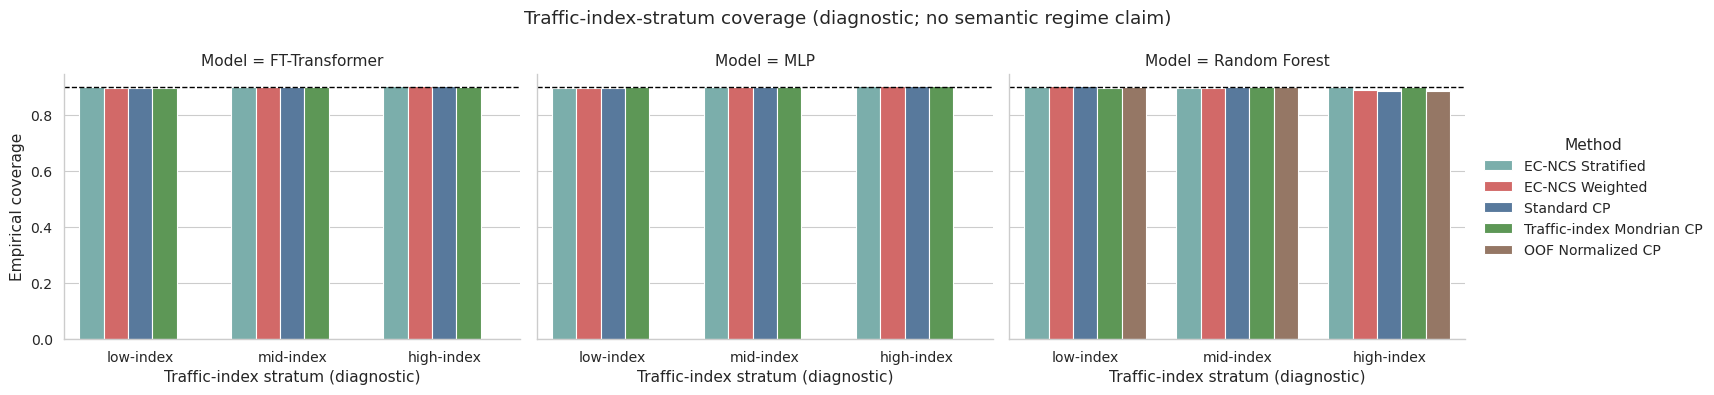

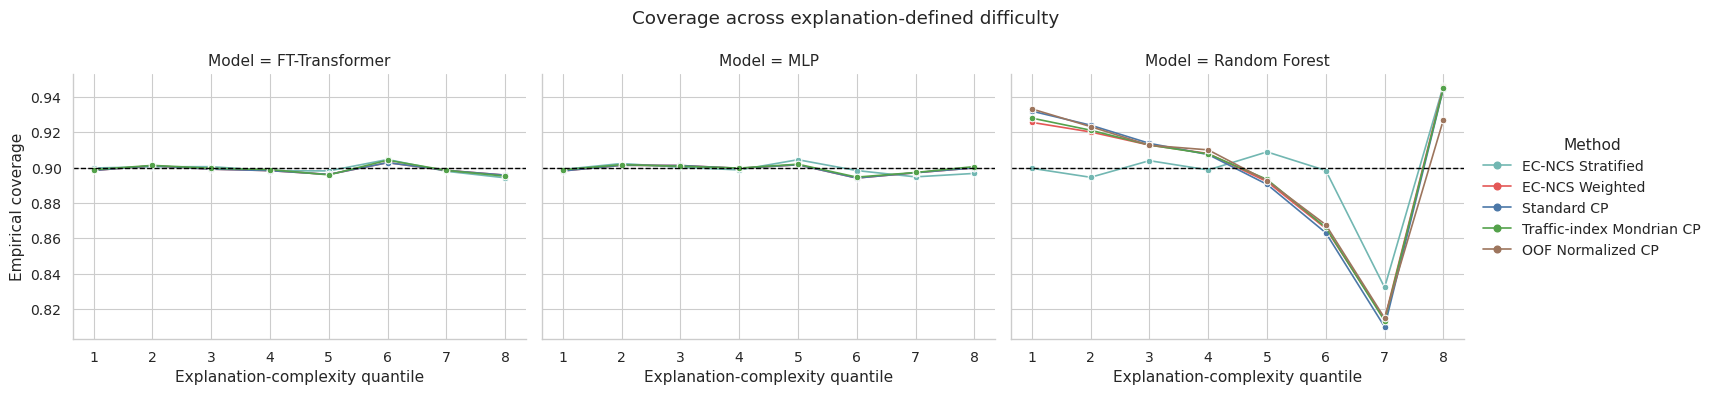

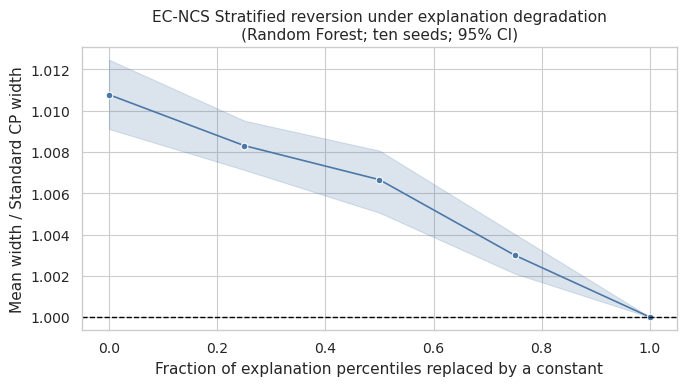

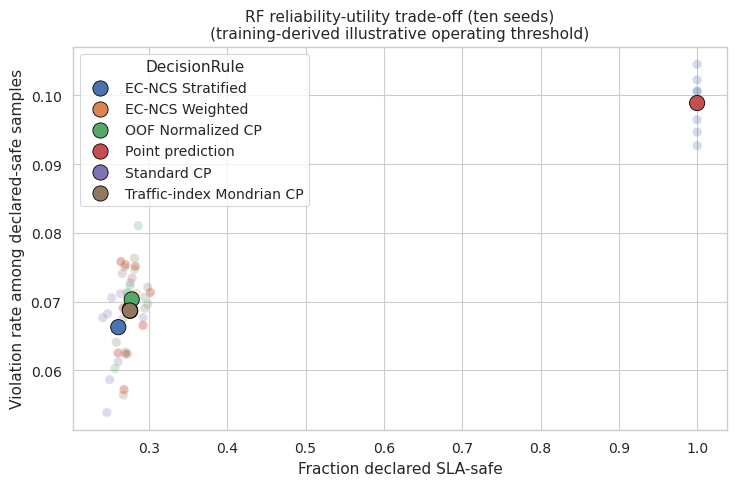

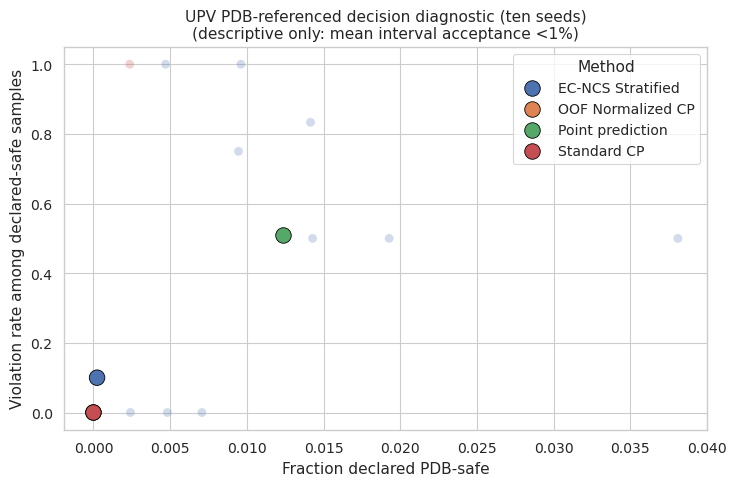

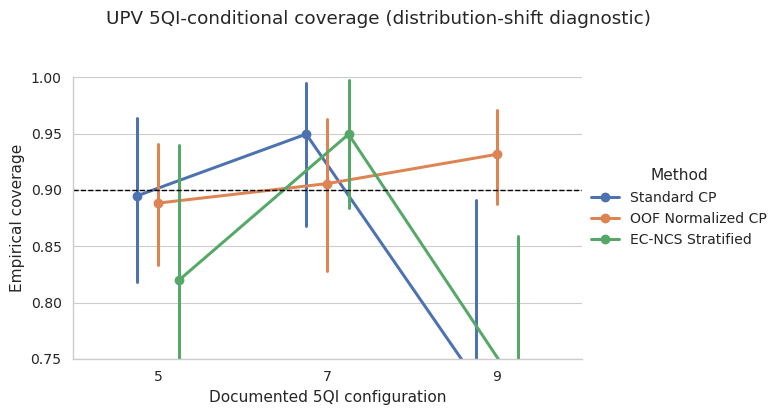

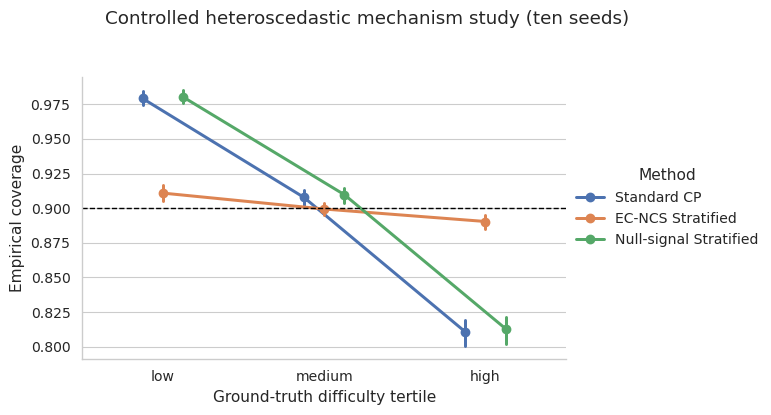

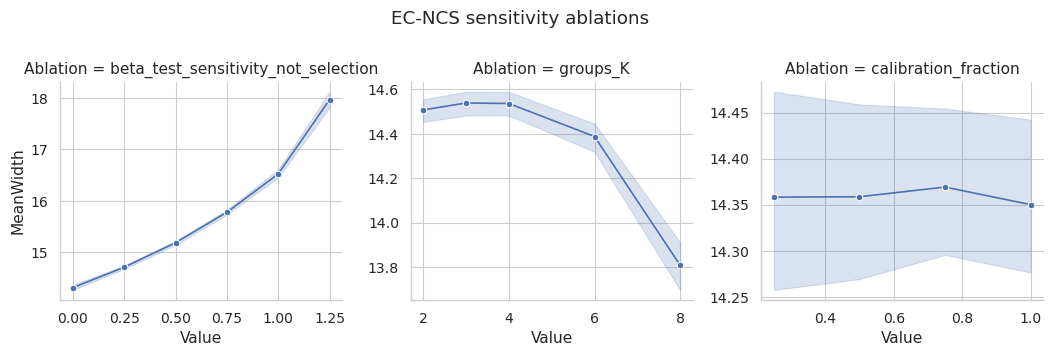

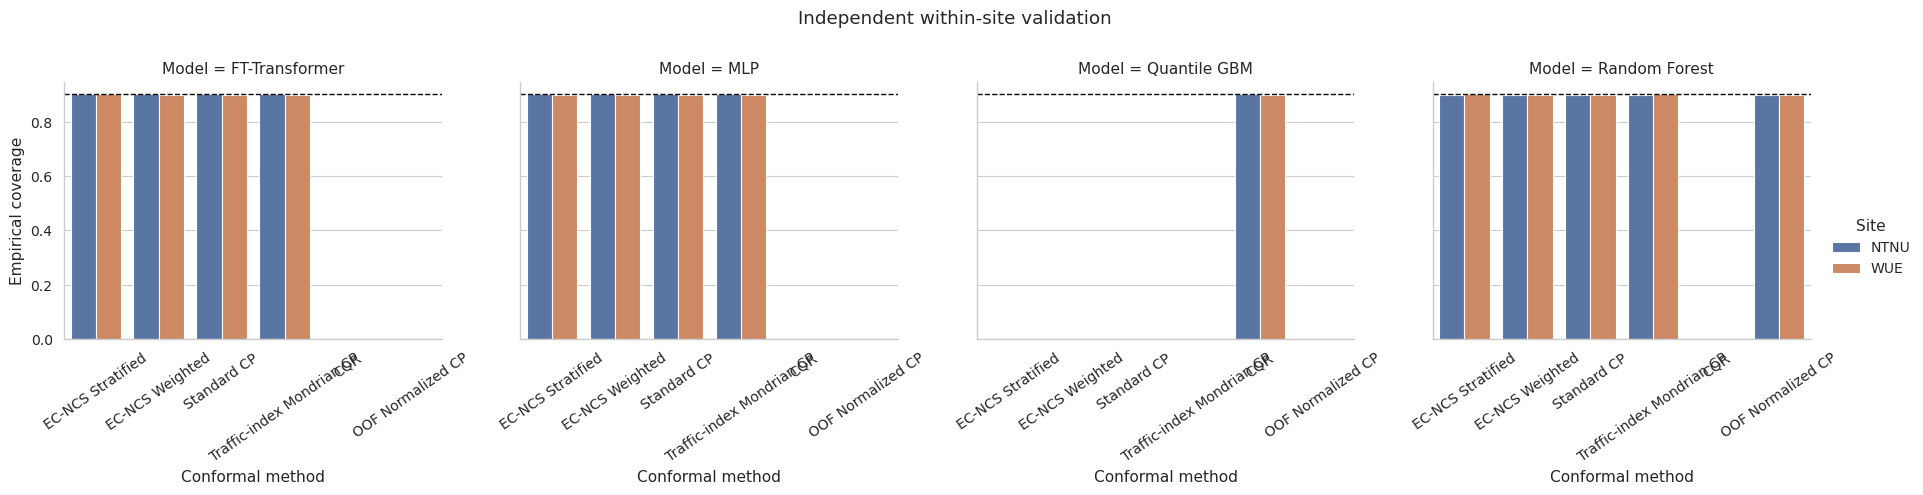

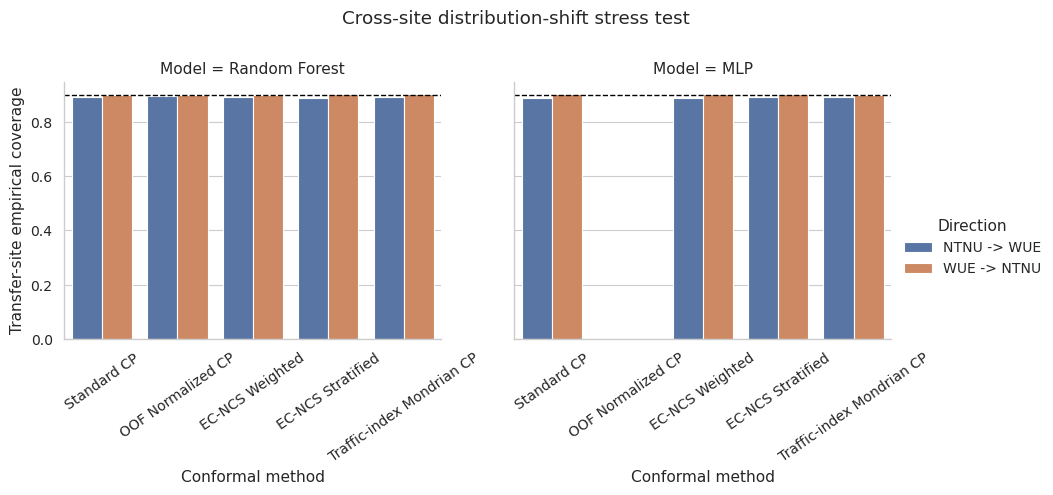

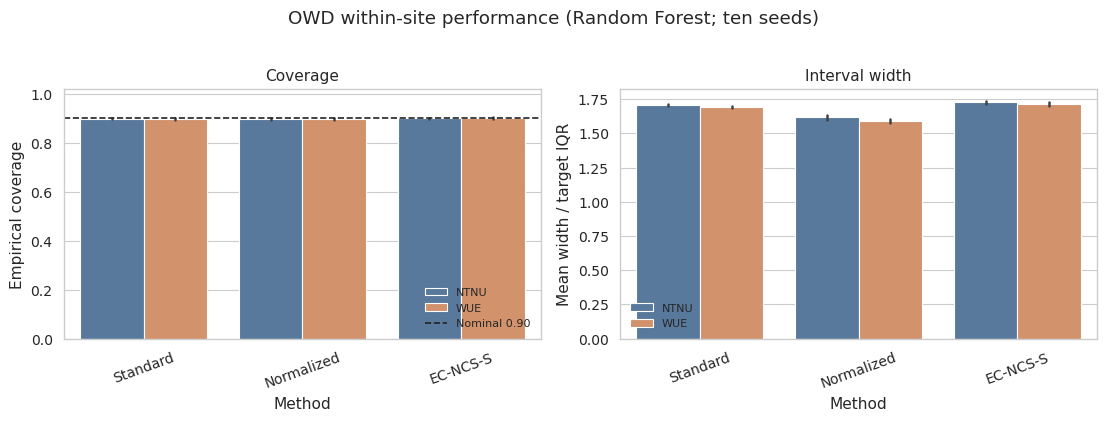

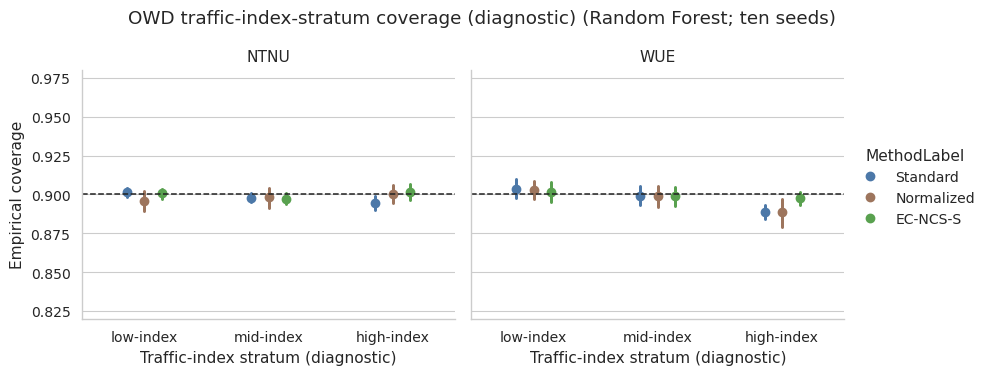

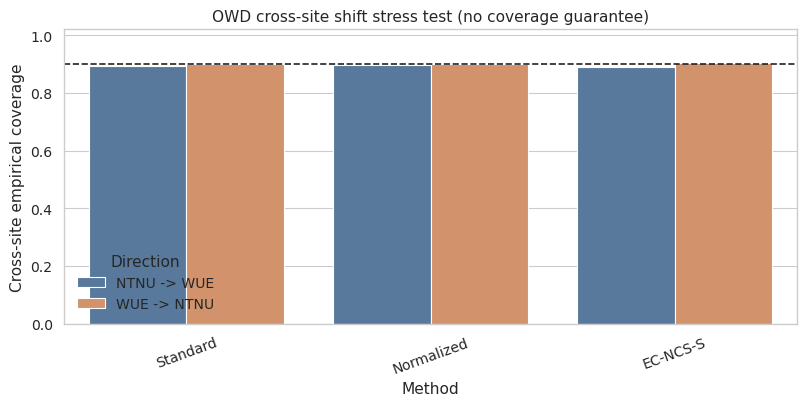

Results archive: /content/ec_ncs_tmlcn_journal_clean_results.zip


,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,Winkler,CorrPhiWidth
0,FT-Transformer,EC-NCS Stratified,0.899268,0.003679,15.326274,0.034831,16.216425,-0.184794
1,FT-Transformer,EC-NCS Weighted,0.898778,0.003349,15.317871,0.035684,16.214227,0.000000
2,FT-Transformer,Standard CP,0.898778,0.003349,15.317871,0.035684,16.214227,0.005708
3,FT-Transformer,Traffic-index Mondrian CP,0.899060,0.003134,15.322031,0.034351,16.215038,0.002396
4,MLP,EC-NCS Stratified,0.899333,0.003457,15.325449,0.028013,16.217945,-0.309818
5,MLP,EC-NCS Weighted,0.899133,0.002602,15.324426,0.024689,16.216654,0.000000
6,MLP,Standard CP,0.899133,0.002602,15.324426,0.024689,16.216654,-0.004417
7,MLP,Traffic-index Mondrian CP,0.899441,0.002803,15.325880,0.025660,16.216968,0.005442
8,Random Forest,EC-NCS Stratified,0.897842,0.004135,14.467620,0.099090,16.427692,0.748305
9,Random Forest,EC-NCS Weighted,0.898059,0.005160,14.350072,0.137323,16.498118,0.100000


,Model,Method,Regime,Coverage,MeanWidth,Undercoverage,N
0,FT-Transformer,EC-NCS Stratified,high-index,0.902134,15.322883,0.000799,2402.2
1,FT-Transformer,EC-NCS Stratified,low-index,0.898408,15.327722,0.002790,5962.2
2,FT-Transformer,EC-NCS Stratified,mid-index,0.898687,15.326591,0.002992,3714.8
3,FT-Transformer,EC-NCS Weighted,high-index,0.901935,15.317871,0.000751,2402.2
4,FT-Transformer,EC-NCS Weighted,low-index,0.897654,15.317871,0.003371,5962.2
5,FT-Transformer,EC-NCS Weighted,mid-index,0.898431,15.317871,0.003023,3714.8
6,FT-Transformer,Standard CP,high-index,0.901935,15.317871,0.000751,2402.2
7,FT-Transformer,Standard CP,low-index,0.897654,15.317871,0.003371,5962.2
8,FT-Transformer,Standard CP,mid-index,0.898431,15.317871,0.003023,3714.8
9,FT-Transformer,Traffic-index Mondrian CP,high-index,0.901183,15.305571,0.002317,2402.2


,Model,Seed,TrainSeconds,BetaTuningSeconds,SelectedBeta,NormalizedCPOOFResidualMean,PredictionSeconds,PredictionMsPerSample,ExplanationCalibrationSeconds,ExplanationTrainingReferenceSeconds,ExplanationTrainingReferenceN,ExplanationTestSeconds,ExplanationMsPerTestSample,ConformalizationSeconds,EndToEndTestMsPerSample,TrainMemoryDeltaMB,PredictionMemoryDeltaMB,ExplanationMemoryDeltaMB
0,FT-Transformer,60.6,7.785518,5.321745,0.000,NaN,0.051479,0.004262,1.304716,0.576680,5000.0,1.371404,0.113486,0.011332,0.118686,0.000000,0.000000,0.054688
1,MLP,60.6,1.532050,2.071005,0.000,NaN,0.010968,0.000909,0.875803,0.374036,5000.0,0.907208,0.075112,0.013819,0.077165,0.011328,0.000000,0.150000
2,Random Forest,60.6,16.497933,10.399681,0.025,3.592452,0.396381,0.032796,1.734051,0.852785,5000.0,1.809153,0.149807,37.628706,3.298135,44.544531,0.017969,101.762500


,Site,Model,Method,Coverage,CoverageSD,MeanWidth,WidthSD,NormalizedMeanWidth,MAE,R2
0,NTNU,FT-Transformer,EC-NCS Stratified,0.901686,0.006020,15.306592,0.072941,1.813708,4.229267,-0.000951
1,NTNU,FT-Transformer,EC-NCS Weighted,0.901997,0.006133,15.313291,0.071741,1.814502,4.229267,-0.000951
2,NTNU,FT-Transformer,Standard CP,0.901997,0.006133,15.313291,0.071741,1.814502,4.229267,-0.000951
3,NTNU,FT-Transformer,Traffic-index Mondrian CP,0.902146,0.005831,15.316604,0.069896,1.814895,4.229267,-0.000951
4,NTNU,MLP,EC-NCS Stratified,0.900847,0.005978,15.295972,0.073754,1.812450,4.231643,-0.002732
5,NTNU,MLP,EC-NCS Weighted,0.900038,0.006734,15.278527,0.070475,1.810383,4.231643,-0.002732
6,NTNU,MLP,Standard CP,0.900038,0.006734,15.278527,0.070475,1.810383,4.231643,-0.002732
7,NTNU,MLP,Traffic-index Mondrian CP,0.900301,0.006452,15.286331,0.075952,1.811307,4.231643,-0.002732
8,NTNU,Quantile GBM,CQR,0.901485,0.004326,13.095533,0.185901,1.551715,NaN,NaN
9,NTNU,Random Forest,EC-NCS Stratified,0.899608,0.003559,14.563961,0.157264,1.725712,3.607582,0.178535


,SourceSite,TargetSite,Model,Method,N,SelectedBeta,MAE,RMSE,R2,GuaranteeStatus,Coverage,Undercoverage,MeanWidth,IntervalEfficiency,CoverageWidthCriterion,MedianWidth,P90Width,Winkler,CorrPhiWidth
0,NTNU,WUE,Random Forest,Standard CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891733,0.008267,14.189611,0.070474,15.362619,14.189611,14.189611,16.526544,0.000000
1,NTNU,WUE,Random Forest,OOF Normalized CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.896967,0.003033,13.482249,0.074172,13.891211,14.457892,16.323426,15.699307,-0.314077
2,NTNU,WUE,Random Forest,EC-NCS Weighted,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.890567,0.009433,14.541217,0.068770,15.912938,14.437207,16.168172,16.528646,1.000000
3,NTNU,WUE,Random Forest,EC-NCS Stratified,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.889767,0.010233,14.234368,0.070253,15.691018,14.069007,15.670839,16.434932,0.499675
4,NTNU,WUE,Random Forest,Traffic-index Mondrian CP,30000,0.25,3.595831,4.419705,0.197567,distribution-shift diagnostic only,0.891700,0.008300,14.180052,0.070522,15.356997,14.208060,14.281037,16.534188,-0.141385
5,NTNU,WUE,MLP,Standard CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220310,15.220310,16.290409,-0.003688
6,NTNU,WUE,MLP,EC-NCS Weighted,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890267,0.009733,15.220309,0.065702,16.701753,15.220309,15.220309,16.290409,0.000000
7,NTNU,WUE,MLP,EC-NCS Stratified,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890533,0.009467,15.227849,0.065669,16.669419,15.249208,15.321251,16.290949,-0.410356
8,NTNU,WUE,MLP,Traffic-index Mondrian CP,30000,0.00,4.275146,4.941520,-0.003097,distribution-shift diagnostic only,0.890900,0.009100,15.230891,0.065656,16.616902,15.199247,15.294075,16.290135,0.084796
9,WUE,NTNU,Random Forest,Standard CP,30000,0.00,3.600976,4.421990,0.182574,distribution-shift diagnostic only,0.900467,0.000000,14.329246,0.069787,14.396116,14.329246,14.329246,16.473127,0.000000


In [ ]:

# Colab-ready dependency bootstrap. Safe to rerun.
import importlib.util
import subprocess
import sys

_required = {
    "shap": "shap>=0.46",
    "captum": "captum>=0.7",
    "openpyxl": "openpyxl>=3.1",
    "pyarrow": "pyarrow>=15",
    "psutil": "psutil>=5.9",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# %%
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
import zipfile
from urllib.parse import quote
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import requests
import seaborn as sns
import shap
import torch
import torch.nn as nn
from captum.attr import GradientShap
from scipy.stats import spearmanr, wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


@dataclass
class Config:
    record_id: str = "13754300"
    sites: Tuple[str, ...] = ("wue", "ntnu")
    target_col: str = "trel"
    max_rows_per_site: int = 30_000
    csv_chunk_size: int = 200_000
    nominal_coverage: float = 0.90
    train_fraction: float = 0.60
    calibration_fraction: float = 0.20
    test_fraction: float = 0.20
    # Final pooled diagnostics (degradation, SLA, latency and pooled CP) use
    # the same ten independent seeds as the primary within-site analysis.
    pooled_diagnostic_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    rf_trees: int = 200
    rf_min_leaf: int = 2
    mlp_epochs: int = 50
    mlp_batch_size: int = 512
    mlp_patience: int = 7
    explanation_batch_size: int = 256
    gradient_shap_samples: int = 4
    max_explanation_train_rows: int = 5_000
    tree_shap_approximate: bool = True
    beta_grid: Tuple[float, ...] = (0.0, 0.25, 0.50, 0.75, 1.00, 1.25)
    beta_inner_fit_fraction: float = 0.60
    beta_inner_calibration_fraction: float = 0.20
    beta_inner_max_rows_per_split: int = 2_000
    beta_coverage_tolerance: float = 0.01
    beta_worst_bin_tolerance: float = 0.03
    normalized_cp_oof_folds: int = 3
    oof_normalized_models: Tuple[str, ...] = ("Random Forest",)
    ec_weight_min: float = 0.35
    ec_weight_max: float = 3.00
    explanation_groups: int = 4
    minimum_group_calibration: int = 50
    regime_minimum_calibration: int = 50
    # New directory prevents incompatible checkpoints from the earlier
    # semantic-regime/weighted-degradation run from being reused.
    # A clean-run directory. If it already exists, the complete directory is
    # moved to a timestamped backup before any experiment starts.
    outdir: str = "/content/ec_ncs_tmlcn_journal_clean_results"
    data_dir: str = "/content/ec_ncs_data"
    force_download: bool = False
    smoke_test: bool = False          # True uses synthetic data and runs quickly
    run_cross_site_transfer: bool = True
    cross_site_models: Tuple[str, ...] = ("Random Forest", "MLP")
    cross_site_seed: int = 2027  # retained for the single fixed transfer diagnostic
    run_within_site_validation: bool = True
    within_site_models: Tuple[str, ...] = ("Random Forest", "MLP", "FT-Transformer")
    within_site_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    explicit_scenario_regime_map: Optional[Dict[str, str]] = None
    # Optional reviewed CSV with exactly two columns: scenario, Regime.
    # Regime values must be normal, transition or congestion.  Supplying this
    # is the only way the code will make semantic network-regime claims.
    explicit_scenario_regime_map_csv: Optional[str] = None
    require_explicit_regime_map: bool = False
    sla_threshold: Optional[float] = None  # replace with a domain-supported delay threshold
    # Documented 5QI/resource-allocation validation dataset.
    run_upv_5qi_validation: bool = True
    upv_record_id: str = "18410980"
    upv_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    upv_minimum_group_calibration: int = 20
    # UPV has six independent Test|UE|Direction groups per 5QI.  Assigning
    # 4/1/1 groups per 5QI to train/calibration/test keeps all three documented
    # 5QI classes in every partition while preserving strict group separation.
    upv_groups_per_5qi_split: Tuple[int, int, int] = (4, 1, 1)
    # Controlled mechanism experiment; ground-truth difficulty is known.
    run_controlled_mechanism_study: bool = True
    synthetic_seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)

CFG = Config()
SCRIPT_REVISION = "2026-08-10-r4-balanced-upv-clean-full-run"

if CFG.explicit_scenario_regime_map_csv is not None:
    regime_map_frame = pd.read_csv(CFG.explicit_scenario_regime_map_csv)
    required_map_columns = {"scenario", "Regime"}
    if not required_map_columns.issubset(regime_map_frame.columns):
        raise ValueError(
            "The expert regime-map CSV must contain columns: scenario, Regime")
    if regime_map_frame["scenario"].duplicated().any():
        raise ValueError("The expert regime-map CSV contains duplicate scenarios.")
    CFG.explicit_scenario_regime_map = dict(zip(
        regime_map_frame["scenario"].astype(str),
        regime_map_frame["Regime"].astype(str).str.lower()
    ))
ALPHA = 1.0 - CFG.nominal_coverage

# Semantic regime names are used only when every scenario has been mapped by
# networking-domain review.  Otherwise the code reports train-fitted,
# observable-feature traffic-index strata and never calls them congestion
# regimes.
HAS_EXPERT_REGIME_MAP = CFG.explicit_scenario_regime_map is not None
REGIME_ORDER = (["normal", "transition", "congestion"] if HAS_EXPERT_REGIME_MAP
                else ["low-index", "mid-index", "high-index"])
REGIME_AXIS_LABEL = ("Network regime" if HAS_EXPERT_REGIME_MAP
                     else "Traffic-index stratum (diagnostic)")
REGIME_FIGURE_TITLE = ("OWD regime-wise coverage" if HAS_EXPERT_REGIME_MAP
                       else "OWD traffic-index-stratum coverage (diagnostic)")
REGIME_CP_NAME = ("Regime Mondrian CP" if HAS_EXPERT_REGIME_MAP
                  else "Traffic-index Mondrian CP")
OUTDIR = Path(CFG.outdir)
DATA_DIR = Path(CFG.data_dir)
# Run every experiment from scratch while preserving earlier results. Dataset
# downloads remain cached in DATA_DIR because they are immutable source data;
# no model, split, metric or result checkpoint is reused.
if OUTDIR.exists():
    _backup_stamp = time.strftime("%Y%m%d_%H%M%S")
    _backup_dir = OUTDIR.with_name(f"{OUTDIR.name}_backup_{_backup_stamp}")
    _backup_counter = 1
    while _backup_dir.exists():
        _backup_dir = OUTDIR.with_name(
            f"{OUTDIR.name}_backup_{_backup_stamp}_{_backup_counter}")
        _backup_counter += 1
    shutil.move(str(OUTDIR), str(_backup_dir))
    print("Previous output preserved at:", _backup_dir)
OUTDIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
MAIN_FIG_DIR = OUTDIR / "main_paper_figures"
SUPP_DIR = OUTDIR / "supplementary"
CHECKPOINT_DIR = OUTDIR / "checkpoints"
for _directory in (MAIN_FIG_DIR, SUPP_DIR, CHECKPOINT_DIR):
    _directory.mkdir(parents=True, exist_ok=True)
print(CFG)
print("Script revision:", SCRIPT_REVISION)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conformal_quantile(scores: Sequence[float], alpha: float) -> float:
    """Finite-sample split-conformal quantile using the higher order statistic."""
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    if scores.size == 0:
        raise ValueError("No finite calibration scores.")
    level = min(1.0, np.ceil((scores.size + 1) * (1.0 - alpha)) / scores.size)
    return float(np.quantile(scores, level, method="higher"))


class TrainECDF:
    """Pointwise rank transform fitted only on training explanations."""
    def fit(self, values: Sequence[float]):
        self.sorted_ = np.sort(np.asarray(values, dtype=float))
        return self

    def transform(self, values: Sequence[float]) -> np.ndarray:
        values = np.asarray(values, dtype=float)
        return np.searchsorted(self.sorted_, values, side="right") / max(len(self.sorted_), 1)


def bootstrap_ci(values: Sequence[float], fn=np.mean, seed: int = 0,
                 n_boot: int = 500, level: float = 0.95) -> Tuple[float, float]:
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    draws = [fn(values[rng.integers(0, len(values), len(values))]) for _ in range(n_boot)]
    tail = (1.0 - level) / 2.0
    return tuple(np.quantile(draws, [tail, 1.0 - tail]))


def interval_metrics(y: np.ndarray, lo: np.ndarray, hi: np.ndarray,
                     alpha: float, phi: Optional[np.ndarray] = None) -> Dict[str, float]:
    y, lo, hi = map(lambda z: np.asarray(z, dtype=float), (y, lo, hi))
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    below = np.maximum(lo - y, 0.0)
    above = np.maximum(y - hi, 0.0)
    winkler = width + (2.0 / alpha) * (below + above)
    corr = 0.0
    if phi is not None and np.std(width) > 1e-12:
        corr = float(spearmanr(phi, width).correlation)
        if not np.isfinite(corr):
            corr = 0.0
    mean_width = float(width.mean())
    coverage = float(covered.mean())
    return {
        "Coverage": coverage,
        "Undercoverage": float(max(0.0, (1.0 - alpha) - coverage)),
        "MeanWidth": mean_width,
        "IntervalEfficiency": float(1.0 / max(mean_width, 1e-12)),
        "CoverageWidthCriterion": float(mean_width * (1.0 + 10.0 * abs(coverage - (1.0-alpha)))),
        "MedianWidth": float(np.median(width)),
        "P90Width": float(np.quantile(width, 0.90)),
        "Winkler": float(winkler.mean()),
        "CorrPhiWidth": corr,
    }


def timed_call(fn, *args, synchronize_gpu: bool = True, **kwargs):
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    if synchronize_gpu and torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    mem_after = process.memory_info().rss
    return out, elapsed, max(0, mem_after - mem_before) / 2**20


def zenodo_metadata(record_id: str) -> Mapping:
    cache_path = DATA_DIR / f"zenodo_metadata_{record_id}.json"
    for attempt in range(6):
        try:
            response = requests.get(
                f"https://zenodo.org/api/records/{record_id}", timeout=180,
                headers={"User-Agent": "EC-NCS-research/1.0"},
            )
            response.raise_for_status()
            payload = response.json()
            cache_path.write_text(json.dumps(payload))
            return payload
        except requests.RequestException as error:
            if cache_path.exists():
                print(f"Zenodo API unavailable; using cached metadata: {error}")
                return json.loads(cache_path.read_text())
            if attempt < 5:
                wait = min(60, 5 * (2 ** attempt))
                print(f"Zenodo metadata attempt {attempt+1} failed; retrying in {wait}s")
                time.sleep(wait)
    print("Zenodo metadata unavailable; using documented OWD filenames.")
    return {"files": [
        {"key": "wue_owd_Packets_with_IATs.csv", "links": {}},
        {"key": "ntnu_owd_Packets_with_IATs.csv", "links": {}},
    ]}


def choose_owd_file(metadata: Mapping, site: str) -> Mapping:
    site = site.lower()
    files = metadata.get("files", [])
    ranked = []
    for item in files:
        name = item.get("key", "").lower()
        score = 0
        score += 8 if site in name else 0
        score += 8 if "owd" in name else 0
        score += 4 if "with_iats" in name else 0
        score -= 5 if "tput" in name else 0
        score += 2 if name.endswith(".csv") else 0
        ranked.append((score, item))
    ranked.sort(key=lambda z: z[0], reverse=True)
    if not ranked or ranked[0][0] < 12:
        available = [f.get("key") for f in files]
        raise FileNotFoundError(f"No suitable {site} OWD CSV. Available: {available}")
    return ranked[0][1]


def stream_download(item: Mapping, destination: Path, force: bool = False) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and not force:
        return destination
    file_name = item["key"]
    urls = []
    if item.get("links", {}).get("self"):
        urls.append(item["links"]["self"])
    urls.append(
        f"https://zenodo.org/records/{CFG.record_id}/files/{quote(file_name)}?download=1"
    )
    temporary = Path(str(destination) + ".part")
    last_error = None
    for url in urls:
        for attempt in range(5):
            try:
                headers = {}
                mode = "wb"
                if temporary.exists() and temporary.stat().st_size > 0:
                    headers["Range"] = f"bytes={temporary.stat().st_size}-"
                    mode = "ab"
                with requests.get(url, stream=True, timeout=300, headers=headers) as response:
                    if response.status_code == 200 and mode == "ab":
                        mode = "wb"  # server ignored Range; restart safely
                    response.raise_for_status()
                    with temporary.open(mode) as handle:
                        for chunk in response.iter_content(chunk_size=2**20):
                            if chunk:
                                handle.write(chunk)
                os.replace(temporary, destination)
                return destination
            except requests.RequestException as error:
                last_error = error
                wait = min(60, 5 * (2 ** attempt))
                print(f"Download attempt {attempt+1} failed for {file_name}; retrying in {wait}s")
                time.sleep(wait)
    raise RuntimeError(f"Could not download {file_name}: {last_error}")
    return destination


def synthetic_5g(n: int = 12_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    load = rng.uniform(0, 1, n)
    scenario = pd.cut(load, [-1, .35, .70, 2], labels=["normal", "transition", "congestion"])
    packet_size = rng.choice([128, 256, 512, 1024, 1500], n)
    iat = rng.lognormal(-2.0 + 1.2 * load, .35, n)
    ratio = rng.uniform(.1, 1.0, n)
    noise = rng.normal(0, .12 + .55 * load**2, n)
    trel = 0.15 + 1.1 * load + .00025 * packet_size + .15 * ratio + noise
    return pd.DataFrame({"PacketSize": packet_size, "iat": iat, "ratio": ratio,
                         "scenario": scenario.astype(str), "rep": rng.integers(0, 30, n),
                         "trel": trel})


def uniform_chunk_sample_csv(path: Path, sample_size: int, seed: int,
                             chunksize: int = 200_000) -> Tuple[pd.DataFrame, Dict[str, int]]:
    """Exact uniform random-key reservoir sample over every data row in a CSV.

    Independent continuous priorities give every row equal inclusion probability and avoid
    the ordered-prefix bias caused by pd.read_csv(..., nrows=sample_size).
    """
    rng = np.random.default_rng(seed)
    reservoir = None
    seen = 0
    for chunk_id, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False)):
        chunk.columns = chunk.columns.astype(str).str.strip()
        seen += len(chunk)
        chunk["__uniform_priority__"] = rng.random(len(chunk))
        candidates = chunk if reservoir is None else pd.concat([reservoir, chunk], ignore_index=True)
        reservoir = candidates.nsmallest(min(sample_size, len(candidates)), "__uniform_priority__")
        if (chunk_id + 1) % 10 == 0:
            print(f"  scanned {seen:,} rows from {path.name}")
    sampled = reservoir.drop(columns="__uniform_priority__").reset_index(drop=True)
    return sampled, {"RowsScanned": seen, "RowsSampled": len(sampled),
                     "SamplingSeed": seed, "ChunkSize": chunksize}


sampling_rows, selected_files = [], {}
site_frames = []
if CFG.smoke_test:
    for i, site in enumerate(CFG.sites):
        frame = synthetic_5g(seed=42+i)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": "synthetic smoke test",
                              "RowsScanned": len(frame), "RowsSampled": len(frame),
                              "SamplingSeed": 42+i, "ChunkSize": np.nan})
        selected_files[site] = "synthetic smoke test"
else:
    metadata = zenodo_metadata(CFG.record_id)
    for i, site in enumerate(CFG.sites):
        selected = choose_owd_file(metadata, site)
        selected_path = DATA_DIR / Path(selected["key"]).name
        selected_path = stream_download(selected, selected_path, CFG.force_download)
        print(f"Uniformly sampling the complete {site.upper()} file: {selected_path.name}")
        frame, audit = uniform_chunk_sample_csv(selected_path, CFG.max_rows_per_site,
                                                seed=2027+i, chunksize=CFG.csv_chunk_size)
        frame["DatasetSite"] = site.upper()
        site_frames.append(frame)
        sampling_rows.append({"Site": site.upper(), "File": selected_path.name, **audit})
        selected_files[site] = str(selected_path)

raw_df = pd.concat(site_frames, ignore_index=True)
sampling_audit_df = pd.DataFrame(sampling_rows)
sampling_audit_df["SamplingFraction"] = sampling_audit_df.RowsSampled / sampling_audit_df.RowsScanned
sampling_audit_df.to_csv(OUTDIR / "sampling_audit.csv", index=False)
raw_df.columns = raw_df.columns.astype(str).str.strip()
print("Selected files:", selected_files)
print("Shape:", raw_df.shape)
display(sampling_audit_df)
display(raw_df.groupby("DatasetSite", observed=True).size().rename("SampledRows"))
display(raw_df.head())
print(raw_df.dtypes)


DROP_COLUMNS = {
    "Unnamed: 0", "src", "Timestamp", "SourceIPOuter", "DestinationIPOuter",
    "SourceIPInner", "DestinationIPInner", "SeqNum", "DatasetSite",
    # Retained in clean_df for splitting/auditing, but never supplied to a model.
    "scenario", "rep"
}


def audit_and_clean(df: pd.DataFrame, target_col: str):
    if target_col not in df.columns:
        raise ValueError(f"Target {target_col!r} missing. Available columns: {df.columns.tolist()}")
    work = df.copy()
    work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan).dropna(subset=[target_col]).drop_duplicates()
    candidate = [c for c in work.columns if c != target_col and c not in DROP_COLUMNS]
    audit_rows = []
    selected = []
    for col in work.columns:
        missing = float(work[col].isna().mean())
        nunique = int(work[col].nunique(dropna=True))
        reason = "included"
        include = col in candidate and missing <= .50 and nunique > 1
        if col == target_col: reason = "target"
        elif col in DROP_COLUMNS: reason = "identifier/sequence leakage risk"
        elif missing > .50: reason = ">50% missing"
        elif nunique <= 1: reason = "constant"
        elif include: selected.append(col)
        audit_rows.append({"Feature": col, "Dtype": str(work[col].dtype),
                           "MissingFraction": missing, "UniqueValues": nunique,
                           "Included": include, "Reason": reason})
    return work, selected, pd.DataFrame(audit_rows)


clean_df, feature_columns, feature_audit = audit_and_clean(raw_df, CFG.target_col)
feature_audit.to_csv(OUTDIR / "feature_audit.csv", index=False)
display(feature_audit)
print("Included features:", feature_columns)


def scenario_to_regime(values: pd.Series) -> Optional[pd.Series]:
    text = values.astype(str).str.lower()
    out = pd.Series(index=values.index, dtype="object")
    patterns = {
        "normal": r"normal|stable|baseline|idle|low",
        "transition": r"transition|medium|moderate|ramp|bursty",
        "congestion": r"congest|overload|heavy|high|stress"
    }
    for label, pattern in patterns.items():
        out[text.str.contains(pattern, regex=True, na=False)] = label
    return out if out.notna().mean() >= .70 else None


if "scenario" in clean_df.columns:
    scenario_inventory = (clean_df.groupby(["DatasetSite", "scenario"], observed=True)
                          .size().rename("N").reset_index())
    # Inventory only: the script must not manufacture semantic regimes from
    # filenames.  A networking expert can review this CSV and then populate
    # CFG.explicit_scenario_regime_map.
    scenario_inventory["SuggestedRegime"] = "REVIEW_REQUIRED"
    scenario_inventory.to_csv(OUTDIR / "scenario_regime_inventory.csv", index=False)
    expert_map_template = (scenario_inventory[["scenario"]].drop_duplicates()
                           .sort_values("scenario").reset_index(drop=True))
    expert_map_template["Regime"] = ""
    expert_map_template.to_csv(OUTDIR / "expert_regime_map_template.csv", index=False)
    display(scenario_inventory)
    print("For the paper, populate CFG.explicit_scenario_regime_map and set "
          "CFG.require_explicit_regime_map=True after domain review.")


REGIME_FEATURE_HINTS = ["ratio", "pdist", "pnpak", "piat", "iat", "packetsize", "bw", "slots"]


class RegimeAssigner:
    def fit(self, X: pd.DataFrame):
        if "scenario" in X.columns:
            if CFG.explicit_scenario_regime_map is not None:
                allowed = {"normal", "transition", "congestion"}
                if not set(CFG.explicit_scenario_regime_map.values()).issubset(allowed):
                    raise ValueError(f"Regime-map values must be in {allowed}")
                observed = set(X["scenario"].astype(str).unique())
                missing = observed - set(CFG.explicit_scenario_regime_map)
                if missing:
                    raise ValueError(f"Explicit regime map misses scenario labels: {sorted(missing)}")
                self.mode_ = "explicit scenario mapping"
                self.scenario_map_ = dict(CFG.explicit_scenario_regime_map)
                return self
            if CFG.require_explicit_regime_map:
                raise ValueError("Populate CFG.explicit_scenario_regime_map after inspecting scenario labels.")
            # Never infer semantic network regimes from scenario-name keywords.
            # Such labels require an explicit, reviewed mapping above.
        numeric = X.select_dtypes(include=np.number)
        cols = [c for c in numeric.columns if any(h in c.lower() for h in REGIME_FEATURE_HINTS)]
        if not cols:
            cols = numeric.columns.tolist()
        self.mode_ = "train-fitted traffic index"
        self.cols_ = cols
        self.center_ = numeric[cols].median()
        self.scale_ = (numeric[cols].quantile(.75) - numeric[cols].quantile(.25)).replace(0, 1.0)
        score = ((numeric[cols] - self.center_) / self.scale_).abs().mean(axis=1)
        self.thresholds_ = tuple(score.quantile([.50, .80]))
        return self

    def transform(self, X: pd.DataFrame) -> pd.Series:
        if self.mode_ in {"scenario labels", "explicit scenario mapping"}:
            mapped = X["scenario"].astype(str).map(self.scenario_map_)
            if mapped.isna().any() and self.mode_ == "explicit scenario mapping":
                missing = sorted(X.loc[mapped.isna(), "scenario"].astype(str).unique())
                raise ValueError(f"Unmapped scenarios during transform: {missing}")
            return mapped.fillna("transition")
        numeric = X[self.cols_].apply(pd.to_numeric, errors="coerce").fillna(self.center_)
        score = ((numeric - self.center_) / self.scale_).abs().mean(axis=1)
        return pd.cut(score, [-np.inf, self.thresholds_[0], self.thresholds_[1], np.inf],
                      labels=REGIME_ORDER).astype(str)


def make_groups(df: pd.DataFrame) -> Optional[pd.Series]:
    group_cols = [c for c in ["DatasetSite", "scenario", "rep", "gnb", "sdr"] if c in df.columns]
    if not group_cols:
        return None
    groups = df[group_cols].astype(str).agg("|".join, axis=1)
    return groups if groups.nunique() >= 10 else None


def three_way_split(df: pd.DataFrame, seed: int):
    groups = make_groups(df)
    indices = np.arange(len(df))
    if groups is not None:
        first = GroupShuffleSplit(n_splits=1, train_size=CFG.train_fraction, random_state=seed)
        train_idx, rest_idx = next(first.split(indices, groups=groups))
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        second = GroupShuffleSplit(n_splits=1, test_size=relative_test, random_state=seed + 1)
        cal_rel, test_rel = next(second.split(rest_idx, groups=groups.iloc[rest_idx]))
        cal_idx, test_idx = rest_idx[cal_rel], rest_idx[test_rel]
        strategy = "group-disjoint"
    else:
        train_idx, rest_idx = train_test_split(indices, train_size=CFG.train_fraction, random_state=seed)
        relative_test = CFG.test_fraction / (CFG.calibration_fraction + CFG.test_fraction)
        cal_idx, test_idx = train_test_split(rest_idx, test_size=relative_test, random_state=seed + 1)
        strategy = "random fallback"
    return train_idx, np.asarray(cal_idx), np.asarray(test_idx), strategy


def split_overlap_report(df, train_idx, cal_idx, test_idx):
    groups = make_groups(df)
    if groups is None:
        return {"TrainCalGroupOverlap": np.nan, "TrainTestGroupOverlap": np.nan,
                "CalTestGroupOverlap": np.nan}
    sets = [set(groups.iloc[idx]) for idx in [train_idx, cal_idx, test_idx]]
    return {"TrainCalGroupOverlap": len(sets[0] & sets[1]),
            "TrainTestGroupOverlap": len(sets[0] & sets[2]),
            "CalTestGroupOverlap": len(sets[1] & sets[2])}


def build_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    numeric = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                                   min_frequency=2))]), categorical),
    ], remainder="drop", verbose_feature_names_out=True)


class ResidualMLP(nn.Module):
    def __init__(self, n_features: int):
        super().__init__()
        width = min(256, max(64, 4 * n_features))
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.BatchNorm1d(width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width), nn.GELU(), nn.Dropout(.10),
            nn.Linear(width, width // 2), nn.GELU(),
            nn.Linear(width // 2, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


class FTTransformerRegressor(nn.Module):
    """FT-Transformer-style regressor with one learned token per transformed feature."""
    def __init__(self, n_features: int, d_token: int = 32, n_heads: int = 4,
                 n_layers: int = 3):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_token) * .02)
        self.bias = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads,
                                           dim_feedforward=4*d_token, dropout=.10,
                                           activation="gelu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(encoded[:, 0]).squeeze(-1)


class TorchRegressor:
    def __init__(self, seed: int, architecture: str = "mlp"):
        self.seed = seed
        self.architecture = architecture
    def fit(self, X, y):
        set_seed(self.seed)
        X = np.asarray(X, np.float32); y = np.asarray(y, np.float32)
        split = int(.85 * len(X))
        rng = np.random.default_rng(self.seed)
        order = rng.permutation(len(X)); fit_idx, val_idx = order[:split], order[split:]
        self.y_mean_, self.y_std_ = float(y[fit_idx].mean()), float(y[fit_idx].std() + 1e-8)
        yz = (y - self.y_mean_) / self.y_std_
        self.model = (ResidualMLP(X.shape[1]) if self.architecture == "mlp"
                      else FTTransformerRegressor(X.shape[1])).to(DEVICE)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=.5)
        loss_fn = nn.SmoothL1Loss()
        best, best_state, bad = np.inf, None, 0
        for epoch in range(CFG.mlp_epochs):
            self.model.train()
            for start in range(0, len(fit_idx), CFG.mlp_batch_size):
                batch = fit_idx[start:start + CFG.mlp_batch_size]
                # BatchNorm cannot estimate batch statistics from one sample.
                # Skipping only a singleton tail batch avoids seed-dependent crashes;
                # all preceding shuffled observations are still used normally.
                if len(batch) < 2:
                    continue
                xb = torch.tensor(X[batch], device=DEVICE)
                yb = torch.tensor(yz[batch], device=DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = loss_fn(self.model(xb), yb)
                loss.backward(); optimizer.step()
            self.model.eval()
            with torch.no_grad():
                xv = torch.tensor(X[val_idx], device=DEVICE)
                yv = torch.tensor(yz[val_idx], device=DEVICE)
                val = float(loss_fn(self.model(xv), yv).item())
            scheduler.step(val)
            if val < best - 1e-5:
                best, bad = val, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= CFG.mlp_patience: break
        self.model.load_state_dict(best_state)
        return self
    def predict(self, X):
        self.model.eval(); X = np.asarray(X, np.float32); pieces = []
        with torch.no_grad():
            for start in range(0, len(X), CFG.mlp_batch_size):
                xb = torch.tensor(X[start:start + CFG.mlp_batch_size], device=DEVICE)
                pieces.append(self.model(xb).cpu().numpy())
        return np.concatenate(pieces) * self.y_std_ + self.y_mean_


def build_model(name: str, seed: int):
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=CFG.rf_trees, min_samples_leaf=CFG.rf_min_leaf,
                                     random_state=seed, n_jobs=-1)
    if name == "MLP":
        return TorchRegressor(seed, "mlp")
    if name == "FT-Transformer":
        return TorchRegressor(seed, "transformer")
    raise KeyError(name)


def tree_shap_strength(model, X: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    values = np.asarray(explainer.shap_values(
        X,
        approximate=CFG.tree_shap_approximate,
        check_additivity=False,
    ))
    return np.abs(values).sum(axis=1), values


def gradient_shap_strength(model: TorchRegressor, X: np.ndarray,
                           background: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    model.model.eval()
    gs = GradientShap(model.model)
    baseline = torch.tensor(background.astype(np.float32), device=DEVICE)
    strengths, attrs = [], []
    for start in range(0, len(X), CFG.explanation_batch_size):
        xb = torch.tensor(X[start:start + CFG.explanation_batch_size].astype(np.float32),
                          device=DEVICE, requires_grad=True)
        attribution = gs.attribute(xb, baselines=baseline,
                                   n_samples=CFG.gradient_shap_samples, stdevs=0.01)
        arr = attribution.detach().cpu().numpy() * model.y_std_
        attrs.append(arr); strengths.append(np.abs(arr).sum(axis=1))
    return np.concatenate(strengths), np.vstack(attrs)


def explain(model_name, model, X, background):
    if model_name == "Random Forest":
        return tree_shap_strength(model, X)
    return gradient_shap_strength(model, X, background)


def explanation_reference(X_train: np.ndarray, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    """Uniform bounded training reference for the explanation ECDF.

    Calibration and test explanations are still computed for every observation.
    Bounding only the training reference removes the dominant unnecessary SHAP cost.
    """
    rng = np.random.default_rng(seed + 1000)
    n = min(CFG.max_explanation_train_rows, len(X_train))
    idx = rng.choice(len(X_train), size=n, replace=False)
    return X_train[idx], idx


def _bounded_indices(indices: np.ndarray, maximum: int, seed: int) -> np.ndarray:
    indices = np.asarray(indices)
    if len(indices) <= maximum:
        return indices
    return np.random.default_rng(seed).choice(indices, size=maximum, replace=False)


def tune_beta_on_inner_training(model_name: str, X_train: np.ndarray,
                                y_train: np.ndarray, seed: int):
    """Select beta without outer calibration or test labels.

    The outer training partition is split into inner-fit, inner-calibration and
    inner-validation subsets. A temporary predictor is trained on inner-fit.
    Candidate beta values are calibrated on inner-calibration and ranked on
    inner-validation. Feasible candidates must meet both overall and worst
    explanation-tertile coverage tolerances; among them, the narrowest interval
    is selected. If none is feasible, a prespecified penalized objective is used.
    """
    all_idx = np.arange(len(X_train))
    fit_idx, remainder = train_test_split(
        all_idx, train_size=CFG.beta_inner_fit_fraction, random_state=seed + 3100
    )
    inner_cal_fraction = CFG.beta_inner_calibration_fraction / (
        1.0 - CFG.beta_inner_fit_fraction
    )
    cal_idx, val_idx = train_test_split(
        remainder, train_size=inner_cal_fraction, random_state=seed + 3101
    )
    cal_idx = _bounded_indices(cal_idx, CFG.beta_inner_max_rows_per_split, seed + 3102)
    val_idx = _bounded_indices(val_idx, CFG.beta_inner_max_rows_per_split, seed + 3103)

    temporary_model = build_model(model_name, seed + 3000).fit(
        X_train[fit_idx], y_train[fit_idx]
    )
    pred_cal = temporary_model.predict(X_train[cal_idx])
    pred_val = temporary_model.predict(X_train[val_idx])

    rng = np.random.default_rng(seed + 3104)
    fit_reference_idx = _bounded_indices(
        fit_idx, min(CFG.max_explanation_train_rows, 2_000), seed + 3105
    )
    background_idx = rng.choice(fit_idx, size=min(64, len(fit_idx)), replace=False)
    phi_fit, _ = explain(
        model_name, temporary_model, X_train[fit_reference_idx], X_train[background_idx]
    )
    phi_cal, _ = explain(
        model_name, temporary_model, X_train[cal_idx], X_train[background_idx]
    )
    phi_val, _ = explain(
        model_name, temporary_model, X_train[val_idx], X_train[background_idx]
    )

    ecdf = TrainECDF().fit(phi_fit)
    z_cal, z_val = ecdf.transform(phi_cal), ecdf.transform(phi_val)
    residual_cal = np.abs(y_train[cal_idx] - pred_cal)
    target_scale = max(float(np.subtract(*np.quantile(y_train[fit_idx], [.75, .25]))), 1e-8)
    tertiles = pd.qcut(z_val, q=3, labels=False, duplicates="drop")
    tuning_rows = []

    for beta in CFG.beta_grid:
        w_cal = np.clip(1.0 + beta * (z_cal - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        w_val = np.clip(1.0 + beta * (z_val - .5),
                        CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residual_cal / w_cal, ALPHA)
        lower, upper = pred_val - q * w_val, pred_val + q * w_val
        covered = (y_train[val_idx] >= lower) & (y_train[val_idx] <= upper)
        coverage = float(covered.mean())
        bin_coverages = [float(covered[np.asarray(tertiles == group)].mean())
                         for group in pd.unique(tertiles)]
        worst_bin = min(bin_coverages) if bin_coverages else coverage
        mean_width = float(np.mean(upper - lower))
        feasible = (
            coverage >= CFG.nominal_coverage - CFG.beta_coverage_tolerance
            and worst_bin >= CFG.nominal_coverage - CFG.beta_worst_bin_tolerance
        )
        objective = (
            mean_width / target_scale
            + 20.0 * max(0.0, CFG.nominal_coverage - coverage) ** 2
            + 10.0 * max(0.0, CFG.nominal_coverage - worst_bin) ** 2
        )
        tuning_rows.append({
            "Seed": seed, "Model": model_name, "Beta": beta,
            "InnerFitN": len(fit_idx), "InnerCalibrationN": len(cal_idx),
            "InnerValidationN": len(val_idx), "Coverage": coverage,
            "WorstExplanationTertileCoverage": worst_bin,
            "MeanWidth": mean_width, "NormalizedWidth": mean_width / target_scale,
            "Feasible": feasible, "Objective": objective,
        })

    tuning_frame = pd.DataFrame(tuning_rows)
    feasible_frame = tuning_frame[tuning_frame.Feasible]
    if len(feasible_frame):
        selected_row = feasible_frame.sort_values(
            ["NormalizedWidth", "Objective", "Beta"]
        ).iloc[0]
        selection_rule = "minimum normalized width among feasible candidates"
    else:
        selected_row = tuning_frame.sort_values(["Objective", "Beta"]).iloc[0]
        selection_rule = "minimum prespecified penalized objective; no feasible candidate"
    selected_beta = float(selected_row.Beta)
    tuning_frame["Selected"] = np.isclose(tuning_frame.Beta, selected_beta)
    tuning_frame["SelectionRule"] = selection_rule

    del temporary_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return selected_beta, tuning_frame


def save_main_checkpoints():
    """Persist completed work after every model so an interrupted Colab loses less."""
    pd.DataFrame(metric_rows).to_csv(OUTDIR / "metrics_checkpoint.csv", index=False)
    pd.DataFrame(bin_rows).to_csv(OUTDIR / "explanation_bins_checkpoint.csv", index=False)
    pd.DataFrame(site_metric_rows).to_csv(OUTDIR / "site_metrics_checkpoint.csv", index=False)
    pd.DataFrame(prediction_rows).to_csv(OUTDIR / "prediction_metrics_checkpoint.csv", index=False)
    pd.DataFrame(operational_rows).to_csv(OUTDIR / "operational_checkpoint.csv", index=False)
    pd.DataFrame(degradation_rows).to_csv(OUTDIR / "degradation_checkpoint.csv", index=False)
    pd.DataFrame(latency_rows).to_csv(OUTDIR / "latency_checkpoint.csv", index=False)
    pd.DataFrame(importance_rows).to_csv(OUTDIR / "importance_checkpoint.csv", index=False)
    pd.DataFrame(split_rows).drop_duplicates().to_csv(OUTDIR / "splits_checkpoint.csv", index=False)
    pd.DataFrame(beta_tuning_rows).to_csv(
        OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False
    )


def reproduce_legacy_rf(df: pd.DataFrame, feature_columns: Sequence[str], target_col: str):
    legacy = df[list(feature_columns) + [target_col]].copy()
    X = legacy[list(feature_columns)].copy()
    y = legacy[target_col].to_numpy(float)
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    for col in numeric:
        X[col] = pd.to_numeric(X[col], errors="coerce").fillna(X[col].median())
    if categorical:
        X[categorical] = X[categorical].astype(str).fillna("missing")
        X[categorical] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X[categorical])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.40, random_state=42)
    X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=42)
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                  random_state=42, n_jobs=-1).fit(X_train, y_train)
    pred_cal, pred_test = model.predict(X_cal), model.predict(X_test)
    explainer = shap.TreeExplainer(model)
    phi_cal = np.abs(np.asarray(explainer.shap_values(X_cal))).sum(axis=1)
    phi_test = np.abs(np.asarray(explainer.shap_values(X_test))).sum(axis=1)
    rank = lambda v: pd.Series(v).rank(method="average").to_numpy() / len(v)
    z_cal, z_test = rank(phi_cal), rank(phi_test)
    residuals = np.abs(y_cal - pred_cal)
    q_std = conformal_quantile(residuals, ALPHA)
    beta = .50
    w_cal = np.clip(1 + beta * (z_cal - z_cal.mean()), .25, 4.0)
    w_test = np.clip(1 + beta * (z_test - z_cal.mean()), .25, 4.0)
    q_ec = conformal_quantile(residuals / w_cal, ALPHA)
    intervals = {"Standard CP": (pred_test-q_std, pred_test+q_std),
                 "Legacy EC-NCS Weighted": (pred_test-q_ec*w_test, pred_test+q_ec*w_test)}
    rows = []
    for method, (lo, hi) in intervals.items():
        rows.append({"Protocol": "Submitted legacy reproduction", "Model": "Random Forest",
                     "Method": method, "MAE": mean_absolute_error(y_test, pred_test),
                     "R2": r2_score(y_test, pred_test),
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


legacy_source = clean_df[clean_df["DatasetSite"].astype(str).str.upper() == "WUE"].copy()
legacy_reproduction_df = reproduce_legacy_rf(legacy_source, feature_columns, CFG.target_col)
legacy_reproduction_df.to_csv(OUTDIR / "legacy_rf_reproduction.csv", index=False)
display(legacy_reproduction_df)


def fit_scale_model(model_name, X_train, y_train, raw_train, seed):
    """Fit local scale to honest out-of-fold residuals."""
    groups = make_groups(raw_train.reset_index(drop=True))
    if groups is not None and groups.nunique() >= CFG.normalized_cp_oof_folds:
        splitter = GroupKFold(n_splits=CFG.normalized_cp_oof_folds)
        splits = list(splitter.split(np.arange(len(y_train)), groups=groups))
        strategy = "GroupKFold"
    else:
        splitter = KFold(n_splits=CFG.normalized_cp_oof_folds,
                         shuffle=True, random_state=seed)
        splits = list(splitter.split(np.arange(len(y_train))))
        strategy = "KFold fallback"
    oof_prediction = np.full(len(y_train), np.nan, dtype=float)
    for fold, (fit_idx, holdout_idx) in enumerate(splits):
        print(f"    OOF normalized CP {model_name}: fold {fold+1}/{len(splits)}")
        fold_model = build_model(model_name, seed + 4000 + fold).fit(
            X_train[fit_idx], y_train[fit_idx]
        )
        oof_prediction[holdout_idx] = fold_model.predict(X_train[holdout_idx])
        del fold_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    if np.isnan(oof_prediction).any():
        raise RuntimeError("Incomplete OOF predictions for normalized CP.")
    target = np.abs(y_train - oof_prediction) + 1e-6
    model = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=10,
                                random_state=seed, n_jobs=-1)
    model.fit(X_train, target)
    return model, strategy, target


def mondrian_radii(res_cal, cal_groups, test_groups, alpha, minimum):
    global_q = conformal_quantile(res_cal, alpha)
    radii = np.full(len(test_groups), global_q, dtype=float)
    for group in pd.unique(cal_groups):
        cal_mask = np.asarray(cal_groups) == group
        if cal_mask.sum() >= minimum:
            q = conformal_quantile(np.asarray(res_cal)[cal_mask], alpha)
            radii[np.asarray(test_groups) == group] = q
    return radii


def build_intervals(model_name, y_cal, pred_cal, pred_test, X_train, y_train,
                    raw_train,
                    X_cal, X_test, phi_train, phi_cal, phi_test,
                    regime_cal, regime_test, seed, beta):
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    intervals = {"Standard CP": (pred_test - q_standard, pred_test + q_standard)}

    oof_strategy, oof_residual = "not run for this model", np.array([np.nan])
    if model_name in CFG.oof_normalized_models:
        scale_model, oof_strategy, oof_residual = fit_scale_model(
            model_name, X_train, y_train, raw_train, seed
        )
        scale_cal = np.maximum(scale_model.predict(X_cal), 1e-6)
        scale_test = np.maximum(scale_model.predict(X_test), 1e-6)
        q_norm = conformal_quantile(residuals / scale_cal, ALPHA)
        intervals["OOF Normalized CP"] = (pred_test - q_norm * scale_test,
                                           pred_test + q_norm * scale_test)

    ecdf = TrainECDF().fit(phi_train)
    z_cal, z_test = ecdf.transform(phi_cal), ecdf.transform(phi_test)
    w_cal = np.clip(1.0 + beta * (z_cal - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    w_test = np.clip(1.0 + beta * (z_test - .5), CFG.ec_weight_min, CFG.ec_weight_max)
    q_weighted = conformal_quantile(residuals / w_cal, ALPHA)
    intervals["EC-NCS Weighted"] = (pred_test - q_weighted * w_test,
                                     pred_test + q_weighted * w_test)

    edges = np.quantile(ecdf.transform(phi_train), np.linspace(0, 1, CFG.explanation_groups + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    exp_cal = np.digitize(z_cal, edges[1:-1], right=True)
    exp_test = np.digitize(z_test, edges[1:-1], right=True)
    exp_radii = mondrian_radii(residuals, exp_cal, exp_test, ALPHA, CFG.minimum_group_calibration)
    intervals["EC-NCS Stratified"] = (pred_test - exp_radii, pred_test + exp_radii)

    regime_radii = mondrian_radii(residuals, np.asarray(regime_cal), np.asarray(regime_test),
                                  ALPHA, CFG.regime_minimum_calibration)
    intervals[REGIME_CP_NAME] = (pred_test - regime_radii, pred_test + regime_radii)
    return intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual


def evaluate_all(intervals, y_test, phi_test, regimes, model_name, seed):
    rows = []
    for method, (lo, hi) in intervals.items():
        overall = interval_metrics(y_test, lo, hi, ALPHA, phi_test)
        rows.append({"Seed": seed, "Model": model_name, "Method": method,
                     "Regime": "overall", "N": len(y_test), **overall})
        for regime in REGIME_ORDER:
            mask = np.asarray(regimes) == regime
            if mask.sum() == 0: continue
            metrics = interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Regime": regime, "N": int(mask.sum()), **metrics})
    return rows


def explanation_bin_coverage(intervals, y_test, phi_test, model_name, seed, bins=8):
    labels = pd.qcut(phi_test, q=bins, labels=False, duplicates="drop")
    rows = []
    for method, (lo, hi) in intervals.items():
        for b in sorted(pd.unique(labels)):
            mask = np.asarray(labels == b)
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "ExplanationBin": int(b) + 1, "N": int(mask.sum()),
                         "Coverage": float(((y_test[mask] >= lo[mask]) &
                                            (y_test[mask] <= hi[mask])).mean()),
                         "MeanWidth": float(np.mean(hi[mask] - lo[mask]))})
    return rows


def evaluate_by_site(intervals, y_test, phi_test, site_test, model_name, seed):
    rows = []
    for site in sorted(pd.unique(site_test)):
        mask = np.asarray(site_test) == site
        for method, (lo, hi) in intervals.items():
            rows.append({"Seed": seed, "Model": model_name, "Method": method,
                         "Site": site, "N": int(mask.sum()),
                         **interval_metrics(y_test[mask], lo[mask], hi[mask], ALPHA, phi_test[mask])})
    return rows


def operational_results(intervals, y_test, pred_test, sla_threshold, model_name, seed,
                        threshold_source):
    rows = []
    candidates = {"Point prediction": pred_test}
    candidates.update({method: hi for method, (_, hi) in intervals.items()})
    for method, upper_decision in candidates.items():
        accepted = upper_decision <= sla_threshold
        violations = y_test > sla_threshold
        false_safe = float((accepted & violations).sum() / max(accepted.sum(), 1))
        rows.append({"Seed": seed, "Model": model_name, "DecisionRule": method,
                     "SLAThreshold": sla_threshold, "SafeAcceptanceRate": float(accepted.mean()),
                     "ThresholdSource": threshold_source,
                     "FalseSafeRateAmongAccepted": false_safe,
                     "ViolationsCaught": float(((~accepted) & violations).sum() / max(violations.sum(), 1)),
                     "AcceptedN": int(accepted.sum())})
    return rows


def stratified_degradation_experiment(y_cal, pred_cal, pred_test, z_cal, z_test,
                                      y_test, model_name, seed):
    """Degrade the explanation signal used by EC-NCS Stratified.

    The ECDF percentile is attenuated toward the constant 0.5.  Explanation
    strata use fixed training-derived percentile boundaries.  At degradation
    1.0 every sample belongs to one stratum, whose conformal radius is exactly
    the global split-conformal radius; hence the method reverts to Standard CP.
    No test labels are used to form groups, boundaries, or radii.
    """
    rng = np.random.default_rng(seed + 9000)
    residuals = np.abs(y_cal - pred_cal)
    q_standard = conformal_quantile(residuals, ALPHA)
    standard_width = 2 * q_standard
    boundaries = np.linspace(0.0, 1.0, CFG.explanation_groups + 1)[1:-1]
    cal_replacement_rank = rng.random(len(z_cal))
    test_replacement_rank = rng.random(len(z_test))
    rows = []
    for level in [0.0, .25, .50, .75, 1.0]:
        # Random replacement avoids merely rescaling the signal while ensuring
        # that level=1 is a genuinely constant, non-informative explanation.
        cal = np.asarray(z_cal, float).copy()
        test = np.asarray(z_test, float).copy()
        if level > 0:
            # Nested replacement sets: every sample degraded at a lower level
            # remains degraded at every higher level.
            cal[cal_replacement_rank < level] = .5
            test[test_replacement_rank < level] = .5
        if level == 1.0:
            cal.fill(.5); test.fill(.5)
        cal_groups = np.digitize(cal, boundaries, right=True)
        test_groups = np.digitize(test, boundaries, right=True)
        radii = mondrian_radii(residuals, cal_groups, test_groups, ALPHA,
                               CFG.minimum_group_calibration)
        if level == 1.0 and not np.allclose(radii, q_standard, rtol=0, atol=1e-12):
            raise AssertionError("Full explanation degradation must equal Standard CP.")
        lo, hi = pred_test - radii, pred_test + radii
        metrics = interval_metrics(y_test, lo, hi, ALPHA, test)
        rows.append({"Seed": seed, "Model": model_name,
                     "Method": "EC-NCS Stratified",
                     "Degradation": level,
                     "DegradationMechanism": "random replacement by constant ECDF percentile 0.5",
                     "ExactStandardReversion": bool(level == 1.0),
                     "WidthRatioToStandard": metrics["MeanWidth"] / standard_width, **metrics})
    return rows


def fit_cqr_intervals(X_train, y_train, X_cal, y_cal, X_test, seed):
    lower_model = GradientBoostingRegressor(
        loss="quantile", alpha=ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed
    )
    upper_model = GradientBoostingRegressor(
        loss="quantile", alpha=1 - ALPHA / 2, n_estimators=250,
        max_depth=3, learning_rate=.04, random_state=seed + 1
    )
    lower_model.fit(X_train, y_train)
    upper_model.fit(X_train, y_train)
    lower_cal, upper_cal = lower_model.predict(X_cal), upper_model.predict(X_cal)
    lower_test, upper_test = lower_model.predict(X_test), upper_model.predict(X_test)
    score = np.maximum(lower_cal - y_cal, y_cal - upper_cal)
    correction = conformal_quantile(score, ALPHA)
    return lower_test - correction, upper_test + correction


metric_rows, bin_rows, site_metric_rows, prediction_rows = [], [], [], []
operational_rows, degradation_rows, latency_rows, importance_rows, split_rows = [], [], [], [], []
beta_tuning_rows = []
ablation_caches = []

# Resume the expensive pooled experiment safely. A model is complete only when
# its latency row exists; that row is written last after all model outputs.
_main_checkpoint_targets = {
    "metrics_checkpoint.csv": metric_rows,
    "explanation_bins_checkpoint.csv": bin_rows,
    "site_metrics_checkpoint.csv": site_metric_rows,
    "prediction_metrics_checkpoint.csv": prediction_rows,
    "operational_checkpoint.csv": operational_rows,
    "degradation_checkpoint.csv": degradation_rows,
    "latency_checkpoint.csv": latency_rows,
    "importance_checkpoint.csv": importance_rows,
    "splits_checkpoint.csv": split_rows,
    "beta_inner_tuning_checkpoint.csv": beta_tuning_rows,
}
for _checkpoint_name, _target_rows in _main_checkpoint_targets.items():
    _checkpoint_path = OUTDIR / _checkpoint_name
    if _checkpoint_path.exists() and _checkpoint_path.stat().st_size > 0:
        _loaded = pd.read_csv(_checkpoint_path)
        _target_rows.extend(_loaded.to_dict("records"))
        print(f"Loaded {len(_loaded)} rows from {_checkpoint_name}")
_completed_main_models = {
    (int(row["Seed"]), str(row["Model"])) for row in latency_rows
    if pd.notna(row.get("Seed")) and pd.notna(row.get("Model"))
}
if _completed_main_models:
    print(f"Resuming pooled experiment: {len(_completed_main_models)} seed/model runs already complete.")

X_raw = clean_df[feature_columns].copy()
y_all = clean_df[CFG.target_col].to_numpy(float)

for seed in CFG.pooled_diagnostic_seeds:
    print(f"\n===== Seed {seed} =====")
    set_seed(seed)
    train_idx, cal_idx, test_idx, strategy = three_way_split(clean_df, seed)
    split_info = {"Seed": seed, "Strategy": strategy,
                  "TrainN": len(train_idx), "CalibrationN": len(cal_idx), "TestN": len(test_idx),
                  **split_overlap_report(clean_df, train_idx, cal_idx, test_idx)}
    if not any(int(row.get("Seed", -1)) == int(seed) for row in split_rows):
        split_rows.append(split_info)

    X_train_raw, X_cal_raw, X_test_raw = (X_raw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
    y_train, y_cal, y_test = (y_all[i] for i in [train_idx, cal_idx, test_idx])
    regime_assigner = RegimeAssigner().fit(clean_df.iloc[train_idx].copy())
    regime_cal = regime_assigner.transform(clean_df.iloc[cal_idx].copy()).to_numpy()
    regime_test = regime_assigner.transform(clean_df.iloc[test_idx].copy()).to_numpy()
    site_test = clean_df.iloc[test_idx]["DatasetSite"].astype(str).to_numpy()
    print("Split:", strategy, "Regime method:", regime_assigner.mode_)
    print(pd.Series(regime_test).value_counts())

    preprocessor = build_preprocessor(X_train_raw)
    X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    X_cal = preprocessor.transform(X_cal_raw).astype(np.float32)
    X_test = preprocessor.transform(X_test_raw).astype(np.float32)
    feature_names = preprocessor.get_feature_names_out()

    for model_name in ["Random Forest", "MLP", "FT-Transformer"]:
        print("\n---", model_name, "---")
        if (int(seed), model_name) in _completed_main_models:
            print(f"Resume: seed={seed}, model={model_name} already complete; skipping.")
            continue
        tune_start = time.perf_counter()
        selected_beta, beta_trace = tune_beta_on_inner_training(
            model_name, X_train, y_train, seed
        )
        beta_trace["Protocol"] = "pooled WUE+NTNU"
        beta_trace["Site"] = "pooled"
        beta_tuning_rows += beta_trace.to_dict("records")
        beta_tuning_seconds = time.perf_counter() - tune_start
        print(f"Selected beta={selected_beta:.2f} using training-only inner validation")
        model = build_model(model_name, seed)
        model, train_time, train_mem = timed_call(model.fit, X_train, y_train)
        pred_cal = model.predict(X_cal)
        pred_test, prediction_time, prediction_mem = timed_call(model.predict, X_test)

        prediction_rows.append({"Seed": seed, "Model": model_name,
                                "MAE": mean_absolute_error(y_test, pred_test),
                                "RMSE": mean_squared_error(y_test, pred_test) ** .5,
                                "R2": r2_score(y_test, pred_test)})

        rng = np.random.default_rng(seed)
        bg_idx = rng.choice(len(X_train), min(64, len(X_train)), replace=False)
        X_explain_train, explain_train_idx = explanation_reference(X_train, seed)
        print(f"Explaining {len(X_explain_train):,} training-reference, "
              f"{len(X_cal):,} calibration and {len(X_test):,} test rows...")
        (phi_train, attrs_train), explanation_train_time, exp_train_mem = timed_call(
            explain, model_name, model, X_explain_train, X_train[bg_idx])
        (phi_cal, attrs_cal), explanation_cal_time, exp_cal_mem = timed_call(
            explain, model_name, model, X_cal, X_train[bg_idx])
        (phi_test, attrs_test), explanation_test_time, exp_test_mem = timed_call(
            explain, model_name, model, X_test, X_train[bg_idx])

        start_cp = time.perf_counter()
        intervals, z_cal, z_test, q_standard, oof_strategy, oof_residual = build_intervals(
            model_name, y_cal, pred_cal, pred_test, X_train, y_train, X_train_raw,
            X_cal, X_test,
            phi_train, phi_cal, phi_test, regime_cal, regime_test, seed, selected_beta)
        cp_time = time.perf_counter() - start_cp

        if model_name == "Random Forest":
            ablation_caches.append(dict(y_cal=y_cal.copy(), pred_cal=pred_cal.copy(),
                                        y_test=y_test.copy(), pred_test=pred_test.copy(),
                                        z_cal=z_cal.copy(), z_test=z_test.copy(), seed=seed,
                                        selected_beta=selected_beta))

        metric_rows += evaluate_all(intervals, y_test, z_test, regime_test, model_name, seed)
        bin_rows += explanation_bin_coverage(intervals, y_test, z_test, model_name, seed)
        site_metric_rows += evaluate_by_site(intervals, y_test, z_test, site_test, model_name, seed)
        # The operational experiment is deliberately RF-only.  The deep models
        # can have zero accepted samples at this illustrative threshold, which
        # is not an informative reliability/utility comparison.
        if model_name == "Random Forest":
            if CFG.sla_threshold is not None:
                sla_threshold = float(CFG.sla_threshold)
                threshold_source = "domain-supported fixed threshold"
            else:
                sla_threshold = float(np.quantile(y_train, .90))
                threshold_source = "training-derived illustrative operating threshold (90th percentile)"
            operational_rows += operational_results(
                intervals, y_test, pred_test, sla_threshold, model_name, seed,
                threshold_source
            )
            degradation_rows += stratified_degradation_experiment(
                y_cal, pred_cal, pred_test, z_cal, z_test, y_test, model_name, seed
            )

        latency_rows.append({
            "Seed": seed, "Model": model_name, "TrainSeconds": train_time,
            "BetaTuningSeconds": beta_tuning_seconds,
            "SelectedBeta": selected_beta,
            "NormalizedCPOOFStrategy": oof_strategy,
            "NormalizedCPOOFResidualMean": float(np.mean(oof_residual)),
            "PredictionSeconds": prediction_time,
            "PredictionMsPerSample": 1000 * prediction_time / len(X_test),
            "ExplanationCalibrationSeconds": explanation_cal_time,
            "ExplanationTrainingReferenceSeconds": explanation_train_time,
            "ExplanationTrainingReferenceN": len(X_explain_train),
            "ExplanationTestSeconds": explanation_test_time,
            "ExplanationMsPerTestSample": 1000 * explanation_test_time / len(X_test),
            "ConformalizationSeconds": cp_time,
            "EndToEndTestMsPerSample": 1000 * (prediction_time + explanation_test_time + cp_time) / len(X_test),
            "TrainMemoryDeltaMB": train_mem,
            "PredictionMemoryDeltaMB": prediction_mem,
            "ExplanationMemoryDeltaMB": max(exp_train_mem, exp_cal_mem, exp_test_mem)
        })

        mean_abs = np.abs(attrs_test).mean(axis=0)
        for feature, value in sorted(zip(feature_names, mean_abs), key=lambda z: z[1], reverse=True)[:20]:
            importance_rows.append({"Seed": seed, "Model": model_name,
                                    "Feature": feature, "MeanAbsAttribution": float(value)})
        save_main_checkpoints()
        print(f"Checkpoint saved after seed={seed}, model={model_name}")
        del model, attrs_train, attrs_cal, attrs_test
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
bins_df = pd.DataFrame(bin_rows)
site_metrics_df = pd.DataFrame(site_metric_rows)
predictions_df = pd.DataFrame(prediction_rows)
operational_df = pd.DataFrame(operational_rows)
degradation_df = pd.DataFrame(degradation_rows)
latency_df = pd.DataFrame(latency_rows)
importance_df = pd.DataFrame(importance_rows)
splits_df = pd.DataFrame(split_rows)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)

for name, frame in {
    "interval_metrics.csv": metrics_df, "site_metrics.csv": site_metrics_df,
    "explanation_bins.csv": bins_df,
    "prediction_metrics.csv": predictions_df, "operational_sla.csv": operational_df,
    "explanation_degradation.csv": degradation_df, "latency.csv": latency_df,
    "feature_attributions.csv": importance_df, "split_audit.csv": splits_df,
    "beta_inner_tuning.csv": beta_tuning_df
}.items():
    frame.to_csv(OUTDIR / name, index=False)

display(predictions_df.groupby("Model").agg(["mean", "std"]))
display(metrics_df.query("Regime == 'overall'").groupby(["Model", "Method"])
        [["Coverage", "MeanWidth", "Winkler", "CorrPhiWidth"]].agg(["mean", "std"]))
display(latency_df.groupby("Model").agg(
    {column: ["mean", "std"]
     for column in latency_df.select_dtypes(include=np.number).columns
     if column != "Seed"}
))


def run_full_ablations(cache):
    y_cal, pred_cal = cache["y_cal"], cache["pred_cal"]
    y_test, pred_test = cache["y_test"], cache["pred_test"]
    z_cal, z_test = cache["z_cal"], cache["z_test"]
    residuals = np.abs(y_cal - pred_cal)
    rng = np.random.default_rng(cache["seed"] + 12345)
    rows = []
    for beta in CFG.beta_grid:
        wc = np.clip(1 + beta*(z_cal-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "beta_test_sensitivity_not_selection", "Value": beta,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    for k in [2, 3, 4, 6, 8]:
        edges = np.quantile(z_cal, np.linspace(0, 1, k+1)); edges[0], edges[-1] = -np.inf, np.inf
        gc = np.digitize(z_cal, edges[1:-1], right=True)
        gt = np.digitize(z_test, edges[1:-1], right=True)
        radius = mondrian_radii(residuals, gc, gt, ALPHA, CFG.minimum_group_calibration)
        rows.append({"Ablation": "groups_K", "Value": k,
                     **interval_metrics(y_test, pred_test-radius, pred_test+radius, ALPHA, z_test)})
    for fraction in [.25, .50, .75, 1.0]:
        n = max(100, int(fraction*len(y_cal)))
        idx = rng.choice(len(y_cal), n, replace=False)
        beta = cache["selected_beta"]
        wc = np.clip(1 + beta*(z_cal[idx]-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        wt = np.clip(1 + beta*(z_test-.5), CFG.ec_weight_min, CFG.ec_weight_max)
        q = conformal_quantile(residuals[idx]/wc, ALPHA)
        lo, hi = pred_test-q*wt, pred_test+q*wt
        rows.append({"Ablation": "calibration_fraction", "Value": fraction,
                     **interval_metrics(y_test, lo, hi, ALPHA, z_test)})
    return pd.DataFrame(rows)


_ablation_path = OUTDIR / "hyperparameter_ablations.csv"
if not ablation_caches and _ablation_path.exists() and _ablation_path.stat().st_size > 0:
    ablations_df = pd.read_csv(_ablation_path)
    print(f"Loaded {len(ablations_df)} existing ablation rows.")
else:
    ablation_frames = []
    for _cache in ablation_caches:
        _frame = run_full_ablations(_cache)
        _frame["Seed"] = _cache["seed"]
        _frame["SelectedBeta"] = _cache["selected_beta"]
        ablation_frames.append(_frame)
    ablations_df = (pd.concat(ablation_frames, ignore_index=True)
                    if ablation_frames else pd.DataFrame())
ablations_df.to_csv(OUTDIR / "hyperparameter_ablations.csv", index=False)
display(ablations_df)


def run_within_site_validation(clean_df, feature_columns):
    result_checkpoint = OUTDIR / "within_site_validation_checkpoint.csv"
    regime_checkpoint = OUTDIR / "within_site_regime_checkpoint.csv"
    if result_checkpoint.exists():
        rows = pd.read_csv(result_checkpoint).to_dict("records")
        print(f"Loaded {len(rows)} completed within-site result rows from checkpoint.")
    else:
        rows = []
    if regime_checkpoint.exists():
        regime_rows = pd.read_csv(regime_checkpoint).to_dict("records")
    else:
        regime_rows = []
    completed = {
        (str(row["Site"]), int(row["Seed"]), str(row["Model"]))
        for row in rows
    }
    if not CFG.run_within_site_validation:
        return pd.DataFrame(rows), pd.DataFrame(regime_rows)
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_cal = regime.transform(site_df.iloc[cal_idx].copy()).to_numpy()
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            for model_name in CFG.within_site_models:
                if (site, seed, model_name) in completed:
                    print(f"Skipping completed within-site {site}, seed={seed}: {model_name}")
                    continue
                print(f"Within-site {site}, seed {seed}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, Xtr, ytr, seed
                )
                beta_trace["Protocol"] = "within-site"
                beta_trace["Site"] = site
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, seed).fit(Xtr, ytr)
                pcal, pte = (model.predict(z) for z in [Xcal, Xte])
                rng = np.random.default_rng(seed)
                bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
                Xref, _ = explanation_reference(Xtr, seed)
                phitr, _ = explain(model_name, model, Xref, bg)
                phical, _ = explain(model_name, model, Xcal, bg)
                phite, _ = explain(model_name, model, Xte, bg)
                intervals, _, zte, _, _, _ = build_intervals(
                    model_name, ycal, pcal, pte, Xtr, ytr, Xtr_raw, Xcal, Xte,
                    phitr, phical, phite, regime_cal, regime_te, seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                                 "Model": model_name, "Method": method,
                                 "SelectedBeta": selected_beta, "N": len(yte),
                                 "MAE": mean_absolute_error(yte, pte),
                                 "RMSE": mean_squared_error(yte, pte)**.5,
                                 "R2": r2_score(yte, pte),
                                 **interval_metrics(yte, lo, hi, ALPHA, zte)})
                    for regime_name in REGIME_ORDER:
                        mask = np.asarray(regime_te) == regime_name
                        if mask.sum() == 0:
                            continue
                        regime_rows.append({
                            "Site": site, "Seed": seed, "Model": model_name,
                            "Method": method, "Regime": regime_name,
                            "SelectedBeta": selected_beta, "N": int(mask.sum()),
                            **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask]),
                        })
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "within_site_validation_checkpoint.csv", index=False)
                pd.DataFrame(regime_rows).to_csv(
                    OUTDIR / "within_site_regime_checkpoint.csv", index=False)
                pd.DataFrame(beta_tuning_rows).to_csv(
                    OUTDIR / "beta_inner_tuning_checkpoint.csv", index=False)
                print(f"Within-site checkpoint saved: {site}, seed={seed}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


def run_cqr_within_site(clean_df, feature_columns):
    rows, regime_rows = [], []
    for site in sorted(clean_df.DatasetSite.astype(str).unique()):
        site_df = clean_df[clean_df.DatasetSite.astype(str) == site].reset_index(drop=True)
        for seed in CFG.within_site_seeds:
            train_idx, cal_idx, test_idx, strategy = three_way_split(site_df, seed)
            Xraw = site_df[feature_columns]
            y = site_df[CFG.target_col].to_numpy(float)
            Xtr_raw, Xcal_raw, Xte_raw = (Xraw.iloc[i].copy() for i in [train_idx, cal_idx, test_idx])
            ytr, ycal, yte = (y[i] for i in [train_idx, cal_idx, test_idx])
            regime = RegimeAssigner().fit(site_df.iloc[train_idx].copy())
            regime_te = regime.transform(site_df.iloc[test_idx].copy()).to_numpy()
            prep = build_preprocessor(Xtr_raw)
            Xtr = prep.fit_transform(Xtr_raw).astype(np.float32)
            Xcal = prep.transform(Xcal_raw).astype(np.float32)
            Xte = prep.transform(Xte_raw).astype(np.float32)
            print(f"Within-site CQR {site}, seed {seed}")
            lower, upper = fit_cqr_intervals(Xtr, ytr, Xcal, ycal, Xte, seed)
            rows.append({"Site": site, "Seed": seed, "SplitStrategy": strategy,
                         "Model": "Quantile GBM", "Method": "CQR",
                         "SelectedBeta": np.nan, "N": len(yte),
                         "MAE": np.nan, "RMSE": np.nan, "R2": np.nan,
                         **interval_metrics(yte, lower, upper, ALPHA)})
            for regime_name in REGIME_ORDER:
                mask = np.asarray(regime_te) == regime_name
                if mask.sum() == 0:
                    continue
                regime_rows.append({
                    "Site": site, "Seed": seed, "Model": "Quantile GBM",
                    "Method": "CQR", "Regime": regime_name,
                    "SelectedBeta": np.nan, "N": int(mask.sum()),
                    **interval_metrics(yte[mask], lower[mask], upper[mask], ALPHA),
                })
    return pd.DataFrame(rows), pd.DataFrame(regime_rows)


within_site_df, within_regime_df = run_within_site_validation(clean_df, feature_columns)
cqr_within_df, cqr_regime_df = run_cqr_within_site(clean_df, feature_columns)
within_site_df = pd.concat([within_site_df, cqr_within_df], ignore_index=True, sort=False)
within_regime_df = pd.concat([within_regime_df, cqr_regime_df], ignore_index=True, sort=False)
site_iqr = clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.75) - \
           clean_df.groupby(clean_df.DatasetSite.astype(str))[CFG.target_col].quantile(.25)
within_site_df["TargetIQR"] = within_site_df.Site.map(site_iqr)
within_site_df["NormalizedMeanWidth"] = (
    within_site_df.MeanWidth / within_site_df.TargetIQR.replace(0, np.nan)
)
within_site_df.to_csv(OUTDIR / "within_site_validation.csv", index=False)
within_regime_df.to_csv(OUTDIR / "within_site_regime_validation.csv", index=False)
display(within_site_df)


def source_train_cal_split(source_df: pd.DataFrame, seed: int):
    groups = make_groups(source_df)
    idx = np.arange(len(source_df))
    if groups is not None and groups.nunique() >= 8:
        splitter = GroupShuffleSplit(n_splits=1, train_size=.75, random_state=seed)
        return next(splitter.split(idx, groups=groups))
    return train_test_split(idx, train_size=.75, random_state=seed)


def run_cross_site_transfer(clean_df, feature_columns):
    rows = []
    if not CFG.run_cross_site_transfer:
        return pd.DataFrame(rows)
    sites = sorted(clean_df.DatasetSite.astype(str).unique())
    for source in sites:
        for target in sites:
            if source == target: continue
            source_df = clean_df[clean_df.DatasetSite.astype(str) == source].reset_index(drop=True)
            target_df = clean_df[clean_df.DatasetSite.astype(str) == target].reset_index(drop=True)
            train_idx, cal_idx = source_train_cal_split(source_df, CFG.cross_site_seed)
            Xs = source_df[feature_columns]
            Xt = target_df[feature_columns]
            y_source = source_df[CFG.target_col].to_numpy(float)
            y_target = target_df[CFG.target_col].to_numpy(float)
            X_train_raw, X_cal_raw = Xs.iloc[train_idx].copy(), Xs.iloc[cal_idx].copy()
            y_train, y_cal = y_source[train_idx], y_source[cal_idx]
            regime_assigner = RegimeAssigner().fit(source_df.iloc[train_idx].copy())
            regime_cal = regime_assigner.transform(source_df.iloc[cal_idx].copy()).to_numpy()
            regime_target = regime_assigner.transform(target_df.copy()).to_numpy()
            prep = build_preprocessor(X_train_raw)
            X_train = prep.fit_transform(X_train_raw).astype(np.float32)
            X_cal = prep.transform(X_cal_raw).astype(np.float32)
            X_target = prep.transform(Xt).astype(np.float32)
            for model_name in CFG.cross_site_models:
                print(f"Transfer {source} -> {target}: {model_name}")
                selected_beta, beta_trace = tune_beta_on_inner_training(
                    model_name, X_train, y_train, CFG.cross_site_seed
                )
                beta_trace["Protocol"] = "cross-site source-only"
                beta_trace["Site"] = source
                beta_tuning_rows.extend(beta_trace.to_dict("records"))
                model = build_model(model_name, CFG.cross_site_seed).fit(X_train, y_train)
                pred_cal, pred_target = (model.predict(z) for z in [X_cal, X_target])
                rng = np.random.default_rng(CFG.cross_site_seed)
                bg = X_train[rng.choice(len(X_train), min(64, len(X_train)), replace=False)]
                Xref, _ = explanation_reference(X_train, CFG.cross_site_seed)
                phi_train, _ = explain(model_name, model, Xref, bg)
                phi_cal, _ = explain(model_name, model, X_cal, bg)
                phi_target, _ = explain(model_name, model, X_target, bg)
                intervals, _, z_target, _, _, _ = build_intervals(
                    model_name, y_cal, pred_cal, pred_target, X_train, y_train, X_train_raw,
                    X_cal, X_target, phi_train, phi_cal, phi_target,
                    regime_cal, regime_target, CFG.cross_site_seed, selected_beta)
                for method, (lo, hi) in intervals.items():
                    rows.append({"SourceSite": source, "TargetSite": target,
                                 "Model": model_name, "Method": method, "N": len(y_target),
                                 "SelectedBeta": selected_beta,
                                 "MAE": mean_absolute_error(y_target, pred_target),
                                 "RMSE": mean_squared_error(y_target, pred_target)**.5,
                                 "R2": r2_score(y_target, pred_target),
                                 "GuaranteeStatus": "distribution-shift diagnostic only",
                                 **interval_metrics(y_target, lo, hi, ALPHA, z_target)})
                pd.DataFrame(rows).to_csv(
                    OUTDIR / "cross_site_transfer_checkpoint.csv", index=False)
                print(f"Transfer checkpoint saved: {source}->{target}, model={model_name}")
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)


cross_site_df = run_cross_site_transfer(clean_df, feature_columns)
cross_site_df.to_csv(OUTDIR / "cross_site_transfer.csv", index=False)
beta_tuning_df = pd.DataFrame(beta_tuning_rows)
beta_tuning_df.to_csv(OUTDIR / "beta_inner_tuning_all_protocols.csv", index=False)
display(cross_site_df)


# %%
# -----------------------------------------------------------------------------
# Documented 5QI/resource-allocation validation: UPV remote-driving testbed
# Zenodo 18410980, Tests 4--6.  These tests explicitly assign 5QI 5/7/9 and
# 20/30/50% or equal RAN resources.  The IXChariot endpoint path can extend
# beyond the UE--UPF path governed by 3GPP PDB, so the thresholds below are
# standards-referenced operational proxies, not formal compliance assertions.
# -----------------------------------------------------------------------------

UPV_PDB_MS = {5: 100.0, 7: 100.0, 9: 300.0}
UPV_DATASET_DOI = "https://doi.org/10.5281/zenodo.18410980"
PDB_STANDARD_URL = ("https://www.etsi.org/deliver/etsi_ts/123500_123599/123501/"
                    "18.10.00_60/ts_123501v181000p.pdf")
UPV_ASSIGNMENTS = {
    4: {"UE1": (5, 50.0), "UE2": (7, 30.0), "UE3": (9, 20.0)},
    5: {"UE1": (5, 100.0/3.0), "UE2": (7, 100.0/3.0), "UE3": (9, 100.0/3.0)},
    6: {"UE1": (9, 20.0), "UE2": (7, 30.0), "UE3": (5, 50.0)},
}


def safe_extract_zip(archive_path: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            resolved = (destination / member.filename).resolve()
            if root not in resolved.parents and resolved != root:
                raise RuntimeError(f"Unsafe path in ZIP archive: {member.filename}")
        archive.extractall(destination)


def load_upv_5qi_data() -> Tuple[pd.DataFrame, pd.DataFrame]:
    metadata = zenodo_metadata(CFG.upv_record_id)
    zip_files = [f for f in metadata.get("files", []) if str(f.get("key", "")).lower().endswith(".zip")]
    if not zip_files:
        raise RuntimeError("UPV Zenodo record does not contain a ZIP file.")
    archive_path = DATA_DIR / "upv_remote_driving_5qi.zip"
    stream_download(zip_files[0], archive_path, CFG.force_download)
    extract_dir = DATA_DIR / "upv_remote_driving_5qi"
    marker = extract_dir / ".complete"
    if not marker.exists():
        safe_extract_zip(archive_path, extract_dir)
        marker.write_text("Zenodo 18410980 extracted successfully")

    candidate_files = sorted(extract_dir.rglob("ixchariot_mix_application_user.csv"))
    if not candidate_files:
        raise RuntimeError("Could not locate UPV per-user IXChariot CSV files.")
    frames, audit = [], []
    for path in candidate_files:
        match = re.search(r"Test[_ ](\d+)", str(path), flags=re.I)
        if not match:
            continue
        test_id = int(match.group(1))
        if test_id not in UPV_ASSIGNMENTS:
            continue
        frame = pd.read_csv(path, low_memory=False)
        frame.columns = frame.columns.astype(str).str.strip()
        required = {"timestamp", "mix", "application", "One-Way Delay"}
        if not required.issubset(frame.columns):
            raise RuntimeError(f"Unexpected UPV schema in {path.name}: missing {required-set(frame.columns)}")
        frame = frame[frame["application"].astype(str).str.contains("AMR-WB", case=False, na=False)].copy()
        frame["Test"] = test_id
        mix_text = frame["mix"].astype(str)
        frame["Slice"] = np.select(
            [mix_text.str.contains("Gold", case=False),
             mix_text.str.contains("Silver|Sliver", case=False, regex=True),
             mix_text.str.contains("Bronze", case=False)],
            ["Gold", "Silver", "Bronze"], default="Unknown")
        frame["UE"] = frame["Slice"].map({"Gold": "UE1", "Silver": "UE2", "Bronze": "UE3"})
        frame["Direction"] = mix_text.str.extract(r"\b(UL|DL)\b", expand=False).fillna("Unknown")
        frame["FiveQI"] = frame["UE"].map(lambda ue: UPV_ASSIGNMENTS[test_id].get(ue, (np.nan, np.nan))[0])
        frame["RANPercent"] = frame["UE"].map(lambda ue: UPV_ASSIGNMENTS[test_id].get(ue, (np.nan, np.nan))[1])
        frame["PDBReferenceMs"] = frame["FiveQI"].map(UPV_PDB_MS)
        frame["Group"] = ("Test" + frame["Test"].astype(str) + "|" +
                          frame["UE"].astype(str) + "|" + frame["Direction"].astype(str))
        frame["OWDms"] = pd.to_numeric(frame["One-Way Delay"], errors="coerce")
        frame = frame[np.isfinite(frame["OWDms"]) & frame["FiveQI"].notna()].copy()
        frames.append(frame)
        audit.append({"Test": test_id, "File": str(path), "Rows": len(frame),
                      "Groups": frame["Group"].nunique()})
    result = pd.concat(frames, ignore_index=True)
    if result.empty:
        raise RuntimeError("No usable UPV 5QI latency rows were found.")
    return result, pd.DataFrame(audit)


UPV_FEATURE_CANDIDATES = [
    "timestamp", "Throughput", "Jitter", "Delay Variation",
    "Bytes Lost Percentage", "Datagrams Lost", "Maximum Consecutive DG Lost",
    "FiveQI", "RANPercent", "Test", "UE", "Direction", "Slice"
]


def upv_group_split(frame: pd.DataFrame, seed: int):
    """5QI-stratified, strictly group-disjoint split.

    Random GroupShuffleSplit can omit an entire 5QI from the test set because
    this dataset contains only 18 independent Test|UE|Direction groups.  This
    splitter randomizes *groups within each documented 5QI* and assigns 4/1/1
    groups to train/calibration/test.  Labels and prediction errors are never
    used for assignment.
    """
    allocation = tuple(CFG.upv_groups_per_5qi_split)
    if len(allocation) != 3 or min(allocation) < 1:
        raise ValueError("upv_groups_per_5qi_split must contain three positive integers")
    group_table = frame[["Group", "FiveQI"]].drop_duplicates().copy()
    if group_table["Group"].duplicated().any():
        raise RuntimeError("A UPV group maps to more than one 5QI.")
    rng = np.random.default_rng(seed)
    train_groups, cal_groups, test_groups = set(), set(), set()
    for fiveqi in sorted(UPV_PDB_MS):
        groups = group_table.loc[group_table.FiveQI == fiveqi, "Group"].astype(str).to_numpy()
        required = sum(allocation)
        if len(groups) != required:
            raise RuntimeError(
                f"5QI {fiveqi} has {len(groups)} groups; the declared allocation requires exactly {required}. "
                "Update upv_groups_per_5qi_split explicitly if the dataset version changes."
            )
        groups = rng.permutation(groups)
        n_train, n_cal, n_test = allocation
        train_groups.update(groups[:n_train])
        cal_groups.update(groups[n_train:n_train+n_cal])
        test_groups.update(groups[n_train+n_cal:n_train+n_cal+n_test])
    all_groups = frame["Group"].astype(str)
    train = np.flatnonzero(all_groups.isin(train_groups).to_numpy())
    cal = np.flatnonzero(all_groups.isin(cal_groups).to_numpy())
    test = np.flatnonzero(all_groups.isin(test_groups).to_numpy())
    partitions = [set(all_groups.iloc[x]) for x in (train, cal, test)]
    if (partitions[0] & partitions[1] or partitions[0] & partitions[2]
            or partitions[1] & partitions[2]):
        raise RuntimeError("UPV split is not group-disjoint.")
    expected = set(UPV_PDB_MS)
    for name, indices in zip(("train", "calibration", "test"), (train, cal, test)):
        observed = set(frame.iloc[indices].FiveQI.astype(int).unique())
        if observed != expected:
            raise RuntimeError(f"UPV {name} partition has 5QI {observed}, expected {expected}.")
    return train, cal, test


def upv_oof_scale(X_train, y_train, groups, seed):
    unique_groups = pd.Series(groups).nunique()
    folds = min(3, unique_groups)
    splitter = GroupKFold(n_splits=folds)
    oof = np.full(len(y_train), np.nan)
    for fold, (fit_idx, hold_idx) in enumerate(splitter.split(X_train, groups=groups)):
        model = RandomForestRegressor(n_estimators=max(100, CFG.rf_trees//2),
                                      min_samples_leaf=CFG.rf_min_leaf,
                                      random_state=seed+700+fold, n_jobs=-1)
        model.fit(X_train[fit_idx], y_train[fit_idx])
        oof[hold_idx] = model.predict(X_train[hold_idx])
    target = np.abs(y_train-oof) + 1e-6
    scale = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=8,
                                random_state=seed+799, n_jobs=-1)
    scale.fit(X_train, target)
    return scale


def variable_threshold_decision_rows(intervals, y, prediction, thresholds, seed):
    rows = []
    candidates = {"Point prediction": prediction}
    candidates.update({method: upper for method, (_, upper) in intervals.items()})
    violations = y > thresholds
    for method, upper in candidates.items():
        accepted = upper <= thresholds
        rows.append({
            "Seed": seed, "Method": method, "N": len(y),
            "AcceptanceRate": float(accepted.mean()),
            "FalseSafeRateAmongAccepted": float((accepted & violations).sum()/max(accepted.sum(), 1)),
            "ViolationsCaught": float(((~accepted) & violations).sum()/max(violations.sum(), 1)),
            "ThresholdSource": "3GPP TS 23.501 5QI PDB-referenced proxy",
            "FormalComplianceClaim": False
        })
    return rows


def run_upv_validation():
    if not CFG.run_upv_5qi_validation:
        return (pd.DataFrame(),)*5
    frame, audit = load_upv_5qi_data()
    audit.to_csv(OUTDIR / "upv_sampling_audit.csv", index=False)
    features = [c for c in UPV_FEATURE_CANDIDATES if c in frame.columns]
    results, by_5qi, decisions, split_audit, predictions = [], [], [], [], []
    for seed in CFG.upv_seeds:
        train_idx, cal_idx, test_idx = upv_group_split(frame, seed)
        train, cal, test = frame.iloc[train_idx], frame.iloc[cal_idx], frame.iloc[test_idx]
        _partition_5qi = {
            "train": sorted(train.FiveQI.astype(int).unique().tolist()),
            "calibration": sorted(cal.FiveQI.astype(int).unique().tolist()),
            "test": sorted(test.FiveQI.astype(int).unique().tolist()),
        }
        print(f"UPV seed {seed}: 5QI-balanced groups; classes {_partition_5qi}")
        split_audit.append({
            "Seed": seed, "TrainN": len(train), "CalibrationN": len(cal), "TestN": len(test),
            "TrainGroups": train.Group.nunique(), "CalibrationGroups": cal.Group.nunique(),
            "TestGroups": test.Group.nunique(),
            "Train5QI": ",".join(map(str, sorted(train.FiveQI.astype(int).unique()))),
            "Calibration5QI": ",".join(map(str, sorted(cal.FiveQI.astype(int).unique()))),
            "Test5QI": ",".join(map(str, sorted(test.FiveQI.astype(int).unique()))),
            "GroupOverlap": len((set(train.Group)&set(cal.Group)) |
                                (set(train.Group)&set(test.Group)) |
                                (set(cal.Group)&set(test.Group)))
        })
        prep = build_preprocessor(train[features])
        Xtr = prep.fit_transform(train[features]).astype(np.float32)
        Xca = prep.transform(cal[features]).astype(np.float32)
        Xte = prep.transform(test[features]).astype(np.float32)
        ytr, yca, yte = train.OWDms.to_numpy(), cal.OWDms.to_numpy(), test.OWDms.to_numpy()
        model = RandomForestRegressor(n_estimators=CFG.rf_trees,
                                      min_samples_leaf=CFG.rf_min_leaf,
                                      random_state=seed, n_jobs=-1).fit(Xtr, ytr)
        pca, pte = model.predict(Xca), model.predict(Xte)
        rng = np.random.default_rng(seed)
        bg = Xtr[rng.choice(len(Xtr), min(64, len(Xtr)), replace=False)]
        ref, _ = explanation_reference(Xtr, seed)
        phitr, _ = explain("Random Forest", model, ref, bg)
        phica, _ = explain("Random Forest", model, Xca, bg)
        phite, _ = explain("Random Forest", model, Xte, bg)
        ecdf = TrainECDF().fit(phitr)
        zca, zte = ecdf.transform(phica), ecdf.transform(phite)
        residual = np.abs(yca-pca)
        q = conformal_quantile(residual, ALPHA)
        intervals = {"Standard CP": (pte-q, pte+q)}
        scale = upv_oof_scale(Xtr, ytr, train.Group.to_numpy(), seed)
        sca = np.maximum(scale.predict(Xca), 1e-6)
        ste = np.maximum(scale.predict(Xte), 1e-6)
        qn = conformal_quantile(residual/sca, ALPHA)
        intervals["OOF Normalized CP"] = (pte-qn*ste, pte+qn*ste)
        edges = np.linspace(0, 1, CFG.explanation_groups+1)
        cg = np.digitize(zca, edges[1:-1], right=True)
        tg = np.digitize(zte, edges[1:-1], right=True)
        radii = mondrian_radii(residual, cg, tg, ALPHA, CFG.upv_minimum_group_calibration)
        intervals["EC-NCS Stratified"] = (pte-radii, pte+radii)
        predictions.append({"Seed": seed, "MAE": mean_absolute_error(yte,pte),
                            "RMSE": mean_squared_error(yte,pte)**.5,
                            "R2": r2_score(yte,pte), "N": len(yte)})
        for method, (lo, hi) in intervals.items():
            results.append({"Seed": seed, "Method": method, "N": len(yte),
                            **interval_metrics(yte, lo, hi, ALPHA, zte)})
            for fiveqi in sorted(UPV_PDB_MS):
                mask = test.FiveQI.to_numpy() == fiveqi
                if not mask.any():
                    raise RuntimeError(f"Seed {seed} unexpectedly has no test rows for 5QI {fiveqi}.")
                by_5qi.append({"Seed": seed, "Method": method, "FiveQI": int(fiveqi),
                               "PDBReferenceMs": UPV_PDB_MS[int(fiveqi)], "N": int(mask.sum()),
                               **interval_metrics(yte[mask], lo[mask], hi[mask], ALPHA, zte[mask])})
        decisions += variable_threshold_decision_rows(
            intervals, yte, pte, test.PDBReferenceMs.to_numpy(float), seed)
    return (pd.DataFrame(results), pd.DataFrame(by_5qi), pd.DataFrame(decisions),
            pd.DataFrame(split_audit), pd.DataFrame(predictions))


upv_results_df, upv_5qi_df, upv_sla_df, upv_split_df, upv_prediction_df = run_upv_validation()
for name, frame in {
    "upv_5qi_overall.csv": upv_results_df,
    "upv_5qi_conditional.csv": upv_5qi_df,
    "upv_5qi_operational.csv": upv_sla_df,
    "upv_split_audit.csv": upv_split_df,
    "upv_prediction_metrics.csv": upv_prediction_df,
}.items():
    frame.to_csv(OUTDIR / name, index=False)

# Fail loudly only after the fresh balanced UPV computation. This placement is
# intentional: Colab may retain stale variables from an earlier `%run`.
if len(upv_5qi_df):
    expected_seed_count = len(CFG.upv_seeds)
    seed_counts = upv_5qi_df.groupby(["Method", "FiveQI"])["Seed"].nunique()
    if not (seed_counts == expected_seed_count).all():
        raise RuntimeError(
            "Incomplete UPV 5QI seed coverage after balanced splitting:\n"
            + seed_counts.to_string()
        )
    if set(upv_5qi_df["FiveQI"].astype(int)) != set(UPV_PDB_MS):
        raise RuntimeError("UPV conditional results do not contain every documented 5QI.")

upv_mean_interval_acceptance = (
    float(upv_sla_df.loc[upv_sla_df.Method != "Point prediction", "AcceptanceRate"].mean())
    if len(upv_sla_df) else None
)
upv_operational_informative = bool(
    upv_mean_interval_acceptance is not None
    and np.isfinite(upv_mean_interval_acceptance)
    and upv_mean_interval_acceptance >= 0.01
)
upv_eligibility = {
    "all_5qi_present_in_every_seed": bool(len(upv_5qi_df)),
    "seed_count_per_method_and_5qi": (
        {"|".join(map(str, key)): int(value) for key, value in seed_counts.items()}
        if len(upv_5qi_df) else {}
    ),
    "mean_interval_acceptance_rate": upv_mean_interval_acceptance,
    "operational_plot_informative_at_one_percent_floor": upv_operational_informative,
    "placement": "supplementary only",
    "reason": ("endpoint-path/PDB mismatch and distribution shift; operational acceptance must also exceed 1% "
               "before any utility comparison is interpreted")
}
(OUTDIR / "upv_analysis_eligibility.json").write_text(
    json.dumps(upv_eligibility, indent=2, allow_nan=False)
)


# %%
# Controlled heteroscedastic mechanism study.  The conditioning signal is a
# known data-generating difficulty score; this isolates the conformal mechanism
# from model/explainer misspecification and includes an explicit null case.

def run_controlled_mechanism_study():
    if not CFG.run_controlled_mechanism_study:
        return pd.DataFrame()
    rows = []
    for seed in CFG.synthetic_seeds:
        rng = np.random.default_rng(seed)
        n = 12_000
        X = rng.normal(size=(n, 5))
        difficulty = 1/(1+np.exp(-(1.4*np.abs(X[:,0]) + .8*np.abs(X[:,1]) - 1.2)))
        signal = 1.5*np.sin(X[:,0]) + .7*X[:,1] - .4*X[:,2]**2
        sigma = .15 + 1.25*difficulty
        y = signal + rng.normal(scale=sigma)
        fit, rest = train_test_split(np.arange(n), train_size=.60, random_state=seed)
        cal, test = train_test_split(rest, test_size=.50, random_state=seed+1)
        model = RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                      random_state=seed, n_jobs=-1).fit(X[fit], y[fit])
        pcal, ptest = model.predict(X[cal]), model.predict(X[test])
        residual = np.abs(y[cal]-pcal)
        q = conformal_quantile(residual, ALPHA)
        methods = {"Standard CP": (ptest-q, ptest+q)}
        # Informative, label-free conditioning signal fixed by the DGP.
        edges = np.quantile(difficulty[fit], np.linspace(0,1,CFG.explanation_groups+1))
        edges[0], edges[-1] = -np.inf, np.inf
        cg = np.digitize(difficulty[cal], edges[1:-1], right=True)
        tg = np.digitize(difficulty[test], edges[1:-1], right=True)
        radius = mondrian_radii(residual, cg, tg, ALPHA, CFG.minimum_group_calibration)
        methods["EC-NCS Stratified"] = (ptest-radius, ptest+radius)
        # Null conditioning: independent noise should not be presented as useful.
        null_cal, null_test = rng.random(len(cal)), rng.random(len(test))
        ngc = np.digitize(null_cal, np.linspace(0,1,CFG.explanation_groups+1)[1:-1], right=True)
        ngt = np.digitize(null_test, np.linspace(0,1,CFG.explanation_groups+1)[1:-1], right=True)
        nr = mondrian_radii(residual, ngc, ngt, ALPHA, CFG.minimum_group_calibration)
        methods["Null-signal Stratified"] = (ptest-nr, ptest+nr)
        tertile = pd.qcut(difficulty[test], 3, labels=["low", "medium", "high"])
        for method, (lo, hi) in methods.items():
            rows.append({"Seed": seed, "Method": method, "Difficulty": "overall", "N": len(test),
                         **interval_metrics(y[test], lo, hi, ALPHA, difficulty[test])})
            for level in ["low", "medium", "high"]:
                mask = np.asarray(tertile == level)
                rows.append({"Seed": seed, "Method": method, "Difficulty": level,
                             "N": int(mask.sum()),
                             **interval_metrics(y[test][mask], lo[mask], hi[mask], ALPHA,
                                                difficulty[test][mask])})
    return pd.DataFrame(rows)


controlled_df = run_controlled_mechanism_study()
controlled_df.to_csv(OUTDIR / "controlled_heteroscedastic_mechanism.csv", index=False)


def paired_tests(metrics: pd.DataFrame, group_columns=("Model",),
                 reference="Standard CP") -> pd.DataFrame:
    metrics = metrics.copy()
    metrics["CoverageError"] = np.abs(metrics.Coverage - CFG.nominal_coverage)
    rows = []
    grouped = metrics.groupby(list(group_columns), dropna=False)
    for group_key, group in grouped:
        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        group_info = dict(zip(group_columns, group_key))
        base = group[group.Method == reference].set_index("Seed")
        for method in sorted(set(group.Method) - {reference}):
            comp = group[group.Method == method].set_index("Seed")
            common = base.index.intersection(comp.index)
            if len(common) < 2:
                continue
            for metric in ["CoverageError", "MeanWidth", "Winkler"]:
                delta = comp.loc[common, metric] - base.loc[common, metric]
                try:
                    p = float(wilcoxon(delta, alternative="two-sided").pvalue)
                except ValueError:
                    p = 1.0
                rows.append({**group_info, "Reference": reference,
                             "Method": method, "Metric": metric,
                             "MeanPairedDifference": float(delta.mean()), "WilcoxonP": p,
                             "Seeds": len(common)})
    result = pd.DataFrame(rows)
    if len(result):
        order = np.argsort(result.WilcoxonP.to_numpy())
        adjusted = np.empty(len(result), dtype=float)
        running = 0.0
        for rank, index in enumerate(order):
            value = min(1.0, (len(result) - rank) * result.WilcoxonP.iloc[index])
            running = max(running, value)
            adjusted[index] = running
        result["HolmAdjustedP"] = adjusted
    return result


def bootstrap_group_summary(frame, group_columns, metric_columns,
                            n_boot=2_000, seed=2027):
    rows = []
    for key, group in frame.groupby(group_columns, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)
        info = dict(zip(group_columns, key))
        for metric in metric_columns:
            values = group.groupby("Seed")[metric].mean().dropna().to_numpy(float)
            if not len(values):
                continue
            lower, upper = bootstrap_ci(values, seed=seed, n_boot=n_boot)
            rows.append({**info, "Metric": metric, "Mean": float(values.mean()),
                         "CI95Lower": lower, "CI95Upper": upper,
                         "Seeds": len(values)})
    return pd.DataFrame(rows)


tests_df = paired_tests(metrics_df.query("Regime == 'overall'"))
within_tests_df = paired_tests(within_site_df, group_columns=("Site", "Model"))
tests_df.to_csv(OUTDIR / "paired_tests_pooled.csv", index=False)
within_tests_df.to_csv(OUTDIR / "paired_tests_within_site.csv", index=False)

pooled_ci_df = bootstrap_group_summary(
    metrics_df.query("Regime == 'overall'"), ["Model", "Method"],
    ["Coverage", "MeanWidth", "Winkler"]
)
within_ci_df = bootstrap_group_summary(
    within_site_df, ["Site", "Model", "Method"],
    ["Coverage", "MeanWidth", "NormalizedMeanWidth", "Winkler", "MAE", "R2"]
)
regime_ci_df = bootstrap_group_summary(
    within_regime_df, ["Site", "Model", "Method", "Regime"],
    ["Coverage", "MeanWidth", "Winkler"]
)
degradation_ci_df = bootstrap_group_summary(
    degradation_df, ["Model", "Method", "Degradation"],
    ["Coverage", "MeanWidth", "WidthRatioToStandard", "Winkler"]
)
operational_ci_df = bootstrap_group_summary(
    operational_df, ["Model", "DecisionRule"],
    ["SafeAcceptanceRate", "FalseSafeRateAmongAccepted", "ViolationsCaught"]
)
if len(upv_results_df):
    upv_ci_df = bootstrap_group_summary(
        upv_results_df, ["Method"], ["Coverage", "MeanWidth", "Winkler"])
    upv_5qi_ci_df = bootstrap_group_summary(
        upv_5qi_df, ["Method", "FiveQI"], ["Coverage", "MeanWidth", "Winkler"])
    upv_sla_ci_df = bootstrap_group_summary(
        upv_sla_df, ["Method"],
        ["AcceptanceRate", "FalseSafeRateAmongAccepted", "ViolationsCaught"])
    upv_for_test = upv_results_df.copy(); upv_for_test["Model"] = "Random Forest"
    upv_tests_df = paired_tests(upv_for_test, group_columns=("Model",))
else:
    upv_ci_df = upv_5qi_ci_df = upv_sla_ci_df = upv_tests_df = pd.DataFrame()

if len(controlled_df):
    controlled_ci_df = bootstrap_group_summary(
        controlled_df, ["Method", "Difficulty"], ["Coverage", "MeanWidth", "Winkler"])
    controlled_overall = controlled_df[controlled_df.Difficulty == "overall"].copy()
    controlled_overall["Model"] = "Controlled DGP"
    controlled_tests_df = paired_tests(controlled_overall, group_columns=("Model",))
else:
    controlled_ci_df = controlled_tests_df = pd.DataFrame()

# Seed-paired diagnostic test against Standard-CP width (ratio = 1).  This is
# descriptive evidence of reversion, not a mechanism for selecting a method.
degradation_test_rows = []
for level, group in degradation_df.groupby("Degradation"):
    delta = group.groupby("Seed")["WidthRatioToStandard"].mean() - 1.0
    try:
        p_value = float(wilcoxon(delta, alternative="two-sided").pvalue)
    except ValueError:
        p_value = 1.0
    degradation_test_rows.append({
        "Degradation": float(level), "Seeds": int(len(delta)),
        "MeanWidthRatioMinusOne": float(delta.mean()), "WilcoxonP": p_value
    })
degradation_tests_df = pd.DataFrame(degradation_test_rows)
if len(degradation_tests_df):
    order = np.argsort(degradation_tests_df.WilcoxonP.to_numpy())
    adjusted = np.empty(len(degradation_tests_df), dtype=float)
    running = 0.0
    for rank, index in enumerate(order):
        value = min(1.0, (len(degradation_tests_df) - rank) *
                    degradation_tests_df.WilcoxonP.iloc[index])
        running = max(running, value)
        adjusted[index] = running
    degradation_tests_df["HolmAdjustedP"] = adjusted
pooled_ci_df.to_csv(OUTDIR / "bootstrap_ci_pooled.csv", index=False)
within_ci_df.to_csv(OUTDIR / "bootstrap_ci_within_site.csv", index=False)
regime_ci_df.to_csv(OUTDIR / "bootstrap_ci_regimes.csv", index=False)
degradation_ci_df.to_csv(OUTDIR / "bootstrap_ci_explanation_degradation.csv", index=False)
operational_ci_df.to_csv(OUTDIR / "bootstrap_ci_operational_sla.csv", index=False)
degradation_tests_df.to_csv(OUTDIR / "paired_tests_explanation_degradation.csv", index=False)
upv_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_overall.csv", index=False)
upv_5qi_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_by_5qi.csv", index=False)
upv_sla_ci_df.to_csv(OUTDIR / "bootstrap_ci_upv_operational.csv", index=False)
upv_tests_df.to_csv(OUTDIR / "paired_tests_upv.csv", index=False)
controlled_ci_df.to_csv(OUTDIR / "bootstrap_ci_controlled_mechanism.csv", index=False)
controlled_tests_df.to_csv(OUTDIR / "paired_tests_controlled_mechanism.csv", index=False)
display(within_tests_df)


PALETTE = {"Standard CP": "#4C78A8", "OOF Normalized CP": "#9D755D",
           "EC-NCS Weighted": "#E45756", "EC-NCS Stratified": "#72B7B2",
           REGIME_CP_NAME: "#54A24B"}

summary = (metrics_df.groupby(["Model", "Method", "Regime"], as_index=False)
           .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std")))

g = sns.catplot(data=summary[summary.Regime != "overall"], x="Regime", y="Coverage",
                hue="Method", col="Model", kind="bar", palette=PALETTE,
                order=REGIME_ORDER, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle(
    "Regime-wise coverage" if HAS_EXPERT_REGIME_MAP
    else "Traffic-index-stratum coverage (diagnostic; no semantic regime claim)")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_pooled_regime_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

g = sns.relplot(data=bins_df.groupby(["Model", "Method", "ExplanationBin"], as_index=False).mean(numeric_only=True),
                x="ExplanationBin", y="Coverage", hue="Method", col="Model", marker="o",
                kind="line", palette=PALETTE, height=4, aspect=1.25)
for ax in g.axes.flat: ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
g.set_axis_labels("Explanation-complexity quantile", "Empirical coverage")
g.fig.subplots_adjust(top=.82); g.fig.suptitle("Coverage across explanation-defined difficulty")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_explanation_bin_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.lineplot(data=degradation_df, x="Degradation", y="WidthRatioToStandard",
             marker="o", color="#4C78A8", errorbar=("ci", 95))
plt.axhline(1.0, color="black", ls="--", lw=1)
plt.xlabel("Fraction of explanation percentiles replaced by a constant")
plt.ylabel("Mean width / Standard CP width")
plt.title("EC-NCS Stratified reversion under explanation degradation\n"
          "(Random Forest; ten seeds; 95% CI)")
plt.tight_layout(); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.pdf", bbox_inches="tight"); plt.savefig(MAIN_FIG_DIR / "fig_explanation_degradation.png", dpi=300, bbox_inches="tight"); plt.show()

op_plot = operational_df.groupby(["Model", "DecisionRule"], as_index=False).mean(numeric_only=True)
plt.figure(figsize=(7.5, 5))
# Light points show every seed; the larger outlined points are seed means.
sns.scatterplot(data=operational_df, x="SafeAcceptanceRate",
                y="FalseSafeRateAmongAccepted", hue="DecisionRule",
                s=45, alpha=.25, legend=False)
sns.scatterplot(data=op_plot, x="SafeAcceptanceRate", y="FalseSafeRateAmongAccepted",
                hue="DecisionRule", s=120, edgecolor="black", linewidth=.6)
plt.xlabel("Fraction declared SLA-safe")
plt.ylabel("Violation rate among declared-safe samples")
sla_title = ("domain-supported fixed SLA threshold" if CFG.sla_threshold is not None
             else "training-derived illustrative operating threshold")
plt.title(f"RF reliability-utility trade-off (ten seeds)\n({sla_title})")
plt.tight_layout(); plt.savefig(SUPP_DIR / "fig_training_derived_operational_threshold.pdf", bbox_inches="tight"); plt.savefig(SUPP_DIR / "fig_training_derived_operational_threshold.png", dpi=300, bbox_inches="tight"); plt.show()

if len(upv_sla_df):
    upv_sla_plot = upv_sla_df.groupby("Method", as_index=False).mean(numeric_only=True)
    plt.figure(figsize=(7.5, 5))
    sns.scatterplot(data=upv_sla_df, x="AcceptanceRate", y="FalseSafeRateAmongAccepted",
                    hue="Method", s=42, alpha=.25, legend=False)
    sns.scatterplot(data=upv_sla_plot, x="AcceptanceRate", y="FalseSafeRateAmongAccepted",
                    hue="Method", s=125, edgecolor="black", linewidth=.6)
    plt.xlabel("Fraction declared PDB-safe")
    plt.ylabel("Violation rate among declared-safe samples")
    utility_note = ("descriptive only: mean interval acceptance <1%"
                    if not upv_operational_informative else
                    "distribution-shift stress test; not a formal compliance claim")
    plt.title(f"UPV PDB-referenced decision diagnostic (ten seeds)\n({utility_note})")
    plt.tight_layout(); plt.savefig(SUPP_DIR / "fig_upv_operational_diagnostic.pdf", bbox_inches="tight"); plt.savefig(SUPP_DIR / "fig_upv_operational_diagnostic.png", dpi=300, bbox_inches="tight"); plt.show()

if len(upv_5qi_df):
    g = sns.catplot(data=upv_5qi_df, x="FiveQI", y="Coverage", hue="Method",
                    kind="point", dodge=.25, errorbar=("ci", 95), height=4.2, aspect=1.45)
    for axis in g.axes.flat:
        axis.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        axis.set_ylim(.75, 1.0)
    g.set_axis_labels("Documented 5QI configuration", "Empirical coverage")
    g.fig.subplots_adjust(top=.82)
    g.fig.suptitle("UPV 5QI-conditional coverage (distribution-shift diagnostic)")
    g.savefig(SUPP_DIR / "fig_upv_5qi_coverage.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_upv_5qi_coverage.png", dpi=300, bbox_inches="tight")
    plt.show()

if len(controlled_df):
    controlled_plot = controlled_df[controlled_df.Difficulty != "overall"]
    g = sns.catplot(data=controlled_plot, x="Difficulty", y="Coverage", hue="Method",
                    order=["low", "medium", "high"], kind="point", dodge=.25,
                    errorbar=("ci", 95), height=4.2, aspect=1.45)
    for axis in g.axes.flat:
        axis.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    g.set_axis_labels("Ground-truth difficulty tertile", "Empirical coverage")
    g.fig.subplots_adjust(top=.82)
    g.fig.suptitle("Controlled heteroscedastic mechanism study (ten seeds)")
    g.savefig(MAIN_FIG_DIR / "fig_controlled_mechanism.pdf", bbox_inches="tight")
    g.savefig(MAIN_FIG_DIR / "fig_controlled_mechanism.png", dpi=300, bbox_inches="tight")
    plt.show()

g = sns.relplot(data=ablations_df, x="Value", y="MeanWidth", col="Ablation",
                kind="line", marker="o", facet_kws={"sharex": False, "sharey": False},
                height=3.6, aspect=1.0)
g.fig.subplots_adjust(top=.78); g.fig.suptitle("EC-NCS sensitivity ablations")
g.savefig(SUPP_DIR / "fig_ablations.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_ablations.png", dpi=300, bbox_inches="tight")
plt.show()

within_plot = (within_site_df.groupby(["Site", "Model", "Method"], as_index=False)
               .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean")))
g = sns.catplot(data=within_plot, x="Method", y="Coverage", hue="Site", col="Model",
                kind="bar", height=4, aspect=1.15)
for ax in g.axes.flat:
    ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=35)
g.set_axis_labels("Conformal method", "Empirical coverage")
g.fig.subplots_adjust(top=.80); g.fig.suptitle("Independent within-site validation")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_detailed_within_site_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    transfer_plot = cross_site_df.copy()
    transfer_plot["Direction"] = transfer_plot.SourceSite + " -> " + transfer_plot.TargetSite
    g = sns.catplot(data=transfer_plot, x="Method", y="Coverage", hue="Direction", col="Model",
                    kind="bar", height=4, aspect=1.15)
    for ax in g.axes.flat:
        ax.axhline(CFG.nominal_coverage, color="black", ls="--", lw=1)
        ax.tick_params(axis="x", rotation=35)
    g.set_axis_labels("Conformal method", "Transfer-site empirical coverage")
    g.fig.subplots_adjust(top=.80); g.fig.suptitle("Cross-site distribution-shift stress test")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.pdf", bbox_inches="tight")
    g.savefig(SUPP_DIR / "fig_detailed_cross_site_transfer.png", dpi=300, bbox_inches="tight")
    plt.show()


# Clean main-paper figures: RF is the primary predictor; detailed model panels
# remain in supplementary/. Short labels prevent the collisions seen previously.
MAIN_METHODS = ["Standard CP", "OOF Normalized CP", "EC-NCS Stratified"]
METHOD_LABELS = {
    "Standard CP": "Standard",
    "OOF Normalized CP": "Normalized",
    "EC-NCS Stratified": "EC-NCS-S",
    "EC-NCS Weighted": "EC-NCS-W",
    REGIME_CP_NAME: "Mondrian",
}
MAIN_PALETTE = {"NTNU": "#4C78A8", "WUE": "#E28E5B"}

rf_overall = within_site_df[
    (within_site_df.Model == "Random Forest") & within_site_df.Method.isin(MAIN_METHODS)
].copy()
rf_overall["MethodLabel"] = rf_overall.Method.map(METHOD_LABELS)
method_order = [METHOD_LABELS[m] for m in MAIN_METHODS]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
sns.barplot(data=rf_overall, x="MethodLabel", y="Coverage", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[0])
axes[0].axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2,
                label="Nominal 0.90")
axes[0].set(xlabel="Method", ylabel="Empirical coverage", title="Coverage")
axes[0].set_ylim(0, 1.02)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
sns.barplot(data=rf_overall, x="MethodLabel", y="NormalizedMeanWidth", hue="Site",
            order=method_order, palette=MAIN_PALETTE, errorbar=("ci", 95), ax=axes[1])
axes[1].set(xlabel="Method", ylabel="Mean width / target IQR", title="Interval width")
axes[1].legend(frameon=False, fontsize=8)
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
fig.suptitle("OWD within-site performance (Random Forest; ten seeds)", y=1.02)
fig.tight_layout()
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.pdf", bbox_inches="tight")
fig.savefig(MAIN_FIG_DIR / "fig_owd_overall_coverage_width.png", dpi=300, bbox_inches="tight")
plt.show()

rf_regime = within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].copy()
rf_regime["MethodLabel"] = rf_regime.Method.map(METHOD_LABELS)
g = sns.catplot(data=rf_regime, x="Regime", y="Coverage", hue="MethodLabel",
                col="Site", kind="point", dodge=.28, join=False, errorbar=("ci", 95),
                order=REGIME_ORDER, hue_order=method_order,
                height=3.8, aspect=1.15, palette=["#4C78A8", "#9D755D", "#59A14F", "#E15759"])
for axis in g.axes.flat:
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.1)
    axis.set_ylim(0.82, 0.98)
g.set_axis_labels(REGIME_AXIS_LABEL, "Empirical coverage")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=.82)
g.fig.suptitle(f"{REGIME_FIGURE_TITLE} (Random Forest; ten seeds)")
g.savefig(SUPP_DIR / "fig_owd_traffic_index_diagnostic.pdf", bbox_inches="tight")
g.savefig(SUPP_DIR / "fig_owd_traffic_index_diagnostic.png", dpi=300, bbox_inches="tight")
plt.show()

if len(cross_site_df):
    rf_cross = cross_site_df[
        (cross_site_df.Model == "Random Forest") & cross_site_df.Method.isin(MAIN_METHODS)
    ].copy()
    rf_cross["MethodLabel"] = rf_cross.Method.map(METHOD_LABELS)
    rf_cross["Direction"] = rf_cross.SourceSite + " -> " + rf_cross.TargetSite
    fig, axis = plt.subplots(figsize=(8.2, 4.2))
    sns.barplot(data=rf_cross, x="MethodLabel", y="Coverage", hue="Direction",
                order=method_order, palette=["#4C78A8", "#E28E5B"], ax=axis)
    axis.axhline(CFG.nominal_coverage, color="#222222", ls="--", lw=1.2)
    axis.set(xlabel="Method", ylabel="Cross-site empirical coverage",
             title="OWD cross-site shift stress test (no coverage guarantee)")
    axis.set_ylim(0, 1.02)
    axis.tick_params(axis="x", rotation=20)
    axis.legend(frameon=False, title="Direction")
    fig.tight_layout()
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.pdf", bbox_inches="tight")
    fig.savefig(MAIN_FIG_DIR / "fig_owd_cross_site_stress.png", dpi=300, bbox_inches="tight")
    plt.show()


# Existing throughput continuation results are deliberately supplementary:
# their experiment-level sample is small and grouped methods may fall back to
# global CP. Copy them if present; do not make them a dependency of this run.
existing_throughput_results = Path("/content/ec_ncs_tmlcn_journal_results")
throughput_supp_dir = SUPP_DIR / "throughput_exploratory"
if existing_throughput_results.exists():
    if throughput_supp_dir.exists():
        shutil.rmtree(throughput_supp_dir)
    shutil.copytree(existing_throughput_results, throughput_supp_dir)
    print("Copied exploratory throughput outputs to supplementary/.")
else:
    throughput_supp_dir.mkdir(parents=True, exist_ok=True)
    (throughput_supp_dir / "README.txt").write_text(
        "Throughput continuation outputs were not present in this Colab runtime. "
        "They are optional exploratory supplementary material and are not required "
        "for the primary five-seed OWD experiment."
    )


overall_table = (metrics_df.query("Regime == 'overall'")
                 .groupby(["Model", "Method"])
                 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                      MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                      Winkler=("Winkler", "mean"), CorrPhiWidth=("CorrPhiWidth", "mean"))
                 .reset_index())
regime_table = (metrics_df.query("Regime != 'overall'")
                .groupby(["Model", "Method", "Regime"])
                .agg(Coverage=("Coverage", "mean"), MeanWidth=("MeanWidth", "mean"),
                     Undercoverage=("Undercoverage", "mean"), N=("N", "mean"))
                .reset_index())
latency_table = latency_df.groupby("Model", as_index=False).mean(numeric_only=True)
site_table = (within_site_df.groupby(["Site", "Model", "Method"])
              .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
                   MeanWidth=("MeanWidth", "mean"), WidthSD=("MeanWidth", "std"),
                   NormalizedMeanWidth=("NormalizedMeanWidth", "mean"),
                   MAE=("MAE", "mean"), R2=("R2", "mean"))
              .reset_index())
transfer_table = cross_site_df.copy()

main_rf_table = site_table[
    (site_table.Model == "Random Forest") & site_table.Method.isin(MAIN_METHODS)
].copy()
main_rf_regime_table = (within_regime_df[
    (within_regime_df.Model == "Random Forest") & within_regime_df.Method.isin(MAIN_METHODS)
].groupby(["Site", "Method", "Regime"], as_index=False)
 .agg(Coverage=("Coverage", "mean"), CoverageSD=("Coverage", "std"),
      MeanWidth=("MeanWidth", "mean"), Winkler=("Winkler", "mean"), N=("N", "mean")))
selected_beta_table = beta_tuning_df[beta_tuning_df.Selected].copy()
beta_activation_table = (selected_beta_table
    .groupby(["Protocol", "Site", "Model"], as_index=False)
    .agg(Runs=("Seed", "count"), MeanSelectedBeta=("Beta", "mean"),
         MedianSelectedBeta=("Beta", "median"),
         NonzeroBetaRuns=("Beta", lambda values: int((values > 0).sum())),
         NonzeroBetaRate=("Beta", lambda values: float((values > 0).mean()))))

overall_table.to_excel(OUTDIR / "table_overall.xlsx", index=False)
regime_table.to_excel(SUPP_DIR / "table_traffic_index_diagnostics.xlsx", index=False)
latency_table.to_excel(OUTDIR / "table_latency.xlsx", index=False)
site_table.to_excel(OUTDIR / "table_within_site.xlsx", index=False)
transfer_table.to_excel(OUTDIR / "table_cross_site_transfer.xlsx", index=False)
main_rf_table.to_excel(OUTDIR / "table_main_rf_overall.xlsx", index=False)
main_rf_regime_table.to_excel(SUPP_DIR / "table_rf_traffic_index_diagnostic.xlsx", index=False)
selected_beta_table.to_excel(OUTDIR / "table_selected_beta.xlsx", index=False)
beta_activation_table.to_excel(OUTDIR / "table_beta_activation.xlsx", index=False)
beta_activation_table.to_csv(OUTDIR / "beta_activation_summary.csv", index=False)
operational_df.to_excel(OUTDIR / "table_operational_sla.xlsx", index=False)
degradation_df.to_excel(OUTDIR / "table_explanation_degradation.xlsx", index=False)
degradation_ci_df.to_excel(OUTDIR / "table_explanation_degradation_ci.xlsx", index=False)
operational_ci_df.to_excel(OUTDIR / "table_operational_sla_ci.xlsx", index=False)
degradation_tests_df.to_excel(OUTDIR / "table_explanation_degradation_tests.xlsx", index=False)
upv_results_df.to_excel(SUPP_DIR / "table_upv_5qi_overall.xlsx", index=False)
upv_5qi_df.to_excel(SUPP_DIR / "table_upv_5qi_conditional.xlsx", index=False)
upv_sla_df.to_excel(SUPP_DIR / "table_upv_operational_diagnostic.xlsx", index=False)
upv_ci_df.to_excel(SUPP_DIR / "table_upv_confidence_intervals.xlsx", index=False)
upv_tests_df.to_excel(SUPP_DIR / "table_upv_paired_tests.xlsx", index=False)
controlled_df.to_excel(SUPP_DIR / "table_controlled_mechanism.xlsx", index=False)
controlled_ci_df.to_excel(SUPP_DIR / "table_controlled_mechanism_ci.xlsx", index=False)
controlled_tests_df.to_excel(SUPP_DIR / "table_controlled_mechanism_tests.xlsx", index=False)
ablations_df.to_excel(SUPP_DIR / "table_ablations.xlsx", index=False)
within_tests_df.to_excel(OUTDIR / "table_paired_tests.xlsx", index=False)
within_ci_df.to_excel(OUTDIR / "table_bootstrap_confidence_intervals.xlsx", index=False)

(OUTDIR / "table_overall.tex").write_text(overall_table.to_latex(index=False, float_format="%.3f"))
(SUPP_DIR / "table_traffic_index_diagnostics.tex").write_text(
    regime_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_latency.tex").write_text(latency_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_within_site.tex").write_text(site_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_cross_site_transfer.tex").write_text(transfer_table.to_latex(index=False, float_format="%.3f"))
(OUTDIR / "table_main_rf_overall.tex").write_text(main_rf_table.to_latex(index=False, float_format="%.3f"))
(SUPP_DIR / "table_rf_traffic_index_diagnostic.tex").write_text(
    main_rf_regime_table.to_latex(index=False, float_format="%.3f"))

# Detailed all-model tables are supplementary by design.
overall_table.to_csv(SUPP_DIR / "detailed_pooled_overall.csv", index=False)
regime_table.to_csv(SUPP_DIR / "detailed_pooled_regimes.csv", index=False)
site_table.to_csv(SUPP_DIR / "detailed_within_site_all_models.csv", index=False)
within_regime_df.to_csv(SUPP_DIR / "detailed_within_site_regimes_all_models.csv", index=False)

# Machine-readable claim guardrails.  The code never equates a small numerical
# difference with evidence of superiority, and it never promotes a diagnostic
# to the main paper merely because the figure can be drawn.
def significant_rows_for_json(frame: pd.DataFrame) -> list:
    if frame.empty or "HolmAdjustedP" not in frame:
        return []
    selected = frame[frame.HolmAdjustedP < 0.05].copy()
    return json.loads(selected.to_json(orient="records"))

claim_guardrails = {
    "within_site_significant_after_holm": significant_rows_for_json(within_tests_df),
    "upv_significant_after_holm": significant_rows_for_json(upv_tests_df),
    "controlled_mechanism_significant_after_holm": significant_rows_for_json(controlled_tests_df),
    "allowed_primary_claim": ("EC-NCS reallocates interval width according to explanation-defined difficulty; "
                              "real-network improvements are reported as empirical estimates with uncertainty."),
    "forbidden_claims": [
        "arbitrary conditional-coverage guarantee",
        "formal 5G SLA or 5QI PDB compliance",
        "semantic congestion regimes without an expert-reviewed scenario map",
        "statistically significant superiority when Holm-adjusted p is at least 0.05",
        "nonzero explanation weighting when inner tuning selects beta=0"
    ],
    "main_figures": [
        "fig_owd_overall_coverage_width",
        "fig_owd_cross_site_stress",
        "fig_explanation_degradation",
        "fig_controlled_mechanism"
    ],
    "upv_placement": "supplementary distribution-shift diagnostic",
    "operational_placement": "supplementary diagnostic only"
}
(OUTDIR / "claim_guardrails.json").write_text(json.dumps(claim_guardrails, indent=2))

run_manifest = {
    "record_id": CFG.record_id, "selected_files": selected_files, "sites": list(CFG.sites),
    "target": CFG.target_col, "rows_after_cleaning": len(clean_df),
    "features": feature_columns, "nominal_coverage": CFG.nominal_coverage,
    "primary_within_site_seeds": list(CFG.within_site_seeds),
    "pooled_diagnostic_seeds": list(CFG.pooled_diagnostic_seeds), "device": str(DEVICE),
    "torch": torch.__version__, "shap": shap.__version__,
    "sampling": "uniform random-key reservoir over every CSV row",
    "beta_selection": "training-only inner fit/calibration/validation; outer calibration and test labels excluded",
    "beta_grid": list(CFG.beta_grid),
    "normalized_cp": f"honest {CFG.normalized_cp_oof_folds}-fold OOF residual scale model",
    "confidence_intervals": "seed-level nonparametric bootstrap, 2000 resamples",
    "paired_tests": "seed-matched two-sided Wilcoxon with Holm adjustment across ten seeds",
    "throughput_status": "optional exploratory supplementary material due small experiment-level sample",
    "sla_threshold_source": ("explicit domain threshold" if CFG.sla_threshold is not None
                             else "90th percentile of training target; illustrative operating point"),
    "operational_scope": ("All threshold-decision analyses are supplementary diagnostics. "
                          "UPV uses documented 5QI configurations, but endpoint delay is not a formal PDB-compliance measurement."),
    "degradation_method": ("EC-NCS Stratified; nested random replacement by constant explanation percentile; "
                           "ten seed replications with bootstrap confidence intervals"),
    "primary_method": "EC-NCS Stratified",
    "weighted_variant_status": "supplementary ablation; beta is never forced away from zero",
    "upv_dataset": {
        "record_id": CFG.upv_record_id,
        "doi": UPV_DATASET_DOI,
        "pdb_standard": PDB_STANDARD_URL,
        "tests_used": [4, 5, 6],
        "fiveqi_pdb_ms": UPV_PDB_MS,
        "split": "5QI-stratified group-disjoint 4/1/1 groups per 5QI in train/calibration/test",
        "analysis_status": "supplementary distribution-shift diagnostic",
        "threshold_interpretation": "3GPP TS 23.501 PDB-referenced proxy; no formal endpoint-path compliance claim"
    },
    "controlled_study": "known heteroscedastic DGP with informative and null conditioning signals",
    "regime_status": ("expert-reviewed explicit scenario mapping"
                      if HAS_EXPERT_REGIME_MAP
                      else "train-fitted traffic-index strata; diagnostic only; no normal/transition/congestion claim"),
    "coverage_claim": ("Marginal split-conformal coverage under exchangeability; "
                       "traffic-index-stratum results are diagnostics unless an expert-reviewed "
                       "mapping and Mondrian assumptions apply.")
}
(OUTDIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
archive = shutil.make_archive("/content/ec_ncs_tmlcn_journal_clean_results", "zip", OUTDIR)
print("Results archive:", archive)
display(overall_table)
display(regime_table)
display(latency_table)
display(site_table)
display(transfer_table)


In [ ]:
from google.colab import files
files.download("/content/ec_ncs_tmlcn_journal_clean_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving CICV5G_EC_NCS_Colab.py to CICV5G_EC_NCS_Colab.py


Device: cuda
GPU: Tesla T4
Config(github_zip='https://github.com/zxr805/CICV5G/archive/refs/heads/main.zip', zenodo_record='17475688', data_dir='/content/cicv5g_data', outdir='/content/cicv5g_ec_ncs_results', clean_run=True, seeds=(11, 22, 33, 44, 55, 66, 77, 88, 99, 111), nominal_coverage=0.9, train_group_fraction=0.6, calibration_group_fraction=0.2, test_group_fraction=0.2, split_candidates=2000, models=('Random Forest', 'MLP'), rf_trees=300, rf_min_leaf=3, mlp_epochs=80, mlp_batch_size=512, mlp_patience=10, explanation_batch_size=512, gradient_shap_samples=6, max_explanation_reference_rows=5000, explanation_groups=4, minimum_group_calibration=30, normalized_oof_folds=3, bootstrap_resamples=2000, primary_frequency_hz=20, restrict_primary_to_20hz=True, include_coordinates=False, run_w2s_stress=True, save_sample_predictions=False)
Script revision: 2026-08-11-cicv5g-r1-prospective
Loaded rows: 339492 runs: 123
Scenario       NetworkMode  IsW2S
arterial       n78_public   False      8738

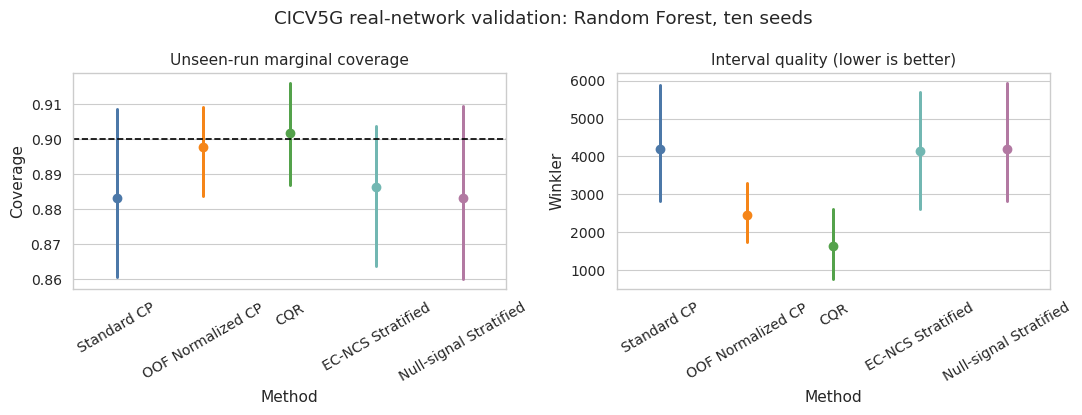

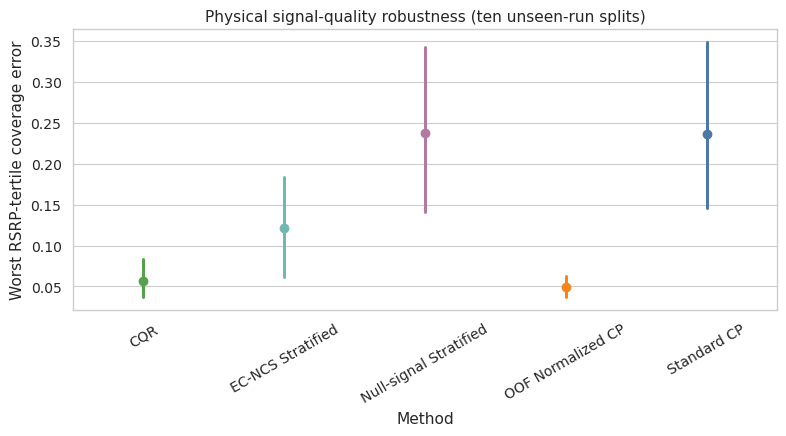

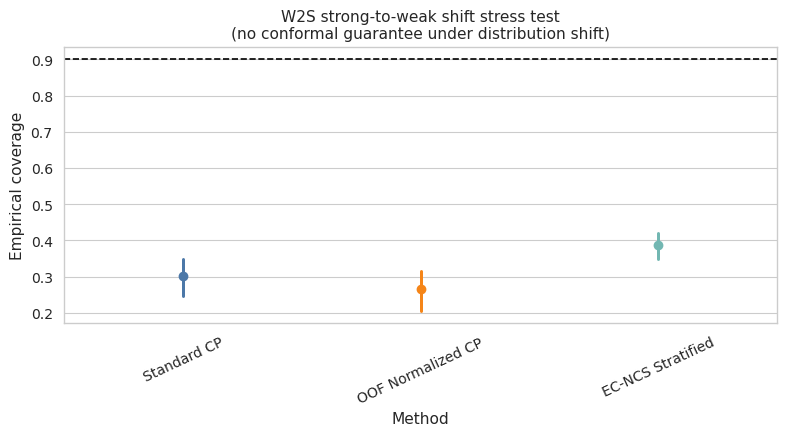

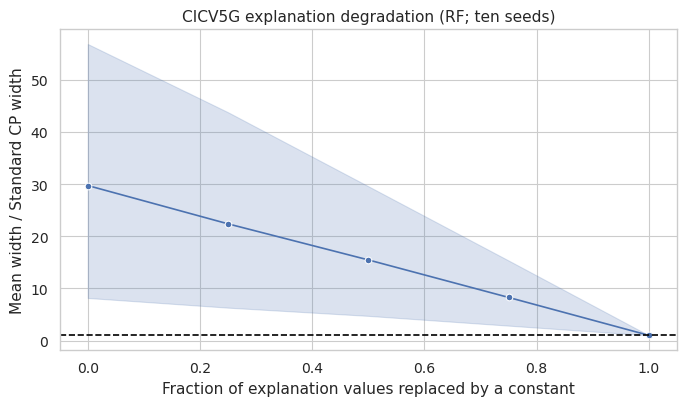

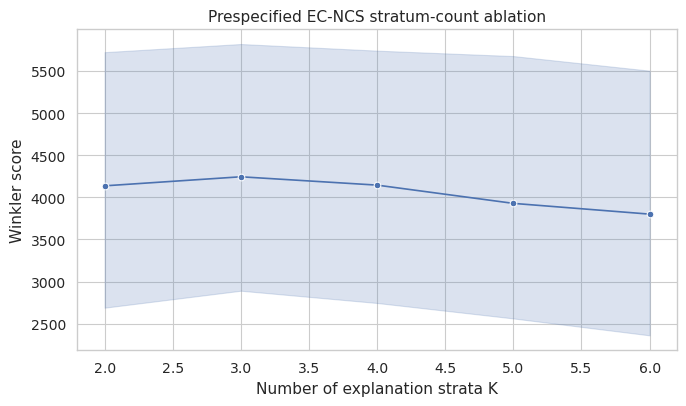

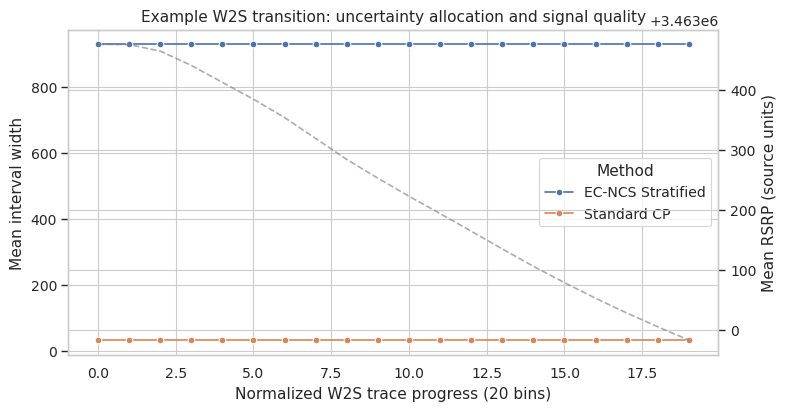

Results archive: /content/cicv5g_ec_ncs_results.zip


,Model,Method,Coverage,CoverageSD,MeanWidth,Winkler
0,MLP,EC-NCS Stratified,0.879091,0.034197,1034.100272,4330.774152
1,MLP,Null-signal Stratified,0.884294,0.054258,194.914593,4390.097503
2,MLP,OOF Normalized CP,0.891880,0.041546,1848.171431,2571.359162
3,MLP,Standard CP,0.884640,0.055132,194.268328,4389.231534
4,Random Forest,CQR,0.901748,0.025748,660.972264,1632.141320
5,Random Forest,EC-NCS Stratified,0.886329,0.035097,927.246807,4145.336850
6,Random Forest,Null-signal Stratified,0.883175,0.041647,69.946228,4204.438620
7,Random Forest,OOF Normalized CP,0.897922,0.021697,1493.714565,2453.068436
8,Random Forest,Standard CP,0.883066,0.041458,69.538664,4203.990608


,Protocol,Model,Reference,Method,Metric,MeanPairedDifference,WilcoxonP,Seeds,HolmAdjustedP
0,W2S shift stress test,MLP,Standard CP,EC-NCS Stratified,CoverageError,-0.105534,0.001953,10,0.064453
1,W2S shift stress test,MLP,Standard CP,EC-NCS Stratified,MeanWidth,3219.790794,0.001953,10,0.064453
2,W2S shift stress test,MLP,Standard CP,EC-NCS Stratified,Winkler,-21881.512743,0.001953,10,0.064453
3,W2S shift stress test,MLP,Standard CP,OOF Normalized CP,CoverageError,0.038399,0.193359,10,1.000000
4,W2S shift stress test,MLP,Standard CP,OOF Normalized CP,MeanWidth,-146.246837,0.105469,10,1.000000
5,W2S shift stress test,MLP,Standard CP,OOF Normalized CP,Winkler,1080.544518,0.105469,10,1.000000
6,W2S shift stress test,Random Forest,Standard CP,EC-NCS Stratified,CoverageError,-0.085775,0.019531,10,0.410156
7,W2S shift stress test,Random Forest,Standard CP,EC-NCS Stratified,MeanWidth,2134.676620,0.001953,10,0.064453
8,W2S shift stress test,Random Forest,Standard CP,EC-NCS Stratified,Winkler,-11317.542698,0.001953,10,0.064453
9,W2S shift stress test,Random Forest,Standard CP,OOF Normalized CP,CoverageError,0.036130,0.037109,10,0.742188


<Figure size 640x480 with 0 Axes>

In [ ]:
%run /content/CICV5G_EC_NCS_Colab.py

In [ ]:
from google.colab import files
files.download("/content/cicv5g_ec_ncs_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Device: cuda
GPU: Tesla T4
Previous results preserved: /content/cicv5g_ec_ncs_nested_results_backup_20260812_204827
Config(github_zip='https://github.com/zxr805/CICV5G/archive/refs/heads/main.zip', zenodo_record='17475688', data_dir='/content/cicv5g_data', outdir='/content/cicv5g_ec_ncs_nested_results', clean_run=True, seeds=(11, 22, 33, 44, 55, 66, 77, 88, 99, 111), nominal_coverage=0.9, train_group_fraction=0.6, calibration_group_fraction=0.2, test_group_fraction=0.2, split_candidates=2000, confirmation_folds=5, confirmation_split_candidates=5000, confirmation_min_calibration_runs=2, models=('Random Forest', 'MLP'), rf_trees=300, rf_min_leaf=3, mlp_epochs=80, mlp_batch_size=512, mlp_patience=10, explanation_batch_size=512, gradient_shap_samples=6, max_explanation_reference_rows=5000, explanation_groups=4, minimum_group_calibration=30, normalized_oof_folds=3, bootstrap_resamples=2000, primary_frequency_hz=20, restrict_primary_to_20hz=True, include_coordinates=False, run_w2s_stress=Tru

,Subset,Field,N,FiniteN,Min,Median,Max,ExpectedLower,ExpectedUpper,ValidFraction,Status
0,ordinary,RSRP,296447,296208,-107.0,-8.100000e+01,-5.100000e+01,-200.0,0.0,1.00000,valid; out-of-range rows set missing
1,ordinary,SINR,296447,296447,0.0,1.100000e+01,2.500000e+01,-50.0,100.0,1.00000,valid; out-of-range rows set missing
2,ordinary,Velocity,296447,296447,0.0,7.300000e+00,2.316000e+01,-1.0,120.0,1.00000,valid; out-of-range rows set missing
3,W2S,RSRP,43045,43045,-96.0,3.463015e+06,3.463476e+06,-200.0,0.0,0.44033,invalidated: implausible physical range
4,W2S,SINR,43045,43045,2.0,3.288056e+05,3.290871e+05,-50.0,100.0,0.44033,invalidated: implausible physical range
5,W2S,Velocity,43045,43045,0.0,1.130000e+01,2.400000e+01,-1.0,120.0,1.00000,valid; out-of-range rows set missing


Model features: ['RSRP', 'SINR', 'Velocity', 'Heading', 'FrequencyHz', 'NetworkMode', 'Scenario', 'Cell_ID']
Validated physical signal fields: ['RSRP', 'SINR'] | primary diagnostic: RSRP | W2S trace field: None
Reserved transmission-frequency confirmation: 106582 rows in 20 complete runs

===== CICV5G seed 11 =====

===== CICV5G seed 22 =====

===== CICV5G seed 33 =====

===== CICV5G seed 44 =====

===== CICV5G seed 55 =====

===== CICV5G seed 66 =====

===== CICV5G seed 77 =====

===== CICV5G seed 88 =====

===== CICV5G seed 99 =====

===== CICV5G seed 111 =====
Reserved fold run counts: {0: 4, 1: 4, 2: 4, 3: 4, 4: 4}

===== RESERVED FREQUENCY CONFIRMATION fold 1/5 =====

===== RESERVED FREQUENCY CONFIRMATION fold 2/5 =====

===== RESERVED FREQUENCY CONFIRMATION fold 3/5 =====

===== RESERVED FREQUENCY CONFIRMATION fold 4/5 =====

===== RESERVED FREQUENCY CONFIRMATION fold 5/5 =====


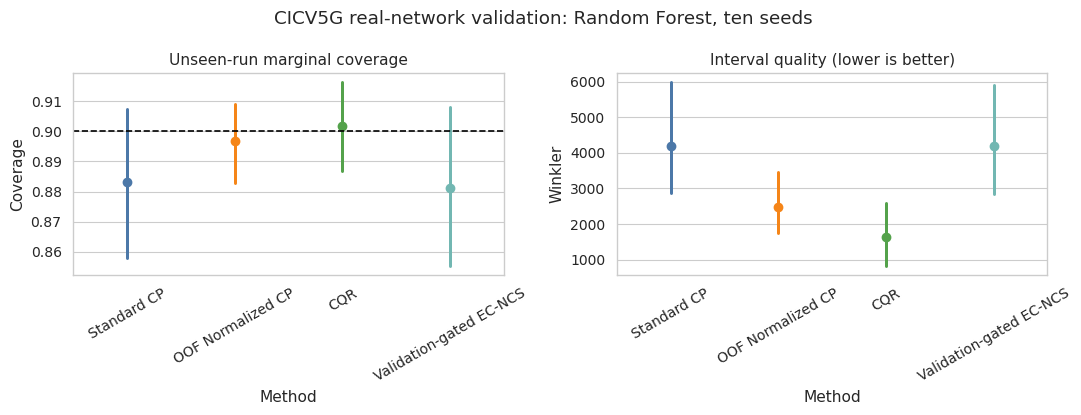

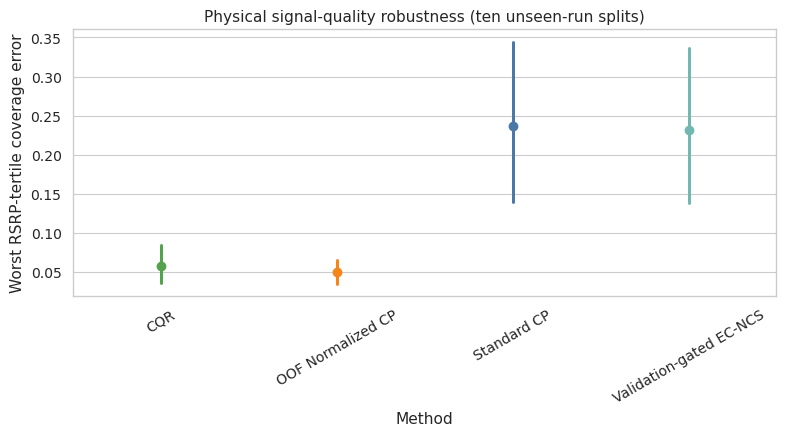

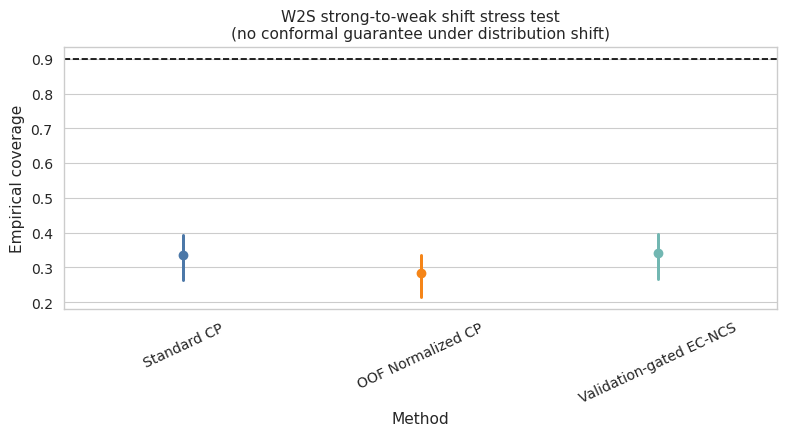

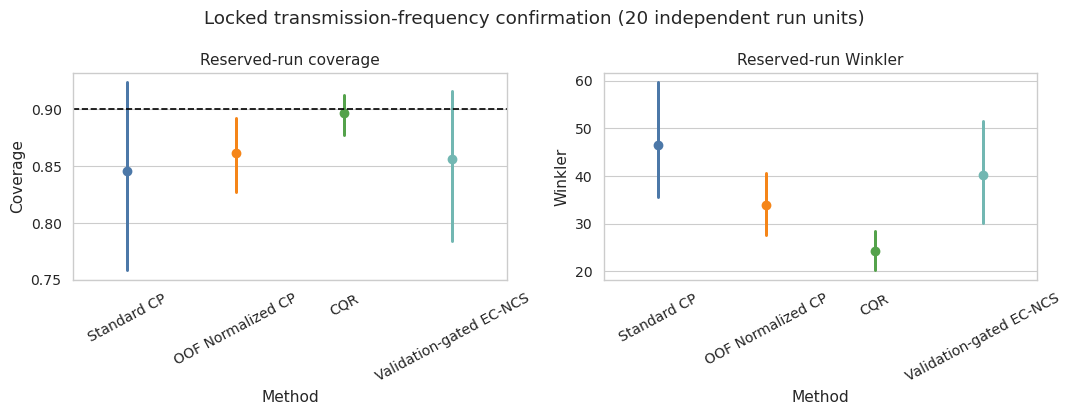

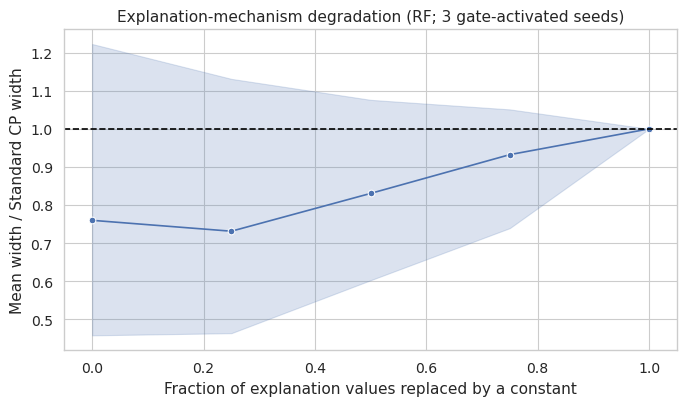

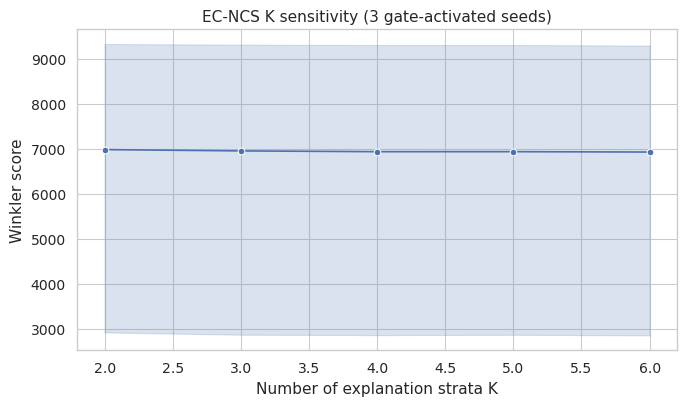

Results archive: /content/cicv5g_ec_ncs_nested_results.zip


,Model,Method,Coverage,CoverageSD,MeanWidth,Winkler
0,MLP,Null-signal Selected,0.884606,0.055307,196.428936,4390.541068
1,MLP,OOF Normalized CP,0.891880,0.041546,1848.171431,2571.359162
2,MLP,Standard CP,0.884640,0.055132,194.268328,4389.231534
3,MLP,Validation-gated EC-NCS,0.885103,0.054113,136.780438,4291.414192
4,Random Forest,CQR,0.901748,0.025748,660.972264,1632.141320
5,Random Forest,Null-signal Selected,0.883100,0.041496,69.610936,4203.980999
6,Random Forest,OOF Normalized CP,0.896950,0.022777,1507.309452,2472.526742
7,Random Forest,Standard CP,0.883066,0.041458,69.538664,4203.990608
8,Random Forest,Validation-gated EC-NCS,0.881054,0.044167,59.621806,4182.430093


,Protocol,Model,Reference,Method,Metric,MeanPairedDifference,WilcoxonP,Seeds,HolmAdjustedP
0,reserved frequency confirmation,MLP,Standard CP,Validation-gated EC-NCS,CoverageError,-0.005631,0.092892,20,0.092892
1,reserved frequency confirmation,MLP,Standard CP,Validation-gated EC-NCS,Winkler,-0.553277,0.046399,20,0.092799
2,reserved frequency confirmation,Random Forest,Standard CP,Validation-gated EC-NCS,CoverageError,-0.025402,0.026184,20,0.078551
3,reserved frequency confirmation,Random Forest,Standard CP,Validation-gated EC-NCS,Winkler,-6.148313,0.000438,20,0.001751


In [ ]:
"""Nested CICV5G real-network development and locked confirmation for EC-NCS.

Run with:
    %run /content/CICV5G_EC_NCS_Nested_Colab_FINAL.py

The script downloads the official CICV5G repository, validates its schema,
uses complete measurement files as disjoint experimental groups, evaluates
ordinary unseen runs over ten seeds, and treats W2S traces only as an external
distribution-shift stress test. No test labels select models, strata, or
hyperparameters.
"""

# %% Dependencies
import importlib.util, subprocess, sys
_required = {
    "shap": "shap>=0.46", "captum": "captum>=0.7",
    "openpyxl": "openpyxl>=3.1", "psutil": "psutil>=5.9",
}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import gc, hashlib, json, math, os, random, re, shutil, time, warnings, zipfile
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil, requests, seaborn as sns, shap
import torch
import torch.nn as nn
from captum.attr import GradientShap
from scipy.stats import wilcoxon
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))


@dataclass
class Config:
    github_zip: str = "https://github.com/zxr805/CICV5G/archive/refs/heads/main.zip"
    zenodo_record: str = "17475688"
    data_dir: str = "/content/cicv5g_data"
    outdir: str = "/content/cicv5g_ec_ncs_nested_results"
    clean_run: bool = True
    seeds: Tuple[int, ...] = (11, 22, 33, 44, 55, 66, 77, 88, 99, 111)
    nominal_coverage: float = .90
    train_group_fraction: float = .60
    calibration_group_fraction: float = .20
    test_group_fraction: float = .20
    split_candidates: int = 2000
    confirmation_folds: int = 5
    confirmation_split_candidates: int = 5000
    confirmation_min_calibration_runs: int = 2
    models: Tuple[str, ...] = ("Random Forest", "MLP")
    rf_trees: int = 300
    rf_min_leaf: int = 3
    mlp_epochs: int = 80
    mlp_batch_size: int = 512
    mlp_patience: int = 10
    explanation_batch_size: int = 512
    gradient_shap_samples: int = 6
    max_explanation_reference_rows: int = 5000
    explanation_groups: int = 4
    minimum_group_calibration: int = 30
    normalized_oof_folds: int = 3
    bootstrap_resamples: int = 2000
    primary_frequency_hz: int = 20
    restrict_primary_to_20hz: bool = True
    include_coordinates: bool = False
    run_w2s_stress: bool = True
    save_sample_predictions: bool = False
    # Prespecified training-only EC scale grid. Never edit after seeing the
    # confirmatory frequency-test results.
    ec_k_grid: Tuple[int, ...] = (2, 3, 4, 5)
    ec_shrinkage_grid: Tuple[float, ...] = (0.25, 0.50, 0.75, 1.0)
    ec_cap_grid: Tuple[float, ...] = (2.0, 4.0)
    ec_scale_floor: float = 0.50
    ec_min_bin_rows: int = 100
    ec_min_validation_gain: float = 0.01


CFG = Config()
ALPHA = 1 - CFG.nominal_coverage
SCRIPT_REVISION = "2026-08-12-cicv5g-r4-unified-gate-schema-audit"
DATA_DIR, OUTDIR = Path(CFG.data_dir), Path(CFG.outdir)
if CFG.clean_run and OUTDIR.exists():
    stamp = time.strftime("%Y%m%d_%H%M%S")
    backup = OUTDIR.with_name(OUTDIR.name + "_backup_" + stamp)
    counter = 1
    while backup.exists():
        backup = OUTDIR.with_name(OUTDIR.name + f"_backup_{stamp}_{counter}"); counter += 1
    shutil.move(str(OUTDIR), str(backup)); print("Previous results preserved:", backup)
for directory in (DATA_DIR, OUTDIR, OUTDIR/"figures", OUTDIR/"supplementary"):
    directory.mkdir(parents=True, exist_ok=True)
print(CFG); print("Script revision:", SCRIPT_REVISION)


def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False


def download_stream(url: str, path: Path, timeout=120):
    if path.exists() and path.stat().st_size > 1000: return path
    temporary = path.with_suffix(path.suffix + ".part")
    with requests.get(url, stream=True, timeout=timeout,
                      headers={"User-Agent": "EC-NCS-research/1.0"}) as response:
        response.raise_for_status()
        with open(temporary, "wb") as handle:
            for chunk in response.iter_content(1024*1024):
                if chunk: handle.write(chunk)
    temporary.replace(path); return path


def obtain_dataset() -> Path:
    archive = DATA_DIR / "CICV5G-main.zip"
    try:
        print("Downloading official CICV5G GitHub archive...")
        download_stream(CFG.github_zip, archive)
    except Exception as github_error:
        print("GitHub download failed; trying the official Zenodo record:", github_error)
        metadata = requests.get(f"https://zenodo.org/api/records/{CFG.zenodo_record}", timeout=60)
        metadata.raise_for_status(); files = metadata.json().get("files", [])
        candidates = [f for f in files if f.get("key", "").lower().endswith((".zip", ".tar.gz"))]
        if not candidates: raise RuntimeError("No downloadable archive found in the CICV5G Zenodo record.")
        item = candidates[0]
        url = item.get("links", {}).get("content") or item.get("links", {}).get("self")
        download_stream(url, archive)
    extract = DATA_DIR / "repository"
    marker = extract / ".complete"
    if not marker.exists():
        if extract.exists(): shutil.rmtree(extract)
        extract.mkdir(parents=True)
        with zipfile.ZipFile(archive) as zf:
            root = extract.resolve()
            for member in zf.infolist():
                resolved = (extract/member.filename).resolve()
                if root not in resolved.parents and resolved != root:
                    raise RuntimeError("Unsafe archive member: " + member.filename)
            zf.extractall(extract)
        marker.write_text("complete")
    return extract


def canonical(text): return re.sub(r"[^a-z0-9]", "", str(text).lower())


ALIASES = {
    "delay": {"delay", "delayms", "rtt", "rttms", "latency", "latencyms"},
    "pub_time": {"pubtime", "publishtime", "sendtime"},
    "sub_time": {"subtime", "subscribetime", "receivetime"},
    "RSRP": {"rsrp", "ssrsrp", "nr5grsrp"},
    "SINR": {"sinr", "sssinr", "snr", "nr5gsinr"},
    "Velocity": {"velocity", "speed", "vehiclespeed"},
    "Cell_ID": {"cellid", "cell", "pci", "servingcell"},
    "Heading": {"heading", "yaw"},
    "utmX": {"utmx", "x"}, "utmY": {"utmy", "y"},
}


def read_measurement_file(path: Path) -> pd.DataFrame:
    attempts = [dict(sep=r"\s+", engine="python"), dict(sep="\t"), dict(sep=","), dict(sep=None, engine="python")]
    frame = None
    for options in attempts:
        try:
            candidate = pd.read_csv(path, encoding="utf-8-sig", comment="#", **options)
            if candidate.shape[1] >= 3: frame = candidate; break
        except Exception: pass
    if frame is None: raise ValueError("Could not parse")
    rename = {}
    for column in frame.columns:
        key = canonical(column)
        prefix_map = {"delay":"delay", "latency":"delay", "rtt":"delay",
                      "rsrp":"RSRP", "sinr":"SINR", "snr":"SINR",
                      "velocity":"Velocity", "speed":"Velocity",
                      "cellid":"Cell_ID", "heading":"Heading",
                      "utmx":"utmX", "utmy":"utmY"}
        matched_prefix = next((desired for prefix, desired in prefix_map.items()
                               if key.startswith(prefix)), None)
        if matched_prefix is not None:
            rename[column] = matched_prefix
            continue
        for desired, aliases in ALIASES.items():
            if key in aliases: rename[column] = desired; break
    frame = frame.rename(columns=rename)
    # Some source releases contain synonymous duplicate headers (for example,
    # both delay and delay(ms)). Keep the first canonical field deterministically.
    frame = frame.loc[:, ~frame.columns.duplicated()].copy()
    if "delay" not in frame and {"pub_time", "sub_time"}.issubset(frame):
        frame["delay"] = pd.to_numeric(frame["sub_time"], errors="coerce") - pd.to_numeric(frame["pub_time"], errors="coerce")
    if "delay" not in frame: raise ValueError("No delay field")
    return frame


def parse_metadata(path: Path) -> Dict[str, object]:
    text = "/".join(path.parts).lower()
    if "urban" in text: scenario = "urban"
    elif "arterial" in text: scenario = "arterial"
    elif "rural" in text or "off road" in text or "offroad" in text: scenario = "rural_offroad"
    else: scenario = "unknown"
    if re.search(r"(^|[^a-z0-9])n78([^a-z0-9]|$)", text): mode = "n78_public"
    elif re.search(r"(^|[^a-z0-9])n8([^a-z0-9]|$)", text): mode = "n8_private"
    else: mode = "unknown"
    match = re.search(r"(?:^|[^0-9])(?:hz|freq(?:uency)?)[_ -]?(10|20|33|100)(?:[^0-9]|$)", text)
    if not match: match = re.search(r"(?:^|[_ -])(10|20|33|100)hz(?:[_ .-]|$)", text)
    frequency_stress = "data transmission frequency" in text
    period_match = re.search(r"(?:^|[/_ -])(10|30|50|100)ms(?:[/_ .-]|$)", text)
    if match: frequency = int(match.group(1))
    elif period_match: frequency = int(round(1000/int(period_match.group(1))))
    else: frequency = CFG.primary_frequency_hz
    stress = bool(re.search(r"w2s|strong.?to.?weak|weak.?to.?strong", text))
    return {"Scenario": scenario, "NetworkMode": mode, "FrequencyHz": frequency,
            "IsW2S": stress, "IsFrequencyStress": frequency_stress, "RunGroup": str(path)}


def load_all_data(root: Path):
    files = sorted([p for p in root.rglob("*.txt") if "data" in str(p.parent).lower()])
    if not files: files = sorted(root.rglob("*.txt"))
    # The repository contains convenience files such as westn8all.txt in
    # addition to the constituent run files. Loading both would duplicate
    # observations and invalidate run-disjoint evaluation.
    files = [p for p in files if not re.search(r"(?:all|merged|combined)$", p.stem.lower())]
    rows, audit, seen_digests = [], [], set()
    for path in files:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if digest in seen_digests:
            audit.append({"File": str(path), "Status": "skipped", "Reason": "exact duplicate file", "Rows": 0})
            continue
        seen_digests.add(digest)
        try:
            frame = read_measurement_file(path)
        except Exception as error:
            audit.append({"File": str(path), "Status": "skipped", "Reason": str(error), "Rows": 0}); continue
        meta = parse_metadata(path)
        for key, value in meta.items(): frame[key] = value
        for col in ("delay", "RSRP", "SINR", "Velocity", "Heading", "utmX", "utmY"):
            if col in frame: frame[col] = pd.to_numeric(frame[col], errors="coerce")
        before = len(frame)
        frame = frame[np.isfinite(frame.delay) & (frame.delay >= 0)].copy()
        if len(frame): rows.append(frame)
        audit.append({"File": str(path), "Status": "loaded", "Reason": "", "RowsRaw": before,
                      "Rows": len(frame), **meta})
    if not rows: raise RuntimeError("No valid CICV5G measurement files were loaded.")
    data = pd.concat(rows, ignore_index=True, sort=False)
    audit = pd.DataFrame(audit)
    data["RowInRun"] = data.groupby("RunGroup").cumcount()
    return data, audit


ROOT = obtain_dataset()
all_data, file_audit = load_all_data(ROOT)
file_audit.to_csv(OUTDIR/"file_audit.csv", index=False)
print("Loaded rows:", len(all_data), "runs:", all_data.RunGroup.nunique())
print(all_data.groupby(["Scenario", "NetworkMode", "IsW2S"], dropna=False).size())


def audit_and_clean_physical_fields(data):
    """Reject impossible radio values without silently relabelling columns.

    CICV5G documents RSRP and SINR separately from UTM coordinates. Values at
    coordinate scale (for example, millions) cannot be radio measurements.
    Invalid subset/field combinations are replaced by missing values so they
    cannot enter models or physical-stratum claims; the decision is recorded.
    """
    checks={"RSRP":(-200.0,0.0),"SINR":(-50.0,100.0),
            "Velocity":(-1.0,120.0)}
    cleaned=data.copy(); rows=[]
    subset_masks={"ordinary":~cleaned.IsW2S,
                  "W2S":cleaned.IsW2S}
    for subset,mask in subset_masks.items():
        for field,(lower,upper) in checks.items():
            if field not in cleaned:
                rows.append({"Subset":subset,"Field":field,"N":0,
                             "FiniteN":0,"ValidFraction":0.0,"Status":"missing"})
                continue
            values=pd.to_numeric(cleaned.loc[mask,field],errors="coerce")
            finite=values[np.isfinite(values)]
            valid=((finite>=lower)&(finite<=upper))
            fraction=float(valid.mean()) if len(finite) else 0.0
            record={"Subset":subset,"Field":field,"N":int(mask.sum()),
                    "FiniteN":int(len(finite)),"Min":float(finite.min()) if len(finite) else np.nan,
                    "Median":float(finite.median()) if len(finite) else np.nan,
                    "Max":float(finite.max()) if len(finite) else np.nan,
                    "ExpectedLower":lower,"ExpectedUpper":upper,"ValidFraction":fraction}
            # Require a strongly dominant physically plausible range. Sparse
            # individual sentinels are set missing; wholesale schema failures
            # invalidate the field in that subset.
            if fraction>=.95:
                bad=mask & (~pd.to_numeric(cleaned[field],errors="coerce").between(lower,upper))
                cleaned.loc[bad,field]=np.nan
                record["Status"]="valid; out-of-range rows set missing"
            else:
                cleaned.loc[mask,field]=np.nan
                record["Status"]="invalidated: implausible physical range"
            rows.append(record)
    audit=pd.DataFrame(rows)
    return cleaned,audit


all_data,physical_field_audit=audit_and_clean_physical_fields(all_data)
physical_field_audit.to_csv(OUTDIR/"physical_field_audit.csv",index=False)
run_physical_audit=[]
for run_group,block in all_data.groupby("RunGroup",sort=False):
    record={"RunGroup":run_group,"IsW2S":bool(block.IsW2S.iloc[0]),
            "Scenario":block.Scenario.iloc[0],"NetworkMode":block.NetworkMode.iloc[0],"N":len(block)}
    for field in ("RSRP","SINR","Velocity"):
        values=pd.to_numeric(block.get(field),errors="coerce").dropna() if field in block else pd.Series(dtype=float)
        record[f"{field}_FiniteN"]=len(values)
        record[f"{field}_Min"]=values.min() if len(values) else np.nan
        record[f"{field}_Median"]=values.median() if len(values) else np.nan
        record[f"{field}_Max"]=values.max() if len(values) else np.nan
    run_physical_audit.append(record)
run_physical_audit=pd.DataFrame(run_physical_audit)
run_physical_audit.to_csv(OUTDIR/"run_physical_field_audit.csv",index=False)
print("\nPhysical-field audit:")
display(physical_field_audit)

ordinary = all_data[(~all_data.IsW2S) & (~all_data.IsFrequencyStress)].copy()
if CFG.restrict_primary_to_20hz:
    candidate = ordinary[ordinary.FrequencyHz == CFG.primary_frequency_hz].copy()
    if candidate.RunGroup.nunique() >= 15: ordinary = candidate
    else: print("Too few detected 20 Hz runs; using all ordinary frequencies with FrequencyHz as a feature.")
w2s = all_data[all_data.IsW2S].copy()
frequency_confirm = all_data[(~all_data.IsW2S) & (all_data.IsFrequencyStress)].copy()
if ordinary.RunGroup.nunique() < 10:
    raise RuntimeError("At least ten ordinary run files are required for group-disjoint validation.")


def available_features(frame):
    features = [c for c in ["RSRP", "SINR", "Velocity", "Heading", "FrequencyHz",
                             "NetworkMode", "Scenario", "Cell_ID"] if c in frame and frame[c].notna().any()]
    if CFG.include_coordinates:
        features += [c for c in ["utmX", "utmY"] if c in frame and frame[c].notna().any()]
    return features


FEATURES = available_features(ordinary)
if not {"RSRP", "SINR"}.intersection(FEATURES):
    raise RuntimeError("Neither RSRP nor SINR was found; inspect file_audit.csv and source schema.")
print("Model features:", FEATURES)
VALID_SIGNAL_FIELDS=[field for field in ("RSRP","SINR")
                     if field in ordinary and ordinary[field].notna().mean()>=.50]
if not VALID_SIGNAL_FIELDS:
    raise RuntimeError("No physically valid radio indicator remains after schema audit.")
PRIMARY_SIGNAL_FIELD=VALID_SIGNAL_FIELDS[0]
W2S_SIGNAL_FIELD=next((field for field in ("RSRP","SINR")
                       if field in w2s and w2s[field].notna().mean()>=.50),None)
print("Validated physical signal fields:",VALID_SIGNAL_FIELDS,
      "| primary diagnostic:",PRIMARY_SIGNAL_FIELD,
      "| W2S trace field:",W2S_SIGNAL_FIELD)
print("Reserved transmission-frequency confirmation:", len(frequency_confirm),
      "rows in", frequency_confirm.RunGroup.nunique(), "complete runs")


def split_score(group_table, assignments):
    score = 0.0
    global_dist = group_table.Stratum.value_counts(normalize=True)
    target = [CFG.train_group_fraction, CFG.calibration_group_fraction, CFG.test_group_fraction]
    n = len(group_table)
    for part, fraction in enumerate(target):
        subset = group_table.iloc[np.flatnonzero(assignments == part)]
        if subset.empty: return 1e9
        score += 4 * abs(len(subset)/n - fraction)
        dist = subset.Stratum.value_counts(normalize=True)
        score += sum(abs(dist.get(k, 0)-v) for k, v in global_dist.items())
    return score


def group_split(frame, seed):
    table = frame.groupby("RunGroup", as_index=False).agg(
        Scenario=("Scenario", "first"), NetworkMode=("NetworkMode", "first"),
        FrequencyHz=("FrequencyHz", "first"), Rows=("delay", "size"))
    table["Stratum"] = table.Scenario.astype(str)+"|"+table.NetworkMode.astype(str)+"|"+table.FrequencyHz.astype(str)
    rng = np.random.default_rng(seed); best, best_score = None, np.inf
    n = len(table); ntr=max(1,round(CFG.train_group_fraction*n)); nca=max(1,round(CFG.calibration_group_fraction*n))
    if ntr+nca >= n: ntr, nca = n-2, 1
    for _ in range(CFG.split_candidates):
        order = rng.permutation(n); assignment = np.full(n, 2); assignment[order[:ntr]]=0; assignment[order[ntr:ntr+nca]]=1
        value = split_score(table, assignment)
        if value < best_score: best, best_score = assignment.copy(), value
    groups = [set(table.loc[best==part, "RunGroup"]) for part in range(3)]
    indices = [np.flatnonzero(frame.RunGroup.isin(group).to_numpy()) for group in groups]
    if groups[0]&groups[1] or groups[0]&groups[2] or groups[1]&groups[2]: raise AssertionError("Group overlap")
    return (*indices, table.assign(Partition=np.array(["train","calibration","test"])[best]), best_score)


def assert_nonempty_group_split(train, calibration, test, context):
    """Fail before preprocessing if any complete-run partition is invalid."""
    partitions = {"train": train, "calibration": calibration, "test": test}
    empty = [name for name, part in partitions.items() if len(part) == 0]
    if empty:
        raise RuntimeError(f"{context}: empty partition(s): {empty}")
    run_sets = {name: set(part.RunGroup.astype(str)) for name, part in partitions.items()}
    if run_sets["train"] & run_sets["calibration"]:
        raise AssertionError(f"{context}: train/calibration run overlap")
    if run_sets["train"] & run_sets["test"]:
        raise AssertionError(f"{context}: train/test run overlap")
    if run_sets["calibration"] & run_sets["test"]:
        raise AssertionError(f"{context}: calibration/test run overlap")
    if len(run_sets["train"]) < 2:
        raise RuntimeError(f"{context}: fewer than two training runs")
    if len(run_sets["calibration"]) < 1:
        raise RuntimeError(f"{context}: no calibration run")
    if len(run_sets["test"]) < 1:
        raise RuntimeError(f"{context}: no test run")


def make_balanced_confirmation_folds(frame, n_splits, seed):
    """Assign every reserved complete run to one globally balanced test fold.

    The earlier stratum-local round-robin restarted at fold zero for every
    stratum. With many singleton strata, this concentrated most runs in fold
    zero and could leave an empty calibration remainder. Here candidate fold
    labels have exactly balanced run counts globally; the objective then
    balances row mass and the NetworkMode/FrequencyHz distribution.
    """
    table = frame.groupby("RunGroup", as_index=False).agg(
        NetworkMode=("NetworkMode", "first"),
        FrequencyHz=("FrequencyHz", "first"),
        Rows=("delay", "size"),
    )
    table["Stratum"] = (table.NetworkMode.astype(str) + "|" +
                        table.FrequencyHz.astype(str))
    n_runs = len(table)
    if n_runs < 2 * n_splits:
        raise RuntimeError(
            f"Reserved confirmation needs at least {2*n_splits} complete runs "
            f"for {n_splits} folds; found {n_runs}."
        )
    base_labels = np.arange(n_runs) % n_splits
    global_dist = table.Stratum.value_counts(normalize=True)
    total_rows = float(table.Rows.sum())
    rng = np.random.default_rng(seed)
    best_assignment, best_score = None, np.inf
    for _ in range(CFG.confirmation_split_candidates):
        assignment = base_labels[rng.permutation(n_runs)]
        score = 0.0
        valid = True
        for fold in range(n_splits):
            subset = table.loc[assignment == fold]
            if subset.empty:
                valid = False
                break
            score += 2.0 * abs(len(subset) / n_runs - 1.0 / n_splits)
            score += 2.0 * abs(float(subset.Rows.sum()) / total_rows - 1.0 / n_splits)
            dist = subset.Stratum.value_counts(normalize=True)
            score += sum(abs(dist.get(key, 0.0) - value)
                         for key, value in global_dist.items())
        if valid and score < best_score:
            best_assignment, best_score = assignment.copy(), float(score)
    if best_assignment is None:
        raise RuntimeError("Could not construct nonempty balanced confirmation folds.")
    table["Fold"] = best_assignment
    counts = table.groupby("Fold").agg(Runs=("RunGroup", "size"), Rows=("Rows", "sum"))
    if len(counts) != n_splits or (counts.Runs < 1).any():
        raise AssertionError("Balanced confirmation fold construction failed.")
    return table, best_score


def train_calibration_group_split(frame, seed):
    """Split the non-test reserved runs into nonempty train/calibration runs."""
    table = frame.groupby("RunGroup", as_index=False).agg(
        NetworkMode=("NetworkMode", "first"),
        FrequencyHz=("FrequencyHz", "first"),
        Rows=("delay", "size"),
    )
    table["Stratum"] = (table.NetworkMode.astype(str) + "|" +
                        table.FrequencyHz.astype(str))
    n_runs = len(table)
    min_cal = CFG.confirmation_min_calibration_runs
    if n_runs < min_cal + 4:
        raise RuntimeError(
            f"Need at least {min_cal+4} non-test runs for confirmation "
            f"training/calibration; found {n_runs}."
        )
    n_cal = max(min_cal, int(round(CFG.calibration_group_fraction * n_runs)))
    n_cal = min(n_cal, n_runs - 4)
    global_dist = table.Stratum.value_counts(normalize=True)
    total_rows = float(table.Rows.sum())
    rng = np.random.default_rng(seed)
    best_calibration, best_score = None, np.inf
    for _ in range(CFG.confirmation_split_candidates):
        calibration_indices = rng.choice(n_runs, n_cal, replace=False)
        mask = np.zeros(n_runs, dtype=bool)
        mask[calibration_indices] = True
        cal_table, train_table = table.loc[mask], table.loc[~mask]
        if cal_table.empty or train_table.empty:
            continue
        cal_dist = cal_table.Stratum.value_counts(normalize=True)
        train_dist = train_table.Stratum.value_counts(normalize=True)
        score = 2.0 * abs(float(cal_table.Rows.sum()) / total_rows - n_cal / n_runs)
        score += sum(abs(cal_dist.get(key, 0.0) - value)
                     for key, value in global_dist.items())
        score += 0.5 * sum(abs(train_dist.get(key, 0.0) - value)
                           for key, value in global_dist.items())
        if score < best_score:
            best_calibration, best_score = mask.copy(), float(score)
    if best_calibration is None:
        raise RuntimeError("Could not construct reserved train/calibration split.")
    train_groups = set(table.loc[~best_calibration, "RunGroup"])
    calibration_groups = set(table.loc[best_calibration, "RunGroup"])
    train_indices = np.flatnonzero(frame.RunGroup.isin(train_groups).to_numpy())
    calibration_indices = np.flatnonzero(frame.RunGroup.isin(calibration_groups).to_numpy())
    assignment = np.where(best_calibration, "calibration", "train")
    return train_indices, calibration_indices, table.assign(Partition=assignment), best_score


def save_partial_csv(name, rows):
    """Write recoverable progress after every seed/fold without changing inference."""
    frame = pd.DataFrame(rows)
    if len(frame):
        frame.to_csv(OUTDIR / name, index=False)


def build_preprocessor(frame):
    numeric = [c for c in FEATURES if pd.api.types.is_numeric_dtype(frame[c])]
    categorical = [c for c in FEATURES if c not in numeric]
    transformers=[]
    if numeric: transformers.append(("num", Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())]), numeric))
    if categorical: transformers.append(("cat", Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=2))]), categorical))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)


class TorchMLP:
    def __init__(self, seed): self.seed=seed
    def fit(self, X, y):
        set_seed(self.seed); n=X.shape[1]
        self.net=nn.Sequential(nn.Linear(n,128),nn.ReLU(),nn.Dropout(.1),nn.Linear(128,64),nn.ReLU(),nn.Linear(64,1)).to(DEVICE)
        idx=np.arange(len(X)); np.random.default_rng(self.seed).shuffle(idx); cut=max(1,int(.85*len(idx))); fit,val=idx[:cut],idx[cut:]
        mean,std=float(np.mean(y[fit])),float(np.std(y[fit])+1e-8); self.y_mean,self.y_std=mean,std
        optimizer=torch.optim.AdamW(self.net.parameters(),lr=1e-3,weight_decay=1e-4); loss_fn=nn.SmoothL1Loss()
        best,best_state,wait=np.inf,None,0
        for epoch in range(CFG.mlp_epochs):
            self.net.train(); order=np.random.default_rng(self.seed+epoch).permutation(fit)
            for start in range(0,len(order),CFG.mlp_batch_size):
                b=order[start:start+CFG.mlp_batch_size]; xb=torch.tensor(X[b],dtype=torch.float32,device=DEVICE)
                target=torch.tensor((y[b]-mean)/std,dtype=torch.float32,device=DEVICE).view(-1,1)
                optimizer.zero_grad(); loss=loss_fn(self.net(xb),target); loss.backward(); optimizer.step()
            self.net.eval()
            with torch.no_grad():
                pv=self.net(torch.tensor(X[val],dtype=torch.float32,device=DEVICE)).cpu().numpy().ravel()*std+mean
            metric=float(np.mean(np.abs(y[val]-pv)))
            if metric<best-1e-5: best=metric; best_state={k:v.detach().cpu().clone() for k,v in self.net.state_dict().items()}; wait=0
            else: wait+=1
            if wait>=CFG.mlp_patience: break
        self.net.load_state_dict(best_state); return self
    def predict(self,X):
        self.net.eval(); out=[]
        with torch.no_grad():
            for start in range(0,len(X),CFG.explanation_batch_size):
                out.append(self.net(torch.tensor(X[start:start+CFG.explanation_batch_size],dtype=torch.float32,device=DEVICE)).cpu().numpy().ravel())
        return np.concatenate(out)*self.y_std+self.y_mean


def build_model(name,seed):
    return (RandomForestRegressor(n_estimators=CFG.rf_trees,min_samples_leaf=CFG.rf_min_leaf,
                                  random_state=seed,n_jobs=-1,max_features=.8)
            if name=="Random Forest" else TorchMLP(seed))


def explain_strength(name, model, X, background):
    if name=="Random Forest":
        explainer=shap.TreeExplainer(model,feature_perturbation="tree_path_dependent")
        try: values=explainer.shap_values(X,check_additivity=False,approximate=True)
        except TypeError: values=explainer.shap_values(X,check_additivity=False)
        values=np.asarray(values)
        if values.ndim==3: values=values[...,0]
        return np.abs(values).mean(axis=1)
    baseline=torch.tensor(background,dtype=torch.float32,device=DEVICE)
    gradient=GradientShap(model.net); output=[]
    for start in range(0,len(X),CFG.explanation_batch_size):
        batch=torch.tensor(X[start:start+CFG.explanation_batch_size],dtype=torch.float32,device=DEVICE,requires_grad=True)
        attrs=gradient.attribute(batch,baselines=baseline,n_samples=CFG.gradient_shap_samples,stdevs=0.0)
        output.append(attrs.detach().abs().mean(dim=1).cpu().numpy())
    return np.concatenate(output)


class EmpiricalCDF:
    def fit(self,x): self.sorted=np.sort(np.asarray(x,float)); return self
    def transform(self,x): return np.searchsorted(self.sorted,np.asarray(x,float),side="right")/max(1,len(self.sorted))


def conformal_quantile(scores):
    scores=np.asarray(scores,float).reshape(-1)
    scores=scores[np.isfinite(scores)]
    if len(scores)==0:
        raise RuntimeError("Conformal calibration received no finite scores.")
    level=min(1.0,math.ceil((len(scores)+1)*(1-ALPHA))/len(scores))
    return float(np.quantile(scores,level,method="higher"))


def interval_metrics(y,lo,hi):
    covered=(y>=lo)&(y<=hi); width=hi-lo; penalty=(2/ALPHA)*(lo-y)*(y<lo)+(2/ALPHA)*(y-hi)*(y>hi)
    return {"N":len(y),"Coverage":float(covered.mean()),"CoverageError":float(abs(covered.mean()-CFG.nominal_coverage)),
            "MeanWidth":float(width.mean()),"MedianWidth":float(np.median(width)),"P90Width":float(np.quantile(width,.9)),
            "Winkler":float(np.mean(width+penalty))}


def mondrian_radii(residual,cal_group,test_group):
    fallback=conformal_quantile(residual); out=np.full(len(test_group),fallback)
    for group in np.unique(test_group):
        values=residual[cal_group==group]
        if len(values)>=CFG.minimum_group_calibration: out[test_group==group]=conformal_quantile(values)
    return out


def oof_scale(X,y,groups,seed,model_name):
    folds=min(CFG.normalized_oof_folds,len(np.unique(groups))); splitter=GroupKFold(folds); oof=np.full(len(y),np.nan)
    for fold,(fit,hold) in enumerate(splitter.split(X,groups=groups)):
        # The residual-scale target must come from OOF predictions of the same
        # point-model family; otherwise the normalized baseline is mismatched.
        model=build_model(model_name,seed+100+fold).fit(X[fit],y[fit])
        oof[hold]=model.predict(X[hold])
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    target=np.abs(y-oof)+1e-6
    scale_model=ExtraTreesRegressor(n_estimators=200,min_samples_leaf=10,random_state=seed+200,n_jobs=-1).fit(X,target)
    return scale_model,target


def weighted_quantile(values, quantile, weights):
    """Deterministic weighted empirical quantile (used only on training data)."""
    values=np.asarray(values,float); weights=np.asarray(weights,float)
    mask=np.isfinite(values)&np.isfinite(weights)&(weights>0)
    values,weights=values[mask],weights[mask]
    if not len(values): return np.nan
    order=np.argsort(values); values,weights=values[order],weights[order]
    cumulative=np.cumsum(weights)/weights.sum()
    return float(values[min(np.searchsorted(cumulative,quantile,side="left"),len(values)-1)])


def run_balanced_weights(groups):
    groups=np.asarray(groups).astype(str); counts=pd.Series(groups).value_counts()
    weights=np.array([1.0/counts[g] for g in groups],float)
    return weights/weights.mean()


def run_balanced_reference_indices(groups,max_rows,seed):
    """Bound explanation cost while spreading the reference across all runs."""
    groups=np.asarray(groups).astype(str); rng=np.random.default_rng(seed); unique=np.unique(groups)
    quota=max(1,max_rows//max(1,len(unique))); selected=[]
    for group in unique:
        indices=np.flatnonzero(groups==group)
        selected.extend(rng.choice(indices,min(quota,len(indices)),replace=False).tolist())
    if len(selected)<min(max_rows,len(groups)):
        remaining=np.setdiff1d(np.arange(len(groups)),np.asarray(selected,int),assume_unique=False)
        selected.extend(rng.choice(remaining,min(max_rows-len(selected),len(remaining)),replace=False).tolist())
    return np.asarray(selected[:max_rows],int)


def fit_explanation_scale(z,residual,run_groups,k,shrinkage,cap):
    """Learn a positive explanation-only scale using training residuals.

    The scale is fixed before conformal calibration. Consequently, calibrating
    |Y-f(X)|/s(X) on an untouched calibration set retains ordinary marginal
    split-conformal validity under exchangeability, regardless of whether the
    learned explanation scale is useful.
    """
    z=np.asarray(z,float); residual=np.asarray(residual,float)+1e-8
    weights=run_balanced_weights(run_groups)
    global_median=weighted_quantile(residual,.5,weights)
    edges=np.linspace(0,1,k+1); bins=np.digitize(z,edges[1:-1])
    ratios=np.ones(k,float)
    for group in range(k):
        mask=bins==group
        if mask.sum()>=CFG.ec_min_bin_rows:
            local=weighted_quantile(residual[mask],.5,weights[mask])
            raw=max(local/max(global_median,1e-8),1e-4)
            ratios[group]=np.exp(shrinkage*np.log(raw))
    ratios=np.clip(ratios,CFG.ec_scale_floor,cap)
    # Identifiability normalization does not change the final interval after
    # conformal calibration, but makes scale ratios comparable across seeds.
    ratios=ratios/max(weighted_quantile(ratios[bins],.5,weights),1e-8)
    ratios=np.clip(ratios,CFG.ec_scale_floor,cap)
    return {"k":int(k),"shrinkage":float(shrinkage),"cap":float(cap),
            "edges":edges.tolist(),"ratios":ratios.tolist()}


def apply_explanation_scale(z,params):
    edges=np.asarray(params["edges"],float); ratios=np.asarray(params["ratios"],float)
    return ratios[np.digitize(np.asarray(z,float),edges[1:-1])]


def worst_signal_error(reference,test,y,lo,hi):
    strata=dict(physical_strata(reference,test))
    key=f"{PRIMARY_SIGNAL_FIELD}-tertile"
    if key not in strata: return abs(np.mean((y>=lo)&(y<=hi))-CFG.nominal_coverage)
    labels=strata[key]; errors=[]
    for label in np.unique(labels):
        mask=labels==label
        errors.append(abs(np.mean((y[mask]>=lo[mask])&(y[mask]<=hi[mask]))-CFG.nominal_coverage))
    return float(max(errors))


def select_ec_hyperparameters(train_frame,seed,model_name):
    """Nested selection using only the outer-training runs."""
    fit_idx,cal_idx,val_idx,_,_=group_split(train_frame,seed+31000)
    fit_df=train_frame.iloc[fit_idx].copy(); cal_df=train_frame.iloc[cal_idx].copy(); val_df=train_frame.iloc[val_idx].copy()
    prep=build_preprocessor(fit_df[FEATURES]); Xfit=prep.fit_transform(fit_df[FEATURES]).astype(np.float32)
    Xcal=prep.transform(cal_df[FEATURES]).astype(np.float32); Xval=prep.transform(val_df[FEATURES]).astype(np.float32)
    yfit=fit_df.delay.to_numpy(float); ycal=cal_df.delay.to_numpy(float); yval=val_df.delay.to_numpy(float)
    model=build_model(model_name,seed+32000).fit(Xfit,yfit)
    pcal=model.predict(Xcal); pval=model.predict(Xval)
    rng=np.random.default_rng(seed+33000); background=Xfit[rng.choice(len(Xfit),min(64,len(Xfit)),replace=False)]
    ref_idx=run_balanced_reference_indices(fit_df.RunGroup.to_numpy(),CFG.max_explanation_reference_rows,seed+33100)
    phi_fit=explain_strength(model_name,model,Xfit[ref_idx],background)
    phi_cal=explain_strength(model_name,model,Xcal,background); phi_val=explain_strength(model_name,model,Xval,background)
    ecdf=EmpiricalCDF().fit(phi_fit); zfit=ecdf.transform(phi_fit); zcal=ecdf.transform(phi_cal); zval=ecdf.transform(phi_val)
    _,fit_oof_residual=oof_scale(Xfit,yfit,fit_df.RunGroup.to_numpy(),seed+34000,model_name)
    cal_residual=np.abs(ycal-pcal); q0=conformal_quantile(cal_residual)
    standard=interval_metrics(yval,pval-q0,pval+q0)
    standard_worst=worst_signal_error(fit_df,val_df,yval,pval-q0,pval+q0)
    standard_objective=standard_worst + .25*(standard["Winkler"]/max(standard["Winkler"],1e-8))
    audit=[{"Candidate":"Standard fallback","K":1,"Shrinkage":0.0,"Cap":1.0,
            "Coverage":standard["Coverage"],"CoverageError":standard["CoverageError"],
            "WorstRSRPError":standard_worst,"Winkler":standard["Winkler"],
            "Objective":standard_objective}]
    candidates=[]
    for k in CFG.ec_k_grid:
        for shrinkage in CFG.ec_shrinkage_grid:
            for cap in CFG.ec_cap_grid:
                params=fit_explanation_scale(zfit,fit_oof_residual[ref_idx],fit_df.RunGroup.to_numpy()[ref_idx],k,shrinkage,cap)
                sc=apply_explanation_scale(zcal,params); sv=apply_explanation_scale(zval,params)
                q=conformal_quantile(cal_residual/sc); lo,hi=pval-q*sv,pval+q*sv
                metrics=interval_metrics(yval,lo,hi); worst=worst_signal_error(fit_df,val_df,yval,lo,hi)
                objective=worst + .25*(metrics["Winkler"]/max(standard["Winkler"],1e-8))
                record={"Candidate":"EC-NCS","K":k,"Shrinkage":shrinkage,"Cap":cap,
                        "Coverage":metrics["Coverage"],"CoverageError":metrics["CoverageError"],
                        "WorstRSRPError":worst,"Winkler":metrics["Winkler"],"Objective":objective}
                audit.append(record); candidates.append((objective,params,record))
    candidates.sort(key=lambda item:item[0]); best_objective,best_params,best_record=candidates[0]
    relative_gain=(standard_objective-best_objective)/max(abs(standard_objective),1e-8)
    # Coverage guardrail and minimum gain are fixed prospectively. If either
    # fails, explanations are ignored and the method becomes Standard CP.
    use_ec=(relative_gain>=CFG.ec_min_validation_gain and
            best_record["Coverage"]>=CFG.nominal_coverage-.02)
    selected=(best_params if use_ec else {"k":1,"shrinkage":0.0,"cap":1.0,
              "edges":[0.0,1.0],"ratios":[1.0]})
    decision={"SelectedEC":bool(use_ec),"RelativeValidationGain":relative_gain,
              "SelectedK":selected["k"],"SelectedShrinkage":selected["shrinkage"],
              "SelectedCap":selected["cap"],"StandardObjective":standard_objective,
              "BestECObjective":best_objective}
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return selected,decision,pd.DataFrame(audit)


def cqr(Xtr,ytr,Xca,yca,Xte,seed):
    models=[]
    for alpha,offset in [(ALPHA/2,0),(1-ALPHA/2,1)]:
        m=GradientBoostingRegressor(loss="quantile",alpha=alpha,n_estimators=250,max_depth=3,learning_rate=.04,random_state=seed+offset).fit(Xtr,ytr); models.append(m)
    lca,uca=models[0].predict(Xca),models[1].predict(Xca); score=np.maximum(lca-yca,yca-uca); q=conformal_quantile(score)
    return models[0].predict(Xte)-q,models[1].predict(Xte)+q


def physical_strata(train,test):
    columns=[]; names=[]
    for signal_field in VALID_SIGNAL_FIELDS:
        valid=pd.to_numeric(train[signal_field],errors="coerce").dropna()
        edges=np.unique(valid.quantile([1/3,2/3]).to_numpy()) if len(valid) else np.array([])
        if len(edges)==2:
            values=pd.to_numeric(test[signal_field],errors="coerce").fillna(valid.median()).to_numpy()
            columns.append(np.digitize(values,edges)); names.append(f"{signal_field}-tertile")
    columns += [test[c].astype(str).to_numpy() for c in ["Scenario","NetworkMode"] if c in test]
    names += [c for c in ["Scenario","NetworkMode"] if c in test]
    return list(zip(names,columns))


def evaluate_intervals(intervals,y,reference_train,test,seed,model,protocol):
    overall=[]; groups=[]
    for method,(lo,hi) in intervals.items():
        overall.append({"Seed":seed,"Model":model,"Protocol":protocol,"Method":method,**interval_metrics(y,lo,hi)})
        for group_type,labels in physical_strata(reference_train,test):
            for label in sorted(pd.unique(labels)):
                mask=labels==label
                if mask.sum(): groups.append({"Seed":seed,"Model":model,"Protocol":protocol,"Method":method,
                    "GroupType":group_type,"Group":str(label),**interval_metrics(y[mask],lo[mask],hi[mask])})
    return overall,groups


def bootstrap_ci(frame,keys,metrics):
    rng=np.random.default_rng(2027); rows=[]
    for key,group in frame.groupby(keys,dropna=False):
        key=(key,) if not isinstance(key,tuple) else key
        for metric in metrics:
            values=group.groupby("Seed")[metric].mean().dropna().to_numpy()
            if not len(values): continue
            means=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(CFG.bootstrap_resamples)])
            rows.append({**dict(zip(keys,key)),"Metric":metric,"Mean":values.mean(),"CI95Lower":np.quantile(means,.025),"CI95Upper":np.quantile(means,.975),"Seeds":len(values)})
    return pd.DataFrame(rows)


def paired_tests(frame,reference="Standard CP",metrics=("CoverageError","MeanWidth","Winkler"),
                 group_columns=("Protocol","Model")):
    rows=[]
    for key,block in frame.groupby(list(group_columns),dropna=False):
        key=(key,) if not isinstance(key,tuple) else key
        key_fields=dict(zip(group_columns,key))
        for method in sorted(set(block.Method)-{reference}):
            for metric in metrics:
                pivot=block[block.Method.isin([reference,method])].pivot_table(index="Seed",columns="Method",values=metric,aggfunc="mean").dropna()
                if len(pivot)<5: continue
                delta=pivot[method]-pivot[reference]
                try: p=float(wilcoxon(delta).pvalue)
                except ValueError: p=1.0
                rows.append({**key_fields,"Reference":reference,"Method":method,"Metric":metric,
                             "MeanPairedDifference":delta.mean(),"WilcoxonP":p,"Seeds":len(delta)})
    out=pd.DataFrame(rows)
    if len(out):
        order=np.argsort(out.WilcoxonP.to_numpy()); adjusted=np.empty(len(out)); running=0
        for rank,index in enumerate(order):
            running=max(running,min(1,(len(out)-rank)*out.WilcoxonP.iloc[index])); adjusted[index]=running
        out["HolmAdjustedP"]=adjusted
    return out


# %% Main ten-seed experiment
overall_rows=[]; group_rows=[]; prediction_rows=[]; split_rows=[]; latency_rows=[]; stress_rows=[]; sample_rows=[]
operational_rows=[]; degradation_rows=[]; ablation_rows=[]
tuning_rows=[]; selection_rows=[]
for seed in CFG.seeds:
    print(f"\n===== CICV5G seed {seed} ====="); set_seed(seed)
    tr_idx,ca_idx,te_idx,group_table,balance_score=group_split(ordinary,seed)
    train,cal,test=ordinary.iloc[tr_idx].copy(),ordinary.iloc[ca_idx].copy(),ordinary.iloc[te_idx].copy()
    assert_nonempty_group_split(train,cal,test,f"ordinary seed {seed}")
    split_rows.append({"Seed":seed,"TrainRuns":train.RunGroup.nunique(),"CalibrationRuns":cal.RunGroup.nunique(),"TestRuns":test.RunGroup.nunique(),
                       "TrainN":len(train),"CalibrationN":len(cal),"TestN":len(test),"BalanceScore":balance_score,"GroupOverlap":0})
    prep=build_preprocessor(train[FEATURES]); Xtr=prep.fit_transform(train[FEATURES]).astype(np.float32)
    Xca=prep.transform(cal[FEATURES]).astype(np.float32); Xte=prep.transform(test[FEATURES]).astype(np.float32)
    ytr=train.delay.to_numpy(float); yca=cal.delay.to_numpy(float); yte=test.delay.to_numpy(float)
    for model_name in CFG.models:
        selected_params,selection,tuning=select_ec_hyperparameters(train,seed,model_name)
        selection_rows.append({"Seed":seed,"Model":model_name,"Protocol":"ordinary nested development",**selection})
        tuning.insert(0,"Model",model_name); tuning.insert(0,"Seed",seed); tuning.insert(2,"Protocol","ordinary nested development"); tuning_rows.append(tuning)
        start=time.perf_counter(); model=build_model(model_name,seed).fit(Xtr,ytr); train_seconds=time.perf_counter()-start
        pca=model.predict(Xca); start=time.perf_counter(); pte=model.predict(Xte); predict_seconds=time.perf_counter()-start
        prediction_rows.append({"Seed":seed,"Model":model_name,"MAE":mean_absolute_error(yte,pte),"RMSE":mean_squared_error(yte,pte)**.5,"R2":r2_score(yte,pte),"N":len(yte)})
        rng=np.random.default_rng(seed); ref_idx=run_balanced_reference_indices(train.RunGroup.to_numpy(),CFG.max_explanation_reference_rows,seed+100)
        background=Xtr[rng.choice(len(Xtr),min(64,len(Xtr)),replace=False)]
        start=time.perf_counter(); phi_tr=explain_strength(model_name,model,Xtr[ref_idx],background); ref_seconds=time.perf_counter()-start
        start=time.perf_counter(); phi_ca=explain_strength(model_name,model,Xca,background); phi_te=explain_strength(model_name,model,Xte,background); explain_seconds=time.perf_counter()-start
        ecdf=EmpiricalCDF().fit(phi_tr); ztr,zca,zte=ecdf.transform(phi_tr),ecdf.transform(phi_ca),ecdf.transform(phi_te)
        residual=np.abs(yca-pca); q=conformal_quantile(residual); intervals={"Standard CP":(pte-q,pte+q)}
        scale,oof_residual=oof_scale(Xtr,ytr,train.RunGroup.to_numpy(),seed,model_name); sca=np.maximum(scale.predict(Xca),1e-6); ste=np.maximum(scale.predict(Xte),1e-6)
        qn=conformal_quantile(residual/sca); intervals["OOF Normalized CP"]=(pte-qn*ste,pte+qn*ste)
        if model_name=="Random Forest": intervals["CQR"]=cqr(Xtr,ytr,Xca,yca,Xte,seed)
        ec_scale_params=fit_explanation_scale(ztr,oof_residual[ref_idx],train.RunGroup.to_numpy()[ref_idx],
            selected_params["k"],selected_params["shrinkage"],selected_params["cap"])
        sec=apply_explanation_scale(zca,ec_scale_params); setest=apply_explanation_scale(zte,ec_scale_params)
        qe=conformal_quantile(residual/sec)
        # This is one prespecified validation-gated policy. A rejected EC
        # candidate returns Standard CP, but it remains the same evaluated
        # method and must not be split into post-selection subgroups.
        ec_name="Validation-gated EC-NCS"
        intervals[ec_name]=(pte-qe*setest,pte+qe*setest)
        null_rng=np.random.default_rng(seed+9000); nztr=null_rng.random(len(ztr)); nca=null_rng.random(len(zca)); nte=null_rng.random(len(zte))
        null_params=fit_explanation_scale(nztr,oof_residual[ref_idx],train.RunGroup.to_numpy()[ref_idx],
            selected_params["k"],selected_params["shrinkage"],selected_params["cap"])
        snc=apply_explanation_scale(nca,null_params); snt=apply_explanation_scale(nte,null_params)
        qnull=conformal_quantile(residual/snc); intervals["Null-signal Selected"]=(pte-qnull*snt,pte+qnull*snt)
        rows,groups=evaluate_intervals(intervals,yte,train,test,seed,model_name,"ordinary unseen runs"); overall_rows+=rows; group_rows+=groups
        if model_name=="Random Forest":
            # Illustrative only: fixed from the training labels, never called a
            # formal vehicle-control deadline or 5G SLA.
            threshold=float(np.quantile(ytr,.90)); violations=yte>threshold
            for method,(lo,hi) in {"Point prediction":(pte,pte),**intervals}.items():
                decision_value=pte if method=="Point prediction" else hi
                accepted=decision_value<=threshold
                operational_rows.append({"Seed":seed,"Model":model_name,"Method":method,"Threshold":threshold,
                    "ThresholdSource":"training-derived illustrative 90th percentile",
                    "AcceptanceRate":float(accepted.mean()),
                    "FalseSafeRateAmongAccepted":float((accepted&violations).sum()/max(1,accepted.sum())),
                    "ViolationsCaught":float(((~accepted)&violations).sum()/max(1,violations.sum())),"AcceptedN":int(accepted.sum())})

            # Mechanism diagnostics apply only when the training-only gate
            # actually activates explanation conditioning. Fallback seeds are
            # part of the primary policy but are not meaningful degradation or
            # K-sensitivity experiments.
            if selection["SelectedEC"]:
                rank_ca=np.random.default_rng(seed+5000).random(len(zca)); rank_te=np.random.default_rng(seed+5001).random(len(zte))
                standard_width=float(np.mean(intervals["Standard CP"][1]-intervals["Standard CP"][0]))
                for level in [0,.25,.50,.75,1.0]:
                    dc,dt=sec.copy(),setest.copy(); constant=float(np.median(sec))
                    if level>0: dc[rank_ca<level]=constant; dt[rank_te<level]=constant
                    if level==1: dc.fill(constant); dt.fill(constant)
                    dq=conformal_quantile(residual/dc); dr=dq*dt
                    if level==1 and not np.allclose(dr,q,atol=1e-10,rtol=1e-10): raise AssertionError("Full degradation must equal Standard CP")
                    dm=interval_metrics(yte,pte-dr,pte+dr)
                    degradation_rows.append({"Seed":seed,"Model":model_name,"Degradation":level,
                        "DiagnosticPopulation":"training-gate activated seeds only",
                        "WidthRatioToStandard":dm["MeanWidth"]/standard_width,"ExactStandardReversion":bool(level==1),**dm})
                for k in [2,3,4,5,6]:
                    kp=fit_explanation_scale(ztr,oof_residual[ref_idx],train.RunGroup.to_numpy()[ref_idx],k,
                        selected_params["shrinkage"],selected_params["cap"])
                    kca,kte=apply_explanation_scale(zca,kp),apply_explanation_scale(zte,kp)
                    kq=conformal_quantile(residual/kca); kr=kq*kte
                    ablation_rows.append({"Seed":seed,"Model":model_name,"Ablation":"explanation_groups","Value":k,
                        "DiagnosticPopulation":"training-gate activated seeds only",**interval_metrics(yte,pte-kr,pte+kr)})
        latency_rows.append({"Seed":seed,"Model":model_name,"TrainSeconds":train_seconds,"PredictionMsPerSample":1000*predict_seconds/len(Xte),
                             "ExplanationReferenceSeconds":ref_seconds,"ExplanationTestAndCalibrationSeconds":explain_seconds,
                             "ExplanationMsPerEvaluatedSample":1000*explain_seconds/(len(Xca)+len(Xte)),
                             "EndToEndTestMsPerSample":1000*(predict_seconds+explain_seconds*len(Xte)/(len(Xca)+len(Xte)))/len(Xte)})
        if CFG.run_w2s_stress and len(w2s):
            Xs=prep.transform(w2s[FEATURES]).astype(np.float32); ys=w2s.delay.to_numpy(float); ps=model.predict(Xs); phis=explain_strength(model_name,model,Xs,background); zs=ecdf.transform(phis)
            stress_intervals={"Standard CP":(ps-q,ps+q),"OOF Normalized CP":(ps-qn*np.maximum(scale.predict(Xs),1e-6),ps+qn*np.maximum(scale.predict(Xs),1e-6))}
            ss=apply_explanation_scale(zs,ec_scale_params); stress_intervals[ec_name]=(ps-qe*ss,ps+qe*ss)
            rows,_=evaluate_intervals(stress_intervals,ys,train,w2s,seed,model_name,"W2S shift stress test"); stress_rows+=rows
            if seed==CFG.seeds[0] and model_name=="Random Forest" and W2S_SIGNAL_FIELD is not None:
                for method,(lo,hi) in stress_intervals.items():
                    sample_rows.append(pd.DataFrame({"RunGroup":w2s.RunGroup,"RowInRun":w2s.RowInRun,"Method":method,"Y":ys,"Prediction":ps,
                        "Lower":lo,"Upper":hi,"Width":hi-lo,
                        "SignalField":W2S_SIGNAL_FIELD,
                        "SignalValue":pd.to_numeric(w2s.get(W2S_SIGNAL_FIELD),errors="coerce"),
                        "ExplanationPercentile":zs}))
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    # Preserve expensive completed seeds even if a later stage is interrupted.
    for checkpoint_name, checkpoint_rows in {
        "checkpoint_overall_metrics.csv":overall_rows,
        "checkpoint_physical_group_metrics.csv":group_rows,
        "checkpoint_prediction_metrics.csv":prediction_rows,
        "checkpoint_split_audit.csv":split_rows,
        "checkpoint_latency.csv":latency_rows,
        "checkpoint_w2s_stress_metrics.csv":stress_rows,
        "checkpoint_operational_diagnostic.csv":operational_rows,
        "checkpoint_explanation_degradation.csv":degradation_rows,
        "checkpoint_hyperparameter_ablations.csv":ablation_rows,
        "checkpoint_selection_audit.csv":selection_rows,
    }.items():
        save_partial_csv(checkpoint_name,checkpoint_rows)
    if tuning_rows:
        pd.concat(tuning_rows,ignore_index=True).to_csv(
            OUTDIR/"checkpoint_nested_tuning_audit.csv",index=False)

# %% Reserved transmission-frequency confirmation
# Five fixed outer folds make every complete run a test unit exactly once. The
# paired confirmatory tests therefore operate on independent run-level metrics,
# not on overlapping random-seed test sets (which would be pseudoreplication).
confirm_rows=[]; confirm_run_rows=[]; confirm_split_rows=[]
if frequency_confirm.RunGroup.nunique() >= 2*CFG.confirmation_folds:
    group_table,outer_fold_balance_score=make_balanced_confirmation_folds(
        frequency_confirm,CFG.confirmation_folds,2027)
    group_table.to_csv(OUTDIR/"reserved_frequency_fold_assignment.csv",index=False)
    print("Reserved fold run counts:",group_table.Fold.value_counts().sort_index().to_dict())
    for fold in range(CFG.confirmation_folds):
        seed=2027+fold
        print(f"\n===== RESERVED FREQUENCY CONFIRMATION fold {fold+1}/{CFG.confirmation_folds} =====")
        set_seed(seed)
        test_groups=set(group_table.loc[group_table.Fold==fold,"RunGroup"])
        remainder=frequency_confirm[~frequency_confirm.RunGroup.isin(test_groups)].copy()
        train_idx,cal_idx,inner_assignment,balance_score=train_calibration_group_split(remainder,seed)
        train=remainder.iloc[train_idx].copy()
        cal=remainder.iloc[cal_idx].copy()
        test=frequency_confirm[frequency_confirm.RunGroup.isin(test_groups)].copy()
        assert_nonempty_group_split(train,cal,test,f"reserved confirmation fold {fold+1}")
        overlap=(set(train.RunGroup)&set(cal.RunGroup)) | (set(train.RunGroup)&set(test.RunGroup)) | (set(cal.RunGroup)&set(test.RunGroup))
        confirm_split_rows.append({"Fold":fold,"TrainRuns":train.RunGroup.nunique(),"CalibrationRuns":cal.RunGroup.nunique(),
            "TestRuns":test.RunGroup.nunique(),"TrainN":len(train),"CalibrationN":len(cal),"TestN":len(test),
            "OuterFoldBalanceScore":outer_fold_balance_score,
            "BalanceScore":balance_score,"GroupOverlap":len(overlap)})
        inner_assignment.assign(OuterFold=fold).to_csv(
            OUTDIR/f"reserved_frequency_inner_assignment_fold_{fold+1}.csv",index=False)
        prep=build_preprocessor(train[FEATURES]); Xtr=prep.fit_transform(train[FEATURES]).astype(np.float32)
        Xca=prep.transform(cal[FEATURES]).astype(np.float32); Xte=prep.transform(test[FEATURES]).astype(np.float32)
        ytr=train.delay.to_numpy(float); yca=cal.delay.to_numpy(float); yte=test.delay.to_numpy(float)
        for model_name in CFG.models:
            selected_params,selection,tuning=select_ec_hyperparameters(train,seed,model_name)
            selection_rows.append({"Seed":seed,"Model":model_name,"Protocol":"reserved frequency confirmation",**selection})
            tuning.insert(0,"Model",model_name); tuning.insert(0,"Seed",seed); tuning.insert(2,"Protocol","reserved frequency confirmation"); tuning_rows.append(tuning)
            model=build_model(model_name,seed).fit(Xtr,ytr); pca=model.predict(Xca); pte=model.predict(Xte)
            rng=np.random.default_rng(seed); ref_idx=run_balanced_reference_indices(train.RunGroup.to_numpy(),CFG.max_explanation_reference_rows,seed+100)
            background=Xtr[rng.choice(len(Xtr),min(64,len(Xtr)),replace=False)]
            phi_tr=explain_strength(model_name,model,Xtr[ref_idx],background); phi_ca=explain_strength(model_name,model,Xca,background); phi_te=explain_strength(model_name,model,Xte,background)
            ecdf=EmpiricalCDF().fit(phi_tr); ztr,zca,zte=ecdf.transform(phi_tr),ecdf.transform(phi_ca),ecdf.transform(phi_te)
            residual=np.abs(yca-pca); q=conformal_quantile(residual); intervals={"Standard CP":(pte-q,pte+q)}
            scale,oof_residual=oof_scale(Xtr,ytr,train.RunGroup.to_numpy(),seed,model_name)
            sca=np.maximum(scale.predict(Xca),1e-6); ste=np.maximum(scale.predict(Xte),1e-6); qn=conformal_quantile(residual/sca)
            intervals["OOF Normalized CP"]=(pte-qn*ste,pte+qn*ste)
            if model_name=="Random Forest": intervals["CQR"]=cqr(Xtr,ytr,Xca,yca,Xte,seed)
            params=fit_explanation_scale(ztr,oof_residual[ref_idx],train.RunGroup.to_numpy()[ref_idx],selected_params["k"],selected_params["shrinkage"],selected_params["cap"])
            sec,setest=apply_explanation_scale(zca,params),apply_explanation_scale(zte,params); qe=conformal_quantile(residual/sec)
            ec_name="Validation-gated EC-NCS"
            intervals[ec_name]=(pte-qe*setest,pte+qe*setest)
            rows,_=evaluate_intervals(intervals,yte,train,test,fold,model_name,"reserved frequency confirmation")
            confirm_rows+=rows
            for run_group,run_indices in test.groupby("RunGroup").groups.items():
                pos=test.index.get_indexer(list(run_indices)); pos=pos[pos>=0]
                for method,(lo,hi) in intervals.items():
                    confirm_run_rows.append({"Seed":run_group,"Fold":fold,"Model":model_name,
                        "Protocol":"reserved frequency confirmation","Method":method,
                        **interval_metrics(yte[pos],lo[pos],hi[pos])})
            del model; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        save_partial_csv("checkpoint_reserved_frequency_fold_metrics.csv",confirm_rows)
        save_partial_csv("checkpoint_reserved_frequency_run_metrics.csv",confirm_run_rows)
        save_partial_csv("checkpoint_reserved_frequency_split_audit.csv",confirm_split_rows)
        save_partial_csv("checkpoint_selection_audit.csv",selection_rows)
        if tuning_rows:
            pd.concat(tuning_rows,ignore_index=True).to_csv(
                OUTDIR/"checkpoint_nested_tuning_audit.csv",index=False)
else:
    print("WARNING: insufficient complete frequency-stress runs for reserved confirmation.")

overall=pd.DataFrame(overall_rows); by_group=pd.DataFrame(group_rows); predictions=pd.DataFrame(prediction_rows)
splits=pd.DataFrame(split_rows); latency=pd.DataFrame(latency_rows); stress=pd.DataFrame(stress_rows)
operational=pd.DataFrame(operational_rows); degradation=pd.DataFrame(degradation_rows); ablations=pd.DataFrame(ablation_rows)
confirmation=pd.DataFrame(confirm_rows); confirmation_by_run=pd.DataFrame(confirm_run_rows); confirmation_splits=pd.DataFrame(confirm_split_rows)
tuning_audit=pd.concat(tuning_rows,ignore_index=True) if tuning_rows else pd.DataFrame()
selection_audit=pd.DataFrame(selection_rows)
if sample_rows: stress_samples=pd.concat(sample_rows,ignore_index=True)
else: stress_samples=pd.DataFrame()
# The validation gate is one method. These assertions prevent accidental
# conditioning on whether EC was activated when forming primary estimates.
for model_name in CFG.models:
    gate_rows=overall[(overall.Model==model_name)&(overall.Method=="Validation-gated EC-NCS")]
    if gate_rows.Seed.nunique()!=len(CFG.seeds):
        raise AssertionError(f"{model_name}: validation-gated policy does not contain all ordinary seeds")
if len(confirmation_by_run):
    expected_runs=frequency_confirm.RunGroup.nunique()
    for model_name in CFG.models:
        for method in ("Standard CP","Validation-gated EC-NCS"):
            block=confirmation_by_run[(confirmation_by_run.Model==model_name)&
                                      (confirmation_by_run.Method==method)]
            if block.Seed.nunique()!=expected_runs or len(block)!=expected_runs:
                raise AssertionError(f"{model_name}/{method}: expected {expected_runs} paired runs, found {len(block)}")
ci=bootstrap_ci(overall,["Protocol","Model","Method"],["Coverage","CoverageError","MeanWidth","Winkler"])
tests=paired_tests(pd.concat([overall,stress],ignore_index=True) if len(stress) else overall)
confirmation_ci=(bootstrap_ci(confirmation_by_run,["Protocol","Model","Method"],["Coverage","CoverageError","MeanWidth","Winkler"])
                 if len(confirmation_by_run) else pd.DataFrame())
# Prespecified confirmatory family: EC-NCS versus Standard CP, coverage error
# and Winkler only. Holm correction is intentionally confined to this locked
# family rather than diluted by exploratory baselines and plots.
if len(confirmation_by_run):
    confirmation_tests=paired_tests(confirmation_by_run[confirmation_by_run.Method.isin(
        ["Standard CP","Validation-gated EC-NCS"])],
        metrics=("CoverageError","Winkler"))
else: confirmation_tests=pd.DataFrame()

# Worst physical-group diagnostics calculated seed-by-seed, without using them for method selection.
worst=[]
for key,block in by_group.groupby(["Seed","Model","Protocol","Method","GroupType"]):
    worst.append({**dict(zip(["Seed","Model","Protocol","Method","GroupType"],key)),
                  "WorstGroupCoverage":block.Coverage.min(),"WorstGroupCoverageError":np.max(np.abs(block.Coverage-CFG.nominal_coverage)),
                  "MeanGroupWinkler":block.Winkler.mean()})
worst=pd.DataFrame(worst); worst_ci=bootstrap_ci(worst,["Model","Protocol","Method","GroupType"],["WorstGroupCoverage","WorstGroupCoverageError","MeanGroupWinkler"])
worst_tests=paired_tests(worst,metrics=("WorstGroupCoverageError","MeanGroupWinkler"),
                         group_columns=("Protocol","Model","GroupType"))
degradation_ci=(bootstrap_ci(degradation,["Model","Degradation"],["Coverage","MeanWidth","WidthRatioToStandard","Winkler"])
                if len(degradation) else pd.DataFrame())
operational_ci=bootstrap_ci(operational,["Model","Method"],["AcceptanceRate","FalseSafeRateAmongAccepted","ViolationsCaught"])

for name,frame in {"overall_metrics.csv":overall,"physical_group_metrics.csv":by_group,"worst_group_metrics.csv":worst,
                   "prediction_metrics.csv":predictions,"split_audit.csv":splits,"latency.csv":latency,
                   "w2s_stress_metrics.csv":stress,"confidence_intervals.csv":ci,"worst_group_confidence_intervals.csv":worst_ci,
                   "paired_tests_holm.csv":tests,"worst_group_paired_tests_holm.csv":worst_tests,
                   "operational_diagnostic.csv":operational,"operational_diagnostic_ci.csv":operational_ci,
                   "explanation_degradation.csv":degradation,"explanation_degradation_ci.csv":degradation_ci,
                   "hyperparameter_ablations.csv":ablations,"file_audit.csv":file_audit,
                   "physical_field_audit.csv":physical_field_audit,
                   "run_physical_field_audit.csv":run_physical_audit,
                   "nested_tuning_audit.csv":tuning_audit,"selection_audit.csv":selection_audit,
                   "reserved_frequency_fold_metrics.csv":confirmation,"reserved_frequency_run_metrics.csv":confirmation_by_run,
                   "reserved_frequency_split_audit.csv":confirmation_splits,
                   "reserved_frequency_confidence_intervals.csv":confirmation_ci,
                   "reserved_frequency_paired_tests_holm.csv":confirmation_tests}.items(): frame.to_csv(OUTDIR/name,index=False)
overall[overall.Method.isin(["Standard CP","OOF Normalized CP","CQR","Validation-gated EC-NCS"])].to_csv(
    OUTDIR/"primary_overall_metrics.csv",index=False)
confirmation_by_run[confirmation_by_run.Method.isin(
    ["Standard CP","OOF Normalized CP","CQR","Validation-gated EC-NCS"])].to_csv(
    OUTDIR/"primary_reserved_run_metrics.csv",index=False)
if CFG.save_sample_predictions and len(stress_samples): stress_samples.to_parquet(OUTDIR/"supplementary/w2s_sample_predictions.parquet",index=False)

# %% Figures
palette={"Standard CP":"#4C78A8","OOF Normalized CP":"#F58518","CQR":"#54A24B",
         "Validation-gated EC-NCS":"#72B7B2",
         "Null-signal Selected":"#B279A2"}
primary_methods=["Standard CP","OOF Normalized CP","CQR","Validation-gated EC-NCS"]
rf=overall[(overall.Model=="Random Forest") & (overall.Method.isin(primary_methods))]
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
sns.pointplot(data=rf,x="Method",y="Coverage",errorbar=("ci",95),palette=palette,ax=axes[0]); axes[0].axhline(CFG.nominal_coverage,color="black",ls="--"); axes[0].tick_params(axis="x",rotation=30); axes[0].set_title("Unseen-run marginal coverage")
sns.pointplot(data=rf,x="Method",y="Winkler",errorbar=("ci",95),palette=palette,ax=axes[1]); axes[1].tick_params(axis="x",rotation=30); axes[1].set_title("Interval quality (lower is better)")
fig.suptitle("CICV5G real-network validation: Random Forest, ten seeds"); fig.tight_layout(); fig.savefig(OUTDIR/"figures/fig_cicv5g_overall.pdf",bbox_inches="tight"); fig.savefig(OUTDIR/"figures/fig_cicv5g_overall.png",dpi=300,bbox_inches="tight"); plt.show()

rf_worst=worst[(worst.Model=="Random Forest") &
               (worst.GroupType==f"{PRIMARY_SIGNAL_FIELD}-tertile") &
               (worst.Method.isin(primary_methods))]
plt.figure(figsize=(8,4.5)); sns.pointplot(data=rf_worst,x="Method",y="WorstGroupCoverageError",errorbar=("ci",95),palette=palette)
plt.xticks(rotation=30); plt.ylabel(f"Worst {PRIMARY_SIGNAL_FIELD}-tertile coverage error"); plt.title("Physical signal-quality robustness (ten unseen-run splits)"); plt.tight_layout(); plt.savefig(OUTDIR/"figures/fig_cicv5g_worst_signal.pdf",bbox_inches="tight"); plt.savefig(OUTDIR/"figures/fig_cicv5g_worst_signal.png",dpi=300,bbox_inches="tight"); plt.show()

if len(stress):
    rs=stress[(stress.Model=="Random Forest") & (stress.Method.isin(primary_methods))]
    plt.figure(figsize=(8,4.5)); sns.pointplot(data=rs,x="Method",y="Coverage",errorbar=("ci",95),palette=palette)
    plt.axhline(CFG.nominal_coverage,color="black",ls="--"); plt.xticks(rotation=25); plt.ylabel("Empirical coverage")
    plt.title("W2S strong-to-weak shift stress test\n(no conformal guarantee under distribution shift)"); plt.tight_layout(); plt.savefig(OUTDIR/"figures/fig_w2s_shift.pdf",bbox_inches="tight"); plt.savefig(OUTDIR/"figures/fig_w2s_shift.png",dpi=300,bbox_inches="tight"); plt.show()

if len(confirmation):
    rc=confirmation_by_run[(confirmation_by_run.Model=="Random Forest") &
                           (confirmation_by_run.Method.isin(primary_methods))]
    fig,axes=plt.subplots(1,2,figsize=(11,4.2))
    sns.pointplot(data=rc,x="Method",y="Coverage",errorbar=("ci",95),palette=palette,ax=axes[0]); axes[0].axhline(CFG.nominal_coverage,color="black",ls="--"); axes[0].tick_params(axis="x",rotation=28); axes[0].set_title("Reserved-run coverage")
    sns.pointplot(data=rc,x="Method",y="Winkler",errorbar=("ci",95),palette=palette,ax=axes[1]); axes[1].tick_params(axis="x",rotation=28); axes[1].set_title("Reserved-run Winkler")
    fig.suptitle("Locked transmission-frequency confirmation (20 independent run units)"); fig.tight_layout()
    fig.savefig(OUTDIR/"figures/fig_reserved_frequency_confirmation.pdf",bbox_inches="tight"); fig.savefig(OUTDIR/"figures/fig_reserved_frequency_confirmation.png",dpi=300,bbox_inches="tight"); plt.show()

if len(degradation):
    plt.figure(figsize=(7,4.2)); sns.lineplot(data=degradation,x="Degradation",y="WidthRatioToStandard",marker="o",errorbar=("ci",95))
    plt.axhline(1,color="black",ls="--"); plt.xlabel("Fraction of explanation values replaced by a constant"); plt.ylabel("Mean width / Standard CP width")
    n_active=degradation.Seed.nunique(); plt.title(f"Explanation-mechanism degradation (RF; {n_active} gate-activated seeds)")
    plt.tight_layout(); plt.savefig(OUTDIR/"supplementary/fig_cicv5g_degradation.pdf",bbox_inches="tight"); plt.savefig(OUTDIR/"supplementary/fig_cicv5g_degradation.png",dpi=300,bbox_inches="tight"); plt.show()

if len(ablations):
    plt.figure(figsize=(7,4.2)); sns.lineplot(data=ablations,x="Value",y="Winkler",marker="o",errorbar=("ci",95))
    plt.xlabel("Number of explanation strata K"); plt.ylabel("Winkler score"); plt.title(f"EC-NCS K sensitivity ({ablations.Seed.nunique()} gate-activated seeds)")
    plt.tight_layout(); plt.savefig(OUTDIR/"supplementary/fig_stratum_ablation.pdf",bbox_inches="tight"); plt.savefig(OUTDIR/"supplementary/fig_stratum_ablation.png",dpi=300,bbox_inches="tight"); plt.show()

if len(stress_samples):
    selected_run=stress_samples.RunGroup.value_counts().index[0]
    trace=stress_samples[stress_samples.RunGroup==selected_run].copy(); maximum=max(1,trace.RowInRun.max())
    trace["ProgressBin"]=pd.cut(trace.RowInRun/maximum,bins=np.linspace(0,1,21),include_lowest=True,labels=False)
    trace_summary=trace.groupby(["Method","ProgressBin"],as_index=False).agg(Width=("Width","mean"),SignalValue=("SignalValue","mean"))
    methods=[m for m in ["Standard CP","Validation-gated EC-NCS"] if m in set(trace_summary.Method)]
    fig,axis=plt.subplots(figsize=(8,4.4))
    sns.lineplot(data=trace_summary[trace_summary.Method.isin(methods)],x="ProgressBin",y="Width",hue="Method",marker="o",ax=axis)
    axis.set_xlabel("Normalized W2S trace progress (20 bins)"); axis.set_ylabel("Mean interval width")
    second=axis.twinx(); signal_trace=trace_summary.groupby("ProgressBin",as_index=False).SignalValue.mean(); second.plot(signal_trace.ProgressBin,signal_trace.SignalValue,color="gray",ls="--",alpha=.65); second.set_ylabel(f"Mean {W2S_SIGNAL_FIELD} (source units)")
    axis.set_title("Example W2S transition: uncertainty allocation and signal quality")
    fig.tight_layout(); fig.savefig(OUTDIR/"supplementary/fig_w2s_transition_example.pdf",bbox_inches="tight"); fig.savefig(OUTDIR/"supplementary/fig_w2s_transition_example.png",dpi=300,bbox_inches="tight"); plt.show()

# %% Tables, integrity report, and archive
summary=(overall.groupby(["Model","Method"],as_index=False).agg(Coverage=("Coverage","mean"),CoverageSD=("Coverage","std"),MeanWidth=("MeanWidth","mean"),Winkler=("Winkler","mean")))
summary.to_excel(OUTDIR/"table_cicv5g_overall.xlsx",index=False); by_group.to_excel(OUTDIR/"table_cicv5g_physical_groups.xlsx",index=False)
worst.to_excel(OUTDIR/"table_cicv5g_worst_groups.xlsx",index=False); tests.to_excel(OUTDIR/"table_cicv5g_paired_tests.xlsx",index=False)
worst_tests.to_excel(OUTDIR/"table_cicv5g_worst_group_tests.xlsx",index=False)
latency.to_excel(OUTDIR/"table_cicv5g_latency.xlsx",index=False); summary.to_latex(OUTDIR/"table_cicv5g_overall.tex",index=False,float_format="%.3f")
if len(confirmation): confirmation.to_excel(OUTDIR/"table_reserved_frequency_fold_metrics.xlsx",index=False)
if len(confirmation_tests): confirmation_tests.to_excel(OUTDIR/"table_reserved_frequency_confirmatory_tests.xlsx",index=False)

expected={(seed,model) for seed in CFG.seeds for model in CFG.models}; observed=set(zip(overall.Seed,overall.Model))
expected_confirmation={(fold,model) for fold in range(CFG.confirmation_folds) for model in CFG.models}
observed_confirmation=(set(zip(confirmation.Seed,confirmation.Model)) if len(confirmation) else set())
integrity={"script_revision":SCRIPT_REVISION,"dataset_doi":"10.5281/zenodo.17475688","source_repository":"https://github.com/zxr805/CICV5G",
           "rows_loaded":len(all_data),"ordinary_rows":len(ordinary),"w2s_rows":len(w2s),
           "reserved_frequency_rows":len(frequency_confirm),"ordinary_runs":ordinary.RunGroup.nunique(),
           "w2s_runs":w2s.RunGroup.nunique(),"reserved_frequency_runs":frequency_confirm.RunGroup.nunique(),
           "features":FEATURES,"target":"measured V2N2V RTT delay","seeds":list(CFG.seeds),"all_seed_model_runs_complete":observed==expected,
           "group_overlap_max":int(splits.GroupOverlap.max()),"development_protocol":"ordinary nested run-disjoint evaluation",
           "confirmatory_protocol":"five balanced outer folds; every reserved frequency run tested exactly once",
           "all_confirmation_fold_model_runs_complete":observed_confirmation==expected_confirmation,
           "confirmation_group_overlap_max":int(confirmation_splits.GroupOverlap.max()) if len(confirmation_splits) else None,
           "validation_gated_method_label":"Validation-gated EC-NCS",
           "ordinary_gate_activation":json.loads(selection_audit[selection_audit.Protocol=="ordinary nested development"].groupby("Model").SelectedEC.agg(["sum","count"]).to_json()),
           "physical_signal_primary":PRIMARY_SIGNAL_FIELD,"w2s_trace_signal":W2S_SIGNAL_FIELD,
           "physical_schema_audit_passed":bool(len(VALID_SIGNAL_FIELDS)>0),
           "confirmatory_test_unit":"complete measurement run","w2s_status":"distribution-shift stress test; no conformal guarantee",
           "test_labels_used_for_selection":False,"ec_scale_fixed_before_outer_calibration":True,
           "confirmatory_significant_after_holm":json.loads(confirmation_tests[confirmation_tests.HolmAdjustedP<.05].to_json(orient="records")) if len(confirmation_tests) else []}
(OUTDIR/"integrity_and_claims.json").write_text(json.dumps(integrity,indent=2))
(OUTDIR/"README_RESULTS.txt").write_text(
    "Ordinary-run estimates use a nested run-disjoint evaluation protocol.\n"
    "Confirmation uses reserved transmission-frequency runs in five balanced folds; every run is tested once.\n"
    "Validation-gated EC-NCS is one policy across activated and fallback splits; primary tests never condition on activation.\n"
    "Every confirmatory Standard-vs-gated comparison contains all reserved complete-run units.\n"
    "Physical radio fields are range-audited; implausible subset/field combinations are invalidated, never relabelled.\n"
    "EC hyperparameters and the explanation scale are learned from training only and fixed before outer calibration.\n"
    "The normalized score |Y-f(X)|/s(X) is calibrated on untouched outer calibration labels.\n"
    "W2S is a distribution-shift stress test and has no marginal conformal guarantee.\n"
    "RSRP tertiles are train-derived physical diagnostics, not labels selected from residuals.\n"
    "Only Holm-adjusted p<0.05 supports a statistical superiority statement.\n"
    "A negative result must be reported; do not tune methods on these test outputs.\n")
archive=shutil.make_archive("/content/cicv5g_ec_ncs_nested_results","zip",OUTDIR)
print("Results archive:",archive); display(summary); display(confirmation_tests)

In [ ]:
from google.colab import files
files.download("/content/cicv5g_ec_ncs_nested_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import shutil
from pathlib import Path

results_dir = Path("/content/cicv5g_ec_ncs_nested_results")
zip_path = Path("/content/cicv5g_ec_ncs_nested_results_final.zip")

if not results_dir.exists():
    raise FileNotFoundError(f"Results directory not found: {results_dir}")

shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=results_dir
)

print(f"ZIP created: {zip_path}")
print(f"Size: {zip_path.stat().st_size / (1024**2):.2f} MB")

files.download(str(zip_path))

ZIP created: /content/cicv5g_ec_ncs_nested_results_final.zip
Size: 1.22 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Device: cuda
GPU: Tesla T4
Focused configuration: Config(outdir='/content/ec_ncs_rare_mechanism_focused_results', clean_run=False, resume=True, seeds=(1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010), nominal_coverage=0.9, dimension=30, main_train_sizes=(5000,), main_rare_probability=0.05, prevalence_train_size=5000, rare_probabilities=(0.05,), test_size=6000, calibration_size=2500, point_history_size=30000, reuse_uq_sizes=(1000,), reuse_test_size=6000, point_trees=200, point_min_leaf=3, cqr_trees=120, cqr_min_leaf=5, gbm_estimators=120, scale_trees=120, scale_min_leaf=20, oof_folds=3, explanation_batch_size=2048, neural_epochs=50, neural_batch=512, neural_patience=8, run_neural_cqr=True, neural_anchor_n=5000, neural_anchor_pi=0.05, bootstrap_resamples=1000, rare_scale=6.0, stable_scale=1.0, heavy_tail_df=3.0, min_rare_calibration=25, auto_download_zip=True)
Expected completed settings: 20
Sample-size sweep n=5000, seed=1001
Sample-size sweep n=5000, seed=1002
Sample-size sw

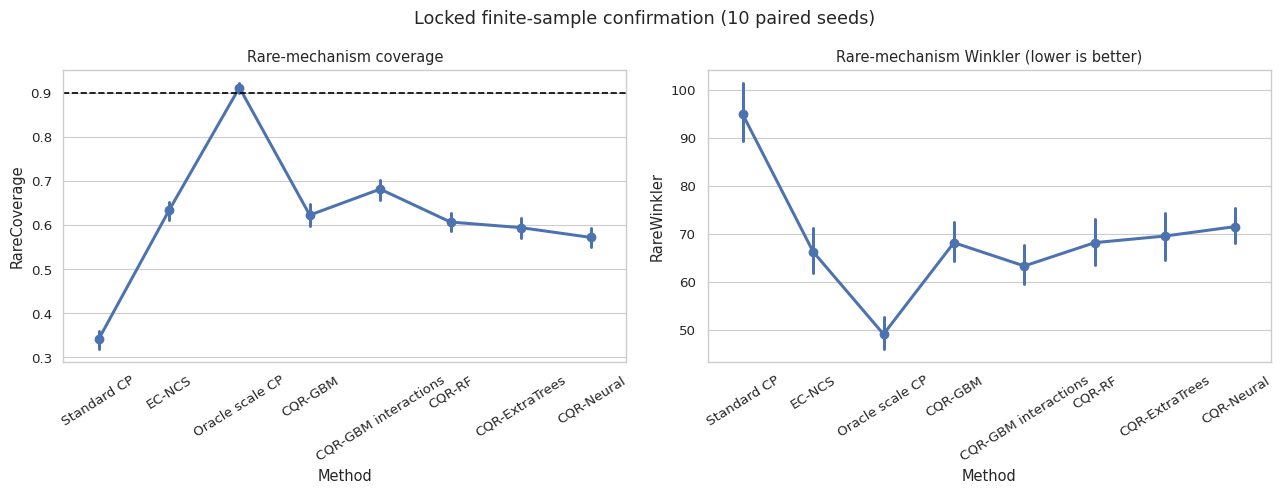

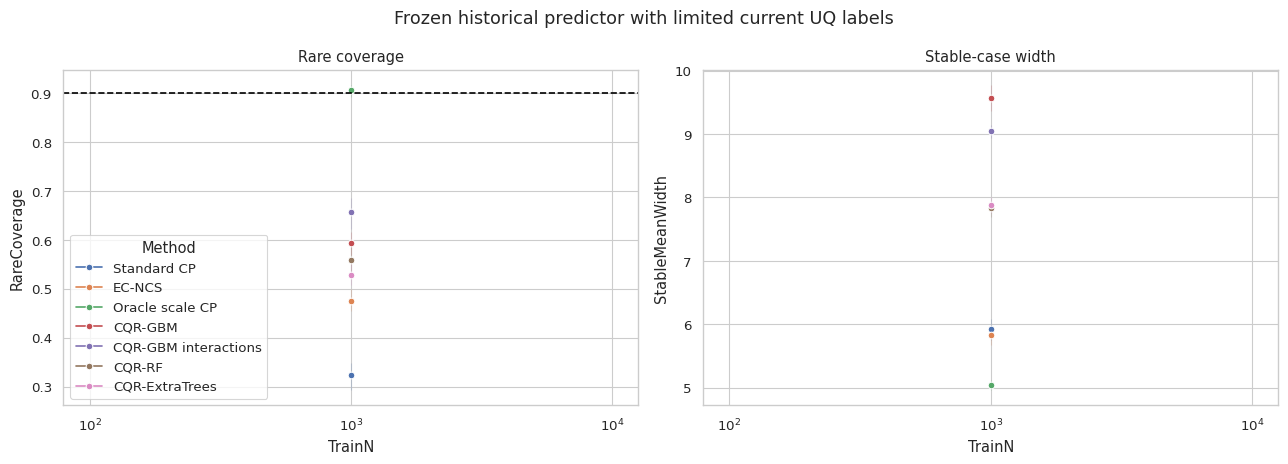

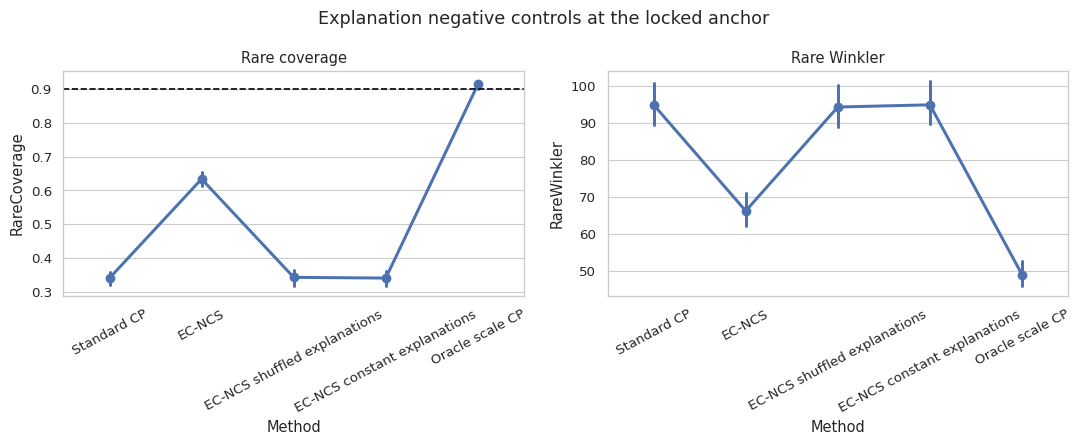

Results archive: /content/ec_ncs_rare_mechanism_focused_results.zip

Locked anchor comparison:


,Method,Seeds,Coverage,RareCoverage,RareCoverageError,RareWinkler,StableMeanWidth,WorstMechanismCoverageError
0,CQR-ExtraTrees,10,0.902333,0.594813,0.305187,69.536411,6.811671,0.305187
1,CQR-GBM,10,0.900533,0.623291,0.276709,68.151891,7.547144,0.276709
2,CQR-GBM interactions,10,0.899217,0.682208,0.217792,63.276913,6.899324,0.217792
3,CQR-Neural,10,0.900450,0.572411,0.327589,71.511045,8.163994,0.327589
4,CQR-RF,10,0.902517,0.607475,0.292525,68.151657,6.483602,0.292525
5,EC-NCS,10,0.900183,0.633811,0.266189,66.246039,6.624708,0.266189
6,EC-NCS constant explanations,10,0.901783,0.341370,0.558630,94.921386,6.252952,0.558630
7,EC-NCS shuffled explanations,10,0.902517,0.343549,0.556451,94.328634,6.367790,0.556451
8,OOF Normalized CP,10,0.902000,0.459226,0.440774,82.345644,6.125303,0.440774
9,Oracle scale CP,10,0.902967,0.912784,0.019726,49.039546,5.425943,0.019796



Significant Holm-adjusted comparisons:


,Experiment,TrainN,RareProbability,Reference,Method,Metric,MeanDifference_EC_minus_reference,WilcoxonP,Seeds,HolmAdjustedP


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
"""Focused, pre-registered rare-mechanism confirmation for EC-NCS.

Colab usage
------------
    %run /content/EC_NCS_Rare_Mechanism_Stress_Test.py

This computationally focused version tests the locked primary setting and one
model-reuse deployment setting. It does not tune on test outcomes or guarantee
that EC-NCS will win. It uses independent training, calibration, and test
samples; strong CQR baselines; explanation negative controls; an oracle
diagnostic; ten paired seeds; confidence intervals; and Holm-corrected paired
tests. Progress is checkpointed after every completed seed and resumed safely.
"""

# %% Setup
import importlib.util, subprocess, sys
required={"shap":"shap>=0.46","openpyxl":"openpyxl>=3.1"}
missing=[pkg for mod,pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])

import gc, json, math, os, random, shutil, time, warnings
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import torch
import torch.nn as nn
from IPython.display import display
from scipy.stats import wilcoxon
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid",context="paper",font_scale=1.1)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",DEVICE)
if torch.cuda.is_available(): print("GPU:",torch.cuda.get_device_name(0))


@dataclass
class Config:
    # Set EC_NCS_OUTDIR to a mounted Google Drive folder for cross-session resume.
    outdir:str=os.environ.get("EC_NCS_OUTDIR","/content/ec_ncs_rare_mechanism_focused_results")
    clean_run:bool=False
    resume:bool=True
    seeds:tuple=tuple(range(1001,1011))            # 10 locked paired repetitions
    nominal_coverage:float=.90
    dimension:int=30
    main_train_sizes:tuple=(5000,)                 # locked primary setting
    main_rare_probability:float=.05
    prevalence_train_size:int=5000
    rare_probabilities:tuple=(.05,)                # no redundant prevalence sweep
    test_size:int=6000
    calibration_size:int=2500
    point_history_size:int=30000
    reuse_uq_sizes:tuple=(1000,)                   # locked limited-UQ deployment
    reuse_test_size:int=6000
    point_trees:int=200
    point_min_leaf:int=3
    cqr_trees:int=120
    cqr_min_leaf:int=5
    gbm_estimators:int=120
    scale_trees:int=120
    scale_min_leaf:int=20
    oof_folds:int=3
    explanation_batch_size:int=2048
    neural_epochs:int=50
    neural_batch:int=512
    neural_patience:int=8
    run_neural_cqr:bool=True
    # Neural CQR is run only at the locked primary setting.
    neural_anchor_n:int=5000
    neural_anchor_pi:float=.05
    bootstrap_resamples:int=1000
    rare_scale:float=6.0
    stable_scale:float=1.0
    heavy_tail_df:float=3.0
    min_rare_calibration:int=25
    auto_download_zip:bool=True


CFG=Config(); ALPHA=1-CFG.nominal_coverage
if os.environ.get("EC_NCS_SMOKE","0")=="1":
    CFG.seeds=(1001,1002); CFG.main_train_sizes=(1000,); CFG.prevalence_train_size=1000
    CFG.rare_probabilities=(.05,.10); CFG.test_size=1000; CFG.calibration_size=500
    CFG.point_history_size=2000; CFG.reuse_uq_sizes=(500,); CFG.reuse_test_size=1000
    CFG.point_trees=30; CFG.cqr_trees=25; CFG.gbm_estimators=25; CFG.scale_trees=25
    CFG.neural_epochs=3; CFG.neural_patience=2; CFG.run_neural_cqr=False
    CFG.neural_anchor_n=1000; CFG.neural_anchor_pi=.05; CFG.bootstrap_resamples=50
OUT=Path(CFG.outdir)
if CFG.clean_run and OUT.exists():
    backup=OUT.with_name(OUT.name+"_backup_"+time.strftime("%Y%m%d_%H%M%S"))
    shutil.move(str(OUT),str(backup)); print("Previous results preserved:",backup)
for folder in (OUT,OUT/"figures",OUT/"supplementary",OUT/"checkpoints"):
    folder.mkdir(parents=True,exist_ok=True)
(OUT/"locked_config.json").write_text(json.dumps(asdict(CFG),indent=2))
print("Focused configuration:",CFG)
print("Expected completed settings:",len(CFG.seeds)*(len(CFG.main_train_sizes)+len(CFG.reuse_uq_sizes)))


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False


def conformal_quantile(scores):
    scores=np.asarray(scores,float).reshape(-1); scores=scores[np.isfinite(scores)]
    if not len(scores): raise RuntimeError("No finite calibration scores")
    level=min(1.,math.ceil((len(scores)+1)*(1-ALPHA))/len(scores))
    return float(np.quantile(scores,level,method="higher"))


def interval_metrics(y,lo,hi,rare):
    y=np.asarray(y); lo=np.asarray(lo); hi=np.asarray(hi); rare=np.asarray(rare,bool)
    covered=(y>=lo)&(y<=hi); width=hi-lo
    penalty=(2/ALPHA)*(lo-y)*(y<lo)+(2/ALPHA)*(y-hi)*(y>hi)
    winkler=width+penalty
    def part(mask,prefix):
        if not mask.any(): return {}
        cov=float(covered[mask].mean())
        return {prefix+"N":int(mask.sum()),prefix+"Coverage":cov,
                prefix+"CoverageError":abs(cov-CFG.nominal_coverage),
                prefix+"MeanWidth":float(width[mask].mean()),
                prefix+"Winkler":float(winkler[mask].mean())}
    out={**part(np.ones(len(y),bool),""),**part(rare,"Rare"),**part(~rare,"Stable")}
    out["WorstMechanismCoverageError"]=max(out["RareCoverageError"],out["StableCoverageError"])
    return out


# %% Data-generating process
def generate_data(n,rare_probability,seed,mechanism_threshold=None):
    """Generate data using a fixed, outcome-independent mechanism threshold.

    The threshold is estimated from the training covariates and then reused
    unchanged for calibration and test data. Thus neither calibration/test
    labels nor calibration/test prevalence define the mechanism.
    """
    rng=np.random.default_rng(seed)
    X=rng.normal(size=(n,CFG.dimension)).astype(np.float32)
    # Exact prevalence is fixed prospectively using a score rank. The mechanism
    # combines an interaction and a fourth-feature gate and is therefore rare,
    # nonlinear, observable from X, and independent of the realized noise.
    # Rarity is tied to the magnitude of the same nonlinear interaction used
    # by the point function. This is essential: explanations should be useful
    # only when model reliance truly carries residual-scale information.
    mechanism_score=np.maximum(X[:,0]*X[:,1],0)*np.abs(X[:,2])
    threshold=(float(np.quantile(mechanism_score,1-rare_probability))
               if mechanism_threshold is None else float(mechanism_threshold))
    rare=mechanism_score>=threshold
    interaction=(X[:,0]*X[:,1]>0).astype(float)
    mean=2*X[:,0]+X[:,1]+4*interaction*X[:,2]
    scale=np.where(rare,CFG.rare_scale,CFG.stable_scale)
    noise=rng.standard_t(CFG.heavy_tail_df,size=n)
    y=(mean+scale*noise).astype(np.float32)
    return X,y,rare,scale.astype(np.float32),threshold


def explicit_features(X):
    """Generic low-order interactions; does not receive the oracle rare label."""
    X=np.asarray(X)
    extras=np.column_stack([X[:,0]*X[:,1],X[:,0]*X[:,2],X[:,1]*X[:,2],
                            X[:,0]*X[:,3],X[:,1]*X[:,3],X[:,2]*X[:,3]])
    return np.column_stack([X,extras]).astype(np.float32)


def fit_point_model(X,y,seed):
    return RandomForestRegressor(n_estimators=CFG.point_trees,min_samples_leaf=CFG.point_min_leaf,
        max_features=.8,n_jobs=-1,random_state=seed).fit(X,y)


def oof_point_residuals(X,y,seed):
    residual=np.empty(len(y),float)
    folds=KFold(CFG.oof_folds,shuffle=True,random_state=seed)
    for fold,(fit_idx,val_idx) in enumerate(folds.split(X)):
        model=RandomForestRegressor(n_estimators=max(120,CFG.point_trees//2),
            min_samples_leaf=CFG.point_min_leaf,max_features=.8,n_jobs=-1,
            random_state=seed+fold).fit(X[fit_idx],y[fit_idx])
        residual[val_idx]=np.abs(y[val_idx]-model.predict(X[val_idx]))
    return residual


def _explanation_vectors_one_batch(model,X):
    explainer=shap.TreeExplainer(model,feature_perturbation="tree_path_dependent")
    values=np.asarray(explainer.shap_values(X,check_additivity=False),float)
    if values.ndim==3: values=values[...,0]
    absolute=np.abs(values); total=absolute.sum(axis=1,keepdims=True)+1e-10
    proportion=absolute/total
    entropy=-(proportion*np.log(proportion+1e-12)).sum(axis=1)/np.log(values.shape[1])
    top_share=proportion.max(axis=1)
    concentration=(proportion**2).sum(axis=1)
    # Preserve signed and absolute contributions of the four structural inputs;
    # include global concentration summaries and prediction sensitivity.
    return np.column_stack([values[:,:4],absolute[:,:4],top_share,entropy,
                            concentration,total[:,0]]).astype(np.float32)


def explanation_vectors(model,X):
    """Compute exact TreeSHAP-derived vectors in bounded-memory batches."""
    parts=[]
    for start in range(0,len(X),CFG.explanation_batch_size):
        stop=min(len(X),start+CFG.explanation_batch_size)
        parts.append(_explanation_vectors_one_batch(model,X[start:stop]))
    if not parts: raise RuntimeError("No rows supplied for explanation")
    return np.vstack(parts)


def fit_scale_model(explanation,residual,seed):
    target=np.log(np.asarray(residual)+1e-4)
    return ExtraTreesRegressor(n_estimators=CFG.scale_trees,min_samples_leaf=CFG.scale_min_leaf,
        max_features=.8,n_jobs=-1,random_state=seed).fit(explanation,target)


def predict_scale(model,explanation,normalizer=None):
    scale=np.exp(model.predict(explanation)); scale=np.clip(scale,.05,100.)
    if normalizer is None: normalizer=np.median(scale)
    return scale/max(normalizer,1e-8),normalizer


# %% CQR implementations
def conformalize_base_interval(ycal,lcal,ucal,ltest,utest):
    score=np.maximum(lcal-ycal,ycal-ucal); q=conformal_quantile(score)
    return ltest-q,utest+q


def gbm_cqr(Xtr,ytr,Xcal,ycal,Xtest,seed,with_interactions=False):
    if with_interactions:
        Xtr,Xcal,Xtest=map(explicit_features,(Xtr,Xcal,Xtest))
    models=[]
    for quantile,offset in [(ALPHA/2,0),(1-ALPHA/2,1)]:
        model=GradientBoostingRegressor(loss="quantile",alpha=quantile,
            n_estimators=CFG.gbm_estimators,max_depth=3,learning_rate=.04,
            min_samples_leaf=10,random_state=seed+offset).fit(Xtr,ytr)
        models.append(model)
    return conformalize_base_interval(ycal,models[0].predict(Xcal),models[1].predict(Xcal),
                                      models[0].predict(Xtest),models[1].predict(Xtest))


def forest_quantiles(model,X,quantiles):
    predictions=np.column_stack([tree.predict(X) for tree in model.estimators_])
    return [np.quantile(predictions,q,axis=1) for q in quantiles]


def qrf_cqr(Xtr,ytr,Xcal,ycal,Xtest,seed,extra=False):
    cls=ExtraTreesRegressor if extra else RandomForestRegressor
    model=cls(n_estimators=CFG.cqr_trees,min_samples_leaf=CFG.cqr_min_leaf,
              max_features=.8,n_jobs=-1,random_state=seed).fit(Xtr,ytr)
    lcal,ucal=forest_quantiles(model,Xcal,[ALPHA/2,1-ALPHA/2])
    ltest,utest=forest_quantiles(model,Xtest,[ALPHA/2,1-ALPHA/2])
    return conformalize_base_interval(ycal,lcal,ucal,ltest,utest)


class QuantileNet(nn.Module):
    def __init__(self,d):
        super().__init__(); self.net=nn.Sequential(nn.Linear(d,128),nn.ReLU(),nn.Dropout(.1),
            nn.Linear(128,128),nn.ReLU(),nn.Linear(128,2))
    def forward(self,x): return self.net(x)


def neural_cqr(Xtr,ytr,Xcal,ycal,Xtest,seed):
    set_seed(seed); scaler=StandardScaler().fit(Xtr)
    A=scaler.transform(Xtr).astype(np.float32); B=scaler.transform(Xcal).astype(np.float32); C=scaler.transform(Xtest).astype(np.float32)
    ymean,ystd=float(np.mean(ytr)),float(np.std(ytr)+1e-8); target=((ytr-ymean)/ystd).astype(np.float32)
    rng=np.random.default_rng(seed); order=rng.permutation(len(A)); cut=max(1,int(.85*len(A))); fit_idx,val_idx=order[:cut],order[cut:]
    net=QuantileNet(A.shape[1]).to(DEVICE); optimizer=torch.optim.AdamW(net.parameters(),lr=1e-3,weight_decay=1e-4)
    quantiles=torch.tensor([ALPHA/2,1-ALPHA/2],device=DEVICE).view(1,-1)
    best=np.inf; state=None; wait=0
    for epoch in range(CFG.neural_epochs):
        net.train(); shuffled=rng.permutation(fit_idx)
        for start in range(0,len(shuffled),CFG.neural_batch):
            idx=shuffled[start:start+CFG.neural_batch]
            xb=torch.tensor(A[idx],device=DEVICE); yb=torch.tensor(target[idx,None],device=DEVICE)
            error=yb-net(xb); loss=torch.maximum(quantiles*error,(quantiles-1)*error).mean()
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            xv=torch.tensor(A[val_idx],device=DEVICE); yv=torch.tensor(target[val_idx,None],device=DEVICE)
            error=yv-net(xv); val=float(torch.maximum(quantiles*error,(quantiles-1)*error).mean())
        if val<best-1e-5: best=val; state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}; wait=0
        else:
            wait+=1
            if wait>=CFG.neural_patience: break
    net.load_state_dict(state); net.eval()
    def predict(X):
        with torch.no_grad(): out=net(torch.tensor(X,device=DEVICE)).cpu().numpy()
        out=out*ystd+ymean; return np.minimum(out[:,0],out[:,1]),np.maximum(out[:,0],out[:,1])
    lcal,ucal=predict(B); ltest,utest=predict(C)
    result=conformalize_base_interval(ycal,lcal,ucal,ltest,utest)
    del net; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return result


# %% One independent experiment
def evaluate_one(seed,n_train,rare_probability,experiment,point_model=None):
    set_seed(seed)
    Xtr,ytr,rtr,strue,mechanism_threshold=generate_data(
        n_train,rare_probability,seed*100+1)
    Xcal,ycal,rcal,scaletrue,_=generate_data(
        CFG.calibration_size,rare_probability,seed*100+2,mechanism_threshold)
    Xte,yte,rte,stetrue,_=generate_data(
        CFG.test_size if experiment!="model_reuse" else CFG.reuse_test_size,
        rare_probability,seed*100+3,mechanism_threshold)
    if rcal.sum()<CFG.min_rare_calibration or rte.sum()<50:
        raise RuntimeError("Insufficient rare calibration/test observations")
    point=point_model if point_model is not None else fit_point_model(Xtr,ytr,seed)
    pcal=point.predict(Xcal); pte=point.predict(Xte); residual=np.abs(ycal-pcal)
    intervals={}
    q=conformal_quantile(residual); intervals["Standard CP"]=(pte-q,pte+q)

    # Normalized CP: residual scale from raw X and OOF training residuals.
    # If the point model was trained on an independent historical sample, its
    # current-sample residuals are already out of training sample. Otherwise,
    # use cross-fitting to prevent in-sample residual optimism.
    oof=(np.abs(ytr-point.predict(Xtr)) if point_model is not None
         else oof_point_residuals(Xtr,ytr,seed+1000))
    raw_scale=ExtraTreesRegressor(n_estimators=CFG.scale_trees,min_samples_leaf=CFG.scale_min_leaf,
        n_jobs=-1,random_state=seed+1100).fit(Xtr,np.log(oof+1e-4))
    sca=np.exp(raw_scale.predict(Xcal)); ste=np.exp(raw_scale.predict(Xte)); norm=np.median(np.exp(raw_scale.predict(Xtr)))
    sca,ste=sca/norm,ste/norm; qn=conformal_quantile(residual/sca)
    intervals["OOF Normalized CP"]=(pte-qn*ste,pte+qn*ste)

    # EC-NCS scale uses only point-model explanations and OOF residuals from training.
    # SHAP is evaluated on all rows required by the scale learner and calibration.
    etr=explanation_vectors(point,Xtr); ecal=explanation_vectors(point,Xcal); ete=explanation_vectors(point,Xte)
    scale_model=fit_scale_model(etr,oof,seed+1200)
    str_,normalizer=predict_scale(scale_model,etr); sca,_=predict_scale(scale_model,ecal,normalizer); ste,_=predict_scale(scale_model,ete,normalizer)
    qe=conformal_quantile(residual/sca); intervals["EC-NCS"]=(pte-qe*ste,pte+qe*ste)

    # Negative controls must use the same learner and data sizes.
    rng=np.random.default_rng(seed+1300); shuffled=etr[rng.permutation(len(etr))]
    shuffled_model=fit_scale_model(shuffled,oof,seed+1301)
    sh_cal=ecal[rng.permutation(len(ecal))]; sh_test=ete[rng.permutation(len(ete))]
    _,sh_norm=predict_scale(shuffled_model,shuffled); shca,_=predict_scale(shuffled_model,sh_cal,sh_norm); shte,_=predict_scale(shuffled_model,sh_test,sh_norm)
    qsh=conformal_quantile(residual/shca); intervals["EC-NCS shuffled explanations"]=(pte-qsh*shte,pte+qsh*shte)
    intervals["EC-NCS constant explanations"]=(pte-q,pte+q)

    # Oracle scale is an unattainable diagnostic lower bound.
    qo=conformal_quantile(residual/scaletrue); intervals["Oracle scale CP"]=(pte-qo*stetrue,pte+qo*stetrue)
    intervals["CQR-GBM"]=gbm_cqr(Xtr,ytr,Xcal,ycal,Xte,seed)
    intervals["CQR-GBM interactions"]=gbm_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+10,True)
    intervals["CQR-RF"] = qrf_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+20,False)
    intervals["CQR-ExtraTrees"] = qrf_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+30,True)
    if CFG.run_neural_cqr and n_train==CFG.neural_anchor_n and abs(rare_probability-CFG.neural_anchor_pi)<1e-12:
        intervals["CQR-Neural"]=neural_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+40)

    rows=[]
    for method,(lo,hi) in intervals.items():
        rows.append({"Experiment":experiment,"Seed":seed,"TrainN":n_train,
            "RareProbability":rare_probability,"Method":method,
            "PointMAE":float(np.mean(np.abs(yte-pte))),**interval_metrics(yte,lo,hi,rte)})
    return rows


# %% Locked primary and model-reuse confirmation
progress_path=OUT/"checkpoints/progress.csv"
if CFG.resume and progress_path.exists():
    previous=pd.read_csv(progress_path)
    results=previous.to_dict("records")
    print(f"Resuming with {len(previous)} saved method rows from {progress_path}")
else:
    results=[]


def checkpoint():
    frame=pd.DataFrame(results)
    temporary=progress_path.with_suffix(".tmp")
    frame.to_csv(temporary,index=False)
    temporary.replace(progress_path)


def setting_complete(experiment,seed,n_train,rare_probability):
    if not results: return False
    frame=pd.DataFrame(results)
    mask=(frame["Experiment"].eq(experiment)&frame["Seed"].eq(seed)&
          frame["TrainN"].eq(n_train)&
          np.isclose(frame["RareProbability"].astype(float),rare_probability))
    # Every completed evaluation contains at least the fixed non-neural methods.
    required={"Standard CP","OOF Normalized CP","EC-NCS","CQR-GBM",
              "CQR-GBM interactions","CQR-RF","CQR-ExtraTrees",
              "EC-NCS shuffled explanations","EC-NCS constant explanations",
              "Oracle scale CP"}
    return required.issubset(set(frame.loc[mask,"Method"]))

for n_train in CFG.main_train_sizes:
    for seed in CFG.seeds:
        if setting_complete("sample_size",seed,n_train,CFG.main_rare_probability):
            print(f"Skipping completed primary setting n={n_train}, seed={seed}")
            continue
        print(f"Sample-size sweep n={n_train}, seed={seed}")
        results+=evaluate_one(seed,n_train,CFG.main_rare_probability,"sample_size")
        checkpoint()

for rare_probability in CFG.rare_probabilities:
    if rare_probability==CFG.main_rare_probability: continue  # already evaluated above at n=5000
    for seed in CFG.seeds:
        if setting_complete("prevalence",seed,CFG.prevalence_train_size,rare_probability):
            print(f"Skipping completed prevalence setting pi={rare_probability}, seed={seed}")
            continue
        print(f"Prevalence sweep pi={rare_probability}, seed={seed}")
        results+=evaluate_one(seed,CFG.prevalence_train_size,rare_probability,"prevalence")
        checkpoint()

# Frozen historical point predictor; UQ methods see only the current UQ labels.
for seed in CFG.seeds:
    needed=[n for n in CFG.reuse_uq_sizes
            if not setting_complete("model_reuse",seed,n,CFG.main_rare_probability)]
    if not needed:
        print(f"Skipping completed model-reuse settings for seed={seed}")
        continue
    print(f"Historical point model seed={seed}")
    Xhist,yhist,_,_,_=generate_data(
        CFG.point_history_size,CFG.main_rare_probability,seed*100+77)
    frozen=fit_point_model(Xhist,yhist,seed+7000)
    for n_uq in needed:
        print(f"  model-reuse UQ n={n_uq}")
        results+=evaluate_one(seed,n_uq,CFG.main_rare_probability,"model_reuse",point_model=frozen)
        checkpoint()
    del frozen; gc.collect()

results=pd.DataFrame(results)
results.to_csv(OUT/"all_seed_metrics.csv",index=False)


# %% Statistical analysis
PRIMARY_METHODS=["Standard CP","OOF Normalized CP","CQR-GBM","CQR-GBM interactions",
                 "CQR-RF","CQR-ExtraTrees","CQR-Neural","EC-NCS","Oracle scale CP"]
PRIMARY_ENDPOINTS=["RareCoverageError","WorstMechanismCoverageError","RareWinkler","StableMeanWidth"]

def bootstrap_summary(frame):
    rng=np.random.default_rng(2027); rows=[]
    keys=["Experiment","TrainN","RareProbability","Method"]
    for key,block in frame.groupby(keys,dropna=False):
        for metric in ["Coverage","RareCoverage","StableCoverage","RareCoverageError",
                       "WorstMechanismCoverageError","RareWinkler","StableMeanWidth","Winkler"]:
            values=block.groupby("Seed")[metric].mean().dropna().to_numpy()
            if not len(values): continue
            means=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(CFG.bootstrap_resamples)])
            rows.append({**dict(zip(keys,key)),"Metric":metric,"Mean":values.mean(),
                         "CI95Lower":np.quantile(means,.025),"CI95Upper":np.quantile(means,.975),"Seeds":len(values)})
    return pd.DataFrame(rows)


def holm_adjust(pvalues):
    p=np.asarray(pvalues,float); order=np.argsort(p); adjusted=np.empty(len(p)); running=0.
    for rank,index in enumerate(order):
        running=max(running,min(1.,(len(p)-rank)*p[index])); adjusted[index]=running
    return adjusted


def paired_tests(frame,reference="EC-NCS"):
    rows=[]; group_keys=["Experiment","TrainN","RareProbability"]
    for key,block in frame.groupby(group_keys):
        for method in sorted(set(block.Method)-{reference}):
            for metric in PRIMARY_ENDPOINTS:
                pivot=block[block.Method.isin([reference,method])].pivot_table(index="Seed",columns="Method",values=metric).dropna()
                if len(pivot)<min(10,len(CFG.seeds)): continue
                delta=pivot[reference]-pivot[method]
                try: p=float(wilcoxon(delta).pvalue)
                except ValueError: p=1.
                rows.append({**dict(zip(group_keys,key)),"Reference":method,"Method":reference,
                    "Metric":metric,"MeanDifference_EC_minus_reference":delta.mean(),"WilcoxonP":p,"Seeds":len(delta)})
    out=pd.DataFrame(rows)
    if len(out): out["HolmAdjustedP"]=holm_adjust(out.WilcoxonP)
    return out


summary=bootstrap_summary(results); tests=paired_tests(results)
summary.to_csv(OUT/"bootstrap_confidence_intervals.csv",index=False)
tests.to_csv(OUT/"paired_tests_holm.csv",index=False)

# Locked success assessment; generated after all results without changing models.
anchor=results[(results.Experiment=="sample_size")&(results.TrainN==CFG.neural_anchor_n)&
               (results.RareProbability==CFG.neural_anchor_pi)]
anchor_summary=anchor.groupby("Method",as_index=False).agg(Seeds=("Seed","nunique"),
    Coverage=("Coverage","mean"),RareCoverage=("RareCoverage","mean"),
    RareCoverageError=("RareCoverageError","mean"),RareWinkler=("RareWinkler","mean"),
    StableMeanWidth=("StableMeanWidth","mean"),WorstMechanismCoverageError=("WorstMechanismCoverageError","mean"))
anchor_summary.to_csv(OUT/"anchor_method_comparison.csv",index=False)

# %% Publication figures
plot_methods=[m for m in ["EC-NCS","CQR-GBM","CQR-GBM interactions","CQR-RF","CQR-ExtraTrees","CQR-Neural","Standard CP","Oracle scale CP"] if m in set(results.Method)]
sample_plot=results[(results.Experiment=="sample_size")&results.Method.isin(plot_methods)]
fig,axes=plt.subplots(1,2,figsize=(13,5.0))
sns.pointplot(data=sample_plot,x="Method",y="RareCoverage",errorbar=("ci",95),ax=axes[0])
axes[0].axhline(CFG.nominal_coverage,color="black",ls="--")
axes[0].tick_params(axis="x",rotation=32); axes[0].set_title("Rare-mechanism coverage")
sns.pointplot(data=sample_plot,x="Method",y="RareWinkler",errorbar=("ci",95),ax=axes[1])
axes[1].tick_params(axis="x",rotation=32); axes[1].set_title("Rare-mechanism Winkler (lower is better)")
fig.suptitle(f"Locked finite-sample confirmation ({len(CFG.seeds)} paired seeds)")
fig.tight_layout()
fig.savefig(OUT/"figures/fig_locked_primary_confirmation.pdf",bbox_inches="tight")
fig.savefig(OUT/"figures/fig_locked_primary_confirmation.png",dpi=300,bbox_inches="tight")
plt.show()

prevalence_plot=pd.concat([results[(results.Experiment=="prevalence")],
    results[(results.Experiment=="sample_size")&(results.TrainN==CFG.prevalence_train_size)&
            (results.RareProbability==CFG.main_rare_probability)]],ignore_index=True)
prevalence_plot=prevalence_plot[prevalence_plot.Method.isin(plot_methods)]
if prevalence_plot.RareProbability.nunique()>1:
    plt.figure(figsize=(9,4.8))
    sns.lineplot(data=prevalence_plot,x="RareProbability",y="RareCoverageError",
                 hue="Method",marker="o",errorbar=("ci",95))
    plt.ylabel("Rare-mechanism coverage error")
    plt.title(f"Sensitivity to rare-mechanism prevalence ({len(CFG.seeds)} seeds)")
    plt.tight_layout()
    plt.savefig(OUT/"figures/fig_prevalence_stress.pdf",bbox_inches="tight")
    plt.savefig(OUT/"figures/fig_prevalence_stress.png",dpi=300,bbox_inches="tight")
    plt.show()

reuse_plot=results[(results.Experiment=="model_reuse")&results.Method.isin(plot_methods)]
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
sns.lineplot(data=reuse_plot,x="TrainN",y="RareCoverage",hue="Method",marker="o",errorbar=("ci",95),ax=axes[0]); axes[0].axhline(.9,color="black",ls="--"); axes[0].set_xscale("log"); axes[0].set_title("Rare coverage")
sns.lineplot(data=reuse_plot,x="TrainN",y="StableMeanWidth",hue="Method",marker="o",errorbar=("ci",95),ax=axes[1],legend=False); axes[1].set_xscale("log"); axes[1].set_title("Stable-case width")
fig.suptitle("Frozen historical predictor with limited current UQ labels"); fig.tight_layout()
fig.savefig(OUT/"figures/fig_model_reuse.pdf",bbox_inches="tight"); fig.savefig(OUT/"figures/fig_model_reuse.png",dpi=300,bbox_inches="tight"); plt.show()

controls=anchor[anchor.Method.isin(["EC-NCS","EC-NCS shuffled explanations","EC-NCS constant explanations","Standard CP","Oracle scale CP"])]
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
sns.pointplot(data=controls,x="Method",y="RareCoverage",errorbar=("ci",95),ax=axes[0]); axes[0].axhline(.9,color="black",ls="--"); axes[0].tick_params(axis="x",rotation=28); axes[0].set_title("Rare coverage")
sns.pointplot(data=controls,x="Method",y="RareWinkler",errorbar=("ci",95),ax=axes[1]); axes[1].tick_params(axis="x",rotation=28); axes[1].set_title("Rare Winkler")
fig.suptitle("Explanation negative controls at the locked anchor"); fig.tight_layout()
fig.savefig(OUT/"figures/fig_explanation_controls.pdf",bbox_inches="tight"); fig.savefig(OUT/"figures/fig_explanation_controls.png",dpi=300,bbox_inches="tight"); plt.show()

# %% Integrity report and archive
expected_sample=len(CFG.seeds)*len(CFG.main_train_sizes)
integrity={"script":"EC_NCS_Rare_Mechanism_Focused_Colab.py","test_labels_used_for_selection":False,
    "locked_seeds":list(CFG.seeds),"sample_size_settings_complete":int(results[results.Experiment=="sample_size"].groupby(["Seed","TrainN"]).ngroups)==expected_sample,
    "negative_controls_present":all(m in set(results.Method) for m in ["EC-NCS shuffled explanations","EC-NCS constant explanations"]),
    "oracle_is_diagnostic_only":True,"neural_cqr_anchor_only":CFG.run_neural_cqr,
    "focused_confirmation":True,"checkpoint_resume":CFG.resume,
    "primary_endpoints":PRIMARY_ENDPOINTS,"multiplicity":"Holm across the complete saved paired-test family",
    "claim_rule":"Report observed outcomes, including negative EC-NCS results; never retune using test tables."}
(OUT/"integrity.json").write_text(json.dumps(integrity,indent=2))
anchor_summary.to_excel(OUT/"table_anchor_comparison.xlsx",index=False)
tests.to_excel(OUT/"table_paired_tests_holm.xlsx",index=False)
(OUT/"README.txt").write_text(
    "This is a focused controlled finite-sample confirmation, not proof that CQR is incapable of learning the mechanism.\n"
    "All method choices, seeds and endpoints are locked in locked_config.json.\n"
    "The rare label is defined from X before noise and is never selected using test residuals.\n"
    "CQR-Neural is run only at the prespecified n=5000, pi=0.05 anchor for computational feasibility.\n"
    "Oracle scale CP is unattainable and used only as a diagnostic lower bound.\n"
    "Only Holm-adjusted tests may support comparative significance claims.\n")
archive=shutil.make_archive("/content/ec_ncs_rare_mechanism_focused_results","zip",OUT)
print("Results archive:",archive)
print("\nLocked anchor comparison:"); display(anchor_summary)
print("\nSignificant Holm-adjusted comparisons:")
if len(tests): display(tests[tests.HolmAdjustedP<.05])
else: print("No paired tests were produced (expected only in a very small smoke run).")
if CFG.auto_download_zip:
    try:
        from google.colab import files
        files.download(archive)
    except Exception as error:
        print("Automatic download unavailable; download manually:",archive,"|",error)

In [ ]:
from google.colab import files
files.download("/content/ec_ncs_rare_mechanism_focused_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ZIP and download the complete results directory
import os
import shutil
from pathlib import Path
from google.colab import files

RESULT_DIR = Path(
    os.environ.get(
        "EC_NCS_OUTDIR",
        "/content/ec_ncs_rare_mechanism_focused_results"
    )
)

if not RESULT_DIR.exists():
    raise FileNotFoundError(f"Results directory not found: {RESULT_DIR}")

archive_base = Path("/content/ec_ncs_rare_mechanism_focused_results_complete")
archive_path = shutil.make_archive(
    str(archive_base),
    "zip",
    root_dir=str(RESULT_DIR.parent),
    base_dir=RESULT_DIR.name
)

size_mb = Path(archive_path).stat().st_size / (1024**2)
print(f"Created: {archive_path}")
print(f"Archive size: {size_mb:.2f} MB")

files.download(archive_path)

Created: /content/ec_ncs_rare_mechanism_focused_results_complete.zip
Archive size: 0.72 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/ec_ncs_rare_mechanism_focused_results.zip")

FileNotFoundError: Cannot find file: /content/ec_ncs_rare_mechanism_focused_results.zip

In [ ]:
from google.colab import files
files.upload()

Saving EC_NCS_Rare_Mechanism_Validation_Gated_Colab.py to EC_NCS_Rare_Mechanism_Validation_Gated_Colab.py


{'EC_NCS_Rare_Mechanism_Validation_Gated_Colab.py': b'"""Validation-gated rare-mechanism confirmation for EC-NCS.\n\nColab usage\n------------\n    %run /content/EC_NCS_Rare_Mechanism_Stress_Test.py\n\nThe explanation scale and gate are learned using training-only diagnostics.\nThe gate compares candidate EC-NCS with Standard CP on a held-out inner subset\nand accepts adaptation only when a prespecified Winkler improvement and two\ncoverage guardrails are satisfied. The exact candidate evaluated by the gate\nis retained without refitting. The untouched outer calibration set is then\nused exactly once for conformal calibration. A rejected candidate reverts\nexactly to Standard CP.\n\nThe script does not tune on test outcomes or guarantee that EC-NCS will beat\nCQR. It evaluates one locked primary setting and one locked model-reuse setting\nusing strong CQR baselines, explanation negative controls, an oracle diagnostic,\nten paired seeds, confidence intervals, and Holm-corrected paired t

In [ ]:
%run /content/EC_NCS_Rare_Mechanism_Validation_Gated_Colab.py

Device: cuda
GPU: Tesla T4
Focused configuration: Config(outdir='/content/ec_ncs_rare_mechanism_gated_results', clean_run=False, resume=True, seeds=(1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010), nominal_coverage=0.9, dimension=30, main_train_sizes=(5000,), main_rare_probability=0.05, prevalence_train_size=5000, rare_probabilities=(0.05,), test_size=6000, calibration_size=2500, point_history_size=30000, reuse_uq_sizes=(1000,), reuse_test_size=6000, run_explanation_aligned_study=True, aligned_uq_size=1000, aligned_rare_probability=0.1, aligned_rare_scale=8.0, run_aligned_neural_cqr=True, point_trees=200, point_min_leaf=3, cqr_trees=120, cqr_min_leaf=5, gbm_estimators=120, scale_trees=120, scale_min_leaf=20, oof_folds=3, gate_fraction=0.25, gate_min_rows=250, gate_min_relative_winkler_gain=0.01, gate_max_coverage_drop_vs_standard=0.01, gate_max_nominal_undercoverage=0.03, explanation_batch_size=2048, neural_epochs=50, neural_batch=512, neural_patience=8, run_neural_cqr=True

In [ ]:
from google.colab import files
files.download("/content/ec_ncs_rare_mechanism_gated_results.zip")

FileNotFoundError: Cannot find file: /content/ec_ncs_rare_mechanism_gated_results.zip

Device: cuda
GPU: Tesla T4
Mounted at /content/drive
Persistent checkpoints: /content/drive/MyDrive/ec_ncs_rare_mechanism_gated_results
Focused configuration: Config(outdir='/content/drive/MyDrive/ec_ncs_rare_mechanism_gated_results', clean_run=False, resume=True, max_session_hours=8.0, session_stop_reserve_minutes=30, continue_after_setting_error=True, seeds=(1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010), nominal_coverage=0.9, dimension=30, main_train_sizes=(5000,), main_rare_probability=0.05, prevalence_train_size=5000, rare_probabilities=(0.05,), test_size=6000, calibration_size=2500, point_history_size=30000, reuse_uq_sizes=(1000,), reuse_test_size=6000, run_explanation_aligned_study=True, aligned_uq_size=1000, aligned_rare_probability=0.1, aligned_rare_scale=8.0, run_aligned_neural_cqr=True, point_trees=200, point_min_leaf=3, cqr_trees=120, cqr_min_leaf=5, gbm_estimators=120, scale_trees=120, scale_min_leaf=20, oof_folds=3, gate_fraction=0.25, gate_min_rows=250, gate

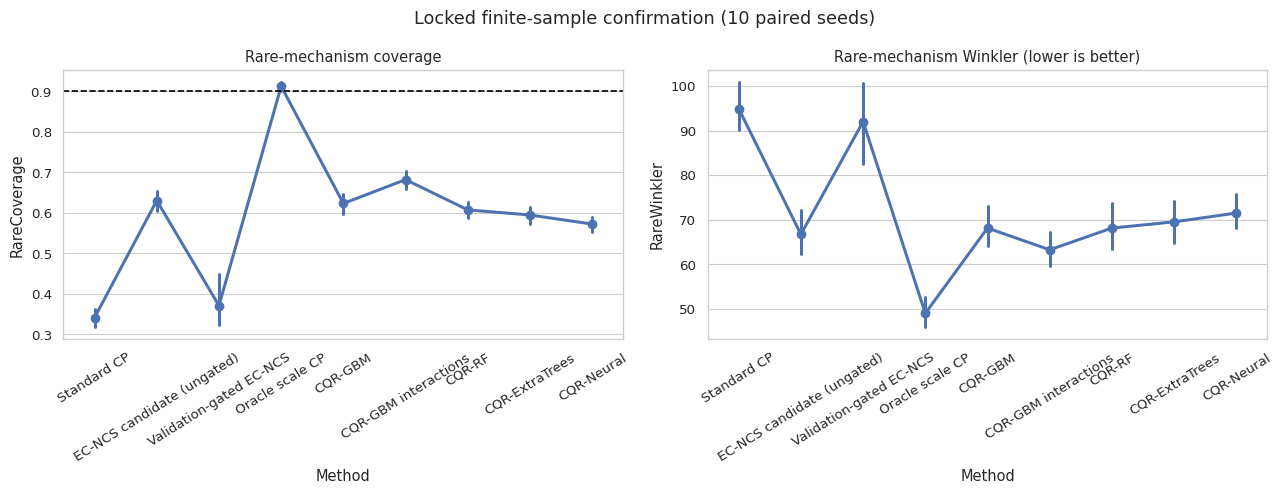

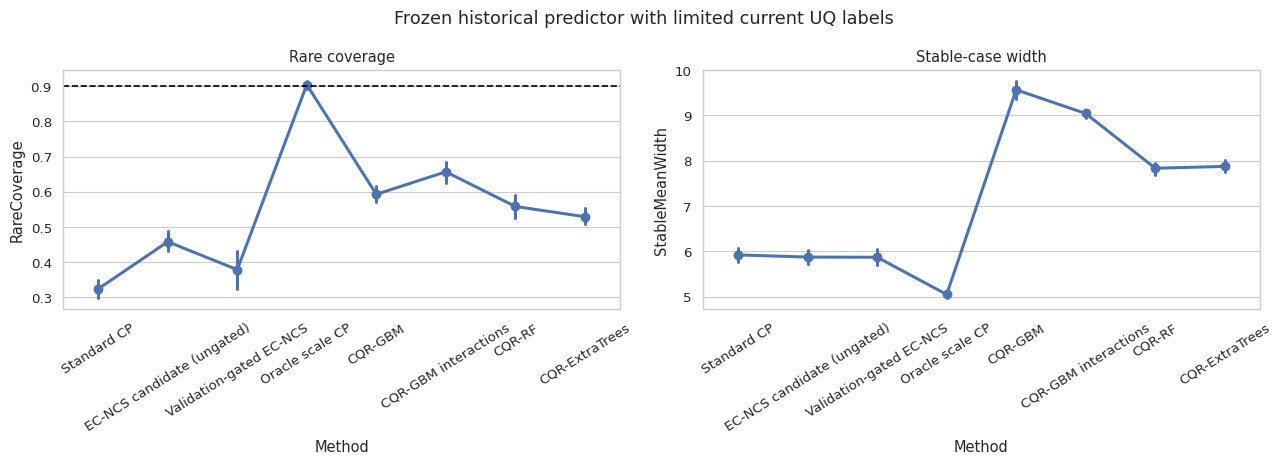

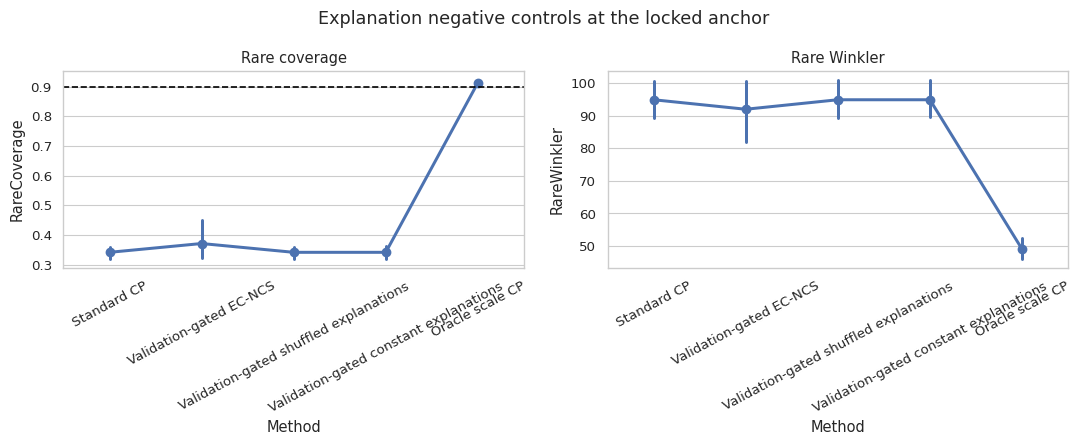

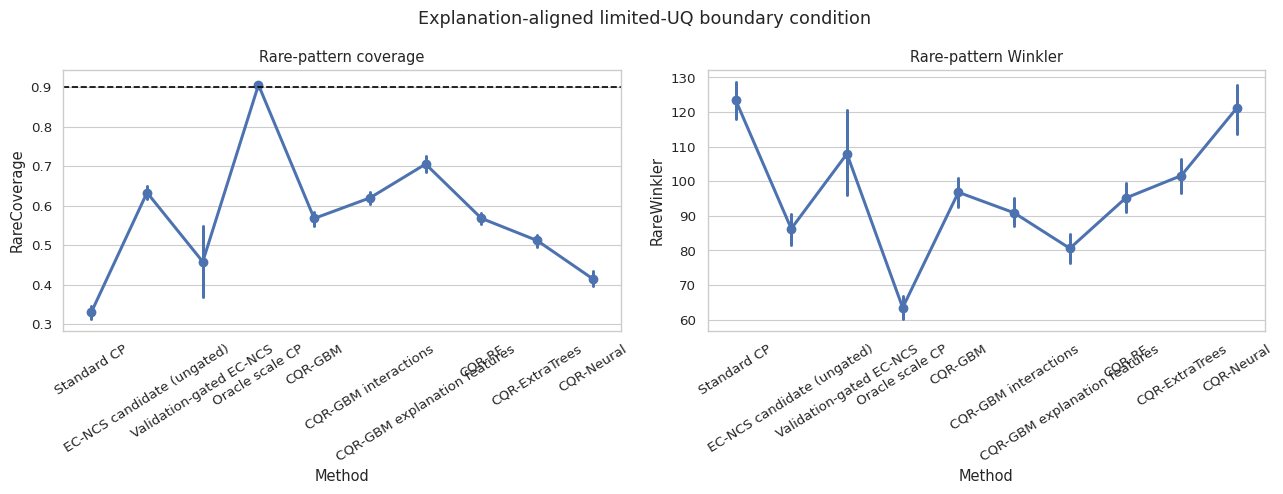

[   92.9 min] Checkpoint saved: 360 method rows (complete)
Results archive: /content/drive/MyDrive/ec_ncs_rare_mechanism_gated_results_archive.zip

Locked anchor comparison:


,Method,Seeds,Coverage,RareCoverage,RareCoverageError,RareWinkler,StableMeanWidth,WorstMechanismCoverageError
0,CQR-ExtraTrees,10,0.902333,0.594813,0.305187,69.536411,6.811671,0.305187
1,CQR-GBM,10,0.900533,0.623291,0.276709,68.151891,7.547144,0.276709
2,CQR-GBM interactions,10,0.899217,0.682208,0.217792,63.276913,6.899324,0.217792
3,CQR-Neural,10,0.900450,0.572411,0.327589,71.511045,8.163994,0.327589
4,CQR-RF,10,0.902517,0.607475,0.292525,68.151657,6.483602,0.292525
5,EC-NCS candidate (ungated),10,0.900600,0.630484,0.269516,66.740920,6.609494,0.269516
6,OOF Normalized CP,10,0.902000,0.459226,0.440774,82.345644,6.125303,0.440774
7,Oracle scale CP,10,0.902967,0.912784,0.019726,49.039546,5.425943,0.019796
8,Standard CP,10,0.901783,0.341370,0.558630,94.921386,6.252952,0.558630
9,Validation-gated EC-NCS,10,0.901217,0.370999,0.529001,92.004268,6.276087,0.529001



Gate acceptance summary:


,Experiment,TrainN,RareProbability,Seeds,GateAcceptanceRate,MeanInnerRelativeGain,MeanInnerStandardCoverage,MeanInnerCandidateCoverage
0,explanation_aligned_reuse,1000,0.10,10,0.4,0.199702,0.9008,0.89200
1,model_reuse,1000,0.05,10,0.4,0.060714,0.9032,0.89320
2,sample_size,5000,0.05,10,0.1,0.298045,0.8980,0.87312



Significant Holm-adjusted comparisons:


,Experiment,TrainN,RareProbability,Reference,Method,Metric,MeanDifference_EC_minus_reference,WilcoxonP,Seeds,HolmAdjustedP



Prespecified primary test families:


,Family,Experiment,Reference,Method,Metric,MeanDifference_GatedEC_minus_reference,Wins,Seeds,WilcoxonP,HolmAdjustedP
0,explanation_value,sample_size,OOF Normalized CP,Validation-gated EC-NCS,RareCoverageError,0.088226,1,10,0.083984,1.000000
1,explanation_value,sample_size,OOF Normalized CP,Validation-gated EC-NCS,RareWinkler,9.658624,1,10,0.083984,1.000000
2,explanation_value,sample_size,Standard CP,Validation-gated EC-NCS,RareCoverageError,-0.029630,1,10,1.000000,1.000000
3,explanation_value,sample_size,Standard CP,Validation-gated EC-NCS,RareWinkler,-2.917118,1,10,1.000000,1.000000
4,explanation_value,sample_size,Validation-gated shuffled explanations,Validation-gated EC-NCS,RareCoverageError,-0.029630,1,10,1.000000,1.000000
5,explanation_value,sample_size,Validation-gated shuffled explanations,Validation-gated EC-NCS,RareWinkler,-2.917118,1,10,1.000000,1.000000
6,explanation_value,explanation_aligned_reuse,OOF Normalized CP,Validation-gated EC-NCS,RareCoverageError,-0.048125,4,10,0.556641,1.000000
7,explanation_value,explanation_aligned_reuse,OOF Normalized CP,Validation-gated EC-NCS,RareWinkler,-4.436855,4,10,0.556641,1.000000
8,explanation_value,explanation_aligned_reuse,Standard CP,Validation-gated EC-NCS,RareCoverageError,-0.127994,4,10,0.125000,1.000000
9,explanation_value,explanation_aligned_reuse,Standard CP,Validation-gated EC-NCS,RareWinkler,-15.612862,4,10,0.125000,1.000000


In [ ]:
"""Validation-gated rare-mechanism confirmation for EC-NCS.

Colab usage
------------
    %run /content/EC_NCS_Rare_Mechanism_Validation_Gated_Colab_corrected.py

By default Colab checkpoints are stored in Google Drive and the script stops
cleanly before the session time budget. Run the same command again to resume.
Set EC_NCS_USE_DRIVE=0 only if persistent resume is not needed, and set
EC_NCS_MAX_HOURS=0 only on a runtime that can safely finish in one session.

The explanation scale and gate are learned using training-only diagnostics.
The gate compares candidate EC-NCS with Standard CP on a held-out inner subset
and accepts adaptation only when a prespecified Winkler improvement and two
coverage guardrails are satisfied. The exact candidate evaluated by the gate
is retained without refitting. The untouched outer calibration set is then
used exactly once for conformal calibration. A rejected candidate reverts
exactly to Standard CP.

The script does not tune on test outcomes or guarantee that EC-NCS will beat
CQR. It evaluates one locked primary setting and one locked model-reuse setting
using strong CQR baselines, explanation negative controls, an oracle diagnostic,
ten paired seeds, confidence intervals, and Holm-corrected paired tests.
"""

# %% Setup
import importlib.util, subprocess, sys
required={"shap":"shap>=0.46","openpyxl":"openpyxl>=3.1"}
missing=[pkg for mod,pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])

import gc, json, math, os, random, shutil, signal, time, warnings
from contextlib import contextmanager
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import torch
import torch.nn as nn
from IPython.display import display
from scipy.stats import wilcoxon
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid",context="paper",font_scale=1.1)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",DEVICE)
if torch.cuda.is_available(): print("GPU:",torch.cuda.get_device_name(0))


SCRIPT_VERSION="1.1.0-colab-resumable"
IN_COLAB=False
USING_DRIVE=False
DEFAULT_OUTDIR="/content/ec_ncs_rare_mechanism_gated_results"
try:
    from google.colab import drive as colab_drive
    IN_COLAB=True
except Exception:
    colab_drive=None

# Colab's /content directory disappears when the runtime is recycled. Mount
# Drive before selecting the default output path so checkpoints survive.
if IN_COLAB and os.environ.get("EC_NCS_USE_DRIVE","1")!="0":
    try:
        colab_drive.mount("/content/drive",force_remount=False)
        DEFAULT_OUTDIR="/content/drive/MyDrive/ec_ncs_rare_mechanism_gated_results"
        USING_DRIVE=True
        print("Persistent checkpoints:",DEFAULT_OUTDIR)
    except Exception as error:
        print("WARNING: Google Drive was not mounted; checkpoints are temporary:",error)


@dataclass
class Config:
    # EC_NCS_OUTDIR overrides the persistent Drive default selected above.
    outdir:str=os.environ.get("EC_NCS_OUTDIR",DEFAULT_OUTDIR)
    clean_run:bool=False
    resume:bool=True
    # Stop cleanly before a typical Colab runtime recycle. Rerunning the script
    # resumes from Drive. Set EC_NCS_MAX_HOURS=0 to disable the session budget.
    max_session_hours:float=float(os.environ.get("EC_NCS_MAX_HOURS","8"))
    session_stop_reserve_minutes:int=30
    continue_after_setting_error:bool=True
    seeds:tuple=tuple(range(1001,1011))            # 10 locked paired repetitions
    nominal_coverage:float=.90
    dimension:int=30
    main_train_sizes:tuple=(5000,)                 # locked primary setting
    main_rare_probability:float=.05
    prevalence_train_size:int=5000
    rare_probabilities:tuple=(.05,)                # no redundant prevalence sweep
    test_size:int=6000
    calibration_size:int=2500
    point_history_size:int=30000
    reuse_uq_sizes:tuple=(1000,)                   # locked limited-UQ deployment
    reuse_test_size:int=6000
    run_explanation_aligned_study:bool=True
    aligned_uq_size:int=1000
    aligned_rare_probability:float=.10
    aligned_rare_scale:float=8.0
    run_aligned_neural_cqr:bool=True
    point_trees:int=200
    point_min_leaf:int=3
    cqr_trees:int=120
    cqr_min_leaf:int=5
    gbm_estimators:int=120
    scale_trees:int=120
    scale_min_leaf:int=20
    oof_folds:int=3
    gate_fraction:float=.25
    gate_min_rows:int=250
    gate_min_relative_winkler_gain:float=.01
    gate_max_coverage_drop_vs_standard:float=.01
    gate_max_nominal_undercoverage:float=.03
    explanation_batch_size:int=2048
    neural_epochs:int=50
    neural_batch:int=512
    neural_patience:int=8
    run_neural_cqr:bool=True
    # Neural CQR is run only at the locked primary setting.
    neural_anchor_n:int=5000
    neural_anchor_pi:float=.05
    bootstrap_resamples:int=1000
    rare_scale:float=6.0
    stable_scale:float=1.0
    heavy_tail_df:float=3.0
    min_rare_calibration:int=25
    min_rare_test:int=50
    auto_download_zip:bool=(os.environ.get(
        "EC_NCS_AUTO_DOWNLOAD","0" if USING_DRIVE else "1")=="1")


CFG=Config(); ALPHA=1-CFG.nominal_coverage
SESSION_STARTED=time.monotonic()
if os.environ.get("EC_NCS_SMOKE","0")=="1":
    CFG.seeds=(1001,1002); CFG.main_train_sizes=(1000,); CFG.prevalence_train_size=1000
    CFG.rare_probabilities=(.05,.10); CFG.test_size=1000; CFG.calibration_size=500
    CFG.point_history_size=2000; CFG.reuse_uq_sizes=(500,); CFG.reuse_test_size=1000
    CFG.point_trees=30; CFG.cqr_trees=25; CFG.gbm_estimators=25; CFG.scale_trees=25
    CFG.neural_epochs=3; CFG.neural_patience=2; CFG.run_neural_cqr=False
    CFG.run_aligned_neural_cqr=False; CFG.aligned_uq_size=500
    CFG.neural_anchor_n=1000; CFG.neural_anchor_pi=.05; CFG.bootstrap_resamples=50
    CFG.min_rare_calibration=10; CFG.min_rare_test=20
OUT=Path(CFG.outdir)
if CFG.clean_run and OUT.exists():
    backup=OUT.with_name(OUT.name+"_backup_"+time.strftime("%Y%m%d_%H%M%S"))
    shutil.move(str(OUT),str(backup)); print("Previous results preserved:",backup)
for folder in (OUT,OUT/"figures",OUT/"supplementary",OUT/"checkpoints"):
    folder.mkdir(parents=True,exist_ok=True)
config_payload=json.loads(json.dumps({"script_version":SCRIPT_VERSION,**asdict(CFG)}))
config_path=OUT/"locked_config.json"
if config_path.exists() and CFG.resume and not CFG.clean_run:
    previous_config=json.loads(config_path.read_text())
    ignored={"script_version","outdir","clean_run","resume","max_session_hours",
             "session_stop_reserve_minutes","continue_after_setting_error",
             "auto_download_zip"}
    mismatches={key:(previous_config.get(key),value)
                for key,value in config_payload.items()
                if key not in ignored and previous_config.get(key)!=value}
    if mismatches:
        raise RuntimeError(
            "Refusing to mix checkpoints from different scientific configurations. "
            f"Use a new EC_NCS_OUTDIR or set clean_run=True. Differences: {mismatches}")
else:
    config_path.write_text(json.dumps(config_payload,indent=2))
print("Focused configuration:",CFG)
extra_prevalence_settings=sum(
    not math.isclose(float(pi),CFG.main_rare_probability)
    for pi in CFG.rare_probabilities)
expected_settings_per_seed=(len(CFG.main_train_sizes)+extra_prevalence_settings+
                            len(CFG.reuse_uq_sizes)+
                            int(CFG.run_explanation_aligned_study))
print("Expected completed settings:",len(CFG.seeds)*expected_settings_per_seed)


CURRENT_STAGE="initialization"


def log(message):
    elapsed=(time.monotonic()-SESSION_STARTED)/60
    print(f"[{elapsed:7.1f} min] {message}",flush=True)


@contextmanager
def timed_stage(label):
    global CURRENT_STAGE
    previous=CURRENT_STAGE; CURRENT_STAGE=label; started=time.monotonic()
    log(f"START {label}")
    try:
        yield
    finally:
        log(f"END   {label} ({(time.monotonic()-started)/60:.1f} min)")
        CURRENT_STAGE=previous


def session_budget_exhausted():
    if CFG.max_session_hours<=0:
        return False
    usable_seconds=max(0.,CFG.max_session_hours*3600-
                       CFG.session_stop_reserve_minutes*60)
    return time.monotonic()-SESSION_STARTED>=usable_seconds


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False


def conformal_quantile(scores):
    scores=np.asarray(scores,float).reshape(-1); scores=scores[np.isfinite(scores)]
    if not len(scores): raise RuntimeError("No finite calibration scores")
    level=min(1.,math.ceil((len(scores)+1)*(1-ALPHA))/len(scores))
    return float(np.quantile(scores,level,method="higher"))


def interval_metrics(y,lo,hi,rare):
    y=np.asarray(y); lo=np.asarray(lo); hi=np.asarray(hi); rare=np.asarray(rare,bool)
    covered=(y>=lo)&(y<=hi); width=hi-lo
    penalty=(2/ALPHA)*(lo-y)*(y<lo)+(2/ALPHA)*(y-hi)*(y>hi)
    winkler=width+penalty
    def part(mask,prefix):
        if not mask.any(): return {}
        cov=float(covered[mask].mean())
        return {prefix+"N":int(mask.sum()),prefix+"Coverage":cov,
                prefix+"CoverageError":abs(cov-CFG.nominal_coverage),
                prefix+"MeanWidth":float(width[mask].mean()),
                prefix+"Winkler":float(winkler[mask].mean())}
    out={**part(np.ones(len(y),bool),""),**part(rare,"Rare"),**part(~rare,"Stable")}
    out["WorstMechanismCoverageError"]=max(out["RareCoverageError"],out["StableCoverageError"])
    return out


# %% Data-generating process
def generate_data(n,rare_probability,seed,mechanism_threshold=None):
    """Generate data using a fixed, outcome-independent mechanism threshold.

    The threshold is estimated from the training covariates and then reused
    unchanged for calibration and test data. Thus neither calibration/test
    labels nor calibration/test prevalence define the mechanism.
    """
    rng=np.random.default_rng(seed)
    X=rng.normal(size=(n,CFG.dimension)).astype(np.float32)
    # Exact prevalence is fixed prospectively using a score rank. The mechanism
    # combines an interaction and a fourth-feature gate and is therefore rare,
    # nonlinear, observable from X, and independent of the realized noise.
    # Rarity is tied to the magnitude of the same nonlinear interaction used
    # by the point function. This is essential: explanations should be useful
    # only when model reliance truly carries residual-scale information.
    mechanism_score=np.maximum(X[:,0]*X[:,1],0)*np.abs(X[:,2])
    threshold=(float(np.quantile(mechanism_score,1-rare_probability))
               if mechanism_threshold is None else float(mechanism_threshold))
    rare=mechanism_score>=threshold
    interaction=(X[:,0]*X[:,1]>0).astype(float)
    mean=2*X[:,0]+X[:,1]+4*interaction*X[:,2]
    scale=np.where(rare,CFG.rare_scale,CFG.stable_scale)
    noise=rng.standard_t(CFG.heavy_tail_df,size=n)
    y=(mean+scale*noise).astype(np.float32)
    return X,y,rare,scale.astype(np.float32),threshold


def explicit_features(X):
    """Generic low-order interactions; does not receive the oracle rare label."""
    X=np.asarray(X)
    extras=np.column_stack([X[:,0]*X[:,1],X[:,0]*X[:,2],X[:,1]*X[:,2],
                            X[:,0]*X[:,3],X[:,1]*X[:,3],X[:,2]*X[:,3]])
    return np.column_stack([X,extras]).astype(np.float32)


def fit_point_model(X,y,seed):
    return RandomForestRegressor(n_estimators=CFG.point_trees,min_samples_leaf=CFG.point_min_leaf,
        max_features=.8,n_jobs=-1,random_state=seed).fit(X,y)


def oof_point_residuals(X,y,seed):
    residual=np.empty(len(y),float)
    folds=KFold(CFG.oof_folds,shuffle=True,random_state=seed)
    for fold,(fit_idx,val_idx) in enumerate(folds.split(X)):
        model=RandomForestRegressor(n_estimators=max(120,CFG.point_trees//2),
            min_samples_leaf=CFG.point_min_leaf,max_features=.8,n_jobs=-1,
            random_state=seed+fold).fit(X[fit_idx],y[fit_idx])
        residual[val_idx]=np.abs(y[val_idx]-model.predict(X[val_idx]))
    return residual


def _explanation_vectors_one_batch(explainer,X):
    values=np.asarray(explainer.shap_values(X,check_additivity=False),float)
    if values.ndim==3: values=values[...,0]
    absolute=np.abs(values); total=absolute.sum(axis=1,keepdims=True)+1e-10
    proportion=absolute/total
    entropy=-(proportion*np.log(proportion+1e-12)).sum(axis=1)/np.log(values.shape[1])
    top_share=proportion.max(axis=1)
    concentration=(proportion**2).sum(axis=1)
    # Preserve signed and absolute contributions of the four structural inputs;
    # include global concentration summaries and prediction sensitivity.
    return np.column_stack([values[:,:4],absolute[:,:4],top_share,entropy,
                            concentration,total[:,0]]).astype(np.float32)


def explanation_vectors(model,X,explainer=None,label="explanations"):
    """Compute exact TreeSHAP vectors with one reusable explainer.

    The original script rebuilt TreeExplainer for every batch, which dominated
    runtime on Colab. Reusing it does not change the computed explanation.
    """
    if explainer is None:
        explainer=shap.TreeExplainer(
            model,feature_perturbation="tree_path_dependent")
    parts=[]
    batches=max(1,math.ceil(len(X)/CFG.explanation_batch_size))
    log(f"TreeSHAP {label}: {len(X)} rows in {batches} batch(es)")
    for batch,start in enumerate(range(0,len(X),CFG.explanation_batch_size),1):
        stop=min(len(X),start+CFG.explanation_batch_size)
        parts.append(_explanation_vectors_one_batch(explainer,X[start:stop]))
        log(f"TreeSHAP {label}: batch {batch}/{batches} complete")
    if not parts: raise RuntimeError("No rows supplied for explanation")
    return np.vstack(parts)


def fit_scale_model(explanation,residual,seed):
    target=np.log(np.asarray(residual)+1e-4)
    return ExtraTreesRegressor(n_estimators=CFG.scale_trees,min_samples_leaf=CFG.scale_min_leaf,
        max_features=.8,n_jobs=-1,random_state=seed).fit(explanation,target)


def predict_scale(model,explanation,normalizer=None):
    scale=np.exp(model.predict(explanation)); scale=np.clip(scale,.05,100.)
    if normalizer is None: normalizer=np.median(scale)
    return scale/max(normalizer,1e-8),normalizer


def symmetric_winkler_from_residual(residual,radius):
    """Winkler score for a symmetric interval around a fixed point prediction."""
    residual=np.asarray(residual,float)
    radius=np.asarray(radius,float)
    return 2*radius+(2/ALPHA)*np.maximum(residual-radius,0.)


def inner_validation_gate(explanation,residual,seed):
    """Select EC-NCS without using outer calibration or test observations.

    The inner fit subset estimates the candidate scale and both inner conformal
    radii. The disjoint inner gate subset evaluates Winkler loss and coverage.
    No synthetic rare label is used by the gate.
    """
    explanation=np.asarray(explanation,np.float32)
    residual=np.asarray(residual,float)
    n=len(residual)
    minimum_fit=max(250,5*CFG.scale_min_leaf)
    gate_n=max(CFG.gate_min_rows,int(math.ceil(CFG.gate_fraction*n)))
    gate_n=min(gate_n,n-minimum_fit)
    if gate_n<50 or n-gate_n<minimum_fit:
        return {"Accepted":False,"Reason":"insufficient_inner_rows",
                "RelativeGain":float("-inf"),"StandardWinkler":np.nan,
                "CandidateWinkler":np.nan,"StandardCoverage":np.nan,
                "CandidateCoverage":np.nan,"FitRows":n-gate_n,"GateRows":gate_n,
                "_Model":None,"_Normalizer":None}

    rng=np.random.default_rng(seed)
    order=rng.permutation(n); gate_idx=order[:gate_n]; fit_idx=order[gate_n:]
    try:
        preliminary=fit_scale_model(explanation[fit_idx],residual[fit_idx],seed+1)
        sfit,normalizer=predict_scale(preliminary,explanation[fit_idx])
        sgate,_=predict_scale(preliminary,explanation[gate_idx],normalizer)

        q_standard=conformal_quantile(residual[fit_idx])
        q_candidate=conformal_quantile(residual[fit_idx]/sfit)
        standard_radius=np.full(gate_n,q_standard,float)
        candidate_radius=q_candidate*sgate

        standard_winkler=float(symmetric_winkler_from_residual(
            residual[gate_idx],standard_radius).mean())
        candidate_winkler=float(symmetric_winkler_from_residual(
            residual[gate_idx],candidate_radius).mean())
        standard_coverage=float((residual[gate_idx]<=standard_radius).mean())
        candidate_coverage=float((residual[gate_idx]<=candidate_radius).mean())
        relative_gain=(standard_winkler-candidate_winkler)/max(standard_winkler,1e-12)

        gain_ok=relative_gain>=CFG.gate_min_relative_winkler_gain
        relative_coverage_ok=(candidate_coverage>=
                              standard_coverage-CFG.gate_max_coverage_drop_vs_standard)
        nominal_coverage_ok=(candidate_coverage>=
                             CFG.nominal_coverage-CFG.gate_max_nominal_undercoverage)
        accepted=bool(gain_ok and relative_coverage_ok and nominal_coverage_ok)
        failed=[]
        if not gain_ok: failed.append("winkler_gain")
        if not relative_coverage_ok: failed.append("relative_coverage")
        if not nominal_coverage_ok: failed.append("nominal_coverage")
        return {"Accepted":accepted,"Reason":"accepted" if accepted else "+".join(failed),
                "RelativeGain":float(relative_gain),
                "StandardWinkler":standard_winkler,
                "CandidateWinkler":candidate_winkler,
                "StandardCoverage":standard_coverage,
                "CandidateCoverage":candidate_coverage,
                "FitRows":len(fit_idx),"GateRows":len(gate_idx),
                "_Model":preliminary,"_Normalizer":normalizer}
    except Exception as error:
        return {"Accepted":False,"Reason":"numerical_failure:"+type(error).__name__,
                "RelativeGain":float("-inf"),"StandardWinkler":np.nan,
                "CandidateWinkler":np.nan,"StandardCoverage":np.nan,
                "CandidateCoverage":np.nan,"FitRows":len(fit_idx),"GateRows":len(gate_idx),
                "_Model":None,"_Normalizer":None}


def outer_ec_intervals_from_gate(gate,explanation_cal,residual_cal,
                                 explanation_test,prediction_test):
    """Outer calibration for the exact candidate evaluated by the inner gate."""
    model=gate.get("_Model"); normalizer=gate.get("_Normalizer")
    if model is None or normalizer is None: return None
    scal,_=predict_scale(model,explanation_cal,normalizer)
    stest,_=predict_scale(model,explanation_test,normalizer)
    q=conformal_quantile(residual_cal/scal)
    radius=q*stest
    return prediction_test-radius,prediction_test+radius


# %% CQR implementations
def conformalize_base_interval(ycal,lcal,ucal,ltest,utest):
    score=np.maximum(lcal-ycal,ycal-ucal); q=conformal_quantile(score)
    return ltest-q,utest+q


def gbm_cqr(Xtr,ytr,Xcal,ycal,Xtest,seed,with_interactions=False):
    if with_interactions:
        Xtr,Xcal,Xtest=map(explicit_features,(Xtr,Xcal,Xtest))
    models=[]
    for quantile,offset in [(ALPHA/2,0),(1-ALPHA/2,1)]:
        model=GradientBoostingRegressor(loss="quantile",alpha=quantile,
            n_estimators=CFG.gbm_estimators,max_depth=3,learning_rate=.04,
            min_samples_leaf=10,random_state=seed+offset).fit(Xtr,ytr)
        models.append(model)
    return conformalize_base_interval(ycal,models[0].predict(Xcal),models[1].predict(Xcal),
                                      models[0].predict(Xtest),models[1].predict(Xtest))


def forest_quantiles(model,X,quantiles):
    predictions=np.column_stack([tree.predict(X) for tree in model.estimators_])
    return [np.quantile(predictions,q,axis=1) for q in quantiles]


def qrf_cqr(Xtr,ytr,Xcal,ycal,Xtest,seed,extra=False):
    cls=ExtraTreesRegressor if extra else RandomForestRegressor
    model=cls(n_estimators=CFG.cqr_trees,min_samples_leaf=CFG.cqr_min_leaf,
              max_features=.8,n_jobs=-1,random_state=seed).fit(Xtr,ytr)
    lcal,ucal=forest_quantiles(model,Xcal,[ALPHA/2,1-ALPHA/2])
    ltest,utest=forest_quantiles(model,Xtest,[ALPHA/2,1-ALPHA/2])
    return conformalize_base_interval(ycal,lcal,ucal,ltest,utest)


class QuantileNet(nn.Module):
    def __init__(self,d):
        super().__init__(); self.net=nn.Sequential(nn.Linear(d,128),nn.ReLU(),nn.Dropout(.1),
            nn.Linear(128,128),nn.ReLU(),nn.Linear(128,2))
    def forward(self,x): return self.net(x)


def neural_cqr(Xtr,ytr,Xcal,ycal,Xtest,seed):
    set_seed(seed); scaler=StandardScaler().fit(Xtr)
    A=scaler.transform(Xtr).astype(np.float32); B=scaler.transform(Xcal).astype(np.float32); C=scaler.transform(Xtest).astype(np.float32)
    ymean,ystd=float(np.mean(ytr)),float(np.std(ytr)+1e-8); target=((ytr-ymean)/ystd).astype(np.float32)
    rng=np.random.default_rng(seed); order=rng.permutation(len(A)); cut=max(1,int(.85*len(A))); fit_idx,val_idx=order[:cut],order[cut:]
    net=QuantileNet(A.shape[1]).to(DEVICE); optimizer=torch.optim.AdamW(net.parameters(),lr=1e-3,weight_decay=1e-4)
    quantiles=torch.tensor([ALPHA/2,1-ALPHA/2],device=DEVICE).view(1,-1)
    best=np.inf; state=None; wait=0
    for epoch in range(CFG.neural_epochs):
        net.train(); shuffled=rng.permutation(fit_idx)
        for start in range(0,len(shuffled),CFG.neural_batch):
            idx=shuffled[start:start+CFG.neural_batch]
            xb=torch.tensor(A[idx],device=DEVICE); yb=torch.tensor(target[idx,None],device=DEVICE)
            error=yb-net(xb); loss=torch.maximum(quantiles*error,(quantiles-1)*error).mean()
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            xv=torch.tensor(A[val_idx],device=DEVICE); yv=torch.tensor(target[val_idx,None],device=DEVICE)
            error=yv-net(xv); val=float(torch.maximum(quantiles*error,(quantiles-1)*error).mean())
        if val<best-1e-5: best=val; state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}; wait=0
        else:
            wait+=1
            if wait>=CFG.neural_patience: break
    net.load_state_dict(state); net.eval()
    def predict(X):
        with torch.no_grad(): out=net(torch.tensor(X,device=DEVICE)).cpu().numpy()
        out=out*ystd+ymean; return np.minimum(out[:,0],out[:,1]),np.maximum(out[:,0],out[:,1])
    lcal,ucal=predict(B); ltest,utest=predict(C)
    result=conformalize_base_interval(ycal,lcal,ucal,ltest,utest)
    # Local tensors and the network are released when this function returns.
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return result


# %% One independent experiment
def evaluate_one(seed,n_train,rare_probability,experiment,point_model=None):
    label=f"{experiment}/seed={seed}/n={n_train}/pi={rare_probability:g}"
    set_seed(seed)
    Xtr,ytr,rtr,strue,mechanism_threshold=generate_data(
        n_train,rare_probability,seed*100+1)
    Xcal,ycal,rcal,scaletrue,_=generate_data(
        CFG.calibration_size,rare_probability,seed*100+2,mechanism_threshold)
    Xte,yte,rte,stetrue,_=generate_data(
        CFG.test_size if experiment!="model_reuse" else CFG.reuse_test_size,
        rare_probability,seed*100+3,mechanism_threshold)
    if rcal.sum()<CFG.min_rare_calibration or rte.sum()<CFG.min_rare_test:
        raise RuntimeError("Insufficient rare calibration/test observations")
    if point_model is not None:
        point=point_model
    else:
        with timed_stage(label+" point model"):
            point=fit_point_model(Xtr,ytr,seed)
    pcal=point.predict(Xcal); pte=point.predict(Xte); residual=np.abs(ycal-pcal)
    intervals={}; gate_info={}
    q=conformal_quantile(residual); intervals["Standard CP"]=(pte-q,pte+q)

    # Normalized CP: residual scale from raw X and OOF training residuals.
    # If the point model was trained on an independent historical sample, its
    # current-sample residuals are already out of training sample. Otherwise,
    # use cross-fitting to prevent in-sample residual optimism.
    with timed_stage(label+" normalized CP"):
        oof=(np.abs(ytr-point.predict(Xtr)) if point_model is not None
             else oof_point_residuals(Xtr,ytr,seed+1000))
        raw_scale=ExtraTreesRegressor(n_estimators=CFG.scale_trees,min_samples_leaf=CFG.scale_min_leaf,
            n_jobs=-1,random_state=seed+1100).fit(Xtr,np.log(oof+1e-4))
        raw_train=np.exp(raw_scale.predict(Xtr))
        sca=np.exp(raw_scale.predict(Xcal)); ste=np.exp(raw_scale.predict(Xte)); norm=np.median(raw_train)
    sca,ste=sca/norm,ste/norm; qn=conformal_quantile(residual/sca)
    intervals["OOF Normalized CP"]=(pte-qn*ste,pte+qn*ste)

    # EC-NCS: all scale learning and the gate decision use training diagnostics only.
    # The outer calibration observations remain untouched until the final method
    # (the exact gated candidate or exact Standard fallback) has been selected.
    with timed_stage(label+" TreeSHAP"):
        shared_explainer=shap.TreeExplainer(
            point,feature_perturbation="tree_path_dependent")
        etr=explanation_vectors(point,Xtr,shared_explainer,label+" train")
        ecal=explanation_vectors(point,Xcal,shared_explainer,label+" calibration")
        ete=explanation_vectors(point,Xte,shared_explainer,label+" test")
    main_gate=inner_validation_gate(etr,oof,seed+1200)
    candidate=outer_ec_intervals_from_gate(main_gate,ecal,residual,ete,pte)
    if candidate is None: candidate=intervals["Standard CP"]
    intervals["EC-NCS candidate (ungated)"]=candidate
    intervals["Validation-gated EC-NCS"]=(candidate if main_gate["Accepted"]
                                            else intervals["Standard CP"])
    gate_info["EC-NCS candidate (ungated)"]=main_gate
    gate_info["Validation-gated EC-NCS"]=main_gate

    # Negative controls must use the same learner and data sizes.
    rng=np.random.default_rng(seed+1300); shuffled=etr[rng.permutation(len(etr))]
    sh_cal=ecal[rng.permutation(len(ecal))]; sh_test=ete[rng.permutation(len(ete))]
    shuffled_gate=inner_validation_gate(shuffled,oof,seed+1301)
    shuffled_candidate=outer_ec_intervals_from_gate(
        shuffled_gate,sh_cal,residual,sh_test,pte)
    if shuffled_candidate is None: shuffled_candidate=intervals["Standard CP"]
    intervals["Validation-gated shuffled explanations"]=(
        shuffled_candidate if shuffled_gate["Accepted"] else intervals["Standard CP"])
    gate_info["Validation-gated shuffled explanations"]=shuffled_gate
    intervals["Validation-gated constant explanations"]=intervals["Standard CP"]
    gate_info["Validation-gated constant explanations"]={
        "Accepted":False,"Reason":"constant_signal_exact_fallback","RelativeGain":0.,
        "StandardWinkler":np.nan,"CandidateWinkler":np.nan,
        "StandardCoverage":np.nan,"CandidateCoverage":np.nan,
        "FitRows":len(oof),"GateRows":0}

    # Oracle scale is an unattainable diagnostic lower bound.
    qo=conformal_quantile(residual/scaletrue); intervals["Oracle scale CP"]=(pte-qo*stetrue,pte+qo*stetrue)
    with timed_stage(label+" CQR baselines"):
        intervals["CQR-GBM"]=gbm_cqr(Xtr,ytr,Xcal,ycal,Xte,seed)
        intervals["CQR-GBM interactions"]=gbm_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+10,True)
        intervals["CQR-RF"] = qrf_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+20,False)
        intervals["CQR-ExtraTrees"] = qrf_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+30,True)
        if CFG.run_neural_cqr and n_train==CFG.neural_anchor_n and abs(rare_probability-CFG.neural_anchor_pi)<1e-12:
            intervals["CQR-Neural"]=neural_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+40)

    rows=[]
    for method,(lo,hi) in intervals.items():
        gate=gate_info.get(method,{})
        rows.append({"Experiment":experiment,"Seed":seed,"TrainN":n_train,
            "RareProbability":rare_probability,"Method":method,
            "PointMAE":float(np.mean(np.abs(yte-pte))),
            "GateAccepted":gate.get("Accepted",np.nan),
            "GateReason":gate.get("Reason","not_applicable"),
            "GateRelativeGain":gate.get("RelativeGain",np.nan),
            "GateStandardWinkler":gate.get("StandardWinkler",np.nan),
            "GateCandidateWinkler":gate.get("CandidateWinkler",np.nan),
            "GateStandardCoverage":gate.get("StandardCoverage",np.nan),
            "GateCandidateCoverage":gate.get("CandidateCoverage",np.nan),
            "GateFitRows":gate.get("FitRows",np.nan),
            "GateRows":gate.get("GateRows",np.nan),
            **interval_metrics(yte,lo,hi,rte)})
    return rows


# %% Prespecified boundary condition: explanation-aligned limited-UQ deployment
def generate_explanation_aligned_split(point,n,seed,mechanism_threshold=None,
                                       explainer=None,label="aligned"):
    """Generate a scale mechanism indexed by a fixed predictor's explanations.

    This represents a deployment in which the operator retains a mature point
    model but has only a small current labeled sample for uncertainty modeling.
    The mechanism is fixed from training explanations before calibration/test
    outcomes are generated. It is a controlled boundary-condition study, not a
    claim that CQR lacks the information asymptotically.
    """
    rng=np.random.default_rng(seed)
    X=rng.normal(size=(n,CFG.dimension)).astype(np.float32)
    explanation=explanation_vectors(point,X,explainer,label)
    # Signed/absolute interaction reliance plus attribution concentration.
    reliance=(np.abs(explanation[:,0])*np.abs(explanation[:,1])+
              np.abs(explanation[:,2])*(explanation[:,8]+explanation[:,10]))
    threshold=(float(np.quantile(reliance,1-CFG.aligned_rare_probability))
               if mechanism_threshold is None else float(mechanism_threshold))
    rare=reliance>=threshold
    interaction=(X[:,0]*X[:,1]>0).astype(float)
    mean=2*X[:,0]+X[:,1]+4*interaction*X[:,2]
    scale=np.where(rare,CFG.aligned_rare_scale,CFG.stable_scale)
    y=(mean+scale*rng.standard_t(CFG.heavy_tail_df,size=n)).astype(np.float32)
    return X,y,rare,scale.astype(np.float32),explanation,threshold


def evaluate_explanation_aligned(seed,point):
    """Locked comparison where EC-NCS can transfer frozen-model knowledge."""
    n_train=CFG.aligned_uq_size; rare_probability=CFG.aligned_rare_probability
    label=f"explanation_aligned_reuse/seed={seed}"
    with timed_stage(label+" TreeSHAP"):
        shared_explainer=shap.TreeExplainer(
            point,feature_perturbation="tree_path_dependent")
        Xtr,ytr,rtr,strue,etr,threshold=generate_explanation_aligned_split(
            point,n_train,seed*100+41,explainer=shared_explainer,
            label=label+" train")
        Xcal,ycal,rcal,scaletrue,ecal,_=generate_explanation_aligned_split(
            point,CFG.calibration_size,seed*100+42,threshold,shared_explainer,
            label+" calibration")
        Xte,yte,rte,stetrue,ete,_=generate_explanation_aligned_split(
            point,CFG.reuse_test_size,seed*100+43,threshold,shared_explainer,
            label+" test")
    if (rcal.sum()<CFG.min_rare_calibration or
            rte.sum()<CFG.min_rare_test):
        raise RuntimeError("Insufficient rare rows in explanation-aligned study")

    ptr=point.predict(Xtr); pcal=point.predict(Xcal); pte=point.predict(Xte)
    training_residual=np.abs(ytr-ptr); calibration_residual=np.abs(ycal-pcal)
    intervals={}; gate_info={}
    q=conformal_quantile(calibration_residual)
    intervals["Standard CP"]=(pte-q,pte+q)

    raw_scale=ExtraTreesRegressor(
        n_estimators=CFG.scale_trees,min_samples_leaf=CFG.scale_min_leaf,
        n_jobs=-1,random_state=seed+5100).fit(Xtr,np.log(training_residual+1e-4))
    raw_train=np.exp(raw_scale.predict(Xtr)); normalizer=np.median(raw_train)
    raw_cal=np.exp(raw_scale.predict(Xcal))/max(normalizer,1e-8)
    raw_test=np.exp(raw_scale.predict(Xte))/max(normalizer,1e-8)
    qn=conformal_quantile(calibration_residual/raw_cal)
    intervals["OOF Normalized CP"]=(pte-qn*raw_test,pte+qn*raw_test)

    gate=inner_validation_gate(etr,training_residual,seed+5200)
    candidate=outer_ec_intervals_from_gate(
        gate,ecal,calibration_residual,ete,pte)
    if candidate is None: candidate=intervals["Standard CP"]
    intervals["EC-NCS candidate (ungated)"]=candidate
    intervals["Validation-gated EC-NCS"]=(candidate if gate["Accepted"]
                                            else intervals["Standard CP"])
    gate_info["EC-NCS candidate (ungated)"]=gate
    gate_info["Validation-gated EC-NCS"]=gate

    rng=np.random.default_rng(seed+5300)
    shuffled=etr[rng.permutation(len(etr))]
    shuffled_cal=ecal[rng.permutation(len(ecal))]
    shuffled_test=ete[rng.permutation(len(ete))]
    shuffled_gate=inner_validation_gate(shuffled,training_residual,seed+5301)
    shuffled_candidate=outer_ec_intervals_from_gate(
        shuffled_gate,shuffled_cal,calibration_residual,shuffled_test,pte)
    if shuffled_candidate is None: shuffled_candidate=intervals["Standard CP"]
    intervals["Validation-gated shuffled explanations"]=(
        shuffled_candidate if shuffled_gate["Accepted"] else intervals["Standard CP"])
    gate_info["Validation-gated shuffled explanations"]=shuffled_gate
    intervals["Validation-gated constant explanations"]=intervals["Standard CP"]
    gate_info["Validation-gated constant explanations"]={
        "Accepted":False,"Reason":"constant_signal_exact_fallback","RelativeGain":0.,
        "StandardWinkler":np.nan,"CandidateWinkler":np.nan,
        "StandardCoverage":np.nan,"CandidateCoverage":np.nan,
        "FitRows":len(training_residual),"GateRows":0}

    qo=conformal_quantile(calibration_residual/scaletrue)
    intervals["Oracle scale CP"]=(pte-qo*stetrue,pte+qo*stetrue)
    with timed_stage(label+" CQR baselines"):
        intervals["CQR-GBM"]=gbm_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+5400)
        intervals["CQR-GBM interactions"]=gbm_cqr(
            Xtr,ytr,Xcal,ycal,Xte,seed+5410,True)
        intervals["CQR-GBM explanation features"]=gbm_cqr(
            etr,ytr,ecal,ycal,ete,seed+5415,False)
        intervals["CQR-RF"]=qrf_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+5420,False)
        intervals["CQR-ExtraTrees"]=qrf_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+5430,True)
        if CFG.run_aligned_neural_cqr:
            intervals["CQR-Neural"]=neural_cqr(Xtr,ytr,Xcal,ycal,Xte,seed+5440)

    rows=[]
    for method,(lo,hi) in intervals.items():
        info=gate_info.get(method,{})
        rows.append({"Experiment":"explanation_aligned_reuse","Seed":seed,
            "TrainN":n_train,"RareProbability":rare_probability,"Method":method,
            "PointMAE":float(np.mean(np.abs(yte-pte))),
            "GateAccepted":info.get("Accepted",np.nan),
            "GateReason":info.get("Reason","not_applicable"),
            "GateRelativeGain":info.get("RelativeGain",np.nan),
            "GateStandardWinkler":info.get("StandardWinkler",np.nan),
            "GateCandidateWinkler":info.get("CandidateWinkler",np.nan),
            "GateStandardCoverage":info.get("StandardCoverage",np.nan),
            "GateCandidateCoverage":info.get("CandidateCoverage",np.nan),
            "GateFitRows":info.get("FitRows",np.nan),
            "GateRows":info.get("GateRows",np.nan),
            **interval_metrics(yte,lo,hi,rte)})
    return rows


# %% Locked primary and model-reuse confirmation
progress_path=OUT/"checkpoints/progress.csv"
state_path=OUT/"checkpoints/run_state.json"
failures_path=OUT/"checkpoints/failures.csv"
if CFG.resume and progress_path.exists():
    previous=pd.read_csv(progress_path)
    identity=["Experiment","Seed","TrainN","RareProbability","Method"]
    if all(column in previous for column in identity):
        previous=previous.drop_duplicates(identity,keep="last")
    results=previous.to_dict("records")
    print(f"Resuming with {len(previous)} saved method rows from {progress_path}")
else:
    results=[]


def checkpoint(reason="completed_setting"):
    frame=pd.DataFrame(results)
    if len(frame):
        temporary=progress_path.with_suffix(".tmp")
        frame.to_csv(temporary,index=False)
        temporary.replace(progress_path)
    state={"script_version":SCRIPT_VERSION,"status":reason,
           "current_stage":CURRENT_STAGE,"saved_method_rows":len(frame),
           "elapsed_minutes":(time.monotonic()-SESSION_STARTED)/60,
           "updated_utc":pd.Timestamp.now(tz="UTC").isoformat(),
           "output_directory":str(OUT)}
    temporary_state=state_path.with_suffix(".tmp")
    temporary_state.write_text(json.dumps(state,indent=2))
    temporary_state.replace(state_path)
    log(f"Checkpoint saved: {len(frame)} method rows ({reason})")


def record_failure(label,error):
    row={"Stage":label,"ErrorType":type(error).__name__,"Message":str(error),
         "ElapsedMinutes":(time.monotonic()-SESSION_STARTED)/60,
         "UTC":pd.Timestamp.now(tz="UTC").isoformat()}
    old=pd.read_csv(failures_path) if failures_path.exists() else pd.DataFrame()
    pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(
        failures_path,index=False)
    log(f"FAILED {label}: {type(error).__name__}: {error}")


def interruption_handler(signum,frame):
    checkpoint("interrupted_signal")
    log(f"Received signal {signum}; saved completed settings. Rerun to resume.")
    raise KeyboardInterrupt


for handled_signal in (signal.SIGINT,signal.SIGTERM):
    try:
        signal.signal(handled_signal,interruption_handler)
    except (AttributeError,ValueError):
        pass


def run_setting(label,builder):
    """Run one atomic setting and persist it immediately."""
    if session_budget_exhausted():
        log("Session time budget reached before "+label)
        return False
    try:
        with timed_stage(label):
            new_rows=builder()
        results.extend(new_rows)
        checkpoint("completed_setting")
    except KeyboardInterrupt:
        checkpoint("keyboard_interrupt")
        raise
    except Exception as error:
        record_failure(label,error)
        checkpoint("setting_failed")
        if not CFG.continue_after_setting_error:
            raise
    return True


def setting_complete(experiment,seed,n_train,rare_probability):
    if not results: return False
    frame=pd.DataFrame(results)
    mask=(frame["Experiment"].eq(experiment)&frame["Seed"].eq(seed)&
          frame["TrainN"].eq(n_train)&
          np.isclose(frame["RareProbability"].astype(float),rare_probability))
    # Every completed evaluation contains at least the fixed non-neural methods.
    required={"Standard CP","OOF Normalized CP","Validation-gated EC-NCS",
              "EC-NCS candidate (ungated)","CQR-GBM",
              "CQR-GBM interactions","CQR-RF","CQR-ExtraTrees",
              "Validation-gated shuffled explanations",
              "Validation-gated constant explanations",
              "Oracle scale CP"}
    if (experiment=="sample_size" and CFG.run_neural_cqr and
        n_train==CFG.neural_anchor_n and
        abs(rare_probability-CFG.neural_anchor_pi)<1e-12):
        required.add("CQR-Neural")
    if experiment=="explanation_aligned_reuse":
        required.add("CQR-GBM explanation features")
        if CFG.run_aligned_neural_cqr:
            required.add("CQR-Neural")
    return required.issubset(set(frame.loc[mask,"Method"]))

STOP_REQUESTED=False
for n_train in CFG.main_train_sizes:
    for seed in CFG.seeds:
        if setting_complete("sample_size",seed,n_train,CFG.main_rare_probability):
            print(f"Skipping completed primary setting n={n_train}, seed={seed}")
            continue
        label=f"sample_size n={n_train}, seed={seed}"
        if not run_setting(label,lambda seed=seed,n_train=n_train: evaluate_one(
                seed,n_train,CFG.main_rare_probability,"sample_size")):
            STOP_REQUESTED=True; break
    if STOP_REQUESTED: break

for rare_probability in (() if STOP_REQUESTED else CFG.rare_probabilities):
    if rare_probability==CFG.main_rare_probability: continue  # already evaluated above at n=5000
    for seed in CFG.seeds:
        if setting_complete("prevalence",seed,CFG.prevalence_train_size,rare_probability):
            print(f"Skipping completed prevalence setting pi={rare_probability}, seed={seed}")
            continue
        label=f"prevalence pi={rare_probability}, seed={seed}"
        if not run_setting(label,lambda seed=seed,rare_probability=rare_probability: evaluate_one(
                seed,CFG.prevalence_train_size,rare_probability,"prevalence")):
            STOP_REQUESTED=True; break
    if STOP_REQUESTED: break

# Frozen historical point predictor; UQ methods see only the current UQ labels.
for seed in (() if STOP_REQUESTED else CFG.seeds):
    needed=[n for n in CFG.reuse_uq_sizes
            if not setting_complete("model_reuse",seed,n,CFG.main_rare_probability)]
    aligned_needed=(CFG.run_explanation_aligned_study and not setting_complete(
        "explanation_aligned_reuse",seed,CFG.aligned_uq_size,
        CFG.aligned_rare_probability))
    if not needed and not aligned_needed:
        print(f"Skipping completed frozen-model settings for seed={seed}")
        continue
    if session_budget_exhausted():
        STOP_REQUESTED=True; break
    try:
        with timed_stage(f"historical point model seed={seed}"):
            Xhist,yhist,_,_,_=generate_data(
                CFG.point_history_size,CFG.main_rare_probability,seed*100+77)
            frozen=fit_point_model(Xhist,yhist,seed+7000)
    except Exception as error:
        record_failure(f"historical point model seed={seed}",error)
        if not CFG.continue_after_setting_error: raise
        continue
    for n_uq in needed:
        label=f"model_reuse n={n_uq}, seed={seed}"
        if not run_setting(label,lambda seed=seed,n_uq=n_uq,frozen=frozen: evaluate_one(
                seed,n_uq,CFG.main_rare_probability,"model_reuse",point_model=frozen)):
            STOP_REQUESTED=True; break
    if aligned_needed:
        label=f"explanation_aligned_reuse n={CFG.aligned_uq_size}, seed={seed}"
        if not STOP_REQUESTED and not run_setting(
                label,lambda seed=seed,frozen=frozen: evaluate_explanation_aligned(seed,frozen)):
            STOP_REQUESTED=True
    del frozen; gc.collect()
    if STOP_REQUESTED: break

if STOP_REQUESTED:
    checkpoint("paused_at_session_budget")
    partial_archive=shutil.make_archive(
        str(OUT.parent/(OUT.name+"_partial")),"zip",OUT)
    print("\nSession stopped safely before Colab timeout.")
    print("Completed settings are preserved in:",OUT)
    print("Rerun the same script to continue from the next missing setting.")
    print("Partial archive:",partial_archive)
    raise SystemExit(0)

results=pd.DataFrame(results)
results.to_csv(OUT/"all_seed_metrics.csv",index=False)


# %% Statistical analysis
PRIMARY_METHODS=["Standard CP","OOF Normalized CP","CQR-GBM","CQR-GBM interactions",
                 "CQR-GBM explanation features","CQR-RF","CQR-ExtraTrees","CQR-Neural",
                 "Validation-gated EC-NCS","EC-NCS candidate (ungated)",
                 "Oracle scale CP"]
PRIMARY_ENDPOINTS=["RareCoverageError","WorstMechanismCoverageError","RareWinkler","StableMeanWidth"]

def bootstrap_summary(frame):
    rng=np.random.default_rng(2027); rows=[]
    keys=["Experiment","TrainN","RareProbability","Method"]
    for key,block in frame.groupby(keys,dropna=False):
        for metric in ["Coverage","RareCoverage","StableCoverage","RareCoverageError",
                       "WorstMechanismCoverageError","RareWinkler","StableMeanWidth","Winkler"]:
            values=block.groupby("Seed")[metric].mean().dropna().to_numpy()
            if not len(values): continue
            means=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(CFG.bootstrap_resamples)])
            rows.append({**dict(zip(keys,key)),"Metric":metric,"Mean":values.mean(),
                         "CI95Lower":np.quantile(means,.025),"CI95Upper":np.quantile(means,.975),"Seeds":len(values)})
    return pd.DataFrame(rows)


def holm_adjust(pvalues):
    p=np.asarray(pvalues,float); order=np.argsort(p); adjusted=np.empty(len(p)); running=0.
    for rank,index in enumerate(order):
        running=max(running,min(1.,(len(p)-rank)*p[index])); adjusted[index]=running
    return adjusted


def paired_tests(frame,reference="Validation-gated EC-NCS"):
    rows=[]; group_keys=["Experiment","TrainN","RareProbability"]
    for key,block in frame.groupby(group_keys):
        for method in sorted(set(block.Method)-{reference}):
            for metric in PRIMARY_ENDPOINTS:
                pivot=block[block.Method.isin([reference,method])].pivot_table(index="Seed",columns="Method",values=metric).dropna()
                if len(pivot)<min(10,len(CFG.seeds)): continue
                delta=pivot[reference]-pivot[method]
                try: p=float(wilcoxon(delta).pvalue)
                except ValueError: p=1.
                rows.append({**dict(zip(group_keys,key)),"Reference":method,"Method":reference,
                    "Metric":metric,"MeanDifference_EC_minus_reference":delta.mean(),"WilcoxonP":p,"Seeds":len(delta)})
    out=pd.DataFrame(rows)
    if len(out): out["HolmAdjustedP"]=holm_adjust(out.WilcoxonP)
    return out


def prespecified_primary_tests(frame):
    """Small, prospectively declared test families; Holm is applied per family."""
    target="Validation-gated EC-NCS"; rows=[]
    families={
        "explanation_value":{
            "experiments":{"sample_size","model_reuse","explanation_aligned_reuse"},
            "references":{"Standard CP","OOF Normalized CP",
                          "Validation-gated shuffled explanations"},
            "metrics":{"RareCoverageError","RareWinkler"}},
        "cqr_boundary_condition":{
            "experiments":{"explanation_aligned_reuse"},
            "references":{"CQR-GBM","CQR-GBM interactions",
                          "CQR-GBM explanation features","CQR-RF",
                          "CQR-ExtraTrees","CQR-Neural"},
            "metrics":{"RareCoverageError","RareWinkler"}}
    }
    for family,spec in families.items():
        for experiment in spec["experiments"]:
            block=frame[frame.Experiment.eq(experiment)]
            if block.empty: continue
            for reference in sorted(spec["references"]&set(block.Method)):
                for metric in sorted(spec["metrics"]):
                    pivot=block[block.Method.isin([target,reference])].pivot_table(
                        index="Seed",columns="Method",values=metric).dropna()
                    if len(pivot)<min(10,len(CFG.seeds)): continue
                    delta=pivot[target]-pivot[reference]
                    try: p=float(wilcoxon(delta).pvalue)
                    except ValueError: p=1.
                    rows.append({"Family":family,"Experiment":experiment,
                        "Reference":reference,"Method":target,"Metric":metric,
                        "MeanDifference_GatedEC_minus_reference":float(delta.mean()),
                        "Wins":int((delta<0).sum()),"Seeds":len(delta),"WilcoxonP":p})
    out=pd.DataFrame(rows)
    if len(out):
        out["HolmAdjustedP"]=np.nan
        for family,index in out.groupby("Family").groups.items():
            out.loc[index,"HolmAdjustedP"]=holm_adjust(out.loc[index,"WilcoxonP"])
    return out


summary=bootstrap_summary(results); tests=paired_tests(results)
primary_tests=prespecified_primary_tests(results)
summary.to_csv(OUT/"bootstrap_confidence_intervals.csv",index=False)
tests.to_csv(OUT/"paired_tests_holm.csv",index=False)
primary_tests.to_csv(OUT/"prespecified_primary_tests_holm.csv",index=False)

# Locked success assessment; generated after all results without changing models.
anchor=results[(results.Experiment=="sample_size")&(results.TrainN==CFG.neural_anchor_n)&
               (results.RareProbability==CFG.neural_anchor_pi)]
anchor_summary=anchor.groupby("Method",as_index=False).agg(Seeds=("Seed","nunique"),
    Coverage=("Coverage","mean"),RareCoverage=("RareCoverage","mean"),
    RareCoverageError=("RareCoverageError","mean"),RareWinkler=("RareWinkler","mean"),
    StableMeanWidth=("StableMeanWidth","mean"),WorstMechanismCoverageError=("WorstMechanismCoverageError","mean"))
anchor_summary.to_csv(OUT/"anchor_method_comparison.csv",index=False)

gate_rows=results[results.Method.eq("Validation-gated EC-NCS")].copy()
gate_summary=(gate_rows.groupby(["Experiment","TrainN","RareProbability"],as_index=False)
              .agg(Seeds=("Seed","nunique"),
                   GateAcceptanceRate=("GateAccepted","mean"),
                   MeanInnerRelativeGain=("GateRelativeGain","mean"),
                   MeanInnerStandardCoverage=("GateStandardCoverage","mean"),
                   MeanInnerCandidateCoverage=("GateCandidateCoverage","mean")))
gate_summary.to_csv(OUT/"gate_acceptance_summary.csv",index=False)

# %% Publication figures
plot_methods=[m for m in ["Validation-gated EC-NCS","EC-NCS candidate (ungated)",
    "CQR-GBM","CQR-GBM interactions","CQR-GBM explanation features",
    "CQR-RF","CQR-ExtraTrees","CQR-Neural",
    "Standard CP","Oracle scale CP"] if m in set(results.Method)]
sample_plot=results[(results.Experiment=="sample_size")&results.Method.isin(plot_methods)]
fig,axes=plt.subplots(1,2,figsize=(13,5.0))
sns.pointplot(data=sample_plot,x="Method",y="RareCoverage",errorbar=("ci",95),ax=axes[0])
axes[0].axhline(CFG.nominal_coverage,color="black",ls="--")
axes[0].tick_params(axis="x",rotation=32); axes[0].set_title("Rare-mechanism coverage")
sns.pointplot(data=sample_plot,x="Method",y="RareWinkler",errorbar=("ci",95),ax=axes[1])
axes[1].tick_params(axis="x",rotation=32); axes[1].set_title("Rare-mechanism Winkler (lower is better)")
fig.suptitle(f"Locked finite-sample confirmation ({len(CFG.seeds)} paired seeds)")
fig.tight_layout()
fig.savefig(OUT/"figures/fig_locked_primary_confirmation.pdf",bbox_inches="tight")
fig.savefig(OUT/"figures/fig_locked_primary_confirmation.png",dpi=300,bbox_inches="tight")
plt.show()

prevalence_plot=pd.concat([results[(results.Experiment=="prevalence")],
    results[(results.Experiment=="sample_size")&(results.TrainN==CFG.prevalence_train_size)&
            (results.RareProbability==CFG.main_rare_probability)]],ignore_index=True)
prevalence_plot=prevalence_plot[prevalence_plot.Method.isin(plot_methods)]
if prevalence_plot.RareProbability.nunique()>1:
    plt.figure(figsize=(9,4.8))
    sns.lineplot(data=prevalence_plot,x="RareProbability",y="RareCoverageError",
                 hue="Method",marker="o",errorbar=("ci",95))
    plt.ylabel("Rare-mechanism coverage error")
    plt.title(f"Sensitivity to rare-mechanism prevalence ({len(CFG.seeds)} seeds)")
    plt.tight_layout()
    plt.savefig(OUT/"figures/fig_prevalence_stress.pdf",bbox_inches="tight")
    plt.savefig(OUT/"figures/fig_prevalence_stress.png",dpi=300,bbox_inches="tight")
    plt.show()

reuse_plot=results[(results.Experiment=="model_reuse")&results.Method.isin(plot_methods)]
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
sns.pointplot(data=reuse_plot,x="Method",y="RareCoverage",errorbar=("ci",95),ax=axes[0]); axes[0].axhline(.9,color="black",ls="--"); axes[0].tick_params(axis="x",rotation=32); axes[0].set_title("Rare coverage")
sns.pointplot(data=reuse_plot,x="Method",y="StableMeanWidth",errorbar=("ci",95),ax=axes[1]); axes[1].tick_params(axis="x",rotation=32); axes[1].set_title("Stable-case width")
fig.suptitle("Frozen historical predictor with limited current UQ labels"); fig.tight_layout()
fig.savefig(OUT/"figures/fig_model_reuse.pdf",bbox_inches="tight"); fig.savefig(OUT/"figures/fig_model_reuse.png",dpi=300,bbox_inches="tight"); plt.show()

controls=anchor[anchor.Method.isin(["Validation-gated EC-NCS",
    "Validation-gated shuffled explanations","Validation-gated constant explanations",
    "Standard CP","Oracle scale CP"])]
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
sns.pointplot(data=controls,x="Method",y="RareCoverage",errorbar=("ci",95),ax=axes[0]); axes[0].axhline(.9,color="black",ls="--"); axes[0].tick_params(axis="x",rotation=28); axes[0].set_title("Rare coverage")
sns.pointplot(data=controls,x="Method",y="RareWinkler",errorbar=("ci",95),ax=axes[1]); axes[1].tick_params(axis="x",rotation=28); axes[1].set_title("Rare Winkler")
fig.suptitle("Explanation negative controls at the locked anchor"); fig.tight_layout()
fig.savefig(OUT/"figures/fig_explanation_controls.pdf",bbox_inches="tight"); fig.savefig(OUT/"figures/fig_explanation_controls.png",dpi=300,bbox_inches="tight"); plt.show()

if CFG.run_explanation_aligned_study:
    aligned=results[(results.Experiment=="explanation_aligned_reuse")&
                    results.Method.isin(plot_methods)]
    fig,axes=plt.subplots(1,2,figsize=(13,5.0))
    sns.pointplot(data=aligned,x="Method",y="RareCoverage",errorbar=("ci",95),ax=axes[0])
    axes[0].axhline(CFG.nominal_coverage,color="black",ls="--")
    axes[0].tick_params(axis="x",rotation=32); axes[0].set_title("Rare-pattern coverage")
    sns.pointplot(data=aligned,x="Method",y="RareWinkler",errorbar=("ci",95),ax=axes[1])
    axes[1].tick_params(axis="x",rotation=32); axes[1].set_title("Rare-pattern Winkler")
    fig.suptitle("Explanation-aligned limited-UQ boundary condition")
    fig.tight_layout()
    fig.savefig(OUT/"figures/fig_explanation_aligned_cqr_comparison.pdf",bbox_inches="tight")
    fig.savefig(OUT/"figures/fig_explanation_aligned_cqr_comparison.png",dpi=300,bbox_inches="tight")
    plt.show()

# %% Integrity report and archive
expected_sample=len(CFG.seeds)*len(CFG.main_train_sizes)
integrity={"script":"EC_NCS_Rare_Mechanism_Validation_Gated_Colab.py","test_labels_used_for_selection":False,
    "script_version":SCRIPT_VERSION,
    "locked_seeds":list(CFG.seeds),"sample_size_settings_complete":int(results[results.Experiment=="sample_size"].groupby(["Seed","TrainN"]).ngroups)==expected_sample,
    "negative_controls_present":all(m in set(results.Method) for m in [
        "Validation-gated shuffled explanations","Validation-gated constant explanations"]),
    "oracle_is_diagnostic_only":True,"neural_cqr_anchor_only":CFG.run_neural_cqr,
    "validation_gate_uses_training_only":True,"outer_calibration_untouched_by_gate":True,
    "exact_standard_fallback":True,"checkpoint_resume":CFG.resume,
    "all_expected_settings_complete":int(results.groupby(
        ["Experiment","Seed","TrainN","RareProbability"]).ngroups)==
        len(CFG.seeds)*expected_settings_per_seed,
    "recorded_setting_failures":int(len(pd.read_csv(failures_path)))
        if failures_path.exists() else 0,
    "explanation_aligned_study_is_controlled_boundary_condition":CFG.run_explanation_aligned_study,
    "primary_endpoints":PRIMARY_ENDPOINTS,"multiplicity":"Holm across the complete saved paired-test family",
    "claim_rule":"Report observed outcomes, including negative EC-NCS results; never retune using test tables."}
(OUT/"integrity.json").write_text(json.dumps(integrity,indent=2))
anchor_summary.to_excel(OUT/"table_anchor_comparison.xlsx",index=False)
gate_summary.to_excel(OUT/"table_gate_acceptance_summary.xlsx",index=False)
tests.to_excel(OUT/"table_paired_tests_holm.xlsx",index=False)
primary_tests.to_excel(OUT/"table_prespecified_primary_tests_holm.xlsx",index=False)
(OUT/"README.txt").write_text(
    "This is a validation-gated controlled confirmation, not proof that CQR is incapable of learning the mechanism.\n"
    "All method choices, seeds and endpoints are locked in locked_config.json.\n"
    "The gate uses training-only diagnostics; outer calibration and test labels never select the method.\n"
    "A rejected candidate reverts exactly to Standard CP.\n"
    "The rare label is defined from X before noise and is never selected using test residuals.\n"
    "The explanation-aligned study is a controlled finite-sample boundary condition, not universal CQR dominance.\n"
    "Oracle scale CP is unattainable and used only as a diagnostic lower bound.\n"
    "Only Holm-adjusted tests may support comparative significance claims.\n")
final_status=("complete" if integrity["all_expected_settings_complete"] else
              "finished_incomplete")
checkpoint(final_status)
archive=shutil.make_archive(str(OUT.parent/(OUT.name+"_archive")),"zip",OUT)
print("Results archive:",archive)
if final_status!="complete":
    print("WARNING: The archive is incomplete; inspect integrity.json and checkpoints/failures.csv.")
print("\nLocked anchor comparison:"); display(anchor_summary)
print("\nGate acceptance summary:"); display(gate_summary)
print("\nSignificant Holm-adjusted comparisons:")
if len(tests): display(tests[tests.HolmAdjustedP<.05])
else: print("No paired tests were produced (expected only in a very small smoke run).")
print("\nPrespecified primary test families:")
display(primary_tests)
if CFG.auto_download_zip:
    try:
        from google.colab import files
        files.download(archive)
    except Exception as error:
        print("Automatic download unavailable; download manually:",archive,"|",error)


In [ ]:
from pathlib import Path
import json
import shutil
from google.colab import files

# Results directory used by the corrected script
results_dir = Path(
    "/content/drive/MyDrive/ec_ncs_rare_mechanism_gated_results"
)

if not results_dir.exists():
    raise FileNotFoundError(f"Results directory not found: {results_dir}")

# Check completion status
state_file = results_dir / "checkpoints" / "run_state.json"

if state_file.exists():
    state = json.loads(state_file.read_text())
    status = state.get("status", "unknown")
    print("Experiment status:", status)

    if status != "complete":
        print(
            "WARNING: The experiment is not complete. "
            "The ZIP will contain currently available partial results."
        )

# Create the ZIP outside the results directory
archive_base = Path("/content/EC_NCS_ALL_RESULTS")
archive_path = shutil.make_archive(
    str(archive_base),
    "zip",
    root_dir=results_dir
)

print("ZIP created:", archive_path)
print("ZIP size:", round(Path(archive_path).stat().st_size / 1024**2, 2), "MB")

# Download through the browser
files.download(archive_path)

Experiment status: complete
ZIP created: /content/EC_NCS_ALL_RESULTS.zip
ZIP size: 1.32 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/"
    "ec_ncs_rare_mechanism_gated_results_archive.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>